# Comparing women teams in top European leagues 2023/2024 season

## Import libraries

In [1]:
import os, sys
import importlib

import pandas as pd 
import numpy as np

from math import pi
from scipy import stats, spatial

from statsbombpy import sb

import matplotlib.pyplot as plt

from collections import Counter

from itertools import combinations

import re

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression, HuberRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, adjusted_rand_score

import functions_analysis

sys.path.insert(0, os.path.dirname(functions_analysis.__file__))

importlib.reload(functions_analysis)

from functions_analysis import (safe_name, time_to_minutes, build_match_time_anchors, add_elapsed_time, build_formation_timeline, build_final_stints, position_group_minutes_by_formation, 
team_formation_minutes, player_slot_profile, player_slot_by_formation, team_slot_occupancy, has_overlap, build_eligible_pool, in_own_box, in_opposition_box, distance_to_goal, distance_to_goal_meter, 
distance, distance_meter, is_left_side, is_right_side, is_central, compute_shot_angle, in_opposing_half, simplify_body_part, build_subtype_completion_rate, build_category_completion_rate, 
windowed_possession_frac, get_possession_frac_final, assign_stint, build_padj_feature, find_unmatched_events, compare_raw_counts, get_fill_strategy, fill_feature_nans, _is_aerial, _first_events, 
start_reason_counts, _possession_boundaries, _check_actions, _action_regains, regain_features, regain_funnel, added_turnover_context, safe_standardize, residualize, pc1_context_correlation, 
select_position, plot_histogram_grid, detect_outliers_zscore, detect_outliers_iqr, winsorize, winsorize_partial_group, impute_unreliable_rate_stat, run_seed_stability_test, compute_pairwise_stability, 
get_mean_stability, to_percentile, _series_for, suffix_label, pca_top_features, pca_feature_importance_overall, compute_f_stats_with_p, backproject_cluster_centroids, rank_cluster_driving_features, 
pairwise_cluster_deltas, select_top_features_per_category_pca, select_features_combined, get_display_name, get_folder_name, chunk_features, save_radar_chart, _draw_similarity_strip, build_radar_chart, 
plot_cluster_comparison, plot_player_vs_cluster, plot_player_vs_league_cluster, export_cluster_comparison_charts, export_cluster_comparison_charts_by_league, export_all_player_charts, 
export_all_player_charts_league_aware, match_clusters, cosine_sim, get_feature_order, stability_vs_baseline, plot_stability_vs_baseline, assignment_stability_sweep, plot_assignment_stability, 
cluster_size_balance_sweep, run_position_stability_check, compute_separation_metrics, fit_full_pca, separation_sweep_pca, print_separation_tables, plot_separation_metrics, plot_position_heatmap, 
run_position_separation_analysis, compute_soft_cluster_spectrum, build_subcluster_adj, attach_cluster_info, standardize_cluster_table, _maybe_int, _flat, combine_hierarchical_clusters, infer_parent_label, 
minutes_check, cluster_slot_mix, team_position_shares, sim_cols_for, team_position_weighted_mean, team_soft_shares, team_soft_path_shares, player_usage, usage_shape, team_position_shares_by_formation, 
slot_archetype_mix, shares, composition_context_correlations, tidy, compare_runs, league_sign_consistency, league_check, compare_groups, team_distance_partial, neighbours, strength_gap, top_k_overlap,
explain_pair, tukey_high, curvature_scan, plot_team_cluster_comparison, plot_team_vs_cluster, plot_team_vs_league_cluster, export_team_cluster_comparison_charts, export_team_cluster_comparison_charts_by_league, 
export_all_team_cluster_charts, export_all_team_cluster_charts_league_aware, slots, group_flow, export_group_flow, plot_typical_xi, export_all_typical_xi, group_profile, export_group_profile, 
export_group_profile_by_league, team_profile, team_profile_vs_league, export_team_profiles, export_team_profiles_vs_league, formation_minutes, formation_profile_team, export_formation_profiles, pitch_profiles_by_group,
pitch_profile_team, pitch_profile_team_vs_group, export_pitch_profiles_by_group, export_pitch_profiles_by_group_by_league, export_pitch_profile_teams, export_pitch_profile_teams_vs_group,
group_strips, export_group_strips, export_group_strips_by_league, team_type_mix, team_type_vs_group, group_type_shares, team_type_shares, export_team_type_mix, export_team_type_vs_group, 
export_group_type_shares, export_group_type_shares_by_league, export_team_type_shares, export_team_type_shares_by_league, team_card, export_team_cards, team_cards_pdf, league_mix, export_league_mix, 
close_team_strip, export_close_team_strip, similarity_gap_vs_distance, export_similarity_gap_vs_distance, team_paths_table, team_paths, export_team_paths, composition_link_table, composition_link_map,
export_composition_link_map, export_composition_link_scatter, close_pair_groups, league_direction_all, team_report_pdf, export_team_reports)

In [2]:
if os.path.basename(os.getcwd()) == 'code':
    os.chdir('..')

In [3]:
print(os.getcwd())

e:\GitHub\Women-Teams-Europe-2324-Analysis


## Data Preparation

### Data of season and leagues

In [4]:
season_2324 = "2023/2024"

In [5]:
season_id_2324 = 281

In [6]:
leagues = [
    ("England", "FA Women's Super League", 37),
    ("Spain", "Liga F", 182),
    ("Germany", "Frauen Bundesliga", 135),
    ("Italy", "Serie A Women", 131),
]

### Import all matches details

In [7]:
match_details = {}

In [8]:
for country, competition_name, competition_id in leagues:
    match_details_league = sb.matches(competition_id=competition_id, season_id=season_id_2324)
    match_details[competition_name] = match_details_league

In [9]:
all_match_details = pd.concat(match_details.values(), ignore_index=True)

In [10]:
all_match_details.shape

(634, 55)

In [11]:
all_match_details.columns.tolist()

['match_id',
 'match_date',
 'kick_off',
 'home_score',
 'away_score',
 'match_status',
 'match_status_360',
 'last_updated',
 'last_updated_360',
 'match_week',
 'competition_id',
 'competition_country_name',
 'competition_name',
 'competition',
 'season_id',
 'season',
 'home_team_id',
 'home_team',
 'home_team_gender',
 'home_team_group',
 'home_team_country_id',
 'home_team_country_name',
 'away_team_id',
 'away_team',
 'away_team_gender',
 'away_team_group',
 'away_team_country_id',
 'away_team_country_name',
 'competition_stage_id',
 'competition_stage',
 'stadium_id',
 'stadium',
 'stadium_country_id',
 'stadium_country_name',
 'referee_id',
 'referee',
 'referee_country_id',
 'referee_country_name',
 'home_managers',
 'away_managers',
 'home_manager_id',
 'home_manager_name',
 'home_manager_nickname',
 'home_manager_dob',
 'home_manager_country_id',
 'home_manager_country_name',
 'away_manager_id',
 'away_manager_name',
 'away_manager_nickname',
 'away_manager_dob',
 'away_mana

In [12]:
all_match_details[all_match_details['competition_id'] == 37]['competition_stage'].value_counts()

competition_stage
Regular Season    132
Name: count, dtype: int64

In [13]:
all_match_details[all_match_details['competition_id'] == 182]['competition_stage'].value_counts()

competition_stage
Regular Season    240
Name: count, dtype: int64

In [14]:
all_match_details[all_match_details['competition_id'] == 135]['competition_stage'].value_counts()

competition_stage
Regular Season    132
Name: count, dtype: int64

In [15]:
all_match_details[all_match_details['competition_id'] == 131]['competition_stage'].value_counts()

competition_stage
Regular Season          90
Championship Round      20
Relegation Play-offs    20
Name: count, dtype: int64

In [16]:
all_match_details[all_match_details['competition_id'] == 131]['competition_stage_id'].value_counts()

competition_stage_id
1      90
69     20
143    20
Name: count, dtype: int64

In [17]:
all_match_details['match_status'].value_counts()

match_status
available    634
Name: count, dtype: int64

### Import all events

In [18]:
all_events_by_league = []

In [19]:
for country, division, league_id in leagues:
    ev = sb.competition_events(
        country=country, division=division, season=season_2324,
        gender="female", split=False
    )
    ev["league"] = division
    all_events_by_league.append(ev)

### Build match time anchors

In [20]:
period1_end, match_end, match_end_raw, period2_offset = build_match_time_anchors(all_events_by_league)

In [21]:
all_match_ids = set().union(*(df['match_id'] for df in all_events_by_league))

In [22]:
missing_period1_end = all_match_ids - set(period1_end.dropna().index)
missing_match_end = all_match_ids - set(match_end.dropna().index)

In [23]:
print(f"{len(missing_period1_end)} matches missing period1_end")

0 matches missing period1_end


In [24]:
print(f"{len(missing_match_end)} matches missing match_end")

0 matches missing match_end


### Add elapsed time

In [25]:
all_events_by_league = [add_elapsed_time(ev, period2_offset) for ev in all_events_by_league]

### Concatenate all events together

In [26]:
all_events_raw = pd.concat(all_events_by_league, ignore_index=True)

In [27]:
all_events_raw.columns.tolist()

['50_50',
 'bad_behaviour_card',
 'ball_receipt_outcome',
 'ball_recovery_offensive',
 'ball_recovery_recovery_failure',
 'block_deflection',
 'block_offensive',
 'block_save_block',
 'carry_end_location',
 'clearance_aerial_won',
 'clearance_body_part',
 'clearance_head',
 'clearance_left_foot',
 'clearance_other',
 'clearance_right_foot',
 'counterpress',
 'dribble_no_touch',
 'dribble_nutmeg',
 'dribble_outcome',
 'dribble_overrun',
 'duel_outcome',
 'duel_type',
 'duration',
 'foul_committed_advantage',
 'foul_committed_card',
 'foul_committed_offensive',
 'foul_committed_penalty',
 'foul_committed_type',
 'foul_won_advantage',
 'foul_won_defensive',
 'foul_won_penalty',
 'goalkeeper_body_part',
 'goalkeeper_end_location',
 'goalkeeper_lost_out',
 'goalkeeper_outcome',
 'goalkeeper_penalty_saved_to_post',
 'goalkeeper_position',
 'goalkeeper_punched_out',
 'goalkeeper_shot_saved_off_target',
 'goalkeeper_shot_saved_to_post',
 'goalkeeper_success_in_play',
 'goalkeeper_success_out',

### Parse location columns

In [28]:
location_cols = all_events_raw.filter(like='location').columns.tolist()

In [29]:
location_cols

['carry_end_location',
 'goalkeeper_end_location',
 'location',
 'pass_end_location',
 'shot_end_location']

In [30]:
all_events_raw[location_cols].dtypes

carry_end_location         object
goalkeeper_end_location    object
location                   object
pass_end_location          object
shot_end_location          object
dtype: object

In [31]:
type(all_events_raw[location_cols[0]].dropna().iloc[0])

list

In [32]:
for col, event_type in [
    ('location', None),  # location applies broadly, check across a few different event types
    ('pass_end_location', 'Pass'),
    ('carry_end_location', 'Carry'),
    ('shot_end_location', 'Shot'),
    ('goalkeeper_end_location', 'Goal Keeper'),
]:
    print(f"\n--- {col} ({event_type or 'any type'}) ---")
    subset = all_events_raw if event_type is None else all_events_raw[all_events_raw['type'] == event_type]
    print(subset[col].dropna().head(5).tolist())


--- location (any type) ---
[[60.0, 40.0], [54.5, 44.4], [34.2, 53.3], [12.2, 46.7], [13.4, 31.3]]

--- pass_end_location (Pass) ---
[[51.8, 37.2], [41.8, 48.3], [15.0, 45.5], [13.4, 31.3], [15.7, 11.1]]

--- carry_end_location (Carry) ---
[[54.8, 40.2], [56.8, 45.0], [54.5, 44.4], [34.2, 53.3], [12.2, 46.7]]

--- shot_end_location (Shot) ---
[[115.9, 39.2], [104.1, 34.5], [108.0, 42.0], [117.7, 38.3, 2.2], [120.0, 45.7, 0.3]]

--- goalkeeper_end_location (Goal Keeper) ---
[[1.4, 41.2], [1.9, 42.4], [2.8, 39.4], [2.1, 35.9], [3.9, 38.5]]


In [33]:
for col in location_cols:
    parsed = all_events_raw[col]

    all_events_raw[f'{col}_x'] = parsed.str[0]
    all_events_raw[f'{col}_y'] = parsed.str[1]

    max_len = parsed.str.len().max()
    if pd.notna(max_len) and max_len > 2:
        all_events_raw[f'{col}_z'] = parsed.str[2]
        print(f"{col}: created x, y, z")
    else:
        print(f"{col}: created x, y only")

carry_end_location: created x, y only
goalkeeper_end_location: created x, y only
location: created x, y only
pass_end_location: created x, y only
shot_end_location: created x, y, z


In [34]:
all_events_raw.filter(like='location').columns.tolist()

['carry_end_location',
 'goalkeeper_end_location',
 'location',
 'pass_end_location',
 'shot_end_location',
 'carry_end_location_x',
 'carry_end_location_y',
 'goalkeeper_end_location_x',
 'goalkeeper_end_location_y',
 'location_x',
 'location_y',
 'pass_end_location_x',
 'pass_end_location_y',
 'shot_end_location_x',
 'shot_end_location_y',
 'shot_end_location_z']

In [35]:
all_events_raw.columns.tolist()

['50_50',
 'bad_behaviour_card',
 'ball_receipt_outcome',
 'ball_recovery_offensive',
 'ball_recovery_recovery_failure',
 'block_deflection',
 'block_offensive',
 'block_save_block',
 'carry_end_location',
 'clearance_aerial_won',
 'clearance_body_part',
 'clearance_head',
 'clearance_left_foot',
 'clearance_other',
 'clearance_right_foot',
 'counterpress',
 'dribble_no_touch',
 'dribble_nutmeg',
 'dribble_outcome',
 'dribble_overrun',
 'duel_outcome',
 'duel_type',
 'duration',
 'foul_committed_advantage',
 'foul_committed_card',
 'foul_committed_offensive',
 'foul_committed_penalty',
 'foul_committed_type',
 'foul_won_advantage',
 'foul_won_defensive',
 'foul_won_penalty',
 'goalkeeper_body_part',
 'goalkeeper_end_location',
 'goalkeeper_lost_out',
 'goalkeeper_outcome',
 'goalkeeper_penalty_saved_to_post',
 'goalkeeper_position',
 'goalkeeper_punched_out',
 'goalkeeper_shot_saved_off_target',
 'goalkeeper_shot_saved_to_post',
 'goalkeeper_success_in_play',
 'goalkeeper_success_out',

## Calculate usage

### Rebuilding all stints based on events

In [36]:
tactics_events = all_events_raw[all_events_raw['type'].isin(['Starting XI', 'Tactical Shift'])].copy()

In [37]:
tactics_events['tactics'].iloc[0]

{'formation': 343,
 'lineup': [{'player': {'id': 16376, 'name': 'Sophie Baggaley'},
   'position': {'id': 1, 'name': 'Goalkeeper'},
   'jersey_number': 32},
  {'player': {'id': 276304, 'name': 'Guro Bergsvand'},
   'position': {'id': 3, 'name': 'Right Center Back'},
   'jersey_number': 5},
  {'player': {'id': 4636, 'name': 'Maria Thorisdottir'},
   'position': {'id': 4, 'name': 'Center Back'},
   'jersey_number': 2},
  {'player': {'id': 388473,
    'name': 'Jorelyn Andrea Daniela Carabalí Martínez'},
   'position': {'id': 5, 'name': 'Left Center Back'},
   'jersey_number': 14},
  {'player': {'id': 21059, 'name': 'Katie Robinson'},
   'position': {'id': 7, 'name': 'Right Wing Back'},
   'jersey_number': 22},
  {'player': {'id': 34500, 'name': 'Emma Nanny Charlotte Kullberg'},
   'position': {'id': 8, 'name': 'Left Wing Back'},
   'jersey_number': 16},
  {'player': {'id': 26094, 'name': 'Julia Zigiotti-Olme'},
   'position': {'id': 9, 'name': 'Right Defensive Midfield'},
   'jersey_numbe

In [38]:
type(tactics_events['tactics'].iloc[0])

dict

In [39]:
tactics_events['tactics'].iloc[0].keys()

dict_keys(['formation', 'lineup'])

In [40]:
tactics_events['tactics'].isna().sum()

np.int64(0)

In [41]:
all_position_slots = [
    'Goalkeeper', 'Right Back', 'Right Center Back', 'Center Back', 'Left Center Back', 'Left Back',
    'Right Wing Back', 'Left Wing Back', 'Right Defensive Midfield', 'Center Defensive Midfield',
    'Left Defensive Midfield', 'Right Midfield', 'Right Center Midfield', 'Center Midfield',
    'Left Center Midfield', 'Left Midfield', 'Right Wing', 'Right Attacking Midfield',
    'Center Attacking Midfield', 'Left Attacking Midfield', 'Left Wing', 'Right Center Forward',
    'Center Forward', 'Left Center Forward', 'Secondary Striker',
]

In [42]:
state_events = all_events_raw[
    all_events_raw['type'].isin(['Starting XI', 'Tactical Shift', 'Substitution', 'Player On', 'Player Off'])
]

In [43]:
fouls = all_events_raw[all_events_raw['type'] == 'Foul Committed']
bad_behaviour = all_events_raw[all_events_raw['type'] == 'Bad Behaviour']

In [44]:
red_card_fouls = fouls[fouls['foul_committed_card'].isin(['Red Card', 'Second Yellow'])]
red_card_bad_behaviour = bad_behaviour[bad_behaviour['bad_behaviour_card'].isin(['Red Card', 'Second Yellow'])]

In [45]:
red_cards = pd.concat([red_card_fouls, red_card_bad_behaviour])
red_cards = red_cards.assign(type='Red Card')  # relabel so it's recognized as its own checkpoint type

In [46]:
state_events = pd.concat([state_events, red_cards], ignore_index=True)

In [47]:
state_events = state_events.sort_values(['match_id', 'team_id', 'elapsed_min'])

In [48]:
all_timelines = []

In [49]:
for (mid, tid), _ in state_events.groupby(['match_id', 'team_id']):
    tl = build_formation_timeline(mid, tid, state_events, all_position_slots)
    tl['match_id'] = mid
    tl['team_id'] = tid
    all_timelines.append(tl)

In [50]:
formation_timeline = pd.concat(all_timelines, ignore_index=True)

In [51]:
final_stints, formation_timeline = build_final_stints(formation_timeline, all_position_slots, match_end)

In [52]:
final_stints.head()

,match_id,team_id,player_id,position_name,formation,stint_id,from_min,to_min,duration
0,3910620,3155,32147.0,Center Attacking Midfield,4231,4,61.950000,99.100000,37.150000
1,3910620,3155,32147.0,Center Forward,4141,1,0.000000,28.333333,28.333333
2,3910620,3155,32147.0,Center Forward,4231,2,28.333333,49.016667,20.683333
3,3910620,3155,32147.0,Right Wing,4231,3,49.016667,61.950000,12.933333
4,3910620,3155,32892.0,Center Attacking Midfield,4231,3,37.450000,49.016667,11.566667


In [53]:
test_match_id = 3912197

In [54]:
test_team_id = 3166

In [55]:
test_timeline = build_formation_timeline(test_match_id, test_team_id, state_events, all_position_slots)

In [56]:
pd.set_option('display.max_columns', None)

In [57]:
test_timeline

,Goalkeeper,Right Back,Right Center Back,Center Back,Left Center Back,Left Back,Right Wing Back,Left Wing Back,Right Defensive Midfield,Center Defensive Midfield,Left Defensive Midfield,Right Midfield,Right Center Midfield,Center Midfield,Left Center Midfield,Left Midfield,Right Wing,Right Attacking Midfield,Center Attacking Midfield,Left Attacking Midfield,Left Wing,Right Center Forward,Center Forward,Left Center Forward,Secondary Striker,timestamp,event_type,formation
0,32359,46873.0,323561,None,46874.0,48023,None,None,46546.0,None,46894,None,None,None,None,None,24373.0,None,32460,None,420423.0,None,63424,None,None,0.000000,Starting XI,4231
1,32359,46873.0,323561,None,NaN,48023,None,None,46546.0,None,46894,None,None,None,None,None,24373.0,None,32460,None,420423.0,None,63424,None,None,23.533333,Player Off,4231
2,32359,46873.0,323561,None,46874.0,48023,None,None,46546.0,None,46894,None,None,None,None,None,24373.0,None,32460,None,420423.0,None,63424,None,None,24.850000,Player On,4231
3,32359,46873.0,323561,None,49278.0,48023,None,None,46546.0,None,46894,None,None,None,None,None,24373.0,None,32460,None,420423.0,None,63424,None,None,25.183333,Substitution,4231
4,32359,NaN,323561,None,49278.0,48023,None,None,46546.0,None,46894,None,None,None,None,None,24373.0,None,32460,None,420423.0,None,63424,None,None,49.583333,Player Off,4231
5,32359,46873.0,323561,None,49278.0,48023,None,None,46546.0,None,46894,None,None,None,None,None,24373.0,None,32460,None,420423.0,None,63424,None,None,50.766667,Player On,4231
6,32359,46536.0,323561,None,49278.0,48023,None,None,46546.0,None,46894,None,None,None,None,None,24373.0,None,32460,None,420423.0,None,63424,None,None,50.766667,Substitution,4231
7,32359,46536.0,323561,None,49278.0,48023,None,None,46546.0,None,46894,None,None,None,None,None,24373.0,None,32460,None,408708.0,None,63424,None,None,69.816667,Substitution,4231
8,32359,46536.0,323561,None,49278.0,48023,None,None,46546.0,None,46894,None,None,None,None,None,408709.0,None,32460,None,408708.0,None,63424,None,None,92.283333,Substitution,4231
9,32359,46536.0,323561,None,49278.0,48023,None,None,NaN,None,46894,None,None,None,None,None,408709.0,None,32460,None,408708.0,None,63424,None,None,99.666667,Player Off,4231


In [58]:
pd.reset_option('display.max_columns')

In [59]:
(final_stints['to_min'] < final_stints['from_min']).sum()  # should be 0

np.int64(0)

In [60]:
overlap_check = final_stints.groupby(['match_id', 'team_id', 'position_name']).apply(has_overlap)

In [61]:
overlap_check.sum()  # should be 0

np.int64(0)

In [62]:
final_stints.head()

,match_id,team_id,player_id,position_name,formation,stint_id,from_min,to_min,duration
0,3910620,3155,32147.0,Center Attacking Midfield,4231,4,61.950000,99.100000,37.150000
1,3910620,3155,32147.0,Center Forward,4141,1,0.000000,28.333333,28.333333
2,3910620,3155,32147.0,Center Forward,4231,2,28.333333,49.016667,20.683333
3,3910620,3155,32147.0,Right Wing,4231,3,49.016667,61.950000,12.933333
4,3910620,3155,32892.0,Center Attacking Midfield,4231,3,37.450000,49.016667,11.566667


In [63]:
final_stints[(final_stints['player_id'] == 10666) & (final_stints['match_id'] == 3911791)]

,match_id,team_id,player_id,position_name,formation,stint_id,from_min,to_min,duration
15639,3911791,929,10666.0,Left Center Back,4231,1,68.2,96.833333,28.633333


In [64]:
final_stints[(final_stints['match_id'] == 3911791) & (final_stints['team_id'] == 3166)].sort_values(by=['position_name', 'from_min', 'to_min'])

,match_id,team_id,player_id,position_name,formation,stint_id,from_min,to_min,duration


In [65]:
final_stints[(final_stints['match_id'] == 3911791)]

,match_id,team_id,player_id,position_name,formation,stint_id,from_min,to_min,duration
15609,3911791,924,32697.0,Right Center Back,343,1,0.000000,90.033333,90.033333
15610,3911791,924,32697.0,Right Center Back,442,2,90.033333,96.833333,6.800000
15611,3911791,924,46944.0,Right Defensive Midfield,343,1,0.000000,88.383333,88.383333
15612,3911791,924,46945.0,Left Defensive Midfield,442,2,90.033333,96.833333,6.800000
15613,3911791,924,46945.0,Left Wing,343,1,0.000000,90.033333,90.033333
15614,3911791,924,46947.0,Left Defensive Midfield,343,1,0.000000,88.850000,88.850000
15615,3911791,924,46952.0,Center Forward,343,1,0.000000,60.100000,60.100000
15616,3911791,924,46953.0,Right Midfield,442,3,90.033333,96.833333,6.800000
15617,3911791,924,46953.0,Right Wing,343,1,0.000000,65.366667,65.366667
15618,3911791,924,46953.0,Right Wing,343,2,66.616667,90.033333,23.416667


### Mapping

#### Map player id to player

In [66]:
player_id_to_player = (all_events_raw[['player_id', 'player']]
    .dropna(subset=['player_id'])
    .drop_duplicates())

In [67]:
name_counts = player_id_to_player.groupby('player_id')['player'].nunique()
inconsistent_ids = name_counts[name_counts > 1]
print(len(inconsistent_ids))

0


In [68]:
player_id_to_player.head()

,player_id,player
792,401932.0,Hinata Miyazawa
794,22337.0,Maya Le Tissier
795,31538.0,Mary Alexandra Earps
796,31536.0,Millie Turner
797,17275.0,Hannah Jayne Blundell


In [69]:
player_id_to_player = player_id_to_player.set_index('player_id')['player'].to_dict()

In [70]:
player_id_to_player

{401932.0: 'Hinata Miyazawa',
 22337.0: 'Maya Le Tissier',
 31538.0: 'Mary Alexandra Earps',
 31536.0: 'Millie Turner',
 17275.0: 'Hannah Jayne Blundell',
 25785.0: 'Jayde Yuk Fun Riviere',
 31614.0: 'Melvine Malard',
 31534.0: 'Ella Toone',
 31540.0: 'Katie Zelem',
 405188.0: 'Madison Haley',
 85004.0: 'Maisie Symonds',
 31539.0: 'Leah Galton',
 276304.0: 'Guro Bergsvand',
 21059.0: 'Katie Robinson',
 34500.0: 'Emma Nanny Charlotte Kullberg',
 388473.0: 'Jorelyn Andrea Daniela Carabalí Martínez',
 16376.0: 'Sophie Baggaley',
 25543.0: 'Geyse da Silva Ferreira',
 4636.0: 'Maria Thorisdottir',
 20725.0: 'Pauline Bremer',
 26094.0: 'Julia Zigiotti-Olme',
 276301.0: 'Elisabeth Terland',
 25453.0: 'Geum-Min Lee',
 10158.0: 'María Victoria Losada Gómez',
 31563.0: 'Rachel Williams',
 105102.0: 'Veatriki Sarri',
 25513.0: 'Lucía García Córdoba',
 4654.0: 'Nikita Parris',
 10167.0: 'Tatiana Vanessa Ferreira Pinto',
 405180.0: 'Charlize Jayde Rule',
 10252.0: 'Alex Greenwood',
 19416.0: 'Laura

#### Map team id to team 

In [71]:
team_id_to_team = (all_events_raw[['team_id', 'team']]
    .dropna(subset=['team_id'])
    .drop_duplicates())

In [72]:
name_counts = team_id_to_team.groupby('team_id')['team'].nunique()
inconsistent_ids = name_counts[name_counts > 1]
print(len(inconsistent_ids))

0


In [73]:
team_id_to_team.head()

,team_id,team
0,965,Brighton & Hove Albion WFC
1,1475,Manchester United W
2,746,Manchester City WFC
5,749,Tottenham Hotspur Women
6,2647,Aston Villa W


In [74]:
team_id_to_team = team_id_to_team.set_index('team_id')['team'].to_dict()

In [75]:
team_id_to_team

{965: 'Brighton & Hove Albion WFC',
 1475: 'Manchester United W',
 746: 'Manchester City WFC',
 749: 'Tottenham Hotspur Women',
 2647: 'Aston Villa W',
 972: 'West Ham United LFC',
 971: 'Chelsea FCW',
 967: 'Everton LFC',
 973: 'Bristol City WFC',
 966: 'Liverpool WFC',
 2652: 'Leicester City WFC',
 968: 'Arsenal WFC',
 3282: 'Real Madrid CF W',
 3269: 'Costa Adeje Tenerife',
 3281: 'Sevilla FC',
 3275: 'SD Eibar',
 937: 'Barcelona WFC',
 3278: 'Madrid CFF',
 3270: 'Athletic Club Bilbao',
 1105: 'Atletico Madrid W',
 3272: 'Real Sociedad de Fútbol',
 3274: 'Levante UD Femenino',
 3279: 'Real Betis Balompié',
 3277: 'Valencia CF',
 6604: 'Villarreal',
 3280: 'CD Sporting de Huelva',
 18938: 'Granada W',
 11864: 'FC Levante Badalona',
 3169: 'Hoffenheim W',
 3165: 'SC Freiburg',
 19106: 'Nürnberg W',
 929: 'VfL Wolfsburg WFC',
 3168: 'SV Werder Bremen',
 3170: 'Eintracht Frankfurt W',
 19107: 'RB Leipzig W',
 1069: 'Bayern München W',
 3166: 'TSV Bayer 04 Leverkusen',
 6602: 'Köln',
 92

#### Map team id to league

In [76]:
all_match_details.head()

,match_id,match_date,kick_off,home_score,away_score,match_status,match_status_360,last_updated,last_updated_360,match_week,...,home_manager_country_name,away_manager_id,away_manager_name,away_manager_nickname,away_manager_dob,away_manager_country_id,away_manager_country_name,data_version,shot_fidelity_version,xy_fidelity_version
0,3913082,2023-11-05,18:45:00.000,2,2,available,unscheduled,2026-04-11T13:03:17.779673,None,5,...,England,128,Marc Skinner,None,1983-03-23,68,England,1.1.0,2,2
1,3913155,2024-03-23,12:30:00.000,3,1,available,unscheduled,2026-04-11T13:01:12.427016,None,17,...,Wales,128,Marc Skinner,None,1983-03-23,68,England,1.1.0,2,2
2,3913167,2024-04-21,11:00:00.000,2,2,available,unscheduled,2026-04-10T15:02:10.119805,None,19,...,England,1000768,Robert Vilahamn,None,1983-01-02,220,Sweden,1.1.0,2,2
3,3913175,2024-04-28,13:00:00.000,1,1,available,unscheduled,2026-04-07T09:17:31.343400,None,20,...,England,5389,Rehanne Skinner,None,1979-11-13,68,England,1.1.0,2,2
4,3913107,2023-12-09,12:00:00.000,2,1,available,unscheduled,2026-04-07T09:17:06.305626,None,9,...,Wales,3978,Carla Ward,None,1982-12-21,68,England,1.1.0,2,2


In [77]:
all_match_details['competition_name'].value_counts(dropna=False)

competition_name
Liga F                     240
FA Women's Super League    132
Frauen Bundesliga          132
Serie A Women              130
Name: count, dtype: int64

In [78]:
team_id_to_league = (
    all_match_details[['home_team_id', 'competition_name']]
    .drop_duplicates()
    .set_index('home_team_id')['competition_name']
    .to_dict()
)

In [79]:
team_id_to_league

{965: "FA Women's Super League",
 746: "FA Women's Super League",
 1475: "FA Women's Super League",
 2647: "FA Women's Super League",
 971: "FA Women's Super League",
 967: "FA Women's Super League",
 966: "FA Women's Super League",
 973: "FA Women's Super League",
 2652: "FA Women's Super League",
 968: "FA Women's Super League",
 749: "FA Women's Super League",
 972: "FA Women's Super League",
 3282: 'Liga F',
 1105: 'Liga F',
 3269: 'Liga F',
 3274: 'Liga F',
 3279: 'Liga F',
 3278: 'Liga F',
 3270: 'Liga F',
 3277: 'Liga F',
 6604: 'Liga F',
 3280: 'Liga F',
 3275: 'Liga F',
 3272: 'Liga F',
 3281: 'Liga F',
 11864: 'Liga F',
 18938: 'Liga F',
 937: 'Liga F',
 3169: 'Frauen Bundesliga',
 3168: 'Frauen Bundesliga',
 3170: 'Frauen Bundesliga',
 19107: 'Frauen Bundesliga',
 1069: 'Frauen Bundesliga',
 6602: 'Frauen Bundesliga',
 19106: 'Frauen Bundesliga',
 3164: 'Frauen Bundesliga',
 3166: 'Frauen Bundesliga',
 929: 'Frauen Bundesliga',
 3165: 'Frauen Bundesliga',
 924: 'Frauen Bunde

#### Map stints to league

In [80]:
final_stints['league'] = final_stints['team_id'].map(team_id_to_league)

### Map stints to positions

In [81]:
position_subgroup_map = {
    'Goalkeeper': 'Goalkeeper',

    'Right Back': 'Full/Wing Back',
    'Left Back': 'Full/Wing Back',
    'Right Wing Back': 'Full/Wing Back',
    'Left Wing Back': 'Full/Wing Back',

    'Right Center Back': 'Center Back',
    'Center Back': 'Center Back',
    'Left Center Back': 'Center Back',

    'Right Defensive Midfield': 'Defensive Midfield',
    'Center Defensive Midfield': 'Defensive Midfield',
    'Left Defensive Midfield': 'Defensive Midfield',

    'Right Center Midfield': 'Center Midfield',
    'Center Midfield': 'Center Midfield',
    'Left Center Midfield': 'Center Midfield',

    'Right Midfield': 'Winger',
    'Left Midfield': 'Winger',

    'Right Attacking Midfield': 'Attacking Midfield',
    'Center Attacking Midfield': 'Attacking Midfield',
    'Left Attacking Midfield': 'Attacking Midfield',

    'Right Wing': 'Winger',
    'Left Wing': 'Winger',

    'Right Center Forward': 'Center Forward',
    'Center Forward': 'Center Forward',
    'Left Center Forward': 'Center Forward',
    'Secondary Striker': 'Center Forward',
}

In [82]:
subgroup_to_position_group = {
    'Goalkeeper': 'Goalkeeper',
    'Full/Wing Back': 'Full/Wing Back',
    'Center Back': 'Center Back',
    'Defensive Midfield': 'Center Midfield',
    'Center Midfield': 'Center Midfield',
    'Attacking Midfield': 'Center Midfield',
    'Winger': 'Winger',
    'Center Forward': 'Center Forward',
}

In [83]:
final_stints['position_subgroup'] = final_stints['position_name'].map(position_subgroup_map)

In [84]:
# apply position mapping directly onto stints, right after position_name is derived
final_stints['position_group'] = final_stints['position_subgroup'].map(subgroup_to_position_group)

In [85]:
# check for unmapped labels BEFORE aggregating — groupby silently drops NaN keys,
# so any unmapped position would quietly lose those minutes rather than error out
unmapped = final_stints[final_stints['position_name'].isna()]['position_name'].unique()

In [86]:
unmapped

<ArrowStringArray>
[]
Length: 0, dtype: str

In [87]:
final_stints['position_group'].unique()

<ArrowStringArray>
['Center Midfield',  'Center Forward',          'Winger',     'Center Back',
  'Full/Wing Back',      'Goalkeeper']
Length: 6, dtype: str

In [88]:
all_events_raw['position_subgroup'] = all_events_raw['position'].map(position_subgroup_map)

In [89]:
all_events_raw['position_group'] = all_events_raw['position_subgroup'].map(subgroup_to_position_group)

### Count minutes

In [90]:
minutes_total = (final_stints.groupby(['player_id', 'team_id'])['duration']
                            .sum().reset_index(name='total_minutes'))

In [91]:
minutes_by_subgroup = (final_stints.groupby(['player_id', 'team_id', 'position_subgroup'])['duration']
                                    .sum().reset_index(name='minutes_at_subgroup'))

In [92]:
minutes_by_subgroup['league'] = minutes_by_subgroup['team_id'].map(team_id_to_league)

In [93]:
minutes_by_position = (final_stints.groupby(['player_id', 'team_id', 'position_group'])['duration']
                                  .sum().reset_index(name='minutes_at_position'))

In [94]:
minutes_by_position['league'] = minutes_by_position['team_id'].map(team_id_to_league)

In [95]:
cm_subroles = ['Defensive Midfield', 'Center Midfield', 'Attacking Midfield']

In [96]:
subgroup_minutes_wide = (
    minutes_by_subgroup[minutes_by_subgroup['position_subgroup'].isin(cm_subroles)]
    .pivot_table(index=['player_id', 'team_id'], columns='position_subgroup',
                 values='minutes_at_subgroup', fill_value=0)
    .reset_index()
)

In [97]:
subgroup_minutes_wide.columns.name = None

In [98]:
subgroup_minutes_wide = subgroup_minutes_wide.rename(columns={
    'Defensive Midfield': 'minutes_as_DM',
    'Center Midfield': 'minutes_as_CM',
    'Attacking Midfield': 'minutes_as_AM',
})

In [99]:
subgroup_minutes_wide['total_cm_minutes'] = subgroup_minutes_wide[['minutes_as_DM', 'minutes_as_CM', 'minutes_as_AM']].sum(axis=1)

In [100]:
for col in ['minutes_as_DM', 'minutes_as_CM', 'minutes_as_AM']:
    subgroup_minutes_wide[f'pct_{col}'] = subgroup_minutes_wide[col] / subgroup_minutes_wide['total_cm_minutes']

In [101]:
subgroup_minutes_wide['advancement_index'] = subgroup_minutes_wide['pct_minutes_as_AM'] - subgroup_minutes_wide['pct_minutes_as_DM']

In [102]:
subgroup_minutes_wide = subgroup_minutes_wide.set_index(['player_id', 'team_id'])

In [103]:
subgroup_minutes_wide.head()

,,minutes_as_AM,minutes_as_CM,minutes_as_DM,total_cm_minutes,pct_minutes_as_DM,pct_minutes_as_CM,pct_minutes_as_AM,advancement_index
player_id,team_id,,,,,,,,
4638.0,749,364.000000,0.000000,354.950000,718.950000,0.493706,0.000000,0.506294,0.012588
4641.0,971,479.533333,157.283333,1.683333,638.500000,0.002636,0.246333,0.751031,0.748395
4643.0,1069,16.783333,116.466667,1803.533333,1936.783333,0.931200,0.060134,0.008666,-0.922535
4651.0,746,0.000000,0.316667,0.000000,0.316667,0.000000,1.000000,0.000000,0.000000
4658.0,937,0.000000,24.150000,1444.216667,1468.366667,0.983553,0.016447,0.000000,-0.983553


In [104]:
minutes_by_position.head(10)

,player_id,team_id,position_group,minutes_at_position,league
0,4633.0,1069,Center Back,1045.150000,Frauen Bundesliga
1,4633.0,1069,Full/Wing Back,47.383333,Frauen Bundesliga
2,4633.0,1069,Winger,0.283333,Frauen Bundesliga
3,4636.0,965,Center Back,1858.983333,FA Women's Super League
4,4638.0,749,Center Forward,37.366667,FA Women's Super League
5,4638.0,749,Center Midfield,718.950000,FA Women's Super League
6,4638.0,749,Winger,0.016667,FA Women's Super League
7,4641.0,971,Center Forward,225.566667,FA Women's Super League
8,4641.0,971,Center Midfield,638.500000,FA Women's Super League
9,4641.0,971,Winger,167.250000,FA Women's Super League


In [105]:
minutes_by_position['position_group'].value_counts()

position_group
Center Midfield    807
Winger             685
Full/Wing Back     605
Center Forward     550
Center Back        457
Goalkeeper         116
Name: count, dtype: int64

In [106]:
combined_position_minutes = (minutes_by_position
    .groupby(['player_id', 'position_group'])['minutes_at_position']
    .sum()
    .rename('combined_position_minutes')
    .reset_index())

In [107]:
minutes_by_position = minutes_by_position.merge(
    combined_position_minutes, on=['player_id', 'position_group'], how='left'
)

In [108]:
minutes_by_position.head()

,player_id,team_id,position_group,minutes_at_position,league,combined_position_minutes
0,4633.0,1069,Center Back,1045.150000,Frauen Bundesliga,1045.150000
1,4633.0,1069,Full/Wing Back,47.383333,Frauen Bundesliga,47.383333
2,4633.0,1069,Winger,0.283333,Frauen Bundesliga,0.283333
3,4636.0,965,Center Back,1858.983333,FA Women's Super League,1858.983333
4,4638.0,749,Center Forward,37.366667,FA Women's Super League,37.366667


In [109]:
minutes_by_position.shape

(3220, 6)

In [110]:
minutes_by_position_player = minutes_by_position[minutes_by_position['player_id'] == 15290]

In [111]:
minutes_by_position_player

,player_id,team_id,position_group,minutes_at_position,league,combined_position_minutes
324,15290.0,971,Center Back,19.016667,FA Women's Super League,19.016667
325,15290.0,971,Center Forward,0.716667,FA Women's Super League,0.716667
326,15290.0,971,Center Midfield,0.000000,FA Women's Super League,0.000000
327,15290.0,971,Full/Wing Back,1006.700000,FA Women's Super League,1006.700000
328,15290.0,971,Winger,69.633333,FA Women's Super League,69.633333


### Filter eligible positions

In [112]:
games_per_season = {
    "FA Women's Super League": 22,
    "Frauen Bundesliga": 22,
    "Serie A Women": 26,
    "Liga F": 30,
}

In [113]:
min_season_share = 0.35

In [114]:
league_minutes_cutoff = {league: games * 90 * min_season_share for league, games in games_per_season.items()}

In [115]:
season_level_cutoff = min(league_minutes_cutoff.values())

In [116]:
stint_floor = 350

In [117]:
minutes_by_position['league_cutoff'] = minutes_by_position['league'].map(league_minutes_cutoff)

In [118]:
minutes_by_position['stint_reliable'] = minutes_by_position['minutes_at_position'] >= stint_floor

In [119]:
context_counts = minutes_by_position.groupby(['player_id', 'position_group']).size().rename('n_contexts')

In [120]:
context_counts.head()

player_id  position_group
4633.0     Center Back       1
           Full/Wing Back    1
           Winger            1
4636.0     Center Back       1
4638.0     Center Forward    1
Name: n_contexts, dtype: int64

In [121]:
minutes_by_position = minutes_by_position.merge(context_counts, on=['player_id', 'position_group'], how='left')

In [122]:
minutes_by_position['season_eligible'] = np.where(
    minutes_by_position['n_contexts'] > 1,
    minutes_by_position['combined_position_minutes'] >= season_level_cutoff,       # multi-context: lenient universal bar
    minutes_by_position['combined_position_minutes'] >= minutes_by_position['league_cutoff']  # single-context: own league's bar
)

In [123]:
minutes_by_position['position_eligible'] = (
    minutes_by_position['season_eligible'] & minutes_by_position['stint_reliable']
)

In [124]:
minutes_by_position_eligible = minutes_by_position[minutes_by_position['position_eligible']].copy()

In [125]:
minutes_by_position_eligible.shape

(686, 11)

In [126]:
minutes_by_position_eligible['position_group'].value_counts()

position_group
Center Midfield    182
Center Back        154
Full/Wing Back     129
Winger              85
Center Forward      76
Goalkeeper          60
Name: count, dtype: int64

In [127]:
minutes_by_position_eligible.head()

,player_id,team_id,position_group,minutes_at_position,league,combined_position_minutes,league_cutoff,stint_reliable,n_contexts,season_eligible,position_eligible
0,4633.0,1069,Center Back,1045.150000,Frauen Bundesliga,1045.150000,693.0,True,1,True,True
3,4636.0,965,Center Back,1858.983333,FA Women's Super League,1858.983333,693.0,True,1,True,True
5,4638.0,749,Center Midfield,718.950000,FA Women's Super League,718.950000,693.0,True,1,True,True
10,4642.0,971,Center Back,965.400000,FA Women's Super League,965.400000,693.0,True,1,True,True
12,4643.0,1069,Center Midfield,1936.783333,Frauen Bundesliga,1936.783333,693.0,True,1,True,True


### Filter events for eligible players with eligible positions

In [128]:
all_events_eligible = all_events_raw.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group']],
    on=['player_id', 'team_id', 'position_group'],
    how='inner'
)

In [129]:
print(len(all_events_raw), "->", len(all_events_eligible))

2222801 -> 1651377


In [130]:
all_events_eligible['position_group'].value_counts()

position_group
Center Midfield    484239
Center Back        410801
Full/Wing Back     327117
Winger             170410
Center Forward     149330
Goalkeeper         109480
Name: count, dtype: int64

In [131]:
all_events_eligible['type'].value_counts()

type
Pass                459132
Ball Receipt*       412268
Carry               360721
Pressure            160879
Ball Recovery        58529
Duel                 31659
Clearance            24906
Block                22162
Goal Keeper          18387
Miscontrol           14673
Dribble              14047
Dispossessed         11913
Shot                 11278
Interception         10261
Foul Committed        9824
Foul Won              9448
Dribbled Past         8670
Substitution          3516
50/50                 3214
Injury Stoppage       2705
Shield                 888
Player Off             715
Player On              710
Error                  372
Bad Behaviour          297
Offside                153
Own Goal Against        50
Name: count, dtype: int64

In [132]:
all_events_eligible.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,34.2,53.3,15.0,45.5,NaN,NaN,NaN,Center Back,Center Back
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,12.2,46.7,13.4,31.3,NaN,NaN,NaN,Goalkeeper,Goalkeeper
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,13.4,31.3,15.7,11.1,NaN,NaN,NaN,Center Back,Center Back
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,12.2,12.4,7.2,42.4,NaN,NaN,NaN,Full/Wing Back,Full/Wing Back
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,19.7,52.7,21.8,68.9,NaN,NaN,NaN,Goalkeeper,Goalkeeper


In [133]:
all_events_eligible[all_events_eligible['type'] == 'Bad Behaviour']['bad_behaviour_card'].value_counts(dropna=False)

bad_behaviour_card
Yellow Card      291
Second Yellow      4
Red Card           2
Name: count, dtype: int64

In [134]:
set(all_events_eligible.columns) - set(all_events_raw.columns)

set()

In [135]:
set(all_events_raw.columns) - set(all_events_eligible.columns)

set()

### Calculate formation use per team

In [136]:
team_form = team_formation_minutes(formation_timeline)              # needs the returned timeline (end_time)

In [137]:
team_form['wingerless'] = team_form['formation'].isin([352, 3412, 3421, 3511, 4222, 4321, 41212])

In [138]:
team_form.head(20)

,team_id,formation,minutes,n_matches,share,is_regular,wingerless
0,746,433,1877.116667,20,0.842834,True,False
1,746,4141,190.650000,3,0.085603,False,False
2,746,3511,114.900000,4,0.051591,False,True
3,746,4411,33.250000,3,0.014929,False,False
4,746,343,11.233333,2,0.005044,False,False
5,749,4231,1293.833333,16,0.581389,True,False
6,749,442,660.350000,8,0.296731,True,False
7,749,4411,271.233333,3,0.121880,True,False
8,924,433,519.116667,8,0.246062,True,False
9,924,343,431.916667,7,0.204729,True,False


### Main formation use by team and back 3 share and wingerless share

#### Main formation

In [139]:
team_form['back_3'] = team_form['formation'].astype(str).str.startswith(('3', '5'))

In [140]:
team_form.head(20)

,team_id,formation,minutes,n_matches,share,is_regular,wingerless,back_3
0,746,433,1877.116667,20,0.842834,True,False,False
1,746,4141,190.650000,3,0.085603,False,False,False
2,746,3511,114.900000,4,0.051591,False,True,True
3,746,4411,33.250000,3,0.014929,False,False,False
4,746,343,11.233333,2,0.005044,False,False,True
5,749,4231,1293.833333,16,0.581389,True,False,False
6,749,442,660.350000,8,0.296731,True,False,False
7,749,4411,271.233333,3,0.121880,True,False,False
8,924,433,519.116667,8,0.246062,True,False,False
9,924,343,431.916667,7,0.204729,True,False,True


In [141]:
modal_formation = team_form.sort_values('share', ascending=False).drop_duplicates('team_id').set_index('team_id')['formation']

In [142]:
modal_formation = pd.DataFrame(modal_formation)

In [143]:
modal_formation = modal_formation.rename(columns={'formation': 'modal_formation'})

In [144]:
modal_formation

,modal_formation
team_id,
3170,41212
937,433
1069,4231
968,4231
746,433
3165,4231
3278,3412
6602,4231
966,352


#### Back 3 share

In [145]:
back_3_share = team_form[team_form['back_3']].groupby('team_id')['share'].sum().reindex(team_form['team_id'].unique(), fill_value=0)

In [146]:
back_3_share = pd.DataFrame(back_3_share)

In [147]:
back_3_share = back_3_share.rename(columns={'share': 'back_3_share'})

In [148]:
back_3_share

,back_3_share
team_id,
746,0.056634
749,0.000000
924,0.226170
929,0.010293
937,0.008044
965,0.326559
966,0.805147
967,0.749480
968,0.094467


#### Wingerless shares

In [149]:
wingerless_share = team_form[team_form['wingerless']].groupby('team_id')['share'].sum().reindex(team_form['team_id'].unique(), fill_value=0)

In [150]:
wingerless_share = pd.DataFrame(wingerless_share)

In [151]:
wingerless_share = wingerless_share.rename(columns={'share': 'wingerless_share'})

In [152]:
wingerless_share_sorted = wingerless_share.sort_values(by='wingerless_share', ascending=False)

In [153]:
wingerless_share_sorted

,wingerless_share
team_id,
3278,0.974742
3170,0.957614
19106,0.934292
3154,0.903462
966,0.796924
3168,0.664745
3274,0.660195
6604,0.473738
6755,0.442211


### Calculate player usage per position

In [154]:
slot_long, profile = player_slot_profile(final_stints, league_map=team_id_to_league)   # returns (long, wide)

In [155]:
slot_long.head(20)

,player_id,team_id,position_group,position_name,minutes_at_slot,minutes_at_position,slot_share
0,4633.0,1069,Center Back,Center Back,5.333333,1045.150000,0.005103
1,4633.0,1069,Center Back,Left Center Back,1038.983333,1045.150000,0.994100
2,4633.0,1069,Center Back,Right Center Back,0.833333,1045.150000,0.000797
3,4633.0,1069,Full/Wing Back,Left Back,47.383333,47.383333,1.000000
4,4633.0,1069,Winger,Left Wing,0.283333,0.283333,1.000000
5,4636.0,965,Center Back,Center Back,719.366667,1858.983333,0.386968
6,4636.0,965,Center Back,Left Center Back,1139.616667,1858.983333,0.613032
7,4638.0,749,Center Forward,Left Center Forward,37.366667,37.366667,1.000000
8,4638.0,749,Center Midfield,Center Attacking Midfield,364.000000,718.950000,0.506294
9,4638.0,749,Center Midfield,Left Defensive Midfield,142.350000,718.950000,0.197997


In [156]:
player_id_to_player[4633]

'Magdalena Lilly Eriksson'

In [157]:
profile.head()

,player_id,team_id,position_group,minutes_at_position,n_slots,dominant_slot,dominant_slot_share,slot_share_Center Attacking Midfield,slot_share_Center Back,slot_share_Center Defensive Midfield,...,slot_share_Right Attacking Midfield,slot_share_Right Back,slot_share_Right Center Back,slot_share_Right Center Forward,slot_share_Right Center Midfield,slot_share_Right Defensive Midfield,slot_share_Right Midfield,slot_share_Right Wing,slot_share_Right Wing Back,league
0,4633.0,1069,Center Back,1045.150000,3,Left Center Back,0.994100,0.0,0.005103,0.0,...,0.0,0.0,0.000797,0.0,0.0,0.0,0.0,0.0,0.0,Frauen Bundesliga
1,4633.0,1069,Full/Wing Back,47.383333,1,Left Back,1.000000,0.0,0.000000,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,Frauen Bundesliga
2,4633.0,1069,Winger,0.283333,1,Left Wing,1.000000,0.0,0.000000,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,Frauen Bundesliga
3,4636.0,965,Center Back,1858.983333,2,Left Center Back,0.613032,0.0,0.386968,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,FA Women's Super League
4,4638.0,749,Center Forward,37.366667,1,Left Center Forward,1.000000,0.0,0.000000,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,FA Women's Super League


### Calculate player usage per formation

In [158]:
by_formation = player_slot_by_formation(final_stints)

In [159]:
by_formation.head(20)

,player_id,team_id,position_group,formation,position_name,minutes_at_slot,minutes_in_formation,slot_share_in_formation,minutes_at_position,formation_share,reliable
0,4633.0,1069,Center Back,343,Center Back,5.333333,5.333333,1.000000,1045.150000,0.005103,False
1,4633.0,1069,Center Back,352,Left Center Back,10.066667,10.066667,1.000000,1045.150000,0.009632,False
2,4633.0,1069,Center Back,433,Left Center Back,23.633333,23.633333,1.000000,1045.150000,0.022612,False
3,4633.0,1069,Center Back,3421,Left Center Back,9.683333,9.683333,1.000000,1045.150000,0.009265,False
4,4633.0,1069,Center Back,4231,Left Center Back,961.650000,962.483333,0.999134,1045.150000,0.920904,True
5,4633.0,1069,Center Back,4231,Right Center Back,0.833333,962.483333,0.000866,1045.150000,0.920904,True
6,4633.0,1069,Center Back,41212,Left Center Back,33.950000,33.950000,1.000000,1045.150000,0.032483,False
7,4633.0,1069,Full/Wing Back,4231,Left Back,47.383333,47.383333,1.000000,47.383333,1.000000,False
8,4633.0,1069,Winger,4231,Left Wing,0.283333,0.283333,1.000000,0.283333,1.000000,False
9,4636.0,965,Center Back,343,Center Back,619.233333,619.233333,1.000000,1858.983333,0.333103,True


### Combining team and position and formation

In [160]:
occupancy = team_slot_occupancy(final_stints)

In [161]:
occupancy.head(20)

,team_id,formation,position_group,position_name,player_id,minutes,slot_minutes,share_of_slot,rank_in_slot
0,746,343,Center Back,Center Back,10252.0,5.766667,11.233333,0.513353,1
1,746,343,Center Back,Center Back,10185.0,5.466667,11.233333,0.486647,2
2,746,343,Center Back,Left Center Back,10163.0,5.766667,11.233333,0.513353,1
3,746,343,Center Back,Left Center Back,10252.0,5.466667,11.233333,0.486647,2
4,746,343,Center Back,Right Center Back,5078.0,11.233333,11.233333,1.000000,1
5,746,343,Center Forward,Center Forward,25554.0,5.766667,5.766667,1.000000,1
6,746,343,Center Midfield,Left Defensive Midfield,62666.0,11.233333,11.233333,1.000000,1
7,746,343,Center Midfield,Right Defensive Midfield,25632.0,5.766667,11.233333,0.513353,1
8,746,343,Center Midfield,Right Defensive Midfield,19416.0,5.466667,11.233333,0.486647,2
9,746,343,Full/Wing Back,Left Wing Back,4651.0,5.766667,11.233333,0.513353,1


### Minutes per player and formation

In [162]:
minutes_by_formation = position_group_minutes_by_formation(final_stints)

In [163]:
minutes_by_formation.head()

,player_id,team_id,position_group,formation,minutes
0,4633.0,1069,Center Back,343,5.333333
1,4633.0,1069,Center Back,352,10.066667
2,4633.0,1069,Center Back,433,23.633333
3,4633.0,1069,Center Back,3421,9.683333
4,4633.0,1069,Center Back,4231,962.483333


## Count individual statistics

### Passes

#### Filtering and imputing

In [164]:
all_passes = all_events_eligible[all_events_eligible['type'] == 'Pass']

In [165]:
all_passes.filter(like='pass').columns.tolist()

['pass_aerial_won',
 'pass_angle',
 'pass_assisted_shot_id',
 'pass_body_part',
 'pass_cross',
 'pass_cut_back',
 'pass_deflected',
 'pass_end_location',
 'pass_goal_assist',
 'pass_height',
 'pass_inswinging',
 'pass_length',
 'pass_miscommunication',
 'pass_no_touch',
 'pass_outcome',
 'pass_outswinging',
 'pass_recipient',
 'pass_recipient_id',
 'pass_shot_assist',
 'pass_straight',
 'pass_switch',
 'pass_technique',
 'pass_through_ball',
 'pass_type',
 'shot_key_pass_id',
 'pass_end_location_x',
 'pass_end_location_y']

In [166]:
all_passes.filter(like='pressure').columns.tolist()

['under_pressure']

In [167]:
for pass_col in ['pass_aerial_won', 'pass_body_part', 'pass_cross', 'pass_cut_back', 'pass_deflected', 'pass_goal_assist', 'pass_height', 'pass_inswinging', 'pass_miscommunication', 'pass_no_touch', 'pass_outcome', 'pass_outswinging', 'pass_shot_assist', 'pass_straight', 'pass_switch', 'pass_technique', 'pass_through_ball', 'pass_type']:
    print(all_passes[pass_col].value_counts(dropna=False))
    print('====================')

pass_aerial_won
NaN     451753
True      7379
Name: count, dtype: int64
pass_body_part
Right Foot    290568
Left Foot     112664
NaN            32581
Head           14960
Keeper Arm      4787
Drop Kick       2011
Other           1233
No Touch         328
Name: count, dtype: int64
pass_cross
NaN     448868
True     10264
Name: count, dtype: int64
pass_cut_back
NaN     458161
True       971
Name: count, dtype: int64
pass_deflected
NaN     458653
True       479
Name: count, dtype: int64
pass_goal_assist
NaN     458238
True       894
Name: count, dtype: int64
pass_height
Ground Pass    302844
High Pass       97837
Low Pass        58451
Name: count, dtype: int64
pass_inswinging
NaN     456843
True      2289
Name: count, dtype: int64
pass_miscommunication
NaN     458981
True       151
Name: count, dtype: int64
pass_no_touch
NaN     458804
True       328
Name: count, dtype: int64
pass_outcome
NaN                 353974
Incomplete           91167
Out                  10086
Pass Offside        

In [168]:
all_passes['under_pressure'].value_counts(dropna=False)

under_pressure
NaN     384605
True     74527
Name: count, dtype: int64

In [169]:
all_passes['pass_forward'] = (
    (all_passes['pass_angle'] <= np.pi / 6) &
    (all_passes['pass_angle'] >= -np.pi / 6)
)

In [170]:
all_passes['pass_backward'] = (
    (all_passes['pass_angle'] <= -5 * np.pi / 6) |
    (all_passes['pass_angle'] >= 5 * np.pi / 6)
)

In [171]:
all_passes['pass_sideway'] = ~(all_passes['pass_forward'] | all_passes['pass_backward'])

In [172]:
all_passes['pass_long'] = all_passes['pass_length'] >= 35

In [173]:
all_passes['pass_into_final_third'] = (
    (all_passes['location_x'] < 80) & 
    (all_passes['pass_end_location_x'] >= 80) 
) 

In [174]:
all_passes['start_half'] = np.where(all_passes['location_x'] < 60, 'own', 'opp')
all_passes['end_half'] = np.where(all_passes['pass_end_location_x'] < 60, 'own', 'opp')

In [175]:
both_own = (all_passes['location_x'] < 60) & (all_passes['pass_end_location_x'] < 60)
both_opp = (all_passes['location_x'] >= 60) & (all_passes['pass_end_location_x'] >= 60)
different_halves = ~both_own & ~both_opp

In [176]:
conditions = [both_own, different_halves, both_opp]
thresholds = [30, 15, 10]
all_passes['progressive_threshold'] = np.select(conditions, thresholds)

In [177]:
all_passes['dist_to_goal_start'] = distance_to_goal_meter(
    all_passes['location_x'], all_passes['location_y']
)

In [178]:
all_passes['dist_to_goal_end'] = distance_to_goal_meter(
    all_passes['pass_end_location_x'], all_passes['pass_end_location_y']
)

In [179]:
all_passes['dist_reduction'] = (
    all_passes['dist_to_goal_start'] - all_passes['dist_to_goal_end']
)

In [180]:
all_passes['pass_progressive'] = (
    all_passes['dist_reduction'] >= all_passes['progressive_threshold']
)

In [181]:
all_passes['pass_completed'] = all_passes['pass_outcome'].isna()

In [182]:
for col in ['pass_aerial_won', 'pass_cross', 'pass_cut_back', 'pass_deflected', 'pass_goal_assist', 'pass_inswinging', 'pass_miscommunication', 'pass_no_touch', 'pass_outswinging', 'pass_shot_assist', 'pass_straight', 'pass_switch', 'pass_through_ball', 'under_pressure']:
    all_passes[col] = all_passes[col].fillna(False).astype(bool)

In [183]:
all_passes['pass_create_shot'] = all_passes['pass_goal_assist'] | all_passes['pass_shot_assist']

In [184]:
all_passes['pass_deep_completion'] = (
    (all_passes['pass_completed']) & (all_passes['dist_to_goal_end'] <= 20)
)

In [185]:
all_passes['pass_inside_box'] = (
    all_passes['pass_completed'] &
    in_opposition_box(all_passes['location_x'], all_passes['location_y']) &
    in_opposition_box(all_passes['pass_end_location_x'], all_passes['pass_end_location_y'])
)

In [186]:
all_passes['pass_into_box'] = (
    all_passes['pass_completed'] &
    ~in_opposition_box(all_passes['location_x'], all_passes['location_y']) &
    in_opposition_box(all_passes['pass_end_location_x'], all_passes['pass_end_location_y'])
)

In [187]:
all_passes['pass_open_play'] = all_passes['pass_type'].isna() | (all_passes['pass_type'] == 'Recovery') | (all_passes['pass_type'] == 'Interception')

In [188]:
all_passes_open_play = all_passes[all_passes['pass_open_play']].copy()

<Axes: >

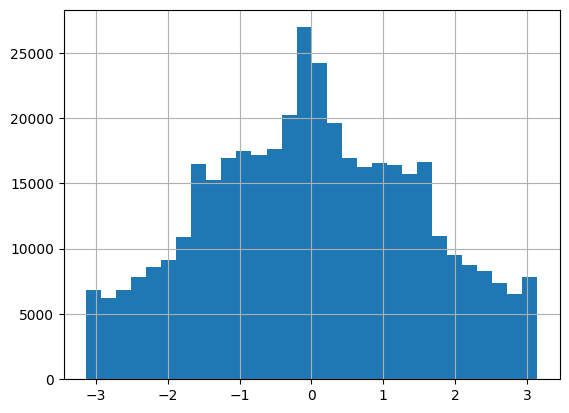

In [189]:
all_passes_open_play['pass_angle'].hist(bins=30)

In [190]:
all_passes_open_play['pass_angle'].isna().sum()

np.int64(0)

<Axes: >

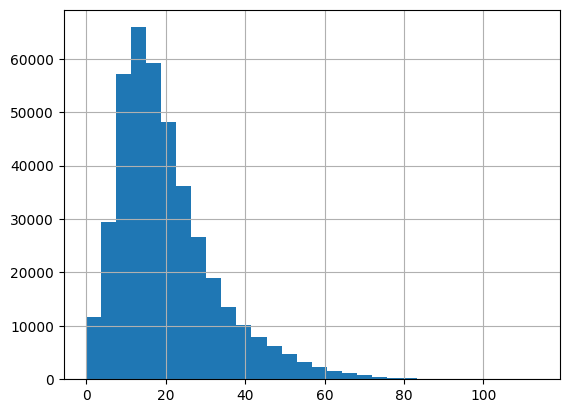

In [191]:
all_passes_open_play['pass_length'].hist(bins=30)

In [192]:
all_passes_open_play['pass_length'].describe()

count    405928.000000
mean         20.358947
std          12.574823
min           0.000000
25%          11.539172
50%          17.523129
75%          26.084862
max         113.488150
Name: pass_length, dtype: float64

In [193]:
all_passes_open_play['pass_length'].isna().sum()

np.int64(0)

In [194]:
all_passes_open_play['pass_progressive'].mean()

np.float64(0.18360398888472831)

In [195]:
all_passes_open_play.groupby(['start_half', 'end_half'])['pass_progressive'].mean()

start_half  end_half
opp         opp         0.272682
            own         0.000000
own         opp         0.570341
            own         0.024696
Name: pass_progressive, dtype: float64

In [196]:
all_passes_open_play['pass_body_part_group'] = all_passes_open_play.apply(
    lambda row: simplify_body_part(row['pass_body_part'], row['position_group']), axis=1
)

In [197]:
all_passes_open_play = all_passes_open_play[all_passes_open_play['pass_outcome'] != 'Injury Clearance']

In [198]:
all_passes_open_play.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,dist_to_goal_end,dist_reduction,pass_progressive,pass_completed,pass_create_shot,pass_deep_completion,pass_inside_box,pass_into_box,pass_open_play,pass_body_part_group
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,91.993865,-16.072467,False,True,False,False,False,False,True,Left Foot
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,93.567685,0.929080,False,True,False,False,False,False,True,Right Foot
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,94.510757,-0.943072,False,True,False,False,False,False,True,Right Foot
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,98.721080,-1.522432,False,True,False,False,False,False,True,Right Foot
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,89.367471,-0.943558,False,True,False,False,False,False,True,Left Foot


In [199]:
all_passes_open_play.columns.tolist()

['50_50',
 'bad_behaviour_card',
 'ball_receipt_outcome',
 'ball_recovery_offensive',
 'ball_recovery_recovery_failure',
 'block_deflection',
 'block_offensive',
 'block_save_block',
 'carry_end_location',
 'clearance_aerial_won',
 'clearance_body_part',
 'clearance_head',
 'clearance_left_foot',
 'clearance_other',
 'clearance_right_foot',
 'counterpress',
 'dribble_no_touch',
 'dribble_nutmeg',
 'dribble_outcome',
 'dribble_overrun',
 'duel_outcome',
 'duel_type',
 'duration',
 'foul_committed_advantage',
 'foul_committed_card',
 'foul_committed_offensive',
 'foul_committed_penalty',
 'foul_committed_type',
 'foul_won_advantage',
 'foul_won_defensive',
 'foul_won_penalty',
 'goalkeeper_body_part',
 'goalkeeper_end_location',
 'goalkeeper_lost_out',
 'goalkeeper_outcome',
 'goalkeeper_penalty_saved_to_post',
 'goalkeeper_position',
 'goalkeeper_punched_out',
 'goalkeeper_shot_saved_off_target',
 'goalkeeper_shot_saved_to_post',
 'goalkeeper_success_in_play',
 'goalkeeper_success_out',

In [200]:
all_passes_open_play[['pass_switch', 'pass_cross', 'pass_deflected']].dtypes

pass_switch       bool
pass_cross        bool
pass_deflected    bool
dtype: object

In [201]:
for pass_col in ['pass_aerial_won', 'pass_cross', 'pass_cut_back', 'pass_deflected', 'pass_goal_assist', 'pass_inswinging', 'pass_miscommunication', 'pass_no_touch', 'pass_outswinging', 'pass_shot_assist', 'pass_straight', 'pass_switch', 'pass_through_ball']:
    print(all_passes_open_play[pass_col].value_counts(dropna=False))
    print('==========')
    print(all_passes_open_play[all_passes_open_play[pass_col]]['pass_completed'].value_counts(dropna=False))
    print('====================')

pass_aerial_won
False    398296
True       7379
Name: count, dtype: int64
pass_completed
True     3728
False    3651
Name: count, dtype: int64
pass_cross
False    396121
True       9554
Name: count, dtype: int64
pass_completed
False    6774
True     2780
Name: count, dtype: int64
pass_cut_back
False    404710
True        965
Name: count, dtype: int64
pass_completed
False    508
True     457
Name: count, dtype: int64
pass_deflected
False    405204
True        471
Name: count, dtype: int64
pass_completed
True     465
False      6
Name: count, dtype: int64
pass_goal_assist
False    404909
True        766
Name: count, dtype: int64
pass_completed
True    766
Name: count, dtype: int64
pass_inswinging
False    405675
Name: count, dtype: int64
Series([], Name: count, dtype: int64)
pass_miscommunication
False    405525
True        150
Name: count, dtype: int64
pass_completed
False    150
Name: count, dtype: int64
pass_no_touch
False    405348
True        327
Name: count, dtype: int64
pass_compl

#### Aggregate counts and percentages

In [202]:
all_players_passes_stats = (all_passes_open_play
    .groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        passes_attempted=('pass_completed', 'size'),
        pass_completion_pct=('pass_completed', 'mean'),
        pass_forward_pct=('pass_forward', 'mean'),
        pass_backward_pct=('pass_backward', 'mean'),
        pass_sideway_pct=('pass_sideway', 'mean'),
        pass_long_pct=('pass_long', 'mean'),
        pass_progressive_pct=('pass_progressive', 'mean'),
        pass_into_final_third_pct=('pass_into_final_third', 'mean'),
        pass_ground_pct=('pass_height', lambda x: (x == 'Ground Pass').mean()),
        pass_low_pct=('pass_height', lambda x: (x == 'Low Pass').mean()),
        pass_high_pct=('pass_height', lambda x: (x == 'High Pass').mean()),
        pass_switch_pct=('pass_switch', 'mean'),
        pass_under_pressure_pct=('under_pressure', 'mean'),
        pass_aerial_won_pct=('pass_aerial_won', 'mean'),
        pass_cross_pct=('pass_cross', 'mean'),
        pass_cut_back_pct=('pass_cut_back', 'mean'),
        pass_deflected_pct=('pass_deflected', 'mean'),
        pass_goal_assist_pct=('pass_goal_assist', 'mean'),
        pass_miscommunication_pct=('pass_miscommunication', 'mean'),
        pass_no_touch_pct=('pass_no_touch', 'mean'),
        pass_shot_assist_pct=('pass_shot_assist', 'mean'),
        pass_through_ball_pct=('pass_through_ball', 'mean'),
        pass_create_shot_pct=('pass_create_shot', 'mean'),
        pass_left_foot_pct=('pass_body_part_group', lambda x: (x == 'Left Foot').mean()),
        pass_right_foot_pct=('pass_body_part_group', lambda x: (x == 'Right Foot').mean()),
        pass_head_pct=('pass_body_part_group', lambda x: (x == 'Head').mean()),
        pass_keeper_arm_pct=('pass_body_part_group', lambda x: (x == 'Keeper Arm').mean()),
        pass_drop_kick_pct=('pass_body_part_group', lambda x: (x == 'Drop Kick').mean()),
        pass_other_unknown_part_pct=('pass_body_part_group', lambda x: (x == 'Other/Unknown').mean()),
        pass_deep_completion_pct=('pass_deep_completion', 'mean'),
        pass_inside_box_pct=('pass_inside_box', 'mean'),
        pass_into_box_pct=('pass_into_box', 'mean'),
    )
    .reset_index()
)

In [203]:
all_players_passes_stats.head()

,player_id,team_id,position_group,passes_attempted,pass_completion_pct,pass_forward_pct,pass_backward_pct,pass_sideway_pct,pass_long_pct,pass_progressive_pct,...,pass_create_shot_pct,pass_left_foot_pct,pass_right_foot_pct,pass_head_pct,pass_keeper_arm_pct,pass_drop_kick_pct,pass_other_unknown_part_pct,pass_deep_completion_pct,pass_inside_box_pct,pass_into_box_pct
0,4633.0,1069,Center Back,970,0.897938,0.230928,0.013402,0.755670,0.105155,0.120619,...,0.002062,0.777320,0.173196,0.032990,0.0,0.0,0.016495,0.004124,0.000000,0.004124
1,4636.0,965,Center Back,738,0.856369,0.283198,0.035230,0.681572,0.124661,0.134146,...,0.005420,0.311653,0.638211,0.037940,0.0,0.0,0.012195,0.008130,0.002710,0.005420
2,4638.0,749,Center Midfield,344,0.825581,0.206395,0.113372,0.680233,0.040698,0.125000,...,0.034884,0.145349,0.819767,0.017442,0.0,0.0,0.017442,0.034884,0.005814,0.026163
3,4642.0,971,Center Back,708,0.854520,0.282486,0.014124,0.703390,0.172316,0.201977,...,0.002825,0.175141,0.769774,0.025424,0.0,0.0,0.029661,0.008475,0.001412,0.002825
4,4643.0,1069,Center Midfield,1543,0.861957,0.190538,0.110823,0.698639,0.112119,0.167855,...,0.012962,0.060272,0.914452,0.015554,0.0,0.0,0.009721,0.018795,0.001296,0.018795


#### Completion rate by pass types

In [204]:
pass_subtypes = ['pass_aerial_won', 'pass_cross', 'pass_cut_back', 'pass_deflected', 'pass_no_touch', 'pass_switch', 'pass_through_ball', 'pass_forward', 'pass_backward', 'pass_sideway', 'pass_long', 'pass_progressive', 'pass_into_final_third']

In [205]:
for stat_name in pass_subtypes:
    subtype_stats = build_subtype_completion_rate(all_passes_open_play, stat_name)
    all_players_passes_stats = all_players_passes_stats.merge(
        subtype_stats, on=['player_id', 'team_id', 'position_group'], how='left'
    )

In [206]:
pass_height_map = {
    'Ground Pass': 'ground',
    'Low Pass': 'low',
    'High Pass': 'high',
}

In [207]:
body_part_map = {
    'Left Foot': 'left_foot',
    'Right Foot': 'right_foot',
    'Head': 'head',
    'Keeper Arm': 'keeper_arm',
    'Drop Kick': 'drop_kick',
    'Other/Unknown': 'other',
}

In [208]:
categorical_features = [
    ('pass_height', pass_height_map, 'pass'),
    ('pass_body_part_group', body_part_map, 'pass'),
]

In [209]:
for cat_col, value_map, prefix in categorical_features:
    for raw_value, short_name in value_map.items():
        stat_name = f'{prefix}_{short_name}'  # e.g. 'pass_ground', 'pass_left_foot'

        completion_df = build_category_completion_rate(all_passes_open_play, cat_col, raw_value, stat_name)

        all_players_passes_stats = (all_players_passes_stats
            .merge(completion_df, on=['player_id', 'team_id', 'position_group'], how='left'))

#### Passing by pressure

In [210]:
pass_pressure_stats = (all_passes_open_play
    .groupby(['player_id', 'team_id', 'position_group', 'under_pressure'])['pass_completed']
    .mean()
    .unstack('under_pressure'))

In [211]:
pass_pressure_stats.columns = [
    f"pass_completion_pct_{'under_pressure' if val else 'not_under_pressure'}"
    for val in pass_pressure_stats.columns
]

In [212]:
pass_pressure_stats = pass_pressure_stats.reset_index()

In [213]:
pass_pressure_stats['pass_completion_pct_change_pressure'] = pass_pressure_stats['pass_completion_pct_under_pressure'] - pass_pressure_stats['pass_completion_pct_not_under_pressure']

In [214]:
pass_pressure_stats.head()

,player_id,team_id,position_group,pass_completion_pct_not_under_pressure,pass_completion_pct_under_pressure,pass_completion_pct_change_pressure
0,4633.0,1069,Center Back,0.922364,0.700935,-0.221429
1,4636.0,965,Center Back,0.874799,0.756522,-0.118278
2,4638.0,749,Center Midfield,0.825623,0.825397,-0.000226
3,4642.0,971,Center Back,0.874419,0.650794,-0.223625
4,4643.0,1069,Center Midfield,0.869249,0.832237,-0.037013


In [215]:
all_players_passes_stats = all_players_passes_stats.merge(
    pass_pressure_stats, on=['player_id', 'team_id', 'position_group'], how='left'
)

#### Passing by length

In [216]:
completed_avg_length = (all_passes_open_play[all_passes_open_play['pass_completed']]
                         .groupby(['player_id', 'team_id', 'position_group'])['pass_length'].mean()
                         .rename('pass_length_completed_avg'))

In [217]:
pass_length_stats = (all_passes_open_play
                      .groupby(['player_id', 'team_id', 'position_group'])['pass_length'].mean()
                      .rename('pass_length_avg')
                      .reset_index())

In [218]:
pass_length_stats = pass_length_stats.merge(completed_avg_length, on=['player_id', 'team_id', 'position_group'], how='left')

In [219]:
pass_length_stats['pass_length_ratio'] = (
    pass_length_stats['pass_length_completed_avg'] / pass_length_stats['pass_length_avg']
)

In [220]:
pass_length_stats.head()

,player_id,team_id,position_group,pass_length_avg,pass_length_completed_avg,pass_length_ratio
0,4633.0,1069,Center Back,22.364268,21.525128,0.962479
1,4636.0,965,Center Back,22.275757,20.817437,0.934533
2,4638.0,749,Center Midfield,16.679791,16.868963,1.011341
3,4642.0,971,Center Back,24.905274,22.893812,0.919236
4,4643.0,1069,Center Midfield,20.591066,19.863553,0.964669


In [221]:
all_players_passes_stats = all_players_passes_stats.merge(
    pass_length_stats, on=['player_id', 'team_id', 'position_group'], how='left'
)

#### Passing by length and pressure

In [222]:
length_by_pressure = (all_passes_open_play
    .groupby(['player_id', 'team_id', 'position_group', 'under_pressure'])['pass_length']
    .mean()
    .unstack('under_pressure')
    .rename(columns={True: 'pass_length_under_pressure_avg', False: 'pass_length_not_under_pressure_avg'})
    .reset_index())

In [223]:
length_by_pressure.head()

under_pressure,player_id,team_id,position_group,pass_length_not_under_pressure_avg,pass_length_under_pressure_avg
0,4633.0,1069,Center Back,22.363883,22.367369
1,4636.0,965,Center Back,22.228751,22.530410
2,4638.0,749,Center Midfield,17.195603,14.379106
3,4642.0,971,Center Back,25.014186,23.790224
4,4643.0,1069,Center Midfield,21.397860,17.302851


In [224]:
all_players_passes_stats = all_players_passes_stats.merge(
    length_by_pressure, on=['player_id', 'team_id', 'position_group'], how='left'
)

In [225]:
length_completed_by_pressure = (all_passes_open_play[all_passes_open_play['pass_completed']]
    .groupby(['player_id', 'team_id', 'position_group', 'under_pressure'])['pass_length']
    .mean()
    .unstack('under_pressure')
    .rename(columns={True: 'pass_length_under_pressure_completed_avg', False: 'pass_length_not_under_pressure_completed_avg'})
    .reset_index())

In [226]:
length_completed_by_pressure.head()

under_pressure,player_id,team_id,position_group,pass_length_not_under_pressure_completed_avg,pass_length_under_pressure_completed_avg
0,4633.0,1069,Center Back,21.543377,21.331445
1,4636.0,965,Center Back,20.605429,22.145537
2,4638.0,749,Center Midfield,17.177007,15.494612
3,4642.0,971,Center Back,22.970112,21.844223
4,4643.0,1069,Center Midfield,20.368454,17.714232


In [227]:
all_players_passes_stats = all_players_passes_stats.merge(
    length_completed_by_pressure, on=['player_id', 'team_id', 'position_group'], how='left'
)

#### Merge minutes played and calculate per 90 counts

In [228]:
all_players_passes_stats = (all_players_passes_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
))

In [229]:
all_players_passes_stats['pass_length_under_pressure_avg_change'] = all_players_passes_stats['pass_length_under_pressure_avg'] - all_players_passes_stats['pass_length_avg']

In [230]:
all_players_passes_stats['passes_per_90'] = all_players_passes_stats['passes_attempted'] / all_players_passes_stats['minutes_at_position'] * 90

In [231]:
all_players_passes_stats['pass_goal_assists_per_90'] = all_players_passes_stats['passes_per_90'] * all_players_passes_stats['pass_goal_assist_pct']

In [232]:
all_players_passes_stats.head()

,player_id,team_id,position_group,passes_attempted,pass_completion_pct,pass_forward_pct,pass_backward_pct,pass_sideway_pct,pass_long_pct,pass_progressive_pct,...,pass_length_completed_avg,pass_length_ratio,pass_length_not_under_pressure_avg,pass_length_under_pressure_avg,pass_length_not_under_pressure_completed_avg,pass_length_under_pressure_completed_avg,minutes_at_position,pass_length_under_pressure_avg_change,passes_per_90,pass_goal_assists_per_90
0,4633.0,1069,Center Back,970,0.897938,0.230928,0.013402,0.755670,0.105155,0.120619,...,21.525128,0.962479,22.363883,22.367369,21.543377,21.331445,1045.150000,0.003101,83.528680,0.000000
1,4636.0,965,Center Back,738,0.856369,0.283198,0.035230,0.681572,0.124661,0.134146,...,20.817437,0.934533,22.228751,22.530410,20.605429,22.145537,1858.983333,0.254653,35.729207,0.096827
2,4638.0,749,Center Midfield,344,0.825581,0.206395,0.113372,0.680233,0.040698,0.125000,...,16.868963,1.011341,17.195603,14.379106,17.177007,15.494612,718.950000,-2.300685,43.062800,0.250365
3,4642.0,971,Center Back,708,0.854520,0.282486,0.014124,0.703390,0.172316,0.201977,...,22.893812,0.919236,25.014186,23.790224,22.970112,21.844223,965.400000,-1.115050,66.003729,0.000000
4,4643.0,1069,Center Midfield,1543,0.861957,0.190538,0.110823,0.698639,0.112119,0.167855,...,19.863553,0.964669,21.397860,17.302851,20.368454,17.714232,1936.783333,-3.288216,71.701361,0.185875


### Carries

In [233]:
all_carrys = all_events_eligible[all_events_eligible['type'] == 'Carry']

In [234]:
print(all_carrys.filter(like='carry').columns.tolist())

['carry_end_location', 'carry_end_location_x', 'carry_end_location_y']


In [235]:
all_carrys.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
199998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[54.8, 40.2]",NaN,...,NaN,51.8,37.2,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield
199999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[56.8, 45.0]",NaN,...,NaN,54.8,40.2,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield
200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[34.2, 53.3]",NaN,...,NaN,41.8,48.3,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
200001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[12.2, 46.7]",NaN,...,NaN,15.0,45.5,NaN,NaN,NaN,NaN,NaN,Goalkeeper,Goalkeeper
200002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[13.4, 31.3]",NaN,...,NaN,13.4,31.3,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back


In [236]:
all_carrys['under_pressure'].value_counts(dropna=False)

under_pressure
NaN     232999
True    127722
Name: count, dtype: int64

In [237]:
all_carrys['under_pressure'] = all_carrys['under_pressure'].fillna(False)

In [238]:
all_carrys['under_pressure'].value_counts(dropna=False)

under_pressure
False    232999
True     127722
Name: count, dtype: int64

In [239]:
all_carrys['carry_into_final_third'] = (
    (all_carrys['location_x'] < 80) & 
    (all_carrys['carry_end_location_x'] >= 80) 
) 

In [240]:
all_carrys['dist_to_goal_start'] = distance_to_goal_meter(all_carrys['location_x'], all_carrys['location_y'])
all_carrys['dist_to_goal_end'] = distance_to_goal_meter(all_carrys['carry_end_location_x'], all_carrys['carry_end_location_y'])
all_carrys['dist_reduction'] = all_carrys['dist_to_goal_start'] - all_carrys['dist_to_goal_end']

In [241]:
all_carrys['carry_progressive'] = all_carrys['dist_reduction'] >= 10

In [242]:
all_carrys['carry_angle'] = np.arctan2(
    all_carrys['carry_end_location_y'] - all_carrys['location_y'],
    all_carrys['carry_end_location_x'] - all_carrys['location_x']
)

In [243]:
all_carrys['carry_forward'] = (
    (all_carrys['carry_angle'] <= np.pi / 6) &
    (all_carrys['carry_angle'] >= -np.pi / 6)
)

In [244]:
all_carrys['carry_backward'] = (
    (all_carrys['carry_angle'] <= -5 * np.pi / 6) |
    (all_carrys['carry_angle'] >= 5 * np.pi / 6)
)

In [245]:
all_carrys['carry_sideway'] = ~(all_carrys['carry_forward'] | all_carrys['carry_backward'])

In [246]:
all_carrys['carry_distance_m'] = distance_meter(all_carrys['carry_end_location_x'], all_carrys['carry_end_location_y'], all_carrys['location_x'], all_carrys['location_y']) 

In [247]:
all_carrys['implied_speed'] = all_carrys['carry_distance_m'] / all_carrys['duration']

In [248]:
max_plausible_speed = 10   # m/s, generous upper bound above elite sprint-with-ball speed


In [249]:
all_carrys_clean_final = all_carrys[
    (all_carrys['implied_speed'] <= max_plausible_speed)
].copy()

In [250]:
all_carrys_clean_final.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,dist_to_goal_start,dist_to_goal_end,dist_reduction,carry_progressive,carry_angle,carry_forward,carry_backward,carry_sideway,carry_distance_m,implied_speed
199998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[54.8, 40.2]",NaN,...,59.722442,57.050253,2.672188,False,0.785398,False,False,True,3.659662,2.444285
199999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[56.8, 45.0]",NaN,...,57.050253,55.463073,1.587180,False,1.176005,False,False,True,4.439471,2.733291
200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[34.2, 53.3]",NaN,...,68.787743,75.921398,-7.133654,False,2.559688,False,False,True,7.892085,4.569699
200001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[12.2, 46.7]",NaN,...,91.993865,94.496765,-2.502900,False,2.736701,False,True,False,2.653846,0.819390
200002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[13.4, 31.3]",NaN,...,93.567685,93.567685,0.000000,False,0.000000,True,False,False,0.000000,0.000000


In [251]:
removed = len(all_carrys) - len(all_carrys_clean_final)
print(f"{removed} of {len(all_carrys)} carries removed ({removed / len(all_carrys):.2%})")

15911 of 360721 carries removed (4.41%)


In [252]:
all_carrys_clean_final['carry_distance_m'].describe()

count    344810.000000
mean          4.902474
std           5.729608
min           0.000000
25%           1.034903
50%           3.073383
75%           6.658998
max          78.852683
Name: carry_distance_m, dtype: float64

In [253]:
all_carrys_clean_final['dist_reduction'].describe()

count    344810.000000
mean          2.007325
std           5.430368
min         -39.171965
25%          -0.254173
50%           0.516446
75%           3.377371
max          72.460168
Name: dist_reduction, dtype: float64

In [254]:
all_players_carrys_stats = (all_carrys_clean_final
    .groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        carrys_attempted=('carry_distance_m', 'size'),
        carry_distance_total=('carry_distance_m', 'sum'),
        carry_distance_avg=('carry_distance_m', 'mean'),
        carry_progressive_pct=('carry_progressive', 'mean'),
        carry_forward_pct=('carry_forward', 'mean'),
        carry_backward_pct=('carry_backward', 'mean'),
        carry_sideway_pct=('carry_sideway', 'mean'),
        carry_duration_total=('duration', 'sum'),
        carry_under_pressure_pct=('under_pressure', 'mean'),
        carry_into_final_third_pct=('carry_into_final_third', 'mean')
    )
    .reset_index())

In [255]:
all_players_carrys_stats.head()

,player_id,team_id,position_group,carrys_attempted,carry_distance_total,carry_distance_avg,carry_progressive_pct,carry_forward_pct,carry_backward_pct,carry_sideway_pct,carry_duration_total,carry_under_pressure_pct,carry_into_final_third_pct
0,4633.0,1069,Center Back,813,3389.102489,4.168638,0.046740,0.428044,0.040590,0.531365,1432.864002,0.114391,0.007380
1,4636.0,965,Center Back,613,2194.799584,3.580423,0.042414,0.386623,0.076672,0.536705,1251.588155,0.23491,0.011419
2,4638.0,749,Center Midfield,301,1146.423519,3.808716,0.053156,0.415282,0.122924,0.461794,478.810207,0.41196,0.049834
3,4642.0,971,Center Back,568,2494.179963,4.391162,0.040493,0.371479,0.056338,0.572183,1115.203083,0.103873,0.008803
4,4643.0,1069,Center Midfield,1388,6040.482199,4.351932,0.056196,0.346542,0.100144,0.553314,2213.754637,0.342219,0.020893


In [256]:
all_players_carrys_stats = all_players_carrys_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']],
    on=['player_id', 'team_id', 'position_group'],
    how='left'
)


In [257]:
all_players_carrys_stats['carry_speed_avg'] = all_players_carrys_stats['carry_distance_total'] / all_players_carrys_stats['carry_duration_total']

In [258]:
all_players_carrys_stats['carrys_per_90'] = all_players_carrys_stats['carrys_attempted'] / all_players_carrys_stats['minutes_at_position'] * 90
all_players_carrys_stats['carry_distance_total_per_90'] = all_players_carrys_stats['carry_distance_total'] / all_players_carrys_stats['minutes_at_position'] * 90
all_players_carrys_stats['carry_duration_total_per_90'] = all_players_carrys_stats['carry_duration_total'] / all_players_carrys_stats['minutes_at_position'] * 90

In [259]:
pressure_totals = (all_carrys_clean_final
    .groupby(['player_id', 'team_id', 'position_group', 'under_pressure'])
    .agg(
        carry_distance=('carry_distance_m', 'sum'),
        carry_time=('duration', 'sum')
    )
    .unstack('under_pressure'))

In [260]:
pressure_totals.columns = [
    f"{metric}_{'under_pressure' if val else 'not_under_pressure'}"
    for metric, val in pressure_totals.columns
]
pressure_totals = pressure_totals.reset_index().fillna(0)

In [261]:
pressure_totals['carry_distance_under_pressure_pct'] = (
    pressure_totals['carry_distance_under_pressure'] /
    (pressure_totals['carry_distance_under_pressure'] + pressure_totals['carry_distance_not_under_pressure'])
)

In [262]:
pressure_totals['carry_time_under_pressure_pct'] = (
    pressure_totals['carry_time_under_pressure'] /
    (pressure_totals['carry_time_under_pressure'] + pressure_totals['carry_time_not_under_pressure'])
)

In [263]:
all_players_carrys_stats = all_players_carrys_stats.merge(
    pressure_totals[['player_id', 'team_id', 'position_group', 'carry_distance_under_pressure_pct', 'carry_time_under_pressure_pct']],
    on=['player_id', 'team_id', 'position_group'], how='left'
)

In [264]:
all_players_carrys_stats.head()

,player_id,team_id,position_group,carrys_attempted,carry_distance_total,carry_distance_avg,carry_progressive_pct,carry_forward_pct,carry_backward_pct,carry_sideway_pct,carry_duration_total,carry_under_pressure_pct,carry_into_final_third_pct,minutes_at_position,carry_speed_avg,carrys_per_90,carry_distance_total_per_90,carry_duration_total_per_90,carry_distance_under_pressure_pct,carry_time_under_pressure_pct
0,4633.0,1069,Center Back,813,3389.102489,4.168638,0.046740,0.428044,0.040590,0.531365,1432.864002,0.114391,0.007380,1045.150000,2.365265,70.009090,291.842534,123.386844,0.152305,0.121711
1,4636.0,965,Center Back,613,2194.799584,3.580423,0.042414,0.386623,0.076672,0.536705,1251.588155,0.23491,0.011419,1858.983333,1.753612,29.677512,106.258060,60.593837,0.315893,0.236594
2,4638.0,749,Center Midfield,301,1146.423519,3.808716,0.053156,0.415282,0.122924,0.461794,478.810207,0.41196,0.049834,718.950000,2.394317,37.679950,143.512228,59.938686,0.560618,0.483061
3,4642.0,971,Center Back,568,2494.179963,4.391162,0.040493,0.371479,0.056338,0.572183,1115.203083,0.103873,0.008803,965.400000,2.236525,52.952144,232.521438,103.965483,0.156458,0.103169
4,4643.0,1069,Center Midfield,1388,6040.482199,4.351932,0.056196,0.346542,0.100144,0.553314,2213.754637,0.342219,0.020893,1936.783333,2.728614,64.498696,280.693967,102.870525,0.381582,0.352848


### Dribbles

In [265]:
all_dribbles = all_events_eligible[all_events_eligible['type'] == 'Dribble']

In [266]:
all_dribbles.filter(like='dribble').columns.tolist()

['dribble_no_touch',
 'dribble_nutmeg',
 'dribble_outcome',
 'dribble_overrun',
 'shot_follows_dribble']

In [267]:
all_dribbles.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
321299,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,54.8,40.2,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield
321300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,31.5,68.3,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield
321301,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,35.0,75.6,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield
321302,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,18.6,43.1,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
321303,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,111.7,14.7,NaN,NaN,NaN,NaN,NaN,Winger,Winger


In [268]:
all_dribbles['dribble_outcome'].value_counts(dropna=False)

dribble_outcome
Complete      7619
Incomplete    6428
Name: count, dtype: int64

In [269]:
all_dribbles['dribble_no_touch'].value_counts(dropna=False)

dribble_no_touch
NaN     13955
True       92
Name: count, dtype: int64

In [270]:
all_dribbles['dribble_nutmeg'].value_counts(dropna=False)

dribble_nutmeg
NaN     13015
True     1032
Name: count, dtype: int64

In [271]:
all_dribbles['dribble_overrun'].value_counts(dropna=False)

dribble_overrun
NaN     13124
True      923
Name: count, dtype: int64

In [272]:
all_dribbles['dribble_no_touch'] = all_dribbles['dribble_no_touch'].fillna(False).astype(bool)

In [273]:
all_dribbles['dribble_nutmeg'] = all_dribbles['dribble_nutmeg'].fillna(False).astype(bool)

In [274]:
all_dribbles['dribble_overrun'] = all_dribbles['dribble_overrun'].fillna(False).astype(bool)

In [275]:
all_dribbles['location_y_deviation'] = (all_dribbles['location_y'] - 40).abs()

In [276]:
all_players_dribbles_stats = (all_dribbles
    .groupby(['player_id', 'team_id','position_group'])
    .agg(
        dribbles_attempted=('dribble_outcome', 'size'),
        dribble_complete_pct=('dribble_outcome', lambda x: (x == 'Complete').mean()),
        dribble_x_avg=('location_x', 'mean'),
        dribble_y_deviation_avg=('location_y_deviation', 'mean'),
    )
    .reset_index())

In [277]:
all_players_dribbles_stats = all_players_dribbles_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']],
    on=['player_id', 'team_id', 'position_group'], how='left'
)

In [278]:
all_players_dribbles_stats['dribbles_per_90'] = all_players_dribbles_stats['dribbles_attempted'] / all_players_dribbles_stats['minutes_at_position'] * 90

In [279]:
all_players_dribbles_stats.head()

,player_id,team_id,position_group,dribbles_attempted,dribble_complete_pct,dribble_x_avg,dribble_y_deviation_avg,minutes_at_position,dribbles_per_90
0,4636.0,965,Center Back,15,0.866667,34.606667,14.460000,1858.983333,0.726203
1,4638.0,749,Center Midfield,12,0.416667,80.083333,13.258333,718.950000,1.502191
2,4642.0,971,Center Back,3,0.333333,70.100000,25.033333,965.400000,0.279677
3,4643.0,1069,Center Midfield,60,0.500000,66.313333,15.525000,1936.783333,2.788128
4,4654.0,1475,Winger,16,0.312500,81.793750,26.050000,701.550000,2.052598


### Shots

In [280]:
all_shots = all_events_eligible[all_events_eligible['type'] == 'Shot']

In [281]:
all_shots.filter(like='shot').columns.tolist()

['goalkeeper_shot_saved_off_target',
 'goalkeeper_shot_saved_to_post',
 'pass_assisted_shot_id',
 'pass_shot_assist',
 'shot_aerial_won',
 'shot_body_part',
 'shot_deflected',
 'shot_end_location',
 'shot_first_time',
 'shot_freeze_frame',
 'shot_key_pass_id',
 'shot_one_on_one',
 'shot_open_goal',
 'shot_outcome',
 'shot_redirect',
 'shot_saved_off_target',
 'shot_saved_to_post',
 'shot_statsbomb_xg',
 'shot_technique',
 'shot_type',
 'shot_follows_dribble',
 'shot_kick_off',
 'shot_end_location_x',
 'shot_end_location_y',
 'shot_end_location_z']

In [282]:
all_shots.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
342293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,112.1,36.3,NaN,NaN,115.9,39.2,NaN,Winger,Winger
342294,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,103.2,34.0,NaN,NaN,104.1,34.5,NaN,Center Midfield,Center Midfield
342295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,105.7,42.2,NaN,NaN,118.8,40.9,0.6,Center Forward,Center Forward
342296,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,111.5,37.3,NaN,NaN,119.1,37.3,0.5,Center Back,Center Back
342297,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,102.8,31.3,NaN,NaN,120.0,32.0,0.4,Center Forward,Center Forward


In [283]:
for shot_col in ['shot_aerial_won', 'shot_body_part', 'shot_deflected', 'shot_first_time', 'shot_one_on_one', 'shot_open_goal', 'shot_outcome', 'shot_redirect', 'shot_saved_off_target', 'shot_saved_to_post', 'shot_technique', 'shot_type', 'shot_follows_dribble', 'shot_kick_off']:
    print(all_shots[shot_col].value_counts(dropna=False))
    print('====================')

shot_aerial_won
NaN     10127
True     1151
Name: count, dtype: int64
shot_body_part
Right Foot    6311
Left Foot     2923
Head          2006
Other           38
Name: count, dtype: int64
shot_deflected
NaN     11097
True      181
Name: count, dtype: int64
shot_first_time
NaN     7429
True    3849
Name: count, dtype: int64
shot_one_on_one
NaN     10823
True      455
Name: count, dtype: int64
shot_open_goal
NaN     11167
True      111
Name: count, dtype: int64
shot_outcome
Off T               3389
Blocked             2762
Saved               2725
Goal                1299
Wayward              695
Post                 296
Saved Off Target      68
Saved to Post         44
Name: count, dtype: int64
shot_redirect
NaN     11269
True        9
Name: count, dtype: int64
shot_saved_off_target
NaN     11210
True       68
Name: count, dtype: int64
shot_saved_to_post
NaN     11234
True       44
Name: count, dtype: int64
shot_technique
Normal           8628
Half Volley      1743
Volley            681


In [284]:
for shot_col in ['shot_aerial_won', 'shot_deflected', 'shot_first_time', 'shot_one_on_one', 'shot_open_goal', 'shot_redirect', 'shot_saved_off_target', 'shot_saved_to_post', 'shot_follows_dribble', 'shot_kick_off']:
    all_shots[shot_col].fillna(False).astype(bool)

In [285]:
all_shots['under_pressure'].value_counts(dropna=False)

under_pressure
NaN     7825
True    3453
Name: count, dtype: int64

In [286]:
all_shots['under_pressure'] = all_shots['under_pressure'].fillna(False).astype(bool)

In [287]:
all_shots['shot_goal'] = (all_shots['shot_outcome'] == 'Goal')

In [288]:
all_shots['shot_on_target'] = (all_shots['shot_outcome'].isin(['Goal', 'Saved', 'Saved to Post']))

In [289]:
all_shots['shot_saved'] = (all_shots['shot_outcome'].isin(['Saved', 'Saved to Post', 'Saved Off Target']))

In [290]:
all_shots['shot_blocked'] = (all_shots['shot_outcome'] == 'Blocked')

In [291]:
all_shots['shot_open_play'] = (all_shots['shot_type'] == 'Open Play')

In [292]:
all_shots['shot_free_kick'] = (all_shots['shot_type'] == 'Free Kick')

In [293]:
all_shots['shot_distance_to_goal_meter'] = distance_to_goal_meter(all_shots['location_x'], all_shots['location_y'])

In [294]:
all_shots['shot_angle'] = compute_shot_angle(all_shots['location_x'], all_shots['location_y'])

In [295]:
all_shots['shot_in_opposition_box'] = in_opposition_box(all_shots['location_x'], all_shots['location_y'])

In [296]:
all_shots_open_play = all_shots[all_shots['shot_open_play']].copy()

In [297]:
for shot_col in ['shot_aerial_won', 'shot_body_part', 'shot_deflected', 'shot_first_time', 'shot_one_on_one', 'shot_open_goal', 'shot_outcome', 'shot_redirect', 'shot_saved_off_target', 'shot_saved_to_post', 'shot_technique', 'shot_type', 'shot_follows_dribble', 'shot_kick_off']:
    print(all_shots_open_play[shot_col].value_counts(dropna=False))
    print('====================')

shot_aerial_won
NaN     9675
True    1151
Name: count, dtype: int64
shot_body_part
Right Foot    5963
Left Foot     2819
Head          2006
Other           38
Name: count, dtype: int64
shot_deflected
NaN     10648
True      178
Name: count, dtype: int64
shot_first_time
NaN     6977
True    3849
Name: count, dtype: int64
shot_one_on_one
NaN     10381
True      445
Name: count, dtype: int64
shot_open_goal
NaN     10715
True      111
Name: count, dtype: int64
shot_outcome
Off T               3269
Blocked             2690
Saved               2608
Goal                1183
Wayward              695
Post                 275
Saved Off Target      65
Saved to Post         41
Name: count, dtype: int64
shot_redirect
NaN     10817
True        9
Name: count, dtype: int64
shot_saved_off_target
NaN     10761
True       65
Name: count, dtype: int64
shot_saved_to_post
NaN     10785
True       41
Name: count, dtype: int64
shot_technique
Normal           8176
Half Volley      1743
Volley            681
Lo

In [298]:
all_shots_open_play[all_shots_open_play['shot_blocked']].shape

(2690, 142)

In [299]:
all_shots_open_play[all_shots_open_play['shot_blocked']]['shot_end_location_z'].isnull().sum()

np.int64(2690)

In [300]:
all_shots_open_play[~all_shots_open_play['shot_blocked']].shape

(8136, 142)

In [301]:
all_shots_open_play[~all_shots_open_play['shot_blocked']]['shot_end_location_z'].isnull().sum()

np.int64(695)

In [302]:
all_shots_open_play[(~all_shots_open_play['shot_blocked']) & (all_shots_open_play['shot_end_location_z'].isnull())]['shot_outcome'].value_counts(dropna=False)

shot_outcome
Wayward    695
Name: count, dtype: int64

In [303]:
all_players_shots_stats = (all_shots_open_play
    .groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        shots_open_play_attempted=('shot_outcome', 'size'),
        shot_open_play_on_target_pct=('shot_on_target', 'mean'),
        shot_open_play_goal_pct=('shot_goal', 'mean'),
        shot_open_play_blocked_pct=('shot_blocked', 'mean'),
        shot_open_play_saved_pct=('shot_saved', 'mean'),
        shot_open_play_xg_avg=('shot_statsbomb_xg', 'mean'),
        shot_open_play_aerial_won_pct=('shot_aerial_won', 'mean'),
        shot_open_play_deflected_pct=('shot_deflected', 'mean'),
        shot_open_play_first_time_pct=('shot_first_time', 'mean'),
        shot_open_play_one_on_one_pct=('shot_one_on_one', 'mean'),
        shot_open_play_open_goal_pct=('shot_open_goal', 'mean'),
        shot_open_play_left_foot_pct=('shot_body_part', lambda x: (x == 'Left Foot').mean()),
        shot_open_play_right_foot_pct=('shot_body_part', lambda x: (x == 'Right Foot').mean()),
        shot_open_play_head_pct=('shot_body_part', lambda x: (x == 'Head').mean()),
        shot_open_play_technique_normal_pct=('shot_technique', lambda x: (x == 'Normal').mean()),
        shot_open_play_technique_volley_pct=('shot_technique', lambda x: (x == 'Volley').mean()),
        shot_open_play_technique_half_volley_pct=('shot_technique', lambda x: (x == 'Half Volley').mean()),
        shot_open_play_technique_lob_pct=('shot_technique', lambda x: (x == 'Lob').mean()),
        shot_open_play_technique_backheel_pct=('shot_technique', lambda x: (x == 'Backheel').mean()),
        shot_open_play_technique_overhead_kick_pct=('shot_technique', lambda x: (x == 'Overhead Kick').mean()),
        shot_open_play_technique_diving_header_pct=('shot_technique', lambda x: (x == 'Diving Header').mean()),  
        shot_open_play_distance_avg=('shot_distance_to_goal_meter', 'mean'),
        shot_open_play_angle_avg=('shot_angle', 'mean'),
        shot_open_play_under_pressure_pct=('under_pressure', 'mean'),
        shot_open_play_in_opposition_box_pct=('shot_in_opposition_box', 'mean')
    )
    .reset_index())

In [304]:
all_players_shots_stats = all_players_shots_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']],
    on=['player_id', 'team_id', 'position_group'], how='left'
)

In [305]:
all_players_shots_stats['shots_open_play_per_90'] = all_players_shots_stats['shots_open_play_attempted'] / all_players_shots_stats['minutes_at_position'] * 90

In [306]:
all_players_shots_stats.head()

,player_id,team_id,position_group,shots_open_play_attempted,shot_open_play_on_target_pct,shot_open_play_goal_pct,shot_open_play_blocked_pct,shot_open_play_saved_pct,shot_open_play_xg_avg,shot_open_play_aerial_won_pct,...,shot_open_play_technique_lob_pct,shot_open_play_technique_backheel_pct,shot_open_play_technique_overhead_kick_pct,shot_open_play_technique_diving_header_pct,shot_open_play_distance_avg,shot_open_play_angle_avg,shot_open_play_under_pressure_pct,shot_open_play_in_opposition_box_pct,minutes_at_position,shots_open_play_per_90
0,4633.0,1069,Center Back,10,0.500000,0.400000,0.100000,0.100000,0.083418,1.0,...,0.000000,0.000000,0.0,0.0,8.591260,0.829451,0.500000,1.000000,1045.150000,0.861120
1,4636.0,965,Center Back,2,0.500000,0.000000,0.000000,0.500000,0.081177,1.0,...,0.000000,0.000000,0.0,0.0,7.088558,0.918059,1.000000,1.000000,1858.983333,0.096827
2,4638.0,749,Center Midfield,22,0.500000,0.090909,0.136364,0.409091,0.112610,1.0,...,0.045455,0.000000,0.0,0.0,17.407380,0.447225,0.227273,0.545455,718.950000,2.754016
3,4642.0,971,Center Back,12,0.250000,0.083333,0.333333,0.166667,0.086221,1.0,...,0.000000,0.083333,0.0,0.0,9.332380,0.685633,0.500000,0.916667,965.400000,1.118707
4,4643.0,1069,Center Midfield,37,0.324324,0.135135,0.432432,0.189189,0.070138,1.0,...,0.027027,0.000000,0.0,0.0,20.753410,0.379555,0.216216,0.270270,1936.783333,1.719346


### Ball Receipts

In [307]:
all_ball_receipts = all_events_eligible[all_events_eligible['type'] == 'Ball Receipt*']

In [308]:
all_ball_receipts.filter(like='ball_receipt').columns.tolist()

['ball_receipt_outcome']

In [309]:
all_ball_receipts.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
104577,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,51.8,37.2,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield
104578,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,41.8,48.3,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
104579,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,15.0,45.5,NaN,NaN,NaN,NaN,NaN,Goalkeeper,Goalkeeper
104580,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,13.4,31.3,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
104581,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,15.7,11.1,NaN,NaN,NaN,NaN,NaN,Full/Wing Back,Full/Wing Back


In [310]:
all_ball_receipts['ball_receipt_outcome'].value_counts(dropna=False)

ball_receipt_outcome
NaN           342347
Incomplete     69921
Name: count, dtype: int64

In [311]:
all_ball_receipts['under_pressure'].value_counts(dropna=False)

under_pressure
NaN     376866
True     35402
Name: count, dtype: int64

In [312]:
all_ball_receipts['ball_receipt_completed'] = all_ball_receipts['ball_receipt_outcome'] != 'Incomplete'

In [313]:
all_ball_receipts['under_pressure'] = all_ball_receipts['under_pressure'].fillna(False)

In [314]:
all_ball_receipts['ball_receipt_completed'].value_counts(dropna=False)

ball_receipt_completed
True     342347
False     69921
Name: count, dtype: int64

In [315]:
all_ball_receipts['under_pressure'].value_counts(dropna=False)

under_pressure
False    376866
True      35402
Name: count, dtype: int64

In [316]:
all_ball_receipts['ball_receipt_in_opposition_box'] = in_opposition_box(all_ball_receipts['location_x'], all_ball_receipts['location_y'])

In [317]:
all_ball_receipts['location_y_deviation'] = (all_ball_receipts['location_y'] - 40).abs()

In [318]:
all_players_ball_receipts_stats = (all_ball_receipts
    .groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        receipts_attempted=('ball_receipt_completed', 'size'),
        receipt_complete_pct=('ball_receipt_completed', 'mean'),
        receipt_x_avg=('location_x', 'mean'),
        receipt_y_deviation_avg=('location_y_deviation', 'mean'),
        receipt_x_std=('location_x', 'std'),
        receipt_under_pressure_pct=('under_pressure', 'mean'),
        receipt_in_opposition_box_pct=('ball_receipt_in_opposition_box', 'mean')
    )
    .reset_index())

In [319]:
all_players_ball_receipts_stats = all_players_ball_receipts_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']],
    on=['player_id', 'team_id', 'position_group'], how='left'
)

In [320]:
all_players_ball_receipts_stats['receipts_per_90'] = all_players_ball_receipts_stats['receipts_attempted'] / all_players_ball_receipts_stats['minutes_at_position'] * 90

In [321]:
all_players_ball_receipts_stats.head()

,player_id,team_id,position_group,receipts_attempted,receipt_complete_pct,receipt_x_avg,receipt_y_deviation_avg,receipt_x_std,receipt_under_pressure_pct,receipt_in_opposition_box_pct,minutes_at_position,receipts_per_90
0,4633.0,1069,Center Back,866,0.980370,44.633256,16.067321,18.259329,0.017321,0.025404,1045.150000,74.573028
1,4636.0,965,Center Back,571,0.980736,36.077233,14.183012,19.663063,0.015762,0.005254,1858.983333,27.644142
2,4638.0,749,Center Midfield,380,0.860526,66.880263,16.532895,24.828800,0.115789,0.065789,718.950000,47.569372
3,4642.0,971,Center Back,611,0.975450,43.384943,13.082488,21.995304,0.008183,0.037643,965.400000,56.960845
4,4643.0,1069,Center Midfield,1515,0.930693,61.990099,14.855380,20.844671,0.078548,0.019142,1936.783333,70.400234


### Pressures

In [322]:
all_pressures = all_events_eligible[all_events_eligible['type'] == 'Pressure']

In [323]:
all_pressures.filter(like='pressure').columns.tolist()

['under_pressure']

In [324]:
all_pressures.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
283567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,64.5,38.1,NaN,NaN,NaN,NaN,NaN,Center Forward,Center Forward
283568,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,62.5,36.3,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield
283569,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,107.5,33.1,NaN,NaN,NaN,NaN,NaN,Center Midfield,Center Midfield
283570,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,39.2,48.4,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield
283571,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,9.7,41.6,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back


In [325]:
all_pressures['counterpress'].value_counts(dropna=False)

counterpress
NaN     127816
True     33063
Name: count, dtype: int64

In [326]:
all_pressures['counterpress'] = all_pressures['counterpress'].fillna(False)

In [327]:
all_pressures['counterpress'].value_counts(dropna=False)

counterpress
False    127816
True      33063
Name: count, dtype: int64

In [328]:
all_players_pressures_stats = (all_pressures
    .groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        pressures_applied=('location_x', 'size'),
        pressure_x_avg=('location_x', 'mean'),
        pressure_x_std=('location_x', 'std'),
        pressure_counterpress_pct=('counterpress', 'mean'),
        pressure_duration_total=('duration', 'sum'),
        pressure_duration_avg=('duration', 'mean'),
    )
    .reset_index())

In [329]:
all_players_pressures_stats = all_players_pressures_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']],
    on=['player_id', 'team_id', 'position_group'], how='left'
)

In [330]:
all_players_pressures_stats['pressures_applied_per_90'] = all_players_pressures_stats['pressures_applied'] / all_players_pressures_stats['minutes_at_position'] * 90

In [331]:
all_players_pressures_stats['pressure_duration_per_90'] = all_players_pressures_stats['pressure_duration_total'] / all_players_pressures_stats['minutes_at_position'] * 90

In [332]:
all_players_pressures_stats.head()

,player_id,team_id,position_group,pressures_applied,pressure_x_avg,pressure_x_std,pressure_counterpress_pct,pressure_duration_total,pressure_duration_avg,minutes_at_position,pressures_applied_per_90,pressure_duration_per_90
0,4633.0,1069,Center Back,64,51.648438,24.996235,0.25,51.472348,0.804255,1045.150000,5.511171,4.432389
1,4636.0,965,Center Back,180,37.349444,23.499929,0.177778,180.192254,1.001068,1858.983333,8.714441,8.723748
2,4638.0,749,Center Midfield,141,61.573759,27.227692,0.255319,95.293945,0.675844,718.950000,17.650741,11.929140
3,4642.0,971,Center Back,85,41.710588,24.917063,0.152941,61.286872,0.721022,965.400000,7.924177,5.713506
4,4643.0,1069,Center Midfield,331,61.365257,24.772444,0.226586,248.480480,0.750696,1936.783333,15.381173,11.546590


### Duels

In [333]:
all_duels = all_events_eligible[all_events_eligible['type'] == 'Duel']

In [334]:
all_duels.filter(like='duel').columns.tolist()

['duel_outcome', 'duel_type']

In [335]:
all_duels.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
335792,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,8.0,43.8,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
335793,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,77.0,34.5,NaN,NaN,NaN,NaN,NaN,Full/Wing Back,Full/Wing Back
335794,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,117.3,10.5,NaN,NaN,NaN,NaN,NaN,Center Midfield,Center Midfield
335795,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,105.6,39.6,NaN,NaN,NaN,NaN,NaN,Center Forward,Center Forward
335796,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,63.6,37.1,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield


In [336]:
all_duels.shape

(31659, 133)

In [337]:
all_duels['duel_outcome'].value_counts(dropna=False)

duel_outcome
NaN                12049
Success In Play     5945
Won                 5017
Lost In Play        4203
Lost Out            3782
Success Out          663
Name: count, dtype: int64

In [338]:
all_duels['duel_type'].value_counts(dropna=False)

duel_type
Tackle         19610
Aerial Lost    12049
Name: count, dtype: int64

In [339]:
all_duels[all_duels['duel_type'] == 'Aerial Lost'].head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
335792,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,8.0,43.8,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
335795,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,105.6,39.6,NaN,NaN,NaN,NaN,NaN,Center Forward,Center Forward
335796,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,63.6,37.1,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield
335797,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,62.6,33.9,NaN,NaN,NaN,NaN,NaN,Full/Wing Back,Full/Wing Back
335798,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,8.6,42.8,NaN,NaN,NaN,NaN,NaN,Winger,Winger


In [340]:
all_duels[all_duels['duel_type'] == 'Tackle']['duel_outcome'].value_counts(dropna=False)

duel_outcome
Success In Play    5945
Won                5017
Lost In Play       4203
Lost Out           3782
Success Out         663
Name: count, dtype: int64

In [341]:
all_duels[all_duels['duel_type'] == 'Aerial Lost']['duel_outcome'].value_counts(dropna=False)

duel_outcome
NaN    12049
Name: count, dtype: int64

### Tackles

In [342]:
all_tackles = all_duels[all_duels['duel_type'] == 'Tackle'].copy()

In [343]:
all_tackles.columns.tolist()

['50_50',
 'bad_behaviour_card',
 'ball_receipt_outcome',
 'ball_recovery_offensive',
 'ball_recovery_recovery_failure',
 'block_deflection',
 'block_offensive',
 'block_save_block',
 'carry_end_location',
 'clearance_aerial_won',
 'clearance_body_part',
 'clearance_head',
 'clearance_left_foot',
 'clearance_other',
 'clearance_right_foot',
 'counterpress',
 'dribble_no_touch',
 'dribble_nutmeg',
 'dribble_outcome',
 'dribble_overrun',
 'duel_outcome',
 'duel_type',
 'duration',
 'foul_committed_advantage',
 'foul_committed_card',
 'foul_committed_offensive',
 'foul_committed_penalty',
 'foul_committed_type',
 'foul_won_advantage',
 'foul_won_defensive',
 'foul_won_penalty',
 'goalkeeper_body_part',
 'goalkeeper_end_location',
 'goalkeeper_lost_out',
 'goalkeeper_outcome',
 'goalkeeper_penalty_saved_to_post',
 'goalkeeper_position',
 'goalkeeper_punched_out',
 'goalkeeper_shot_saved_off_target',
 'goalkeeper_shot_saved_to_post',
 'goalkeeper_success_in_play',
 'goalkeeper_success_out',

In [344]:
all_tackles['tackle_success'] = all_tackles['duel_outcome'].isin(['Won', 'Success', 'Success In Play', 'Success Out']) 

In [345]:
all_tackles.groupby(['player_id', 'league']).size().describe()

count    605.000000
mean      32.413223
std       18.796254
min        1.000000
25%       18.000000
50%       29.000000
75%       42.000000
max      127.000000
dtype: float64

In [346]:
all_tackles['counterpress'].value_counts(dropna=False)

counterpress
NaN     10771
True     8839
Name: count, dtype: int64

In [347]:
all_tackles['counterpress'] = all_tackles['counterpress'].fillna(False)

In [348]:
all_tackles['counterpress'].value_counts(dropna=False)

counterpress
False    10771
True      8839
Name: count, dtype: int64

In [349]:
all_players_tackles_stats = (all_tackles.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        tackles_attempted=('tackle_success', 'size'),
        tackle_win_pct=('tackle_success', 'mean'),
        tackle_counterpress_pct=('counterpress', 'mean'),
        tackle_x_avg=('location_x', 'mean'),
        tackle_x_std=('location_x', 'std'),
    )
    .reset_index())

In [350]:
all_players_tackles_stats = all_players_tackles_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
)

In [351]:
all_players_tackles_stats['tackles_per_90'] = all_players_tackles_stats['tackles_attempted'] / all_players_tackles_stats['minutes_at_position'] * 90

In [352]:
all_players_tackles_stats.head()

,player_id,team_id,position_group,tackles_attempted,tackle_win_pct,tackle_counterpress_pct,tackle_x_avg,tackle_x_std,minutes_at_position,tackles_per_90
0,4633.0,1069,Center Back,15,0.600000,0.533333,50.466667,31.362117,1045.150000,1.291681
1,4636.0,965,Center Back,20,0.700000,0.45,31.155000,25.214333,1858.983333,0.968271
2,4638.0,749,Center Midfield,12,0.583333,0.75,59.366667,24.603153,718.950000,1.502191
3,4642.0,971,Center Back,15,0.733333,0.4,37.820000,23.587260,965.400000,1.398384
4,4643.0,1069,Center Midfield,37,0.648649,0.594595,60.108108,20.627104,1936.783333,1.719346


In [353]:
all_players_tackles_stats['tackles_per_90'].describe()

count    627.000000
mean       1.939950
std        0.879433
min        0.047150
25%        1.305796
50%        1.819623
75%        2.443883
max        5.531737
Name: tackles_per_90, dtype: float64

### Clearances

In [354]:
all_clearances = all_events_eligible[all_events_eligible['type'] == 'Clearance']

In [355]:
all_clearances.filter(like='clearance').columns.tolist()

['clearance_aerial_won',
 'clearance_body_part',
 'clearance_head',
 'clearance_left_foot',
 'clearance_other',
 'clearance_right_foot']

In [356]:
all_clearances.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
352824,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,5.6,43.2,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
352825,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,3.3,46.5,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
352826,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,27.9,28.2,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
352827,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,8.4,39.0,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
352828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,...,NaN,3.9,36.0,NaN,NaN,NaN,NaN,NaN,Center Forward,Center Forward


In [357]:
all_clearances['clearance_aerial_won'].value_counts(dropna=False)

clearance_aerial_won
NaN     20913
True     3993
Name: count, dtype: int64

In [358]:
all_clearances['clearance_body_part'].value_counts(dropna=False)

clearance_body_part
Head          10693
Right Foot     9044
Left Foot      4932
Other           237
Name: count, dtype: int64

In [359]:
all_clearances['clearance_head'].value_counts(dropna=False)

clearance_head
NaN     14213
True    10693
Name: count, dtype: int64

In [360]:
all_clearances['clearance_head'] = all_clearances['clearance_head'].fillna(False)

In [361]:
all_clearances['clearance_head'].value_counts(dropna=False)

clearance_head
False    14213
True     10693
Name: count, dtype: int64

In [362]:
all_clearances['clearance_left_foot'].value_counts(dropna=False)

clearance_left_foot
NaN     19974
True     4932
Name: count, dtype: int64

In [363]:
all_clearances['clearance_left_foot'] = all_clearances['clearance_left_foot'].fillna(False)

In [364]:
all_clearances['clearance_left_foot'].value_counts(dropna=False)

clearance_left_foot
False    19974
True      4932
Name: count, dtype: int64

In [365]:
all_clearances['clearance_right_foot'].value_counts(dropna=False)

clearance_right_foot
NaN     15862
True     9044
Name: count, dtype: int64

In [366]:
all_clearances['clearance_right_foot'] = all_clearances['clearance_right_foot'].fillna(False)

In [367]:
all_clearances['clearance_right_foot'].value_counts(dropna=False)

clearance_right_foot
False    15862
True      9044
Name: count, dtype: int64

In [368]:
all_clearances['clearance_other'].value_counts(dropna=False)

clearance_other
NaN     24669
True      237
Name: count, dtype: int64

In [369]:
all_clearances['clearance_other'] = all_clearances['clearance_other'].fillna(False)

In [370]:
all_clearances['clearance_other'].value_counts(dropna=False)

clearance_other
False    24669
True       237
Name: count, dtype: int64

In [371]:
all_clearances['clearance_in_box'] = (all_clearances['location_x'] <= 18) & (all_clearances['location_y'] >= 18) & (all_clearances['location_y'] <= 62)

In [372]:
all_players_clearances_stats = (all_clearances
    .groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        clearances_attempted=('clearance_body_part', 'size'),
        clearance_header_pct=('clearance_head', 'mean'),
        clearance_x_avg=('location_x', 'mean'),
        clearance_box_pct=('clearance_in_box', 'mean'),
    )
    .reset_index())

In [373]:
all_players_clearances_stats = all_players_clearances_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
)

In [374]:
all_players_clearances_stats['clearances_per_90'] = all_players_clearances_stats['clearances_attempted'] / all_players_clearances_stats['minutes_at_position'] * 90

In [375]:
all_players_clearances_stats.head()

,player_id,team_id,position_group,clearances_attempted,clearance_header_pct,clearance_x_avg,clearance_box_pct,minutes_at_position,clearances_per_90
0,4633.0,1069,Center Back,43,0.27907,34.016279,0.372093,1045.150000,3.702818
1,4636.0,965,Center Back,122,0.491803,17.895902,0.770492,1858.983333,5.906454
2,4638.0,749,Center Midfield,3,0.333333,11.366667,1.000000,718.950000,0.375548
3,4642.0,971,Center Back,47,0.446809,23.072340,0.617021,965.400000,4.381603
4,4643.0,1069,Center Midfield,29,0.448276,20.175862,0.551724,1936.783333,1.347595


### Ball Recoveries

In [376]:
all_ball_recoverys = all_events_eligible[all_events_eligible['type'] == 'Ball Recovery']

In [377]:
all_ball_recoverys.filter(like='ball_recovery').columns.tolist()

['ball_recovery_offensive', 'ball_recovery_recovery_failure']

In [378]:
all_ball_recoverys.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
324041,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.9,48.5,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
324042,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,31.1,66.6,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield
324043,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,69.3,23.9,NaN,NaN,NaN,NaN,NaN,Winger,Winger
324044,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,34.5,7.3,NaN,NaN,NaN,NaN,NaN,Full/Wing Back,Full/Wing Back
324045,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,51.2,6.5,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield


In [379]:
all_ball_recoverys['ball_recovery_offensive'].value_counts(dropna=False)

ball_recovery_offensive
NaN     58377
True      152
Name: count, dtype: int64

In [380]:
all_ball_recoverys['ball_recovery_offensive'] = all_ball_recoverys['ball_recovery_offensive'].fillna(False).astype(bool)

In [381]:
all_ball_recoverys['ball_recovery_offensive'].value_counts(dropna=False)

ball_recovery_offensive
False    58377
True       152
Name: count, dtype: int64

In [382]:
all_ball_recoverys['ball_recovery_recovery_failure'].value_counts(dropna=False)

ball_recovery_recovery_failure
NaN     53531
True     4998
Name: count, dtype: int64

In [383]:
all_ball_recoverys['ball_recovery_recovery_failure'] = all_ball_recoverys['ball_recovery_recovery_failure'].fillna(False).astype(bool)

In [384]:
all_ball_recoverys['ball_recovery_recovery_failure'].value_counts(dropna=False)

ball_recovery_recovery_failure
False    53531
True      4998
Name: count, dtype: int64

In [385]:
all_ball_recoverys['under_pressure'].value_counts(dropna=False)

under_pressure
NaN     49235
True     9294
Name: count, dtype: int64

In [386]:
all_ball_recoverys['under_pressure'] = all_ball_recoverys['under_pressure'].fillna(False).astype(bool)

In [387]:
all_ball_recoverys['under_pressure'].value_counts(dropna=False)

under_pressure
False    49235
True      9294
Name: count, dtype: int64

In [388]:
all_ball_recoverys['in_opposing_half'] = in_opposing_half(all_ball_recoverys['location_x'])

In [389]:
all_players_ball_recoverys_stats = (all_ball_recoverys.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        recoverys_attempted=('ball_recovery_recovery_failure', 'size'),
        recovery_failure_pct=('ball_recovery_recovery_failure', 'mean'),
        recovery_under_pressure_pct=('under_pressure', 'mean'),
        recovery_x_avg=('location_x', 'mean'),
        recovery_in_opposing_half_pct=('in_opposing_half', 'mean')
    )
    .reset_index())

In [390]:
all_players_ball_recoverys_stats = all_players_ball_recoverys_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']],
    on=['player_id', 'team_id', 'position_group'], how='left'
)

In [391]:
all_players_ball_recoverys_stats['recoverys_per_90'] = all_players_ball_recoverys_stats['recoverys_attempted'] / all_players_ball_recoverys_stats['minutes_at_position'] * 90

In [392]:
all_players_ball_recoverys_stats.head()

,player_id,team_id,position_group,recoverys_attempted,recovery_failure_pct,recovery_under_pressure_pct,recovery_x_avg,recovery_in_opposing_half_pct,minutes_at_position,recoverys_per_90
0,4633.0,1069,Center Back,42,0.047619,0.023810,46.388095,0.261905,1045.150000,3.616706
1,4636.0,965,Center Back,79,0.063291,0.113924,38.140506,0.151899,1858.983333,3.824671
2,4638.0,749,Center Midfield,41,0.073171,0.170732,63.226829,0.512195,718.950000,5.132485
3,4642.0,971,Center Back,47,0.085106,0.127660,57.161702,0.446809,965.400000,4.381603
4,4643.0,1069,Center Midfield,197,0.081218,0.121827,63.471066,0.578680,1936.783333,9.154354


### Blocks

In [393]:
all_blocks = all_events_eligible[all_events_eligible['type'] == 'Block']

In [394]:
all_blocks.filter(like='block').columns.tolist()

['block_deflection', 'block_offensive', 'block_save_block']

In [395]:
all_blocks.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
344720,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,4.2,40.9,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
344721,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,12.1,38.1,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
344722,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,100.3,30.9,NaN,NaN,NaN,NaN,NaN,Winger,Winger
344723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,30.9,7.7,NaN,NaN,NaN,NaN,NaN,Full/Wing Back,Full/Wing Back
344724,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,63.6,36.0,NaN,NaN,NaN,NaN,NaN,Full/Wing Back,Full/Wing Back


In [396]:
all_blocks['block_deflection'].value_counts(dropna=False)

block_deflection
NaN     21566
True      596
Name: count, dtype: int64

In [397]:
all_blocks['block_deflection'] = all_blocks['block_deflection'].fillna(False).astype(bool)

In [398]:
all_blocks['block_deflection'].value_counts(dropna=False)

block_deflection
False    21566
True       596
Name: count, dtype: int64

In [399]:
all_blocks['block_offensive'].value_counts(dropna=False)

block_offensive
NaN     21835
True      327
Name: count, dtype: int64

In [400]:
all_blocks['block_offensive'] = all_blocks['block_offensive'].fillna(False).astype(bool)

In [401]:
all_blocks['block_offensive'].value_counts(dropna=False)

block_offensive
False    21835
True       327
Name: count, dtype: int64

In [402]:
all_blocks['block_save_block'].value_counts(dropna=False)

block_save_block
NaN     22078
True       84
Name: count, dtype: int64

In [403]:
all_blocks['block_save_block'] = all_blocks['block_save_block'].fillna(False).astype(bool)

In [404]:
all_blocks['block_save_block'].value_counts(dropna=False)

block_save_block
False    22078
True        84
Name: count, dtype: int64

In [405]:
all_blocks['under_pressure'].value_counts(dropna=False)

under_pressure
NaN     22062
True      100
Name: count, dtype: int64

In [406]:
all_blocks['under_pressure'] = all_blocks['under_pressure'].fillna(False).astype(bool)

In [407]:
all_blocks['under_pressure'].value_counts(dropna=False)

under_pressure
False    22062
True       100
Name: count, dtype: int64

In [408]:
all_blocks['counterpress'].value_counts(dropna=False)

counterpress
NaN     18688
True     3474
Name: count, dtype: int64

In [409]:
all_blocks['counterpress'] = all_blocks['counterpress'].fillna(False).astype(bool)

In [410]:
all_blocks['counterpress'].value_counts(dropna=False)

counterpress
False    18688
True      3474
Name: count, dtype: int64

In [411]:
all_blocks['block_in_box'] = (all_blocks['location_x'] <= 18) & (all_blocks['location_y'] >= 18) & (all_blocks['location_y'] <= 62)

In [412]:
all_players_blocks_stats = (all_blocks.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        blocks_total=('location_x', 'size'),
        block_shot_pct=('block_save_block', 'mean'),
        block_in_box_pct=('block_in_box', 'mean'),
        block_x_avg=('location_x', 'mean'),
        block_x_std=('location_x', 'std'),
    )
    .reset_index())

In [413]:
all_players_blocks_stats = all_players_blocks_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
)

In [414]:
all_players_blocks_stats['blocks_per_90'] = all_players_blocks_stats['blocks_total'] / all_players_blocks_stats['minutes_at_position'] * 90

In [415]:
all_players_blocks_stats.head()

,player_id,team_id,position_group,blocks_total,block_shot_pct,block_in_box_pct,block_x_avg,block_x_std,minutes_at_position,blocks_per_90
0,4633.0,1069,Center Back,18,0.000000,0.555556,30.416667,29.943540,1045.150000,1.550017
1,4636.0,965,Center Back,57,0.000000,0.614035,21.885965,22.827939,1858.983333,2.759573
2,4638.0,749,Center Midfield,13,0.000000,0.153846,69.276923,40.265973,718.950000,1.627373
3,4642.0,971,Center Back,13,0.076923,0.461538,25.238462,25.447087,965.400000,1.211933
4,4643.0,1069,Center Midfield,53,0.000000,0.037736,61.584906,27.334484,1936.783333,2.462846


### Interceptions

In [416]:
all_interceptions = all_events_eligible[all_events_eligible['type'] == 'Interception']

In [417]:
all_interceptions.filter(like='interception').columns.tolist()

['interception_outcome']

In [418]:
all_interceptions.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
363002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,32.0,30.2,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
363003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,63.1,21.2,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield
363004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,67.0,69.2,NaN,NaN,NaN,NaN,NaN,Full/Wing Back,Full/Wing Back
363005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,16.5,5.9,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
363006,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,7.9,8.9,NaN,NaN,NaN,NaN,NaN,Center Midfield,Center Midfield


In [419]:
all_interceptions['interception_outcome'].value_counts(dropna=False)

interception_outcome
Won                3942
Lost In Play       2477
Success In Play    1991
Lost Out           1783
Success Out          68
Name: count, dtype: int64

In [420]:
all_interceptions['interception_success'] = all_interceptions['interception_outcome'].isin(['Won', 'Success', 'Success In Play', 'Success Out'])

In [421]:
all_interceptions['under_pressure'].value_counts(dropna=False).astype(bool)

under_pressure
NaN     True
True    True
Name: count, dtype: bool

In [422]:
all_interceptions['under_pressure'] = all_interceptions['under_pressure'].fillna(False)

In [423]:
all_interceptions['under_pressure'].value_counts(dropna=False)

under_pressure
False    9483
True      778
Name: count, dtype: int64

In [424]:
all_interceptions['counterpress'].value_counts(dropna=False)

counterpress
NaN     7572
True    2689
Name: count, dtype: int64

In [425]:
all_interceptions['counterpress'] = all_interceptions['counterpress'].fillna(False).astype(bool)

In [426]:
all_interceptions['counterpress'].value_counts(dropna=False)

counterpress
False    7572
True     2689
Name: count, dtype: int64

In [427]:
all_players_interceptions_stats = (all_interceptions.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        interceptions_attempted=('interception_success', 'size'),
        interception_success_pct=('interception_success', 'mean'),
        interception_x_avg=('location_x', 'mean'),
        interception_x_std=('location_x', 'std'),
        interception_counterpress_pct=('counterpress', 'mean'),
        interception_under_pressure_pct=('under_pressure', 'mean'),
    )
    .reset_index())

In [428]:
all_players_interceptions_stats = all_players_interceptions_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
)

In [429]:
all_players_interceptions_stats['interceptions_per_90'] = all_players_interceptions_stats['interceptions_attempted'] / all_players_interceptions_stats['minutes_at_position'] * 90

In [430]:
all_players_interceptions_stats.head()

,player_id,team_id,position_group,interceptions_attempted,interception_success_pct,interception_x_avg,interception_x_std,interception_counterpress_pct,interception_under_pressure_pct,minutes_at_position,interceptions_per_90
0,4633.0,1069,Center Back,7,0.571429,49.700000,22.977670,0.285714,0.0,1045.150000,0.602784
1,4636.0,965,Center Back,22,0.681818,35.322727,19.074938,0.409091,0.090909,1858.983333,1.065098
2,4638.0,749,Center Midfield,8,0.875000,55.825000,33.620816,0.375000,0.0,718.950000,1.001460
3,4642.0,971,Center Back,12,0.833333,42.158333,18.895139,0.666667,0.166667,965.400000,1.118707
4,4643.0,1069,Center Midfield,28,0.571429,62.496429,19.293359,0.285714,0.035714,1936.783333,1.301126


In [431]:
all_players_interceptions_stats[all_players_interceptions_stats['player_id'] == 10135]

,player_id,team_id,position_group,interceptions_attempted,interception_success_pct,interception_x_avg,interception_x_std,interception_counterpress_pct,interception_under_pressure_pct,minutes_at_position,interceptions_per_90
25,10135.0,924,Center Back,9,0.333333,29.655556,12.516101,0.333333,0.111111,989.466667,0.818623


### Fouls Committed

In [432]:
all_foul_committeds = all_events_eligible[all_events_eligible['type'] == 'Foul Committed']

In [433]:
all_foul_committeds.filter(like='foul_committed').columns.tolist()

['foul_committed_advantage',
 'foul_committed_card',
 'foul_committed_offensive',
 'foul_committed_penalty',
 'foul_committed_type']

In [434]:
all_foul_committeds.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
365276,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,47.2,63.0,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
365277,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,55.8,10.6,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield
365278,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,111.9,40.9,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
365279,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,104.8,37.0,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
365280,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,98.3,10.9,NaN,NaN,NaN,NaN,NaN,Winger,Winger


In [435]:
all_foul_committeds['foul_committed_advantage'].value_counts(dropna=False)

foul_committed_advantage
NaN     8770
True    1054
Name: count, dtype: int64

In [436]:
all_foul_committeds['foul_committed_advantage'] = all_foul_committeds['foul_committed_advantage'].fillna(False).astype(bool)

In [437]:
all_foul_committeds['foul_committed_card'].value_counts(dropna=False)

foul_committed_card
NaN              8779
Yellow Card      1018
Second Yellow      18
Red Card            9
Name: count, dtype: int64

In [438]:
all_foul_committeds['foul_committed_offensive'].value_counts(dropna=False)

foul_committed_offensive
NaN     9542
True     282
Name: count, dtype: int64

In [439]:
all_foul_committeds['foul_committed_offensive'] = all_foul_committeds['foul_committed_offensive'].fillna(False).astype(bool)

In [440]:
all_foul_committeds['foul_committed_penalty'].value_counts(dropna=False)

foul_committed_penalty
NaN     9707
True     117
Name: count, dtype: int64

In [441]:
all_foul_committeds['foul_committed_penalty'] = all_foul_committeds['foul_committed_penalty'].fillna(False).astype(bool)

In [442]:
all_foul_committeds['foul_committed_type'].value_counts(dropna=False)

foul_committed_type
NaN               9274
Handball           413
Foul Out            60
Dangerous Play      57
Dive                12
Backpass Pick        6
6 Seconds            2
Name: count, dtype: int64

In [443]:
all_foul_committeds['foul_drew_card'] = all_foul_committeds['foul_committed_card'].notna()

In [444]:
all_foul_committeds['foul_in_box'] = (all_foul_committeds['location_x'] <= 18) & (all_foul_committeds['location_y'] >= 18) & (all_foul_committeds['location_y'] <= 62)

In [445]:
all_foul_committeds['foul_in_box'].value_counts(dropna=False)

foul_in_box
False    9688
True      136
Name: count, dtype: int64

In [446]:
all_players_foul_committeds_stats = (all_foul_committeds.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        fouls_committed=('location_x', 'size'),
        fouls_committed_offensive_pct=('foul_committed_offensive', 'mean'),
        fouls_committed_drew_card_pct=('foul_drew_card', 'mean'),
        foul_committed_box_pct=('foul_in_box', 'mean'),
        foul_committed_x_avg=('location_x', 'mean'),
    )
    .reset_index())

In [447]:
all_players_foul_committeds_stats = all_players_foul_committeds_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
)

In [448]:
all_players_foul_committeds_stats['fouls_committed_per_90'] = all_players_foul_committeds_stats['fouls_committed'] / all_players_foul_committeds_stats['minutes_at_position'] * 90

In [449]:
all_players_foul_committeds_stats.head()

,player_id,team_id,position_group,fouls_committed,fouls_committed_offensive_pct,fouls_committed_drew_card_pct,foul_committed_box_pct,foul_committed_x_avg,minutes_at_position,fouls_committed_per_90
0,4633.0,1069,Center Back,9,0.0,0.000000,0.000000,69.033333,1045.150000,0.775008
1,4636.0,965,Center Back,11,0.0,0.272727,0.000000,42.536364,1858.983333,0.532549
2,4638.0,749,Center Midfield,8,0.0,0.250000,0.000000,66.775000,718.950000,1.001460
3,4642.0,971,Center Back,4,0.0,0.000000,0.000000,74.750000,965.400000,0.372902
4,4643.0,1069,Center Midfield,34,0.0,0.088235,0.029412,67.350000,1936.783333,1.579939


### Fouls Won

In [450]:
all_foul_wons = all_events_eligible[all_events_eligible['type'] == 'Foul Won']

In [451]:
all_foul_wons.filter(like='foul_won').columns.tolist()

['foul_won_advantage', 'foul_won_defensive', 'foul_won_penalty']

In [452]:
all_foul_wons.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
367038,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,72.9,17.1,NaN,NaN,NaN,NaN,NaN,Center Forward,Center Forward
367039,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,64.3,69.5,NaN,NaN,NaN,NaN,NaN,Full/Wing Back,Full/Wing Back
367040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,71.5,5.9,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
367041,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,8.2,39.2,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
367042,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,15.3,43.1,NaN,NaN,NaN,NaN,NaN,Center Midfield,Center Midfield


In [453]:
all_foul_wons['foul_won_advantage'].value_counts(dropna=False)

foul_won_advantage
NaN     8428
True    1020
Name: count, dtype: int64

In [454]:
all_foul_wons['foul_won_advantage'] = all_foul_wons['foul_won_advantage'].fillna(False).astype(bool)

In [455]:
all_foul_wons['foul_won_advantage'].value_counts(dropna=False)

foul_won_advantage
False    8428
True     1020
Name: count, dtype: int64

In [456]:
all_foul_wons['foul_won_defensive'].value_counts(dropna=False)

foul_won_defensive
NaN     6984
True    2464
Name: count, dtype: int64

In [457]:
all_foul_wons['foul_won_defensive'] = all_foul_wons['foul_won_defensive'].fillna(False).astype(bool)

In [458]:
all_foul_wons['foul_won_defensive'].value_counts(dropna=False)

foul_won_defensive
False    6984
True     2464
Name: count, dtype: int64

In [459]:
all_foul_wons['foul_won_penalty'].value_counts(dropna=False)

foul_won_penalty
NaN     9369
True      79
Name: count, dtype: int64

In [460]:
all_foul_wons['foul_won_penalty'] = all_foul_wons['foul_won_penalty'].fillna(False).astype(bool)

In [461]:
all_foul_wons['foul_won_penalty'].value_counts(dropna=False)

foul_won_penalty
False    9369
True       79
Name: count, dtype: int64

In [462]:
all_foul_wons['foul_won_in_box'] = (all_foul_wons['location_x'] >= 102) & (all_foul_wons['location_y'] >= 18) & (all_foul_wons['location_y'] <= 62)

In [463]:
all_foul_wons['foul_won_in_box'].value_counts(dropna=False)

foul_won_in_box
False    9357
True       91
Name: count, dtype: int64

In [464]:
all_players_foul_won_stats = (all_foul_wons.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        fouls_won=('location_x', 'size'),
        foul_won_defensive_pct=('foul_won_defensive', 'mean'),
        foul_won_box_pct=('foul_won_in_box', 'mean'),
        foul_won_x_avg=('location_x', 'mean'),
    )
    .reset_index())

In [465]:
all_players_foul_won_stats = all_players_foul_won_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
)

In [466]:
all_players_foul_won_stats['fouls_won_per_90'] = all_players_foul_won_stats['fouls_won'] / all_players_foul_won_stats['minutes_at_position'] * 90

In [467]:
all_players_foul_won_stats.head()

,player_id,team_id,position_group,fouls_won,foul_won_defensive_pct,foul_won_box_pct,foul_won_x_avg,minutes_at_position,fouls_won_per_90
0,4633.0,1069,Center Back,8,0.750000,0.0,37.562500,1045.150000,0.688896
1,4636.0,965,Center Back,6,0.166667,0.0,40.350000,1858.983333,0.290481
2,4638.0,749,Center Midfield,7,0.142857,0.0,55.414286,718.950000,0.876278
3,4642.0,971,Center Back,1,0.000000,0.0,69.600000,965.400000,0.093226
4,4643.0,1069,Center Midfield,44,0.159091,0.0,62.109091,1936.783333,2.044627


### Dribbled Past

In [468]:
all_dribbled_pasts = all_events_eligible[all_events_eligible['type'] == 'Dribbled Past']

In [469]:
all_dribbled_pasts.filter(like='dribbled_past').columns.tolist()

[]

In [470]:
all_dribbled_pasts.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
319552,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,65.3,39.9,NaN,NaN,NaN,NaN,NaN,Center Forward,Center Forward
319553,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,88.6,11.8,NaN,NaN,NaN,NaN,NaN,Defensive Midfield,Center Midfield
319554,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,85.1,4.5,NaN,NaN,NaN,NaN,NaN,Winger,Winger
319555,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,9.0,9.6,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
319556,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,8.4,65.4,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back


In [471]:
all_dribbled_pasts.shape

(8670, 133)

In [472]:
all_players_dribbled_pasts_stats = (all_dribbled_pasts.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        dribbled_pasts=('location_x', 'size'),
        dribbled_past_x_avg=('location_x', 'mean'),
    )
    .reset_index())

In [473]:
all_players_dribbled_pasts_stats = all_players_dribbled_pasts_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
)

In [474]:
all_players_dribbled_pasts_stats['dribbled_pasts_per_90'] = all_players_dribbled_pasts_stats['dribbled_pasts'] / all_players_dribbled_pasts_stats['minutes_at_position'] * 90

In [475]:
all_players_dribbled_pasts_stats.head()

,player_id,team_id,position_group,dribbled_pasts,dribbled_past_x_avg,minutes_at_position,dribbled_pasts_per_90
0,4636.0,965,Center Back,6,31.516667,1858.983333,0.290481
1,4638.0,749,Center Midfield,1,80.400000,718.950000,0.125183
2,4642.0,971,Center Back,5,34.680000,965.400000,0.466128
3,4643.0,1069,Center Midfield,19,63.321053,1936.783333,0.882907
4,4654.0,1475,Winger,9,67.222222,701.550000,1.154586


### Miscontrols

In [476]:
all_miscontrols = all_events_eligible[all_events_eligible['type'] == 'Miscontrol']

In [477]:
all_miscontrols.filter(like='miscontrol').columns.tolist()

['miscontrol_aerial_won']

In [478]:
all_miscontrols.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
360129,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,117.2,5.2,NaN,NaN,NaN,NaN,NaN,Center Midfield,Center Midfield
360130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,62.9,4.3,NaN,NaN,NaN,NaN,NaN,Winger,Winger
360131,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,47.5,77.1,NaN,NaN,NaN,NaN,NaN,Center Forward,Center Forward
360132,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,110.8,30.1,NaN,NaN,NaN,NaN,NaN,Center Forward,Center Forward
360133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,33.1,7.6,NaN,NaN,NaN,NaN,NaN,Winger,Winger


In [479]:
all_miscontrols['miscontrol_aerial_won'].value_counts(dropna=False)

miscontrol_aerial_won
NaN     14279
True      394
Name: count, dtype: int64

In [480]:
all_miscontrols['under_pressure'].value_counts(dropna=False)

under_pressure
NaN     10515
True     4158
Name: count, dtype: int64

In [481]:
all_miscontrols['under_pressure'] = all_miscontrols['under_pressure'].fillna(False)

In [482]:
all_players_miscontrols_stats = (all_miscontrols.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        miscontrols=('location_x', 'size'),
        miscontrol_x_avg=('location_x', 'mean'),
        miscontrol_under_pressure_pct=('under_pressure', 'mean')
    )
    .reset_index())

In [483]:
all_players_miscontrols_stats = all_players_miscontrols_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
)

In [484]:
all_players_miscontrols_stats['miscontrols_per_90'] = all_players_miscontrols_stats['miscontrols'] / all_players_miscontrols_stats['minutes_at_position'] * 90

In [485]:
all_players_miscontrols_stats.head()

,player_id,team_id,position_group,miscontrols,miscontrol_x_avg,miscontrol_under_pressure_pct,minutes_at_position,miscontrols_per_90
0,4636.0,965,Center Back,7,35.228571,0.142857,1858.983333,0.338895
1,4638.0,749,Center Midfield,14,69.342857,0.071429,718.950000,1.752556
2,4642.0,971,Center Back,3,51.966667,0.333333,965.400000,0.279677
3,4643.0,1069,Center Midfield,35,68.911429,0.142857,1936.783333,1.626408
4,4654.0,1475,Winger,18,78.461111,0.277778,701.550000,2.309173


### Dispossessed

In [486]:
all_dispossesseds = all_events_eligible[all_events_eligible['type'] == 'Dispossessed']

In [487]:
all_dispossesseds.filter(like='dispossessed').columns.tolist()

[]

In [488]:
all_dispossesseds.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
357697,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,70.3,19.6,NaN,NaN,NaN,NaN,NaN,Full/Wing Back,Full/Wing Back
357698,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,83.7,19.5,NaN,NaN,NaN,NaN,NaN,Center Midfield,Center Midfield
357699,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,32.6,19.8,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
357700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,77.5,3.8,NaN,NaN,NaN,NaN,NaN,Center Midfield,Center Midfield
357701,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,116.2,8.5,NaN,NaN,NaN,NaN,NaN,Winger,Winger


In [489]:
all_dispossesseds.shape

(11913, 133)

In [490]:
all_players_dispossesseds_stats = (all_dispossesseds.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        dispossesseds=('location_x', 'size'),
        dispossessed_x_avg=('location_x', 'mean'),
    )
    .reset_index())

In [491]:
all_players_dispossesseds_stats = all_players_dispossesseds_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
)

In [492]:
all_players_dispossesseds_stats['dispossesseds_per_90'] = all_players_dispossesseds_stats['dispossesseds'] / all_players_dispossesseds_stats['minutes_at_position'] * 90

In [493]:
all_players_dispossesseds_stats.head()

,player_id,team_id,position_group,dispossesseds,dispossessed_x_avg,minutes_at_position,dispossesseds_per_90
0,4636.0,965,Center Back,2,48.550000,1858.983333,0.096827
1,4638.0,749,Center Midfield,7,61.885714,718.950000,0.876278
2,4642.0,971,Center Back,3,71.666667,965.400000,0.279677
3,4643.0,1069,Center Midfield,35,70.908571,1936.783333,1.626408
4,4654.0,1475,Winger,9,83.066667,701.550000,1.154586


### 50/50

In [494]:
all_50_50s = all_events_eligible[all_events_eligible['type'] == '50/50']

In [495]:
all_50_50s.filter(like='50').columns.tolist()

['50_50']

In [496]:
all_50_50s.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
368776,"{'outcome': {'id': 1, 'name': 'Lost'}}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,53.2,68.1,NaN,NaN,NaN,NaN,NaN,Full/Wing Back,Full/Wing Back
368777,"{'outcome': {'id': 3, 'name': 'Success To Team'}}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,66.9,12.0,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back
368778,"{'outcome': {'id': 1, 'name': 'Lost'}}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,15.6,8.7,NaN,NaN,NaN,NaN,NaN,Winger,Winger
368779,"{'outcome': {'id': 1, 'name': 'Lost'}}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,116.1,50.6,NaN,NaN,NaN,NaN,NaN,Center Forward,Center Forward
368780,"{'outcome': {'id': 4, 'name': 'Won'}}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,4.0,29.5,NaN,NaN,NaN,NaN,NaN,Winger,Winger


In [497]:
all_50_50s['50_50'].value_counts(dropna=False)

50_50
{'outcome': {'id': 1, 'name': 'Lost'}}                     1587
{'outcome': {'id': 3, 'name': 'Success To Team'}}           655
{'outcome': {'id': 4, 'name': 'Won'}}                       650
{'outcome': {'id': 2, 'name': 'Success To Opposition'}}     322
Name: count, dtype: int64

In [498]:
type(all_50_50s.iloc[0]['50_50'])

dict

In [499]:
all_50_50s.iloc[0]['50_50'].keys()

dict_keys(['outcome'])

In [500]:
all_50_50s['50_50_outcome'] = all_50_50s['50_50'].str['outcome'].str['name']

In [501]:
all_50_50s['50_50_outcome'].value_counts(dropna=False)

50_50_outcome
Lost                     1587
Success To Team           655
Won                       650
Success To Opposition     322
Name: count, dtype: int64

In [502]:
all_50_50s['50_50_success'] =  all_50_50s['50_50_outcome'].isin(['Won', 'Success To Team'])

In [503]:
all_players_50_50s_stats = (all_50_50s.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        fifty_fiftys=('50_50_success', 'size'),
        fifty_fifty_success_pct=('50_50_success', 'mean'),
        fifty_fifty_x_avg=('location_x', 'mean'),
    )
    .reset_index())

In [504]:
all_players_50_50s_stats = all_players_50_50s_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
)

In [505]:
all_players_50_50s_stats['fifty_fiftys_per_90'] = all_players_50_50s_stats['fifty_fiftys'] / all_players_50_50s_stats['minutes_at_position'] * 90

In [506]:
all_players_50_50s_stats.head()

,player_id,team_id,position_group,fifty_fiftys,fifty_fifty_success_pct,fifty_fifty_x_avg,minutes_at_position,fifty_fiftys_per_90
0,4633.0,1069,Center Back,1,1.000000,72.100000,1045.150000,0.086112
1,4636.0,965,Center Back,3,0.666667,28.400000,1858.983333,0.145241
2,4638.0,749,Center Midfield,3,0.333333,73.666667,718.950000,0.375548
3,4642.0,971,Center Back,2,0.500000,57.250000,965.400000,0.186451
4,4643.0,1069,Center Midfield,12,0.416667,83.208333,1936.783333,0.557626


### Aerial Duels

In [507]:
all_events_eligible.filter(like='aerial').columns.tolist()

['clearance_aerial_won',
 'miscontrol_aerial_won',
 'pass_aerial_won',
 'shot_aerial_won']

In [508]:
all_events_eligible['clearance_aerial_won'].value_counts(dropna=False)

clearance_aerial_won
NaN     1647384
True       3993
Name: count, dtype: int64

In [509]:
all_events_eligible['clearance_aerial_won'] = all_events_eligible['clearance_aerial_won'].fillna(False)

In [510]:
all_events_eligible['miscontrol_aerial_won'].value_counts(dropna=False)

miscontrol_aerial_won
NaN     1650983
True        394
Name: count, dtype: int64

In [511]:
all_events_eligible['miscontrol_aerial_won'] = all_events_eligible['miscontrol_aerial_won'].fillna(False)

In [512]:
all_events_eligible['pass_aerial_won'].value_counts(dropna=False)

pass_aerial_won
NaN     1643998
True       7379
Name: count, dtype: int64

In [513]:
all_events_eligible['pass_aerial_won'] = all_events_eligible['pass_aerial_won'].fillna(False)

In [514]:
all_events_eligible['shot_aerial_won'].value_counts(dropna=False)

shot_aerial_won
NaN     1650226
True       1151
Name: count, dtype: int64

In [515]:
all_events_eligible['shot_aerial_won'] = all_events_eligible['shot_aerial_won'].fillna(False)

In [516]:
all_events_eligible['duel_type'].value_counts(dropna=False)

duel_type
NaN            1619718
Tackle           19610
Aerial Lost      12049
Name: count, dtype: int64

In [517]:
all_aerial_duels = all_events_eligible[
    (all_events_eligible['duel_type'] == 'Aerial Lost') |
    (all_events_eligible['clearance_aerial_won'] == True) | 
    (all_events_eligible['miscontrol_aerial_won'] == True) |
    (all_events_eligible['pass_aerial_won'] == True) |
    (all_events_eligible['shot_aerial_won'] == True)
]

In [518]:
all_aerial_duels.shape

(24966, 133)

In [519]:
all_aerial_duels['aerial_duel_won'] = (
    (all_aerial_duels['clearance_aerial_won'] == True) | 
    (all_aerial_duels['miscontrol_aerial_won'] == True) |
    (all_aerial_duels['pass_aerial_won'] == True) |
    (all_aerial_duels['shot_aerial_won'] == True)
)

In [520]:
all_players_aerial_duels_stats = (all_aerial_duels.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        aerial_duels_attempted=('aerial_duel_won', 'size'),
        aerial_duels_win_pct=('aerial_duel_won', 'mean'),
    )
    .reset_index())

In [521]:
all_players_aerial_duels_stats = all_players_aerial_duels_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
)

In [522]:
all_players_aerial_duels_stats['aerial_duels_per_90'] = all_players_aerial_duels_stats['aerial_duels_attempted'] / all_players_aerial_duels_stats['minutes_at_position'] * 90

In [523]:
all_players_aerial_duels_stats.head()

,player_id,team_id,position_group,aerial_duels_attempted,aerial_duels_win_pct,minutes_at_position,aerial_duels_per_90
0,4633.0,1069,Center Back,37,0.594595,1045.150000,3.186146
1,4636.0,965,Center Back,44,0.772727,1858.983333,2.130197
2,4638.0,749,Center Midfield,10,0.700000,718.950000,1.251826
3,4642.0,971,Center Back,45,0.711111,965.400000,4.195152
4,4643.0,1069,Center Midfield,23,0.434783,1936.783333,1.068782


### Goalkeeper Events

In [524]:
all_goalkeeper_events = all_events_eligible[all_events_eligible['type'] == 'Goal Keeper']

In [525]:
all_goalkeeper_events.columns.tolist()

['50_50',
 'bad_behaviour_card',
 'ball_receipt_outcome',
 'ball_recovery_offensive',
 'ball_recovery_recovery_failure',
 'block_deflection',
 'block_offensive',
 'block_save_block',
 'carry_end_location',
 'clearance_aerial_won',
 'clearance_body_part',
 'clearance_head',
 'clearance_left_foot',
 'clearance_other',
 'clearance_right_foot',
 'counterpress',
 'dribble_no_touch',
 'dribble_nutmeg',
 'dribble_outcome',
 'dribble_overrun',
 'duel_outcome',
 'duel_type',
 'duration',
 'foul_committed_advantage',
 'foul_committed_card',
 'foul_committed_offensive',
 'foul_committed_penalty',
 'foul_committed_type',
 'foul_won_advantage',
 'foul_won_defensive',
 'foul_won_penalty',
 'goalkeeper_body_part',
 'goalkeeper_end_location',
 'goalkeeper_lost_out',
 'goalkeeper_outcome',
 'goalkeeper_penalty_saved_to_post',
 'goalkeeper_position',
 'goalkeeper_punched_out',
 'goalkeeper_shot_saved_off_target',
 'goalkeeper_shot_saved_to_post',
 'goalkeeper_success_in_play',
 'goalkeeper_success_out',

In [526]:
all_goalkeeper_events.filter(like='goalkeeper').columns.tolist()

['goalkeeper_body_part',
 'goalkeeper_end_location',
 'goalkeeper_lost_out',
 'goalkeeper_outcome',
 'goalkeeper_penalty_saved_to_post',
 'goalkeeper_position',
 'goalkeeper_punched_out',
 'goalkeeper_shot_saved_off_target',
 'goalkeeper_shot_saved_to_post',
 'goalkeeper_success_in_play',
 'goalkeeper_success_out',
 'goalkeeper_technique',
 'goalkeeper_type',
 'goalkeeper_lost_in_play',
 'goalkeeper_end_location_x',
 'goalkeeper_end_location_y']

In [527]:
all_goalkeeper_events.head()

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,goalkeeper_end_location_y,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group
349407,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,...,41.2,1.4,41.2,NaN,NaN,NaN,NaN,NaN,Goalkeeper,Goalkeeper
349408,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,...,42.4,1.9,42.4,NaN,NaN,NaN,NaN,NaN,Goalkeeper,Goalkeeper
349409,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,...,39.4,2.8,39.4,NaN,NaN,NaN,NaN,NaN,Goalkeeper,Goalkeeper
349410,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,...,NaN,2.4,41.3,NaN,NaN,NaN,NaN,NaN,Goalkeeper,Goalkeeper
349411,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,...,35.9,2.1,35.9,NaN,NaN,NaN,NaN,NaN,Goalkeeper,Goalkeeper


In [528]:
for goalkeeper_col in ['goalkeeper_body_part', 'goalkeeper_lost_out', 'goalkeeper_outcome', 'goalkeeper_penalty_saved_to_post', 'goalkeeper_position', 'goalkeeper_punched_out', 'goalkeeper_shot_saved_off_target', 'goalkeeper_shot_saved_to_post', 'goalkeeper_success_in_play', 'goalkeeper_success_out', 'goalkeeper_technique', 'goalkeeper_type', 'goalkeeper_lost_in_play']:
    print(all_goalkeeper_events[goalkeeper_col].value_counts(dropna=False))
    print('====================')

goalkeeper_body_part
NaN           14036
Both Hands     2838
Right Foot      518
Right Hand      419
Left Foot       263
Left Hand       234
Chest            58
Head             21
Name: count, dtype: int64
goalkeeper_lost_out
NaN     18383
True        4
Name: count, dtype: int64
goalkeeper_outcome
NaN                8969
Success            2848
No Touch           1460
Claim              1420
In Play Danger      972
In Play Safe        658
Touched Out         642
Saved Twice         487
Clear               436
Touched In          189
Punched out          86
Fail                 85
Collected Twice      80
Won                  25
Lost In Play         13
Success In Play      12
Lost Out              4
Success Out           1
Name: count, dtype: int64
goalkeeper_penalty_saved_to_post
NaN     18386
True        1
Name: count, dtype: int64
goalkeeper_position
Set       13134
NaN        4046
Moving      994
Prone       213
Name: count, dtype: int64
goalkeeper_punched_out
NaN     18301
True    

In [529]:
for goalkeeper_type in all_goalkeeper_events['goalkeeper_type'].unique().tolist():
    print(goalkeeper_type)
    print(all_goalkeeper_events[all_goalkeeper_events['goalkeeper_type'] == goalkeeper_type]['goalkeeper_outcome'].value_counts(dropna=False))
    print('====================')

Shot Faced
goalkeeper_outcome
NaN    8969
Name: count, dtype: int64
Shot Saved
goalkeeper_outcome
Success           1654
Touched Out        599
In Play Danger     564
Saved Twice        468
In Play Safe       221
Name: count, dtype: int64
Collected
goalkeeper_outcome
Success            1116
Collected Twice      80
Fail                 79
Name: count, dtype: int64
Punch
goalkeeper_outcome
In Play Safe      426
In Play Danger    342
Punched out        86
Fail                6
Name: count, dtype: int64
Goal Conceded
goalkeeper_outcome
No Touch      1369
Touched In     179
Name: count, dtype: int64
Keeper Sweeper
goalkeeper_outcome
Claim    1420
Clear     436
Name: count, dtype: int64
Shot Saved to Post
goalkeeper_outcome
In Play Danger    40
Touched Out       13
In Play Safe       8
Name: count, dtype: int64
Shot Saved Off Target
goalkeeper_outcome
Success        64
Saved Twice    17
Touched Out    13
Name: count, dtype: int64
Penalty Conceded
goalkeeper_outcome
No Touch      91
Touched I

In [530]:
non_penalty_save_types = ['Shot Saved', 'Shot Saved Off Target', 'Shot Saved to Post', 'Save']

In [531]:
penalty_save_types = ['Penalty Saved', 'Penalty Saved to Post']

In [532]:
non_penalty_concede_types = ['Goal Conceded']

In [533]:
penalty_concede_types = ['Penalty Conceded']

In [534]:
all_goalkeeper_events['goalkeeper_shot_faced'] = all_goalkeeper_events['goalkeeper_type'] == 'Shot Faced'

In [535]:
all_goalkeeper_events['goalkeeper_tested'] = all_goalkeeper_events['goalkeeper_type'].isin(non_penalty_save_types + penalty_save_types + non_penalty_concede_types + penalty_concede_types)

In [536]:
all_goalkeeper_events['goalkeeper_saved'] = all_goalkeeper_events['goalkeeper_type'].isin(non_penalty_save_types + penalty_save_types)

In [537]:
all_goalkeeper_events['goalkeeper_goal_conceded'] = all_goalkeeper_events['goalkeeper_type'].isin(non_penalty_concede_types + penalty_concede_types)

In [538]:
all_goalkeeper_events['goalkeeper_non_penalty_tested'] = all_goalkeeper_events['goalkeeper_type'].isin(non_penalty_save_types + non_penalty_concede_types)

In [539]:
all_goalkeeper_events['goalkeeper_non_penalty_saved'] = all_goalkeeper_events['goalkeeper_type'].isin(non_penalty_save_types)

In [540]:
all_goalkeeper_events['goalkeeper_non_penalty_goal_conceded'] = all_goalkeeper_events['goalkeeper_type'].isin(non_penalty_concede_types)

In [541]:
all_goalkeeper_events['goalkeeper_penalty_tested'] = all_goalkeeper_events['goalkeeper_type'].isin(penalty_save_types + penalty_concede_types)

In [542]:
all_goalkeeper_events['goalkeeper_penalty_saved'] = all_goalkeeper_events['goalkeeper_type'].isin(penalty_save_types)

In [543]:
all_goalkeeper_events['goalkeeper_penalty_goal_conceded'] = all_goalkeeper_events['goalkeeper_type'].isin(penalty_concede_types)

In [544]:
all_goalkeeper_shot_stopping_stats = (all_goalkeeper_events.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        goalkeeper_shots_faced_untested=('goalkeeper_shot_faced', 'sum'),
        goalkeeper_shots_tested=('goalkeeper_tested', 'sum'),
        goalkeeper_shots_saved=('goalkeeper_saved', 'sum'),
        goalkeeper_shots_goal_conceded=('goalkeeper_goal_conceded', 'sum'),
        goalkeeper_non_penalty_goal_tested=('goalkeeper_non_penalty_tested', 'sum'),
        goalkeeper_non_penalty_goal_saved=('goalkeeper_non_penalty_saved', 'sum'),
        goalkeeper_non_penalty_goal_conceded=('goalkeeper_non_penalty_goal_conceded', 'sum'),
        goalkeeper_penalty_tested=('goalkeeper_penalty_tested', 'sum'),
        goalkeeper_penalty_saved=('goalkeeper_penalty_saved', 'sum'),
        goalkeeper_penalty_goal_conceded=('goalkeeper_penalty_goal_conceded', 'sum'),
    )
    .reset_index())

In [545]:
all_goalkeeper_shot_stopping_stats['goalkeeper_save_pct'] = all_goalkeeper_shot_stopping_stats['goalkeeper_shots_saved'] / all_goalkeeper_shot_stopping_stats['goalkeeper_shots_tested']

In [546]:
all_goalkeeper_shot_stopping_stats['goalkeeper_shots_faced_total'] = all_goalkeeper_shot_stopping_stats['goalkeeper_shots_faced_untested'] + all_goalkeeper_shot_stopping_stats['goalkeeper_shots_tested']

In [547]:
all_goalkeeper_shot_stopping_stats.head()

,player_id,team_id,position_group,goalkeeper_shots_faced_untested,goalkeeper_shots_tested,goalkeeper_shots_saved,goalkeeper_shots_goal_conceded,goalkeeper_non_penalty_goal_tested,goalkeeper_non_penalty_goal_saved,goalkeeper_non_penalty_goal_conceded,goalkeeper_penalty_tested,goalkeeper_penalty_saved,goalkeeper_penalty_goal_conceded,goalkeeper_save_pct,goalkeeper_shots_faced_total
0,10142.0,937,Goalkeeper,40,30,23,7,30,23,7,0,0,0,0.766667,70
1,10218.0,3150,Goalkeeper,189,98,74,24,96,74,22,2,0,2,0.755102,287
2,10237.0,968,Goalkeeper,97,52,35,17,51,35,16,1,0,1,0.673077,149
3,15443.0,929,Goalkeeper,83,46,32,14,44,32,12,2,0,2,0.695652,129
4,15615.0,1076,Goalkeeper,149,87,61,26,82,61,21,5,0,5,0.701149,236


In [548]:
# save-quality sub-metrics, computed only over the 'is_save' subset
all_goalkeeper_save_events = all_goalkeeper_events[all_goalkeeper_events['goalkeeper_saved']]

In [549]:
all_goalkeeper_save_quality_stats = (all_goalkeeper_save_events.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        goalkeeper_save_success_pct=('goalkeeper_outcome', lambda x: (x == 'Success').mean()),
        goalkeeper_save_resolved_danger_pct=('goalkeeper_outcome', lambda x: (x.isin(['Success', 'In Play Safe', 'Touched Out'])).mean()),
        goalkeeper_saved_twice_pct=('goalkeeper_outcome', lambda x: (x == 'Saved Twice').mean()),
        goalkeeper_diving_save_pct=('goalkeeper_technique', lambda x: (x == 'Diving').mean()),
    ).reset_index())

In [550]:
all_goalkeeper_save_quality_stats.head()

,player_id,team_id,position_group,goalkeeper_save_success_pct,goalkeeper_save_resolved_danger_pct,goalkeeper_saved_twice_pct,goalkeeper_diving_save_pct
0,10142.0,937,Goalkeeper,0.478261,0.782609,0.173913,0.043478
1,10218.0,3150,Goalkeeper,0.635135,0.837838,0.054054,0.040541
2,10237.0,968,Goalkeeper,0.371429,0.628571,0.171429,0.057143
3,15443.0,929,Goalkeeper,0.500000,0.750000,0.125000,0.062500
4,15615.0,1076,Goalkeeper,0.557377,0.836066,0.081967,0.081967


In [551]:
all_goalkeeper_tested_position_context_stats = (all_goalkeeper_events[all_goalkeeper_events['goalkeeper_tested']].groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        goalkeeper_position_moving_pct=('goalkeeper_position', lambda x: (x == 'Moving').mean()),
        goalkeeper_position_prone_pct=('goalkeeper_position', lambda x: (x == 'Prone').mean()),
        goalkeeper_position_set_pct=('goalkeeper_position', lambda x: (x == 'Set').mean()),
    ).reset_index())

In [552]:
all_goalkeeper_tested_position_context_stats.head()

,player_id,team_id,position_group,goalkeeper_position_moving_pct,goalkeeper_position_prone_pct,goalkeeper_position_set_pct
0,10142.0,937,Goalkeeper,0.066667,0.000000,0.933333
1,10218.0,3150,Goalkeeper,0.061224,0.000000,0.938776
2,10237.0,968,Goalkeeper,0.096154,0.000000,0.903846
3,15443.0,929,Goalkeeper,0.086957,0.000000,0.913043
4,15615.0,1076,Goalkeeper,0.045977,0.022989,0.931034


In [553]:
all_goalkeeper_save_pct_by_position = (all_goalkeeper_events[all_goalkeeper_events['goalkeeper_tested']].groupby(['player_id', 'team_id', 'position_group', 'goalkeeper_position'])
    .apply(lambda g: g['goalkeeper_saved'].mean())
    .unstack('goalkeeper_position')
    .add_prefix('goalkeeper_save_pct_'))

In [554]:
all_goalkeeper_save_pct_by_position.head()

,,goalkeeper_position,goalkeeper_save_pct_Moving,goalkeeper_save_pct_Prone,goalkeeper_save_pct_Set
player_id,team_id,position_group,,,
10142.0,937,Goalkeeper,0.500000,NaN,0.785714
10218.0,3150,Goalkeeper,0.166667,NaN,0.793478
10237.0,968,Goalkeeper,0.400000,NaN,0.702128
15443.0,929,Goalkeeper,0.750000,NaN,0.690476
15615.0,1076,Goalkeeper,0.500000,0.5,0.716049


In [555]:
all_goalkeeper_save_body_part_stats = (all_goalkeeper_save_events.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        goalkeeper_save_hands_pct=('goalkeeper_body_part', lambda x: (x.isin(['Left Hand', 'Right Hand', 'Both Hands'])).mean()),
        goalkeeper_save_feet_pct=('goalkeeper_body_part', lambda x: (x.isin(['Left Foot', 'Right Foot'])).mean()),
        goalkeeper_save_body_pct=('goalkeeper_body_part', lambda x: (x.isin(['Chest', 'Head'])).mean()),
    ).reset_index())

In [556]:
all_goalkeeper_save_body_part_stats.head()

,player_id,team_id,position_group,goalkeeper_save_hands_pct,goalkeeper_save_feet_pct,goalkeeper_save_body_pct
0,10142.0,937,Goalkeeper,0.913043,0.086957,0.0
1,10218.0,3150,Goalkeeper,0.972973,0.027027,0.0
2,10237.0,968,Goalkeeper,0.828571,0.171429,0.0
3,15443.0,929,Goalkeeper,0.875000,0.125000,0.0
4,15615.0,1076,Goalkeeper,0.950820,0.049180,0.0


In [557]:
all_goalkeeper_collect_events = all_goalkeeper_events[all_goalkeeper_events['goalkeeper_type'] == 'Collected']

In [558]:
all_goalkeeper_collect_stats = (all_goalkeeper_collect_events.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        goalkeeper_collections_attempted=('goalkeeper_outcome', 'size'),
        goalkeeper_collection_success_pct=('goalkeeper_outcome', lambda x: (x == 'Success').mean()),
        goalkeeper_collection_twice_pct=('goalkeeper_outcome', lambda x: (x == 'Collected Twice').mean()),
    ).reset_index())

In [559]:
all_goalkeeper_collect_stats.head()

,player_id,team_id,position_group,goalkeeper_collections_attempted,goalkeeper_collection_success_pct,goalkeeper_collection_twice_pct
0,10142.0,937,Goalkeeper,10,1.000000,0.000000
1,10218.0,3150,Goalkeeper,29,0.758621,0.137931
2,10237.0,968,Goalkeeper,19,0.842105,0.052632
3,15443.0,929,Goalkeeper,4,0.750000,0.250000
4,15615.0,1076,Goalkeeper,23,0.956522,0.043478


In [560]:
all_goalkeeper_sweeper_events = all_goalkeeper_events[all_goalkeeper_events['goalkeeper_type'] == 'Keeper Sweeper']

In [561]:
all_goalkeeper_sweeper_stats = (all_goalkeeper_sweeper_events.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        goalkeeper_sweeps_attempted=('goalkeeper_outcome', 'size'),
        goalkeeper_sweeps_claim_pct=('goalkeeper_outcome', lambda x: (x == 'Claim').mean()),
        goalkeeper_sweeps_clear_pct=('goalkeeper_outcome', lambda x: (x == 'Clear').mean()),
        goalkeeper_sweeps_x_avg=('location_x', 'mean'),
    ).reset_index())

In [562]:
all_goalkeeper_sweeper_stats.head()

,player_id,team_id,position_group,goalkeeper_sweeps_attempted,goalkeeper_sweeps_claim_pct,goalkeeper_sweeps_clear_pct,goalkeeper_sweeps_x_avg
0,10142.0,937,Goalkeeper,21,0.857143,0.142857,18.952381
1,10218.0,3150,Goalkeeper,45,0.622222,0.377778,16.464444
2,10237.0,968,Goalkeeper,12,0.666667,0.333333,16.916667
3,15443.0,929,Goalkeeper,26,0.692308,0.307692,15.961538
4,15615.0,1076,Goalkeeper,28,0.821429,0.178571,10.992857


In [563]:
all_goalkeeper_punch_events = all_goalkeeper_events[all_goalkeeper_events['goalkeeper_type'] == 'Punch']

In [564]:
all_goalkeeper_punch_stats = (all_goalkeeper_punch_events.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        goalkeeper_punch_attempted=('goalkeeper_outcome', 'size'),
        goalkeeper_punch_resolved_danger_pct=('goalkeeper_outcome', lambda x: (x.isin(['Success', 'In Play Safe', 'Punched Out'])).mean()),
        goalkeeper_punch_in_play_danger_pct=('goalkeeper_outcome', lambda x: (x == 'In Play Danger').mean()),
        goalkeeper_punch_fail_pct=('goalkeeper_outcome', lambda x: (x == 'Fail').mean()),
    ).reset_index())

In [565]:
all_goalkeeper_punch_stats.head()

,player_id,team_id,position_group,goalkeeper_punch_attempted,goalkeeper_punch_resolved_danger_pct,goalkeeper_punch_in_play_danger_pct,goalkeeper_punch_fail_pct
0,10142.0,937,Goalkeeper,2,1.000000,0.000000,0.0
1,10218.0,3150,Goalkeeper,19,0.473684,0.315789,0.0
2,10237.0,968,Goalkeeper,3,0.333333,0.666667,0.0
3,15443.0,929,Goalkeeper,11,0.636364,0.363636,0.0
4,15615.0,1076,Goalkeeper,15,0.533333,0.266667,0.0


In [566]:
all_players_goalkeeper_stats = all_goalkeeper_shot_stopping_stats.copy()

In [567]:
merge_keys = ['player_id', 'team_id', 'position_group']

In [568]:
for df in [all_goalkeeper_save_quality_stats, all_goalkeeper_tested_position_context_stats, all_goalkeeper_save_pct_by_position, 
           all_goalkeeper_save_body_part_stats, all_goalkeeper_collect_stats, all_goalkeeper_sweeper_stats, all_goalkeeper_punch_stats]:

    all_players_goalkeeper_stats = all_players_goalkeeper_stats.merge(df, on=merge_keys, how='left')

In [569]:
all_players_goalkeeper_stats = all_players_goalkeeper_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
)

In [570]:
all_players_goalkeeper_stats.head()

,player_id,team_id,position_group,goalkeeper_shots_faced_untested,goalkeeper_shots_tested,goalkeeper_shots_saved,goalkeeper_shots_goal_conceded,goalkeeper_non_penalty_goal_tested,goalkeeper_non_penalty_goal_saved,goalkeeper_non_penalty_goal_conceded,...,goalkeeper_collection_twice_pct,goalkeeper_sweeps_attempted,goalkeeper_sweeps_claim_pct,goalkeeper_sweeps_clear_pct,goalkeeper_sweeps_x_avg,goalkeeper_punch_attempted,goalkeeper_punch_resolved_danger_pct,goalkeeper_punch_in_play_danger_pct,goalkeeper_punch_fail_pct,minutes_at_position
0,10142.0,937,Goalkeeper,40,30,23,7,30,23,7,...,0.000000,21,0.857143,0.142857,18.952381,2,1.000000,0.000000,0.0,1334.050000
1,10218.0,3150,Goalkeeper,189,98,74,24,96,74,22,...,0.137931,45,0.622222,0.377778,16.464444,19,0.473684,0.315789,0.0,2034.816667
2,10237.0,968,Goalkeeper,97,52,35,17,51,35,16,...,0.052632,12,0.666667,0.333333,16.916667,3,0.333333,0.666667,0.0,1842.500000
3,15443.0,929,Goalkeeper,83,46,32,14,44,32,12,...,0.250000,26,0.692308,0.307692,15.961538,11,0.636364,0.363636,0.0,1779.466667
4,15615.0,1076,Goalkeeper,149,87,61,26,82,61,21,...,0.043478,28,0.821429,0.178571,10.992857,15,0.533333,0.266667,0.0,2218.600000


In [571]:
all_players_goalkeeper_stats.columns.tolist()

['player_id',
 'team_id',
 'position_group',
 'goalkeeper_shots_faced_untested',
 'goalkeeper_shots_tested',
 'goalkeeper_shots_saved',
 'goalkeeper_shots_goal_conceded',
 'goalkeeper_non_penalty_goal_tested',
 'goalkeeper_non_penalty_goal_saved',
 'goalkeeper_non_penalty_goal_conceded',
 'goalkeeper_penalty_tested',
 'goalkeeper_penalty_saved',
 'goalkeeper_penalty_goal_conceded',
 'goalkeeper_save_pct',
 'goalkeeper_shots_faced_total',
 'goalkeeper_save_success_pct',
 'goalkeeper_save_resolved_danger_pct',
 'goalkeeper_saved_twice_pct',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_moving_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_pct_Moving',
 'goalkeeper_save_pct_Prone',
 'goalkeeper_save_pct_Set',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_feet_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_collections_attempted',
 'goalkeeper_collection_success_pct',
 'goalkeeper_collection_twice_pct',
 'goalkeeper_sweeps_attempted',
 'g

In [572]:
all_players_goalkeeper_stats['goalkeeper_shots_faced_untested_per_90'] = all_players_goalkeeper_stats['goalkeeper_shots_faced_untested'] / all_players_goalkeeper_stats['minutes_at_position'] * 90
all_players_goalkeeper_stats['goalkeeper_shots_tested_per_90'] = all_players_goalkeeper_stats['goalkeeper_shots_tested'] / all_players_goalkeeper_stats['minutes_at_position'] * 90
all_players_goalkeeper_stats['goalkeeper_shots_saved_per_90'] = all_players_goalkeeper_stats['goalkeeper_shots_saved'] / all_players_goalkeeper_stats['minutes_at_position'] * 90
all_players_goalkeeper_stats['goalkeeper_shots_goal_conceded_per_90'] = all_players_goalkeeper_stats['goalkeeper_shots_goal_conceded'] / all_players_goalkeeper_stats['minutes_at_position'] * 90
all_players_goalkeeper_stats['goalkeeper_collections_attempted_per_90'] = all_players_goalkeeper_stats['goalkeeper_collections_attempted'] / all_players_goalkeeper_stats['minutes_at_position'] * 90
all_players_goalkeeper_stats['goalkeeper_sweeps_attempted_per_90'] = all_players_goalkeeper_stats['goalkeeper_sweeps_attempted'] / all_players_goalkeeper_stats['minutes_at_position'] * 90
all_players_goalkeeper_stats['goalkeeper_punch_attempted_per_90'] = all_players_goalkeeper_stats['goalkeeper_punch_attempted'] / all_players_goalkeeper_stats['minutes_at_position'] * 90

In [573]:
all_players_goalkeeper_stats.head()

,player_id,team_id,position_group,goalkeeper_shots_faced_untested,goalkeeper_shots_tested,goalkeeper_shots_saved,goalkeeper_shots_goal_conceded,goalkeeper_non_penalty_goal_tested,goalkeeper_non_penalty_goal_saved,goalkeeper_non_penalty_goal_conceded,...,goalkeeper_punch_in_play_danger_pct,goalkeeper_punch_fail_pct,minutes_at_position,goalkeeper_shots_faced_untested_per_90,goalkeeper_shots_tested_per_90,goalkeeper_shots_saved_per_90,goalkeeper_shots_goal_conceded_per_90,goalkeeper_collections_attempted_per_90,goalkeeper_sweeps_attempted_per_90,goalkeeper_punch_attempted_per_90
0,10142.0,937,Goalkeeper,40,30,23,7,30,23,7,...,0.000000,0.0,1334.050000,2.698550,2.023912,1.551666,0.472246,0.674637,1.416739,0.134927
1,10218.0,3150,Goalkeeper,189,98,74,24,96,74,22,...,0.315789,0.0,2034.816667,8.359475,4.334543,3.273022,1.061521,1.282671,1.990351,0.840371
2,10237.0,968,Goalkeeper,97,52,35,17,51,35,16,...,0.666667,0.0,1842.500000,4.738128,2.540027,1.709634,0.830393,0.928087,0.586160,0.146540
3,15443.0,929,Goalkeeper,83,46,32,14,44,32,12,...,0.363636,0.0,1779.466667,4.197887,2.326540,1.618462,0.708077,0.202308,1.315001,0.556346
4,15615.0,1076,Goalkeeper,149,87,61,26,82,61,21,...,0.266667,0.0,2218.600000,6.044352,3.529253,2.474533,1.054719,0.933021,1.135851,0.608492


### All defensive actions combined

In [574]:
all_defensive_actions = all_events_eligible[
    ((all_events_eligible['type'] == 'Duel') & (all_events_eligible['duel_type'] == 'Tackle')) | 
    (all_events_eligible['type'] == 'Pressure') | 
    (all_events_eligible['type'] == 'Interception') | 
    (all_events_eligible['type'] == 'Dribbled Past') | 
    (all_events_eligible['type'] == 'Block') | 
    (all_events_eligible['type'] == 'Clearance')
]

In [575]:
all_players_defensive_actions_stats = (all_defensive_actions.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        defensive_actions_x_avg=('location_x', 'mean'),
        defensive_actions_x_std=('location_x', 'std'),
    )
    .reset_index())

### All events that are counterpress

In [576]:
all_counterpress = all_events_eligible[all_events_eligible['counterpress'] == True]

In [577]:
all_events_eligible.shape

(1651377, 133)

In [578]:
all_events_eligible['counterpress'].value_counts(dropna=False)

counterpress
NaN     1596291
True      55086
Name: count, dtype: int64

In [579]:
all_counterpress.shape

(55086, 133)

In [580]:
all_counterpress['counterpress'].value_counts(dropna=False)

counterpress
True    55086
Name: count, dtype: int64

In [581]:
all_counterpress['in_opposing_half'] = in_opposing_half(all_counterpress['location_x'])

In [582]:
all_players_counterpress_stats = (all_counterpress.groupby(['player_id', 'team_id', 'position_group'])
    .agg(
        counterpress_attempted=('counterpress', 'size'),
        counterpress_in_opposing_half_pct=('in_opposing_half', 'mean'),
    )
    .reset_index())

In [583]:
all_players_counterpress_stats = all_players_counterpress_stats.merge(
    minutes_by_position_eligible[['player_id', 'team_id', 'position_group', 'minutes_at_position']], 
    on=['player_id', 'team_id', 'position_group'], 
    how='left'
)

In [584]:
all_players_counterpress_stats['counterpress_attempted_per_90'] = all_players_counterpress_stats['counterpress_attempted'] / all_players_counterpress_stats['minutes_at_position'] * 90

### Calculating possession for PAdj defensive statistics

#### Flag partial appearances

In [585]:
full_match_tolerance = 5 

In [586]:
final_stints['match_end'] = final_stints['match_id'].map(match_end)
final_stints['is_partial_appearance'] = (
    (final_stints['from_min'] > full_match_tolerance) |
    (final_stints['to_min'] < (final_stints['match_end'] - full_match_tolerance))
)

#### Build a possession-chain table per match

In [587]:
all_events_raw.columns.tolist()

['50_50',
 'bad_behaviour_card',
 'ball_receipt_outcome',
 'ball_recovery_offensive',
 'ball_recovery_recovery_failure',
 'block_deflection',
 'block_offensive',
 'block_save_block',
 'carry_end_location',
 'clearance_aerial_won',
 'clearance_body_part',
 'clearance_head',
 'clearance_left_foot',
 'clearance_other',
 'clearance_right_foot',
 'counterpress',
 'dribble_no_touch',
 'dribble_nutmeg',
 'dribble_outcome',
 'dribble_overrun',
 'duel_outcome',
 'duel_type',
 'duration',
 'foul_committed_advantage',
 'foul_committed_card',
 'foul_committed_offensive',
 'foul_committed_penalty',
 'foul_committed_type',
 'foul_won_advantage',
 'foul_won_defensive',
 'foul_won_penalty',
 'goalkeeper_body_part',
 'goalkeeper_end_location',
 'goalkeeper_lost_out',
 'goalkeeper_outcome',
 'goalkeeper_penalty_saved_to_post',
 'goalkeeper_position',
 'goalkeeper_punched_out',
 'goalkeeper_shot_saved_off_target',
 'goalkeeper_shot_saved_to_post',
 'goalkeeper_success_in_play',
 'goalkeeper_success_out',

In [588]:
poss_seq = (all_events_raw
    .sort_values(['match_id', 'index'])
    .groupby(['match_id', 'possession', 'period'])
    .agg(possession_team_id=('possession_team_id', 'first'), start_time=('elapsed_min', 'min'))
    .reset_index()
    .sort_values(['match_id', 'start_time']))

In [589]:
poss_seq['next_start_time'] = poss_seq.groupby('match_id')['start_time'].shift(-1)
poss_seq['duration'] = poss_seq['next_start_time'] - poss_seq['start_time']
poss_seq['duration'] = poss_seq['duration'].fillna(poss_seq['match_id'].map(match_end) - poss_seq['start_time'])
poss_seq['chain_end'] = poss_seq['next_start_time'].fillna(poss_seq['match_id'].map(match_end))

In [590]:
(poss_seq['chain_end'] - (poss_seq['start_time'] + poss_seq['duration'])).abs().max()

np.float64(4.440892098500626e-16)

In [591]:
poss_seq['duration'].describe()

count    122667.000000
mean          0.507745
std           0.451289
min           0.000000
25%           0.200000
50%           0.400000
75%           0.700000
max          11.350000
Name: duration, dtype: float64

In [592]:
poss_seq[poss_seq['duration'] < 0].shape

(0, 8)

In [593]:
poss_seq[poss_seq['duration'] > 60]  # a single possession lasting over an hour is impossible

,match_id,possession,period,possession_team_id,start_time,next_start_time,duration,chain_end


In [594]:
poss_seq.columns.tolist()

['match_id',
 'possession',
 'period',
 'possession_team_id',
 'start_time',
 'next_start_time',
 'duration',
 'chain_end']

In [595]:
# is start_time actually monotonically increasing within each match_id, right before the shift?
poss_seq_sorted_check = poss_seq.sort_values(['match_id', 'start_time'])

In [596]:
(poss_seq_sorted_check.index == poss_seq.index).all()  # False means poss_seq wasn't in this order

np.True_

In [597]:
poss_seq.groupby('match_id')['start_time'].apply(lambda x: (x.diff() < 0).any()).any()

np.False_

In [598]:
# check: does the min() aggregation in Step 3 correctly reflect elapsed_min, not raw minute/second?
poss_seq_check = all_events_eligible.groupby(['match_id', 'possession']).agg(
    start_time=('elapsed_min', 'min'),
    period_check=('period', lambda x: x.unique().tolist())
).reset_index()


In [599]:
poss_seq_check[poss_seq_check['period_check'].apply(len) > 1].head()

,match_id,possession,start_time,period_check
2275,3910737,95,47.350000,"[1, 2]"
2807,3910740,101,47.300000,"[1, 2]"
3179,3910742,112,49.533333,"[1, 2]"
3576,3910744,99,46.016667,"[1, 2]"
4137,3910747,90,45.066667,"[1, 2]"


In [600]:
poss_seq_check[poss_seq_check['period_check'].apply(len) > 1].shape

(193, 4)

In [601]:
bad = poss_seq[poss_seq['duration'] < 0].sort_values('duration')

In [602]:
bad.shape

(0, 8)

In [603]:
bad.head(20)

,match_id,possession,period,possession_team_id,start_time,next_start_time,duration,chain_end


In [604]:
# recompute match_end directly from the same table poss_seq is built from, right now
match_end_recheck = all_events_raw.groupby('match_id')['elapsed_min'].max()

In [605]:
# compare against your existing match_end for these specific matches
for mid in bad['match_id'].unique()[:10]:
    print(mid, match_end.get(mid), match_end_recheck.get(mid))

#### Whole match appearance fraction

In [606]:
team_duration = poss_seq.groupby(['match_id', 'possession_team_id'])['duration'].sum().reset_index()
match_totals = team_duration.groupby('match_id')['duration'].sum().rename('match_total').reset_index()
team_duration = team_duration.merge(match_totals, on='match_id')
team_duration['possession_frac'] = team_duration['duration'] / team_duration['match_total']

#### Assign possession fraction per player-stint

In [607]:
final_stints['possession_frac'] = final_stints.apply(
    lambda row: get_possession_frac_final(row, poss_seq, team_duration), axis=1
)

In [608]:
missing_possession_frac = final_stints[final_stints['possession_frac'].isna()]

In [609]:
print(len(missing_possession_frac), "of", len(final_stints))

0 of 33259


In [610]:
missing_possession_frac[['player_id', 'match_id', 'team_id', 'league', 'position_group', 'is_partial_appearance', 'from_min', 'to_min', 'duration']].head(20)

,player_id,match_id,team_id,league,position_group,is_partial_appearance,from_min,to_min,duration


In [611]:
missing_possession_frac['duration'].describe()

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: duration, dtype: float64

In [612]:
missing_possession_frac = missing_possession_frac.sort_values(['duration'], ascending=False)

In [613]:
missing_possession_frac[['player_id', 'match_id', 'team_id', 'league', 'position_group', 'is_partial_appearance', 'from_min', 'to_min', 'duration']].head(20)

,player_id,match_id,team_id,league,position_group,is_partial_appearance,from_min,to_min,duration


In [614]:
missing_possession_frac['is_partial_appearance'].value_counts(dropna=False)

Series([], Name: count, dtype: int64)

In [615]:
final_stints['is_partial_appearance'].value_counts(dropna=False)

is_partial_appearance
True     29414
False     3845
Name: count, dtype: int64

In [616]:
final_stints.shape

(33259, 15)

#### Apply the sigmoid PAdj formula

In [617]:
final_stints['padj_factor'] = 2 / (1 + np.exp(-10 * (final_stints['possession_frac'] - 0.5)))

#### Validation

In [618]:
final_stints['possession_frac'].describe()   # sensible range, centered ~0.5

count    33259.000000
mean         0.495749
std          0.187125
min          0.000000
25%          0.380079
50%          0.493463
75%          0.612348
max          1.000000
Name: possession_frac, dtype: float64

In [619]:
final_stints['padj_factor'].describe()       # bounded 0–2, centered ~1

count    33259.000000
mean         0.984289
std          0.583982
min          0.013386
25%          0.463231
50%          0.967328
75%          1.509266
max          1.986614
Name: padj_factor, dtype: float64

In [620]:
# confirm partial-appearance windowing is actually catching real differences
check = final_stints[final_stints['is_partial_appearance']]
whole_match_frac = check.apply(
    lambda r: team_duration[(team_duration['match_id']==r['match_id']) & (team_duration['possession_team_id']==r['team_id'])]['possession_frac'].iloc[0]
    if len(team_duration[(team_duration['match_id']==r['match_id']) & (team_duration['possession_team_id']==r['team_id'])]) else np.nan,
    axis=1
)
(check['possession_frac'] - whole_match_frac).abs().describe()

count    29414.000000
mean         0.093780
std          0.122900
min          0.000000
25%          0.019227
50%          0.049705
75%          0.112450
max          0.810648
dtype: float64

In [621]:
final_stints.head()

,match_id,team_id,player_id,position_name,formation,stint_id,from_min,to_min,duration,league,position_subgroup,position_group,match_end,is_partial_appearance,possession_frac,padj_factor
0,3910620,3155,32147.0,Center Attacking Midfield,4231,4,61.950000,99.100000,37.150000,Serie A Women,Attacking Midfield,Center Midfield,99.1,True,0.502467,1.012337
1,3910620,3155,32147.0,Center Forward,4141,1,0.000000,28.333333,28.333333,Serie A Women,Center Forward,Center Forward,99.1,True,0.304706,0.248466
2,3910620,3155,32147.0,Center Forward,4231,2,28.333333,49.016667,20.683333,Serie A Women,Center Forward,Center Forward,99.1,True,0.375504,0.447146
3,3910620,3155,32147.0,Right Wing,4231,3,49.016667,61.950000,12.933333,Serie A Women,Winger,Winger,99.1,True,0.309278,0.258588
4,3910620,3155,32892.0,Center Attacking Midfield,4231,3,37.450000,49.016667,11.566667,Serie A Women,Attacking Midfield,Center Midfield,99.1,True,0.394813,0.517731


### Possession Adjusted Defensive Stats

In [622]:
final_stints.isna().sum()

match_id                 0
team_id                  0
player_id                0
position_name            0
formation                0
stint_id                 0
from_min                 0
to_min                   0
duration                 0
league                   0
position_subgroup        0
position_group           0
match_end                0
is_partial_appearance    0
possession_frac          0
padj_factor              0
dtype: int64

In [623]:
final_stints[final_stints['padj_factor'].isna()]['position_group'].value_counts()

Series([], Name: count, dtype: int64)

In [624]:
tackle_padj_all = build_padj_feature(all_tackles, 'tackles', final_stints, minutes_by_position)
interception_padj_all = build_padj_feature(all_interceptions, 'interceptions', final_stints, minutes_by_position)
clearance_padj_all = build_padj_feature(all_clearances, 'clearances', final_stints, minutes_by_position)

tackles: 19610 raw events, 19610 matched to exactly one stint, 0 unmatched, 0 matched to more than one stint
interceptions: 10261 raw events, 10261 matched to exactly one stint, 0 unmatched, 0 matched to more than one stint
clearances: 24906 raw events, 24906 matched to exactly one stint, 0 unmatched, 0 matched to more than one stint


In [625]:
unmatched_tackles = find_unmatched_events(all_tackles, final_stints)

In [626]:
unmatched_tackles[['player_id', 'match_id', 'team_id', 'league', 'position_group', 'elapsed_min']].shape

(0, 6)

In [627]:
unmatched_tackles[['player_id', 'match_id', 'team_id', 'league', 'position_group', 'elapsed_min']]

,player_id,match_id,team_id,league,position_group,elapsed_min


In [628]:
for _, row in unmatched_tackles.iterrows():
    player_stints = final_stints[
        (final_stints['player_id'] == row['player_id']) &
        (final_stints['match_id'] == row['match_id']) &
        (final_stints['team_id'] == row['team_id'])
    ][['position_group', 'from_min', 'to_min']]
    print(f"Event at elapsed_min={row['elapsed_min']}, player={row['player_id']}, match={row['match_id']}")
    print(player_stints)
    print('---')

In [629]:
print('team' in all_tackles.columns, 'league' in all_tackles.columns, 'position_group' in all_tackles.columns)

True True True


In [630]:
all_tackles[(all_tackles['player_id'] == 10666) & (all_tackles['match_id'] == 3911791)]

,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,...,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z,position_subgroup,position_group,tackle_success
1289306,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,16.6,16.2,NaN,NaN,NaN,NaN,NaN,Center Back,Center Back,True


In [631]:
final_stints[(final_stints['player_id'] == 10666) & (final_stints['match_id'] == 3911791)]

,match_id,team_id,player_id,position_name,formation,stint_id,from_min,to_min,duration,league,position_subgroup,position_group,match_end,is_partial_appearance,possession_frac,padj_factor
15639,3911791,929,10666.0,Left Center Back,4231,1,68.2,96.833333,28.633333,Frauen Bundesliga,Center Back,Center Back,96.833333,True,0.708382,1.778641


In [632]:
tackle_padj_all.head()

,player_id,team_id,league,position_group,tackles_total,tackles_total_padj,minutes_at_position,tackles_per_90,tackles_padj_per_90
0,4633.0,1069,Frauen Bundesliga,Center Back,15,21.449926,1045.150000,1.291681,1.847097
1,4636.0,965,FA Women's Super League,Center Back,20,11.555789,1858.983333,0.968271,0.559457
2,4638.0,749,FA Women's Super League,Center Midfield,12,12.445847,718.950000,1.502191,1.558003
3,4642.0,971,FA Women's Super League,Center Back,15,20.739792,965.400000,1.398384,1.933480
4,4643.0,1069,Frauen Bundesliga,Center Midfield,37,51.745823,1936.783333,1.719346,2.404566


In [633]:
interception_padj_all.head()

,player_id,team_id,league,position_group,interceptions_total,interceptions_total_padj,minutes_at_position,interceptions_per_90,interceptions_padj_per_90
0,4633.0,1069,Frauen Bundesliga,Center Back,7,8.521365,1045.150000,0.602784,0.733792
1,4636.0,965,FA Women's Super League,Center Back,22,13.465286,1858.983333,1.065098,0.651902
2,4638.0,749,FA Women's Super League,Center Midfield,8,7.585628,718.950000,1.001460,0.949588
3,4642.0,971,FA Women's Super League,Center Back,12,17.679969,965.400000,1.118707,1.648226
4,4643.0,1069,Frauen Bundesliga,Center Midfield,28,41.216634,1936.783333,1.301126,1.915288


In [634]:
clearance_padj_all.head()

,player_id,team_id,league,position_group,clearances_total,clearances_total_padj,minutes_at_position,clearances_per_90,clearances_padj_per_90
0,4633.0,1069,Frauen Bundesliga,Center Back,43,67.164203,1045.150000,3.702818,5.783647
1,4636.0,965,FA Women's Super League,Center Back,122,92.571531,1858.983333,5.906454,4.481717
2,4638.0,749,FA Women's Super League,Center Midfield,3,2.993606,718.950000,0.375548,0.374747
3,4642.0,971,FA Women's Super League,Center Back,47,67.604209,965.400000,4.381603,6.302443
4,4643.0,1069,Frauen Bundesliga,Center Midfield,29,38.691590,1936.783333,1.347595,1.797952


#### Value check

In [635]:
interception_check = compare_raw_counts(
    interception_padj_all, 'interceptions_total',
    all_players_interceptions_stats, 'interceptions_attempted',
    'interceptions'
)

In [636]:
interception_check['_merge'].value_counts()

_merge
both          620
left_only       0
right_only      0
Name: count, dtype: int64

In [637]:
interception_check['diff'].value_counts()

diff
0    620
Name: count, dtype: int64

In [638]:
interception_check[interception_check['diff'] != 0]

,player_id,team_id,position_group,interceptions_total,interceptions_attempted,_merge,diff,stat


In [639]:
stat_pairs = [
    ('interceptions', interception_padj_all, 'interceptions_total', all_players_interceptions_stats, 'interceptions_attempted'),
    ('tackles', tackle_padj_all, 'tackles_total', all_players_tackles_stats, 'tackles_attempted'),
    ('clearances', clearance_padj_all, 'clearances_total', all_players_clearances_stats, 'clearances_attempted'),
]

In [640]:
all_checks = pd.concat([
    compare_raw_counts(new_df, new_col, orig_df, orig_col, name)
    for name, new_df, new_col, orig_df, orig_col in stat_pairs
])

In [641]:
all_checks[all_checks['diff'] != 0].groupby('stat').size()

Series([], dtype: int64)

In [642]:
all_checks[all_checks['diff'] != 0]

,player_id,team_id,position_group,interceptions_total,interceptions_attempted,_merge,diff,stat,tackles_total,tackles_attempted,clearances_total,clearances_attempted


In [643]:
stat_pairs_fixed = [
    ('interceptions', interception_padj_all, 'interceptions_total', all_players_interceptions_stats, 'interceptions_attempted'),
    ('tackles', tackle_padj_all, 'tackles_total', all_players_tackles_stats, 'tackles_attempted'),
    ('clearances', clearance_padj_all, 'clearances_total', all_players_clearances_stats, 'clearances_attempted'),
]

In [644]:
all_checks_fixed = pd.concat([
    compare_raw_counts(new_df, new_col, orig_df, orig_col, name)
    for name, new_df, new_col, orig_df, orig_col in stat_pairs_fixed
])

In [645]:
all_checks_fixed[all_checks_fixed['diff'] != 0]

,player_id,team_id,position_group,interceptions_total,interceptions_attempted,_merge,diff,stat,tackles_total,tackles_attempted,clearances_total,clearances_attempted


In [646]:
multi_stint_players = final_stints.groupby(['player_id', 'match_id']).size().reset_index(name='n_stints')

In [647]:
multi_stint_players = multi_stint_players[multi_stint_players['n_stints'] > 1]['player_id'].unique()

In [648]:
mismatched_players = interception_check[interception_check['diff'] != 0]['player_id']

In [649]:
set(mismatched_players) - set(multi_stint_players)  # mismatches NOT explained by multi-stint matches

set()

In [650]:
all_interceptions[(all_interceptions['player_id'] == 10666) & (all_interceptions['team_id'] == 929)].shape

(14, 134)

In [651]:
all_interceptions[(all_interceptions['player_id'] == 46536) & (all_interceptions['team_id'] == 3166)].shape

(14, 134)

In [652]:
all_tackles[(all_tackles['player_id'] == 321798) & (all_tackles['team_id'] == 3274)].shape

(30, 134)

## Putting it all together

### Merge into one big table

In [653]:
all_players_stats = all_players_passes_stats.copy()

In [654]:
merge_keys = ['player_id', 'team_id', 'position_group']

In [655]:
redundant_cols = ['minutes_at_position']  # anything that repeats across tables and isn't stat-specific

In [656]:
for df in [all_players_carrys_stats, all_players_dribbles_stats, all_players_shots_stats, all_players_ball_receipts_stats, 
           all_players_pressures_stats, all_players_tackles_stats, all_players_clearances_stats,  all_players_ball_recoverys_stats, 
           all_players_blocks_stats, all_players_interceptions_stats, all_players_foul_committeds_stats, all_players_foul_won_stats,
           all_players_dribbled_pasts_stats, all_players_miscontrols_stats, all_players_dispossesseds_stats, all_players_50_50s_stats, 
           all_players_aerial_duels_stats, all_players_goalkeeper_stats, all_players_defensive_actions_stats, all_players_counterpress_stats]:

    cols_to_drop = [c for c in redundant_cols if c in df.columns]
    df_clean = df.drop(columns=cols_to_drop)

    all_players_stats = all_players_stats.merge(df_clean, on=merge_keys, how='left')

In [657]:
all_players_stats.columns[all_players_stats.columns.duplicated()]  # should be empty

Index([], dtype='str')

In [658]:
print(len(all_players_stats), len(minutes_by_position_eligible))

686 686


In [659]:
padj_tables_and_cols = [
    (tackle_padj_all, ['tackles_total_padj', 'tackles_padj_per_90']),
    (interception_padj_all, ['interceptions_total_padj', 'interceptions_padj_per_90']),
    (clearance_padj_all, ['clearances_total_padj', 'clearances_padj_per_90']),
]

In [660]:
for df, cols in padj_tables_and_cols:
    all_players_stats = all_players_stats.merge(
        df[merge_keys + cols],
        on=merge_keys,
        how='left'
    )

In [661]:
all_players_stats['tackle_over_dribbled_past'] = all_players_stats['tackles_attempted'] / (all_players_stats['tackles_attempted'] + all_players_stats['dribbled_pasts'])

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2033458862.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  all_players_stats['tackle_over_dribbled_past'] = all_players_stats['tackles_attempted'] / (all_players_stats['tackles_attempted'] + all_players_stats['dribbled_pasts'])


In [662]:
all_players_stats['turnovers'] = all_players_stats['miscontrols'] + all_players_stats['dribbles_attempted'] * (1 - all_players_stats['dribble_complete_pct'])

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\286944997.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  all_players_stats['turnovers'] = all_players_stats['miscontrols'] + all_players_stats['dribbles_attempted'] * (1 - all_players_stats['dribble_complete_pct'])


In [663]:
all_players_stats['turnovers_per_90'] = all_players_stats['turnovers'] / all_players_stats['minutes_at_position'] * 90

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\3646171294.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  all_players_stats['turnovers_per_90'] = all_players_stats['turnovers'] / all_players_stats['minutes_at_position'] * 90


In [664]:
all_players_stats['pass_progressive_share'] = (all_players_stats['passes_attempted'] * all_players_stats['pass_progressive_pct']) / (all_players_stats['passes_attempted'] * all_players_stats['pass_progressive_pct'] + all_players_stats['carrys_attempted'] * all_players_stats['carry_progressive_pct'])

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\239454692.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  all_players_stats['pass_progressive_share'] = (all_players_stats['passes_attempted'] * all_players_stats['pass_progressive_pct']) / (all_players_stats['passes_attempted'] * all_players_stats['pass_progressive_pct'] + all_players_stats['carrys_attempted'] * all_players_stats['carry_progressive_pct'])


In [665]:
all_players_stats.shape

(686, 250)

In [666]:
all_players_stats.head()

,player_id,team_id,position_group,passes_attempted,pass_completion_pct,pass_forward_pct,pass_backward_pct,pass_sideway_pct,pass_long_pct,pass_progressive_pct,...,tackles_total_padj,tackles_padj_per_90,interceptions_total_padj,interceptions_padj_per_90,clearances_total_padj,clearances_padj_per_90,tackle_over_dribbled_past,turnovers,turnovers_per_90,pass_progressive_share
0,4633.0,1069,Center Back,970,0.897938,0.230928,0.013402,0.755670,0.105155,0.120619,...,21.449926,1.847097,8.521365,0.733792,67.164203,5.783647,NaN,NaN,NaN,0.754839
1,4636.0,965,Center Back,738,0.856369,0.283198,0.035230,0.681572,0.124661,0.134146,...,11.555789,0.559457,13.465286,0.651902,92.571531,4.481717,0.769231,9.0,0.435722,0.792000
2,4638.0,749,Center Midfield,344,0.825581,0.206395,0.113372,0.680233,0.040698,0.125000,...,12.445847,1.558003,7.585628,0.949588,2.993606,0.374747,0.923077,21.0,2.628834,0.728814
3,4642.0,971,Center Back,708,0.854520,0.282486,0.014124,0.703390,0.172316,0.201977,...,20.739792,1.933480,17.679969,1.648226,67.604209,6.302443,0.750000,5.0,0.466128,0.861446
4,4643.0,1069,Center Midfield,1543,0.861957,0.190538,0.110823,0.698639,0.112119,0.167855,...,51.745823,2.404566,41.216634,1.915288,38.691590,1.797952,0.660714,65.0,3.020472,0.768546


In [667]:
all_players_stats.columns.tolist()

['player_id',
 'team_id',
 'position_group',
 'passes_attempted',
 'pass_completion_pct',
 'pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_under_pressure_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_deflected_pct',
 'pass_goal_assist_pct',
 'pass_miscommunication_pct',
 'pass_no_touch_pct',
 'pass_shot_assist_pct',
 'pass_through_ball_pct',
 'pass_create_shot_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_deep_completion_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_aerial_won_completion_pct',
 'pass_cross_completion_pct',
 'pass_cut_back_completion_pct',
 'pass_deflected_completion_pct',
 'pass_no_touch_completion_pct',
 'pass_switch_completion_pct',
 'pass_through

In [668]:
all_players_stats = all_players_stats.set_index(['player_id', 'team_id', 'position_group'])

In [669]:
all_players_stats.head()

,,,passes_attempted,pass_completion_pct,pass_forward_pct,pass_backward_pct,pass_sideway_pct,pass_long_pct,pass_progressive_pct,pass_into_final_third_pct,pass_ground_pct,pass_low_pct,...,tackles_total_padj,tackles_padj_per_90,interceptions_total_padj,interceptions_padj_per_90,clearances_total_padj,clearances_padj_per_90,tackle_over_dribbled_past,turnovers,turnovers_per_90,pass_progressive_share
player_id,team_id,position_group,,,,,,,,,,,,,,,,,,,,,
4633.0,1069,Center Back,970,0.897938,0.230928,0.013402,0.755670,0.105155,0.120619,0.095876,0.818557,0.058763,...,21.449926,1.847097,8.521365,0.733792,67.164203,5.783647,NaN,NaN,NaN,0.754839
4636.0,965,Center Back,738,0.856369,0.283198,0.035230,0.681572,0.124661,0.134146,0.071816,0.775068,0.040650,...,11.555789,0.559457,13.465286,0.651902,92.571531,4.481717,0.769231,9.0,0.435722,0.792000
4638.0,749,Center Midfield,344,0.825581,0.206395,0.113372,0.680233,0.040698,0.125000,0.110465,0.834302,0.084302,...,12.445847,1.558003,7.585628,0.949588,2.993606,0.374747,0.923077,21.0,2.628834,0.728814
4642.0,971,Center Back,708,0.854520,0.282486,0.014124,0.703390,0.172316,0.201977,0.152542,0.755650,0.060734,...,20.739792,1.933480,17.679969,1.648226,67.604209,6.302443,0.750000,5.0,0.466128,0.861446
4643.0,1069,Center Midfield,1543,0.861957,0.190538,0.110823,0.698639,0.112119,0.167855,0.141283,0.827609,0.061568,...,51.745823,2.404566,41.216634,1.915288,38.691590,1.797952,0.660714,65.0,3.020472,0.768546


### Divide feature into groups

In [670]:
feature_tags = {
    'passes_attempted': {'type': 'quality', 'form': 'raw_count'},
    'pass_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_forward_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_backward_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_sideway_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_long_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_progressive_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_into_final_third_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_ground_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_low_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_high_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_switch_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_under_pressure_pct': {'type': 'context'},
    'pass_aerial_won_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_cross_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_cut_back_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_deflected_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_goal_assist_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_miscommunication_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_no_touch_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_shot_assist_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_through_ball_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_create_shot_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_left_foot_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_right_foot_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_head_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_keeper_arm_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_drop_kick_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_other_unknown_part_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_deep_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_inside_box_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_into_box_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pass_aerial_won_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_cross_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_cut_back_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_deflected_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_no_touch_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_switch_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_through_ball_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_forward_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_backward_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_sideway_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_long_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_progressive_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_into_final_third_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_ground_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_low_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_high_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_left_foot_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_right_foot_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_head_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_keeper_arm_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_drop_kick_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_other_completion_pct': {'type': 'quality', 'form': 'success_pct'},
    'pass_completion_pct_not_under_pressure': {'type': 'quality', 'form': 'success_pct'},
    'pass_completion_pct_under_pressure': {'type': 'quality', 'form': 'success_pct'},
    'pass_completion_pct_change_pressure': {'type': 'quality', 'form': 'success_pct'},
    'pass_length_avg': {'type': 'style', 'form': 'per_event_avg'},
    'pass_length_completed_avg': {'type': 'quality', 'form': 'per_event_avg'},
    'pass_length_ratio': {'type': 'quality', 'form': 'per_event_avg'},
    'pass_length_not_under_pressure_avg': {'type': 'style', 'form': 'per_event_avg'},
    'pass_length_under_pressure_avg': {'type': 'style', 'form': 'per_event_avg'},
    'pass_length_not_under_pressure_completed_avg': {'type': 'quality', 'form': 'per_event_avg'},
    'pass_length_under_pressure_completed_avg': {'type': 'quality', 'form': 'per_event_avg'},
    'pass_length_under_pressure_avg_change': {'type': 'style', 'form': 'per_event_avg'},
    'passes_per_90': {'type': 'quality', 'form': 'raw_count'},
    'pass_goal_assists_per_90': {'type': 'quality', 'form': 'raw_count'},
    'carrys_attempted': {'type': 'quality', 'form': 'raw_count'},
    'carry_distance_total': {'type': 'quality', 'form': 'raw_count'},
    'carry_distance_avg': {'type': 'style', 'form': 'per_event_avg'},
    'carry_progressive_pct': {'type': 'style', 'form': 'distribution_pct'},
    'carry_forward_pct': {'type': 'style', 'form': 'distribution_pct'},
    'carry_backward_pct': {'type': 'style', 'form': 'distribution_pct'},
    'carry_sideway_pct': {'type': 'style', 'form': 'distribution_pct'},
    'carry_duration_total': {'type': 'quality', 'form': 'raw_count'},
    'carry_under_pressure_pct': {'type': 'context'},
    'carry_into_final_third_pct': {'type': 'style', 'form': 'distribution_pct'},
    'carry_speed_avg': {'type': 'style', 'form': 'per_event_avg'},
    'carrys_per_90': {'type': 'quality', 'form': 'raw_count'},
    'carry_distance_total_per_90': {'type': 'quality', 'form': 'raw_count'},
    'carry_duration_total_per_90': {'type': 'quality', 'form': 'raw_count'},
    'carry_distance_under_pressure_pct': {'type': 'context'},
    'carry_time_under_pressure_pct': {'type': 'context'},
    'dribbles_attempted': {'type': 'quality', 'form': 'raw_count'},
    'dribble_complete_pct': {'type': 'quality', 'form': 'success_pct'},
    'dribble_x_avg': {'type': 'style', 'form': 'zone_share'},
    'dribble_y_deviation_avg': {'type': 'style', 'form': 'zone_share'},
    'dribbles_per_90': {'type': 'quality', 'form': 'raw_count'},
    'shots_open_play_attempted': {'type': 'quality', 'form': 'raw_count'},
    'shot_open_play_on_target_pct': {'type': 'quality', 'form': 'success_pct'},
    'shot_open_play_goal_pct': {'type': 'quality', 'form': 'success_pct'},
    'shot_open_play_blocked_pct': {'type': 'quality', 'form': 'success_pct'},
    'shot_open_play_saved_pct': {'type': 'quality', 'form': 'success_pct'},
    'shot_open_play_xg_avg': {'type': 'style', 'form': 'per_event_avg'},
    'shot_open_play_aerial_won_pct': {'type': 'style', 'form': 'distribution_pct'},
    'shot_open_play_deflected_pct': {'type': 'quality', 'form': 'success_pct'},
    'shot_open_play_first_time_pct': {'type': 'style', 'form': 'distribution_pct'},
    'shot_open_play_one_on_one_pct': {'type': 'style', 'form': 'distribution_pct'},
    'shot_open_play_open_goal_pct': {'type': 'quality', 'form': 'success_pct'},
    'shot_open_play_left_foot_pct': {'type': 'style', 'form': 'distribution_pct'},
    'shot_open_play_right_foot_pct': {'type': 'style', 'form': 'distribution_pct'},
    'shot_open_play_head_pct': {'type': 'style', 'form': 'distribution_pct'},
    'shot_open_play_technique_normal_pct': {'type': 'style', 'form': 'distribution_pct'},
    'shot_open_play_technique_volley_pct': {'type': 'style', 'form': 'distribution_pct'},
    'shot_open_play_technique_half_volley_pct': {'type': 'style', 'form': 'distribution_pct'},
    'shot_open_play_technique_lob_pct': {'type': 'style', 'form': 'distribution_pct'},
    'shot_open_play_technique_backheel_pct': {'type': 'style', 'form': 'distribution_pct'},
    'shot_open_play_technique_overhead_kick_pct': {'type': 'style', 'form': 'distribution_pct'},
    'shot_open_play_technique_diving_header_pct': {'type': 'style', 'form': 'distribution_pct'},
    'shot_open_play_distance_avg': {'type': 'style', 'form': 'per_event_avg'},
    'shot_open_play_angle_avg': {'type': 'style', 'form': 'per_event_avg'},
    'shot_open_play_under_pressure_pct': {'type': 'context'},
    'shot_open_play_in_opposition_box_pct': {'type': 'style', 'form': 'zone_share'},
    'shots_open_play_per_90': {'type': 'quality', 'form': 'raw_count'},
    'receipts_attempted': {'type': 'quality', 'form': 'raw_count'},
    'receipt_complete_pct': {'type': 'quality', 'form': 'success_pct'},
    'receipt_x_avg': {'type': 'style', 'form': 'zone_share'},
    'receipt_y_deviation_avg': {'type': 'style', 'form': 'zone_share'},
    'receipt_x_std': {'type': 'style', 'form': 'zone_share'},
    'receipt_under_pressure_pct': {'type': 'context'},
    'receipt_in_opposition_box_pct': {'type': 'style', 'form': 'zone_share'},
    'receipts_per_90': {'type': 'quality', 'form': 'raw_count'},
    'pressures_applied': {'type': 'quality', 'form': 'raw_count'},
    'pressure_x_avg': {'type': 'style', 'form': 'zone_share'},
    'pressure_x_std': {'type': 'style', 'form': 'zone_share'},
    'pressure_counterpress_pct': {'type': 'style', 'form': 'distribution_pct'},
    'pressure_duration_total': {'type': 'quality', 'form': 'raw_count'},
    'pressure_duration_avg': {'type': 'style', 'form': 'per_event_avg'},
    'pressures_applied_per_90': {'type': 'quality', 'form': 'raw_count'},
    'pressure_duration_per_90': {'type': 'quality', 'form': 'raw_count'},
    'tackles_attempted': {'type': 'quality', 'form': 'raw_count'},
    'tackle_win_pct': {'type': 'quality', 'form': 'success_pct'},
    'tackle_counterpress_pct': {'type': 'style', 'form': 'distribution_pct'},
    'tackle_x_avg': {'type': 'style', 'form': 'zone_share'},
    'tackle_x_std': {'type': 'style', 'form': 'zone_share'},
    'tackles_per_90': {'type': 'quality', 'form': 'raw_count'},
    'clearances_attempted': {'type': 'quality', 'form': 'raw_count'},
    'clearance_header_pct': {'type': 'style', 'form': 'distribution_pct'},
    'clearance_x_avg': {'type': 'style', 'form': 'zone_share'},
    'clearance_box_pct': {'type': 'style', 'form': 'zone_share'},
    'clearances_per_90': {'type': 'quality', 'form': 'raw_count'},
    'recoverys_attempted': {'type': 'quality', 'form': 'raw_count'},
    'recovery_failure_pct': {'type': 'quality', 'form': 'success_pct'},
    'recovery_under_pressure_pct': {'type': 'context'},
    'recovery_x_avg': {'type': 'style', 'form': 'zone_share'},
    'recovery_in_opposing_half_pct': {'type': 'style', 'form': 'zone_share'},
    'recoverys_per_90': {'type': 'quality', 'form': 'raw_count'},
    'blocks_total': {'type': 'quality', 'form': 'raw_count'},
    'block_shot_pct': {'type': 'style', 'form': 'distribution_pct'},
    'block_in_box_pct': {'type': 'style', 'form': 'zone_share'},
    'block_x_avg': {'type': 'style', 'form': 'zone_share'},
    'block_x_std': {'type': 'style', 'form': 'zone_share'},
    'blocks_per_90': {'type': 'quality', 'form': 'raw_count'},
    'interceptions_attempted': {'type': 'quality', 'form': 'raw_count'},
    'interception_success_pct': {'type': 'quality', 'form': 'success_pct'},
    'interception_x_avg': {'type': 'style', 'form': 'zone_share'},
    'interception_x_std': {'type': 'style', 'form': 'zone_share'},
    'interception_counterpress_pct': {'type': 'style', 'form': 'distribution_pct'},
    'interception_under_pressure_pct': {'type': 'context'},
    'interceptions_per_90': {'type': 'quality', 'form': 'raw_count'},
    'fouls_committed': {'type': 'quality', 'form': 'raw_count'},
    'fouls_committed_offensive_pct': {'type': 'style', 'form': 'distribution_pct'},
    'fouls_committed_drew_card_pct': {'type': 'quality', 'form': 'success_pct'},
    'foul_committed_box_pct': {'type': 'style', 'form': 'zone_share'},
    'foul_committed_x_avg': {'type': 'style', 'form': 'zone_share'},
    'fouls_committed_per_90': {'type': 'quality', 'form': 'raw_count'},
    'fouls_won': {'type': 'quality', 'form': 'raw_count'},
    'foul_won_defensive_pct': {'type': 'style', 'form': 'distribution_pct'},
    'foul_won_box_pct': {'type': 'style', 'form': 'zone_share'},
    'foul_won_x_avg': {'type': 'style', 'form': 'zone_share'},
    'fouls_won_per_90': {'type': 'quality', 'form': 'raw_count'},
    'dribbled_pasts': {'type': 'quality', 'form': 'raw_count'},
    'dribbled_past_x_avg': {'type': 'style', 'form': 'zone_share'},
    'dribbled_pasts_per_90': {'type': 'quality', 'form': 'raw_count'},
    'miscontrols': {'type': 'quality', 'form': 'raw_count'},
    'miscontrol_x_avg': {'type': 'style', 'form': 'zone_share'},
    'miscontrol_under_pressure_pct': {'type': 'context'},
    'miscontrols_per_90': {'type': 'quality', 'form': 'raw_count'},
    'dispossesseds': {'type': 'quality', 'form': 'raw_count'},
    'dispossessed_x_avg': {'type': 'style', 'form': 'zone_share'},
    'dispossesseds_per_90': {'type': 'quality', 'form': 'raw_count'},
    'fifty_fiftys': {'type': 'quality', 'form': 'raw_count'},
    'fifty_fifty_success_pct': {'type': 'quality', 'form': 'success_pct'},
    'fifty_fifty_x_avg': {'type': 'style', 'form': 'zone_share'},
    'fifty_fiftys_per_90': {'type': 'quality', 'form': 'raw_count'},
    'aerial_duels_attempted': {'type': 'quality', 'form': 'raw_count'},
    'aerial_duels_win_pct': {'type': 'quality', 'form': 'success_pct'},
    'aerial_duels_per_90': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_shots_faced_untested': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_shots_tested': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_shots_saved': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_shots_goal_conceded': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_non_penalty_goal_tested': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_non_penalty_goal_saved': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_non_penalty_goal_conceded': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_penalty_tested': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_penalty_saved': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_penalty_goal_conceded': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_save_pct': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_shots_faced_total': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_save_success_pct': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_save_resolved_danger_pct': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_saved_twice_pct': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_diving_save_pct': {'type': 'style', 'form': 'distribution_pct'},
    'goalkeeper_position_moving_pct': {'type': 'style', 'form': 'distribution_pct'},
    'goalkeeper_position_prone_pct': {'type': 'style', 'form': 'distribution_pct'},
    'goalkeeper_position_set_pct': {'type': 'style', 'form': 'distribution_pct'},
    'goalkeeper_save_pct_Moving': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_save_pct_Prone': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_save_pct_Set': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_save_hands_pct': {'type': 'style', 'form': 'distribution_pct'},
    'goalkeeper_save_feet_pct': {'type': 'style', 'form': 'distribution_pct'},
    'goalkeeper_save_body_pct': {'type': 'style', 'form': 'distribution_pct'},
    'goalkeeper_collections_attempted': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_collection_success_pct': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_collection_twice_pct': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_sweeps_attempted': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_sweeps_claim_pct': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_sweeps_clear_pct': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_sweeps_x_avg': {'type': 'style', 'form': 'zone_share'},
    'goalkeeper_punch_attempted': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_punch_resolved_danger_pct': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_punch_in_play_danger_pct': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_punch_fail_pct': {'type': 'quality', 'form': 'success_pct'},
    'goalkeeper_shots_faced_untested_per_90': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_shots_tested_per_90': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_shots_saved_per_90': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_shots_goal_conceded_per_90': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_collections_attempted_per_90': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_sweeps_attempted_per_90': {'type': 'quality', 'form': 'raw_count'},
    'goalkeeper_punch_attempted_per_90': {'type': 'quality', 'form': 'raw_count'},
    'defensive_actions_x_avg': {'type': 'style', 'form': 'zone_share'},
    'defensive_actions_x_std': {'type': 'style', 'form': 'zone_share'},
    'counterpress_attempted': {'type': 'quality', 'form': 'raw_count'},
    'counterpress_in_opposing_half_pct': {'type': 'style', 'form': 'zone_share'},
    'counterpress_attempted_per_90': {'type': 'quality', 'form': 'raw_count'},
    'tackles_total_padj': {'type': 'quality', 'form': 'raw_count'},
    'tackles_padj_per_90': {'type': 'quality', 'form': 'raw_count'},
    'interceptions_total_padj': {'type': 'quality', 'form': 'raw_count'},
    'interceptions_padj_per_90': {'type': 'quality', 'form': 'raw_count'},
    'clearances_total_padj': {'type': 'quality', 'form': 'raw_count'},
    'clearances_padj_per_90': {'type': 'quality', 'form': 'raw_count'},
    'tackle_over_dribbled_past': {'type': 'quality', 'form': 'success_pct'},
    'turnovers': {'type': 'quality', 'form': 'raw_count'},
    'turnovers_per_90': {'type': 'quality', 'form': 'raw_count'},
    'pass_progressive_share': {'type': 'style', 'form': 'distribution_pct'}
}

### Map team to league

In [671]:
all_players_stats['league'] = all_players_stats.index.get_level_values('team_id').map(team_id_to_league)

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2475378705.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  all_players_stats['league'] = all_players_stats.index.get_level_values('team_id').map(team_id_to_league)


In [672]:
all_players_stats.head()

,,,passes_attempted,pass_completion_pct,pass_forward_pct,pass_backward_pct,pass_sideway_pct,pass_long_pct,pass_progressive_pct,pass_into_final_third_pct,pass_ground_pct,pass_low_pct,...,tackles_padj_per_90,interceptions_total_padj,interceptions_padj_per_90,clearances_total_padj,clearances_padj_per_90,tackle_over_dribbled_past,turnovers,turnovers_per_90,pass_progressive_share,league
player_id,team_id,position_group,,,,,,,,,,,,,,,,,,,,,
4633.0,1069,Center Back,970,0.897938,0.230928,0.013402,0.755670,0.105155,0.120619,0.095876,0.818557,0.058763,...,1.847097,8.521365,0.733792,67.164203,5.783647,NaN,NaN,NaN,0.754839,Frauen Bundesliga
4636.0,965,Center Back,738,0.856369,0.283198,0.035230,0.681572,0.124661,0.134146,0.071816,0.775068,0.040650,...,0.559457,13.465286,0.651902,92.571531,4.481717,0.769231,9.0,0.435722,0.792000,FA Women's Super League
4638.0,749,Center Midfield,344,0.825581,0.206395,0.113372,0.680233,0.040698,0.125000,0.110465,0.834302,0.084302,...,1.558003,7.585628,0.949588,2.993606,0.374747,0.923077,21.0,2.628834,0.728814,FA Women's Super League
4642.0,971,Center Back,708,0.854520,0.282486,0.014124,0.703390,0.172316,0.201977,0.152542,0.755650,0.060734,...,1.933480,17.679969,1.648226,67.604209,6.302443,0.750000,5.0,0.466128,0.861446,FA Women's Super League
4643.0,1069,Center Midfield,1543,0.861957,0.190538,0.110823,0.698639,0.112119,0.167855,0.141283,0.827609,0.061568,...,2.404566,41.216634,1.915288,38.691590,1.797952,0.660714,65.0,3.020472,0.768546,Frauen Bundesliga


### Impute missing values

In [673]:
all_players_stats.shape

(686, 248)

In [674]:
missing_summary = all_players_stats.isna().sum()
missing_summary = missing_summary[missing_summary > 0].sort_values(ascending=False)

In [675]:
missing_summary

goalkeeper_save_pct_Prone               638
goalkeeper_save_pct_Moving              628
goalkeeper_position_moving_pct          626
goalkeeper_diving_save_pct              626
goalkeeper_punch_fail_pct               626
                                       ... 
pressures_applied                         9
pressure_duration_avg                     9
defensive_actions_x_avg                   6
pass_into_final_third_completion_pct      1
pass_long_completion_pct                  1
Length: 162, dtype: int64

In [676]:
form_to_fill_strategy = {
    "raw_count": "zero",  # 0 events per 90 is a real, correct value
    "distribution_pct": "group_mean",
    "success_pct": "group_mean",
    "zone_share": "group_mean",
    "per_event_avg": "group_mean",
}

In [677]:
style_feature_cols = [f for f, v in feature_tags.items() if v.get('type') == 'style']

In [678]:
quality_feature_cols = [f for f, v in feature_tags.items() if v.get('type') == 'quality']

In [679]:
context_feature_cols = [f for f, v in feature_tags.items() if v.get('type') == 'context']

In [680]:
all_players_stats = fill_feature_nans(all_players_stats, style_feature_cols + quality_feature_cols + context_feature_cols, feature_tags, form_to_fill_strategy)

In [681]:
all_feature_cols = style_feature_cols + quality_feature_cols + context_feature_cols

In [682]:
missing_summary = all_players_stats.isna().sum()
missing_summary = missing_summary[missing_summary > 0].sort_values(ascending=False)

In [683]:
missing_summary

Series([], dtype: int64)

In [684]:
for col in all_feature_cols:
    all_players_stats[col] = pd.to_numeric(all_players_stats[col], errors='coerce')

## Count team statistics

### Match details

In [685]:
match_teams = pd.concat([
    all_match_details[['match_id', 'home_team_id']].rename(columns={'home_team_id': 'team_id'}),
    all_match_details[['match_id', 'away_team_id']].rename(columns={'away_team_id': 'team_id'}),
]).drop_duplicates()

In [686]:
match_teams.shape

(1268, 2)

In [687]:
opponent_map = pd.concat([
    all_match_details[['match_id', 'home_team_id', 'away_team_id']]
        .rename(columns={'home_team_id': 'team_id', 'away_team_id': 'opponent_id'}),
    all_match_details[['match_id', 'away_team_id', 'home_team_id']]
        .rename(columns={'away_team_id': 'team_id', 'home_team_id': 'opponent_id'}),
])

In [688]:
opponent_map.shape

(1268, 3)

In [689]:
opponent_map = opponent_map.set_index(['match_id', 'team_id'])

In [690]:
opponent_map.head()

,,opponent_id
match_id,team_id,
3913082,965,1475
3913155,746,1475
3913167,1475,749
3913175,2647,972
3913107,746,2647


### Filter events by type

In [691]:
all_touches_raw = all_events_raw[all_events_raw['type'].isin(['Pass', 'Carry', 'Shot', 'Dribble'])]

In [692]:
all_passes_raw = all_events_raw[all_events_raw['type'] == 'Pass']

In [693]:
all_passes_raw['pass_completed'] = all_passes_raw['pass_outcome'].isna()

In [694]:
all_passes_interception_raw = all_passes_raw[all_passes_raw['pass_type'] == 'Interception']

In [695]:
all_carrys_raw = all_events_raw[all_events_raw['type'] == 'Carry']

In [696]:
all_carrys_raw['carry_distance_m'] = distance_meter(all_carrys_raw['carry_end_location_x'], all_carrys_raw['carry_end_location_y'], all_carrys_raw['location_x'], all_carrys_raw['location_y']) 

In [697]:
all_carrys_raw['implied_speed'] = all_carrys_raw['carry_distance_m'] / all_carrys_raw['duration']

In [698]:
max_plausible_speed = 10   # m/s, generous upper bound above elite sprint-with-ball speed

In [699]:
all_carrys_raw = all_carrys_raw[(all_carrys_raw['implied_speed'] <= max_plausible_speed)].copy()

In [700]:
all_shots_raw = all_events_raw[all_events_raw['type'] == 'Shot'].copy()

In [701]:
all_shots_non_penalty = all_shots_raw[all_shots_raw['shot_type'] != 'Penalty']

In [702]:
all_defensive_actions = all_events_raw[((all_events_raw['type'] == 'Duel') & (all_events_raw['duel_type'] == 'Tackle')) | (all_events_raw['type'].isin(['Interception', 'Dribbled Past']))]

In [703]:
all_defensive_regain_actions = all_events_raw[((all_events_raw['type'] == 'Duel') & (all_events_raw['duel_type'] == 'Tackle')) | (all_events_raw['type'].isin(['Interception', 'Dribbled Past', 'Block', 'Pressure']))]

In [704]:
all_aerial_duels_raw = all_events_raw[
    (all_events_raw['duel_type'] == 'Aerial Lost') |
    (all_events_raw['clearance_aerial_won'] == True) | 
    (all_events_raw['miscontrol_aerial_won'] == True) |
    (all_events_raw['pass_aerial_won'] == True) |
    (all_events_raw['shot_aerial_won'] == True)
]

In [705]:
all_aerial_duels_raw['aerial_duel_won'] = (
    (all_aerial_duels_raw['clearance_aerial_won'] == True) | 
    (all_aerial_duels_raw['miscontrol_aerial_won'] == True) |
    (all_aerial_duels_raw['pass_aerial_won'] == True) |
    (all_aerial_duels_raw['shot_aerial_won'] == True)
)

In [706]:
all_tackles_raw = all_events_raw[(all_events_raw['type'] == 'Duel') & (all_events_raw['duel_type'] == 'Tackle')]

In [707]:
all_interceptions_raw = all_events_raw[all_events_raw['type'] == 'Interception']

In [708]:
all_blocks_raw = all_events_raw[all_events_raw['type'] == 'Block']

In [709]:
all_foul_committeds_raw = all_events_raw[all_events_raw['type'] == 'Foul Committed']

In [710]:
all_dribbled_pasts_raw = all_events_raw[all_events_raw['type'] == 'Dribbled Past']

In [711]:
all_pressures = all_events_raw[all_events_raw['type'] == 'Pressure']

In [712]:
all_counterpress = all_events_raw[all_events_raw['counterpress'] == True]

### Calculate possession per game

In [713]:
team_poss_time = poss_seq.groupby(['match_id', 'possession_team_id'])['duration'].sum().reset_index()

In [714]:
team_poss_time = team_poss_time.rename(columns={'duration': 'possession_duration'})

In [715]:
team_poss_time['possession_pct'] = (
    team_poss_time['possession_duration'] / team_poss_time.groupby('match_id')['possession_duration'].transform('sum')
)

In [716]:
team_poss_time = team_poss_time.rename(columns={'possession_team_id': 'team_id'})

In [717]:
team_poss_time = team_poss_time.set_index(['match_id', 'team_id'])

In [718]:
team_poss_time.head(20)

possession_duration  possession_pct
match_id team_id                                     
3910620  3155               39.066667        0.394215
         11558              60.033333        0.605785
3910621  1086               53.550000        0.541274
         3154               45.383333        0.458726
3910622  3150               37.600000        0.385773
         3152               59.866667        0.614227
3910623  1076               63.416667        0.659217
         6755               32.783333        0.340783
3910624  3144               59.633333        0.638929
         6757               33.700000        0.361071
3910730  1069               58.950000        0.595354
         3165               40.066667        0.404646
3910731  924                22.533333        0.240484
         3169               71.166667        0.759516
3910732  3168               66.400000        0.696382
         19106              28.950000        0.303618
3910733  6602               59.916667        0.592257
         19107              41.250000        0.407743
3910734  929                63.016667        0.654719
         3166               33.233333        0.345281

In [719]:
team_poss_time.shape

(1268, 2)

### Calculating field tilt per game

In [720]:
all_touches_raw['pass_type'].value_counts(dropna=False)

pass_type
NaN             977893
Recovery         56406
Throw-in         32871
Free Kick        14547
Goal Kick        10565
Corner            5972
Interception      3422
Kick Off          3255
Name: count, dtype: int64

In [721]:
all_touches_raw['shot_type'].value_counts(dropna=False)

shot_type
NaN          1088202
Open Play      16091
Free Kick        473
Penalty          156
Corner             7
Kick Off           2
Name: count, dtype: int64

In [722]:
all_touches_raw = all_touches_raw[(all_touches_raw['pass_type'].isna()) | (all_touches_raw['pass_type'].isin(['Recovery', 'Interception']))]

In [723]:
all_touches_raw = all_touches_raw[(all_touches_raw['shot_type'].isna()) | (all_touches_raw['shot_type'] == 'Open Play')]

In [724]:
all_touches_raw.shape

(1037083, 133)

In [725]:
all_touches_final_third = all_touches_raw[all_touches_raw['location_x'] >= 80]

In [726]:
touches_final_third = all_touches_final_third.groupby(['match_id', 'team_id']).size().rename('touches_final_third')

In [727]:
touches_final_third_complete = match_teams.merge(touches_final_third, on=['match_id', 'team_id'], how='left')

In [728]:
field_tilt_table = touches_final_third_complete.merge(touches_final_third_complete, on='match_id', suffixes=('', '_opp'))

In [729]:
field_tilt_table.shape

(2536, 5)

In [730]:
field_tilt_table = field_tilt_table[field_tilt_table['team_id'] != field_tilt_table['team_id_opp']]

In [731]:
field_tilt_table.shape

(1268, 5)

In [732]:
field_tilt_table['field_tilt'] = field_tilt_table['touches_final_third'] / (field_tilt_table['touches_final_third'] + field_tilt_table['touches_final_third_opp'])

In [733]:
field_tilt_table = field_tilt_table.set_index(['match_id', 'team_id'])

In [734]:
field_tilt_table.head(20)

,,touches_final_third,team_id_opp,touches_final_third_opp,field_tilt
match_id,team_id,,,,
3913082,965,111,1475,289,0.277500
3913155,746,222,1475,207,0.517483
3913167,1475,323,749,90,0.782082
3913175,2647,200,972,163,0.550964
3913107,746,373,2647,102,0.785263
3913165,971,377,2647,86,0.814255
3913115,2647,305,965,113,0.729665
3913147,967,205,2647,116,0.638629
3913129,2647,406,973,85,0.826884


### Passing - Carrying metrics

#### Pass count and completion per game

In [735]:
pass_count_per_game = all_passes_raw.groupby(['match_id', 'team_id']).agg(
    passes_per_game=('pass_completed', 'size'),
    passes_per_game_completed=('pass_completed', 'sum'),
    passes_per_game_completion_pct=('pass_completed', 'mean')
)

In [736]:
pass_count_per_game.head()

passes_per_game  passes_per_game_completed  \
match_id team_id                                               
3910620  3155                 323                        234   
         11558                427                        319   
3910621  1086                 452                        348   
         3154                 482                        356   
3910622  3150                 389                        286   

                  passes_per_game_completion_pct  
match_id team_id                                  
3910620  3155                           0.724458  
         11558                          0.747073  
3910621  1086                           0.769912  
         3154                           0.738589  
3910622  3150                           0.735219

#### Carry count per game

In [737]:
carrys_count_per_game = all_carrys_raw.groupby(['match_id', 'team_id']).size().rename('carrys_per_game')

In [738]:
carrys_count_per_game = pd.DataFrame(carrys_count_per_game)

In [739]:
carrys_count_per_game.head()

carrys_per_game
match_id team_id                 
3910620  3155                 235
         11558                356
3910621  1086                 358
         3154                 364
3910622  3150                 267

#### Buildup

##### All passes

In [740]:
all_passes_raw['start_half'] = np.where(all_passes_raw['location_x'] < 60, 'own', 'opp')

In [741]:
all_passes_raw['end_half'] = np.where(all_passes_raw['pass_end_location_x'] < 60, 'own', 'opp')

In [742]:
both_own = (all_passes_raw['location_x'] < 60) & (all_passes_raw['pass_end_location_x'] < 60)

In [743]:
both_opp = (all_passes_raw['location_x'] >= 60) & (all_passes_raw['pass_end_location_x'] >= 60)

In [744]:
different_halves = ~both_own & ~both_opp

In [745]:
conditions = [both_own, different_halves, both_opp]

In [746]:
thresholds = [30, 15, 10]

In [747]:
all_passes_raw['progressive_threshold'] = np.select(conditions, thresholds)

In [748]:
all_passes_raw['dist_to_goal_start'] = distance_to_goal_meter(
    all_passes_raw['location_x'], all_passes_raw['location_y']
)

In [749]:
all_passes_raw['dist_to_goal_end'] = distance_to_goal_meter(
    all_passes_raw['pass_end_location_x'], all_passes_raw['pass_end_location_y']
)

In [750]:
all_passes_raw['dist_reduction'] = (
    all_passes_raw['dist_to_goal_start'] - all_passes_raw['dist_to_goal_end']
)

In [751]:
all_passes_raw['pass_progressive'] = (
    all_passes_raw['dist_reduction'] >= all_passes_raw['progressive_threshold']
)

In [752]:
all_passes_raw['pass_long'] = all_passes_raw['pass_length'] >= 35

In [753]:
all_passes_raw['pass_into_final_third'] = (
    (all_passes_raw['location_x'] < 80) &
    (all_passes_raw['pass_end_location_x'] >= 80)
)

In [754]:
pass_build_up_per_game = all_passes_raw.groupby(['match_id', 'team_id']).agg(
    pass_progressive_per_game=('pass_progressive', 'sum'),
    pass_progressive_per_game_pct=('pass_progressive', 'mean'),
    pass_long_per_game=('pass_long', 'sum'),
    pass_long_per_game_pct=('pass_long', 'mean'),
    pass_into_final_third_per_game=('pass_into_final_third', 'sum'),
    pass_into_final_third_per_game_pct=('pass_into_final_third', 'mean')
)

In [755]:
pass_build_up_per_game.head()

pass_progressive_per_game  pass_progressive_per_game_pct  \
match_id team_id                                                             
3910620  3155                            82                       0.253870   
         11558                           94                       0.220141   
3910621  1086                           101                       0.223451   
         3154                           116                       0.240664   
3910622  3150                            84                       0.215938   

                  pass_long_per_game  pass_long_per_game_pct  \
match_id team_id                                               
3910620  3155                     48                0.148607   
         11558                    58                0.135831   
3910621  1086                     61                0.134956   
         3154                     65                0.134855   
3910622  3150                     58                0.149100   

                  pass_into_final_third_per_game  \
match_id team_id                                   
3910620  3155                                 50   
         11558                                54   
3910621  1086                                 67   
         3154                                 61   
3910622  3150                                 47   

                  pass_into_final_third_per_game_pct  
match_id team_id                                      
3910620  3155                               0.154799  
         11558                              0.126464  
3910621  1086                               0.148230  
         3154                               0.126556  
3910622  3150                               0.120823

##### Goal kicks

In [756]:
all_passes_goal_kick = all_passes_raw[all_passes_raw['pass_type'] == 'Goal Kick']

In [757]:
goal_kick_per_game = all_passes_goal_kick.groupby(['match_id', 'team_id']).agg(
    pass_goal_kick_per_game=('pass_long', 'size'),
    pass_goal_kick_long_per_game=('pass_long', 'sum'),
    pass_goal_kick_long_per_game_pct=('pass_long', 'mean')
)

In [758]:
goal_kick_per_game.head()

pass_goal_kick_per_game  pass_goal_kick_long_per_game  \
match_id team_id                                                          
3910620  3155                           5                             2   
         11558                          8                             2   
3910621  1086                           5                             1   
         3154                           6                             0   
3910622  3150                          15                             7   

                  pass_goal_kick_long_per_game_pct  
match_id team_id                                    
3910620  3155                             0.400000  
         11558                            0.250000  
3910621  1086                             0.200000  
         3154                             0.000000  
3910622  3150                             0.466667

##### Carries

In [759]:
all_carrys_raw['dist_to_goal_start'] = distance_to_goal_meter(all_carrys_raw['location_x'], all_carrys_raw['location_y'])

In [760]:
all_carrys_raw['dist_to_goal_end'] = distance_to_goal_meter(all_carrys_raw['carry_end_location_x'], all_carrys_raw['carry_end_location_y'])

In [761]:
all_carrys_raw['dist_reduction'] = all_carrys_raw['dist_to_goal_start'] - all_carrys_raw['dist_to_goal_end']

In [762]:
all_carrys_raw['carry_progressive'] = all_carrys_raw['dist_reduction'] >= 10

In [763]:
all_carrys_raw['carry_into_final_third'] = (
    (all_carrys_raw['location_x'] < 80) &
    (all_carrys_raw['carry_end_location_x'] >= 80)
)

In [764]:
carry_build_up_per_game = all_carrys_raw.groupby(['match_id', 'team_id']).agg(
    carry_progressive_per_game=('carry_progressive', 'sum'),
    carry_progressive_per_game_pct=('carry_progressive', 'mean'),
    carry_into_final_third_per_game=('carry_into_final_third', 'sum'),
    carry_into_final_third_per_game_pct=('carry_into_final_third', 'mean')
)

In [765]:
carry_build_up_per_game.head()

carry_progressive_per_game  carry_progressive_per_game_pct  \
match_id team_id                                                               
3910620  3155                             28                        0.119149   
         11558                            39                        0.109551   
3910621  1086                             32                        0.089385   
         3154                             17                        0.046703   
3910622  3150                             21                        0.078652   

                  carry_into_final_third_per_game  \
match_id team_id                                    
3910620  3155                                   9   
         11558                                  8   
3910621  1086                                  14   
         3154                                   8   
3910622  3150                                   6   

                  carry_into_final_third_per_game_pct  
match_id team_id                                       
3910620  3155                                0.038298  
         11558                               0.022472  
3910621  1086                                0.039106  
         3154                                0.021978  
3910622  3150                                0.022472

#### Final third actions

##### Final third entries

In [766]:
all_passes_into_final_third = all_passes_raw[all_passes_raw['pass_into_final_third']]

In [767]:
all_passes_into_final_third['pass_end_location_y_left'] = is_left_side(all_passes_into_final_third['pass_end_location_y'])

In [768]:
all_passes_into_final_third['pass_end_location_y_right'] = is_right_side(all_passes_into_final_third['pass_end_location_y'])

In [769]:
all_passes_into_final_third['pass_end_location_y_central'] = is_central(all_passes_into_final_third['pass_end_location_y'])

In [770]:
pass_final_third_entries = all_passes_into_final_third.groupby(['match_id', 'team_id']).agg(
    pass_into_final_third_left_per_game=('pass_end_location_y_left', 'sum'),
    pass_into_final_third_left_per_game_pct=('pass_end_location_y_left', 'mean'),
    pass_into_final_third_right_per_game=('pass_end_location_y_right', 'sum'),
    pass_into_final_third_right_per_game_pct=('pass_end_location_y_right', 'mean'),
    pass_into_final_third_central_per_game=('pass_end_location_y_central', 'sum'),
    pass_into_final_third_central_per_game_pct=('pass_end_location_y_central', 'mean'),
)

In [771]:
pass_final_third_entries.head()

pass_into_final_third_left_per_game  \
match_id team_id                                        
3910620  3155                                      17   
         11558                                     17   
3910621  1086                                      15   
         3154                                      15   
3910622  3150                                      22   

                  pass_into_final_third_left_per_game_pct  \
match_id team_id                                            
3910620  3155                                    0.340000   
         11558                                   0.314815   
3910621  1086                                    0.223881   
         3154                                    0.245902   
3910622  3150                                    0.468085   

                  pass_into_final_third_right_per_game  \
match_id team_id                                         
3910620  3155                                       11   
         11558                                      23   
3910621  1086                                       24   
         3154                                       28   
3910622  3150                                       20   

                  pass_into_final_third_right_per_game_pct  \
match_id team_id                                             
3910620  3155                                     0.220000   
         11558                                    0.425926   
3910621  1086                                     0.358209   
         3154                                     0.459016   
3910622  3150                                     0.425532   

                  pass_into_final_third_central_per_game  \
match_id team_id                                           
3910620  3155                                         22   
         11558                                        14   
3910621  1086                                         28   
         3154                                         18   
3910622  3150                                          5   

                  pass_into_final_third_central_per_game_pct  
match_id team_id                                              
3910620  3155                                       0.440000  
         11558                                      0.259259  
3910621  1086                                       0.417910  
         3154                                       0.295082  
3910622  3150                                       0.106383

In [772]:
all_carrys_into_final_third = all_carrys_raw[all_carrys_raw['carry_into_final_third']]

In [773]:
all_carrys_into_final_third['carry_end_location_y_left'] = is_left_side(all_carrys_into_final_third['carry_end_location_y'])

In [774]:
all_carrys_into_final_third['carry_end_location_y_right'] = is_right_side(all_carrys_into_final_third['carry_end_location_y'])

In [775]:
all_carrys_into_final_third['carry_end_location_y_central'] = is_central(all_carrys_into_final_third['carry_end_location_y'])

In [776]:
carry_final_third_entries = all_carrys_into_final_third.groupby(['match_id', 'team_id']).agg(
    carry_into_final_third_left_per_game=('carry_end_location_y_left', 'sum'),
    carry_into_final_third_left_per_game_pct=('carry_end_location_y_left', 'mean'),
    carry_into_final_third_right_per_game=('carry_end_location_y_right', 'sum'),
    carry_into_final_third_right_per_game_pct=('carry_end_location_y_right', 'mean'),
    carry_into_final_third_central_per_game=('carry_end_location_y_central', 'sum'),
    carry_into_final_third_central_per_game_pct=('carry_end_location_y_central', 'mean'),
)

In [777]:
carry_final_third_entries.head()

carry_into_final_third_left_per_game  \
match_id team_id                                         
3910620  3155                                        3   
         11558                                       3   
3910621  1086                                        2   
         3154                                        3   
3910622  3150                                        0   

                  carry_into_final_third_left_per_game_pct  \
match_id team_id                                             
3910620  3155                                     0.333333   
         11558                                    0.375000   
3910621  1086                                     0.142857   
         3154                                     0.375000   
3910622  3150                                     0.000000   

                  carry_into_final_third_right_per_game  \
match_id team_id                                          
3910620  3155                                         0   
         11558                                        2   
3910621  1086                                         5   
         3154                                         3   
3910622  3150                                         4   

                  carry_into_final_third_right_per_game_pct  \
match_id team_id                                              
3910620  3155                                      0.000000   
         11558                                     0.250000   
3910621  1086                                      0.357143   
         3154                                      0.375000   
3910622  3150                                      0.666667   

                  carry_into_final_third_central_per_game  \
match_id team_id                                            
3910620  3155                                           6   
         11558                                          3   
3910621  1086                                           7   
         3154                                           2   
3910622  3150                                           2   

                  carry_into_final_third_central_per_game_pct  
match_id team_id                                               
3910620  3155                                        0.666667  
         11558                                       0.375000  
3910621  1086                                        0.500000  
         3154                                        0.250000  
3910622  3150                                        0.333333

##### Final third touches

In [778]:
all_touches_final_third['location_y_left'] = is_left_side(all_touches_final_third['location_y'])

In [779]:
all_touches_final_third['location_y_right'] = is_right_side(all_touches_final_third['location_y'])

In [780]:
all_touches_final_third['location_y_central'] = is_central(all_touches_final_third['location_y'])

In [781]:
final_third_touches_by_side = all_touches_final_third.groupby(['match_id', 'team_id']).agg(
    final_third_touch_left_per_game=('location_y_left', 'sum'),
    final_third_touch_left_per_game_pct=('location_y_left', 'mean'),
    final_third_touch_right_per_game=('location_y_right', 'sum'),
    final_third_touch_right_per_game_pct=('location_y_right', 'mean'),
    final_third_touch_central_per_game=('location_y_central', 'sum'),
    final_third_touch_central_per_game_pct=('location_y_central', 'mean'),
)

In [782]:
final_third_touches_by_side.head()

final_third_touch_left_per_game  \
match_id team_id                                    
3910620  3155                                  50   
         11558                                 65   
3910621  1086                                  24   
         3154                                  56   
3910622  3150                                  49   

                  final_third_touch_left_per_game_pct  \
match_id team_id                                        
3910620  3155                                0.349650   
         11558                               0.375723   
3910621  1086                                0.103448   
         3154                                0.345679   
3910622  3150                                0.352518   

                  final_third_touch_right_per_game  \
match_id team_id                                     
3910620  3155                                   28   
         11558                                  68   
3910621  1086                                  115   
         3154                                   74   
3910622  3150                                   67   

                  final_third_touch_right_per_game_pct  \
match_id team_id                                         
3910620  3155                                 0.195804   
         11558                                0.393064   
3910621  1086                                 0.495690   
         3154                                 0.456790   
3910622  3150                                 0.482014   

                  final_third_touch_central_per_game  \
match_id team_id                                       
3910620  3155                                     65   
         11558                                    40   
3910621  1086                                     93   
         3154                                     32   
3910622  3150                                     23   

                  final_third_touch_central_per_game_pct  
match_id team_id                                          
3910620  3155                                   0.454545  
         11558                                  0.231214  
3910621  1086                                   0.400862  
         3154                                   0.197531  
3910622  3150                                   0.165468

##### Chance creation

In [783]:
for col in ['pass_cross', 'pass_cut_back', 'pass_through_ball']:
    all_passes_raw[col] = all_passes_raw[col].fillna(False).astype(bool)

In [784]:
pass_share_attacking = all_passes_raw.groupby(['match_id', 'team_id']).agg(
    pass_cross_attempted_per_game=('pass_cross', 'sum'),
    pass_cross_attempted_per_game_pct=('pass_cross', 'mean'),
    pass_cut_back_attempted_per_game=('pass_cut_back', 'sum'),
    pass_cut_back_attempted_per_game_pct=('pass_cut_back', 'mean'),
    pass_through_ball_attempted_per_game=('pass_through_ball', 'sum'),
    pass_through_ball_attempted_per_game_pct=('pass_through_ball', 'mean'),
)

In [785]:
pass_share_attacking.head()

pass_cross_attempted_per_game  \
match_id team_id                                  
3910620  3155                                 7   
         11558                               13   
3910621  1086                                12   
         3154                                 9   
3910622  3150                                10   

                  pass_cross_attempted_per_game_pct  \
match_id team_id                                      
3910620  3155                              0.021672   
         11558                             0.030445   
3910621  1086                              0.026549   
         3154                              0.018672   
3910622  3150                              0.025707   

                  pass_cut_back_attempted_per_game  \
match_id team_id                                     
3910620  3155                                    0   
         11558                                   1   
3910621  1086                                    0   
         3154                                    0   
3910622  3150                                    1   

                  pass_cut_back_attempted_per_game_pct  \
match_id team_id                                         
3910620  3155                                 0.000000   
         11558                                0.002342   
3910621  1086                                 0.000000   
         3154                                 0.000000   
3910622  3150                                 0.002571   

                  pass_through_ball_attempted_per_game  \
match_id team_id                                         
3910620  3155                                        0   
         11558                                       5   
3910621  1086                                        4   
         3154                                        1   
3910622  3150                                        0   

                  pass_through_ball_attempted_per_game_pct  
match_id team_id                                            
3910620  3155                                     0.000000  
         11558                                    0.011710  
3910621  1086                                     0.008850  
         3154                                     0.002075  
3910622  3150                                     0.000000

In [786]:
all_passes_raw['pass_into_box'] = (
    ~in_opposition_box(all_passes_raw['location_x'], all_passes_raw['location_y']) &
    in_opposition_box(all_passes_raw['pass_end_location_x'], all_passes_raw['pass_end_location_y'])
)

In [787]:
all_carrys_raw['carry_into_box'] = (
    ~in_opposition_box(all_carrys_raw['location_x'], all_carrys_raw['location_y']) &
    in_opposition_box(all_carrys_raw['carry_end_location_x'], all_carrys_raw['carry_end_location_y'])
)

In [788]:
all_passes_into_box = all_passes_raw[all_passes_raw['pass_into_box']]

In [789]:
all_carrys_into_box = all_carrys_raw[all_carrys_raw['carry_into_box']]

In [790]:
pass_into_box_stats = all_passes_raw.groupby(['match_id', 'team_id']).agg(
    pass_into_box_attempted_per_game=('pass_into_box', 'sum'),
    pass_into_box_attempted_per_game_pct=('pass_into_box', 'mean'),
)

In [791]:
pass_into_box_completed = all_passes_into_box.groupby(['match_id', 'team_id']).agg(
    pass_into_box_completed_per_game=('pass_completed', 'sum'),
    pass_into_box_completed_per_game_pct=('pass_completed', 'mean')
)

In [792]:
pass_into_box_stats = pass_into_box_stats.merge(
    pass_into_box_completed, on=['match_id', 'team_id'], how='left'
)

In [793]:
pass_into_box_stats.head()

pass_into_box_attempted_per_game  \
match_id team_id                                     
3910620  3155                                   29   
         11558                                  32   
3910621  1086                                   32   
         3154                                   28   
3910622  3150                                   18   

                  pass_into_box_attempted_per_game_pct  \
match_id team_id                                         
3910620  3155                                 0.089783   
         11558                                0.074941   
3910621  1086                                 0.070796   
         3154                                 0.058091   
3910622  3150                                 0.046272   

                  pass_into_box_completed_per_game  \
match_id team_id                                     
3910620  3155                                   13   
         11558                                   4   
3910621  1086                                   12   
         3154                                    8   
3910622  3150                                    5   

                  pass_into_box_completed_per_game_pct  
match_id team_id                                        
3910620  3155                                 0.448276  
         11558                                0.125000  
3910621  1086                                 0.375000  
         3154                                 0.285714  
3910622  3150                                 0.277778

In [794]:
all_passes_into_box_completed = all_passes_into_box[all_passes_into_box['pass_completed'] == True]

In [795]:
pass_into_box_completed_cross_stats = all_passes_into_box_completed.groupby(['match_id', 'team_id']).agg(
    pass_into_box_completed_cross_per_game=('pass_cross', 'sum'),
    pass_into_box_completed_cross_per_game_pct=('pass_cross', 'mean')
)

In [796]:
pass_into_box_stats = pass_into_box_stats.merge(
    pass_into_box_completed_cross_stats, on=['match_id', 'team_id'], how='left'
)

In [797]:
pass_into_box_stats.head()

pass_into_box_attempted_per_game  \
match_id team_id                                     
3910620  3155                                   29   
         11558                                  32   
3910621  1086                                   32   
         3154                                   28   
3910622  3150                                   18   

                  pass_into_box_attempted_per_game_pct  \
match_id team_id                                         
3910620  3155                                 0.089783   
         11558                                0.074941   
3910621  1086                                 0.070796   
         3154                                 0.058091   
3910622  3150                                 0.046272   

                  pass_into_box_completed_per_game  \
match_id team_id                                     
3910620  3155                                   13   
         11558                                   4   
3910621  1086                                   12   
         3154                                    8   
3910622  3150                                    5   

                  pass_into_box_completed_per_game_pct  \
match_id team_id                                         
3910620  3155                                 0.448276   
         11558                                0.125000   
3910621  1086                                 0.375000   
         3154                                 0.285714   
3910622  3150                                 0.277778   

                  pass_into_box_completed_cross_per_game  \
match_id team_id                                           
3910620  3155                                        2.0   
         11558                                       1.0   
3910621  1086                                        2.0   
         3154                                        0.0   
3910622  3150                                        0.0   

                  pass_into_box_completed_cross_per_game_pct  
match_id team_id                                              
3910620  3155                                       0.153846  
         11558                                      0.250000  
3910621  1086                                       0.166667  
         3154                                       0.000000  
3910622  3150                                       0.000000

In [798]:
carry_into_box_stats = all_carrys_raw.groupby(['match_id', 'team_id']).agg(
    carry_into_box_attempted_per_game=('carry_into_box', 'sum'),
    carry_into_box_attempted_per_game_pct=('carry_into_box', 'mean'),
)

In [799]:
carry_into_box_stats.head()

carry_into_box_attempted_per_game  \
match_id team_id                                      
3910620  3155                                     0   
         11558                                   13   
3910621  1086                                     8   
         3154                                     3   
3910622  3150                                     3   

                  carry_into_box_attempted_per_game_pct  
match_id team_id                                         
3910620  3155                                  0.000000  
         11558                                 0.036517  
3910621  1086                                  0.022346  
         3154                                  0.008242  
3910622  3150                                  0.011236

### Calculate xG per game

#### All shots

In [800]:
team_match_shots = (
    all_shots_raw.groupby(['match_id', 'team_id'])
    .agg(
        all_shots_for=('type', 'size'),
        all_xg_for=('shot_statsbomb_xg', 'sum'),
        all_xg_avg=('shot_statsbomb_xg', 'mean'),
        all_goals_for=('shot_outcome', lambda s: (s == 'Goal').sum()),
        all_goals_conversion=('shot_outcome', lambda s: (s == 'Goal').mean())
    )
    .reset_index()
)

In [801]:
team_match_shots_complete = match_teams.merge(team_match_shots, on=['match_id', 'team_id'], how='left')

In [802]:
team_match_shots_complete[['all_shots_for', 'all_xg_for', 'all_xg_avg', 'all_goals_for', 'all_goals_conversion']] = (
    team_match_shots_complete[['all_shots_for', 'all_xg_for', 'all_xg_avg', 'all_goals_for', 'all_goals_conversion']].fillna(0)
)

In [803]:
xg_per_game = team_match_shots_complete.merge(team_match_shots_complete, on='match_id', suffixes=('', '_opp'))

In [804]:
xg_per_game = xg_per_game[xg_per_game['team_id'] != xg_per_game['team_id_opp']]

In [805]:
xg_per_game['all_shot_dominance'] = xg_per_game['all_shots_for'] / (xg_per_game['all_shots_for'] + xg_per_game['all_shots_for_opp'])

In [806]:
xg_per_game['all_xg_diff'] = xg_per_game['all_xg_for'] - xg_per_game['all_xg_for_opp']

In [807]:
xg_per_game = xg_per_game.set_index(['match_id', 'team_id'])

In [808]:
xg_per_game.head(20)

,,all_shots_for,all_xg_for,all_xg_avg,all_goals_for,all_goals_conversion,team_id_opp,all_shots_for_opp,all_xg_for_opp,all_xg_avg_opp,all_goals_for_opp,all_goals_conversion_opp,all_shot_dominance,all_xg_diff
match_id,team_id,,,,,,,,,,,,,
3913082,965,11.0,1.233260,0.112115,2.0,0.181818,1475,22.0,3.043344,0.138334,2.0,0.090909,0.333333,-1.810084
3913155,746,15.0,2.125410,0.141694,3.0,0.200000,1475,15.0,1.133832,0.075589,0.0,0.000000,0.500000,0.991578
3913167,1475,17.0,1.705603,0.100330,2.0,0.117647,749,6.0,1.068588,0.178098,2.0,0.333333,0.739130,0.637015
3913175,2647,10.0,1.249961,0.124996,1.0,0.100000,972,11.0,1.201911,0.109265,1.0,0.090909,0.476190,0.048051
3913107,746,20.0,2.014965,0.100748,2.0,0.100000,2647,7.0,0.466476,0.066639,1.0,0.142857,0.740741,1.548490
3913165,971,22.0,2.831733,0.128715,3.0,0.136364,2647,5.0,0.356309,0.071262,0.0,0.000000,0.814815,2.475423
3913115,2647,22.0,2.234813,0.101582,1.0,0.045455,965,7.0,0.396866,0.056695,0.0,0.000000,0.758621,1.837947
3913147,967,10.0,0.839279,0.083928,1.0,0.100000,2647,8.0,0.744161,0.093020,2.0,0.250000,0.555556,0.095119
3913129,2647,36.0,3.599832,0.099995,2.0,0.055556,973,4.0,0.446594,0.111649,2.0,0.500000,0.900000,3.153238


In [809]:
xg_per_game.shape

(1268, 13)

In [810]:
xg_per_game.isna().sum()

all_shots_for               0
all_xg_for                  0
all_xg_avg                  0
all_goals_for               0
all_goals_conversion        0
team_id_opp                 0
all_shots_for_opp           0
all_xg_for_opp              0
all_xg_avg_opp              0
all_goals_for_opp           0
all_goals_conversion_opp    0
all_shot_dominance          0
all_xg_diff                 0
dtype: int64

#### Non penalty shots

In [811]:
team_match_shots_non_penalty = (
    all_shots_non_penalty.groupby(['match_id', 'team_id'])
    .agg(
        non_penalty_shots_for=('type', 'size'),
        non_penalty_xg_for=('shot_statsbomb_xg', 'sum'),
        non_penalty_xg_avg=('shot_statsbomb_xg', 'mean'),
        non_penalty_goals_for=('shot_outcome', lambda s: (s == 'Goal').sum()),
        non_penalty_goals_conversion=('shot_outcome', lambda s: (s == 'Goal').mean())
    )
    .reset_index()
)

In [812]:
team_match_shots_non_penalty_complete = match_teams.merge(team_match_shots_non_penalty, on=['match_id', 'team_id'], how='left')

In [813]:
team_match_shots_non_penalty_complete[['non_penalty_shots_for', 'non_penalty_xg_for', 'non_penalty_xg_avg', 'non_penalty_goals_for', 'non_penalty_goals_conversion']] = (
    team_match_shots_non_penalty_complete[['non_penalty_shots_for', 'non_penalty_xg_for', 'non_penalty_xg_avg', 'non_penalty_goals_for', 'non_penalty_goals_conversion']].fillna(0)
)

In [814]:
non_penalty_xg_per_game = team_match_shots_non_penalty_complete.merge(team_match_shots_non_penalty_complete, on='match_id', suffixes=('', '_opp'))

In [815]:
non_penalty_xg_per_game = non_penalty_xg_per_game[non_penalty_xg_per_game['team_id'] != non_penalty_xg_per_game['team_id_opp']]

In [816]:
non_penalty_xg_per_game['non_penalty_shot_dominance'] = non_penalty_xg_per_game['non_penalty_shots_for'] / (non_penalty_xg_per_game['non_penalty_shots_for'] + non_penalty_xg_per_game['non_penalty_shots_for_opp'])

In [817]:
non_penalty_xg_per_game['non_penalty_xg_diff'] = non_penalty_xg_per_game['non_penalty_xg_for'] - non_penalty_xg_per_game['non_penalty_xg_for_opp']

In [818]:
non_penalty_xg_per_game = non_penalty_xg_per_game.set_index(['match_id', 'team_id'])

In [819]:
non_penalty_xg_per_game.head(20)

,,non_penalty_shots_for,non_penalty_xg_for,non_penalty_xg_avg,non_penalty_goals_for,non_penalty_goals_conversion,team_id_opp,non_penalty_shots_for_opp,non_penalty_xg_for_opp,non_penalty_xg_avg_opp,non_penalty_goals_for_opp,non_penalty_goals_conversion_opp,non_penalty_shot_dominance,non_penalty_xg_diff
match_id,team_id,,,,,,,,,,,,,
3913082,965,11.0,1.233260,0.112115,2.0,0.181818,1475,22.0,3.043344,0.138334,2.0,0.090909,0.333333,-1.810084
3913155,746,15.0,2.125410,0.141694,3.0,0.200000,1475,15.0,1.133832,0.075589,0.0,0.000000,0.500000,0.991578
3913167,1475,17.0,1.705603,0.100330,2.0,0.117647,749,6.0,1.068588,0.178098,2.0,0.333333,0.739130,0.637015
3913175,2647,10.0,1.249961,0.124996,1.0,0.100000,972,11.0,1.201911,0.109265,1.0,0.090909,0.476190,0.048051
3913107,746,20.0,2.014965,0.100748,2.0,0.100000,2647,7.0,0.466476,0.066639,1.0,0.142857,0.740741,1.548490
3913165,971,22.0,2.831733,0.128715,3.0,0.136364,2647,5.0,0.356309,0.071262,0.0,0.000000,0.814815,2.475423
3913115,2647,22.0,2.234813,0.101582,1.0,0.045455,965,7.0,0.396866,0.056695,0.0,0.000000,0.758621,1.837947
3913147,967,10.0,0.839279,0.083928,1.0,0.100000,2647,8.0,0.744161,0.093020,2.0,0.250000,0.555556,0.095119
3913129,2647,36.0,3.599832,0.099995,2.0,0.055556,973,4.0,0.446594,0.111649,2.0,0.500000,0.900000,3.153238


In [820]:
non_penalty_xg_per_game.shape

(1268, 13)

### Directness per possession ending with a shot

In [821]:
control_types = ["Pass", "Carry", "Ball Receipt*", "Ball Recovery", "Dribble", "Miscontrol", "Interception", "Clearance", "Dispossessed", "Shot"]

In [822]:
at_feet_types = ["Ball Receipt*", "Ball Recovery", "Carry", "Dribble", "Miscontrol", "Interception"]

In [823]:
last_shot = all_shots_raw.groupby(['match_id', 'possession', 'team_id'])['index'].max().rename('last_shot_index').reset_index()

In [824]:
control = all_events_raw[(all_events_raw['type'].isin(control_types)) & (all_events_raw['location_x'].notna())]

In [825]:
has_owner = 'possession_team_id' in all_events_raw.columns

In [826]:
last_shot['cut_index'] = -1

In [827]:
if has_owner:
    owner_events = (control[control["team_id"] == control["possession_team_id"]][["match_id", "possession", "team_id", "index"]].rename(columns={"team_id": "owner_team", "index": "owner_index"}))
    merge_df = (last_shot.rename(columns={"team_id": "shooter_team"}).merge(owner_events, on=["match_id", "possession"]))
    merge_df = merge_df[(merge_df["owner_team"] != merge_df["shooter_team"]) & (merge_df["owner_index"] < merge_df["last_shot_index"])]
    cut = (merge_df.groupby(["match_id", "possession", "shooter_team"])["owner_index"].max().rename("cut_index_new").reset_index().rename(columns={"shooter_team": "team_id"}))
    last_shot = last_shot.merge(cut, on=['match_id', 'possession', 'team_id'], how="left")
    last_shot["cut_index"] = last_shot["cut_index_new"].fillna(-1)
    last_shot = last_shot.drop(columns="cut_index_new")

In [828]:
on_ball_events = control.merge(last_shot, on=['match_id', 'possession', 'team_id'], how="inner")                          # shooter's on-ball events only

In [829]:
on_ball_events = on_ball_events[(on_ball_events["index"] > on_ball_events["cut_index"]) & (on_ball_events["index"] <= on_ball_events["last_shot_index"])]

In [830]:
on_ball_events = on_ball_events.sort_values(['match_id', 'possession', 'team_id', 'index'])

In [831]:
on_ball_events_group = on_ball_events.groupby(['match_id', 'possession', 'team_id'])

In [832]:
on_ball_events['hop'] = distance(on_ball_events['location_x'], on_ball_events['location_y'], on_ball_events_group['location_x'].shift(1), on_ball_events_group['location_y'].shift(1))

In [833]:
time_delta = ((on_ball_events['elapsed_min'] - on_ball_events_group['elapsed_min'].shift(1)) * 60).clip(lower=1)

In [834]:
from_feet = on_ball_events_group["type"].shift(1).isin(at_feet_types)

In [835]:
on_ball_events["jump"] = from_feet & (on_ball_events["hop"] >= 10) & ((on_ball_events["hop"] / time_delta) > 12)

In [836]:
on_ball_events["is_transition"] = ((on_ball_events["team_id"] != on_ball_events["possession_team_id"]) & on_ball_events["possession_team_id"].notna()) if has_owner else False

In [837]:
on_ball_events_group = on_ball_events.groupby(['match_id', 'possession', 'team_id'])

In [838]:
directness_per_possession = pd.DataFrame({
    "start_distance": distance_to_goal(on_ball_events_group['location_x'].first(), on_ball_events_group['location_y'].first()),
    "build_up_distance": on_ball_events_group["hop"].sum(),
    "shot_to_goal": distance_to_goal(on_ball_events_group['location_x'].last(), on_ball_events_group['location_y'].last()),        # last row per group IS the last shot
    "n_jumps": on_ball_events_group["jump"].sum().astype(int),
    "transition": on_ball_events_group["is_transition"].first().astype(bool),
}).reset_index()

In [839]:
directness_per_possession["total_distance"] = directness_per_possession["build_up_distance"] + directness_per_possession["shot_to_goal"]

In [840]:
directness_per_possession["directness"] = np.where(directness_per_possession["total_distance"] > 0, directness_per_possession["start_distance"] / directness_per_possession["total_distance"], 1.0)

In [841]:
directness_per_possession["suspect"] = directness_per_possession["n_jumps"] > 0

In [842]:
directness_per_possession.shape

(15066, 11)

In [843]:
directness_per_possession['suspect'].sum()

np.int64(1323)

In [844]:
over = directness_per_possession[(directness_per_possession['directness'] > 1)]

In [845]:
len(over)

0

In [846]:
over_with_build_up = directness_per_possession[(directness_per_possession['directness'] > 1) & (directness_per_possession['build_up_distance'] > 0)]

In [847]:
len(over_with_build_up)

0

In [848]:
directness_per_possession.head()

,match_id,possession,team_id,start_distance,build_up_distance,shot_to_goal,n_jumps,transition,total_distance,directness,suspect
0,3910620,3,3155,113.115958,191.284101,13.661991,0,False,204.946092,0.551930,False
1,3910620,12,11558,53.807249,97.886119,10.682696,0,False,108.568815,0.495605,False
2,3910620,29,3155,57.576124,91.464122,27.478173,0,False,118.942295,0.484068,False
3,3910620,41,11558,31.503968,0.000000,31.503968,0,False,31.503968,1.000000,False
4,3910620,45,3155,90.311738,122.659914,25.589451,0,False,148.249365,0.609188,False


In [849]:
directness_per_match = directness_per_possession.groupby(['match_id', 'team_id'])['directness'].agg(
    directness_total='sum',
    directness_count='size',
    directness_avg='mean'
)

In [850]:
directness_per_match.head()

directness_total  directness_count  directness_avg
match_id team_id                                                    
3910620  3155            10.109544                16        0.631846
         11558           10.030197                15        0.668680
3910621  1086             7.835817                17        0.460930
         3154             2.886810                 4        0.721702
3910622  3150             3.525095                 6        0.587516

### Final third patience per spell of control

In [851]:
on_ball = ["Pass", "Carry", "Ball Receipt*", "Ball Recovery", "Dribble", "Miscontrol", "Interception", "Clearance", "Dispossessed", "Shot"]

In [852]:
all_events_into_final_third = pd.concat([all_passes_into_final_third, all_carrys_into_final_third], ignore_index=True)

In [853]:
all_on_ball_events = all_events_raw[all_events_raw['type'].isin(on_ball)].sort_values(['match_id', 'index'])

In [854]:
all_on_ball_events['is_entry'] = pd.MultiIndex.from_frame(all_on_ball_events[['match_id', 'index']]).isin(pd.MultiIndex.from_frame(all_events_into_final_third[['match_id', 'index']]))

In [855]:
all_on_ball_events['spell'] = (all_on_ball_events['team_id'] != all_on_ball_events.groupby(['match_id', 'possession'])['team_id'].shift()).groupby([all_on_ball_events['match_id'], all_on_ball_events['possession']]).cumsum()

In [856]:
entry_time = all_on_ball_events[all_on_ball_events['is_entry']].groupby(['match_id', 'possession', 'spell', 'team_id'])['elapsed_min'].first().rename('entry_time')

In [857]:
e = all_on_ball_events.merge(entry_time.reset_index(), on=['match_id', 'possession', 'spell', 'team_id'])

In [858]:
shot_time = e[(e['type'] == 'Shot') & (e['elapsed_min'] >= e['entry_time'])].groupby(['match_id', 'possession', 'spell', 'team_id'])['elapsed_min'].first().rename('shot_time')

In [859]:
last_time = e.groupby(['match_id', 'possession', 'spell', 'team_id'])['elapsed_min'].max().rename('last_time')

In [860]:
final_third_patience_spells_per_possession = pd.concat([entry_time, shot_time, last_time], axis=1)

In [861]:
final_third_patience_spells_per_possession['patience_second'] = (final_third_patience_spells_per_possession['shot_time'].fillna(final_third_patience_spells_per_possession['last_time']) - final_third_patience_spells_per_possession['entry_time']) * 60

In [862]:
final_third_patience_spells_per_possession.head()

entry_time  shot_time  last_time  \
match_id possession spell team_id                                     
3910620  2          1     11558      0.316667        NaN   0.433333   
         3          3     3155       0.966667   1.066667   1.066667   
         6          1     11558      2.033333        NaN   2.066667   
         7          1     3155       2.250000        NaN   2.333333   
         8          4     3155       3.016667        NaN   3.133333   

                                   patience_second  
match_id possession spell team_id                   
3910620  2          1     11558                7.0  
         3          3     3155                 6.0  
         6          1     11558                2.0  
         7          1     3155                 5.0  
         8          4     3155                 7.0

In [863]:
final_third_patience_spells_per_match = final_third_patience_spells_per_possession.groupby(['match_id', 'team_id'])['patience_second'].agg(
    patience_second_sum='sum',
    patience_second_size='size',
    patience_second_avg='mean'
)

In [864]:
final_third_patience_spells_per_match.head()

patience_second_sum  patience_second_size  \
match_id team_id                                              
3910620  3155                   270.0                    55   
         11558                  276.0                    58   
3910621  1086                   456.0                    71   
         3154                   313.0                    62   
3910622  3150                   297.0                    46   

                  patience_second_avg  
match_id team_id                       
3910620  3155                4.909091  
         11558               4.758621  
3910621  1086                6.422535  
         3154                5.048387  
3910622  3150                6.456522

### Calculate shot quality by different scenarios

In [865]:
set_piece_patterns = ["From Corner", "From Free Kick"]

In [866]:
restart_time = all_events_raw.sort_values('index').groupby(['match_id', 'possession'])['elapsed_min'].first().rename('restart_time')

In [867]:
all_shots_non_penalty_copy = all_shots_non_penalty.copy()

In [868]:
all_shots_non_penalty_copy = all_shots_non_penalty_copy.merge(restart_time, on=['match_id', 'possession'], how='left')

In [869]:
all_shots_non_penalty_copy['time_since_restart'] = (all_shots_non_penalty_copy['elapsed_min'] - all_shots_non_penalty_copy['restart_time']) * 60

In [870]:
is_transition = all_shots_non_penalty_copy['team_id'] != all_shots_non_penalty_copy['possession_team_id']

In [871]:
all_shots_non_penalty_copy['origin'] = np.select(
    [is_transition, all_shots_non_penalty_copy["play_pattern"].eq('From Counter'), 
    all_shots_non_penalty_copy["play_pattern"].isin(set_piece_patterns) & (all_shots_non_penalty_copy["time_since_restart"] <= 10), 
    all_shots_non_penalty_copy["play_pattern"].isin(set_piece_patterns) & (all_shots_non_penalty_copy["time_since_restart"] <= 30)],
    ['Transition', 'Counter', 'Direct Set Piece', 'Delayed Set Piece'], default='Open Play')

In [872]:
shots_by_scenario = all_shots_non_penalty_copy.groupby(['match_id', 'team_id', 'origin']).agg(
    n_shots=("origin", "size"), 
    n_goals=("shot_outcome", lambda s: (s == "Goal").sum()),
    total_xg=("shot_statsbomb_xg", "sum")
)

In [873]:
shots_by_scenario["xg_per_shot"] = shots_by_scenario["total_xg"] / shots_by_scenario["n_shots"]

In [874]:
shots_by_scenario.head(20)

n_shots  n_goals  total_xg  xg_per_shot
match_id team_id origin                                                    
3910620  3155    Counter                  1        0  0.029344     0.029344
                 Delayed Set Piece        3        0  0.115667     0.038556
                 Direct Set Piece         8        0  0.449893     0.056237
                 Open Play                8        1  0.535491     0.066936
         11558   Counter                  3        0  0.329384     0.109795
                 Delayed Set Piece        1        0  0.005856     0.005856
                 Direct Set Piece         2        0  0.040154     0.020077
                 Open Play               10        2  0.775328     0.077533
3910621  1086    Delayed Set Piece        2        0  0.099249     0.049624
                 Direct Set Piece         2        1  0.119328     0.059664
                 Open Play               15        1  1.593256     0.106217
         3154    Direct Set Piece         1        0  0.012381     0.012381
                 Open Play                2        0  0.067712     0.033856
3910622  3150    Counter                  1        0  0.015918     0.015918
                 Direct Set Piece         2        1  0.439790     0.219895
                 Open Play                3        1  0.139975     0.046658
         3152    Counter                  4        1  0.897665     0.224416
                 Delayed Set Piece        1        0  0.129798     0.129798
                 Direct Set Piece        12        1  1.175718     0.097977
                 Open Play                9        1  0.427787     0.047532

In [875]:
shots_by_scenario.index.get_level_values('origin').value_counts()

origin
Open Play            1257
Direct Set Piece     1163
Delayed Set Piece     648
Counter               552
Transition            348
Name: count, dtype: int64

In [876]:
origins = ['Open Play', 'Direct Set Piece', 'Delayed Set Piece', 'Counter', 'Transition']      # add 'Transition' if you use that label

In [877]:
metrics = ['n_shots', 'n_goals', 'total_xg'] 

In [878]:
shots_by_scenario_wide = (shots_by_scenario[metrics].unstack('origin').reindex(columns=pd.MultiIndex.from_product([metrics, origins])).fillna(0))

In [879]:
shots_by_scenario_wide.columns = [f"{m}_{o.lower().replace(' ', '_')}" for m, o in shots_by_scenario_wide.columns]

In [880]:
count_cols = [c for c in shots_by_scenario_wide.columns if c.startswith(('n_shots_', 'n_goals_'))]     # was ('shots_', 'goals_')

In [881]:
shots_by_scenario_wide[count_cols] = shots_by_scenario_wide[count_cols].astype(int)

In [882]:
shots_by_scenario_wide.head()

n_shots_open_play  n_shots_direct_set_piece  \
match_id team_id                                                
3910620  3155                     8                         8   
         11558                   10                         2   
3910621  1086                    15                         2   
         3154                     2                         1   
3910622  3150                     3                         2   

                  n_shots_delayed_set_piece  n_shots_counter  \
match_id team_id                                               
3910620  3155                             3                1   
         11558                            1                3   
3910621  1086                             2                0   
         3154                             0                0   
3910622  3150                             0                1   

                  n_shots_transition  n_goals_open_play  \
match_id team_id                                          
3910620  3155                      0                  1   
         11558                     0                  2   
3910621  1086                      0                  1   
         3154                      0                  0   
3910622  3150                      0                  1   

                  n_goals_direct_set_piece  n_goals_delayed_set_piece  \
match_id team_id                                                        
3910620  3155                            0                          0   
         11558                           0                          0   
3910621  1086                            1                          0   
         3154                            0                          0   
3910622  3150                            1                          0   

                  n_goals_counter  n_goals_transition  total_xg_open_play  \
match_id team_id                                                            
3910620  3155                   0                   0            0.535491   
         11558                  0                   0            0.775328   
3910621  1086                   0                   0            1.593256   
         3154                   0                   0            0.067712   
3910622  3150                   0                   0            0.139975   

                  total_xg_direct_set_piece  total_xg_delayed_set_piece  \
match_id team_id                                                          
3910620  3155                      0.449893                    0.115667   
         11558                     0.040154                    0.005856   
3910621  1086                      0.119328                    0.099249   
         3154                      0.012381                    0.000000   
3910622  3150                      0.439790                    0.000000   

                  total_xg_counter  total_xg_transition  
match_id team_id                                         
3910620  3155             0.029344                  0.0  
         11558            0.329384                  0.0  
3910621  1086             0.000000                  0.0  
         3154             0.000000                  0.0  
3910622  3150             0.015918                  0.0

### Average defensive location

In [883]:
defensive_distance_table_per_game = all_defensive_actions.groupby(['match_id', 'team_id']).agg(
    defensive_actions=('location_x', 'size'),
    defensive_actions_x_sum=('location_x', 'sum'),
    defensive_actions_x_avg=('location_x', 'mean'),
    defensive_actions_y_std=('location_y', 'std'),
    defensive_actions_y_sum=('location_y', 'sum'),
    defensive_actions_y2_sum=('location_y', lambda s: (s**2).sum())
)

In [884]:
defensive_distance_table_per_game = pd.DataFrame(defensive_distance_table_per_game)

In [885]:
defensive_distance_table_per_game.head()

defensive_actions  defensive_actions_x_sum  \
match_id team_id                                               
3910620  3155                    43                   1997.2   
         11558                   38                   1784.1   
3910621  1086                    34                   1459.4   
         3154                    30                   1449.6   
3910622  3150                    25                    860.9   

                  defensive_actions_x_avg  defensive_actions_y_std  \
match_id team_id                                                     
3910620  3155                   46.446512                25.490536   
         11558                  46.950000                26.551543   
3910621  1086                   42.923529                26.427848   
         3154                   48.320000                27.373669   
3910622  3150                   34.436000                26.152147   

                  defensive_actions_y_sum  defensive_actions_y2_sum  
match_id team_id                                                     
3910620  3155                      1991.5                 119524.47  
         11558                     1566.4                  90653.08  
3910621  1086                      1295.1                  72380.11  
         3154                      1221.4                  71457.48  
3910622  3150                       864.2                  46288.10

In [886]:
defensive_distance_table_per_game.shape

(1268, 6)

### Aerial Duels

In [887]:
aerial_duels_stats_per_game = (all_aerial_duels_raw.groupby(['match_id', 'team_id'])
    .agg(
        aerial_duels_per_game=('aerial_duel_won', 'size'),
        aerial_duels_won_per_game=('aerial_duel_won', 'sum'),
        aerial_duels_won_per_game_pct=('aerial_duel_won', 'mean')
    )
)

In [888]:
aerial_duels_stats_per_game.head()

aerial_duels_per_game  aerial_duels_won_per_game  \
match_id team_id                                                     
3910620  3155                        32                         20   
         11558                       32                         12   
3910621  1086                        29                         13   
         3154                        29                         16   
3910622  3150                        28                         14   

                  aerial_duels_won_per_game_pct  
match_id team_id                                 
3910620  3155                          0.625000  
         11558                         0.375000  
3910621  1086                          0.448276  
         3154                          0.551724  
3910622  3150                          0.500000

### Regains

#### Defensive regains

In [889]:
defensive_regains_per_game = _action_regains(all_events_raw, all_defensive_regain_actions).rename(columns={"n_actions": "n_defensive_actions", "n_regains": "n_defensive_regains"})

In [890]:
defensive_regains_per_game.head(20)

n_defensive_actions  n_defensive_regains  regain_rate
match_id team_id                                                       
3910620  3155                     229                   14     0.061135
         11558                    225                   17     0.075556
3910621  1086                     286                   18     0.062937
         3154                     243                   15     0.061728
3910622  3150                     181                    5     0.027624
         3152                     202                   13     0.064356
3910623  1076                     186                   17     0.091398
         6755                     236                   15     0.063559
3910624  3144                     196                   23     0.117347
         6757                     263                   20     0.076046
3910730  1069                     277                   21     0.075812
         3165                     309                   22     0.071197
3910731  924                      359                   15     0.041783
         3169                     167                   27     0.161677
3910732  3168                     238                   23     0.096639
         19106                    290                   10     0.034483
3910733  6602                     220                   22     0.100000
         19107                    347                   20     0.057637
3910734  929                      223                   19     0.085202
         3166                     370                   23     0.062162

#### Pressure regains

In [891]:
pressure_regains_per_game = _action_regains(all_events_raw, all_pressures).rename(columns={"n_actions": "n_pressures", "n_regains": "n_pressure_regains"})

In [892]:
pressure_regains_per_game.head(20)

n_pressures  n_pressure_regains  regain_rate
match_id team_id                                              
3910620  3155             169                  10     0.059172
         11558            164                  15     0.091463
3910621  1086             224                  17     0.075893
         3154             192                  14     0.072917
3910622  3150             135                   4     0.029630
         3152             152                  12     0.078947
3910623  1076             150                  16     0.106667
         6755             183                  14     0.076503
3910624  3144             147                  21     0.142857
         6757             190                  16     0.084211
3910730  1069             191                  18     0.094241
         3165             232                  20     0.086207
3910731  924              281                  15     0.053381
         3169             133                  26     0.195489
3910732  3168             176                  22     0.125000
         19106            220                   8     0.036364
3910733  6602             158                  20     0.126582
         19107            264                  18     0.068182
3910734  929              155                  18     0.116129
         3166             283                  23     0.081272

### Calculate PPDA per game

In [893]:
opp_passes_in_zone = (
    all_passes_raw[all_passes_raw['pass_completed'] & (all_passes_raw['location_x'] <= 72)]
    .groupby(['match_id', 'team_id'])
    .size()
    .reset_index(name='passes_in_zone')
)

In [894]:
def_actions = pd.concat([
    all_passes_interception_raw[['match_id', 'team_id', 'location_x']],
    all_tackles_raw[['match_id', 'team_id', 'location_x']],
    all_interceptions_raw[['match_id', 'team_id', 'location_x']],
    all_blocks_raw[['match_id', 'team_id', 'location_x']],
    all_foul_committeds_raw[['match_id', 'team_id', 'location_x']],
    all_dribbled_pasts_raw[['match_id', 'team_id', 'location_x']],
], ignore_index=True)

In [895]:
def_actions_in_zone = (
    def_actions[def_actions['location_x'] >= 48]
    .groupby(['match_id', 'team_id'])
    .size()
    .reset_index(name='def_actions_in_zone')
)

In [896]:
ppda_table = def_actions_in_zone.merge(opponent_map, on=['match_id', 'team_id'], how='left')

In [897]:
ppda_table = ppda_table.merge(
    opp_passes_in_zone.rename(columns={'team_id': 'opponent_id', 'passes_in_zone': 'opp_passes_in_zone'}),
    on=['match_id', 'opponent_id'], how='left'
)

In [898]:
ppda_table['ppda'] = ppda_table['opp_passes_in_zone'] / ppda_table['def_actions_in_zone']

In [899]:
ppda_table = ppda_table.set_index(['match_id', 'team_id'])

In [900]:
ppda_table.head(20)

def_actions_in_zone  opponent_id  opp_passes_in_zone  \
match_id team_id                                                         
3910620  3155                      44        11558                 239   
         11558                     38         3155                 168   
3910621  1086                      45         3154                 275   
         3154                      38         1086                 232   
3910622  3150                      17         3152                 260   
         3152                      34         3150                 219   
3910623  1076                      36         6755                 141   
         6755                      20         1076                 326   
3910624  3144                      32         6757                 153   
         6757                      26         3144                 421   
3910730  1069                      73         3165                 286   
         3165                      21         1069                 342   
3910731  924                       34         3169                 311   
         3169                      31          924                 144   
3910732  3168                      62        19106                 223   
         19106                     23         3168                 262   
3910733  6602                      34        19107                 190   
         19107                     51         6602                 211   
3910734  929                       48         3166                 183   
         3166                      47          929                 394   

                       ppda  
match_id team_id             
3910620  3155      5.431818  
         11558     4.421053  
3910621  1086      6.111111  
         3154      6.105263  
3910622  3150     15.294118  
         3152      6.441176  
3910623  1076      3.916667  
         6755     16.300000  
3910624  3144      4.781250  
         6757     16.192308  
3910730  1069      3.917808  
         3165     16.285714  
3910731  924       9.147059  
         3169      4.645161  
3910732  3168      3.596774  
         19106    11.391304  
3910733  6602      5.588235  
         19107     4.137255  
3910734  929       3.812500  
         3166      8.382979

In [901]:
ppda_table.shape

(1268, 4)

### Calculate high press ratio

In [902]:
all_pressures['pressure_in_opposing_half'] = in_opposing_half(all_pressures['location_x'])

In [903]:
pressures_in_opposing_half = all_pressures.groupby(['match_id', 'team_id']).agg(
    pressures_applied=('pressure_in_opposing_half', 'size'),
    pressures_applied_opposing_half=('pressure_in_opposing_half', 'sum'),
    pressures_applied_opposing_half_pct=('pressure_in_opposing_half', 'mean'),
)

In [904]:
pressures_in_opposing_half.head()

pressures_applied  pressures_applied_opposing_half  \
match_id team_id                                                       
3910620  3155                   169                               73   
         11558                  164                               80   
3910621  1086                   224                              105   
         3154                   192                               86   
3910622  3150                   135                               54   

                  pressures_applied_opposing_half_pct  
match_id team_id                                       
3910620  3155                                0.431953  
         11558                               0.487805  
3910621  1086                                0.468750  
         3154                                0.447917  
3910622  3150                                0.400000

### Calculate high counterpress actions ratio

In [905]:
all_counterpress['counterpress_in_opposing_half'] = in_opposing_half(all_events_raw['location_x'])

In [906]:
counterpress_actions_in_opposing_half = all_counterpress.groupby(['match_id', 'team_id']).agg(
    counterpress_actions_applied=('counterpress_in_opposing_half', 'size'),
    counterpress_actions_applied_opposing_half=('counterpress_in_opposing_half', 'sum'),
    counterpress_actions_applied_opposing_half_pct=('counterpress_in_opposing_half', 'mean'),
)

In [907]:
counterpress_actions_in_opposing_half.head()

counterpress_actions_applied  \
match_id team_id                                 
3910620  3155                               40   
         11558                              64   
3910621  1086                               69   
         3154                               57   
3910622  3150                               41   

                  counterpress_actions_applied_opposing_half  \
match_id team_id                                               
3910620  3155                                             21   
         11558                                            47   
3910621  1086                                             36   
         3154                                             39   
3910622  3150                                             27   

                  counterpress_actions_applied_opposing_half_pct  
match_id team_id                                                  
3910620  3155                                           0.525000  
         11558                                          0.734375  
3910621  1086                                           0.521739  
         3154                                           0.684211  
3910622  3150                                           0.658537

### Calculate ranking for regular season games

In [908]:
all_match_regular_season_details = all_match_details[all_match_details['competition_stage_id'] == 1]

In [909]:
all_match_regular_season_details['competition_id'].value_counts()

competition_id
182    240
37     132
135    132
131     90
Name: count, dtype: int64

In [910]:
all_match_regular_season_details_home = all_match_regular_season_details.rename(columns={'home_team_id': 'team_id', 'home_score': 'goals_for', 'away_score': 'goals_against'})

In [911]:
all_match_regular_season_details_away = all_match_regular_season_details.rename(columns={'away_team_id': 'team_id', 'away_score': 'goals_for', 'home_score': 'goals_against'})

In [912]:
all_match_regular_season_details_match = pd.concat([all_match_regular_season_details_home[['match_id', 'team_id', 'goals_for', 'goals_against']], all_match_regular_season_details_away[['match_id', 'team_id', 'goals_for', 'goals_against']]], ignore_index=True)

In [913]:
all_match_regular_season_details_match['points'] = np.select(
    [all_match_regular_season_details_match['goals_for'] > all_match_regular_season_details_match['goals_against'],
    all_match_regular_season_details_match['goals_for'] == all_match_regular_season_details_match['goals_against']],
    [3, 1], 0
)

In [914]:
all_match_regular_season_details_match['goals_difference'] = all_match_regular_season_details_match['goals_for'] - all_match_regular_season_details_match['goals_against']

In [915]:
team_average_points_gd = all_match_regular_season_details_match.groupby('team_id').agg(
    points_per_match=('points', 'mean'),
    goals_difference_per_match=('goals_difference', 'mean')
)

In [916]:
team_average_points_gd

,points_per_match,goals_difference_per_match
team_id,,
746,2.500000,2.090909
749,1.409091,-0.227273
924,0.181818,-2.181818
929,2.409091,2.181818
937,2.933333,4.233333
965,0.863636,-1.000000
966,1.863636,0.363636
967,1.045455,-0.590909
968,2.272727,1.500000


### Merge everything together

#### Put all individual games stats together

In [917]:
team_match_stats = (
    team_poss_time[['possession_pct']]
    .join(field_tilt_table[['touches_final_third', 'touches_final_third_opp']], how='left', validate='1:1')
    .join(pass_count_per_game[['passes_per_game', 'passes_per_game_completed']], how='left', validate='1:1')
    .join(carrys_count_per_game, how='left', validate='1:1')
    .join(pass_build_up_per_game[['pass_progressive_per_game', 'pass_long_per_game', 'pass_into_final_third_per_game']], how='left', validate='1:1')
    .join(goal_kick_per_game[['pass_goal_kick_per_game', 'pass_goal_kick_long_per_game']], how='left', validate='1:1')
    .join(carry_build_up_per_game[['carry_progressive_per_game', 'carry_into_final_third_per_game']], how='left', validate='1:1')
    .join(pass_final_third_entries[['pass_into_final_third_left_per_game', 'pass_into_final_third_right_per_game', 'pass_into_final_third_central_per_game']], how='left', validate='1:1')
    .join(carry_final_third_entries[['carry_into_final_third_left_per_game', 'carry_into_final_third_right_per_game', 'carry_into_final_third_central_per_game']], how='left', validate='1:1')
    .join(final_third_touches_by_side[['final_third_touch_left_per_game', 'final_third_touch_right_per_game', 'final_third_touch_central_per_game']], how='left', validate='1:1')
    .join(pass_share_attacking[['pass_cross_attempted_per_game', 'pass_cut_back_attempted_per_game', 'pass_through_ball_attempted_per_game']], how='left', validate='1:1')
    .join(pass_into_box_stats[[	'pass_into_box_attempted_per_game', 'pass_into_box_completed_per_game', 'pass_into_box_completed_cross_per_game']], how='left', validate='1:1')
    .join(carry_into_box_stats['carry_into_box_attempted_per_game'], how='left', validate='1:1')
    .join(xg_per_game[['all_shots_for', 'all_xg_for', 'all_goals_for', 'all_shots_for_opp', 'all_goals_for_opp', 'all_xg_diff']], how='left', validate='1:1')
    .join(non_penalty_xg_per_game[['non_penalty_shots_for', 'non_penalty_xg_for', 'non_penalty_goals_for', 'non_penalty_shots_for_opp', 'non_penalty_goals_for_opp', 'non_penalty_xg_diff']], how='left', validate='1:1')
    .join(directness_per_match[['directness_total', 'directness_count']], how='left', validate='1:1')
    .join(final_third_patience_spells_per_match[['patience_second_sum', 'patience_second_size']], how='left', validate='1:1')
    .join(shots_by_scenario_wide, how='left', validate='1:1')
    .join(defensive_distance_table_per_game[['defensive_actions', 'defensive_actions_x_sum', 'defensive_actions_y_sum', 'defensive_actions_y2_sum']], how='left', validate='1:1')
    .join(aerial_duels_stats_per_game[['aerial_duels_per_game', 'aerial_duels_won_per_game']], how='left', validate='1:1')
    .join(defensive_regains_per_game[['n_defensive_actions', 'n_defensive_regains']], how='left', validate='1:1')
    .join(pressure_regains_per_game[['n_pressures', 'n_pressure_regains']], how='left', validate='1:1')
    .join(ppda_table[['def_actions_in_zone', 'opp_passes_in_zone']], how='left', validate='1:1')
    .join(pressures_in_opposing_half[['pressures_applied', 'pressures_applied_opposing_half']], how='left', validate='1:1')
    .join(counterpress_actions_in_opposing_half[['counterpress_actions_applied', 'counterpress_actions_applied_opposing_half']], how='left', validate='1:1')
)

In [918]:
team_match_stats['league'] = team_match_stats.index.get_level_values('team_id').map(team_id_to_league)

In [919]:
missing_count = team_match_stats.isna().sum()

In [920]:
missing_count[missing_count > 0]

pass_goal_kick_per_game                     1
pass_goal_kick_long_per_game                1
carry_into_final_third_left_per_game        4
carry_into_final_third_right_per_game       4
carry_into_final_third_central_per_game     4
pass_into_box_completed_cross_per_game     15
directness_total                            1
directness_count                            1
n_shots_open_play                           1
n_shots_direct_set_piece                    1
n_shots_delayed_set_piece                   1
n_shots_counter                             1
n_shots_transition                          1
n_goals_open_play                           1
n_goals_direct_set_piece                    1
n_goals_delayed_set_piece                   1
n_goals_counter                             1
n_goals_transition                          1
total_xg_open_play                          1
total_xg_direct_set_piece                   1
total_xg_delayed_set_piece                  1
total_xg_counter                  

In [921]:
fill_cols = team_match_stats.columns[team_match_stats.isna().any()].tolist()

In [922]:
team_match_stats[fill_cols] = team_match_stats[fill_cols].fillna(0)

In [923]:
missing_count = team_match_stats.isna().sum()

In [924]:
missing_count[missing_count > 0]

Series([], dtype: int64)

In [925]:
team_match_stats.head()

possession_pct  touches_final_third  \
match_id team_id                                        
3910620  3155           0.394215                  143   
         11558          0.605785                  173   
3910621  1086           0.541274                  232   
         3154           0.458726                  162   
3910622  3150           0.385773                  139   

                  touches_final_third_opp  passes_per_game  \
match_id team_id                                             
3910620  3155                         173              323   
         11558                        143              427   
3910621  1086                         162              452   
         3154                         232              482   
3910622  3150                         224              389   

                  passes_per_game_completed  carrys_per_game  \
match_id team_id                                               
3910620  3155                           234              235   
         11558                          319              356   
3910621  1086                           348              358   
         3154                           356              364   
3910622  3150                           286              267   

                  pass_progressive_per_game  pass_long_per_game  \
match_id team_id                                                  
3910620  3155                            82                  48   
         11558                           94                  58   
3910621  1086                           101                  61   
         3154                           116                  65   
3910622  3150                            84                  58   

                  pass_into_final_third_per_game  pass_goal_kick_per_game  \
match_id team_id                                                            
3910620  3155                                 50                      5.0   
         11558                                54                      8.0   
3910621  1086                                 67                      5.0   
         3154                                 61                      6.0   
3910622  3150                                 47                     15.0   

                  ...  n_defensive_regains  n_pressures  n_pressure_regains  \
match_id team_id  ...                                                         
3910620  3155     ...                   14          169                  10   
         11558    ...                   17          164                  15   
3910621  1086     ...                   18          224                  17   
         3154     ...                   15          192                  14   
3910622  3150     ...                    5          135                   4   

                  def_actions_in_zone  opp_passes_in_zone  pressures_applied  \
match_id team_id                                                               
3910620  3155                      44                 239                169   
         11558                     38                 168                164   
3910621  1086                      45                 275                224   
         3154                      38                 232                192   
3910622  3150                      17                 260                135   

                  pressures_applied_opposing_half  \
match_id team_id                                    
3910620  3155                                  73   
         11558                                 80   
3910621  1086                                 105   
         3154                                  86   
3910622  3150                                  54   

                  counterpress_actions_applied  \
match_id team_id                                 
3910620  3155                               40   
         11558                              64   
3910621  1086                        

In [926]:
team_match_stats['league'].value_counts(dropna=False)

league
Liga F                     480
Frauen Bundesliga          264
FA Women's Super League    264
Serie A Women              260
Name: count, dtype: int64

In [927]:
team_match_stats.columns.tolist()

['possession_pct',
 'touches_final_third',
 'touches_final_third_opp',
 'passes_per_game',
 'passes_per_game_completed',
 'carrys_per_game',
 'pass_progressive_per_game',
 'pass_long_per_game',
 'pass_into_final_third_per_game',
 'pass_goal_kick_per_game',
 'pass_goal_kick_long_per_game',
 'carry_progressive_per_game',
 'carry_into_final_third_per_game',
 'pass_into_final_third_left_per_game',
 'pass_into_final_third_right_per_game',
 'pass_into_final_third_central_per_game',
 'carry_into_final_third_left_per_game',
 'carry_into_final_third_right_per_game',
 'carry_into_final_third_central_per_game',
 'final_third_touch_left_per_game',
 'final_third_touch_right_per_game',
 'final_third_touch_central_per_game',
 'pass_cross_attempted_per_game',
 'pass_cut_back_attempted_per_game',
 'pass_through_ball_attempted_per_game',
 'pass_into_box_attempted_per_game',
 'pass_into_box_completed_per_game',
 'pass_into_box_completed_cross_per_game',
 'carry_into_box_attempted_per_game',
 'all_shots_f

In [928]:
(team_match_stats['n_pressures'] == team_match_stats['pressures_applied']).all()

np.True_

In [929]:
(team_match_stats['n_defensive_actions'] == team_match_stats['defensive_actions']).all()

np.False_

In [930]:
team_match_stats = team_match_stats.drop(columns='n_pressures')

In [931]:
team_match_stats.columns.tolist()

['possession_pct',
 'touches_final_third',
 'touches_final_third_opp',
 'passes_per_game',
 'passes_per_game_completed',
 'carrys_per_game',
 'pass_progressive_per_game',
 'pass_long_per_game',
 'pass_into_final_third_per_game',
 'pass_goal_kick_per_game',
 'pass_goal_kick_long_per_game',
 'carry_progressive_per_game',
 'carry_into_final_third_per_game',
 'pass_into_final_third_left_per_game',
 'pass_into_final_third_right_per_game',
 'pass_into_final_third_central_per_game',
 'carry_into_final_third_left_per_game',
 'carry_into_final_third_right_per_game',
 'carry_into_final_third_central_per_game',
 'final_third_touch_left_per_game',
 'final_third_touch_right_per_game',
 'final_third_touch_central_per_game',
 'pass_cross_attempted_per_game',
 'pass_cut_back_attempted_per_game',
 'pass_through_ball_attempted_per_game',
 'pass_into_box_attempted_per_game',
 'pass_into_box_completed_per_game',
 'pass_into_box_completed_cross_per_game',
 'carry_into_box_attempted_per_game',
 'all_shots_f

In [932]:
team_match_stats.shape

(1268, 76)

In [933]:
count_cols = [c for c in team_match_stats.columns if c != 'league']

In [934]:
len(count_cols)

75

In [935]:
count_cols

['possession_pct',
 'touches_final_third',
 'touches_final_third_opp',
 'passes_per_game',
 'passes_per_game_completed',
 'carrys_per_game',
 'pass_progressive_per_game',
 'pass_long_per_game',
 'pass_into_final_third_per_game',
 'pass_goal_kick_per_game',
 'pass_goal_kick_long_per_game',
 'carry_progressive_per_game',
 'carry_into_final_third_per_game',
 'pass_into_final_third_left_per_game',
 'pass_into_final_third_right_per_game',
 'pass_into_final_third_central_per_game',
 'carry_into_final_third_left_per_game',
 'carry_into_final_third_right_per_game',
 'carry_into_final_third_central_per_game',
 'final_third_touch_left_per_game',
 'final_third_touch_right_per_game',
 'final_third_touch_central_per_game',
 'pass_cross_attempted_per_game',
 'pass_cut_back_attempted_per_game',
 'pass_through_ball_attempted_per_game',
 'pass_into_box_attempted_per_game',
 'pass_into_box_completed_per_game',
 'pass_into_box_completed_cross_per_game',
 'carry_into_box_attempted_per_game',
 'all_shots_f

#### Aggregating average stats for all teams

##### Add opponent to team match stats

In [936]:
team_match_stats = team_match_stats.merge(opponent_map, on=['match_id', 'team_id'], how='left').reset_index()

In [937]:
team_match_stats.head()

,match_id,team_id,possession_pct,touches_final_third,touches_final_third_opp,passes_per_game,passes_per_game_completed,carrys_per_game,pass_progressive_per_game,pass_long_per_game,...,n_defensive_regains,n_pressure_regains,def_actions_in_zone,opp_passes_in_zone,pressures_applied,pressures_applied_opposing_half,counterpress_actions_applied,counterpress_actions_applied_opposing_half,league,opponent_id
0,3910620,3155,0.394215,143,173,323,234,235,82,48,...,14,10,44,239,169,73,40,21,Serie A Women,11558
1,3910620,11558,0.605785,173,143,427,319,356,94,58,...,17,15,38,168,164,80,64,47,Serie A Women,3155
2,3910621,1086,0.541274,232,162,452,348,358,101,61,...,18,17,45,275,224,105,69,36,Serie A Women,3154
3,3910621,3154,0.458726,162,232,482,356,364,116,65,...,15,14,38,232,192,86,57,39,Serie A Women,1086
4,3910622,3150,0.385773,139,224,389,286,267,84,58,...,5,4,17,260,135,54,41,27,Serie A Women,3152


In [938]:
team_match_stats.shape

(1268, 79)

##### Average team match stats per opponent

In [939]:
team_match_stats_per_opponent = team_match_stats.groupby(['team_id', 'opponent_id'])[count_cols].mean().reset_index()

In [940]:
team_match_stats_per_opponent.head()

,team_id,opponent_id,possession_pct,touches_final_third,touches_final_third_opp,passes_per_game,passes_per_game_completed,carrys_per_game,pass_progressive_per_game,pass_long_per_game,...,aerial_duels_won_per_game,n_defensive_actions,n_defensive_regains,n_pressure_regains,def_actions_in_zone,opp_passes_in_zone,pressures_applied,pressures_applied_opposing_half,counterpress_actions_applied,counterpress_actions_applied_opposing_half
0,746,749,0.684569,304.5,107.5,704.5,616.0,606.0,91.0,59.0,...,5.5,190.0,22.0,21.5,45.0,302.0,139.0,98.5,54.5,40.5
1,746,965,0.665069,370.5,111.0,692.0,602.0,598.0,88.5,45.0,...,11.0,217.5,22.5,20.5,34.0,200.0,165.5,94.0,65.0,44.5
2,746,966,0.649459,291.0,112.5,649.5,537.0,502.0,92.0,65.0,...,17.5,227.5,22.0,19.5,45.0,266.5,165.5,99.0,61.0,37.5
3,746,967,0.709630,434.0,80.0,752.5,659.5,627.5,101.5,63.0,...,5.5,228.0,24.5,23.0,41.0,218.5,176.5,117.0,56.5,38.5
4,746,968,0.477930,238.0,222.5,509.5,425.0,406.5,85.0,55.0,...,13.0,239.0,19.0,16.0,36.0,242.0,179.5,89.0,53.0,26.5


##### Average team stats for season

In [941]:
team_season = team_match_stats_per_opponent.groupby('team_id')[count_cols].mean()

In [942]:
team_season.head()

,possession_pct,touches_final_third,touches_final_third_opp,passes_per_game,passes_per_game_completed,carrys_per_game,pass_progressive_per_game,pass_long_per_game,pass_into_final_third_per_game,pass_goal_kick_per_game,...,aerial_duels_won_per_game,n_defensive_actions,n_defensive_regains,n_pressure_regains,def_actions_in_zone,opp_passes_in_zone,pressures_applied,pressures_applied_opposing_half,counterpress_actions_applied,counterpress_actions_applied_opposing_half
team_id,,,,,,,,,,,,,,,,,,,,,
746,0.617751,334.227273,130.681818,630.590909,536.590909,528.909091,93.045455,59.227273,56.727273,4.454545,...,11.500000,218.909091,20.863636,18.909091,39.136364,247.681818,162.409091,97.863636,58.909091,39.181818
749,0.476733,173.272727,241.318182,512.000000,414.590909,402.136364,81.545455,55.000000,42.318182,8.000000,...,12.409091,275.954545,23.909091,21.000000,39.409091,303.409091,204.272727,90.090909,61.454545,32.181818
924,0.357232,89.409091,247.772727,345.500000,226.727273,233.545455,96.909091,69.045455,45.272727,10.954545,...,12.954545,299.500000,17.272727,15.409091,39.863636,352.681818,220.318182,90.863636,59.318182,31.772727
929,0.614466,238.136364,93.727273,562.363636,438.272727,413.409091,114.090909,58.318182,61.181818,5.409091,...,18.363636,224.772727,21.363636,19.272727,49.636364,188.136364,161.545455,94.863636,67.727273,46.227273
937,0.701676,627.366667,58.233333,786.166667,683.666667,646.833333,107.766667,46.333333,79.166667,2.933333,...,11.666667,202.233333,22.433333,20.300000,47.633333,205.766667,150.600000,109.866667,60.733333,49.766667


In [943]:
team_season.isna().sum().sum()

np.int64(0)

##### Calculate ratios

In [944]:
team_season['field_tilt'] = team_season['touches_final_third'] / (team_season['touches_final_third'] + team_season['touches_final_third_opp'])

In [945]:
team_season['passes_per_game_completion_pct'] = team_season['passes_per_game_completed'] / team_season['passes_per_game']

In [946]:
team_season['pass_progressive_per_game_pct'] = team_season['pass_progressive_per_game'] / team_season['passes_per_game']
team_season['pass_long_per_game_pct'] = team_season['pass_long_per_game'] / team_season['passes_per_game']
team_season['pass_into_final_third_per_game_pct'] = team_season['pass_into_final_third_per_game'] / team_season['passes_per_game']

In [947]:
team_season['pass_goal_kick_long_per_game_pct'] = team_season['pass_goal_kick_long_per_game'] / team_season['pass_goal_kick_per_game']

In [948]:
team_season['carry_progressive_per_game_pct'] = team_season['carry_progressive_per_game'] / team_season['carrys_per_game']
team_season['carry_into_final_third_per_game_pct'] = team_season['carry_into_final_third_per_game'] / team_season['carrys_per_game']

In [949]:
team_season['pass_progressive_share_per_game'] = team_season['pass_progressive_per_game'] / (team_season['pass_progressive_per_game'] + team_season['carry_progressive_per_game'])
team_season['pass_into_final_third_share_per_game'] = team_season['pass_into_final_third_per_game'] / (team_season['pass_into_final_third_per_game'] + team_season['carry_into_final_third_per_game'])

In [950]:
team_season['pass_into_final_third_left_per_game_pct'] = team_season['pass_into_final_third_left_per_game'] / team_season['pass_into_final_third_per_game']
team_season['pass_into_final_third_right_per_game_pct'] = team_season['pass_into_final_third_right_per_game'] / team_season['pass_into_final_third_per_game']
team_season['pass_into_final_third_central_per_game_pct'] = team_season['pass_into_final_third_central_per_game'] / team_season['pass_into_final_third_per_game']

In [951]:
team_season['carry_into_final_third_left_per_game_pct'] = team_season['carry_into_final_third_left_per_game'] / team_season['carry_into_final_third_per_game']
team_season['carry_into_final_third_right_per_game_pct'] = team_season['carry_into_final_third_right_per_game'] / team_season['carry_into_final_third_per_game']
team_season['carry_into_final_third_central_per_game_pct'] = team_season['carry_into_final_third_central_per_game'] / team_season['carry_into_final_third_per_game']

In [952]:
team_season['final_third_touch_left_per_game_pct'] = team_season['final_third_touch_left_per_game'] / team_season['touches_final_third']
team_season['final_third_touch_right_per_game_pct'] = team_season['final_third_touch_right_per_game'] / team_season['touches_final_third']
team_season['final_third_touch_central_per_game_pct'] = team_season['final_third_touch_central_per_game'] / team_season['touches_final_third']

In [953]:
team_season['pass_cross_attempted_per_game_pct'] = team_season['pass_cross_attempted_per_game'] / team_season['passes_per_game']
team_season['pass_cut_back_attempted_per_game_pct'] = team_season['pass_cut_back_attempted_per_game'] / team_season['passes_per_game']
team_season['pass_through_ball_attempted_per_game_pct'] = team_season['pass_through_ball_attempted_per_game'] / team_season['passes_per_game']

In [954]:
team_season['pass_into_box_attempted_per_game_pct'] = team_season['pass_into_box_attempted_per_game'] / team_season['passes_per_game']
team_season['pass_into_box_completed_per_game_pct'] = team_season['pass_into_box_completed_per_game'] / team_season['pass_into_box_attempted_per_game']
team_season['pass_into_box_completed_cross_per_game_pct'] = team_season['pass_into_box_completed_cross_per_game'] / team_season['pass_into_box_completed_per_game']

In [955]:
team_season['carry_into_box_attempted_per_game_pct'] = team_season['carry_into_box_attempted_per_game'] / team_season['carrys_per_game']

In [956]:
team_season['pass_into_box_share_per_game'] = team_season['pass_into_box_attempted_per_game'] / (team_season['pass_into_box_attempted_per_game'] + team_season['carry_into_box_attempted_per_game'])

In [957]:
team_season['all_xg_per_shot'] = team_season['all_xg_for'] / team_season['all_shots_for']
team_season['all_shot_conversion'] = team_season['all_goals_for'] / team_season['all_shots_for']
team_season['all_shot_dominance'] = team_season['all_shots_for'] / (team_season['all_shots_for'] + team_season['all_shots_for_opp'])
team_season['all_xg_share'] = team_season['all_xg_for'] / (team_season['all_xg_for'] + team_season['all_xg_for'] - team_season['all_xg_diff'])

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\1153732781.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['all_xg_share'] = team_season['all_xg_for'] / (team_season['all_xg_for'] + team_season['all_xg_for'] - team_season['all_xg_diff'])


In [958]:
team_season['non_penalty_xg_per_shot'] = team_season['non_penalty_xg_for'] / team_season['non_penalty_shots_for']
team_season['non_penalty_shot_conversion'] = team_season['non_penalty_goals_for'] / team_season['non_penalty_shots_for']
team_season['non_penalty_shot_dominance'] = team_season['non_penalty_shots_for'] / (team_season['non_penalty_shots_for'] + team_season['non_penalty_shots_for_opp'])
team_season['non_penalty_xg_share'] = team_season['non_penalty_xg_for'] / (team_season['non_penalty_xg_for'] + team_season['non_penalty_xg_for'] - team_season['non_penalty_xg_diff'])

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2962175911.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['non_penalty_xg_per_shot'] = team_season['non_penalty_xg_for'] / team_season['non_penalty_shots_for']
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2962175911.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['non_penalty_shot_conversion'] = team_season['non_penalty_goals_for'] / team_season['non_penalty_shots_for']
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2962175911.py:3: Perfor

In [959]:
team_season['directness_avg'] = team_season['directness_total'] / team_season['directness_count']

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\1156992759.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['directness_avg'] = team_season['directness_total'] / team_season['directness_count']


In [960]:
team_season['patience_second_avg'] = team_season['patience_second_sum'] / team_season['patience_second_size']

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2158812430.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['patience_second_avg'] = team_season['patience_second_sum'] / team_season['patience_second_size']


In [961]:
team_season['shot_share_open_play'] = team_season['n_shots_open_play'] / team_season['non_penalty_shots_for']
team_season['shot_share_direct_set_piece'] = team_season['n_shots_direct_set_piece'] / team_season['non_penalty_shots_for']
team_season['shot_share_delayed_set_piece'] = team_season['n_shots_delayed_set_piece'] / team_season['non_penalty_shots_for']
team_season['shot_share_counter'] = team_season['n_shots_counter'] / team_season['non_penalty_shots_for']
team_season['shot_share_transition'] = team_season['n_shots_transition'] / team_season['non_penalty_shots_for']

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\411230745.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['shot_share_open_play'] = team_season['n_shots_open_play'] / team_season['non_penalty_shots_for']
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\411230745.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['shot_share_direct_set_piece'] = team_season['n_shots_direct_set_piece'] / team_season['non_penalty_shots_for']
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\411230745.py:3: Performanc

In [962]:
team_season['shot_open_play_conversion'] = team_season['n_goals_open_play'] / team_season['n_shots_open_play']
team_season['shot_direct_set_piece_conversion'] = team_season['n_goals_direct_set_piece'] / team_season['n_shots_direct_set_piece']
team_season['shot_delayed_set_piece_conversion'] = team_season['n_goals_delayed_set_piece'] / team_season['n_shots_delayed_set_piece']
team_season['shot_counter_conversion'] = team_season['n_goals_counter'] / team_season['n_shots_counter']
team_season['shot_transition_conversion'] = team_season['n_goals_transition'] / team_season['n_shots_transition']

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\1053441412.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['shot_open_play_conversion'] = team_season['n_goals_open_play'] / team_season['n_shots_open_play']
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\1053441412.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['shot_direct_set_piece_conversion'] = team_season['n_goals_direct_set_piece'] / team_season['n_shots_direct_set_piece']
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\1053441412.py:3

In [963]:
team_season['shot_open_play_xg_avg'] = team_season['total_xg_open_play'] / team_season['n_shots_open_play']
team_season['shot_direct_set_piece_xg_avg'] = team_season['total_xg_direct_set_piece'] / team_season['n_shots_direct_set_piece']
team_season['shot_delayed_set_piece_xg_avg'] = team_season['total_xg_delayed_set_piece'] / team_season['n_shots_delayed_set_piece']
team_season['shot_counter_xg_avg'] = team_season['total_xg_counter'] / team_season['n_shots_counter']
team_season['shot_transition_xg_avg'] = team_season['total_xg_transition'] / team_season['n_shots_transition']

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\1344608745.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['shot_open_play_xg_avg'] = team_season['total_xg_open_play'] / team_season['n_shots_open_play']
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\1344608745.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['shot_direct_set_piece_xg_avg'] = team_season['total_xg_direct_set_piece'] / team_season['n_shots_direct_set_piece']
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\1344608745.py:3: Perf

In [964]:
team_season['defensive_actions_x_avg'] = team_season['defensive_actions_x_sum'] / team_season['defensive_actions']
team_season['defensive_actions_y_std'] = np.sqrt(team_season['defensive_actions_y2_sum'] / team_season['defensive_actions'] - (team_season['defensive_actions_y_sum'] / team_season['defensive_actions']) ** 2)

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2961116054.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['defensive_actions_x_avg'] = team_season['defensive_actions_x_sum'] / team_season['defensive_actions']
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2961116054.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['defensive_actions_y_std'] = np.sqrt(team_season['defensive_actions_y2_sum'] / team_season['defensive_actions'] - (team_season['defensive_actions_y_sum'] / team_season['defensive_ac

In [965]:
team_season['aerial_duels_won_per_game_pct'] = team_season['aerial_duels_won_per_game'] / team_season['aerial_duels_per_game']

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\1667244692.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['aerial_duels_won_per_game_pct'] = team_season['aerial_duels_won_per_game'] / team_season['aerial_duels_per_game']


In [966]:
team_season['defensive_regain_rate'] = team_season['n_defensive_regains'] / team_season['n_defensive_actions']
team_season['pressure_regain_rate'] = team_season['n_pressure_regains'] / team_season['pressures_applied']

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\3804946523.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['defensive_regain_rate'] = team_season['n_defensive_regains'] / team_season['n_defensive_actions']
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\3804946523.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['pressure_regain_rate'] = team_season['n_pressure_regains'] / team_season['pressures_applied']


In [967]:
team_season['ppda_inv'] = -team_season['opp_passes_in_zone'] / team_season['def_actions_in_zone']

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2575324757.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['ppda_inv'] = -team_season['opp_passes_in_zone'] / team_season['def_actions_in_zone']


In [968]:
team_season['pressures_applied_opposing_half_pct'] = team_season['pressures_applied_opposing_half'] / team_season['pressures_applied']

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2168027295.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['pressures_applied_opposing_half_pct'] = team_season['pressures_applied_opposing_half'] / team_season['pressures_applied']


In [969]:
team_season['counterpress_actions_applied_opposing_half_pct'] = team_season['counterpress_actions_applied_opposing_half'] / team_season['counterpress_actions_applied']

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\3007183433.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['counterpress_actions_applied_opposing_half_pct'] = team_season['counterpress_actions_applied_opposing_half'] / team_season['counterpress_actions_applied']


##### Map teams to team names and leagues

In [970]:
team_season['league'] = team_season.index.get_level_values('team_id').map(team_id_to_league)

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\585299366.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['league'] = team_season.index.get_level_values('team_id').map(team_id_to_league)


In [971]:
team_season['team'] = team_season.index.get_level_values('team_id').map(team_id_to_team)

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2655957424.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['team'] = team_season.index.get_level_values('team_id').map(team_id_to_team)


##### Final checks

In [972]:
team_season.isna().sum().sum()

np.int64(0)

In [973]:
team_season.shape

(50, 137)

In [974]:
team_season.head()

,possession_pct,touches_final_third,touches_final_third_opp,passes_per_game,passes_per_game_completed,carrys_per_game,pass_progressive_per_game,pass_long_per_game,pass_into_final_third_per_game,pass_goal_kick_per_game,...,defensive_actions_x_avg,defensive_actions_y_std,aerial_duels_won_per_game_pct,defensive_regain_rate,pressure_regain_rate,ppda_inv,pressures_applied_opposing_half_pct,counterpress_actions_applied_opposing_half_pct,league,team
team_id,,,,,,,,,,,,,,,,,,,,,
746,0.617751,334.227273,130.681818,630.590909,536.590909,528.909091,93.045455,59.227273,56.727273,4.454545,...,53.570926,26.006805,0.502982,0.095307,0.116429,-6.328688,0.602575,0.665123,FA Women's Super League,Manchester City WFC
749,0.476733,173.272727,241.318182,512.000000,414.590909,402.136364,81.545455,55.000000,42.318182,8.000000,...,44.684915,25.699736,0.508380,0.086641,0.102804,-7.698962,0.441032,0.523669,FA Women's Super League,Tottenham Hotspur Women
924,0.357232,89.409091,247.772727,345.500000,226.727273,233.545455,96.909091,69.045455,45.272727,10.954545,...,42.267879,24.927629,0.500879,0.057672,0.069940,-8.847206,0.412420,0.535632,Frauen Bundesliga,Duisburg WFC
929,0.614466,238.136364,93.727273,562.363636,438.272727,413.409091,114.090909,58.318182,61.181818,5.409091,...,53.376106,26.541011,0.616794,0.095046,0.119302,-3.790293,0.587226,0.682550,Frauen Bundesliga,VfL Wolfsburg WFC
937,0.701676,627.366667,58.233333,786.166667,683.666667,646.833333,107.766667,46.333333,79.166667,2.933333,...,64.478741,26.973455,0.562701,0.110928,0.134794,-4.319804,0.729526,0.819429,Liga F,Barcelona WFC


In [975]:
team_season.columns.tolist()

['possession_pct',
 'touches_final_third',
 'touches_final_third_opp',
 'passes_per_game',
 'passes_per_game_completed',
 'carrys_per_game',
 'pass_progressive_per_game',
 'pass_long_per_game',
 'pass_into_final_third_per_game',
 'pass_goal_kick_per_game',
 'pass_goal_kick_long_per_game',
 'carry_progressive_per_game',
 'carry_into_final_third_per_game',
 'pass_into_final_third_left_per_game',
 'pass_into_final_third_right_per_game',
 'pass_into_final_third_central_per_game',
 'carry_into_final_third_left_per_game',
 'carry_into_final_third_right_per_game',
 'carry_into_final_third_central_per_game',
 'final_third_touch_left_per_game',
 'final_third_touch_right_per_game',
 'final_third_touch_central_per_game',
 'pass_cross_attempted_per_game',
 'pass_cut_back_attempted_per_game',
 'pass_through_ball_attempted_per_game',
 'pass_into_box_attempted_per_game',
 'pass_into_box_completed_per_game',
 'pass_into_box_completed_cross_per_game',
 'carry_into_box_attempted_per_game',
 'all_shots_f

##### Standardize and calculate context score

In [976]:
sides = ['left', 'right', 'central']
origins = ['open_play', 'direct_set_piece', 'delayed_set_piece', 'counter', 'transition']

In [977]:
team_dominance_cols = ['possession_pct', 'field_tilt', 'ppda_inv']

In [978]:
team_style_cols = (
    ['pass_progressive_per_game_pct', 'pass_long_per_game_pct', 'pass_into_final_third_per_game_pct', 'pass_goal_kick_long_per_game_pct',
     'carry_progressive_per_game_pct', 'carry_into_final_third_per_game_pct', 'pass_progressive_share_per_game', 'pass_into_final_third_share_per_game']
    + [f'pass_into_final_third_{s}_per_game_pct' for s in sides]
    + [f'carry_into_final_third_{s}_per_game_pct' for s in sides]
    + [f'final_third_touch_{s}_per_game_pct' for s in sides]
    + ['pass_cross_attempted_per_game_pct', 'pass_cut_back_attempted_per_game_pct', 'pass_through_ball_attempted_per_game_pct', 'pass_into_box_attempted_per_game_pct',
       'pass_into_box_completed_cross_per_game_pct', 'carry_into_box_attempted_per_game_pct', 'pass_into_box_share_per_game',
       'directness_avg', 'patience_second_avg']
    + [f'shot_share_{o}' for o in origins]
    + ['defensive_actions_x_avg', 'defensive_actions_y_std',
       'pressures_applied_opposing_half_pct', 'counterpress_actions_applied_opposing_half_pct']
)

In [979]:
team_quality_ratio_cols = (
    ['passes_per_game_completion_pct', 'pass_into_box_completed_per_game_pct',
     'all_xg_per_shot', 'non_penalty_xg_per_shot', 'all_shot_conversion', 'non_penalty_shot_conversion',
     'all_shot_dominance', 'non_penalty_shot_dominance', 'all_xg_share', 'non_penalty_xg_share']
    + [f'shot_{o}_xg_avg' for o in origins]
    + ['aerial_duels_won_per_game_pct', 'defensive_regain_rate', 'pressure_regain_rate']
)

In [980]:
team_quality_volume_cols = ['all_xg_for', 'all_xg_diff', 'all_goals_for', 'all_shots_for',
                       'non_penalty_xg_for', 'non_penalty_xg_diff', 'non_penalty_goals_for', 'non_penalty_shots_for',
                       'n_pressure_regains', 'n_defensive_regains']

In [981]:
z_cols = team_dominance_cols + team_style_cols + team_quality_ratio_cols + team_quality_volume_cols

In [982]:
for col in z_cols:
    team_season[col + '_z'] = team_season.groupby('league')[col].transform(
        lambda x: (x - x.mean()) / x.std(ddof=0)
    )

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\930961168.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season[col + '_z'] = team_season.groupby('league')[col].transform(
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\930961168.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season[col + '_z'] = team_season.groupby('league')[col].transform(
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\930961168.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.in

In [983]:
team_season.head()

,possession_pct,touches_final_third,touches_final_third_opp,passes_per_game,passes_per_game_completed,carrys_per_game,pass_progressive_per_game,pass_long_per_game,pass_into_final_third_per_game,pass_goal_kick_per_game,...,all_xg_for_z,all_xg_diff_z,all_goals_for_z,all_shots_for_z,non_penalty_xg_for_z,non_penalty_xg_diff_z,non_penalty_goals_for_z,non_penalty_shots_for_z,n_pressure_regains_z,n_defensive_regains_z
team_id,,,,,,,,,,,,,,,,,,,,,
746,0.617751,334.227273,130.681818,630.590909,536.590909,528.909091,93.045455,59.227273,56.727273,4.454545,...,1.184290,1.286001,1.524327,1.493042,1.154476,1.290095,1.564062,1.488337,0.209557,0.110494
749,0.476733,173.272727,241.318182,512.000000,414.590909,402.136364,81.545455,55.000000,42.318182,8.000000,...,-0.100239,-0.004694,-0.265100,0.108934,0.021839,0.107155,-0.166390,0.130620,1.280629,1.543351
924,0.357232,89.409091,247.772727,345.500000,226.727273,233.545455,96.909091,69.045455,45.272727,10.954545,...,-1.341513,-1.666181,-1.204090,-1.372199,-1.262874,-1.521869,-1.136951,-1.354767,-0.906134,-0.950479
929,0.614466,238.136364,93.727273,562.363636,438.272727,413.409091,114.090909,58.318182,61.181818,5.409091,...,2.110547,1.646948,2.156161,2.192689,2.092853,1.705031,2.069251,2.189929,0.827931,0.763239
937,0.701676,627.366667,58.233333,786.166667,683.666667,646.833333,107.766667,46.333333,79.166667,2.933333,...,3.214404,3.109461,3.287807,3.213202,3.168635,3.102828,3.246131,3.203351,1.627399,1.650344


In [984]:
team_season['league'] = team_season.index.get_level_values('team_id').map(team_id_to_league)

In [985]:
context_cols = ['possession_pct', 'all_xg_diff', 'ppda_inv']

In [986]:
team_season['context_score'] = team_season[[c + '_z' for c in context_cols]].mean(axis=1)

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\3785784272.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['context_score'] = team_season[[c + '_z' for c in context_cols]].mean(axis=1)


In [987]:
team_season_sorted = team_season.sort_values(by='context_score', ascending=False)

In [988]:
team_season_sorted['team'] = team_season_sorted.index.get_level_values('team_id').map(team_id_to_team)

In [989]:
team_season_sorted[team_season_sorted['league'] == 'FA Women\'s Super League'][['league', 'team', 'possession_pct_z', 'all_xg_diff_z', 'ppda_inv_z', 'context_score']]

,league,team,possession_pct_z,all_xg_diff_z,ppda_inv_z,context_score
team_id,,,,,,
968,FA Women's Super League,Arsenal WFC,1.456160,1.699042,0.954923,1.370042
971,FA Women's Super League,Chelsea FCW,1.220724,1.585910,0.814272,1.206969
746,FA Women's Super League,Manchester City WFC,1.489695,1.286001,0.644565,1.140087
1475,FA Women's Super League,Manchester United W,0.796374,0.370003,1.059636,0.742005
2652,FA Women's Super League,Leicester City WFC,-0.086884,-0.696452,0.905951,0.040872
966,FA Women's Super League,Liverpool WFC,-0.618593,-0.041772,0.433983,-0.075460
749,FA Women's Super League,Tottenham Hotspur Women,-0.294356,-0.004694,-0.246720,-0.181924
2647,FA Women's Super League,Aston Villa W,-0.013690,-0.529525,-0.249244,-0.264153
965,FA Women's Super League,Brighton & Hove Albion WFC,-0.606590,-0.882744,-0.204338,-0.564557


In [990]:
team_season_sorted[team_season_sorted['league'] == 'Liga F'][['league', 'team', 'possession_pct_z', 'all_xg_diff_z', 'ppda_inv_z', 'context_score']]

,league,team,possession_pct_z,all_xg_diff_z,ppda_inv_z,context_score
team_id,,,,,,
937,Liga F,Barcelona WFC,2.406312,3.109461,1.863985,2.459919
3274,Liga F,Levante UD Femenino,1.055644,0.497201,1.542657,1.031834
3282,Liga F,Real Madrid CF W,0.956181,1.086612,0.627203,0.889999
1105,Liga F,Atletico Madrid W,1.054273,0.738693,0.510362,0.767776
3278,Liga F,Madrid CFF,0.616619,0.452786,1.030929,0.700111
3272,Liga F,Real Sociedad de Fútbol,0.173557,-0.389921,0.436505,0.073380
3277,Liga F,Valencia CF,-0.064593,-0.646948,0.524038,-0.062501
3281,Liga F,Sevilla FC,-0.273164,-0.049437,-0.084599,-0.135733
3269,Liga F,Costa Adeje Tenerife,-0.090379,-0.242309,-0.114380,-0.149023


In [991]:
team_season_sorted[team_season_sorted['league'] == 'Frauen Bundesliga'][['league', 'team', 'possession_pct_z', 'all_xg_diff_z', 'ppda_inv_z', 'context_score']]

,league,team,possession_pct_z,all_xg_diff_z,ppda_inv_z,context_score
team_id,,,,,,
929,Frauen Bundesliga,VfL Wolfsburg WFC,1.429742,1.646948,1.770664,1.615784
1069,Frauen Bundesliga,Bayern München W,1.463062,1.635653,1.067493,1.388736
3170,Frauen Bundesliga,Eintracht Frankfurt W,1.130822,0.867816,0.846403,0.948347
3169,Frauen Bundesliga,Hoffenheim W,0.437412,0.097110,0.378725,0.304416
3168,Frauen Bundesliga,SV Werder Bremen,0.085320,-0.003521,0.748025,0.276608
3165,Frauen Bundesliga,SC Freiburg,-0.029072,-0.081492,0.255464,0.048300
3164,Frauen Bundesliga,SGS Essen 19/68,0.082879,0.066607,-0.426222,-0.092245
3166,Frauen Bundesliga,TSV Bayer 04 Leverkusen,-0.135931,0.020702,-0.946364,-0.353864
6602,Frauen Bundesliga,Köln,-0.291456,-0.190864,-0.679056,-0.387125


In [992]:
team_season_sorted[team_season_sorted['league'] == 'Serie A Women'][['league', 'team', 'possession_pct_z', 'all_xg_diff_z', 'ppda_inv_z', 'context_score']]

,league,team,possession_pct_z,all_xg_diff_z,ppda_inv_z,context_score
team_id,,,,,,
3152,Serie A Women,AS Roma W,1.520291,1.815542,1.204383,1.513405
1076,Serie A Women,Juventus W,1.360275,0.994317,0.474472,0.943021
3144,Serie A Women,FC Internazionale Milano W,0.743733,0.808223,0.964049,0.838669
3150,Serie A Women,AC Milan W,0.231567,0.452128,0.657001,0.446899
3154,Serie A Women,Sassuolo W,0.258038,0.094386,0.634161,0.328861
1086,Serie A Women,Fiorentina W,0.215995,0.066895,0.501522,0.261471
11558,Serie A Women,Como W,-0.516938,-1.024355,-0.849376,-0.796890
3155,Serie A Women,Napoli W,-1.324562,-0.848217,-0.290958,-0.821246
6757,Serie A Women,Sampdoria W,-1.226657,-0.796651,-1.455062,-1.159456


### Join context score with player stats

In [993]:
context_lookup = team_season['context_score']                        # indexed by team_id

In [994]:
team_ids = all_players_stats.index.get_level_values('team_id')

In [995]:
all_players_stats = all_players_stats.assign(context_score=context_lookup.reindex(team_ids).to_numpy())

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2414771001.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  all_players_stats = all_players_stats.assign(context_score=context_lookup.reindex(team_ids).to_numpy())


In [996]:
all_players_stats['context_score'].isna().sum()  # investigate if nonzero

np.int64(0)

In [997]:
all_players_stats.columns.tolist()

['passes_attempted',
 'pass_completion_pct',
 'pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_under_pressure_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_deflected_pct',
 'pass_goal_assist_pct',
 'pass_miscommunication_pct',
 'pass_no_touch_pct',
 'pass_shot_assist_pct',
 'pass_through_ball_pct',
 'pass_create_shot_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_deep_completion_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_aerial_won_completion_pct',
 'pass_cross_completion_pct',
 'pass_cut_back_completion_pct',
 'pass_deflected_completion_pct',
 'pass_no_touch_completion_pct',
 'pass_switch_completion_pct',
 'pass_through_ball_completion_pct',
 'pass_forward_complet

In [998]:
all_players_stats.index

MultiIndex([(  4633.0,  1069,     'Center Back'),
            (  4636.0,   965,     'Center Back'),
            (  4638.0,   749, 'Center Midfield'),
            (  4642.0,   971,     'Center Back'),
            (  4643.0,  1069, 'Center Midfield'),
            (  4654.0,  1475,          'Winger'),
            (  4658.0,   937, 'Center Midfield'),
            (  4660.0,   971, 'Center Midfield'),
            (  4848.0,   749,  'Full/Wing Back'),
            (  4865.0,  2652,     'Center Back'),
            ...
            (409196.0, 18938,  'Center Forward'),
            (409198.0, 18938,  'Full/Wing Back'),
            (410052.0,  3280,     'Center Back'),
            (410220.0,  3275,  'Center Forward'),
            (410449.0,  6755,  'Full/Wing Back'),
            (410500.0,  3155,  'Full/Wing Back'),
            (423620.0,   924,     'Center Back'),
            (423765.0,  3165,  'Center Forward'),
            (425174.0,  3144, 'Center Midfield'),
            (425320.0, 19106,     

In [999]:
all_players_stats.head()

,,,passes_attempted,pass_completion_pct,pass_forward_pct,pass_backward_pct,pass_sideway_pct,pass_long_pct,pass_progressive_pct,pass_into_final_third_pct,pass_ground_pct,pass_low_pct,...,interceptions_total_padj,interceptions_padj_per_90,clearances_total_padj,clearances_padj_per_90,tackle_over_dribbled_past,turnovers,turnovers_per_90,pass_progressive_share,league,context_score
player_id,team_id,position_group,,,,,,,,,,,,,,,,,,,,,
4633.0,1069,Center Back,970,0.897938,0.230928,0.013402,0.755670,0.105155,0.120619,0.095876,0.818557,0.058763,...,8.521365,0.733792,67.164203,5.783647,0.736408,0.0,0.000000,0.754839,Frauen Bundesliga,1.388736
4636.0,965,Center Back,738,0.856369,0.283198,0.035230,0.681572,0.124661,0.134146,0.071816,0.775068,0.040650,...,13.465286,0.651902,92.571531,4.481717,0.769231,9.0,0.435722,0.792000,FA Women's Super League,-0.564557
4638.0,749,Center Midfield,344,0.825581,0.206395,0.113372,0.680233,0.040698,0.125000,0.110465,0.834302,0.084302,...,7.585628,0.949588,2.993606,0.374747,0.923077,21.0,2.628834,0.728814,FA Women's Super League,-0.181924
4642.0,971,Center Back,708,0.854520,0.282486,0.014124,0.703390,0.172316,0.201977,0.152542,0.755650,0.060734,...,17.679969,1.648226,67.604209,6.302443,0.750000,5.0,0.466128,0.861446,FA Women's Super League,1.206969
4643.0,1069,Center Midfield,1543,0.861957,0.190538,0.110823,0.698639,0.112119,0.167855,0.141283,0.827609,0.061568,...,41.216634,1.915288,38.691590,1.797952,0.660714,65.0,3.020472,0.768546,Frauen Bundesliga,1.388736


## Residualize player style features against context

In [1000]:
all_players_stats = residualize(
    all_players_stats,
    feature_cols=style_feature_cols,
    covariate_col='context_score',
    group_cols=['position_group'],
    robust=True,
)

In [1001]:
missing = [f for f in style_feature_cols if f not in all_players_stats.columns]

In [1002]:
missing

[]

In [1003]:
all_players_stats.columns.tolist()

['passes_attempted',
 'pass_completion_pct',
 'pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_under_pressure_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_deflected_pct',
 'pass_goal_assist_pct',
 'pass_miscommunication_pct',
 'pass_no_touch_pct',
 'pass_shot_assist_pct',
 'pass_through_ball_pct',
 'pass_create_shot_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_deep_completion_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_aerial_won_completion_pct',
 'pass_cross_completion_pct',
 'pass_cut_back_completion_pct',
 'pass_deflected_completion_pct',
 'pass_no_touch_completion_pct',
 'pass_switch_completion_pct',
 'pass_through_ball_completion_pct',
 'pass_forward_complet

In [1004]:
all_players_stats.shape

(686, 347)

In [1005]:
missing_summary = all_players_stats.isna().sum()
missing_summary = missing_summary[missing_summary > 0].sort_values(ascending=False)

In [1006]:
for feat in style_feature_cols:
    adj_col = feat + "_adj"
    newly_nan = all_players_stats[adj_col].isna() & all_players_stats[feat].notna()
    if newly_nan.any():
        affected = all_players_stats[newly_nan]
        print(feat, "-> newly NaN for:", affected.index.get_level_values("position_group").value_counts().to_dict())

In [1007]:
for position in all_players_stats.index.get_level_values("position_group").unique():
    pos_df = all_players_stats[all_players_stats.index.get_level_values("position_group") == position]
    before = pc1_context_correlation(pos_df, style_feature_cols, "context_score")
    after = pc1_context_correlation(pos_df, [f + "_adj" for f in style_feature_cols], "context_score")
    print(position, "before:", before, "after:", after)

Center Back before: 0.5357681101810311 after: 0.04972095466965511
Center Midfield before: 0.5571274843907859 after: 0.034936025186656935
Winger before: 0.7724474450756151 after: 0.09275396779354268
Full/Wing Back before: 0.7229928517991046 after: 0.01151049672819505
Center Forward before: 0.5916726988421761 after: 0.05829506302753652
Goalkeeper before: -0.0022490781520771315 after: -0.14311107782406707


In [1008]:
for position in all_players_stats.index.get_level_values("position_group").unique():
    n = (all_players_stats.index.get_level_values("position_group") == position).sum()
    print(position, "n =", n, "rough SE ≈", round(1/np.sqrt(n), 3))

Center Back n = 154 rough SE ≈ 0.081
Center Midfield n = 182 rough SE ≈ 0.074
Winger n = 85 rough SE ≈ 0.108
Full/Wing Back n = 129 rough SE ≈ 0.088
Center Forward n = 76 rough SE ≈ 0.115
Goalkeeper n = 60 rough SE ≈ 0.129


In [1009]:
gk_df = all_players_stats[all_players_stats.index.get_level_values("position_group") == "Goalkeeper"]

In [1010]:
style_feature_cols_gk = ['pass_forward_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_moving_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_feet_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_sweeps_x_avg',
]

In [1011]:
per_feature_corr = {
    feat: stats.pearsonr(gk_df[feat + "_adj"].dropna(), gk_df.loc[gk_df[feat + "_adj"].notna(), "context_score"])[0]
    for feat in style_feature_cols_gk
}

In [1012]:
pd.set_option('display.max_rows', None)

In [1013]:
pd.Series(per_feature_corr).sort_values(key=abs, ascending=False)

pass_drop_kick_pct                      -0.146373
pass_forward_pct                        -0.122134
pass_low_pct                            -0.093011
receipt_x_std                           -0.087232
goalkeeper_position_prone_pct            0.087218
goalkeeper_position_moving_pct          -0.085901
pass_length_under_pressure_avg_change    0.073837
pass_progressive_pct                    -0.065684
pass_left_foot_pct                      -0.063338
pass_right_foot_pct                     -0.053951
pass_ground_pct                          0.049529
pass_high_pct                           -0.042043
pass_long_pct                           -0.028874
goalkeeper_save_feet_pct                -0.026599
pass_keeper_arm_pct                     -0.024959
goalkeeper_position_set_pct              0.023462
goalkeeper_save_hands_pct               -0.016403
goalkeeper_diving_save_pct               0.013333
receipt_y_deviation_avg                 -0.009232
goalkeeper_sweeps_x_avg                  0.009160


In [1014]:
pos_df = all_players_stats[all_players_stats.index.get_level_values("position_group") == 'Goalkeeper']
before = pc1_context_correlation(pos_df, style_feature_cols_gk, "context_score")
after = pc1_context_correlation(pos_df, [f + "_adj" for f in style_feature_cols_gk], "context_score")
print(position, "before:", before, "after:", after)

Goalkeeper before: -0.5187967580401999 after: -0.040872205394402186


In [1015]:
pd.reset_option('display.max_rows')

In [1016]:
all_players_stats.index

MultiIndex([(  4633.0,  1069,     'Center Back'),
            (  4636.0,   965,     'Center Back'),
            (  4638.0,   749, 'Center Midfield'),
            (  4642.0,   971,     'Center Back'),
            (  4643.0,  1069, 'Center Midfield'),
            (  4654.0,  1475,          'Winger'),
            (  4658.0,   937, 'Center Midfield'),
            (  4660.0,   971, 'Center Midfield'),
            (  4848.0,   749,  'Full/Wing Back'),
            (  4865.0,  2652,     'Center Back'),
            ...
            (409196.0, 18938,  'Center Forward'),
            (409198.0, 18938,  'Full/Wing Back'),
            (410052.0,  3280,     'Center Back'),
            (410220.0,  3275,  'Center Forward'),
            (410449.0,  6755,  'Full/Wing Back'),
            (410500.0,  3155,  'Full/Wing Back'),
            (423620.0,   924,     'Center Back'),
            (423765.0,  3165,  'Center Forward'),
            (425174.0,  3144, 'Center Midfield'),
            (425320.0, 19106,     

In [1017]:
style_feature_cols_adj = [f + '_adj' for f in style_feature_cols]

In [1018]:
style_feature_cols_adj

['pass_forward_pct_adj',
 'pass_backward_pct_adj',
 'pass_sideway_pct_adj',
 'pass_long_pct_adj',
 'pass_progressive_pct_adj',
 'pass_into_final_third_pct_adj',
 'pass_ground_pct_adj',
 'pass_low_pct_adj',
 'pass_high_pct_adj',
 'pass_switch_pct_adj',
 'pass_aerial_won_pct_adj',
 'pass_cross_pct_adj',
 'pass_cut_back_pct_adj',
 'pass_no_touch_pct_adj',
 'pass_through_ball_pct_adj',
 'pass_left_foot_pct_adj',
 'pass_right_foot_pct_adj',
 'pass_head_pct_adj',
 'pass_keeper_arm_pct_adj',
 'pass_drop_kick_pct_adj',
 'pass_other_unknown_part_pct_adj',
 'pass_inside_box_pct_adj',
 'pass_into_box_pct_adj',
 'pass_length_avg_adj',
 'pass_length_not_under_pressure_avg_adj',
 'pass_length_under_pressure_avg_adj',
 'pass_length_under_pressure_avg_change_adj',
 'carry_distance_avg_adj',
 'carry_progressive_pct_adj',
 'carry_forward_pct_adj',
 'carry_backward_pct_adj',
 'carry_sideway_pct_adj',
 'carry_into_final_third_pct_adj',
 'carry_speed_avg_adj',
 'dribble_x_avg_adj',
 'dribble_y_deviation_av

## Residualize team style features against context

In [1019]:
team_season['unit'] = 'team'

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\3235327275.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['unit'] = 'team'


In [1020]:
team_season['context_score_sq'] = (team_season['context_score'] - team_season['context_score'].mean()) ** 2

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\778798733.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_season['context_score_sq'] = (team_season['context_score'] - team_season['context_score'].mean()) ** 2


In [1021]:
team_season = residualize(
    team_season,
    feature_cols=team_style_cols,
    covariate_col=['context_score', 'context_score_sq'],
    group_cols=['unit'],
    robust=True,
)

In [1022]:
team_season.isna().sum().sum()

np.int64(0)

In [1023]:
before_raw = pc1_context_correlation(team_season, team_style_cols, "context_score")
before_z = pc1_context_correlation(team_season, [f + "_z" for f in team_style_cols], "context_score")
after = pc1_context_correlation(team_season, [f + "_adj" for f in team_style_cols], "context_score")
print("Team before_raw:", before_raw, "before_z:", before_z, "after:", after)

Team before_raw: 0.8557001928546224 before_z: 0.9155758574685902 after: 0.02176615321190295


## Extra functions

### Filter players by position

In [1024]:
goalkeepers_stats = select_position(all_players_stats, 'Goalkeeper')

In [1025]:
center_backs_stats = select_position(all_players_stats, 'Center Back')

In [1026]:
full_wing_backs_stats = select_position(all_players_stats, 'Full/Wing Back')

In [1027]:
center_midfields_stats = select_position(all_players_stats, 'Center Midfield')

In [1028]:
wingers_stats = select_position(all_players_stats, 'Winger')

In [1029]:
center_forwards_stats = select_position(all_players_stats, 'Center Forward')

In [1030]:
# attach to your central-midfield player-level df
center_midfields_stats = center_midfields_stats.merge(
    subgroup_minutes_wide, left_index=True, right_index=True, how='left'
)

In [1031]:
center_midfields_stats.columns.tolist()

['passes_attempted',
 'pass_completion_pct',
 'pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_under_pressure_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_deflected_pct',
 'pass_goal_assist_pct',
 'pass_miscommunication_pct',
 'pass_no_touch_pct',
 'pass_shot_assist_pct',
 'pass_through_ball_pct',
 'pass_create_shot_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_deep_completion_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_aerial_won_completion_pct',
 'pass_cross_completion_pct',
 'pass_cut_back_completion_pct',
 'pass_deflected_completion_pct',
 'pass_no_touch_completion_pct',
 'pass_switch_completion_pct',
 'pass_through_ball_completion_pct',
 'pass_forward_complet

### Outlier treatment

In [1032]:
stats_by_position = {
    'Goalkeeper': goalkeepers_stats,
    'Center Back': center_backs_stats,
    'Full/Wing Back': full_wing_backs_stats,
    'Center Midfield': center_midfields_stats,
    'Winger': wingers_stats,
    'Center Forward': center_forwards_stats,
}

### Raw vs adjusted

In [1033]:
suffix_labels = {'': 'raw', '_adj': 'adj', '_subcluster_adj': 'subcluster_adj'}

## Clustering players

### Goalkeepers

#### Filter by position

In [1034]:
goalkeepers_stats.shape

(60, 347)

In [1035]:
goalkeepers_stats.columns.tolist()

['passes_attempted',
 'pass_completion_pct',
 'pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_under_pressure_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_deflected_pct',
 'pass_goal_assist_pct',
 'pass_miscommunication_pct',
 'pass_no_touch_pct',
 'pass_shot_assist_pct',
 'pass_through_ball_pct',
 'pass_create_shot_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_deep_completion_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_aerial_won_completion_pct',
 'pass_cross_completion_pct',
 'pass_cut_back_completion_pct',
 'pass_deflected_completion_pct',
 'pass_no_touch_completion_pct',
 'pass_switch_completion_pct',
 'pass_through_ball_completion_pct',
 'pass_forward_complet

In [1036]:
goalkeepers_stats = goalkeepers_stats[style_feature_cols + style_feature_cols_adj + ['league', 'minutes_at_position', 'context_score']]

In [1037]:
goalkeepers_stats.head()

,,,pass_forward_pct,pass_backward_pct,pass_sideway_pct,pass_long_pct,pass_progressive_pct,pass_into_final_third_pct,pass_ground_pct,pass_low_pct,pass_high_pct,pass_switch_pct,...,goalkeeper_save_feet_pct_adj,goalkeeper_save_body_pct_adj,goalkeeper_sweeps_x_avg_adj,defensive_actions_x_avg_adj,defensive_actions_x_std_adj,counterpress_in_opposing_half_pct_adj,pass_progressive_share_adj,league,minutes_at_position,context_score
player_id,team_id,position_group,,,,,,,,,,,,,,,,,,,,,
10142.0,937,Goalkeeper,0.283582,0.0,0.716418,0.111940,0.059701,0.003731,0.891791,0.041045,0.067164,0.007463,...,-0.007547,-0.170840,0.548360,-0.224299,0.042695,2.154818e+00,-2.642541,Liga F,1334.050000,2.459919
10218.0,3150,Goalkeeper,0.277496,0.0,0.722504,0.319797,0.191201,0.020305,0.659898,0.049069,0.291032,0.011844,...,-1.604071,-0.667608,1.385364,1.217889,-1.349345,5.623021e-01,-1.407081,Serie A Women,2034.816667,0.446899
10237.0,968,Goalkeeper,0.206501,0.0,0.793499,0.227533,0.130019,0.017208,0.766730,0.047801,0.185468,0.003824,...,1.574022,-0.228377,0.968920,-0.110137,0.009914,1.444092e+00,-0.260293,FA Women's Super League,1842.500000,1.370042
15443.0,929,Goalkeeper,0.242826,0.0,0.757174,0.125828,0.052980,0.006623,0.876380,0.026490,0.097130,0.008830,...,0.584561,-0.583988,0.182182,-0.316402,-1.489516,5.488441e-09,-0.918956,Frauen Bundesliga,1779.466667,1.615784
15615.0,1076,Goalkeeper,0.244681,0.0,0.755319,0.278723,0.178723,0.012766,0.693617,0.046809,0.259574,0.010638,...,-0.733098,-0.373505,-0.832566,-0.042646,-1.185723,1.065251e+00,0.685926,Serie A Women,2218.600000,0.943021


In [1038]:
goalkeepers_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_no_touch_pct',
 'pass_through_ball_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_o

In [1039]:
columns_to_drop_irrelevant = ['pass_backward_pct',
 'pass_sideway_pct',
 'pass_into_final_third_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_no_touch_pct',
 'pass_through_ball_pct',
 'pass_head_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_left_foot_pct',
 'shot_open_play_right_foot_pct',
 'shot_open_play_head_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_technique_volley_pct',
 'shot_open_play_technique_half_volley_pct',
 'shot_open_play_technique_lob_pct',
 'shot_open_play_technique_backheel_pct',
 'shot_open_play_technique_overhead_kick_pct',
 'shot_open_play_technique_diving_header_pct',
 'shot_open_play_distance_avg',
 'shot_open_play_angle_avg',
 'shot_open_play_in_opposition_box_pct',
 'receipt_in_opposition_box_pct',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'clearance_box_pct',
 'recovery_x_avg',
 'recovery_in_opposing_half_pct',
 'block_shot_pct',
 'block_in_box_pct',
 'block_x_avg',
 'block_x_std',
 'interception_x_avg',
 'interception_x_std',
 'interception_counterpress_pct',
 'fouls_committed_offensive_pct',
 'foul_committed_box_pct',
 'foul_committed_x_avg',
 'foul_won_defensive_pct',
 'foul_won_box_pct',
 'foul_won_x_avg',
 'dribbled_past_x_avg',
 'miscontrol_x_avg',
 'dispossessed_x_avg',
 'fifty_fifty_x_avg',
 'defensive_actions_x_avg',
 'defensive_actions_x_std',
 'counterpress_in_opposing_half_pct',
 'pass_progressive_share',
]

In [1040]:
goalkeepers_stats = goalkeepers_stats.drop(columns=columns_to_drop_irrelevant + [c + '_adj' for c in columns_to_drop_irrelevant])

In [1041]:
goalkeepers_stats.shape

(60, 53)

In [1042]:
goalkeepers_stats.columns.tolist()

['pass_forward_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_moving_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_feet_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_sweeps_x_avg',
 'pass_forward_pct_adj',
 'pass_long_pct_adj',
 'pass_progressive_pct_adj',
 'pass_ground_pct_adj',
 'pass_low_pct_adj',
 'pass_high_pct_adj',
 'pass_left_foot_pct_adj',
 'pass_right_foot_pct_adj',
 'pass_keeper_arm_pct_adj',
 'pass_drop_kick_pct_adj',
 'pass_length_avg_adj',
 'pass_length_not_under_pressure_avg_adj',
 'pass_length_under

In [1043]:
feature_cols = [c for c in style_feature_cols if c not in columns_to_drop_irrelevant]

In [1044]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1045]:
len(feature_cols)

25

In [1046]:
len(feature_cols_adj)

25

In [1047]:
feature_cols

['pass_forward_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_moving_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_feet_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_sweeps_x_avg']

In [1048]:
feature_cols_adj

['pass_forward_pct_adj',
 'pass_long_pct_adj',
 'pass_progressive_pct_adj',
 'pass_ground_pct_adj',
 'pass_low_pct_adj',
 'pass_high_pct_adj',
 'pass_left_foot_pct_adj',
 'pass_right_foot_pct_adj',
 'pass_keeper_arm_pct_adj',
 'pass_drop_kick_pct_adj',
 'pass_length_avg_adj',
 'pass_length_not_under_pressure_avg_adj',
 'pass_length_under_pressure_avg_adj',
 'pass_length_under_pressure_avg_change_adj',
 'receipt_x_avg_adj',
 'receipt_y_deviation_avg_adj',
 'receipt_x_std_adj',
 'goalkeeper_diving_save_pct_adj',
 'goalkeeper_position_moving_pct_adj',
 'goalkeeper_position_prone_pct_adj',
 'goalkeeper_position_set_pct_adj',
 'goalkeeper_save_hands_pct_adj',
 'goalkeeper_save_feet_pct_adj',
 'goalkeeper_save_body_pct_adj',
 'goalkeeper_sweeps_x_avg_adj']

#### Observe distribution of stats

In [1049]:
summary = goalkeepers_stats[feature_cols_adj].describe().T
summary['skew'] = goalkeepers_stats[feature_cols_adj].skew()
summary['pct_zero'] = (goalkeepers_stats[feature_cols_adj] == 0).mean()
summary['pct_missing'] = goalkeepers_stats[feature_cols_adj].isna().mean()
summary.sort_values('skew', ascending=False)

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing
pass_left_foot_pct_adj,60.0,0.000000e+00,1.008439,-1.417612,-0.649954,-0.239114,0.227277,2.417637,1.127258,0.0,0.0
pass_progressive_pct_adj,60.0,-1.665335e-17,1.008439,-1.646601,-0.554158,-0.232030,0.501673,3.187593,1.087894,0.0,0.0
pass_forward_pct_adj,60.0,5.366078e-17,1.008439,-1.955177,-0.651659,-0.187028,0.410791,3.026054,1.062268,0.0,0.0
pass_drop_kick_pct_adj,60.0,-3.700743e-17,1.008439,-1.672792,-0.698446,-0.328671,0.500022,2.777090,0.762507,0.0,0.0
pass_high_pct_adj,60.0,1.110223e-17,1.008439,-1.955754,-0.681879,-0.254647,0.623784,2.954155,0.747963,0.0,0.0
goalkeeper_position_prone_pct_adj,60.0,-7.401487e-18,1.008439,-1.705482,-0.716842,-0.140521,0.531090,2.486306,0.653041,0.0,0.0
pass_long_pct_adj,60.0,-4.810966e-17,1.008439,-2.361457,-0.756017,-0.103367,0.625228,2.847532,0.576169,0.0,0.0
pass_low_pct_adj,60.0,5.181041e-17,1.008439,-1.768943,-0.770507,0.052979,0.628965,2.376773,0.496093,0.0,0.0
goalkeeper_save_body_pct_adj,60.0,-3.700743e-18,1.008439,-1.826078,-0.694516,-0.172272,0.660224,2.463449,0.472565,0.0,0.0
pass_length_avg_adj,60.0,-7.401487e-18,1.008439,-2.536984,-0.645393,0.028339,0.624176,3.008907,0.464724,0.0,0.0


In [1050]:
summary.shape

(25, 11)

In [1051]:
low_variance = summary[summary['std'] / summary['mean'].abs() < 0.1]

In [1052]:
low_variance

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing


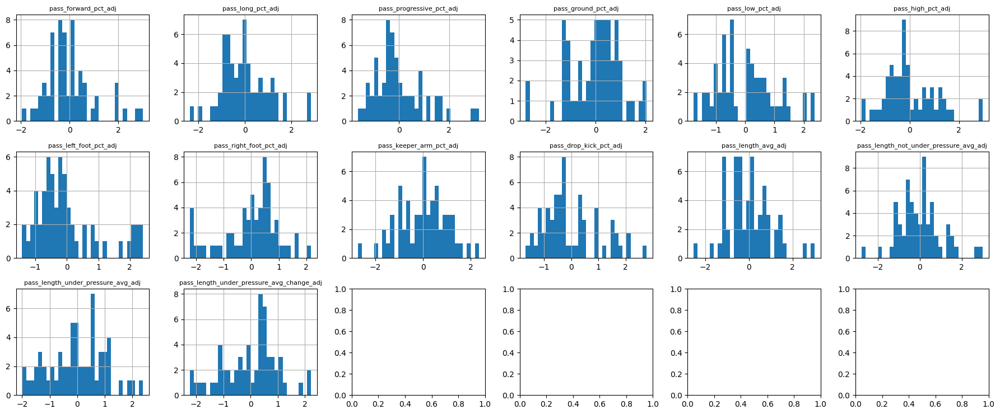

In [1053]:
# split into batches of ~24 features at a time, by conceptual block
passing_cols = [c for c in feature_cols_adj if 'pass' in c]
plot_histogram_grid(goalkeepers_stats, passing_cols)

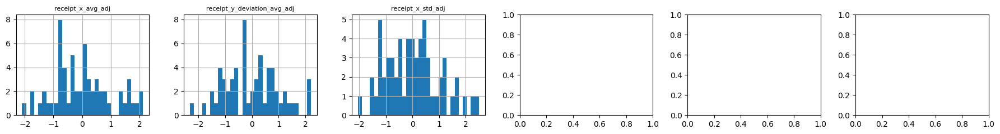

In [1054]:
# split into batches of ~24 features at a time, by conceptual block
receipt_cols = [c for c in feature_cols_adj if 'receipt' in c]
plot_histogram_grid(goalkeepers_stats, receipt_cols)

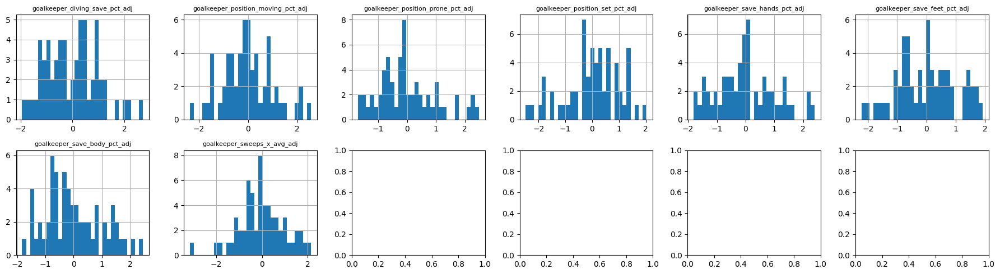

In [1055]:
# split into batches of ~24 features at a time, by conceptual block
goalkeeper_cols = [c for c in feature_cols_adj if 'goalkeeper' in c]
plot_histogram_grid(goalkeepers_stats, goalkeeper_cols)

In [1056]:
columns_to_drop_distribution = ['pass_left_foot_pct', 'pass_right_foot_pct']

In [1057]:
goalkeepers_stats = goalkeepers_stats.drop(columns=columns_to_drop_distribution + [c + '_adj' for c in columns_to_drop_distribution])

In [1058]:
goalkeepers_stats.shape

(60, 49)

In [1059]:
goalkeepers_stats.columns.tolist()

['pass_forward_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_moving_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_feet_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_sweeps_x_avg',
 'pass_forward_pct_adj',
 'pass_long_pct_adj',
 'pass_progressive_pct_adj',
 'pass_ground_pct_adj',
 'pass_low_pct_adj',
 'pass_high_pct_adj',
 'pass_keeper_arm_pct_adj',
 'pass_drop_kick_pct_adj',
 'pass_length_avg_adj',
 'pass_length_not_under_pressure_avg_adj',
 'pass_length_under_pressure_avg_adj',
 'pass_length_under_pressure_avg_change_adj',
 'receipt_x_avg_adj',
 'receipt_y_de

In [1060]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_distribution]

In [1061]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1062]:
len(feature_cols)

23

In [1063]:
len(feature_cols_adj)

23

#### Observe correlation between variables

In [1064]:
corr_matrix = goalkeepers_stats[feature_cols_adj].corr().abs()

In [1065]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [1066]:
high_corr_pairs = (upper.stack()
                   .reset_index()
                   .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'correlation'})
                   .sort_values('correlation', ascending=False))

In [1067]:
high_corr_pairs[high_corr_pairs['correlation'] > 0.8]

,feature_1,feature_2,correlation
193,pass_length_avg_adj,pass_length_not_under_pressure_avg_adj,0.986699
74,pass_ground_pct_adj,pass_high_pct_adj,0.983674
31,pass_long_pct_adj,pass_length_avg_adj,0.979061
28,pass_long_pct_adj,pass_high_pct_adj,0.969781
32,pass_long_pct_adj,pass_length_not_under_pressure_avg_adj,0.966933
26,pass_long_pct_adj,pass_ground_pct_adj,0.959618
25,pass_long_pct_adj,pass_progressive_pct_adj,0.938011
123,pass_high_pct_adj,pass_length_avg_adj,0.937401
51,pass_progressive_pct_adj,pass_high_pct_adj,0.932281
77,pass_ground_pct_adj,pass_length_avg_adj,0.927382


In [1068]:
columns_to_drop_correlation = ['pass_high_pct', 'pass_length_not_under_pressure_avg', 'pass_long_pct', 'goalkeeper_save_feet_pct',
                               'goalkeeper_position_moving_pct', 'pass_forward_pct', 'pass_progressive_pct']

In [1069]:
goalkeepers_stats = goalkeepers_stats.drop(columns=columns_to_drop_correlation + [c + '_adj' for c in columns_to_drop_correlation])

In [1070]:
goalkeepers_stats.shape

(60, 35)

In [1071]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_correlation]

In [1072]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1073]:
skew_check = goalkeepers_stats[feature_cols_adj].skew().sort_values(ascending=False)

In [1074]:
skew_check[skew_check.abs() > 1.5]

Series([], dtype: float64)

#### Final feature columns

In [1075]:
final_feature_cols = [c for c in feature_cols]

In [1076]:
final_feature_cols

['pass_ground_pct',
 'pass_low_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_length_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_sweeps_x_avg']

In [1077]:
len(final_feature_cols)

16

In [1078]:
final_feature_cols_adj = [c + '_adj' for c in final_feature_cols]

In [1079]:
final_feature_cols_adj

['pass_ground_pct_adj',
 'pass_low_pct_adj',
 'pass_keeper_arm_pct_adj',
 'pass_drop_kick_pct_adj',
 'pass_length_avg_adj',
 'pass_length_under_pressure_avg_adj',
 'pass_length_under_pressure_avg_change_adj',
 'receipt_x_avg_adj',
 'receipt_y_deviation_avg_adj',
 'receipt_x_std_adj',
 'goalkeeper_diving_save_pct_adj',
 'goalkeeper_position_prone_pct_adj',
 'goalkeeper_position_set_pct_adj',
 'goalkeeper_save_hands_pct_adj',
 'goalkeeper_save_body_pct_adj',
 'goalkeeper_sweeps_x_avg_adj']

In [1080]:
len(final_feature_cols_adj)

16

#### Detect outliers

In [1081]:
outliers_zscore = detect_outliers_zscore(goalkeepers_stats, final_feature_cols_adj, player_id_to_player, team_id_to_team)

In [1082]:
for col, rows in outliers_zscore.items():
    print(f"\n--- {col} ---")
    print(rows.sort_values('z_score', ascending=False))


--- pass_length_avg_adj ---
                                  league  pass_length_avg_adj  player_id  \
player_id team_id position_group                                           
408652.0  3275    Goalkeeper      Liga F             3.008907   408652.0   

                                  team_id   z_score                 player  \
player_id team_id position_group                                             
408652.0  3275    Goalkeeper         3275  3.008907  María Miralles Gascón   

                                      team  
player_id team_id position_group            
408652.0  3275    Goalkeeper      SD Eibar  

--- goalkeeper_sweeps_x_avg_adj ---
                                                   league  \
player_id team_id position_group                            
18158.0   749     Goalkeeper      FA Women's Super League   

                                  goalkeeper_sweeps_x_avg_adj  player_id  \
player_id team_id position_group                                           

In [1083]:
outliers_iqr = detect_outliers_iqr(goalkeepers_stats, final_feature_cols_adj, player_id_to_player, team_id_to_team)

In [1084]:
for col, rows in outliers_iqr.items():
    print(f"\n--- {col} ---")
    print(rows)


--- pass_ground_pct_adj ---
                                         league  pass_ground_pct_adj  \
player_id team_id position_group                                       
408652.0  3275    Goalkeeper             Liga F            -2.802924   
45630.0   6757    Goalkeeper      Serie A Women            -2.709867   

                                  player_id  team_id                 player  \
player_id team_id position_group                                              
408652.0  3275    Goalkeeper       408652.0     3275  María Miralles Gascón   
45630.0   6757    Goalkeeper        45630.0     6757        Amanda Tampieri   

                                         team  bound_distance  
player_id team_id position_group                               
408652.0  3275    Goalkeeper         SD Eibar        0.393430  
45630.0   6757    Goalkeeper      Sampdoria W        0.300374  

--- pass_keeper_arm_pct_adj ---
                                  league  pass_keeper_arm_pct_adj  player_id

In [1085]:
all_flagged_players_zscore = []

In [1086]:
for col, rows in outliers_zscore.items():
    all_flagged_players_zscore.extend(rows['player_id'].tolist())

In [1087]:
flag_counts_zscore = pd.Series(Counter(all_flagged_players_zscore)).sort_values(ascending=False)

In [1088]:
flag_counts_zscore

408652.0    1
18158.0     1
dtype: int64

In [1089]:
all_flagged_players_iqr = []

In [1090]:
for col, rows in outliers_iqr.items():
    all_flagged_players_iqr.extend(rows['player_id'].tolist())

In [1091]:
flag_counts_iqr = pd.Series(Counter(all_flagged_players_iqr)).sort_values(ascending=False)

In [1092]:
flag_counts_iqr

408652.0    4
45630.0     2
62713.0     1
63784.0     1
409183.0    1
18158.0     1
dtype: int64

In [1093]:
winsorize_cols = ['pass_ground_pct_adj', 'pass_low_pct_adj', 'pass_keeper_arm_pct_adj', 'pass_drop_kick_pct_adj', 'pass_length_avg_adj', 
                  'goalkeeper_sweeps_x_avg_adj', 'goalkeeper_position_prone_pct_adj', 'goalkeeper_position_set_pct_adj']

In [1094]:
for col in winsorize_cols:
    goalkeepers_stats[col] = winsorize(goalkeepers_stats[col])

In [1095]:
imputation_configs = [
    dict(position_group='Goalkeeper', pct_col='goalkeeper_sweeps_x_avg',
         attempted_col='goalkeeper_sweeps_attempted', min_quantile=0.2),
]

In [1096]:
for cfg in imputation_configs:
    pos, pct_col = cfg['position_group'], cfg['pct_col']
    target_df = stats_by_position[pos]
    
    # reads eligibility/reliable-group-mean from all_players_stats (untouched, read-only),
    # writes the imputed value into target_df only
    target_df = impute_unreliable_rate_stat(all_players_stats, target_df, **cfg)

    # residualize on target_df itself, using its now-imputed raw value as input
    refit = residualize(
        target_df, feature_cols=[pct_col], covariate_col='context_score',
        group_cols=['position_group'], robust=True,
    )
    target_df[pct_col + '_adj'] = refit[pct_col + '_adj']

    stats_by_position[pos] = target_df

#### Rank features on percentile

In [1097]:
goalkeepers_stats = to_percentile(goalkeepers_stats, final_feature_cols)      # raw

In [1098]:
goalkeepers_stats = to_percentile(goalkeepers_stats, final_feature_cols_adj) # adjusted

#### Divide features into groups

In [1099]:
feature_groups = {
    'passing_share': [
        'pass_ground_pct', 'pass_low_pct', 'pass_keeper_arm_pct', 'pass_drop_kick_pct'
    ],
    'passing_length': [
        'pass_length_avg', 'pass_length_under_pressure_avg', 'pass_length_under_pressure_avg_change',
    ],
    'receipt': [
        'receipt_x_avg', 'receipt_y_deviation_avg', 'receipt_x_std',
    ],
    'goalkeeping': [
        'goalkeeper_diving_save_pct', 'goalkeeper_position_prone_pct', 'goalkeeper_position_set_pct',
        'goalkeeper_save_hands_pct', 'goalkeeper_save_body_pct', 'goalkeeper_sweeps_x_avg'
    ]
}

In [1100]:
feature_groups_adj = {
    category: [f + '_adj' for f in features]
    for category, features in feature_groups.items()
}

In [1101]:
n_per_category = {
    'passing_share': 2, 'passing_length': 2, 'receipt': 2, 'goalkeeping': 3 
}

In [1102]:
all_grouped = [c for group in feature_groups.values() for c in group]

In [1103]:
missing = set(final_feature_cols) - set(all_grouped)

In [1104]:
missing

set()

In [1105]:
spare = set(all_grouped) - set(final_feature_cols)

In [1106]:
spare

set()

#### KMeans Clustering

##### PCA

In [1107]:
X = goalkeepers_stats[final_feature_cols_adj]

In [1108]:
n_features = 5

In [1109]:
pca_reduced_final = PCA(n_components=n_features)

In [1110]:
pca_reduced_final.set_output(transform='pandas')

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",5
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

In [1111]:
X_pca_final = pca_reduced_final.fit_transform(X)

##### KMeans with k = 2

In [1112]:
k = 2

In [1113]:
kmeans_2 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1114]:
goalkeepers_stats['kmeans_2_cluster'] = kmeans_2.fit_predict(X_pca_final)  # or X, if using raw features

In [1115]:
# bring labels back to the original unstandardized data for interpretation
goalkeepers_stats['kmeans_2_cluster'] = goalkeepers_stats['kmeans_2_cluster'].values

In [1116]:
goalkeepers_stats['kmeans_2_cluster'].value_counts()

kmeans_2_cluster
0    42
1    18
Name: count, dtype: int64

In [1117]:
goalkeepers_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_2, 
    stats_df=goalkeepers_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 3

In [1118]:
k = 3

In [1119]:
kmeans_3 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1120]:
goalkeepers_stats['kmeans_3_cluster'] = kmeans_3.fit_predict(X_pca_final)  # or X, if using raw features

In [1121]:
# bring labels back to the original unstandardized data for interpretation
goalkeepers_stats['kmeans_3_cluster'] = goalkeepers_stats['kmeans_3_cluster'].values

In [1122]:
goalkeepers_stats['kmeans_3_cluster'].value_counts()

kmeans_3_cluster
1    29
2    19
0    12
Name: count, dtype: int64

In [1123]:
goalkeepers_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_3, 
    stats_df=goalkeepers_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 4

In [1124]:
k = 4

In [1125]:
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

In [1126]:
goalkeepers_stats['kmeans_4_cluster'] = kmeans_4.fit_predict(X_pca_final)  # or X, if using raw features

In [1127]:
# bring labels back to the original unstandardized data for interpretation
goalkeepers_stats['kmeans_4_cluster'] = goalkeepers_stats['kmeans_4_cluster'].values

In [1128]:
goalkeepers_stats['kmeans_4_cluster'].value_counts()

kmeans_4_cluster
2    29
0    14
3    11
1     6
Name: count, dtype: int64

In [1129]:
goalkeepers_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_4, 
    stats_df=goalkeepers_stats,
    sigma_quantile=0.5
)

### Center Backs

#### Filter by position

In [1130]:
center_backs_stats.shape

(154, 347)

In [1131]:
center_backs_stats.columns.tolist()

['passes_attempted',
 'pass_completion_pct',
 'pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_under_pressure_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_deflected_pct',
 'pass_goal_assist_pct',
 'pass_miscommunication_pct',
 'pass_no_touch_pct',
 'pass_shot_assist_pct',
 'pass_through_ball_pct',
 'pass_create_shot_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_deep_completion_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_aerial_won_completion_pct',
 'pass_cross_completion_pct',
 'pass_cut_back_completion_pct',
 'pass_deflected_completion_pct',
 'pass_no_touch_completion_pct',
 'pass_switch_completion_pct',
 'pass_through_ball_completion_pct',
 'pass_forward_complet

In [1132]:
center_backs_stats = center_backs_stats[style_feature_cols + style_feature_cols_adj + ['league', 'minutes_at_position', 'context_score']]

In [1133]:
center_backs_stats.shape

(154, 199)

In [1134]:
center_backs_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_no_touch_pct',
 'pass_through_ball_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_o

In [1135]:
columns_to_drop_irrelevant = ['pass_cross_pct',
 'pass_cut_back_pct',
 'pass_no_touch_pct',
 'pass_through_ball_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_left_foot_pct',
 'shot_open_play_right_foot_pct',
 'shot_open_play_head_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_technique_volley_pct',
 'shot_open_play_technique_half_volley_pct',
 'shot_open_play_technique_lob_pct',
 'shot_open_play_technique_backheel_pct',
 'shot_open_play_technique_overhead_kick_pct',
 'shot_open_play_technique_diving_header_pct',
 'shot_open_play_distance_avg',
 'shot_open_play_angle_avg',
 'shot_open_play_in_opposition_box_pct',
 'receipt_in_opposition_box_pct',
 'foul_won_defensive_pct',
 'foul_won_box_pct',
 'foul_won_x_avg',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_moving_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_feet_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_sweeps_x_avg',]

In [1136]:
center_backs_stats = center_backs_stats.drop(columns=columns_to_drop_irrelevant + [c + '_adj' for c in columns_to_drop_irrelevant])

In [1137]:
center_backs_stats.shape

(154, 115)

In [1138]:
feature_cols = [c for c in style_feature_cols if c not in columns_to_drop_irrelevant]

In [1139]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1140]:
len(feature_cols)

56

In [1141]:
len(feature_cols_adj)

56

#### Observe distribution of stats

In [1142]:
summary = center_backs_stats[feature_cols_adj].describe().T
summary['skew'] = center_backs_stats[feature_cols_adj].skew()
summary['pct_zero'] = (center_backs_stats[feature_cols_adj] == 0).mean()
summary['pct_missing'] = center_backs_stats[feature_cols_adj].isna().mean()
summary.sort_values('skew', ascending=False)

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing
fouls_committed_offensive_pct_adj,154.0,-4.613914e-17,1.003263,-0.424069,-0.419976,-0.334845,-0.313724,4.853824,2.884956,0.0,0.0
foul_committed_box_pct_adj,154.0,1.268826e-16,1.003263,-0.701030,-0.599390,-0.462230,0.182270,4.481869,2.126762,0.0,0.0
block_shot_pct_adj,154.0,8.651089e-17,1.003263,-0.520331,-0.519398,-0.476110,-0.387453,3.808087,2.118053,0.0,0.0
pass_backward_pct_adj,154.0,-2.739511e-17,1.003263,-2.067908,-0.618984,-0.146491,0.309052,4.403272,1.551834,0.0,0.0
dribbled_past_x_avg_adj,154.0,8.651089e-18,1.003263,-2.206332,-0.553564,-0.161366,0.415475,4.727839,1.385804,0.0,0.0
pass_aerial_won_pct_adj,154.0,-1.874403e-17,1.003263,-2.067417,-0.635991,-0.240648,0.498735,3.589798,1.015771,0.0,0.0
carry_into_final_third_pct_adj,154.0,5.767392e-18,1.003263,-1.686026,-0.689245,-0.250482,0.594071,3.749238,0.903440,0.0,0.0
fifty_fifty_x_avg_adj,154.0,0.000000e+00,1.003263,-1.822063,-0.575602,-0.087871,0.436166,3.784068,0.822867,0.0,0.0
clearance_x_avg_adj,154.0,-1.153478e-17,1.003263,-2.340943,-0.593077,-0.098539,0.608915,4.714611,0.816079,0.0,0.0
pass_head_pct_adj,154.0,3.460435e-17,1.003263,-2.443158,-0.715497,-0.244144,0.409784,2.979244,0.801905,0.0,0.0


In [1143]:
summary.shape

(56, 11)

In [1144]:
low_variance = summary[summary['std'] / summary['mean'].abs() < 0.1]

In [1145]:
low_variance

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing


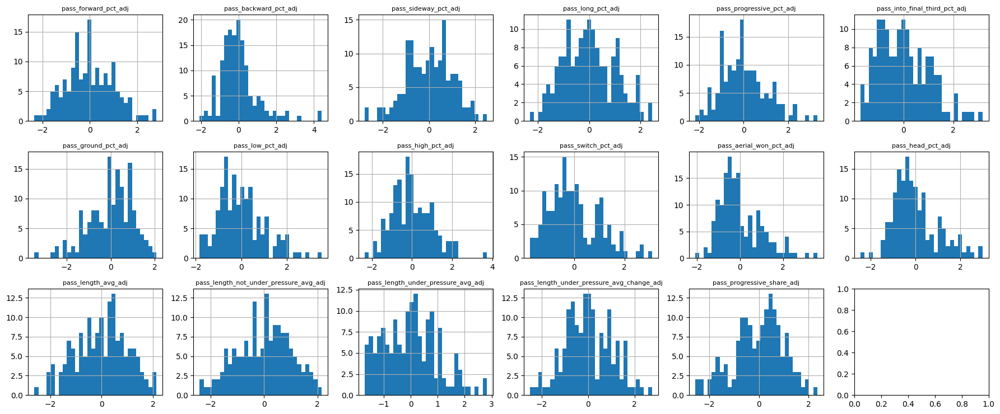

In [1146]:
# split into batches of ~24 features at a time, by conceptual block
passing_cols = [c for c in feature_cols_adj if 'pass' in c]
plot_histogram_grid(center_backs_stats, passing_cols)

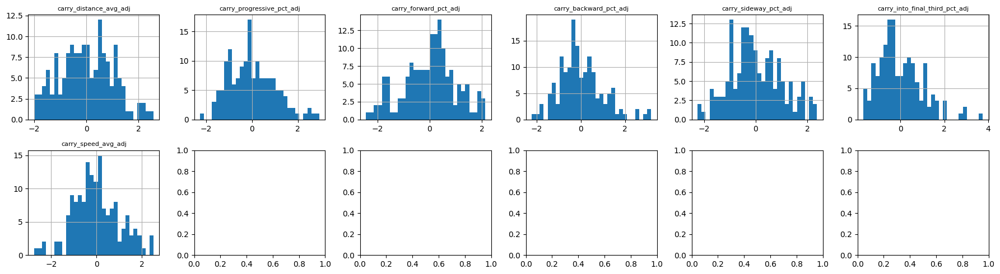

In [1147]:
# split into batches of ~24 features at a time, by conceptual block
carrying_cols = [c for c in feature_cols_adj if 'carry' in c]
plot_histogram_grid(center_backs_stats, carrying_cols)

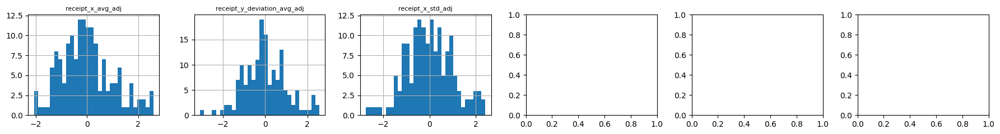

In [1148]:
# split into batches of ~24 features at a time, by conceptual block
receipt_cols = [c for c in feature_cols_adj if 'receipt' in c]
plot_histogram_grid(center_backs_stats, receipt_cols)

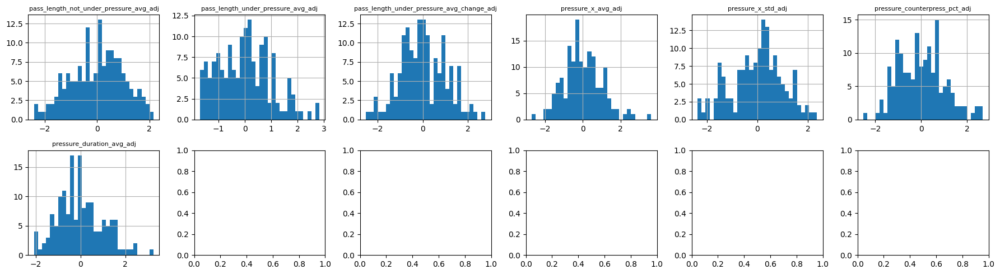

In [1149]:
# split into batches of ~24 features at a time, by conceptual block
pressure_cols = [c for c in feature_cols_adj if 'pressure' in c]
plot_histogram_grid(center_backs_stats, pressure_cols)

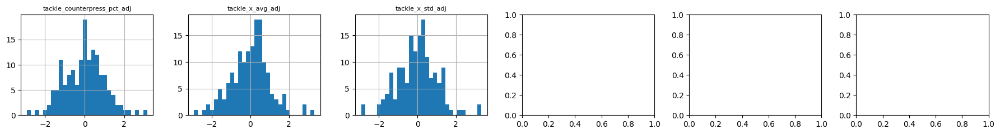

In [1150]:
# split into batches of ~24 features at a time, by conceptual block
tackle_cols = [c for c in feature_cols_adj if 'tackle' in c]
plot_histogram_grid(center_backs_stats, tackle_cols)

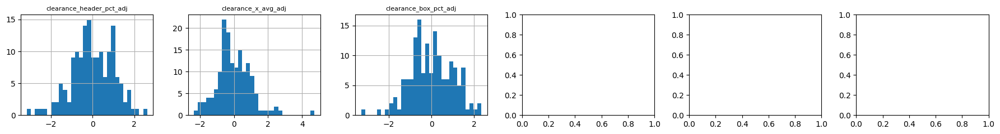

In [1151]:
# split into batches of ~24 features at a time, by conceptual block
clearance_cols = [c for c in feature_cols_adj if 'clearance' in c]
plot_histogram_grid(center_backs_stats, clearance_cols)

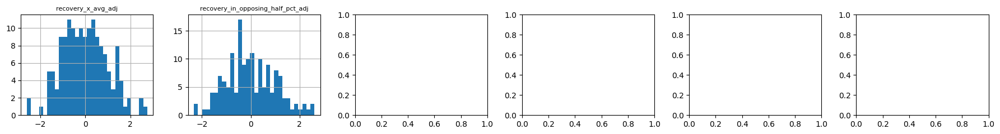

In [1152]:
# split into batches of ~24 features at a time, by conceptual block
recovery_cols = [c for c in feature_cols_adj if 'recover' in c]
plot_histogram_grid(center_backs_stats, recovery_cols)

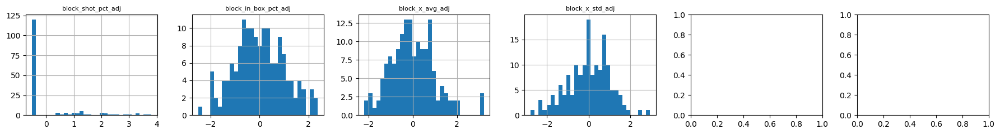

In [1153]:
# split into batches of ~24 features at a time, by conceptual block
block_cols = [c for c in feature_cols_adj if 'block' in c]
plot_histogram_grid(center_backs_stats, block_cols)

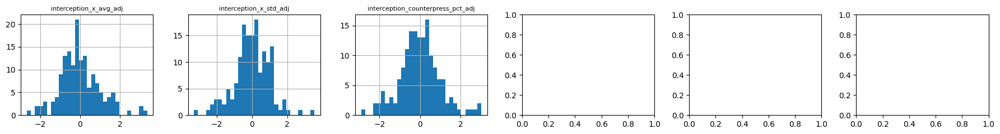

In [1154]:
# split into batches of ~24 features at a time, by conceptual block
interception_cols = [c for c in feature_cols_adj if 'intercept' in c]
plot_histogram_grid(center_backs_stats, interception_cols)

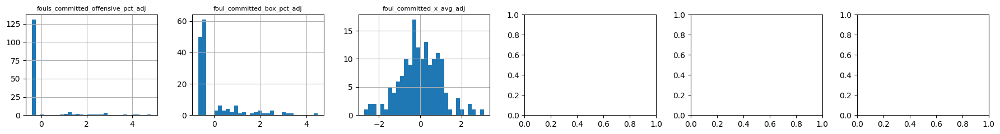

In [1155]:
# split into batches of ~24 features at a time, by conceptual block
foul_cols = [c for c in feature_cols_adj if 'foul' in c]
plot_histogram_grid(center_backs_stats, foul_cols)

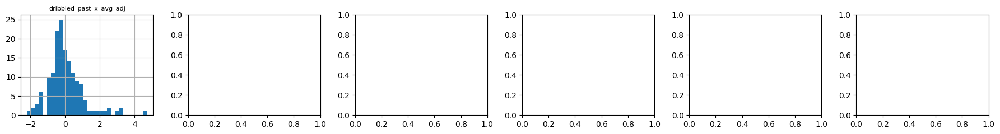

In [1156]:
# split into batches of ~24 features at a time, by conceptual block
dribbled_past_cols = [c for c in feature_cols_adj if 'dribble' in c]
plot_histogram_grid(center_backs_stats, dribbled_past_cols)

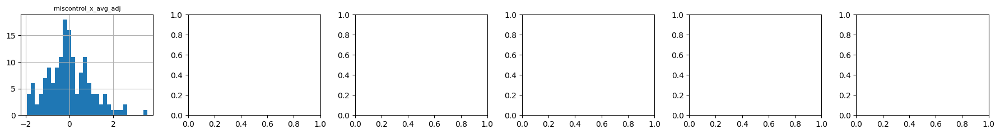

In [1157]:
# split into batches of ~24 features at a time, by conceptual block
miscontrol_cols = [c for c in feature_cols_adj if 'miscontrol' in c]
plot_histogram_grid(center_backs_stats, miscontrol_cols)

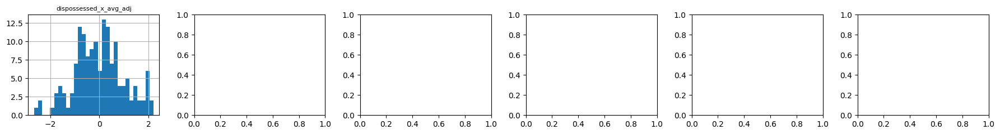

In [1158]:
# split into batches of ~24 features at a time, by conceptual block
dispossessed_cols = [c for c in feature_cols_adj if 'dispossessed' in c]
plot_histogram_grid(center_backs_stats, dispossessed_cols)

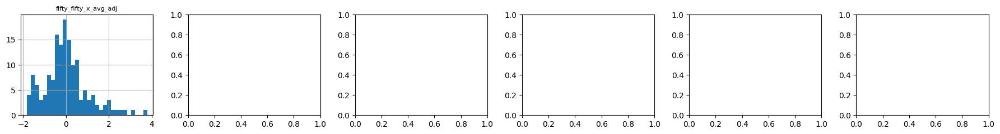

In [1159]:
# split into batches of ~24 features at a time, by conceptual block
fifty_fifty_cols = [c for c in feature_cols_adj if 'fifty_fifty' in c]
plot_histogram_grid(center_backs_stats, fifty_fifty_cols)

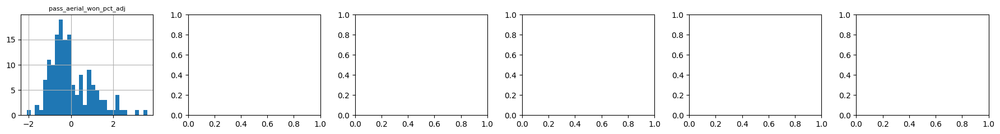

In [1160]:
# split into batches of ~24 features at a time, by conceptual block
aerial_cols = [c for c in feature_cols_adj if 'aerial' in c]
plot_histogram_grid(center_backs_stats, aerial_cols)

In [1161]:
columns_to_drop_distribution = ['pass_length_under_pressure_avg', 'block_shot_pct', 'fouls_committed_offensive_pct', 'foul_committed_box_pct']

In [1162]:
center_backs_stats = center_backs_stats.drop(columns=columns_to_drop_distribution + [c + '_adj' for c in columns_to_drop_distribution])

In [1163]:
center_backs_stats.shape

(154, 107)

In [1164]:
center_backs_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_head_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'clearance_box_pct',
 'recovery_x_avg',
 'recovery_in_opposing_half_pct',
 'block_in_box_pct',
 'block_x_avg',
 'block_x_std',
 'interception_x_avg',
 'interception_x_std',
 'interception_counterpress_pct',
 'fou

In [1165]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_distribution]

In [1166]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1167]:
len(feature_cols)

52

In [1168]:
len(feature_cols_adj)

52

#### Observe correlation between variables

In [1169]:
corr_matrix = center_backs_stats[feature_cols_adj].corr().abs()

In [1170]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [1171]:
high_corr_pairs = (upper.stack()
                   .reset_index()
                   .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'correlation'})
                   .sort_values('correlation', ascending=False))

In [1172]:
high_corr_pairs[high_corr_pairs['correlation'] > 0.8]

,feature_1,feature_2,correlation
637,pass_length_avg_adj,pass_length_not_under_pressure_avg_adj,0.984325
2,pass_forward_pct_adj,pass_sideway_pct_adj,0.966928
320,pass_ground_pct_adj,pass_high_pct_adj,0.952610
168,pass_long_pct_adj,pass_length_avg_adj,0.914568
169,pass_long_pct_adj,pass_length_not_under_pressure_avg_adj,0.911512
213,pass_progressive_pct_adj,pass_into_final_third_pct_adj,0.888687
903,carry_forward_pct_adj,carry_sideway_pct_adj,0.883991
216,pass_progressive_pct_adj,pass_high_pct_adj,0.870751
1348,pressure_x_avg_adj,defensive_actions_x_avg_adj,0.863375
214,pass_progressive_pct_adj,pass_ground_pct_adj,0.845343


In [1173]:
columns_to_drop_correlation = ['pass_length_not_under_pressure_avg', 'pass_sideway_pct', 'pass_long_pct', 'pass_progressive_pct',
                               'pass_high_pct', 'carry_sideway_pct', 'defensive_actions_x_avg', 'carry_progressive_pct',
                               'clearance_box_pct', 'recovery_in_opposing_half_pct']

In [1174]:
center_backs_stats = center_backs_stats.drop(columns=columns_to_drop_correlation + [c + '_adj' for c in columns_to_drop_correlation])

In [1175]:
center_backs_stats.shape

(154, 87)

In [1176]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_correlation]

In [1177]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1178]:
len(feature_cols)

42

In [1179]:
len(feature_cols_adj)

42

In [1180]:
skew_check = center_backs_stats[feature_cols_adj].skew().sort_values(ascending=False)

In [1181]:
skew_check[skew_check.abs() > 1.5]

pass_backward_pct_adj    1.551834
dtype: float64

#### Final feature columns

In [1182]:
final_feature_cols = [c for c in feature_cols]

In [1183]:
final_feature_cols

['pass_forward_pct',
 'pass_backward_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_head_pct',
 'pass_length_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'recovery_x_avg',
 'block_in_box_pct',
 'block_x_avg',
 'block_x_std',
 'interception_x_avg',
 'interception_x_std',
 'interception_counterpress_pct',
 'foul_committed_x_avg',
 'dribbled_past_x_avg',
 'miscontrol_x_avg',
 'dispossessed_x_avg',
 'fifty_fifty_x_avg',
 'defensive_actions_x_std',
 'counterpress_in_opposing_half_pct',
 'pass_progressive_share']

In [1184]:
len(final_feature_cols)

42

In [1185]:
final_feature_cols_adj = [c + '_adj' for c in final_feature_cols]

In [1186]:
final_feature_cols_adj

['pass_forward_pct_adj',
 'pass_backward_pct_adj',
 'pass_into_final_third_pct_adj',
 'pass_ground_pct_adj',
 'pass_low_pct_adj',
 'pass_switch_pct_adj',
 'pass_aerial_won_pct_adj',
 'pass_head_pct_adj',
 'pass_length_avg_adj',
 'pass_length_under_pressure_avg_change_adj',
 'carry_distance_avg_adj',
 'carry_forward_pct_adj',
 'carry_backward_pct_adj',
 'carry_into_final_third_pct_adj',
 'carry_speed_avg_adj',
 'receipt_x_avg_adj',
 'receipt_y_deviation_avg_adj',
 'receipt_x_std_adj',
 'pressure_x_avg_adj',
 'pressure_x_std_adj',
 'pressure_counterpress_pct_adj',
 'pressure_duration_avg_adj',
 'tackle_counterpress_pct_adj',
 'tackle_x_avg_adj',
 'tackle_x_std_adj',
 'clearance_header_pct_adj',
 'clearance_x_avg_adj',
 'recovery_x_avg_adj',
 'block_in_box_pct_adj',
 'block_x_avg_adj',
 'block_x_std_adj',
 'interception_x_avg_adj',
 'interception_x_std_adj',
 'interception_counterpress_pct_adj',
 'foul_committed_x_avg_adj',
 'dribbled_past_x_avg_adj',
 'miscontrol_x_avg_adj',
 'dispossess

In [1187]:
len(final_feature_cols_adj)

42

#### Detect outliers

In [1188]:
outliers_zscore = detect_outliers_zscore(center_backs_stats, final_feature_cols_adj, player_id_to_player, team_id_to_team)

In [1189]:
for col, rows in outliers_zscore.items():
    print(f"\n--- {col} ---")
    print(rows.sort_values('z_score', ascending=False))


--- pass_backward_pct_adj ---
                                             league  pass_backward_pct_adj  \
player_id team_id position_group                                             
47104.0   3168    Center Back     Frauen Bundesliga               4.403272   
25514.0   3275    Center Back                Liga F               4.221177   
50111.0   3275    Center Back                Liga F               3.182147   

                                  player_id  team_id   z_score  \
player_id team_id position_group                                 
47104.0   3168    Center Back       47104.0     3168  4.403272   
25514.0   3275    Center Back       25514.0     3275  4.221177   
50111.0   3275    Center Back       50111.0     3275  3.182147   

                                                             player  \
player_id team_id position_group                                      
47104.0   3168    Center Back                  Michaela Brandenburg   
25514.0   3275    Center Back     

In [1190]:
outliers_iqr = detect_outliers_iqr(center_backs_stats, final_feature_cols_adj, player_id_to_player, team_id_to_team)

In [1191]:
for col, rows in outliers_iqr.items():
    print(f"\n--- {col} ---")
    print(rows)


--- pass_backward_pct_adj ---
                                                   league  \
player_id team_id position_group                            
47104.0   3168    Center Back           Frauen Bundesliga   
25514.0   3275    Center Back                      Liga F   
50111.0   3275    Center Back                      Liga F   
276907.0  972     Center Back     FA Women's Super League   
388473.0  965     Center Back     FA Women's Super League   
15554.0   966     Center Back     FA Women's Super League   
47116.0   3155    Center Back               Serie A Women   
324159.0  3168    Center Back           Frauen Bundesliga   
43038.0   1086    Center Back               Serie A Women   
50266.0   6755    Center Back               Serie A Women   

                                  pass_backward_pct_adj  player_id  team_id  \
player_id team_id position_group                                              
47104.0   3168    Center Back                  4.403272    47104.0     3168   

In [1192]:
all_flagged_players_zscore = []

In [1193]:
for col, rows in outliers_zscore.items():
    all_flagged_players_zscore.extend(rows['player_id'].tolist())

In [1194]:
flag_counts_zscore = pd.Series(Counter(all_flagged_players_zscore)).sort_values(ascending=False)

In [1195]:
flag_counts_zscore

50111.0     4
408656.0    3
188984.0    3
53183.0     2
135578.0    2
26092.0     2
34232.0     1
25514.0     1
47104.0     1
45731.0     1
10230.0     1
10165.0     1
126980.0    1
18999.0     1
224149.0    1
24374.0     1
324159.0    1
49939.0     1
10417.0     1
32697.0     1
226036.0    1
25491.0     1
49950.0     1
423620.0    1
46361.0     1
46891.0     1
dtype: int64

In [1196]:
all_flagged_players_iqr = []

In [1197]:
for col, rows in outliers_iqr.items():
    all_flagged_players_iqr.extend(rows['player_id'].tolist())

In [1198]:
flag_counts_iqr = pd.Series(Counter(all_flagged_players_iqr)).sort_values(ascending=False)

In [1199]:
flag_counts_iqr

408656.0    6
50111.0     5
25514.0     4
49939.0     4
32697.0     4
26093.0     4
324159.0    3
423620.0    3
5028.0      3
53183.0     3
45639.0     3
188984.0    3
49950.0     3
26092.0     3
24374.0     3
10165.0     3
126980.0    2
10417.0     2
4984.0      2
10399.0     2
18999.0     2
23413.0     2
45731.0     2
46977.0     2
49044.0     2
15554.0     2
388473.0    2
135578.0    2
18254.0     1
46555.0     1
47006.0     1
31157.0     1
15720.0     1
43038.0     1
50266.0     1
47116.0     1
276907.0    1
47104.0     1
34232.0     1
50832.0     1
10230.0     1
31533.0     1
45631.0     1
32701.0     1
21021.0     1
224149.0    1
4633.0      1
4642.0      1
32143.0     1
226036.0    1
25491.0     1
5078.0      1
87190.0     1
53192.0     1
50372.0     1
46891.0     1
46361.0     1
25687.0     1
49898.0     1
dtype: int64

In [1200]:
winsorize_cols = ['pass_forward_pct_adj', 'pass_backward_pct_adj', 'pass_into_final_third_pct_adj', 'pass_switch_pct_adj', 
                  'pass_aerial_won_pct_adj', 'pass_head_pct_adj', 'pass_ground_pct_adj', 'pass_low_pct_adj',
                  'carry_forward_pct_adj', 'carry_backward_pct_adj', 'carry_into_final_third_pct_adj', 'carry_speed_avg_adj', 
                  'receipt_x_avg_adj', 'receipt_y_deviation_avg_adj', 'receipt_x_std_adj', 'pressure_x_avg_adj', 
                  'pressure_duration_avg_adj', 'tackle_counterpress_pct_adj', 'tackle_x_avg_adj', 'tackle_x_std_adj', 
                  'clearance_header_pct_adj', 'clearance_x_avg_adj', 'block_x_avg_adj', 'block_x_std_adj', 
                  'interception_x_avg_adj', 'interception_x_std_adj', 'interception_counterpress_pct_adj', 'foul_committed_x_avg_adj', 
                  'dribbled_past_x_avg_adj', 'miscontrol_x_avg_adj', 'fifty_fifty_x_avg_adj', 'counterpress_in_opposing_half_pct_adj']

In [1201]:
for col in winsorize_cols:
    center_backs_stats[col] = winsorize(center_backs_stats[col])

In [1202]:
imputation_configs = [  
    dict(position_group='Center Back', pct_col='pressure_x_avg',
        attempted_col='pressures_applied', min_quantile=0.2),
    dict(position_group='Center Back', pct_col='tackle_x_avg',
        attempted_col='tackles_attempted', min_quantile=0.2),
    dict(position_group='Center Back', pct_col='tackle_x_std',
        attempted_col='tackles_attempted', min_quantile=0.2),
    dict(position_group='Center Back', pct_col='clearance_x_avg',
        attempted_col='clearances_attempted', min_quantile=0.2),
    dict(position_group='Center Back', pct_col='block_x_avg',
        attempted_col='blocks_total', min_quantile=0.2), 
    dict(position_group='Center Back', pct_col='block_x_std',
        attempted_col='blocks_total', min_quantile=0.2),
    dict(position_group='Center Back', pct_col='interception_x_avg',
        attempted_col='interceptions_attempted', min_quantile=0.2),
    dict(position_group='Center Back', pct_col='interception_x_std',
        attempted_col='interceptions_attempted', min_quantile=0.2),    
    dict(position_group='Center Back', pct_col='foul_committed_x_avg',
        attempted_col='fouls_committed', min_quantile=0.2),    
    dict(position_group='Center Back', pct_col='dribbled_past_x_avg',
        attempted_col='dribbled_pasts', min_quantile=0.2),    
    dict(position_group='Center Back', pct_col='miscontrol_x_avg',
        attempted_col='miscontrols', min_quantile=0.2),    
    dict(position_group='Center Back', pct_col='fifty_fifty_x_avg',
        attempted_col='fifty_fiftys', min_quantile=0.2),    
]

In [1203]:
for cfg in imputation_configs:
    pos, pct_col = cfg['position_group'], cfg['pct_col']
    target_df = stats_by_position[pos]
    
    # reads eligibility/reliable-group-mean from all_players_stats (untouched, read-only),
    # writes the imputed value into target_df only
    target_df = impute_unreliable_rate_stat(all_players_stats, target_df, **cfg)

    # residualize on target_df itself, using its now-imputed raw value as input
    refit = residualize(
        target_df, feature_cols=[pct_col], covariate_col='context_score',
        group_cols=['position_group'], robust=True,
    )
    target_df[pct_col + '_adj'] = refit[pct_col + '_adj']

    stats_by_position[pos] = target_df

#### Rank features on percentile

In [1204]:
center_backs_stats = to_percentile(center_backs_stats, final_feature_cols)      # raw

In [1205]:
center_backs_stats = to_percentile(center_backs_stats, final_feature_cols_adj) # adjusted

#### Divide features into groups

In [1206]:
feature_groups = {
    'passing_share': [
        'pass_forward_pct', 'pass_backward_pct', 'pass_into_final_third_pct', 'pass_ground_pct',
        'pass_low_pct', 'pass_switch_pct', 'pass_aerial_won_pct', 'pass_head_pct', 'pass_progressive_share'
    ],
    'passing_length': [
        'pass_length_avg', 'pass_length_under_pressure_avg_change'
    ],
    'carrying': [
        'carry_distance_avg', 'carry_forward_pct', 'carry_backward_pct', 'carry_into_final_third_pct', 'carry_speed_avg'
    ],
    'receipt': [
        'receipt_x_avg', 'receipt_y_deviation_avg', 'receipt_x_std'
    ],
    'defensive_location': [
        'pressure_x_avg', 'pressure_x_std', 'tackle_x_avg', 'tackle_x_std', 'clearance_x_avg', 'recovery_x_avg', 'block_in_box_pct', 
        'block_x_avg', 'block_x_std', 'interception_x_avg', 'interception_x_std', 'defensive_actions_x_std', 'counterpress_in_opposing_half_pct'
    ],
    'defensive_volume': [
        'pressure_counterpress_pct', 'pressure_duration_avg', 'tackle_counterpress_pct', 'clearance_header_pct', 'interception_counterpress_pct'
    ],
    'vulnerability_fifty_fifty': [
        'foul_committed_x_avg', 'dribbled_past_x_avg', 'miscontrol_x_avg', 'dispossessed_x_avg', 'fifty_fifty_x_avg'
    ]
}

In [1207]:
feature_groups_adj = {
    category: [f + '_adj' for f in features]
    for category, features in feature_groups.items()
}

In [1208]:
n_per_category = {
    'passing_share': 5, 'passing_length': 1, 'carrying': 2, 'receipt': 2, 'defensive_location': 4, 'defensive_volume': 2, 'vulnerability_fifty_fifty': 2
}

In [1209]:
all_grouped = [c for group in feature_groups.values() for c in group]

In [1210]:
missing = set(final_feature_cols) - set(all_grouped)

In [1211]:
missing

set()

In [1212]:
spare = set(all_grouped) - set(final_feature_cols)

#### KMeans Clustering

##### PCA

In [1213]:
X = center_backs_stats[final_feature_cols_adj]

In [1214]:
n_features = 9

In [1215]:
pca_reduced_final = PCA(n_components=n_features)

In [1216]:
pca_reduced_final.set_output(transform='pandas')

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",9
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

In [1217]:
X_pca_final = pca_reduced_final.fit_transform(X)

##### KMeans with k = 2

In [1218]:
k = 2

In [1219]:
kmeans_2 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1220]:
center_backs_stats['kmeans_2_cluster'] = kmeans_2.fit_predict(X_pca_final)  # or X, if using raw features

In [1221]:
# bring labels back to the original unstandardized data for interpretation
center_backs_stats['kmeans_2_cluster'] = center_backs_stats['kmeans_2_cluster'].values

In [1222]:
center_backs_stats['kmeans_2_cluster'].value_counts()

kmeans_2_cluster
0    101
1     53
Name: count, dtype: int64

In [1223]:
center_backs_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_2, 
    stats_df=center_backs_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 3

In [1224]:
k = 3

In [1225]:
kmeans_3 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1226]:
center_backs_stats['kmeans_3_cluster'] = kmeans_3.fit_predict(X_pca_final)  # or X, if using raw features

In [1227]:
# bring labels back to the original unstandardized data for interpretation
center_backs_stats['kmeans_3_cluster'] = center_backs_stats['kmeans_3_cluster'].values

In [1228]:
center_backs_stats['kmeans_3_cluster'].value_counts()

kmeans_3_cluster
1    60
2    57
0    37
Name: count, dtype: int64

In [1229]:
center_backs_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_3, 
    stats_df=center_backs_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 4

In [1230]:
k = 4

In [1231]:
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

In [1232]:
center_backs_stats['kmeans_4_cluster'] = kmeans_4.fit_predict(X_pca_final)  # or X, if using raw features

In [1233]:
# bring labels back to the original unstandardized data for interpretation
center_backs_stats['kmeans_4_cluster'] = center_backs_stats['kmeans_4_cluster'].values

In [1234]:
center_backs_stats['kmeans_4_cluster'].value_counts()

kmeans_4_cluster
2    54
0    42
3    29
1    29
Name: count, dtype: int64

In [1235]:
center_backs_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_4, 
    stats_df=center_backs_stats,
    sigma_quantile=0.5
)

### Full/Wing Backs

#### Filter by position

In [1236]:
full_wing_backs_stats.shape

(129, 347)

In [1237]:
full_wing_backs_stats.columns.tolist()

['passes_attempted',
 'pass_completion_pct',
 'pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_under_pressure_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_deflected_pct',
 'pass_goal_assist_pct',
 'pass_miscommunication_pct',
 'pass_no_touch_pct',
 'pass_shot_assist_pct',
 'pass_through_ball_pct',
 'pass_create_shot_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_deep_completion_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_aerial_won_completion_pct',
 'pass_cross_completion_pct',
 'pass_cut_back_completion_pct',
 'pass_deflected_completion_pct',
 'pass_no_touch_completion_pct',
 'pass_switch_completion_pct',
 'pass_through_ball_completion_pct',
 'pass_forward_complet

In [1238]:
full_wing_backs_stats = full_wing_backs_stats[style_feature_cols + style_feature_cols_adj + ['league', 'minutes_at_position', 'context_score']]

In [1239]:
full_wing_backs_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_no_touch_pct',
 'pass_through_ball_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_o

In [1240]:
columns_to_drop_irrelevant = ['pass_aerial_won_pct',
 'pass_no_touch_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_left_foot_pct',
 'shot_open_play_right_foot_pct',
 'shot_open_play_head_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_technique_volley_pct',
 'shot_open_play_technique_half_volley_pct',
 'shot_open_play_technique_lob_pct',
 'shot_open_play_technique_backheel_pct',
 'shot_open_play_technique_overhead_kick_pct',
 'shot_open_play_technique_diving_header_pct',
 'shot_open_play_distance_avg',
 'shot_open_play_angle_avg',
 'shot_open_play_in_opposition_box_pct',
 'foul_won_box_pct',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_moving_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_feet_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_sweeps_x_avg',]

In [1241]:
full_wing_backs_stats = full_wing_backs_stats.drop(columns=columns_to_drop_irrelevant + [c + '_adj' for c in columns_to_drop_irrelevant])

In [1242]:
full_wing_backs_stats.shape

(129, 129)

In [1243]:
full_wing_backs_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_through_ball_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'receipt_in_opposition_box_pct',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'clearance_box_pct',
 'recovery_x_avg',
 'recovery

In [1244]:
full_wing_backs_stats.shape

(129, 129)

In [1245]:
feature_cols = [c for c in style_feature_cols if c not in columns_to_drop_irrelevant]

In [1246]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1247]:
len(feature_cols)

63

In [1248]:
len(feature_cols_adj)

63

#### Observe distribution of stats

In [1249]:
summary = full_wing_backs_stats[feature_cols_adj].describe().T
summary['skew'] = full_wing_backs_stats[feature_cols_adj].skew()
summary['pct_zero'] = (full_wing_backs_stats[feature_cols_adj] == 0).mean()
summary['pct_missing'] = full_wing_backs_stats[feature_cols_adj].isna().mean()
summary.sort_values('skew', ascending=False)

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing
foul_committed_box_pct_adj,129.0,6.885104e-18,1.003899,-0.512682,-0.408619,-0.371484,-0.239476,5.071548,3.448325,0.0,0.0
block_shot_pct_adj,129.0,1.721276e-17,1.003899,-0.475607,-0.425907,-0.407563,-0.271906,4.272503,2.513415,0.0,0.0
fouls_committed_offensive_pct_adj,129.0,2.409786e-17,1.003899,-0.615276,-0.543482,-0.519431,-0.288379,4.790514,2.100700,0.0,0.0
pass_cut_back_pct_adj,129.0,-1.032766e-17,1.003899,-1.572372,-0.679300,-0.172807,0.494478,4.252010,1.535256,0.0,0.0
pass_through_ball_pct_adj,129.0,-6.885104e-18,1.003899,-1.121336,-0.935801,-0.080225,0.539569,4.610647,1.377508,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
block_x_std_adj,129.0,0.000000e+00,1.003899,-3.191513,-0.660023,0.067191,0.756726,2.009518,-0.377280,0.0,0.0
dribble_y_deviation_avg_adj,129.0,1.377021e-17,1.003899,-2.805856,-0.659943,0.057710,0.686729,2.057886,-0.431443,0.0,0.0
miscontrol_x_avg_adj,129.0,4.303190e-17,1.003899,-3.070888,-0.551069,-0.027719,0.687435,2.278255,-0.507542,0.0,0.0
pass_sideway_pct_adj,129.0,-6.885104e-18,1.003899,-2.973903,-0.752056,0.175421,0.740321,1.799537,-0.519576,0.0,0.0


In [1250]:
summary.shape

(63, 11)

In [1251]:
low_variance = summary[summary['std'] / summary['mean'].abs() < 0.1]

In [1252]:
low_variance

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing


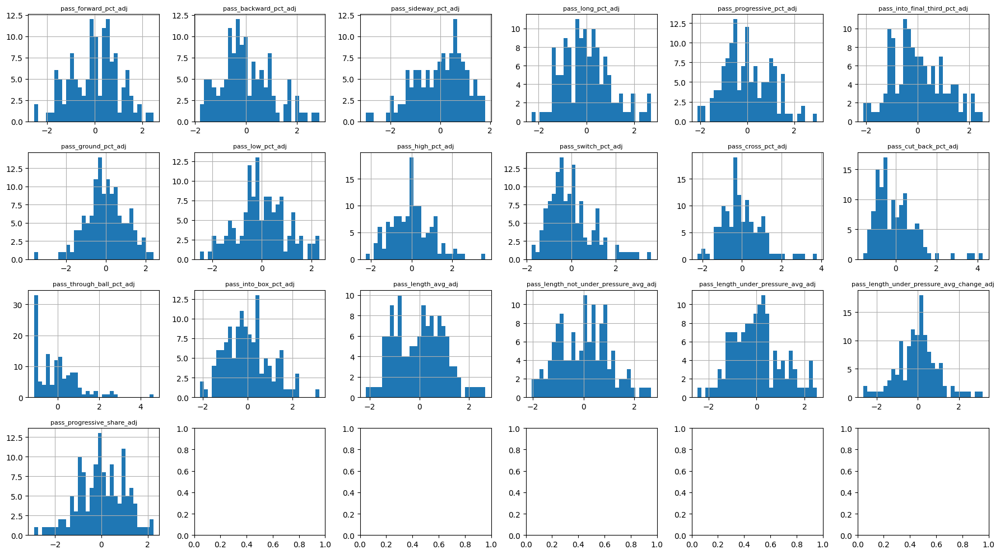

In [1253]:
# split into batches of ~24 features at a time, by conceptual block
passing_cols = [c for c in feature_cols_adj if 'pass' in c]
plot_histogram_grid(full_wing_backs_stats, passing_cols)

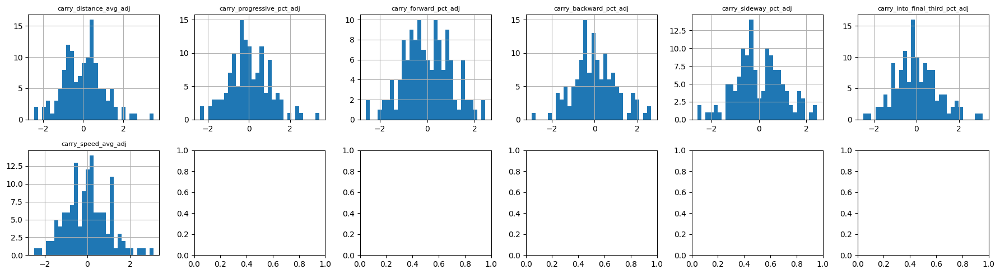

In [1254]:
# split into batches of ~24 features at a time, by conceptual block
carrying_cols = [c for c in feature_cols_adj if 'carry' in c]
plot_histogram_grid(full_wing_backs_stats, carrying_cols)

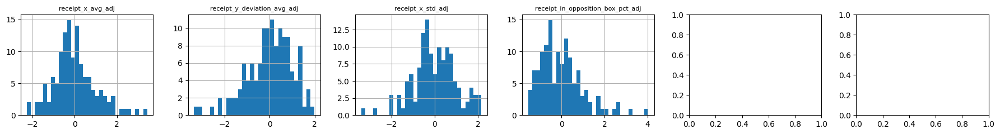

In [1255]:
# split into batches of ~24 features at a time, by conceptual block
receipt_cols = [c for c in feature_cols_adj if 'receipt' in c]
plot_histogram_grid(full_wing_backs_stats, receipt_cols)

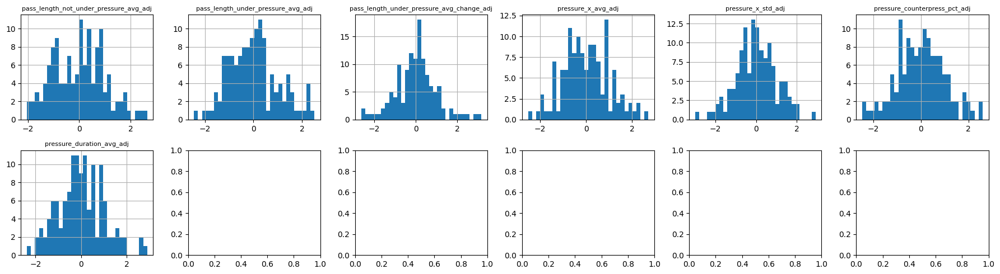

In [1256]:
# split into batches of ~24 features at a time, by conceptual block
pressure_cols = [c for c in feature_cols_adj if 'pressure' in c]
plot_histogram_grid(full_wing_backs_stats, pressure_cols)

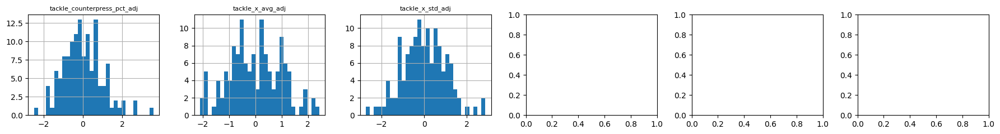

In [1257]:
# split into batches of ~24 features at a time, by conceptual block
tackle_cols = [c for c in feature_cols_adj if 'tackle' in c]
plot_histogram_grid(full_wing_backs_stats, tackle_cols)

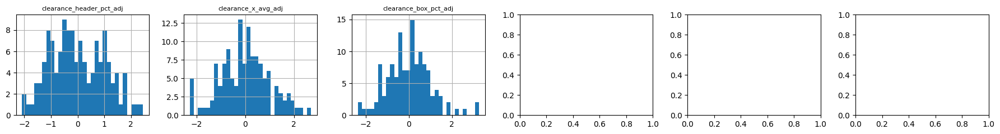

In [1258]:
# split into batches of ~24 features at a time, by conceptual block
clearance_cols = [c for c in feature_cols_adj if 'clearance' in c]
plot_histogram_grid(full_wing_backs_stats, clearance_cols)

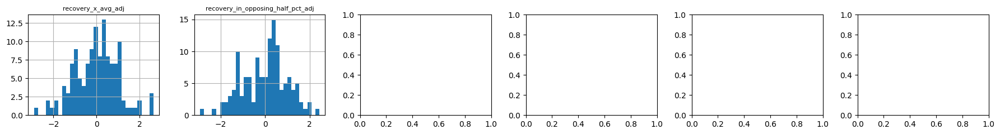

In [1259]:
# split into batches of ~24 features at a time, by conceptual block
recovery_cols = [c for c in feature_cols_adj if 'recover' in c]
plot_histogram_grid(full_wing_backs_stats, recovery_cols)

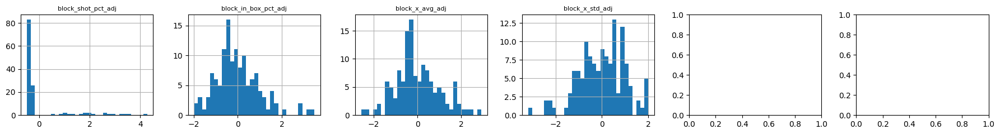

In [1260]:
# split into batches of ~24 features at a time, by conceptual block
block_cols = [c for c in feature_cols_adj if 'block' in c]
plot_histogram_grid(full_wing_backs_stats, block_cols)

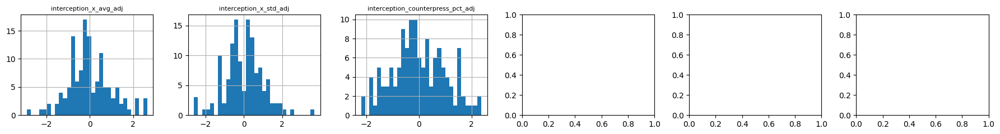

In [1261]:
# split into batches of ~24 features at a time, by conceptual block
interception_cols = [c for c in feature_cols_adj if 'intercept' in c]
plot_histogram_grid(full_wing_backs_stats, interception_cols)

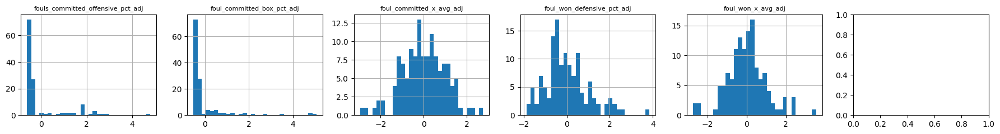

In [1262]:
# split into batches of ~24 features at a time, by conceptual block
foul_cols = [c for c in feature_cols_adj if 'foul' in c]
plot_histogram_grid(full_wing_backs_stats, foul_cols)

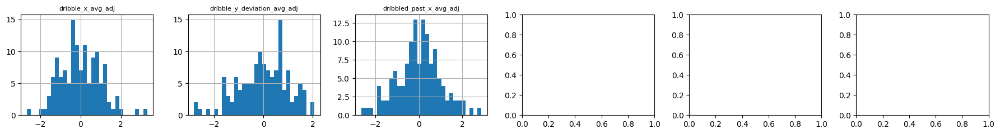

In [1263]:
# split into batches of ~24 features at a time, by conceptual block
dribbled_past_cols = [c for c in feature_cols_adj if 'dribble' in c]
plot_histogram_grid(full_wing_backs_stats, dribbled_past_cols)

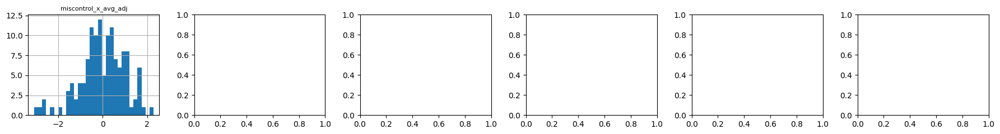

In [1264]:
# split into batches of ~24 features at a time, by conceptual block
miscontrol_cols = [c for c in feature_cols_adj if 'miscontrol' in c]
plot_histogram_grid(full_wing_backs_stats, miscontrol_cols)

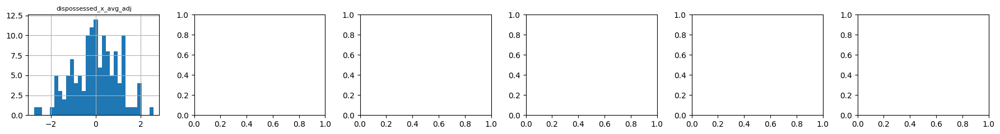

In [1265]:
# split into batches of ~24 features at a time, by conceptual block
dispossessed_cols = [c for c in feature_cols_adj if 'dispossessed' in c]
plot_histogram_grid(full_wing_backs_stats, dispossessed_cols)

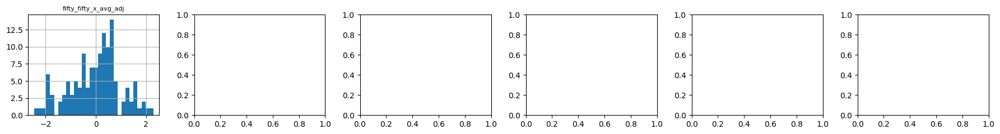

In [1266]:
# split into batches of ~24 features at a time, by conceptual block
fifty_fifty_cols = [c for c in feature_cols_adj if 'fifty_fifty' in c]
plot_histogram_grid(full_wing_backs_stats, fifty_fifty_cols)

In [1267]:
columns_to_drop_distribution = ['pass_cut_back_pct', 'pass_through_ball_pct', 'receipt_in_opposition_box_pct', 
                                'block_shot_pct', 'fouls_committed_offensive_pct', 'foul_committed_box_pct',]

In [1268]:
full_wing_backs_stats = full_wing_backs_stats.drop(columns=columns_to_drop_distribution + [c + '_adj' for c in columns_to_drop_distribution])

In [1269]:
full_wing_backs_stats.shape

(129, 117)

In [1270]:
full_wing_backs_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_cross_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'clearance_box_pct',
 'recovery_x_avg',
 'recovery_in_opposing_half_pct',
 'block_in_box_pct',
 'block_x_avg',
 'block_x_std',
 'int

In [1271]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_distribution]

In [1272]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1273]:
len(feature_cols)

57

In [1274]:
len(feature_cols_adj)

57

#### Observe correlation between variables

In [1275]:
corr_matrix = full_wing_backs_stats[feature_cols_adj].corr().abs()

In [1276]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [1277]:
high_corr_pairs = (upper.stack()
                   .reset_index()
                   .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'correlation'})
                   .sort_values('correlation', ascending=False))

In [1278]:
# Show all columns
pd.set_option('display.max_columns', None)

pd.set_option('display.max_rows', None)

In [1279]:
high_corr_pairs[high_corr_pairs['correlation'] > 0.8]

,feature_1,feature_2,correlation
697,pass_length_avg_adj,pass_length_not_under_pressure_avg_adj,0.983893
1649,pressure_x_avg_adj,defensive_actions_x_avg_adj,0.933839
2205,recovery_x_avg_adj,recovery_in_opposing_half_pct_adj,0.924412
1707,pressure_x_std_adj,defensive_actions_x_std_adj,0.918678
350,pass_ground_pct_adj,pass_high_pct_adj,0.916085
184,pass_long_pct_adj,pass_length_not_under_pressure_avg_adj,0.906374
183,pass_long_pct_adj,pass_length_avg_adj,0.901369
929,carry_distance_avg_adj,carry_progressive_pct_adj,0.900392
236,pass_progressive_pct_adj,pass_high_pct_adj,0.827365
2089,clearance_x_avg_adj,clearance_box_pct_adj,0.825001


In [1280]:
# Show all columns
pd.reset_option('display.max_columns')

pd.reset_option('display.max_rows')

In [1281]:
columns_to_drop_correlation = ['pass_length_not_under_pressure_avg', 'defensive_actions_x_avg', 'recovery_in_opposing_half_pct',
                               'defensive_actions_x_std', 'pass_high_pct', 'pass_long_pct', 'carry_distance_avg', 'clearance_box_pct',
                               'carry_sideway_pct', 'pass_sideway_pct',]

In [1282]:
full_wing_backs_stats = full_wing_backs_stats.drop(columns=columns_to_drop_correlation + [c + '_adj' for c in columns_to_drop_correlation])

In [1283]:
full_wing_backs_stats.shape

(129, 97)

In [1284]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_correlation]

In [1285]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1286]:
len(feature_cols)

47

In [1287]:
len(feature_cols_adj)

47

In [1288]:
skew_check = full_wing_backs_stats[feature_cols_adj].skew().sort_values(ascending=False)

In [1289]:
skew_check[skew_check.abs() > 1.5]

Series([], dtype: float64)

#### Final feature columns

In [1290]:
final_feature_cols = [c for c in feature_cols]

In [1291]:
final_feature_cols

['pass_forward_pct',
 'pass_backward_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_switch_pct',
 'pass_cross_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'recovery_x_avg',
 'block_in_box_pct',
 'block_x_avg',
 'block_x_std',
 'interception_x_avg',
 'interception_x_std',
 'interception_counterpress_pct',
 'foul_committed_x_avg',
 'foul_won_defensive_pct',
 'foul_won_x_avg',
 'dribbled_past_x_avg',
 'miscontrol_x_avg',
 'disp

In [1292]:
len(final_feature_cols)

47

In [1293]:
final_feature_cols_adj = [c + '_adj' for c in final_feature_cols]

In [1294]:
final_feature_cols_adj

['pass_forward_pct_adj',
 'pass_backward_pct_adj',
 'pass_progressive_pct_adj',
 'pass_into_final_third_pct_adj',
 'pass_ground_pct_adj',
 'pass_low_pct_adj',
 'pass_switch_pct_adj',
 'pass_cross_pct_adj',
 'pass_into_box_pct_adj',
 'pass_length_avg_adj',
 'pass_length_under_pressure_avg_adj',
 'pass_length_under_pressure_avg_change_adj',
 'carry_progressive_pct_adj',
 'carry_forward_pct_adj',
 'carry_backward_pct_adj',
 'carry_into_final_third_pct_adj',
 'carry_speed_avg_adj',
 'dribble_x_avg_adj',
 'dribble_y_deviation_avg_adj',
 'receipt_x_avg_adj',
 'receipt_y_deviation_avg_adj',
 'receipt_x_std_adj',
 'pressure_x_avg_adj',
 'pressure_x_std_adj',
 'pressure_counterpress_pct_adj',
 'pressure_duration_avg_adj',
 'tackle_counterpress_pct_adj',
 'tackle_x_avg_adj',
 'tackle_x_std_adj',
 'clearance_header_pct_adj',
 'clearance_x_avg_adj',
 'recovery_x_avg_adj',
 'block_in_box_pct_adj',
 'block_x_avg_adj',
 'block_x_std_adj',
 'interception_x_avg_adj',
 'interception_x_std_adj',
 'interc

In [1295]:
len(final_feature_cols_adj)

47

#### Detect outliers

In [1296]:
outliers_zscore = detect_outliers_zscore(full_wing_backs_stats, final_feature_cols, player_id_to_player, team_id_to_team)

In [1297]:
for col, rows in outliers_zscore.items():
    print(f"\n--- {col} ---")
    print(rows.sort_values('z_score', ascending=False))


--- pass_backward_pct ---
                                                   league  pass_backward_pct  \
player_id team_id position_group                                               
10163.0   746     Full/Wing Back  FA Women's Super League           0.222222   

                                  player_id  team_id   z_score  \
player_id team_id position_group                                 
10163.0   746     Full/Wing Back    10163.0      746  3.445735   

                                                    player  \
player_id team_id position_group                             
10163.0   746     Full/Wing Back  Leila Ouahabi El Ouahabi   

                                                 team  
player_id team_id position_group                       
10163.0   746     Full/Wing Back  Manchester City WFC  

--- pass_ground_pct ---
                                  league  pass_ground_pct  player_id  team_id  \
player_id team_id position_group                                        

In [1298]:
outliers_iqr = detect_outliers_iqr(full_wing_backs_stats, final_feature_cols, player_id_to_player, team_id_to_team)

In [1299]:
for col, rows in outliers_iqr.items():
    print(f"\n--- {col} ---")
    print(rows)


--- pass_forward_pct ---
                                             league  pass_forward_pct  \
player_id team_id position_group                                        
46639.0   937     Full/Wing Back             Liga F          0.117736   
32418.0   6755    Full/Wing Back      Serie A Women          0.531888   
46357.0   6755    Full/Wing Back      Serie A Women          0.528986   
64483.0   19107   Full/Wing Back  Frauen Bundesliga          0.528689   

                                  player_id  team_id              player  \
player_id team_id position_group                                           
46639.0   937     Full/Wing Back    46639.0      937  Ona Batlle Pascual   
32418.0   6755    Full/Wing Back    32418.0     6755      Martina Fusini   
46357.0   6755    Full/Wing Back    46357.0     6755    Debora Novellino   
64483.0   19107   Full/Wing Back    64483.0    19107     Frederike Kempe   

                                           team  bound_distance  
player_id te

In [1300]:
all_flagged_players_zscore = []

In [1301]:
for col, rows in outliers_zscore.items():
    all_flagged_players_zscore.extend(rows['player_id'].tolist())

In [1302]:
flag_counts_zscore = pd.Series(Counter(all_flagged_players_zscore)).sort_values(ascending=False)

In [1303]:
flag_counts_zscore

10404.0     5
46639.0     3
10163.0     2
372202.0    2
107491.0    2
135263.0    2
46357.0     2
355408.0    2
53958.0     1
32211.0     1
47015.0     1
50100.0     1
408656.0    1
46873.0     1
32210.0     1
21023.0     1
50362.0     1
99615.0     1
132033.0    1
10178.0     1
25492.0     1
10148.0     1
45894.0     1
16382.0     1
dtype: int64

In [1304]:
all_flagged_players_iqr = []

In [1305]:
for col, rows in outliers_iqr.items():
    all_flagged_players_iqr.extend(rows['player_id'].tolist())

In [1306]:
flag_counts_iqr = pd.Series(Counter(all_flagged_players_iqr)).sort_values(ascending=False)

In [1307]:
flag_counts_iqr

10404.0     11
46639.0      8
107491.0     7
355408.0     6
99615.0      5
46357.0      5
21023.0      5
64483.0      4
15620.0      4
10148.0      4
372202.0     4
408656.0     4
46873.0      4
10371.0      3
17275.0      3
32211.0      2
135263.0     2
221888.0     2
50817.0      2
10163.0      2
34500.0      2
32210.0      2
16382.0      2
50362.0      2
45894.0      2
25492.0      2
50117.0      2
32169.0      2
46225.0      2
251159.0     1
408653.0     1
46989.0      1
53995.0      1
50100.0      1
47015.0      1
32418.0      1
10213.0      1
409198.0     1
53958.0      1
24695.0      1
5000.0       1
15179.0      1
132033.0     1
309391.0     1
10390.0      1
10178.0      1
10407.0      1
142770.0     1
410500.0     1
79565.0      1
46224.0      1
10418.0      1
dtype: int64

In [1308]:
keys = ['player_id', 'team_id', 'league', 'position_group']

In [1309]:
winsorize_cols = ['pass_backward_pct_adj', 'pass_ground_pct_adj', 'pass_low_pct_adj', 'pass_switch_pct_adj', 'pass_cross_pct_adj',
                  'pass_into_box_pct_adj', 'pass_length_under_pressure_avg_adj', 'pass_length_under_pressure_avg_change_adj',
                  'carry_progressive_pct_adj', 'carry_backward_pct_adj', 'carry_into_final_third_pct_adj', 'carry_speed_avg_adj',
                  'dribble_x_avg_adj', 'dribble_y_deviation_avg_adj', 'receipt_x_avg_adj', 'receipt_y_deviation_avg_adj',
                  'receipt_x_std_adj', 'pressure_x_std_adj', 'pressure_duration_avg_adj', 'tackle_counterpress_pct_adj',
                  'tackle_x_std_adj', 'clearance_x_avg_adj', 'recovery_x_avg_adj', 'block_in_box_pct_adj', 'block_x_avg_adj', 
                  'block_x_std_adj', 'interception_x_avg_adj', 'interception_x_std_adj', 'foul_committed_x_avg_adj',
                  'foul_won_defensive_pct_adj', 'foul_won_x_avg_adj', 'dribbled_past_x_avg_adj', 'miscontrol_x_avg_adj',
                  'dispossessed_x_avg_adj', 'fifty_fifty_x_avg_adj']

In [1310]:
for col in winsorize_cols:
    full_wing_backs_stats[col] = winsorize(full_wing_backs_stats[col])

In [1311]:
imputation_configs = [  
    dict(position_group='Full/Wing Back', pct_col='dribble_x_avg_adj',
        attempted_col='dribbles_attempted', min_quantile=0.2),
    dict(position_group='Full/Wing Back', pct_col='dribble_y_deviation_avg_adj',
        attempted_col='dribbles_attempted', min_quantile=0.2),
    dict(position_group='Full/Wing Back', pct_col='pressure_x_std_adj',
        attempted_col='pressures_applied', min_quantile=0.2),
    dict(position_group='Full/Wing Back', pct_col='pressure_counterpress_pct',
        attempted_col='pressures_applied', min_quantile=0.2),
    dict(position_group='Full/Wing Back', pct_col='tackle_counterpress_pct_adj',
        attempted_col='tackles_attempted', min_quantile=0.2),
    dict(position_group='Full/Wing Back', pct_col='tackle_x_std_adj',
        attempted_col='tackles_attempted', min_quantile=0.2),
    dict(position_group='Full/Wing Back', pct_col='clearance_x_avg_adj',
        attempted_col='clearances_attempted', min_quantile=0.2),
    dict(position_group='Full/Wing Back', pct_col='recovery_x_avg_adj',
        attempted_col='recoverys_attempted', min_quantile=0.2),
    dict(position_group='Full/Wing Back', pct_col='block_in_box_pct_adj',
        attempted_col='blocks_total', min_quantile=0.2),
    dict(position_group='Full/Wing Back', pct_col='block_x_avg_adj',
        attempted_col='blocks_total', min_quantile=0.2),
    dict(position_group='Full/Wing Back', pct_col='block_x_std_adj',
        attempted_col='blocks_total', min_quantile=0.2),
    dict(position_group='Full/Wing Back', pct_col='interception_x_avg_adj',
        attempted_col='interceptions_attempted', min_quantile=0.2),    
    dict(position_group='Full/Wing Back', pct_col='interception_x_std_adj',
        attempted_col='interceptions_attempted', min_quantile=0.2),    
    dict(position_group='Full/Wing Back', pct_col='foul_committed_x_avg_adj',
        attempted_col='fouls_committed', min_quantile=0.2), 
    dict(position_group='Full/Wing Back', pct_col='foul_won_defensive_pct_adj',
        attempted_col='fouls_won', min_quantile=0.2),  
    dict(position_group='Full/Wing Back', pct_col='foul_won_x_avg',
        attempted_col='fouls_won', min_quantile=0.2),  
    dict(position_group='Full/Wing Back', pct_col='dribbled_past_x_avg_adj',
        attempted_col='dribbled_pasts', min_quantile=0.2),    
    dict(position_group='Full/Wing Back', pct_col='miscontrol_x_avg_adj',
        attempted_col='miscontrols', min_quantile=0.2),
    dict(position_group='Full/Wing Back', pct_col='dispossessed_x_avg_adj',
        attempted_col='dispossesseds', min_quantile=0.2), 
    dict(position_group='Full/Wing Back', pct_col='fifty_fifty_x_avg_adj',
        attempted_col='fifty_fiftys', min_quantile=0.2),    
]

In [1312]:
for cfg in imputation_configs:
    pos, pct_col = cfg['position_group'], cfg['pct_col']
    target_df = stats_by_position[pos]
    
    # reads eligibility/reliable-group-mean from all_players_stats (untouched, read-only),
    # writes the imputed value into target_df only
    target_df = impute_unreliable_rate_stat(all_players_stats, target_df, **cfg)

    # residualize on target_df itself, using its now-imputed raw value as input
    refit = residualize(
        target_df, feature_cols=[pct_col], covariate_col='context_score',
        group_cols=['position_group'], robust=True,
    )
    target_df[pct_col + '_adj'] = refit[pct_col + '_adj']

    stats_by_position[pos] = target_df

C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2235375163.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  target_df[pct_col + '_adj'] = refit[pct_col + '_adj']
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2235375163.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  target_df[pct_col + '_adj'] = refit[pct_col + '_adj']
C:\Users\aquan\AppData\Local\Temp\ipykernel_10456\2235375163.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has po

#### Rank features on percentile

In [1313]:
full_wing_backs_stats = to_percentile(full_wing_backs_stats, final_feature_cols)      # raw

In [1314]:
full_wing_backs_stats = to_percentile(full_wing_backs_stats, final_feature_cols_adj) # adjusted

#### Divide features into groups

In [1315]:
feature_groups = {
    'passing_share': [
        'pass_forward_pct', 'pass_backward_pct', 'pass_cross_pct', 'pass_into_box_pct', 'pass_into_final_third_pct', 
        'pass_ground_pct', 'pass_low_pct', 'pass_switch_pct', 'pass_progressive_pct', 'pass_progressive_share'
    ],
    'passing_length': [
        'pass_length_avg', 'pass_length_under_pressure_avg', 'pass_length_under_pressure_avg_change'
    ],
    'carrying': [
        'carry_progressive_pct', 'carry_forward_pct', 'carry_backward_pct', 'carry_into_final_third_pct', 'carry_speed_avg'
    ],
    'receipt': [
        'receipt_x_avg', 'receipt_y_deviation_avg', 'receipt_x_std'
    ],
    'dribbling': [
        'dribble_x_avg', 'dribble_y_deviation_avg',
    ],
    'defensive_location': [
        'pressure_x_avg', 'pressure_x_std', 'tackle_x_avg', 'tackle_x_std', 'clearance_x_avg', 'recovery_x_avg', 'block_in_box_pct', 
        'block_x_avg', 'block_x_std', 'interception_x_avg', 'interception_x_std', 'counterpress_in_opposing_half_pct',
        'foul_won_defensive_pct', 'foul_won_x_avg',
    ],
    'defensive_volume': [
        'pressure_counterpress_pct', 'pressure_duration_avg', 'tackle_counterpress_pct', 'clearance_header_pct', 'interception_counterpress_pct'
    ],
    'vulnerability_fifty_fifty': [
        'foul_committed_x_avg', 'dribbled_past_x_avg', 'miscontrol_x_avg', 'dispossessed_x_avg', 'fifty_fifty_x_avg'
    ]
}

In [1316]:
feature_groups_adj = {
    category: [f + '_adj' for f in features]
    for category, features in feature_groups.items()
}

In [1317]:
n_per_category = {
    'passing_share': 7, 'passing_length': 2, 'carrying': 3, 'receipt': 2, 'dribbling': 1, 'defensive_location': 7, 'defensive_volume': 2, 'vulnerability_fifty_fifty': 2
}

In [1318]:
all_grouped = [c for group in feature_groups.values() for c in group]

In [1319]:
missing = set(final_feature_cols) - set(all_grouped)

In [1320]:
missing

set()

In [1321]:
spare = set(all_grouped) - set(final_feature_cols)

In [1322]:
spare

set()

In [1323]:
scaled_frames = []

In [1324]:
for league, group in full_wing_backs_stats.groupby('league'):
    scaler = StandardScaler()
    scaled_values = scaler.fit_transform(group[final_feature_cols])
    scaled_df = pd.DataFrame(scaled_values, columns=final_feature_cols, index=group.index)
    scaled_df['league'] = group['league']
    scaled_frames.append(scaled_df)

In [1325]:
full_wing_backs_stats_scaled = pd.concat(scaled_frames).reindex(full_wing_backs_stats.index)

In [1326]:
full_wing_backs_stats_scaled.shape

(129, 48)

In [1327]:
full_wing_backs_stats_scaled.groupby('league')[final_feature_cols].mean().round(2)  # should be ~0 everywhere

,pass_forward_pct,pass_backward_pct,pass_progressive_pct,pass_into_final_third_pct,pass_ground_pct,pass_low_pct,pass_switch_pct,pass_cross_pct,pass_into_box_pct,pass_length_avg,...,interception_counterpress_pct,foul_committed_x_avg,foul_won_defensive_pct,foul_won_x_avg,dribbled_past_x_avg,miscontrol_x_avg,dispossessed_x_avg,fifty_fifty_x_avg,counterpress_in_opposing_half_pct,pass_progressive_share
league,,,,,,,,,,,,,,,,,,,,,
FA Women's Super League,0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,...,-0.0,0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0
Frauen Bundesliga,0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,...,0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,0.0,0.0
Liga F,0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,...,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0
Serie A Women,-0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,...,-0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0


In [1328]:
full_wing_backs_stats_scaled.groupby('league')[final_feature_cols].std().round(2)   # should be ~1 everywhere

,pass_forward_pct,pass_backward_pct,pass_progressive_pct,pass_into_final_third_pct,pass_ground_pct,pass_low_pct,pass_switch_pct,pass_cross_pct,pass_into_box_pct,pass_length_avg,...,interception_counterpress_pct,foul_committed_x_avg,foul_won_defensive_pct,foul_won_x_avg,dribbled_past_x_avg,miscontrol_x_avg,dispossessed_x_avg,fifty_fifty_x_avg,counterpress_in_opposing_half_pct,pass_progressive_share
league,,,,,,,,,,,,,,,,,,,,,
FA Women's Super League,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,...,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02
Frauen Bundesliga,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,...,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02
Liga F,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01,...,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01
Serie A Women,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,...,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02


In [1329]:
summary_raw = full_wing_backs_stats[final_feature_cols].describe().T
summary_raw

,count,mean,std,min,25%,50%,75%,max
pass_forward_pct,129.0,0.339471,0.074238,0.117736,0.288194,0.339286,0.378092,0.531888
pass_backward_pct,129.0,0.095307,0.036976,0.027855,0.068452,0.089286,0.116832,0.222222
pass_progressive_pct,129.0,0.247623,0.067901,0.111111,0.197719,0.239861,0.286778,0.402174
pass_into_final_third_pct,129.0,0.129010,0.033800,0.062642,0.106474,0.120425,0.147388,0.229508
pass_ground_pct,129.0,0.663289,0.097178,0.361878,0.590909,0.678832,0.728477,0.883013
pass_low_pct,129.0,0.125150,0.033216,0.040064,0.106007,0.123153,0.145658,0.209016
pass_switch_pct,129.0,0.012419,0.008415,0.000000,0.006369,0.010554,0.016474,0.040107
pass_cross_pct,129.0,0.046343,0.022472,0.005556,0.030181,0.043684,0.057870,0.149466
pass_into_box_pct,129.0,0.021908,0.009712,0.000000,0.015748,0.021305,0.027350,0.053381
pass_length_avg,129.0,19.355429,2.005897,13.864127,17.992278,19.120525,20.639898,24.968874


In [1330]:
summary_scaled = full_wing_backs_stats_scaled[final_feature_cols].describe().T
summary_scaled

,count,mean,std,min,25%,50%,75%,max
pass_forward_pct,129.0,-1.239319e-16,1.003899,-2.666056,-0.768187,-0.141447,0.769041,2.650346
pass_backward_pct,129.0,-1.583574e-16,1.003899,-1.759612,-0.711673,-0.076576,0.458409,3.130534
pass_progressive_pct,129.0,2.754042e-16,1.003899,-2.090344,-0.626862,-0.130852,0.640645,2.256232
pass_into_final_third_pct,129.0,-2.065531e-16,1.003899,-1.808359,-0.644403,-0.150409,0.623408,3.396340
pass_ground_pct,129.0,-9.088337e-16,1.003899,-2.921977,-0.691403,0.121325,0.808848,2.082085
pass_low_pct,129.0,-1.101617e-16,1.003899,-2.027195,-0.692271,-0.092266,0.623707,2.767513
pass_switch_pct,129.0,-1.239319e-16,1.003899,-1.598648,-0.685346,-0.206672,0.523911,3.135198
pass_cross_pct,129.0,-1.101617e-16,1.003899,-2.232222,-0.699595,-0.162787,0.481697,3.780082
pass_into_box_pct,129.0,-8.262125e-17,1.003899,-2.241074,-0.637769,-0.029337,0.574159,3.125293
pass_length_avg,129.0,4.268764e-16,1.003899,-2.571845,-0.654520,-0.082615,0.702790,2.539153


#### KMeans Clustering

##### PCA

In [1331]:
X = full_wing_backs_stats[final_feature_cols_adj]

In [1332]:
n_features = 11

In [1333]:
pca_reduced_final = PCA(n_components=n_features)

In [1334]:
pca_reduced_final.set_output(transform='pandas')

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",11
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD

In [1335]:
X_pca_final = pca_reduced_final.fit_transform(X)

##### KMeans with k = 2

In [1336]:
k = 2

In [1337]:
kmeans_2 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1338]:
full_wing_backs_stats['kmeans_2_cluster'] = kmeans_2.fit_predict(X_pca_final)  # or X, if using raw features

In [1339]:
# bring labels back to the original unstandardized data for interpretation
full_wing_backs_stats['kmeans_2_cluster'] = full_wing_backs_stats['kmeans_2_cluster'].values

In [1340]:
full_wing_backs_stats['kmeans_2_cluster'].value_counts()

kmeans_2_cluster
1    69
0    60
Name: count, dtype: int64

In [1341]:
full_wing_backs_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_2, 
    stats_df=full_wing_backs_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 3

In [1342]:
k = 3

In [1343]:
kmeans_3 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1344]:
full_wing_backs_stats['kmeans_3_cluster'] = kmeans_3.fit_predict(X_pca_final)  # or X, if using raw features

In [1345]:
# bring labels back to the original unstandardized data for interpretation
full_wing_backs_stats['kmeans_3_cluster'] = full_wing_backs_stats['kmeans_3_cluster'].values

In [1346]:
full_wing_backs_stats['kmeans_3_cluster'].value_counts()

kmeans_3_cluster
1    46
0    42
2    41
Name: count, dtype: int64

In [1347]:
full_wing_backs_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_3, 
    stats_df=full_wing_backs_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 4

In [1348]:
k = 4

In [1349]:
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

In [1350]:
full_wing_backs_stats['kmeans_4_cluster'] = kmeans_4.fit_predict(X_pca_final)  # or X, if using raw features

In [1351]:
# bring labels back to the original unstandardized data for interpretation
full_wing_backs_stats['kmeans_4_cluster'] = full_wing_backs_stats['kmeans_4_cluster'].values

In [1352]:
full_wing_backs_stats['kmeans_4_cluster'].value_counts()

kmeans_4_cluster
1    39
0    32
3    30
2    28
Name: count, dtype: int64

In [1353]:
full_wing_backs_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_4, 
    stats_df=full_wing_backs_stats,
    sigma_quantile=0.5
)

### All Center Midfields

#### Filter by position

In [1354]:
center_midfields_stats.shape

(182, 355)

In [1355]:
center_midfields_stats.columns.tolist()

['passes_attempted',
 'pass_completion_pct',
 'pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_under_pressure_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_deflected_pct',
 'pass_goal_assist_pct',
 'pass_miscommunication_pct',
 'pass_no_touch_pct',
 'pass_shot_assist_pct',
 'pass_through_ball_pct',
 'pass_create_shot_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_deep_completion_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_aerial_won_completion_pct',
 'pass_cross_completion_pct',
 'pass_cut_back_completion_pct',
 'pass_deflected_completion_pct',
 'pass_no_touch_completion_pct',
 'pass_switch_completion_pct',
 'pass_through_ball_completion_pct',
 'pass_forward_complet

In [1356]:
center_midfields_stats = center_midfields_stats[style_feature_cols + style_feature_cols_adj + ['league', 'minutes_at_position', 'pct_minutes_as_DM', 'pct_minutes_as_CM', 'pct_minutes_as_AM', 'advancement_index', 'context_score']]

In [1357]:
center_midfields_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_no_touch_pct',
 'pass_through_ball_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_o

In [1358]:
columns_to_drop_irrelevant = ['pass_no_touch_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'shot_open_play_left_foot_pct',
 'shot_open_play_right_foot_pct',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_moving_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_feet_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_sweeps_x_avg',
]

In [1359]:
center_midfields_stats = center_midfields_stats.drop(columns=columns_to_drop_irrelevant + [c + '_adj' for c in columns_to_drop_irrelevant])

In [1360]:
center_midfields_stats.shape

(182, 169)

In [1361]:
center_midfields_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_through_ball_pct',
 'pass_head_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_head_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_technique_volley_pct',
 'shot_open_play_technique_half_volley_pct',
 'shot_open_play_technique_

In [1362]:
feature_cols = [c for c in style_feature_cols if c not in columns_to_drop_irrelevant]

In [1363]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1364]:
len(feature_cols)

81

In [1365]:
len(feature_cols_adj)

81

#### Observe distribution of stats

In [1366]:
summary = center_midfields_stats[feature_cols_adj].describe().T
summary['skew'] = center_midfields_stats[feature_cols_adj].skew()
summary['pct_zero'] = (center_midfields_stats[feature_cols_adj] == 0).mean()
summary['pct_missing'] = center_midfields_stats[feature_cols_adj].isna().mean()
summary.sort_values('skew', ascending=False)

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing
shot_open_play_technique_backheel_pct_adj,182.0,0.000000e+00,1.002759,-0.269264,-0.269264,-0.154303,-0.152422,6.706547,5.268526,0.0,0.0
block_shot_pct_adj,182.0,-1.982541e-18,1.002759,-0.311223,-0.300312,-0.178998,-0.149071,6.763190,4.894634,0.0,0.0
shot_open_play_technique_overhead_kick_pct_adj,182.0,1.878839e-16,1.002759,-2.279667,-0.309165,-0.248768,-0.189774,5.742188,3.296305,0.0,0.0
foul_won_box_pct_adj,182.0,4.880101e-17,1.002759,-2.279667,-0.364544,-0.256347,-0.242109,5.856945,3.160867,0.0,0.0
foul_committed_box_pct_adj,182.0,-9.760202e-18,1.002759,-0.508847,-0.377769,-0.363968,-0.213201,4.690416,3.016951,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
pass_ground_pct_adj,182.0,2.440051e-17,1.002759,-2.945095,-0.575865,0.080578,0.614274,2.436286,-0.286050,0.0,0.0
block_x_std_adj,182.0,2.989062e-17,1.002759,-3.475189,-0.574493,0.078899,0.638336,2.526531,-0.306909,0.0,0.0
miscontrol_x_avg_adj,182.0,-2.928061e-17,1.002759,-3.474318,-0.591397,0.136462,0.749427,2.420457,-0.570655,0.0,0.0
pass_progressive_share_adj,182.0,4.880101e-18,1.002759,-3.596893,-0.540409,0.053991,0.798115,1.905976,-0.604432,0.0,0.0


In [1367]:
summary.shape

(81, 11)

In [1368]:
low_variance = summary[summary['std'] / summary['mean'].abs() < 0.1]

In [1369]:
low_variance

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing


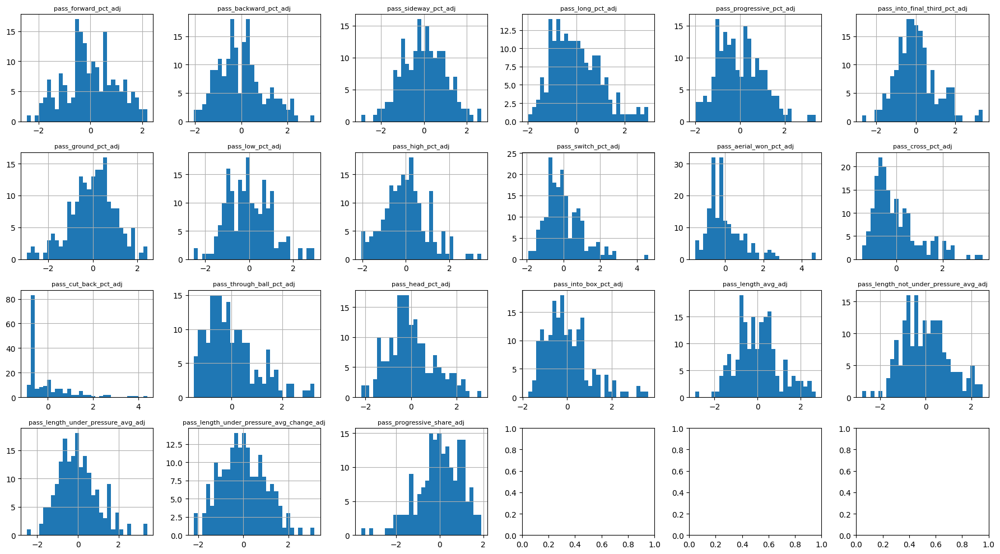

In [1370]:
# split into batches of ~24 features at a time, by conceptual block
passing_cols = [c for c in feature_cols_adj if 'pass' in c]
plot_histogram_grid(center_midfields_stats, passing_cols)

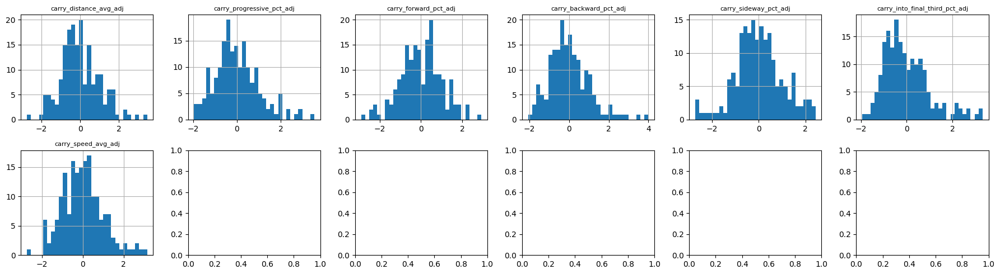

In [1371]:
# split into batches of ~24 features at a time, by conceptual block
carrying_cols = [c for c in feature_cols_adj if 'carry' in c]
plot_histogram_grid(center_midfields_stats, carrying_cols)

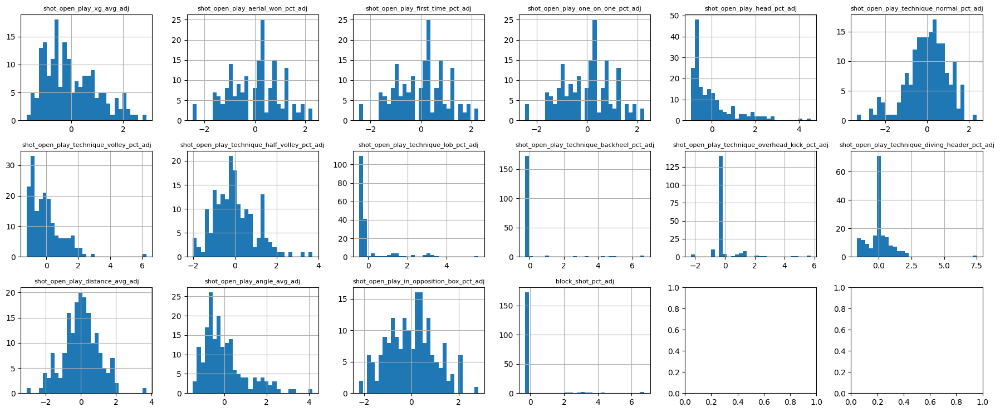

In [1372]:
# split into batches of ~24 features at a time, by conceptual block
shooting_cols = [c for c in feature_cols_adj if 'shot' in c]
plot_histogram_grid(center_midfields_stats, shooting_cols)

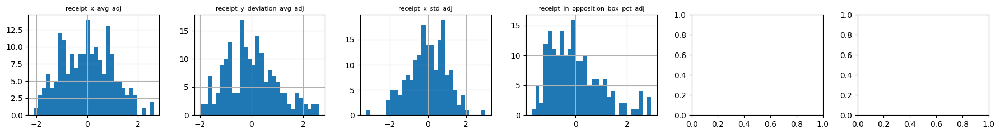

In [1373]:
# split into batches of ~24 features at a time, by conceptual block
receipt_cols = [c for c in feature_cols_adj if 'receipt' in c]
plot_histogram_grid(center_midfields_stats, receipt_cols)

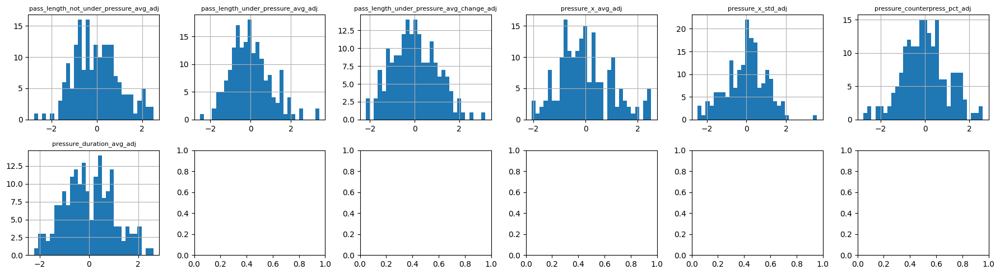

In [1374]:
# split into batches of ~24 features at a time, by conceptual block
pressure_cols = [c for c in feature_cols_adj if 'pressure' in c]
plot_histogram_grid(center_midfields_stats, pressure_cols)

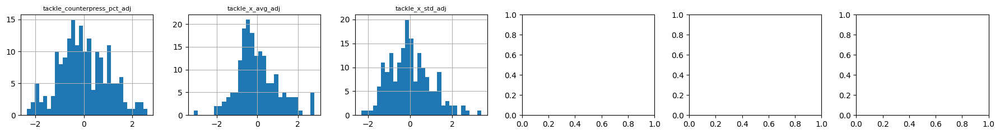

In [1375]:
# split into batches of ~24 features at a time, by conceptual block
tackle_cols = [c for c in feature_cols_adj if 'tackle' in c]
plot_histogram_grid(center_midfields_stats, tackle_cols)

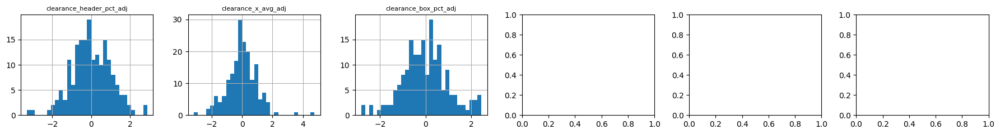

In [1376]:
# split into batches of ~24 features at a time, by conceptual block
clearance_cols = [c for c in feature_cols_adj if 'clearance' in c]
plot_histogram_grid(center_midfields_stats, clearance_cols)

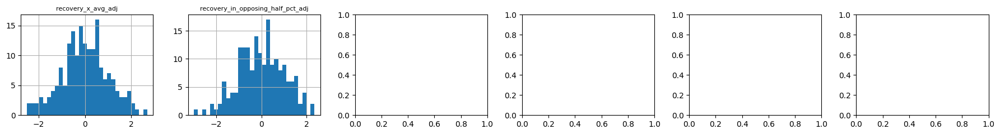

In [1377]:
# split into batches of ~24 features at a time, by conceptual block
recovery_cols = [c for c in feature_cols_adj if 'recover' in c]
plot_histogram_grid(center_midfields_stats, recovery_cols)

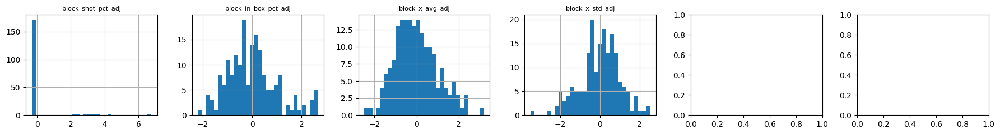

In [1378]:
# split into batches of ~24 features at a time, by conceptual block
block_cols = [c for c in feature_cols_adj if 'block' in c]
plot_histogram_grid(center_midfields_stats, block_cols)

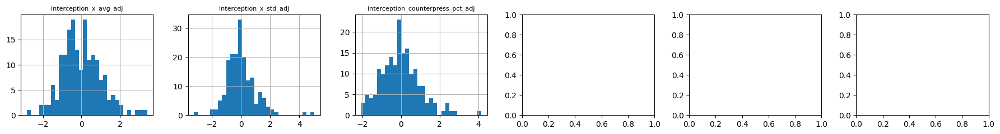

In [1379]:
# split into batches of ~24 features at a time, by conceptual block
interception_cols = [c for c in feature_cols_adj if 'intercept' in c]
plot_histogram_grid(center_midfields_stats, interception_cols)

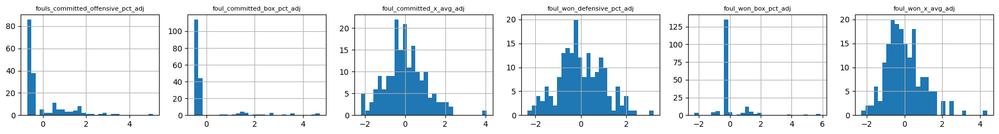

In [1380]:
# split into batches of ~24 features at a time, by conceptual block
foul_cols = [c for c in feature_cols_adj if 'foul' in c]
plot_histogram_grid(center_midfields_stats, foul_cols)

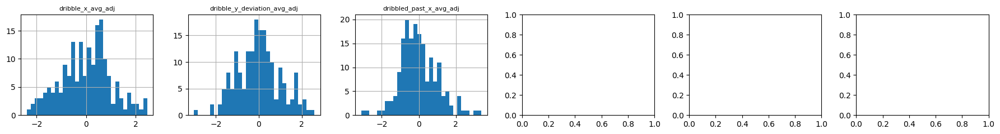

In [1381]:
# split into batches of ~24 features at a time, by conceptual block
dribble_cols = [c for c in feature_cols_adj if 'dribble' in c]
plot_histogram_grid(center_midfields_stats, dribble_cols)

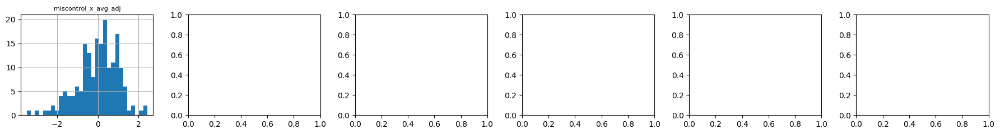

In [1382]:
# split into batches of ~24 features at a time, by conceptual block
miscontrol_cols = [c for c in feature_cols_adj if 'miscontrol' in c]
plot_histogram_grid(center_midfields_stats, miscontrol_cols)

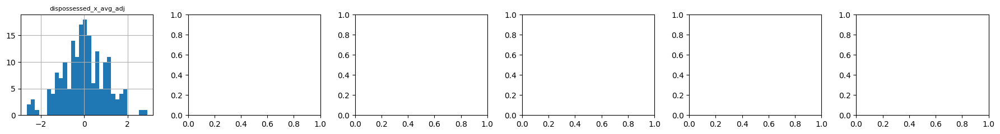

In [1383]:
# split into batches of ~24 features at a time, by conceptual block
dispossessed_cols = [c for c in feature_cols_adj if 'dispossessed' in c]
plot_histogram_grid(center_midfields_stats, dispossessed_cols)

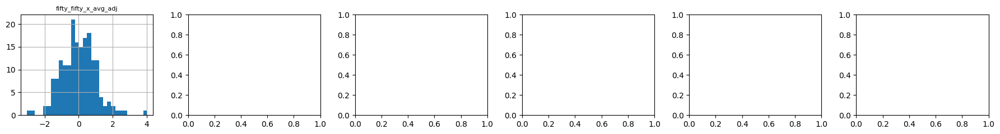

In [1384]:
# split into batches of ~24 features at a time, by conceptual block
fifty_fifty_cols = [c for c in feature_cols_adj if 'fifty_fifty' in c]
plot_histogram_grid(center_midfields_stats, fifty_fifty_cols)

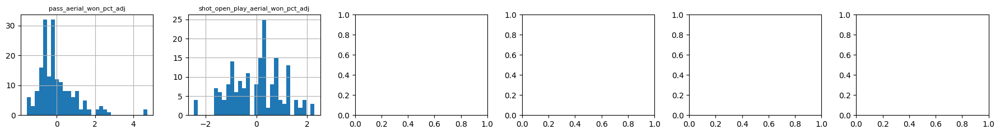

In [1385]:
# split into batches of ~24 features at a time, by conceptual block
aerial_cols = [c for c in feature_cols_adj if 'aerial' in c]
plot_histogram_grid(center_midfields_stats, aerial_cols)

In [1386]:
columns_to_drop_distribution = ['pass_aerial_won_pct', 'pass_cross_pct', 'pass_cut_back_pct', 'shot_open_play_head_pct', 'shot_open_play_technique_volley_pct',
                                'shot_open_play_technique_half_volley_pct', 'shot_open_play_technique_lob_pct', 'shot_open_play_technique_backheel_pct',
                                'shot_open_play_technique_overhead_kick_pct', 'shot_open_play_technique_diving_header_pct',
                                'block_shot_pct', 'fouls_committed_offensive_pct', 'foul_committed_box_pct', 'foul_won_box_pct',]

In [1387]:
center_midfields_stats = center_midfields_stats.drop(columns=columns_to_drop_distribution + [c + '_adj' for c in columns_to_drop_distribution])

In [1388]:
center_midfields_stats.shape

(182, 141)

In [1389]:
center_midfields_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_through_ball_pct',
 'pass_head_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_distance_avg',
 'shot_open_play_angle_avg',
 'shot_open_play_in_opposition_box_pct',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'receipt_in_opposition_box_pct',
 'pre

In [1390]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_distribution]

In [1391]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1392]:
len(feature_cols)

67

In [1393]:
len(feature_cols_adj)

67

#### Observe correlation between variables

In [1394]:
corr_matrix = center_midfields_stats[feature_cols_adj].corr().abs()

In [1395]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [1396]:
high_corr_pairs = (upper.stack()
                   .reset_index()
                   .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'correlation'})
                   .sort_values('correlation', ascending=False))

In [1397]:
# Show all columns
pd.set_option('display.max_columns', None)

pd.set_option('display.max_rows', None)

In [1398]:
high_corr_pairs[high_corr_pairs['correlation'] > 0.8]

,feature_1,feature_2,correlation
1905,shot_open_play_first_time_pct_adj,shot_open_play_one_on_one_pct_adj,1.000000
1837,shot_open_play_aerial_won_pct_adj,shot_open_play_first_time_pct_adj,1.000000
1838,shot_open_play_aerial_won_pct_adj,shot_open_play_one_on_one_pct_adj,1.000000
2609,pressure_x_avg_adj,defensive_actions_x_avg_adj,0.981803
885,pass_length_avg_adj,pass_length_not_under_pressure_avg_adj,0.979201
2677,pressure_x_std_adj,defensive_actions_x_std_adj,0.936808
3265,recovery_x_avg_adj,recovery_in_opposing_half_pct_adj,0.910158
2110,shot_open_play_distance_avg_adj,shot_open_play_in_opposition_box_pct_adj,0.902802
215,pass_long_pct_adj,pass_length_not_under_pressure_avg_adj,0.896140
410,pass_ground_pct_adj,pass_high_pct_adj,0.886431


In [1399]:
# Show all columns
pd.reset_option('display.max_columns')

pd.reset_option('display.max_rows')

In [1400]:
columns_to_drop_correlation = ['shot_open_play_first_time_pct', 'shot_open_play_one_on_one_pct', 'shot_open_play_aerial_won_pct',
                               'defensive_actions_x_avg', 'pass_length_not_under_pressure_avg', 'defensive_actions_x_std',
                               'recovery_in_opposing_half_pct', 'shot_open_play_in_opposition_box_pct', 'pass_high_pct',
                               'shot_open_play_angle_avg', 'pass_long_pct', 'counterpress_in_opposing_half_pct', 'carry_progressive_pct',
                               'pass_sideway_pct', 'carry_sideway_pct']

In [1401]:
center_midfields_stats = center_midfields_stats.drop(columns=columns_to_drop_correlation + [c + '_adj' for c in columns_to_drop_correlation])

In [1402]:
center_midfields_stats.shape

(182, 111)

In [1403]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_correlation]

In [1404]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1405]:
len(feature_cols)

52

In [1406]:
len(feature_cols_adj)

52

In [1407]:
skew_check = center_midfields_stats[feature_cols_adj].skew().sort_values(ascending=False)

In [1408]:
skew_check[skew_check.abs() > 1.5]

Series([], dtype: float64)

#### Final feature columns

In [1409]:
final_feature_cols = [c for c in feature_cols]

In [1410]:
final_feature_cols

['pass_forward_pct',
 'pass_backward_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_switch_pct',
 'pass_through_ball_pct',
 'pass_head_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_distance_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'receipt_in_opposition_box_pct',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'clearance_box_pct',
 'recovery_x_avg',
 'block_in_box_pct',
 'block_x_avg',
 'block_x_std',
 'interception_x_avg',
 'i

In [1411]:
len(final_feature_cols)

52

In [1412]:
final_feature_cols_adj = [c + '_adj' for c in final_feature_cols]

In [1413]:
final_feature_cols_adj

['pass_forward_pct_adj',
 'pass_backward_pct_adj',
 'pass_progressive_pct_adj',
 'pass_into_final_third_pct_adj',
 'pass_ground_pct_adj',
 'pass_low_pct_adj',
 'pass_switch_pct_adj',
 'pass_through_ball_pct_adj',
 'pass_head_pct_adj',
 'pass_into_box_pct_adj',
 'pass_length_avg_adj',
 'pass_length_under_pressure_avg_adj',
 'pass_length_under_pressure_avg_change_adj',
 'carry_distance_avg_adj',
 'carry_forward_pct_adj',
 'carry_backward_pct_adj',
 'carry_into_final_third_pct_adj',
 'carry_speed_avg_adj',
 'dribble_x_avg_adj',
 'dribble_y_deviation_avg_adj',
 'shot_open_play_xg_avg_adj',
 'shot_open_play_technique_normal_pct_adj',
 'shot_open_play_distance_avg_adj',
 'receipt_x_avg_adj',
 'receipt_y_deviation_avg_adj',
 'receipt_x_std_adj',
 'receipt_in_opposition_box_pct_adj',
 'pressure_x_avg_adj',
 'pressure_x_std_adj',
 'pressure_counterpress_pct_adj',
 'pressure_duration_avg_adj',
 'tackle_counterpress_pct_adj',
 'tackle_x_avg_adj',
 'tackle_x_std_adj',
 'clearance_header_pct_adj',


In [1414]:
len(final_feature_cols_adj)

52

#### Detect outliers

In [1415]:
outliers_zscore = detect_outliers_zscore(center_midfields_stats, final_feature_cols, player_id_to_player, team_id_to_team)

In [1416]:
for col, rows in outliers_zscore.items():
    print(f"\n--- {col} ---")
    print(rows.sort_values('z_score', ascending=False))


--- pass_backward_pct ---
                                                    league  pass_backward_pct  \
player_id team_id position_group                                                
19498.0   746     Center Midfield  FA Women's Super League           0.235294   

                                   player_id  team_id   z_score        player  \
player_id team_id position_group                                                
19498.0   746     Center Midfield    19498.0      746  3.078092  Jessica Park   

                                                  team  
player_id team_id position_group                        
19498.0   746     Center Midfield  Manchester City WFC  

--- pass_progressive_pct ---
                                          league  pass_progressive_pct  \
player_id team_id position_group                                         
10228.0   3152    Center Midfield  Serie A Women              0.340788   

                                   player_id  team_id   z_sco

In [1417]:
outliers_iqr = detect_outliers_iqr(center_midfields_stats, final_feature_cols, player_id_to_player, team_id_to_team)

In [1418]:
for col, rows in outliers_iqr.items():
    print(f"\n--- {col} ---")
    print(rows)


--- pass_backward_pct ---
                                                    league  pass_backward_pct  \
player_id team_id position_group                                                
19498.0   746     Center Midfield  FA Women's Super League           0.235294   
10650.0   746     Center Midfield  FA Women's Super League           0.225000   
47022.0   3170    Center Midfield        Frauen Bundesliga           0.221667   

                                   player_id  team_id          player  \
player_id team_id position_group                                        
19498.0   746     Center Midfield    19498.0      746    Jessica Park   
10650.0   746     Center Midfield    10650.0      746      Jill Roord   
47022.0   3170    Center Midfield    47022.0     3170  Laura Freigang   

                                                    team  bound_distance  
player_id team_id position_group                                          
19498.0   746     Center Midfield    Manchester Cit

                                          league  shot_open_play_xg_avg  \
player_id team_id position_group                                          
10259.0   3144    Center Midfield  Serie A Women               0.190647   

                                   player_id  team_id       player  \
player_id team_id position_group                                     
10259.0   3144    Center Midfield    10259.0     3144  Lina Magull   

                                                         team  bound_distance  
player_id team_id position_group                                               
10259.0   3144    Center Midfield  FC Internazionale Milano W        0.013917  

--- shot_open_play_technique_normal_pct ---
                                                    league  \
player_id team_id position_group                             
50017.0   3269    Center Midfield                   Liga F   
49943.0   6604    Center Midfield                   Liga F   
85004.0   965     Center Midfi

In [1419]:
all_flagged_players_zscore = []

In [1420]:
for col, rows in outliers_zscore.items():
    all_flagged_players_zscore.extend(rows['player_id'].tolist())

In [1421]:
flag_counts_zscore = pd.Series(Counter(all_flagged_players_zscore)).sort_values(ascending=False)

In [1422]:
flag_counts_zscore

19498.0     4
10228.0     4
15284.0     4
10516.0     4
31551.0     2
85004.0     2
135780.0    2
4660.0      2
4638.0      2
63308.0     2
50998.0     2
47017.0     2
46986.0     2
26520.0     1
89009.0     1
46740.0     1
50358.0     1
409119.0    1
15227.0     1
408715.0    1
325074.0    1
4658.0      1
10259.0     1
46561.0     1
408964.0    1
408967.0    1
10374.0     1
33675.0     1
321540.0    1
47022.0     1
15562.0     1
50017.0     1
408969.0    1
34498.0     1
142949.0    1
10139.0     1
10192.0     1
25466.0     1
10154.0     1
10167.0     1
224822.0    1
46891.0     1
63625.0     1
46881.0     1
dtype: int64

In [1423]:
all_flagged_players_iqr = []

In [1424]:
for col, rows in outliers_iqr.items():
    all_flagged_players_iqr.extend(rows['player_id'].tolist())

In [1425]:
flag_counts_iqr = pd.Series(Counter(all_flagged_players_iqr)).sort_values(ascending=False)

In [1426]:
flag_counts_iqr

15284.0     13
10516.0      7
19498.0      7
15227.0      5
34498.0      5
            ..
46999.0      1
386105.0     1
229194.0     1
317044.0     1
46881.0      1
Length: 83, dtype: int64

In [1427]:
keys = ['player_id', 'team_id', 'league', 'position_group']

In [1428]:
winsorize_cols = ['pass_forward_pct_adj', 'pass_backward_pct_adj', 'pass_progressive_pct_adj', 'pass_into_final_third_pct_adj',
                  'pass_ground_pct_adj', 'pass_low_pct_adj', 'pass_switch_pct_adj', 'pass_through_ball_pct_adj', 
                  'pass_head_pct_adj', 'pass_into_box_pct_adj', 'pass_length_avg_adj', 'pass_length_under_pressure_avg_adj',
                  'pass_length_under_pressure_avg_change_adj', 'carry_distance_avg_adj', 'carry_forward_pct_adj', 
                  'carry_backward_pct_adj', 'carry_into_final_third_pct_adj', 'carry_speed_avg_adj', 'dribble_y_deviation_avg_adj',
                  'shot_open_play_xg_avg_adj', 'shot_open_play_technique_normal_pct_adj', 'shot_open_play_distance_avg_adj',
                  'receipt_x_std_adj', 'receipt_in_opposition_box_pct_adj', 'pressure_x_avg_adj', 'pressure_x_std_adj',
                  'pressure_counterpress_pct_adj', 'tackle_x_avg_adj', 'tackle_x_std_adj', 'clearance_header_pct_adj',
                  'clearance_x_avg_adj', 'clearance_box_pct_adj', 'recovery_x_avg_adj', 'block_in_box_pct_adj',
                  'block_x_avg_adj', 'block_x_std_adj', 'interception_x_avg_adj', 'interception_x_std_adj',
                  'interception_counterpress_pct_adj', 'foul_committed_x_avg_adj', 'foul_won_defensive_pct_adj',
                  'foul_won_x_avg_adj', 'dribbled_past_x_avg_adj', 'miscontrol_x_avg_adj', 'dispossessed_x_avg_adj',
                  'fifty_fifty_x_avg_adj', 'pass_progressive_share_adj']

In [1429]:
for col in winsorize_cols:
    center_midfields_stats[col] = winsorize(center_midfields_stats[col])

In [1430]:
imputation_configs = [
    dict(position_group='Center Midfield', pct_col='dribble_y_deviation_avg',
        attempted_col='dribbles_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='shot_open_play_xg_avg',
        attempted_col='shots_open_play_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='shot_open_play_distance_avg',
        attempted_col='shots_open_play_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='clearance_x_avg',
        attempted_col='clearances_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='recovery_x_avg',
        attempted_col='recoverys_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='block_x_avg',
        attempted_col='blocks_total', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='block_x_std',
        attempted_col='blocks_total', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='interception_x_avg',
        attempted_col='interceptions_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='interception_x_std',
        attempted_col='interceptions_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='foul_committed_x_avg',
        attempted_col='fouls_committed', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='foul_won_x_avg',
        attempted_col='fouls_won', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='dribbled_past_x_avg',
        attempted_col='dribbled_pasts', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='miscontrol_x_avg',
        attempted_col='miscontrols', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='dispossessed_x_avg',
        attempted_col='dispossesseds', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='fifty_fifty_x_avg',
        attempted_col='fifty_fiftys', min_quantile=0.2),
]

In [1431]:
for cfg in imputation_configs:
    pos, pct_col = cfg['position_group'], cfg['pct_col']
    target_df = stats_by_position[pos]
    
    # reads eligibility/reliable-group-mean from all_players_stats (untouched, read-only),
    # writes the imputed value into target_df only
    target_df = impute_unreliable_rate_stat(all_players_stats, target_df, **cfg)

    # residualize on target_df itself, using its now-imputed raw value as input
    refit = residualize(
        target_df, feature_cols=[pct_col], covariate_col='context_score',
        group_cols=['position_group'], robust=True,
    )
    target_df[pct_col + '_adj'] = refit[pct_col + '_adj']

    stats_by_position[pos] = target_df

#### Rank features on percentile

In [1432]:
center_midfields_stats = to_percentile(center_midfields_stats, final_feature_cols)      # raw

In [1433]:
center_midfields_stats = to_percentile(center_midfields_stats, final_feature_cols_adj) # adjusted

#### Divide features into groups

In [1434]:
feature_groups = {
    'passing_share': [
        'pass_forward_pct', 'pass_backward_pct', 'pass_into_box_pct', 'pass_into_final_third_pct', 'pass_ground_pct', 
        'pass_low_pct', 'pass_switch_pct', 'pass_progressive_pct', 'pass_head_pct', 'pass_through_ball_pct', 'pass_progressive_share'
    ],
    'passing_length': [
        'pass_length_avg', 'pass_length_under_pressure_avg', 'pass_length_under_pressure_avg_change'
    ],
    'carrying': [
        'carry_distance_avg', 'carry_forward_pct', 'carry_backward_pct', 'carry_into_final_third_pct', 'carry_speed_avg'
    ],
    'receipt': [
        'receipt_x_avg', 'receipt_y_deviation_avg', 'receipt_x_std', 'receipt_in_opposition_box_pct'
    ],
    'dribbling': [
        'dribble_x_avg', 'dribble_y_deviation_avg',
    ],
    'shooting': [
        'shot_open_play_distance_avg', 'shot_open_play_technique_normal_pct', 'shot_open_play_xg_avg'
    ],
    'defensive_location': [
        'pressure_x_avg', 'pressure_x_std', 'tackle_x_avg', 'tackle_x_std', 'clearance_x_avg', 'clearance_box_pct', 'recovery_x_avg', 'block_in_box_pct', 
        'block_x_avg', 'block_x_std', 'interception_x_avg', 'interception_x_std', 'foul_won_defensive_pct', 'foul_won_x_avg',
    ],
    'defensive_volume': [
        'pressure_counterpress_pct', 'pressure_duration_avg', 'tackle_counterpress_pct', 'clearance_header_pct', 'interception_counterpress_pct'
    ],
    'vulnerability_fifty_fifty': [
        'foul_committed_x_avg', 'dribbled_past_x_avg', 'miscontrol_x_avg', 'dispossessed_x_avg', 'fifty_fifty_x_avg'
    ]
}

In [1435]:
feature_groups_adj = {
    category: [f + '_adj' for f in features]
    for category, features in feature_groups.items()
}

In [1436]:
n_per_category = {
    'passing_share': 8, 'passing_length': 2, 'carrying': 3, 'receipt': 3, 'dribbling': 1, 'shooting': 2, 'defensive_location': 7, 'defensive_volume': 3, 'vulnerability_fifty_fifty': 2
}

In [1437]:
all_grouped = [c for group in feature_groups.values() for c in group]

In [1438]:
missing = set(final_feature_cols) - set(all_grouped)

In [1439]:
missing

set()

In [1440]:
spare = set(all_grouped) - set(final_feature_cols)

In [1441]:
spare

set()

#### KMeans Clustering

##### PCA

In [1442]:
X = center_midfields_stats[final_feature_cols_adj]

In [1443]:
n_features = 12

In [1444]:
pca_reduced_final = PCA(n_components=n_features)

In [1445]:
pca_reduced_final.set_output(transform='pandas')

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",12
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD

In [1446]:
X_pca_final = pca_reduced_final.fit_transform(X)

##### KMeans with k = 2

In [1447]:
k = 2

In [1448]:
kmeans_2 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1449]:
center_midfields_stats['kmeans_2_cluster'] = kmeans_2.fit_predict(X_pca_final)  # or X, if using raw features

In [1450]:
# bring labels back to the original unstandardized data for interpretation
center_midfields_stats['kmeans_2_cluster'] = center_midfields_stats['kmeans_2_cluster'].values

In [1451]:
center_midfields_stats['kmeans_2_cluster'].value_counts()

kmeans_2_cluster
0    101
1     81
Name: count, dtype: int64

In [1452]:
center_midfields_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_2, 
    stats_df=center_midfields_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 3

In [1453]:
k = 3

In [1454]:
kmeans_3 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1455]:
center_midfields_stats['kmeans_3_cluster'] = kmeans_3.fit_predict(X_pca_final)  # or X, if using raw features

In [1456]:
# bring labels back to the original unstandardized data for interpretation
center_midfields_stats['kmeans_3_cluster'] = center_midfields_stats['kmeans_3_cluster'].values

In [1457]:
center_midfields_stats['kmeans_3_cluster'].value_counts()

kmeans_3_cluster
2    83
1    56
0    43
Name: count, dtype: int64

In [1458]:
center_midfields_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_3, 
    stats_df=center_midfields_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 4

In [1459]:
k = 4

In [1460]:
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

In [1461]:
center_midfields_stats['kmeans_4_cluster'] = kmeans_4.fit_predict(X_pca_final)  # or X, if using raw features

In [1462]:
# bring labels back to the original unstandardized data for interpretation
center_midfields_stats['kmeans_4_cluster'] = center_midfields_stats['kmeans_4_cluster'].values

In [1463]:
center_midfields_stats['kmeans_4_cluster'].value_counts()

kmeans_4_cluster
1    50
3    50
2    46
0    36
Name: count, dtype: int64

In [1464]:
center_midfields_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_4, 
    stats_df=center_midfields_stats,
    sigma_quantile=0.5
)

#### Divide all center midfields to subroles

In [1465]:
cm_index = center_midfields_stats.index

In [1466]:
center_midfields_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_switch_pct',
 'pass_through_ball_pct',
 'pass_head_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_distance_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'receipt_in_opposition_box_pct',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'clearance_box_pct',
 'recovery_x_avg',
 'block_in_box_pct',
 'block_x_avg',
 'block_x_std',
 'interception_x_avg',
 'i

In [1467]:
all_players_stats_cm = all_players_stats.loc[cm_index].join(
    center_midfields_stats['kmeans_3_cluster']
)

In [1468]:
for cluster_id, label in [(0, 'center'), (1, 'defensive'), (2, 'attacking')]:
    sub_df = all_players_stats_cm[all_players_stats_cm["kmeans_3_cluster"] == cluster_id]
    refit = residualize(
        sub_df, feature_cols=style_feature_cols, covariate_col="context_score",
        group_cols=["kmeans_3_cluster"], robust=True,
    )
    diff = (refit[[f + "_adj" for f in style_feature_cols]] - sub_df[[f + "_adj" for f in style_feature_cols]]).abs()
    r_before = pc1_context_correlation(sub_df, [f + "_adj" for f in style_feature_cols], "context_score")
    r_after = pc1_context_correlation(refit, [f + "_adj" for f in style_feature_cols], "context_score")
    print(label, "residual PC1-context correlation before:", r_before)
    print(label, "residual PC1-context correlation after:", r_after)
    print(label, "mean |change| across all _adj columns:", diff.values.mean())

center residual PC1-context correlation before: 0.5667203611751305
center residual PC1-context correlation after: 0.03270791760210144
center mean |change| across all _adj columns: 0.5100508877016036
defensive residual PC1-context correlation before: 0.06017884432836811
defensive residual PC1-context correlation after: 0.05949136218872177
defensive mean |change| across all _adj columns: 0.34202568041713527
attacking residual PC1-context correlation before: -0.07223451034971866
attacking residual PC1-context correlation after: 0.04440108648367941
attacking mean |change| across all _adj columns: 0.36038309030739746


In [1469]:
# attach to your central-midfield player-level df
all_players_stats_cm = all_players_stats_cm.merge(
    subgroup_minutes_wide, left_index=True, right_index=True, how='left'
)

In [1470]:
all_players_stats_cm = build_subcluster_adj(
    all_players_stats_cm,
    cluster_col='kmeans_3_cluster',
    feature_cols=style_feature_cols,
    covariate_col='context_score',
    clusters_to_refit=[0],  # "attacking" -- the one that failed the diagnostic
)

e:\GitHub\Women-Teams-Europe-2324-Analysis\code\functions_analysis.py:1909: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[sub_idx, feat + "_subcluster_adj"] = refit[feat + "_adj"]


In [1471]:
center_midfields_defensive_stats = all_players_stats_cm[all_players_stats_cm['kmeans_3_cluster'] == 2]

In [1472]:
center_midfields_center_stats = all_players_stats_cm[all_players_stats_cm['kmeans_3_cluster'] == 1]

In [1473]:
center_midfields_attack_stats = all_players_stats_cm[all_players_stats_cm['kmeans_3_cluster'] == 0]

In [1474]:
style_feature_cols_subcluster_adj = [f + '_subcluster_adj' for f in style_feature_cols]

### Center Midfields Defensive

#### Filter by position

In [1475]:
center_midfields_defensive_stats.shape

(83, 454)

In [1476]:
center_midfields_defensive_stats.columns.tolist()

['passes_attempted',
 'pass_completion_pct',
 'pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_under_pressure_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_deflected_pct',
 'pass_goal_assist_pct',
 'pass_miscommunication_pct',
 'pass_no_touch_pct',
 'pass_shot_assist_pct',
 'pass_through_ball_pct',
 'pass_create_shot_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_deep_completion_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_aerial_won_completion_pct',
 'pass_cross_completion_pct',
 'pass_cut_back_completion_pct',
 'pass_deflected_completion_pct',
 'pass_no_touch_completion_pct',
 'pass_switch_completion_pct',
 'pass_through_ball_completion_pct',
 'pass_forward_complet

In [1477]:
center_midfields_defensive_stats = center_midfields_defensive_stats[style_feature_cols + style_feature_cols_subcluster_adj + ['league', 'pct_minutes_as_DM', 'pct_minutes_as_CM', 'pct_minutes_as_AM', 'advancement_index', 'context_score']]

In [1478]:
center_midfields_defensive_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_no_touch_pct',
 'pass_through_ball_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_o

In [1479]:
columns_to_drop_irrelevant = ['pass_no_touch_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_left_foot_pct',
 'shot_open_play_right_foot_pct',
 'shot_open_play_head_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_technique_volley_pct',
 'shot_open_play_technique_half_volley_pct',
 'shot_open_play_technique_lob_pct',
 'shot_open_play_technique_backheel_pct',
 'shot_open_play_technique_overhead_kick_pct',
 'shot_open_play_technique_diving_header_pct',
 'shot_open_play_distance_avg',
 'shot_open_play_angle_avg',
 'shot_open_play_in_opposition_box_pct',
 'receipt_in_opposition_box_pct',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_moving_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_feet_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_sweeps_x_avg',
]

In [1480]:
center_midfields_defensive_stats = center_midfields_defensive_stats.drop(columns=columns_to_drop_irrelevant + [c + '_subcluster_adj' for c in columns_to_drop_irrelevant])

In [1481]:
center_midfields_defensive_stats.shape

(83, 134)

In [1482]:
center_midfields_defensive_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_through_ball_pct',
 'pass_head_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'clearance_box_pct',
 'recovery_x_avg',
 'recovery_in_opposing_h

In [1483]:
feature_cols = [c for c in style_feature_cols if c not in columns_to_drop_irrelevant]

In [1484]:
feature_cols_subcluster_adj = [c + '_subcluster_adj' for c in feature_cols]

In [1485]:
len(feature_cols)

64

In [1486]:
len(feature_cols_subcluster_adj)

64

#### Observe distribution of stats

In [1487]:
summary = center_midfields_defensive_stats[feature_cols_subcluster_adj].describe().T
summary['skew'] = center_midfields_defensive_stats[feature_cols_subcluster_adj].skew()
summary['pct_zero'] = (center_midfields_defensive_stats[feature_cols_subcluster_adj] == 0).mean()
summary['pct_missing'] = center_midfields_defensive_stats[feature_cols_subcluster_adj].isna().mean()
summary.sort_values('skew', ascending=False)

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing
block_shot_pct_subcluster_adj,83.0,2.808998e-17,1.006079,-0.428268,-0.362954,-0.223607,-0.200000,5.000000,3.592000,0.0,0.0
foul_committed_box_pct_subcluster_adj,83.0,2.675236e-17,1.006079,-0.878410,-0.470522,-0.324443,-0.200000,5.000000,2.842251,0.0,0.0
pass_cut_back_pct_subcluster_adj,83.0,-1.337618e-18,1.006079,-0.985674,-0.447619,-0.354649,0.018639,4.505533,2.832826,0.0,0.0
foul_won_box_pct_subcluster_adj,83.0,-5.678632e-09,1.006079,-1.798044,-0.267352,-0.267352,-0.182255,4.568224,2.176706,0.0,0.0
fouls_committed_offensive_pct_subcluster_adj,83.0,-4.012854e-18,1.006079,-0.759584,-0.687015,-0.482796,0.692195,3.096758,1.450528,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
dispossessed_x_avg_subcluster_adj,83.0,1.738904e-17,1.006079,-2.369601,-0.721768,0.084404,0.697840,2.313909,-0.265343,0.0,0.0
clearance_box_pct_subcluster_adj,83.0,0.000000e+00,1.006079,-2.394803,-0.678746,0.119555,0.768544,2.127829,-0.298453,0.0,0.0
tackle_x_avg_subcluster_adj,83.0,-1.337618e-17,1.006079,-3.214233,-0.475200,0.049532,0.578863,2.404445,-0.315687,0.0,0.0
counterpress_in_opposing_half_pct_subcluster_adj,83.0,-4.280378e-17,1.006079,-2.618130,-0.546477,0.125370,0.686734,1.968942,-0.409527,0.0,0.0


In [1488]:
summary.shape

(64, 11)

In [1489]:
low_variance = summary[summary['std'] / summary['mean'].abs() < 0.1]

In [1490]:
low_variance

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing


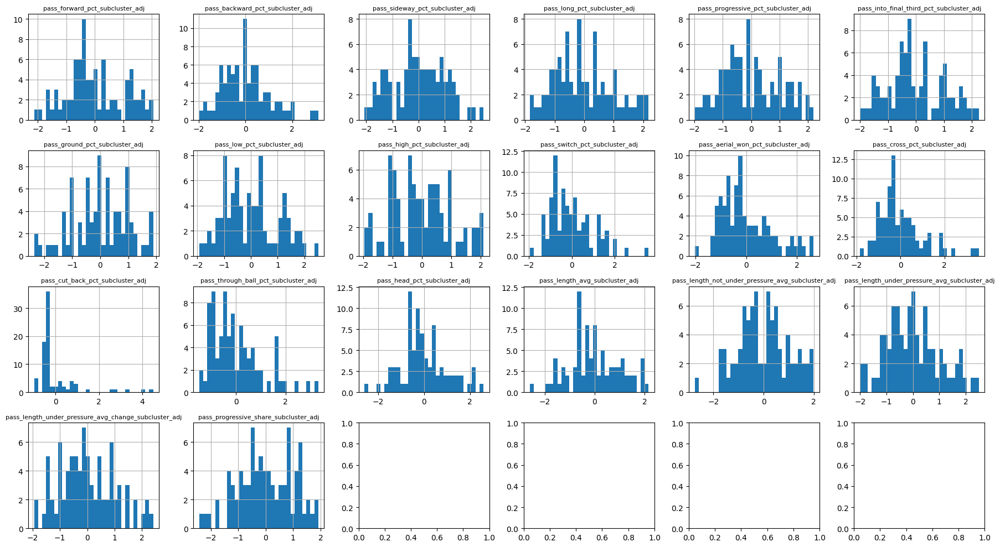

In [1491]:
# split into batches of ~24 features at a time, by conceptual block
passing_cols = [c for c in feature_cols_subcluster_adj if 'pass' in c]
plot_histogram_grid(center_midfields_defensive_stats, passing_cols)

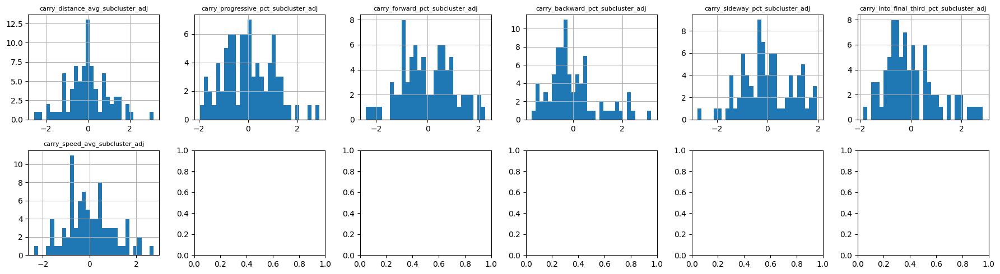

In [1492]:
# split into batches of ~24 features at a time, by conceptual block
carrying_cols = [c for c in feature_cols_subcluster_adj if 'carry' in c]
plot_histogram_grid(center_midfields_defensive_stats, carrying_cols)

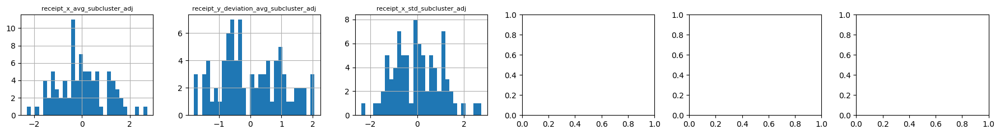

In [1493]:
# split into batches of ~24 features at a time, by conceptual block
receipt_cols = [c for c in feature_cols_subcluster_adj if 'receipt' in c]
plot_histogram_grid(center_midfields_defensive_stats, receipt_cols)

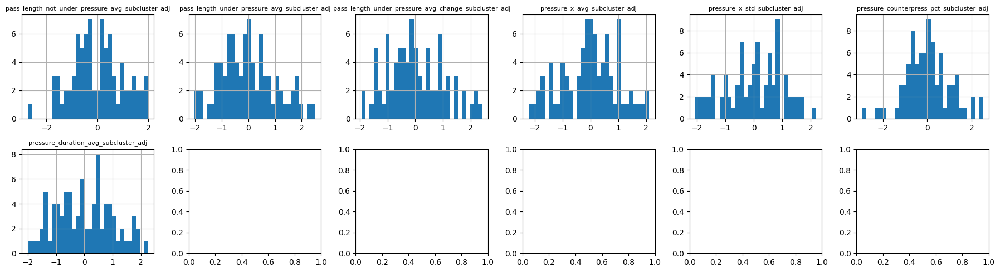

In [1494]:
# split into batches of ~24 features at a time, by conceptual block
pressure_cols = [c for c in feature_cols_subcluster_adj if 'pressure' in c]
plot_histogram_grid(center_midfields_defensive_stats, pressure_cols)

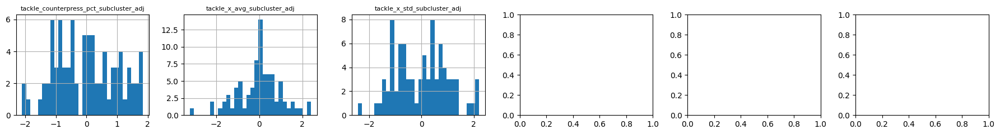

In [1495]:
# split into batches of ~24 features at a time, by conceptual block
tackle_cols = [c for c in feature_cols_subcluster_adj if 'tackle' in c]
plot_histogram_grid(center_midfields_defensive_stats, tackle_cols)

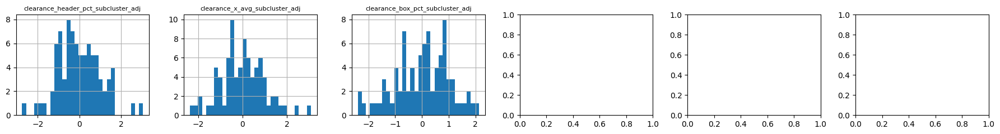

In [1496]:
# split into batches of ~24 features at a time, by conceptual block
clearance_cols = [c for c in feature_cols_subcluster_adj if 'clearance' in c]
plot_histogram_grid(center_midfields_defensive_stats, clearance_cols)

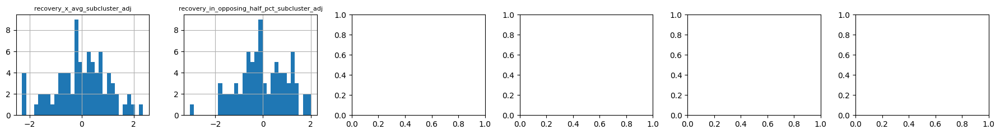

In [1497]:
# split into batches of ~24 features at a time, by conceptual block
recovery_cols = [c for c in feature_cols_subcluster_adj if 'recover' in c]
plot_histogram_grid(center_midfields_defensive_stats, recovery_cols)

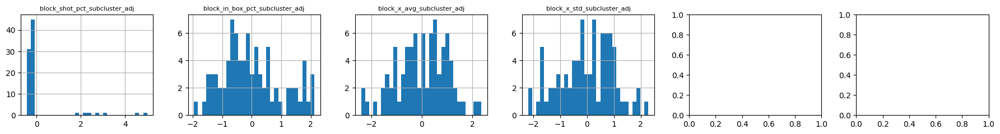

In [1498]:
# split into batches of ~24 features at a time, by conceptual block
block_cols = [c for c in feature_cols_subcluster_adj if 'block' in c]
plot_histogram_grid(center_midfields_defensive_stats, block_cols)

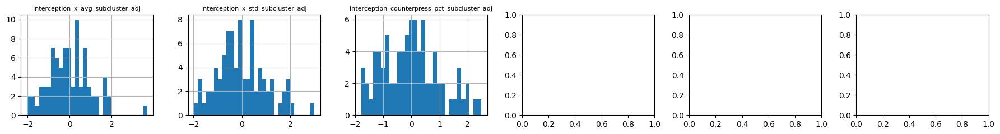

In [1499]:
# split into batches of ~24 features at a time, by conceptual block
interception_cols = [c for c in feature_cols_subcluster_adj if 'intercept' in c]
plot_histogram_grid(center_midfields_defensive_stats, interception_cols)

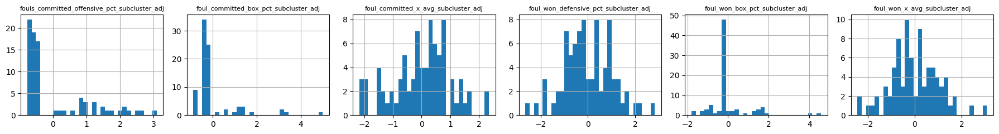

In [1500]:
# split into batches of ~24 features at a time, by conceptual block
foul_cols = [c for c in feature_cols_subcluster_adj if 'foul' in c]
plot_histogram_grid(center_midfields_defensive_stats, foul_cols)

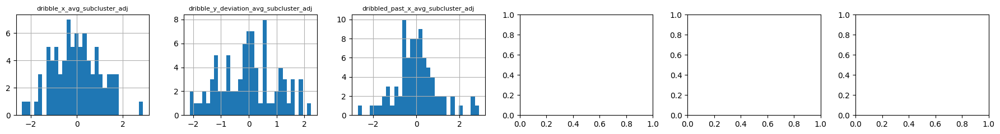

In [1501]:
# split into batches of ~24 features at a time, by conceptual block
dribble_cols = [c for c in feature_cols_subcluster_adj if 'dribble' in c]
plot_histogram_grid(center_midfields_defensive_stats, dribble_cols)

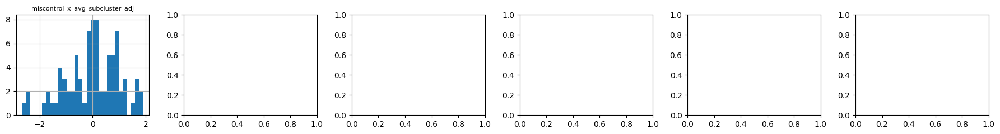

In [1502]:
# split into batches of ~24 features at a time, by conceptual block
miscontrol_cols = [c for c in feature_cols_subcluster_adj if 'miscontrol' in c]
plot_histogram_grid(center_midfields_defensive_stats, miscontrol_cols)

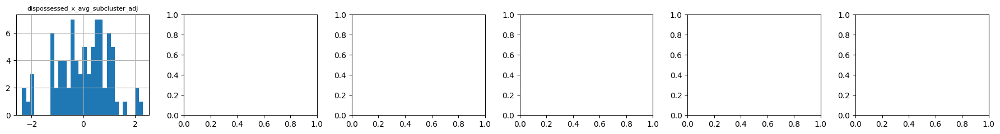

In [1503]:
# split into batches of ~24 features at a time, by conceptual block
dispossessed_cols = [c for c in feature_cols_subcluster_adj if 'dispossessed' in c]
plot_histogram_grid(center_midfields_defensive_stats, dispossessed_cols)

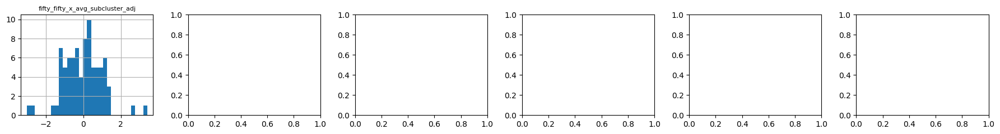

In [1504]:
# split into batches of ~24 features at a time, by conceptual block
fifty_fifty_cols = [c for c in feature_cols_subcluster_adj if 'fifty_fifty' in c]
plot_histogram_grid(center_midfields_defensive_stats, fifty_fifty_cols)

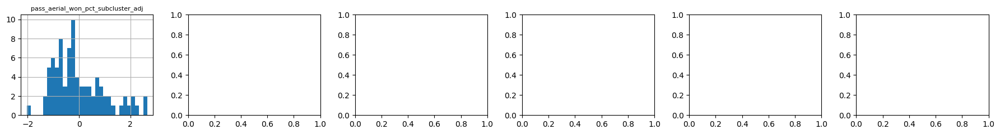

In [1505]:
# split into batches of ~24 features at a time, by conceptual block
aerial_cols = [c for c in feature_cols_subcluster_adj if 'aerial' in c]
plot_histogram_grid(center_midfields_defensive_stats, aerial_cols)

In [1506]:
columns_to_drop_distribution = ['pass_aerial_won_pct', 'pass_cross_pct', 'pass_cut_back_pct', 'pass_through_ball_pct',
                                'block_shot_pct', 'fouls_committed_offensive_pct', 'foul_committed_box_pct', 'foul_won_box_pct']

In [1507]:
center_midfields_defensive_stats = center_midfields_defensive_stats.drop(columns=columns_to_drop_distribution + [c + '_subcluster_adj' for c in columns_to_drop_distribution])

In [1508]:
center_midfields_defensive_stats.shape

(83, 118)

In [1509]:
center_midfields_defensive_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_head_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'clearance_box_pct',
 'recovery_x_avg',
 'recovery_in_opposing_half_pct',
 'block_in_box_pct',
 'block_x_avg',
 'block_x_std',
 'interception_x_avg',
 'int

In [1510]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_distribution]

In [1511]:
feature_cols_subcluster_adj = [c + '_subcluster_adj' for c in feature_cols]

In [1512]:
len(feature_cols)

56

In [1513]:
len(feature_cols_subcluster_adj)

56

#### Observe correlation between variables

In [1514]:
corr_matrix = center_midfields_defensive_stats[feature_cols_subcluster_adj].corr().abs()

In [1515]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [1516]:
high_corr_pairs = (upper.stack()
                   .reset_index()
                   .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'correlation'})
                   .sort_values('correlation', ascending=False))

In [1517]:
# Show all columns
pd.set_option('display.max_columns', None)

pd.set_option('display.max_rows', None)

In [1518]:
high_corr_pairs[high_corr_pairs['correlation'] > 0.8]

,feature_1,feature_2,correlation
628,pass_length_avg_subcluster_adj,pass_length_not_under_pressure_avg_subcluster_adj,0.983944
1621,pressure_x_std_subcluster_adj,defensive_actions_x_std_subcluster_adj,0.935251
1564,pressure_x_avg_subcluster_adj,defensive_actions_x_avg_subcluster_adj,0.911454
344,pass_ground_pct_subcluster_adj,pass_high_pct_subcluster_adj,0.906709
180,pass_long_pct_subcluster_adj,pass_length_not_under_pressure_avg_subcluster_adj,0.906491
2110,recovery_x_avg_subcluster_adj,recovery_in_opposing_half_pct_subcluster_adj,0.901952
179,pass_long_pct_subcluster_adj,pass_length_avg_subcluster_adj,0.894598
951,carry_progressive_pct_subcluster_adj,pass_progressive_share_subcluster_adj,0.830601


In [1519]:
# Show all columns
pd.reset_option('display.max_columns')

pd.reset_option('display.max_rows')

In [1520]:
columns_to_drop_correlation = ['pass_length_not_under_pressure_avg', 'defensive_actions_x_std', 'defensive_actions_x_avg',
                               'pass_high_pct', 'recovery_in_opposing_half_pct', 'pass_long_pct', 'pass_sideway_pct',
                               'carry_sideway_pct']

In [1521]:
center_midfields_defensive_stats = center_midfields_defensive_stats.drop(columns=columns_to_drop_correlation)

In [1522]:
center_midfields_defensive_stats.shape

(83, 110)

In [1523]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_correlation]

In [1524]:
feature_cols_subcluster_adj = [c + '_subcluster_adj' for c in feature_cols]

In [1525]:
len(feature_cols)

48

In [1526]:
len(feature_cols_subcluster_adj)

48

In [1527]:
skew_check = center_midfields_defensive_stats[feature_cols].skew().sort_values(ascending=False)

In [1528]:
skew_check[skew_check.abs() > 1.5]

carry_backward_pct    1.677586
dtype: float64

#### Final feature columns

In [1529]:
final_feature_cols = [c for c in feature_cols]

In [1530]:
final_feature_cols

['pass_forward_pct',
 'pass_backward_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_switch_pct',
 'pass_head_pct',
 'pass_length_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'clearance_box_pct',
 'recovery_x_avg',
 'block_in_box_pct',
 'block_x_avg',
 'block_x_std',
 'interception_x_avg',
 'interception_x_std',
 'interception_counterpress_pct',
 'foul_committed_x_avg',
 'foul_won_defensive_pct',
 'foul_won_x_avg',
 'dribbled_past_x_avg',
 'mis

In [1531]:
len(final_feature_cols)

48

In [1532]:
final_feature_cols_subcluster_adj = [c + '_subcluster_adj' for c in final_feature_cols]

In [1533]:
final_feature_cols_adj

['pass_forward_pct_adj',
 'pass_backward_pct_adj',
 'pass_progressive_pct_adj',
 'pass_into_final_third_pct_adj',
 'pass_ground_pct_adj',
 'pass_low_pct_adj',
 'pass_switch_pct_adj',
 'pass_through_ball_pct_adj',
 'pass_head_pct_adj',
 'pass_into_box_pct_adj',
 'pass_length_avg_adj',
 'pass_length_under_pressure_avg_adj',
 'pass_length_under_pressure_avg_change_adj',
 'carry_distance_avg_adj',
 'carry_forward_pct_adj',
 'carry_backward_pct_adj',
 'carry_into_final_third_pct_adj',
 'carry_speed_avg_adj',
 'dribble_x_avg_adj',
 'dribble_y_deviation_avg_adj',
 'shot_open_play_xg_avg_adj',
 'shot_open_play_technique_normal_pct_adj',
 'shot_open_play_distance_avg_adj',
 'receipt_x_avg_adj',
 'receipt_y_deviation_avg_adj',
 'receipt_x_std_adj',
 'receipt_in_opposition_box_pct_adj',
 'pressure_x_avg_adj',
 'pressure_x_std_adj',
 'pressure_counterpress_pct_adj',
 'pressure_duration_avg_adj',
 'tackle_counterpress_pct_adj',
 'tackle_x_avg_adj',
 'tackle_x_std_adj',
 'clearance_header_pct_adj',


In [1534]:
len(final_feature_cols_adj)

52

#### Detect outliers

In [1535]:
outliers_zscore = detect_outliers_zscore(center_midfields_defensive_stats, final_feature_cols_subcluster_adj, player_id_to_player, team_id_to_team)

In [1536]:
for col, rows in outliers_zscore.items():
    print(f"\n--- {col} ---")
    print(rows.sort_values('z_score', ascending=False))


--- pass_backward_pct_subcluster_adj ---
                                              league  \
player_id team_id position_group                       
46882.0   3168    Center Midfield  Frauen Bundesliga   

                                   pass_backward_pct_subcluster_adj  \
player_id team_id position_group                                      
46882.0   3168    Center Midfield                          3.115388   

                                   player_id  team_id   z_score  \
player_id team_id position_group                                  
46882.0   3168    Center Midfield    46882.0     3168  3.115388   

                                          player              team  
player_id team_id position_group                                    
46882.0   3168    Center Midfield  Juliane Wirtz  SV Werder Bremen  

--- pass_switch_pct_subcluster_adj ---
                                                    league  \
player_id team_id position_group                             
85

In [1537]:
outliers_iqr = detect_outliers_iqr(center_midfields_defensive_stats, final_feature_cols_subcluster_adj, player_id_to_player, team_id_to_team)

In [1538]:
for col, rows in outliers_iqr.items():
    print(f"\n--- {col} ---")
    print(rows)


--- pass_backward_pct_subcluster_adj ---
                                              league  \
player_id team_id position_group                       
46882.0   3168    Center Midfield  Frauen Bundesliga   
50017.0   3269    Center Midfield             Liga F   

                                   pass_backward_pct_subcluster_adj  \
player_id team_id position_group                                      
46882.0   3168    Center Midfield                          3.115388   
50017.0   3269    Center Midfield                          2.939602   

                                   player_id  team_id  \
player_id team_id position_group                        
46882.0   3168    Center Midfield    46882.0     3168   
50017.0   3269    Center Midfield    50017.0     3269   

                                                             player  \
player_id team_id position_group                                      
46882.0   3168    Center Midfield                     Juliane Wirtz   
50017.

In [1539]:
all_flagged_players_zscore = []

In [1540]:
for col, rows in outliers_zscore.items():
    all_flagged_players_zscore.extend(rows['player_id'].tolist())

In [1541]:
flag_counts_zscore = pd.Series(Counter(all_flagged_players_zscore)).sort_values(ascending=False)

In [1542]:
flag_counts_zscore

85004.0     2
408964.0    2
46882.0     1
46561.0     1
30971.0     1
49910.0     1
4660.0      1
25466.0     1
46881.0     1
dtype: int64

In [1543]:
all_flagged_players_iqr = []

In [1544]:
for col, rows in outliers_iqr.items():
    all_flagged_players_iqr.extend(rows['player_id'].tolist())

In [1545]:
flag_counts_iqr = pd.Series(Counter(all_flagged_players_iqr)).sort_values(ascending=False)

In [1546]:
flag_counts_iqr

4658.0      4
63625.0     3
85004.0     3
50017.0     3
49910.0     2
408964.0    2
276904.0    2
408967.0    2
46881.0     2
4660.0      2
63308.0     2
15616.0     2
30971.0     2
46561.0     1
26094.0     1
50820.0     1
89009.0     1
46882.0     1
46876.0     1
45633.0     1
321798.0    1
142137.0    1
10398.0     1
324965.0    1
46980.0     1
45884.0     1
25466.0     1
49943.0     1
45374.0     1
dtype: int64

In [1547]:
keys = ['player_id', 'team_id', 'league', 'position_group']

In [1548]:
winsorize_cols = ['pass_backward_pct_subcluster_adj', 'pass_switch_pct_subcluster_adj', 'pass_head_pct_subcluster_adj', 'carry_distance_avg_subcluster_adj',
                  'carry_backward_pct_subcluster_adj', 'carry_into_final_third_pct_subcluster_adj', 'carry_speed_avg_subcluster_adj',
                  'receipt_x_avg_subcluster_adj', 'pressure_counterpress_pct_subcluster_adj', 'tackle_x_avg_subcluster_adj', 'clearance_header_pct_subcluster_adj',
                  'clearance_x_avg_subcluster_adj', 'interception_x_avg_subcluster_adj', 'interception_x_std_subcluster_adj', 'foul_won_x_avg_subcluster_adj',
                  'dribbled_past_x_avg_subcluster_adj', 'fifty_fifty_x_avg_subcluster_adj', 'counterpress_in_opposing_half_pct_subcluster_adj']

In [1549]:
for col in winsorize_cols:
    center_midfields_defensive_stats[col] = winsorize(center_midfields_defensive_stats[col])

In [1550]:
imputation_configs = [
    dict(position_group='Center Midfield', pct_col='tackle_x_avg',
        attempted_col='tackles_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='clearance_x_avg',
        attempted_col='clearances_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='interception_x_avg',
        attempted_col='interceptions_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='interception_x_std',
        attempted_col='interceptions_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='foul_won_x_avg',
        attempted_col='fouls_won', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='dribbled_past_x_avg',
        attempted_col='dribbled_pasts', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='fifty_fifty_x_avg',
        attempted_col='fifty_fiftys', min_quantile=0.2),
]

In [1551]:
stats_by_position_cmd = {
    'Center Midfield': center_midfields_defensive_stats,
}

In [1552]:
for cfg in imputation_configs:
    pos, pct_col = cfg['position_group'], cfg['pct_col']
    target_df = stats_by_position_cmd[pos]
    
    # reads eligibility/reliable-group-mean from all_players_stats (untouched, read-only),
    # writes the imputed value into target_df only
    target_df = impute_unreliable_rate_stat(all_players_stats_cm, target_df, **cfg)

    # residualize on target_df itself, using its now-imputed raw value as input
    refit = residualize(
        target_df, feature_cols=[pct_col], covariate_col='context_score',
        group_cols=['position_group'], robust=True,
    )
    target_df[pct_col + '_subcluster_adj'] = refit[pct_col + '_subcluster_adj']

    stats_by_position_cmd[pos] = target_df

#### Rank features on percentile

In [1553]:
center_midfields_defensive_stats = to_percentile(center_midfields_defensive_stats, final_feature_cols)      # raw

In [1554]:
center_midfields_defensive_stats = to_percentile(center_midfields_defensive_stats, final_feature_cols_subcluster_adj) # adjusted

#### Divide features into groups

In [1555]:
feature_groups = {
    'passing_share': [
        'pass_forward_pct', 'pass_backward_pct', 'pass_progressive_pct', 'pass_into_final_third_pct', 'pass_ground_pct', 
        'pass_low_pct', 'pass_switch_pct', 'pass_head_pct', 'pass_progressive_share'
    ],
    'passing_length': [
        'pass_length_avg', 'pass_length_under_pressure_avg', 'pass_length_under_pressure_avg_change'
    ],
    'carrying': [
        'carry_distance_avg', 'carry_progressive_pct', 'carry_forward_pct', 'carry_backward_pct', 'carry_into_final_third_pct', 'carry_speed_avg'
    ],
    'receipt': [
        'receipt_x_avg', 'receipt_y_deviation_avg', 'receipt_x_std'
    ],
    'dribbling': [
        'dribble_x_avg', 'dribble_y_deviation_avg',
    ],
    'defensive_location': [
        'pressure_x_avg', 'pressure_x_std', 'tackle_x_avg', 'tackle_x_std', 'clearance_x_avg', 'clearance_box_pct', 'recovery_x_avg', 'block_in_box_pct', 
        'block_x_avg', 'block_x_std', 'interception_x_avg', 'interception_x_std', 'counterpress_in_opposing_half_pct', 'foul_won_defensive_pct', 'foul_won_x_avg',
    ],
    'defensive_volume': [
        'pressure_counterpress_pct', 'pressure_duration_avg', 'tackle_counterpress_pct', 'clearance_header_pct', 'interception_counterpress_pct'
    ],
    'vulnerability_fifty_fifty': [
        'foul_committed_x_avg', 'dribbled_past_x_avg', 'miscontrol_x_avg', 'dispossessed_x_avg', 'fifty_fifty_x_avg'
    ]
}

In [1556]:
feature_groups_subcluster_adj = {
    category: [f + '_subcluster_adj' for f in features]
    for category, features in feature_groups.items()
}

In [1557]:
n_per_category = {
    'passing_share': 5, 'passing_length': 1, 'carrying': 5, 'receipt': 2, 'dribbling': 1, 'defensive_location': 6, 'defensive_volume': 2, 'vulnerability_fifty_fifty': 2
}

In [1558]:
# n_per_category = {
#     'passing_volume': 4, 'passing_accuracy': 4, 'passing_length': 2,
#     'carrying': 3, 'dribbling': 3, 'shooting_volume': 3,
#     'shooting_accuracy': 3, 'ball_receipt': 2, 
#     'defensive_volume': 4, 'defensive_accuracy': 3, 'defensive_location': 2,
#     'foul_won': 1, 'vulnerability_volume': 2, 'vulnerability_location': 2, 'fifty_fifty': 1
# }

In [1559]:
all_grouped = [c for group in feature_groups.values() for c in group]

In [1560]:
missing = set(final_feature_cols) - set(all_grouped)

In [1561]:
missing

set()

In [1562]:
spare = set(all_grouped) - set(final_feature_cols)

In [1563]:
spare

set()

#### KMeans Clustering

##### PCA

In [1564]:
X = center_midfields_defensive_stats[final_feature_cols_subcluster_adj]

In [1565]:
n_features = 10

In [1566]:
pca_reduced_final = PCA(n_components=n_features)

In [1567]:
pca_reduced_final.set_output(transform='pandas')

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",10
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD

In [1568]:
X_pca_final = pca_reduced_final.fit_transform(X)

##### KMeans with k = 2

In [1569]:
k = 2

In [1570]:
kmeans_2 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1571]:
center_midfields_defensive_stats['kmeans_2_cluster'] = kmeans_2.fit_predict(X_pca_final)  # or X, if using raw features

In [1572]:
# bring labels back to the original unstandardized data for interpretation
center_midfields_defensive_stats['kmeans_2_cluster'] = center_midfields_defensive_stats['kmeans_2_cluster'].values

In [1573]:
center_midfields_defensive_stats['kmeans_2_cluster'].value_counts()

kmeans_2_cluster
1    47
0    36
Name: count, dtype: int64

In [1574]:
center_midfields_defensive_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_2, 
    stats_df=center_midfields_defensive_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 3

In [1575]:
k = 3

In [1576]:
kmeans_3 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1577]:
center_midfields_defensive_stats['kmeans_3_cluster'] = kmeans_3.fit_predict(X_pca_final)  # or X, if using raw features

In [1578]:
# bring labels back to the original unstandardized data for interpretation
center_midfields_defensive_stats['kmeans_3_cluster'] = center_midfields_defensive_stats['kmeans_3_cluster'].values

In [1579]:
center_midfields_defensive_stats['kmeans_3_cluster'].value_counts()

kmeans_3_cluster
0    32
1    26
2    25
Name: count, dtype: int64

In [1580]:
center_midfields_defensive_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_3, 
    stats_df=center_midfields_defensive_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 4

In [1581]:
k = 4

In [1582]:
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

In [1583]:
center_midfields_defensive_stats['kmeans_4_cluster'] = kmeans_4.fit_predict(X_pca_final)  # or X, if using raw features

In [1584]:
# bring labels back to the original unstandardized data for interpretation
center_midfields_defensive_stats['kmeans_4_cluster'] = center_midfields_defensive_stats['kmeans_4_cluster'].values

In [1585]:
center_midfields_defensive_stats['kmeans_4_cluster'].value_counts()

kmeans_4_cluster
0    27
1    20
3    19
2    17
Name: count, dtype: int64

In [1586]:
center_midfields_defensive_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_4, 
    stats_df=center_midfields_defensive_stats,
    sigma_quantile=0.5
)

### Center Midfields Center

#### Filter by position

In [1587]:
center_midfields_center_stats.shape

(56, 454)

In [1588]:
center_midfields_center_stats.columns.tolist()

['passes_attempted',
 'pass_completion_pct',
 'pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_under_pressure_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_deflected_pct',
 'pass_goal_assist_pct',
 'pass_miscommunication_pct',
 'pass_no_touch_pct',
 'pass_shot_assist_pct',
 'pass_through_ball_pct',
 'pass_create_shot_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_deep_completion_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_aerial_won_completion_pct',
 'pass_cross_completion_pct',
 'pass_cut_back_completion_pct',
 'pass_deflected_completion_pct',
 'pass_no_touch_completion_pct',
 'pass_switch_completion_pct',
 'pass_through_ball_completion_pct',
 'pass_forward_complet

In [1589]:
center_midfields_center_stats = center_midfields_center_stats[style_feature_cols + style_feature_cols_subcluster_adj + ['league', 'pct_minutes_as_DM', 'pct_minutes_as_CM', 'pct_minutes_as_AM', 'advancement_index', 'context_score']]

In [1590]:
center_midfields_center_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_no_touch_pct',
 'pass_through_ball_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_o

In [1591]:
columns_to_drop_irrelevant = ['pass_no_touch_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'shot_open_play_left_foot_pct',
 'shot_open_play_right_foot_pct',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_moving_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_feet_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_sweeps_x_avg',
]

In [1592]:
center_midfields_center_stats = center_midfields_center_stats.drop(columns=columns_to_drop_irrelevant + [c + '_subcluster_adj' for c in columns_to_drop_irrelevant])

In [1593]:
center_midfields_center_stats.shape

(56, 168)

In [1594]:
center_midfields_center_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_through_ball_pct',
 'pass_head_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_head_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_technique_volley_pct',
 'shot_open_play_technique_half_volley_pct',
 'shot_open_play_technique_

In [1595]:
feature_cols = [c for c in style_feature_cols if c not in columns_to_drop_irrelevant]

In [1596]:
feature_cols_subcluster_adj = [c + '_subcluster_adj' for c in feature_cols]

In [1597]:
len(feature_cols)

81

In [1598]:
len(feature_cols_subcluster_adj)

81

#### Observe distribution of stats

In [1599]:
summary = center_midfields_center_stats[feature_cols_subcluster_adj].describe().T
summary['skew'] = center_midfields_center_stats[feature_cols_subcluster_adj].skew()
summary['pct_zero'] = (center_midfields_center_stats[feature_cols_subcluster_adj] == 0).mean()
summary['pct_missing'] = center_midfields_center_stats[feature_cols_subcluster_adj].isna().mean()
summary.sort_values('skew', ascending=False)

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing
shot_open_play_technique_overhead_kick_pct_subcluster_adj,56.0,0.000000e+00,1.00905,-2.479242,-0.276010,-0.258199,-0.250000,4.000000,2.636481,0.0,0.0
foul_won_box_pct_subcluster_adj,56.0,-3.172066e-17,1.00905,-2.479242,-0.258199,-0.254099,-0.250000,4.000000,2.542192,0.0,0.0
shot_open_play_technique_lob_pct_subcluster_adj,56.0,4.758099e-17,1.00905,-0.763160,-0.597267,-0.250000,-0.229428,4.000000,2.132178,0.0,0.0
fouls_committed_offensive_pct_subcluster_adj,56.0,-7.930164e-18,1.00905,-0.878582,-0.630837,-0.424643,0.279627,3.162278,1.600253,0.0,0.0
shot_open_play_technique_backheel_pct_subcluster_adj,56.0,9.059881e-09,1.00905,-1.787919,-0.324971,-0.316228,0.315698,3.719114,1.540978,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
block_in_box_pct_subcluster_adj,56.0,6.344132e-17,1.00905,-2.337391,-0.621629,0.172300,0.747739,1.769820,-0.408069,0.0,0.0
recovery_in_opposing_half_pct_subcluster_adj,56.0,3.172066e-17,1.00905,-3.164034,-0.604545,0.127586,0.649782,2.193090,-0.525133,0.0,0.0
recovery_x_avg_subcluster_adj,56.0,-1.586033e-17,1.00905,-3.267089,-0.573454,0.202010,0.665391,2.309562,-0.786191,0.0,0.0
pass_ground_pct_subcluster_adj,56.0,0.000000e+00,1.00905,-2.503777,-0.641935,0.185571,0.744508,1.454125,-0.813646,0.0,0.0


In [1600]:
summary.shape

(81, 11)

In [1601]:
low_variance = summary[summary['std'] / summary['mean'].abs() < 0.1]

In [1602]:
low_variance

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing


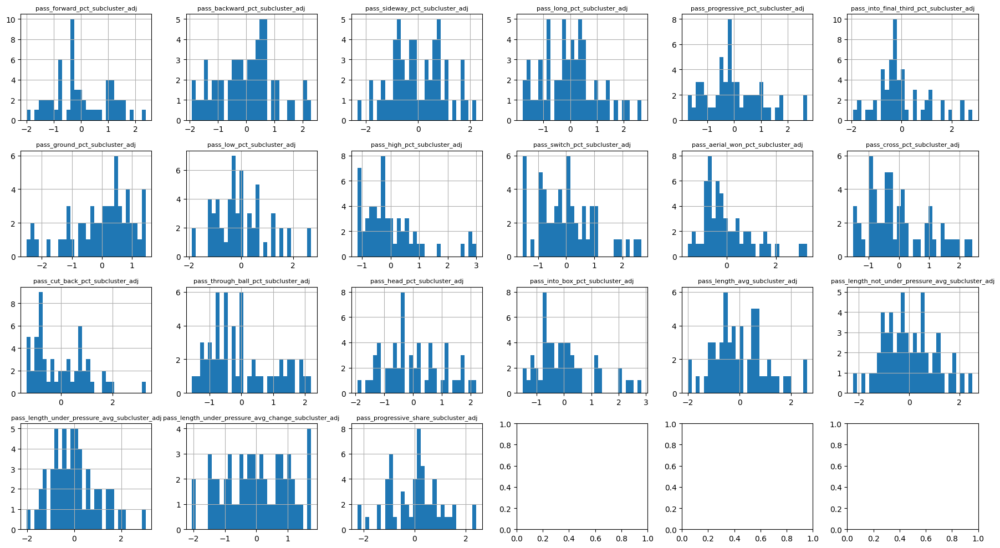

In [1603]:
# split into batches of ~24 features at a time, by conceptual block
passing_cols = [c for c in feature_cols_subcluster_adj if 'pass' in c]
plot_histogram_grid(center_midfields_center_stats, passing_cols)

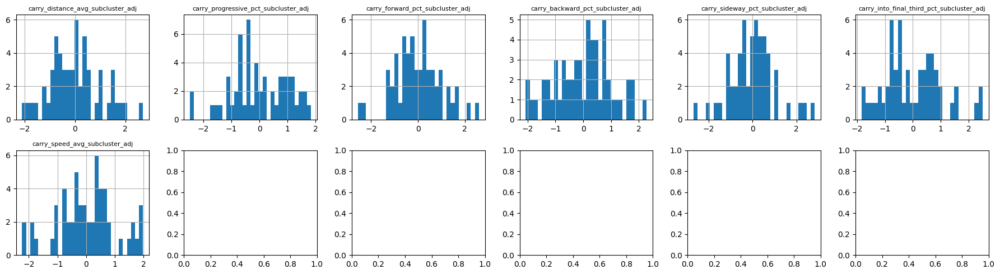

In [1604]:
# split into batches of ~24 features at a time, by conceptual block
carrying_cols = [c for c in feature_cols_subcluster_adj if 'carry' in c]
plot_histogram_grid(center_midfields_center_stats, carrying_cols)

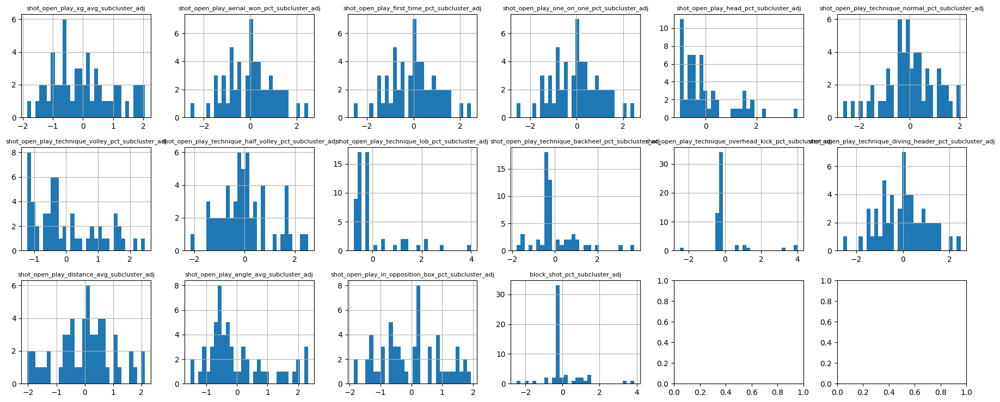

In [1605]:
# split into batches of ~24 features at a time, by conceptual block
shooting_cols = [c for c in feature_cols_subcluster_adj if 'shot' in c]
plot_histogram_grid(center_midfields_center_stats, shooting_cols)

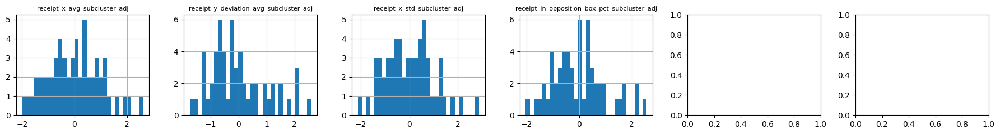

In [1606]:
# split into batches of ~24 features at a time, by conceptual block
receipt_cols = [c for c in feature_cols_subcluster_adj if 'receipt' in c]
plot_histogram_grid(center_midfields_center_stats, receipt_cols)

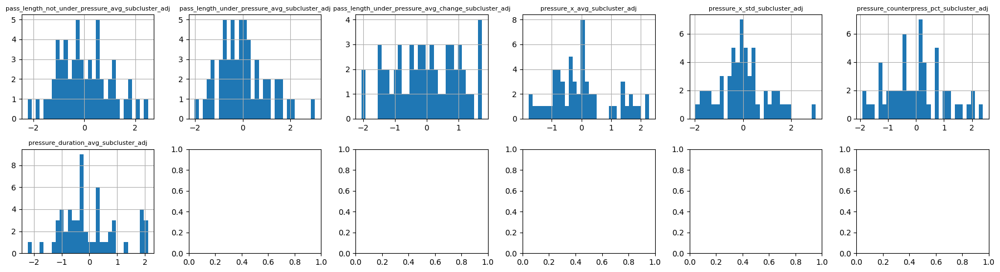

In [1607]:
# split into batches of ~24 features at a time, by conceptual block
pressure_cols = [c for c in feature_cols_subcluster_adj if 'pressure' in c]
plot_histogram_grid(center_midfields_center_stats, pressure_cols)

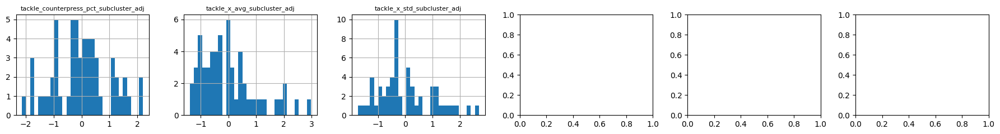

In [1608]:
# split into batches of ~24 features at a time, by conceptual block
tackle_cols = [c for c in feature_cols_subcluster_adj if 'tackle' in c]
plot_histogram_grid(center_midfields_center_stats, tackle_cols)

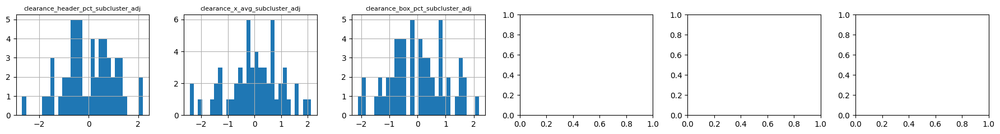

In [1609]:
# split into batches of ~24 features at a time, by conceptual block
clearance_cols = [c for c in feature_cols_subcluster_adj if 'clearance' in c]
plot_histogram_grid(center_midfields_center_stats, clearance_cols)

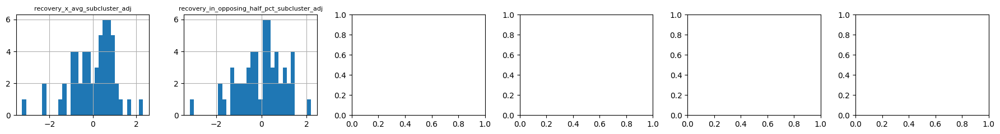

In [1610]:
# split into batches of ~24 features at a time, by conceptual block
recovery_cols = [c for c in feature_cols_subcluster_adj if 'recover' in c]
plot_histogram_grid(center_midfields_center_stats, recovery_cols)

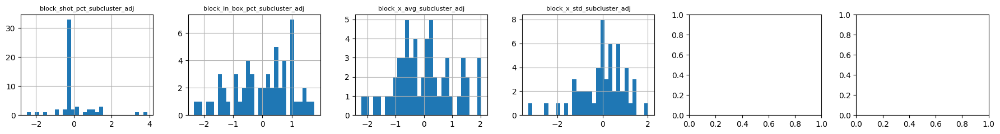

In [1611]:
# split into batches of ~24 features at a time, by conceptual block
block_cols = [c for c in feature_cols_subcluster_adj if 'block' in c]
plot_histogram_grid(center_midfields_center_stats, block_cols)

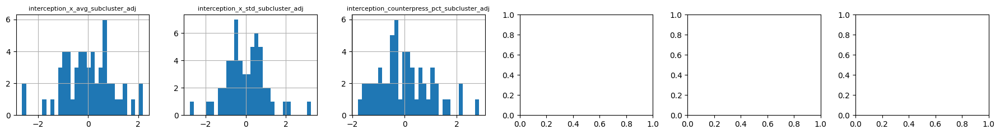

In [1612]:
# split into batches of ~24 features at a time, by conceptual block
interception_cols = [c for c in feature_cols_subcluster_adj if 'intercept' in c]
plot_histogram_grid(center_midfields_center_stats, interception_cols)

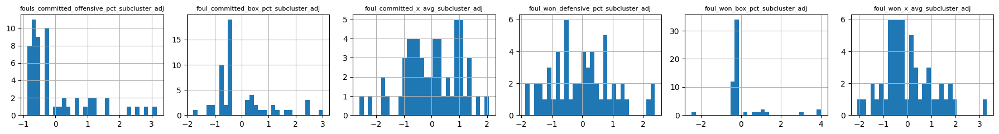

In [1613]:
# split into batches of ~24 features at a time, by conceptual block
foul_cols = [c for c in feature_cols_subcluster_adj if 'foul' in c]
plot_histogram_grid(center_midfields_center_stats, foul_cols)

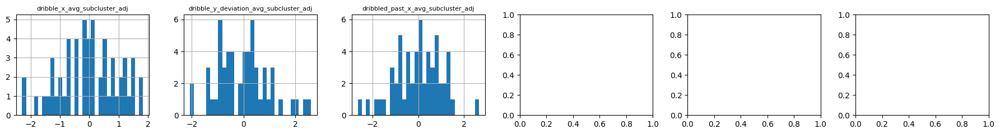

In [1614]:
# split into batches of ~24 features at a time, by conceptual block
dribble_cols = [c for c in feature_cols_subcluster_adj if 'dribble' in c]
plot_histogram_grid(center_midfields_center_stats, dribble_cols)

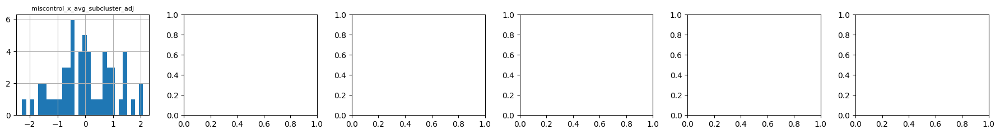

In [1615]:
# split into batches of ~24 features at a time, by conceptual block
miscontrol_cols = [c for c in feature_cols_subcluster_adj if 'miscontrol' in c]
plot_histogram_grid(center_midfields_center_stats, miscontrol_cols)

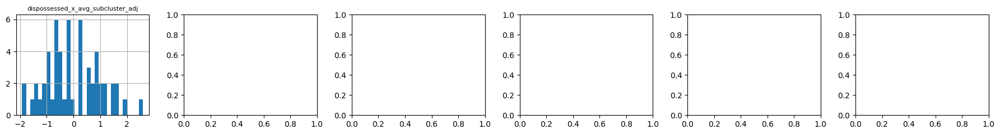

In [1616]:
# split into batches of ~24 features at a time, by conceptual block
dispossessed_cols = [c for c in feature_cols_subcluster_adj if 'dispossessed' in c]
plot_histogram_grid(center_midfields_center_stats, dispossessed_cols)

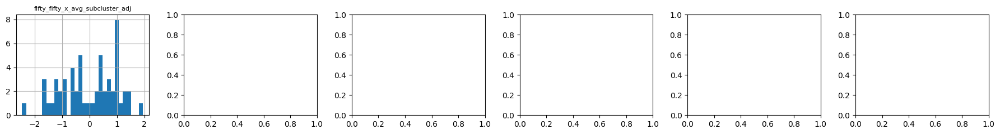

In [1617]:
# split into batches of ~24 features at a time, by conceptual block
fifty_fifty_cols = [c for c in feature_cols_subcluster_adj if 'fifty_fifty' in c]
plot_histogram_grid(center_midfields_center_stats, fifty_fifty_cols)

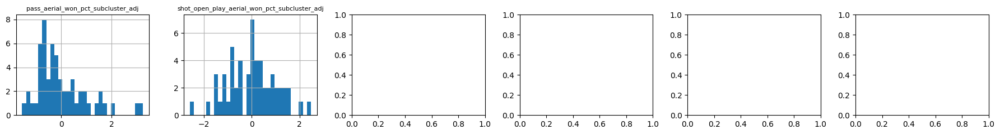

In [1618]:
# split into batches of ~24 features at a time, by conceptual block
aerial_cols = [c for c in feature_cols_subcluster_adj if 'aerial' in c]
plot_histogram_grid(center_midfields_center_stats, aerial_cols)

In [1619]:
columns_to_drop_distribution = ['pass_switch_pct', 'pass_aerial_won_pct', 'pass_cross_pct', 'pass_cut_back_pct',
                                'pass_through_ball_pct', 'pass_length_under_pressure_avg_change', 'block_shot_pct',
                                'block_in_box_pct', 'fouls_committed_offensive_pct','foul_committed_box_pct', 'foul_won_box_pct', 
                                'shot_open_play_technique_volley_pct', 'shot_open_play_technique_half_volley_pct', 'shot_open_play_technique_lob_pct',
                                'shot_open_play_technique_backheel_pct', 'shot_open_play_technique_overhead_kick_pct', 'shot_open_play_technique_diving_header_pct',]

In [1620]:
center_midfields_center_stats = center_midfields_center_stats.drop(columns=columns_to_drop_distribution)

In [1621]:
center_midfields_center_stats.shape

(56, 151)

In [1622]:
center_midfields_center_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_head_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_head_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_distance_avg',
 'shot_open_play_angle_avg',
 'shot_open_play_in_opposition_box_pct',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'receipt_in_opposition_box_pct',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct

In [1623]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_distribution]

In [1624]:
feature_cols_subcluster_adj = [c + '_subcluster_adj' for c in feature_cols]

In [1625]:
len(feature_cols)

64

In [1626]:
len(feature_cols_subcluster_adj)

64

#### Observe correlation between variables

In [1627]:
corr_matrix = center_midfields_center_stats[feature_cols_subcluster_adj].corr().abs()

In [1628]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [1629]:
high_corr_pairs = (upper.stack()
                   .reset_index()
                   .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'correlation'})
                   .sort_values('correlation', ascending=False))

In [1630]:
# Show all columns
pd.set_option('display.max_columns', None)

pd.set_option('display.max_rows', None)

In [1631]:
high_corr_pairs[high_corr_pairs['correlation'] > 0.8]

,feature_1,feature_2,correlation
1626,shot_open_play_first_time_pct_subcluster_adj,shot_open_play_one_on_one_pct_subcluster_adj,1.000000
1562,shot_open_play_aerial_won_pct_subcluster_adj,shot_open_play_one_on_one_pct_subcluster_adj,1.000000
1561,shot_open_play_aerial_won_pct_subcluster_adj,shot_open_play_first_time_pct_subcluster_adj,1.000000
716,pass_length_avg_subcluster_adj,pass_length_not_under_pressure_avg_subcluster_adj,0.973081
2364,pressure_x_avg_subcluster_adj,defensive_actions_x_avg_subcluster_adj,0.965435
1887,shot_open_play_distance_avg_subcluster_adj,shot_open_play_in_opposition_box_pct_subcluste...,0.900091
203,pass_long_pct_subcluster_adj,pass_length_avg_subcluster_adj,0.896406
1886,shot_open_play_distance_avg_subcluster_adj,shot_open_play_angle_avg_subcluster_adj,0.896394
204,pass_long_pct_subcluster_adj,pass_length_not_under_pressure_avg_subcluster_adj,0.894506
2429,pressure_x_std_subcluster_adj,defensive_actions_x_std_subcluster_adj,0.892668


In [1632]:
# Show all columns
pd.reset_option('display.max_columns')

pd.reset_option('display.max_rows')

In [1633]:
columns_to_drop_correlation = ['shot_open_play_aerial_won_pct', 'shot_open_play_first_time_pct', 'shot_open_play_one_on_one_pct',
                               'pass_length_not_under_pressure_avg', 'defensive_actions_x_avg', 'shot_open_play_in_opposition_box_pct',
                               'pass_long_pct', 'shot_open_play_angle_avg', 'defensive_actions_x_std', 'recovery_in_opposing_half_pct',
                               'pass_high_pct', 'carry_sideway_pct', 'pass_sideway_pct']

In [1634]:
center_midfields_center_stats = center_midfields_center_stats.drop(columns=columns_to_drop_correlation)

In [1635]:
center_midfields_center_stats.shape

(56, 138)

In [1636]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_correlation]

In [1637]:
feature_cols_subcluster_adj = [c + '_subcluster_adj' for c in feature_cols]

In [1638]:
len(feature_cols)

51

In [1639]:
len(feature_cols_subcluster_adj)

51

In [1640]:
skew_check = center_midfields_center_stats[feature_cols_subcluster_adj].skew().sort_values(ascending=False)

In [1641]:
skew_check[skew_check.abs() > 1.5]

Series([], dtype: float64)

#### Final feature columns

In [1642]:
final_feature_cols = [c for c in feature_cols]

In [1643]:
final_feature_cols

['pass_forward_pct',
 'pass_backward_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_head_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_under_pressure_avg',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_head_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_distance_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'receipt_in_opposition_box_pct',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'clearance_box_pct',
 'recovery_x_avg',
 'block_x_avg',
 'block_x_std',
 'interception_x_avg',
 'interception_x_std',
 'interception_counterpress_pct',
 

In [1644]:
len(final_feature_cols)

51

In [1645]:
final_feature_cols_subcluster_adj = [c + '_subcluster_adj' for c in final_feature_cols]

In [1646]:
final_feature_cols_subcluster_adj

['pass_forward_pct_subcluster_adj',
 'pass_backward_pct_subcluster_adj',
 'pass_progressive_pct_subcluster_adj',
 'pass_into_final_third_pct_subcluster_adj',
 'pass_ground_pct_subcluster_adj',
 'pass_low_pct_subcluster_adj',
 'pass_head_pct_subcluster_adj',
 'pass_into_box_pct_subcluster_adj',
 'pass_length_avg_subcluster_adj',
 'pass_length_under_pressure_avg_subcluster_adj',
 'carry_distance_avg_subcluster_adj',
 'carry_progressive_pct_subcluster_adj',
 'carry_forward_pct_subcluster_adj',
 'carry_backward_pct_subcluster_adj',
 'carry_into_final_third_pct_subcluster_adj',
 'carry_speed_avg_subcluster_adj',
 'dribble_x_avg_subcluster_adj',
 'dribble_y_deviation_avg_subcluster_adj',
 'shot_open_play_xg_avg_subcluster_adj',
 'shot_open_play_head_pct_subcluster_adj',
 'shot_open_play_technique_normal_pct_subcluster_adj',
 'shot_open_play_distance_avg_subcluster_adj',
 'receipt_x_avg_subcluster_adj',
 'receipt_y_deviation_avg_subcluster_adj',
 'receipt_x_std_subcluster_adj',
 'receipt_in_o

In [1647]:
len(final_feature_cols_adj)

52

#### Detect outliers

In [1648]:
outliers_zscore = detect_outliers_zscore(center_midfields_center_stats, final_feature_cols_subcluster_adj, player_id_to_player, team_id_to_team)

In [1649]:
for col, rows in outliers_zscore.items():
    print(f"\n--- {col} ---")
    print(rows.sort_values('z_score', ascending=False))


--- pass_length_under_pressure_avg_subcluster_adj ---
                                          league  \
player_id team_id position_group                   
10228.0   3152    Center Midfield  Serie A Women   

                                   pass_length_under_pressure_avg_subcluster_adj  \
player_id team_id position_group                                                   
10228.0   3152    Center Midfield                                       3.036001   

                                   player_id  team_id   z_score  \
player_id team_id position_group                                  
10228.0   3152    Center Midfield    10228.0     3152  3.036001   

                                              player       team  
player_id team_id position_group                                 
10228.0   3152    Center Midfield  Manuela Giugliano  AS Roma W  

--- shot_open_play_head_pct_subcluster_adj ---
                                   league  \
player_id team_id position_group          

In [1650]:
outliers_iqr = detect_outliers_iqr(center_midfields_center_stats, final_feature_cols_subcluster_adj, player_id_to_player, team_id_to_team)

In [1651]:
for col, rows in outliers_iqr.items():
    print(f"\n--- {col} ---")
    print(rows)


--- pass_progressive_pct_subcluster_adj ---
                                          league  \
player_id team_id position_group                   
409119.0  3280    Center Midfield         Liga F   
10228.0   3152    Center Midfield  Serie A Women   

                                   pass_progressive_pct_subcluster_adj  \
player_id team_id position_group                                         
409119.0  3280    Center Midfield                             2.708095   
10228.0   3152    Center Midfield                             2.662648   

                                   player_id  team_id               player  \
player_id team_id position_group                                             
409119.0  3280    Center Midfield   409119.0     3280  Isabel Corte Peláez   
10228.0   3152    Center Midfield    10228.0     3152    Manuela Giugliano   

                                                    team  bound_distance  
player_id team_id position_group                             

In [1652]:
all_flagged_players_zscore = []

In [1653]:
for col, rows in outliers_zscore.items():
    all_flagged_players_zscore.extend(rows['player_id'].tolist())

In [1654]:
flag_counts_zscore = pd.Series(Counter(all_flagged_players_zscore)).sort_values(ascending=False)

In [1655]:
flag_counts_zscore

10228.0    1
63725.0    1
10139.0    1
46990.0    1
46872.0    1
10154.0    1
46986.0    1
dtype: int64

In [1656]:
all_flagged_players_iqr = []

In [1657]:
for col, rows in outliers_iqr.items():
    all_flagged_players_iqr.extend(rows['player_id'].tolist())

In [1658]:
flag_counts_iqr = pd.Series(Counter(all_flagged_players_iqr)).sort_values(ascending=False)

In [1659]:
flag_counts_iqr

10228.0     5
409119.0    3
47017.0     3
46240.0     2
63725.0     2
32460.0     2
135256.0    2
10154.0     2
361730.0    2
46990.0     2
142949.0    2
25478.0     1
43046.0     1
26520.0     1
322359.0    1
50119.0     1
46952.0     1
50998.0     1
47119.0     1
32456.0     1
321540.0    1
47008.0     1
10139.0     1
19417.0     1
46999.0     1
50126.0     1
46872.0     1
15648.0     1
224822.0    1
46986.0     1
dtype: int64

In [1660]:
winsorize_cols = ['pass_progressive_pct_subcluster_adj', 'pass_into_final_third_pct_subcluster_adj', 'pass_low_pct_subcluster_adj', 'pass_into_box_pct_subcluster_adj',
                  'pass_length_under_pressure_avg_subcluster_adj', 'carry_distance_avg_subcluster_adj', 'carry_forward_pct_subcluster_adj', 'dribble_y_deviation_avg_subcluster_adj',
                  'shot_open_play_head_pct_subcluster_adj', 'shot_open_play_technique_normal_pct_subcluster_adj', 'receipt_y_deviation_avg_subcluster_adj',
                  'receipt_x_std_subcluster_adj', 'receipt_in_opposition_box_pct_subcluster_adj', 'pressure_x_avg_subcluster_adj', 'pressure_x_std_subcluster_adj',
                  'tackle_x_avg_subcluster_adj', 'tackle_x_std_subcluster_adj', 'clearance_header_pct_subcluster_adj', 'clearance_x_avg_subcluster_adj',
                  'recovery_x_avg_subcluster_adj', 'block_x_std_subcluster_adj', 'interception_x_std_subcluster_adj', 'interception_counterpress_pct_subcluster_adj',
                  'foul_won_x_avg_subcluster_adj']

In [1661]:
for col in winsorize_cols:
    center_midfields_center_stats[col] = winsorize(center_midfields_center_stats[col])

In [1662]:
imputation_configs = [
    dict(position_group='Center Midfield', pct_col='dribble_y_deviation_avg',
        attempted_col='dribbles_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='pressure_x_avg',
        attempted_col='pressures_applied', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='pressure_x_std',
        attempted_col='pressures_applied', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='tackle_x_avg',
        attempted_col='tackles_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='tackle_x_std',
        attempted_col='tackles_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='clearance_x_avg',
        attempted_col='clearances_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='recovery_x_avg',
        attempted_col='recoverys_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='block_x_std',
        attempted_col='blocks_total', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='interception_x_std',
        attempted_col='interceptions_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='foul_won_x_avg',
        attempted_col='fouls_won', min_quantile=0.2),
]

In [1663]:
stats_by_position_cmc = {
    'Center Midfield': center_midfields_center_stats,
}

In [1664]:
for cfg in imputation_configs:
    pos, pct_col = cfg['position_group'], cfg['pct_col']
    target_df = stats_by_position_cmc[pos]
    
    # reads eligibility/reliable-group-mean from all_players_stats (untouched, read-only),
    # writes the imputed value into target_df only
    target_df = impute_unreliable_rate_stat(all_players_stats_cm, target_df, **cfg)

    # residualize on target_df itself, using its now-imputed raw value as input
    refit = residualize(
        target_df, feature_cols=[pct_col], covariate_col='context_score',
        group_cols=['position_group'], robust=True,
    )
    target_df[pct_col + '_subcluster_adj'] = refit[pct_col + '_subcluster_adj']

    stats_by_position_cmc[pos] = target_df

#### Rank features on percentile

In [1665]:
center_midfields_center_stats = to_percentile(center_midfields_center_stats, final_feature_cols)      # raw

In [1666]:
center_midfields_center_stats = to_percentile(center_midfields_center_stats, final_feature_cols_subcluster_adj) # adjusted

#### Divide features into groups

In [1667]:
feature_groups = {
    'passing_share': [
        'pass_forward_pct', 'pass_backward_pct', 'pass_into_box_pct', 'pass_into_final_third_pct', 'pass_ground_pct', 
        'pass_low_pct', 'pass_progressive_pct', 'pass_head_pct', 'pass_progressive_share'
    ],
    'passing_length': [
        'pass_length_avg', 'pass_length_under_pressure_avg', 
    ],
    'carrying': [
        'carry_distance_avg', 'carry_forward_pct', 'carry_backward_pct', 'carry_into_final_third_pct', 'carry_progressive_pct', 'carry_speed_avg'
    ],
    'receipt': [
        'receipt_x_avg', 'receipt_y_deviation_avg', 'receipt_x_std', 'receipt_in_opposition_box_pct'
    ],
    'dribbling': [
        'dribble_x_avg', 'dribble_y_deviation_avg',
    ],
    'shooting': [
        'shot_open_play_distance_avg', 'shot_open_play_technique_normal_pct', 'shot_open_play_head_pct', 'shot_open_play_xg_avg'
    ],
    'defensive_location': [
        'pressure_x_avg', 'pressure_x_std', 'tackle_x_avg', 'tackle_x_std', 'clearance_x_avg', 'clearance_box_pct', 'recovery_x_avg', 
        'block_x_avg', 'block_x_std', 'interception_x_avg', 'interception_x_std', 'foul_won_defensive_pct', 'foul_won_x_avg', 'counterpress_in_opposing_half_pct'
    ],
    'defensive_volume': [
        'pressure_counterpress_pct', 'pressure_duration_avg', 'tackle_counterpress_pct', 'clearance_header_pct', 'interception_counterpress_pct'
    ],
    'vulnerability_fifty_fifty': [
        'foul_committed_x_avg', 'dribbled_past_x_avg', 'miscontrol_x_avg', 'dispossessed_x_avg', 'fifty_fifty_x_avg'
    ]
}

In [1668]:
feature_groups_subcluster_adj = {
    category: [f + '_subcluster_adj' for f in features]
    for category, features in feature_groups.items()
}

In [1669]:
n_per_category = {
    'passing_share': 6, 'passing_length': 1, 'carrying': 4, 'receipt': 3, 'dribbling': 1, 'shooting': 2, 'defensive_location': 7, 'defensive_volume': 2, 'vulnerability_fifty_fifty': 2
}

In [1670]:
all_grouped = [c for group in feature_groups.values() for c in group]

In [1671]:
missing = set(final_feature_cols) - set(all_grouped)

In [1672]:
missing

set()

In [1673]:
spare = set(all_grouped) - set(final_feature_cols)

In [1674]:
spare

set()

#### KMeans Clustering

##### PCA

In [1675]:
X = center_midfields_center_stats[final_feature_cols_subcluster_adj]

In [1676]:
n_features = 8

In [1677]:
pca_reduced_final = PCA(n_components=n_features)

In [1678]:
pca_reduced_final.set_output(transform='pandas')

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",8
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

In [1679]:
X_pca_final = pca_reduced_final.fit_transform(X)

##### KMeans with k = 2

In [1680]:
k = 2

In [1681]:
kmeans_2 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1682]:
center_midfields_center_stats['kmeans_2_cluster'] = kmeans_2.fit_predict(X_pca_final)  # or X, if using raw features

In [1683]:
# bring labels back to the original unstandardized data for interpretation
center_midfields_center_stats['kmeans_2_cluster'] = center_midfields_center_stats['kmeans_2_cluster'].values

In [1684]:
center_midfields_center_stats['kmeans_2_cluster'].value_counts()

kmeans_2_cluster
0    44
1    12
Name: count, dtype: int64

In [1685]:
center_midfields_center_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_2, 
    stats_df=center_midfields_center_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 3

In [1686]:
k = 3

In [1687]:
kmeans_3 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1688]:
center_midfields_center_stats['kmeans_3_cluster'] = kmeans_3.fit_predict(X_pca_final)  # or X, if using raw features

In [1689]:
# bring labels back to the original unstandardized data for interpretation
center_midfields_center_stats['kmeans_3_cluster'] = center_midfields_center_stats['kmeans_3_cluster'].values

In [1690]:
center_midfields_center_stats['kmeans_3_cluster'].value_counts()

kmeans_3_cluster
2    29
1    17
0    10
Name: count, dtype: int64

In [1691]:
center_midfields_center_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_3, 
    stats_df=center_midfields_center_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 4

In [1692]:
k = 4

In [1693]:
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

In [1694]:
center_midfields_center_stats['kmeans_4_cluster'] = kmeans_4.fit_predict(X_pca_final)  # or X, if using raw features

In [1695]:
# bring labels back to the original unstandardized data for interpretation
center_midfields_center_stats['kmeans_4_cluster'] = center_midfields_center_stats['kmeans_4_cluster'].values

In [1696]:
center_midfields_center_stats['kmeans_4_cluster'].value_counts()

kmeans_4_cluster
0    24
3    12
1    11
2     9
Name: count, dtype: int64

In [1697]:
center_midfields_center_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_4, 
    stats_df=center_midfields_center_stats,
    sigma_quantile=0.5
)

### Center Midfields Attacking

#### Filter by position

In [1698]:
center_midfields_attack_stats.shape

(43, 454)

In [1699]:
center_midfields_attack_stats.columns.tolist()

['passes_attempted',
 'pass_completion_pct',
 'pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_under_pressure_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_deflected_pct',
 'pass_goal_assist_pct',
 'pass_miscommunication_pct',
 'pass_no_touch_pct',
 'pass_shot_assist_pct',
 'pass_through_ball_pct',
 'pass_create_shot_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_deep_completion_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_aerial_won_completion_pct',
 'pass_cross_completion_pct',
 'pass_cut_back_completion_pct',
 'pass_deflected_completion_pct',
 'pass_no_touch_completion_pct',
 'pass_switch_completion_pct',
 'pass_through_ball_completion_pct',
 'pass_forward_complet

In [1700]:
center_midfields_attack_stats = center_midfields_attack_stats[style_feature_cols + style_feature_cols_subcluster_adj + ['league', 'pct_minutes_as_DM', 'pct_minutes_as_CM', 'pct_minutes_as_AM', 'advancement_index', 'context_score']]

In [1701]:
center_midfields_attack_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_no_touch_pct',
 'pass_through_ball_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_o

In [1702]:
columns_to_drop_irrelevant = ['pass_no_touch_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'shot_open_play_left_foot_pct',
 'shot_open_play_right_foot_pct',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_moving_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_feet_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_sweeps_x_avg',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'clearance_box_pct',
 'recovery_x_avg',
 'recovery_in_opposing_half_pct',
 'block_shot_pct',
 'block_in_box_pct',
 'block_x_avg',
 'block_x_std',
 'interception_x_avg',
 'interception_x_std',
 'interception_counterpress_pct',
 'defensive_actions_x_avg',
 'defensive_actions_x_std',
]

In [1703]:
center_midfields_attack_stats = center_midfields_attack_stats.drop(columns=columns_to_drop_irrelevant + [c + '_subcluster_adj' for c in columns_to_drop_irrelevant])

In [1704]:
center_midfields_attack_stats.shape

(43, 134)

In [1705]:
center_midfields_attack_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_through_ball_pct',
 'pass_head_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_head_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_technique_volley_pct',
 'shot_open_play_technique_half_volley_pct',
 'shot_open_play_technique_

In [1706]:
feature_cols = [c for c in style_feature_cols if c not in columns_to_drop_irrelevant]

In [1707]:
feature_cols_subcluster_adj = [c + '_subcluster_adj' for c in feature_cols]

In [1708]:
len(feature_cols)

64

In [1709]:
len(feature_cols_subcluster_adj)

64

#### Observe distribution of stats

In [1710]:
summary = center_midfields_attack_stats[feature_cols_subcluster_adj].describe().T
summary['skew'] = center_midfields_attack_stats[feature_cols_subcluster_adj].skew()
summary['pct_zero'] = (center_midfields_attack_stats[feature_cols_subcluster_adj] == 0).mean()
summary['pct_missing'] = center_midfields_attack_stats[feature_cols_subcluster_adj].isna().mean()
summary.sort_values('skew', ascending=False)

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing
shot_open_play_technique_backheel_pct_subcluster_adj,43.0,-5.292924e-17,1.011835,-1.457054,-0.408248,-0.267261,0.194132,3.741657,1.824282,0.0,0.0
foul_won_box_pct_subcluster_adj,43.0,4.131062e-17,1.011835,-1.223737,-0.630803,-0.267261,0.269257,3.741657,1.803221,0.0,0.0
shot_open_play_technique_overhead_kick_pct_subcluster_adj,43.0,3.098297e-17,1.011835,-1.857876,-0.408248,-0.267261,-0.230697,3.741657,1.772145,0.0,0.0
shot_open_play_technique_lob_pct_subcluster_adj,43.0,-1.161861e-17,1.011835,-1.457054,-0.566783,-0.482525,0.340780,3.180718,1.678248,0.0,0.0
foul_committed_box_pct_subcluster_adj,43.0,1.936436e-17,1.011835,-1.457054,-0.466137,-0.267261,0.269257,3.741657,1.532117,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
pass_into_box_pct_subcluster_adj,43.0,1.871888e-17,1.011835,-3.126481,-0.571934,-0.052055,0.590889,2.265515,-0.306888,0.0,0.0
pressure_x_std_subcluster_adj,43.0,-2.452818e-17,1.011835,-2.727326,-0.527452,-0.083551,0.803657,1.882329,-0.379988,0.0,0.0
fifty_fifty_x_avg_subcluster_adj,43.0,3.872871e-17,1.011835,-2.140556,-0.513878,0.128094,0.649937,1.988568,-0.407675,0.0,0.0
pressure_duration_avg_subcluster_adj,43.0,5.163828e-18,1.011835,-2.600696,-0.575134,-0.040187,0.609002,1.976461,-0.448030,0.0,0.0


In [1711]:
summary.shape

(64, 11)

In [1712]:
low_variance = summary[summary['std'] / summary['mean'].abs() < 0.1]

In [1713]:
low_variance

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing


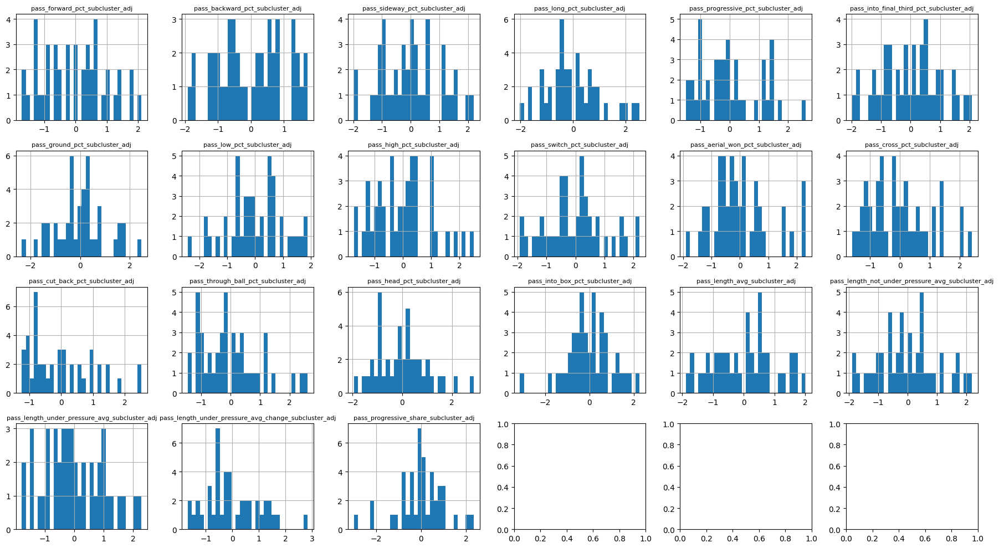

In [1714]:
# split into batches of ~24 features at a time, by conceptual block
passing_cols = [c for c in feature_cols_subcluster_adj if 'pass' in c]
plot_histogram_grid(center_midfields_attack_stats, passing_cols)

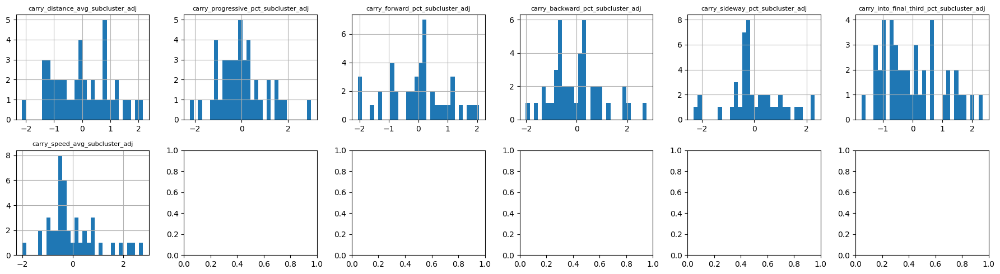

In [1715]:
# split into batches of ~24 features at a time, by conceptual block
carrying_cols = [c for c in feature_cols_subcluster_adj if 'carry' in c]
plot_histogram_grid(center_midfields_attack_stats, carrying_cols)

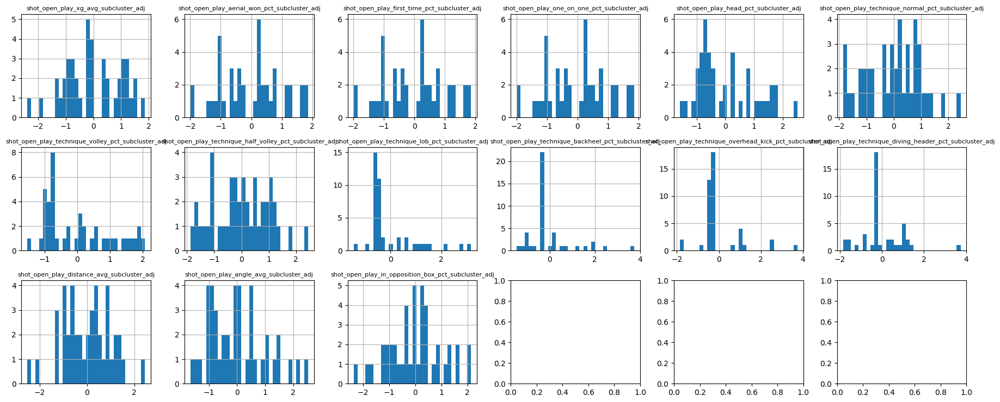

In [1716]:
# split into batches of ~24 features at a time, by conceptual block
shooting_cols = [c for c in feature_cols_subcluster_adj if 'shot' in c]
plot_histogram_grid(center_midfields_attack_stats, shooting_cols)

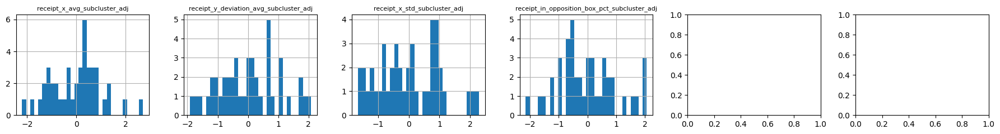

In [1717]:
# split into batches of ~24 features at a time, by conceptual block
receipt_cols = [c for c in feature_cols_subcluster_adj if 'receipt' in c]
plot_histogram_grid(center_midfields_attack_stats, receipt_cols)

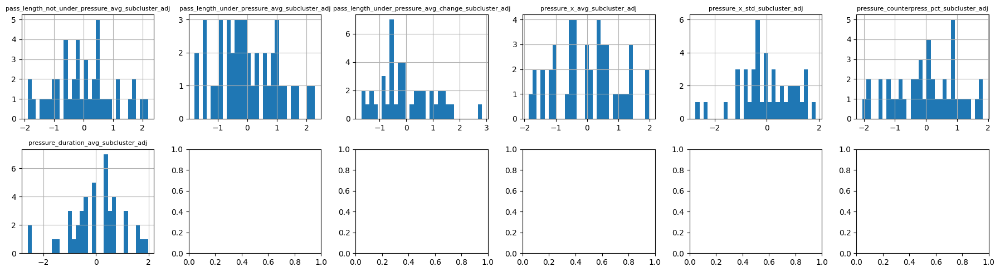

In [1718]:
# split into batches of ~24 features at a time, by conceptual block
pressure_cols = [c for c in feature_cols_subcluster_adj if 'pressure' in c]
plot_histogram_grid(center_midfields_attack_stats, pressure_cols)

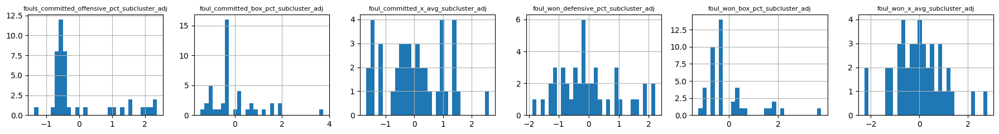

In [1719]:
# split into batches of ~24 features at a time, by conceptual block
foul_cols = [c for c in feature_cols_subcluster_adj if 'foul' in c]
plot_histogram_grid(center_midfields_attack_stats, foul_cols)

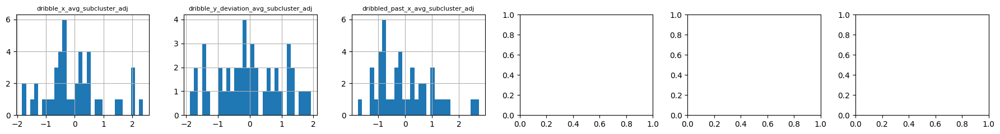

In [1720]:
# split into batches of ~24 features at a time, by conceptual block
dribble_cols = [c for c in feature_cols_subcluster_adj if 'dribble' in c]
plot_histogram_grid(center_midfields_attack_stats, dribble_cols)

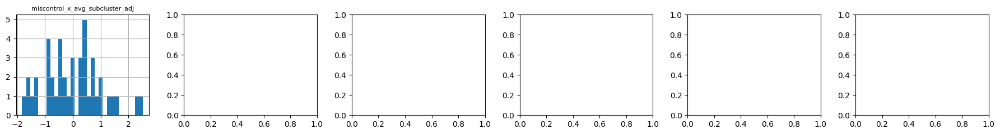

In [1721]:
# split into batches of ~24 features at a time, by conceptual block
miscontrol_cols = [c for c in feature_cols_subcluster_adj if 'miscontrol' in c]
plot_histogram_grid(center_midfields_attack_stats, miscontrol_cols)

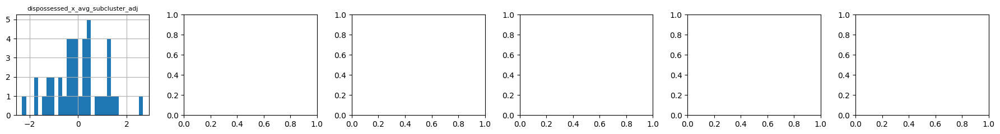

In [1722]:
# split into batches of ~24 features at a time, by conceptual block
dispossessed_cols = [c for c in feature_cols_subcluster_adj if 'dispossessed' in c]
plot_histogram_grid(center_midfields_attack_stats, dispossessed_cols)

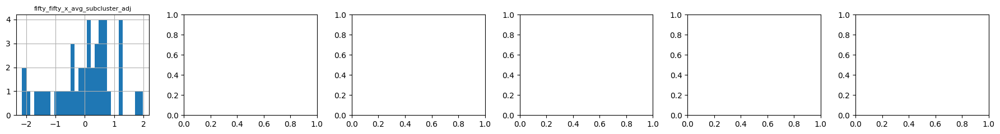

In [1723]:
# split into batches of ~24 features at a time, by conceptual block
fifty_fifty_cols = [c for c in feature_cols_subcluster_adj if 'fifty_fifty' in c]
plot_histogram_grid(center_midfields_attack_stats, fifty_fifty_cols)

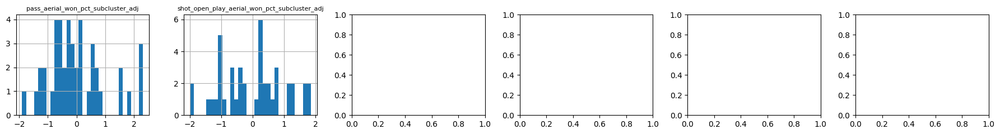

In [1724]:
# split into batches of ~24 features at a time, by conceptual block
aerial_cols = [c for c in feature_cols_subcluster_adj if 'aerial' in c]
plot_histogram_grid(center_midfields_attack_stats, aerial_cols)

In [1725]:
columns_to_drop_distribution = ['pass_progressive_pct', 'pass_into_final_third_pct', 'pass_cut_back_pct',
                                'pass_through_ball_pct', 'pass_head_pct', 'carry_into_final_third_pct',
                                'shot_open_play_head_pct', 'shot_open_play_technique_volley_pct', 'shot_open_play_technique_half_volley_pct',
                                'shot_open_play_technique_lob_pct', 'shot_open_play_technique_backheel_pct', 'shot_open_play_technique_overhead_kick_pct',
                                'shot_open_play_technique_diving_header_pct', 'fouls_committed_offensive_pct', 'foul_committed_box_pct',
                                'foul_won_defensive_pct', 'foul_won_box_pct',]

In [1726]:
center_midfields_attack_stats = center_midfields_attack_stats.drop(columns=columns_to_drop_distribution + [c + '_subcluster_adj' for c in columns_to_drop_distribution])

In [1727]:
center_midfields_attack_stats.shape

(43, 100)

In [1728]:
center_midfields_attack_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_distance_avg',
 'shot_open_play_angle_avg',
 'shot_open_play_in_opposition_box_pct',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'receipt_in_opposition_box_pct',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg'

In [1729]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_distribution]

In [1730]:
feature_cols_subcluster_adj = [c + '_subcluster_adj' for c in feature_cols]

In [1731]:
len(feature_cols)

47

In [1732]:
len(feature_cols_subcluster_adj)

47

#### Observe correlation between variables

In [1733]:
corr_matrix = center_midfields_attack_stats[feature_cols].corr().abs()

In [1734]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [1735]:
high_corr_pairs = (upper.stack()
                   .reset_index()
                   .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'correlation'})
                   .sort_values('correlation', ascending=False))

In [1736]:
# Show all columns
pd.set_option('display.max_columns', None)

pd.set_option('display.max_rows', None)

In [1737]:
high_corr_pairs[high_corr_pairs['correlation'] > 0.8]

,feature_1,feature_2,correlation
529,pass_length_avg,pass_length_not_under_pressure_avg,0.952373
194,pass_ground_pct,pass_high_pct,0.932138
1110,shot_open_play_xg_avg,shot_open_play_angle_avg,0.867971
1346,shot_open_play_distance_avg,shot_open_play_in_opposition_box_pct,0.866914
193,pass_ground_pct,pass_low_pct,0.864866
1345,shot_open_play_distance_avg,shot_open_play_angle_avg,0.863166
1492,receipt_x_avg,pressure_x_avg,0.860614
1690,pressure_x_avg,counterpress_in_opposing_half_pct,0.850193
1109,shot_open_play_xg_avg,shot_open_play_distance_avg,0.838412
721,carry_distance_avg,carry_progressive_pct,0.831177


In [1738]:
# Show all columns
pd.reset_option('display.max_columns')

pd.reset_option('display.max_rows')

In [1739]:
columns_to_drop_correlation = ['shot_open_play_aerial_won_pct', 'shot_open_play_one_on_one_pct', 'shot_open_play_first_time_pct',
                               'pass_length_not_under_pressure_avg', 'shot_open_play_angle_avg', 'shot_open_play_xg_avg',
                               'shot_open_play_in_opposition_box_pct', 'pass_high_pct', 'carry_progressive_pct',
                               'pass_sideway_pct', 'carry_sideway_pct']

In [1740]:
center_midfields_attack_stats = center_midfields_attack_stats.drop(columns=columns_to_drop_correlation + [c + '_subcluster_adj' for c in columns_to_drop_correlation])

In [1741]:
center_midfields_attack_stats.shape

(43, 78)

In [1742]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_correlation]

In [1743]:
feature_cols_subcluster_adj = [c + '_subcluster_adj' for c in feature_cols]

In [1744]:
len(feature_cols)

36

In [1745]:
len(feature_cols_subcluster_adj)

36

In [1746]:
skew_check = center_midfields_attack_stats[feature_cols_subcluster_adj].skew().sort_values(ascending=False)

In [1747]:
skew_check[skew_check.abs() > 1.5]

Series([], dtype: float64)

#### Final feature columns

In [1748]:
final_feature_cols = [c for c in feature_cols]

In [1749]:
final_feature_cols

['pass_forward_pct',
 'pass_backward_pct',
 'pass_long_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_distance_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'receipt_in_opposition_box_pct',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'foul_committed_x_avg',
 'foul_won_x_avg',
 'dribbled_past_x_avg',
 'miscontrol_x_avg',
 'dispossessed_x_avg',
 'fifty_fifty_x_avg',
 'counterpress_in_opposing_half_pct',
 'pass_progressive_share']

In [1750]:
len(final_feature_cols)

36

In [1751]:
final_feature_cols_subcluster_adj = [c + '_subcluster_adj' for c in final_feature_cols]

In [1752]:
final_feature_cols_subcluster_adj

['pass_forward_pct_subcluster_adj',
 'pass_backward_pct_subcluster_adj',
 'pass_long_pct_subcluster_adj',
 'pass_ground_pct_subcluster_adj',
 'pass_low_pct_subcluster_adj',
 'pass_switch_pct_subcluster_adj',
 'pass_aerial_won_pct_subcluster_adj',
 'pass_cross_pct_subcluster_adj',
 'pass_into_box_pct_subcluster_adj',
 'pass_length_avg_subcluster_adj',
 'pass_length_under_pressure_avg_subcluster_adj',
 'pass_length_under_pressure_avg_change_subcluster_adj',
 'carry_distance_avg_subcluster_adj',
 'carry_forward_pct_subcluster_adj',
 'carry_backward_pct_subcluster_adj',
 'carry_speed_avg_subcluster_adj',
 'dribble_x_avg_subcluster_adj',
 'dribble_y_deviation_avg_subcluster_adj',
 'shot_open_play_technique_normal_pct_subcluster_adj',
 'shot_open_play_distance_avg_subcluster_adj',
 'receipt_x_avg_subcluster_adj',
 'receipt_y_deviation_avg_subcluster_adj',
 'receipt_x_std_subcluster_adj',
 'receipt_in_opposition_box_pct_subcluster_adj',
 'pressure_x_avg_subcluster_adj',
 'pressure_x_std_subcl

In [1753]:
len(final_feature_cols_subcluster_adj)

36

#### Detect outliers

In [1754]:
outliers_zscore = detect_outliers_zscore(center_midfields_attack_stats, final_feature_cols_subcluster_adj, player_id_to_player, team_id_to_team)

In [1755]:
for col, rows in outliers_zscore.items():
    print(f"\n--- {col} ---")
    print(rows.sort_values('z_score', ascending=False))


--- pass_into_box_pct_subcluster_adj ---
                                                    league  \
player_id team_id position_group                             
19416.0   746     Center Midfield  FA Women's Super League   

                                   pass_into_box_pct_subcluster_adj  \
player_id team_id position_group                                      
19416.0   746     Center Midfield                         -3.126481   

                                   player_id  team_id   z_score        player  \
player_id team_id position_group                                                
19416.0   746     Center Midfield    19416.0      746  3.126481  Laura Coombs   

                                                  team  
player_id team_id position_group                        
19416.0   746     Center Midfield  Manchester City WFC  


In [1756]:
outliers_iqr = detect_outliers_iqr(center_midfields_attack_stats, final_feature_cols_subcluster_adj, player_id_to_player, team_id_to_team)

In [1757]:
for col, rows in outliers_iqr.items():
    print(f"\n--- {col} ---")
    print(rows)


--- pass_long_pct_subcluster_adj ---
                                                    league  \
player_id team_id position_group                             
46740.0   749     Center Midfield  FA Women's Super League   

                                   pass_long_pct_subcluster_adj  player_id  \
player_id team_id position_group                                             
46740.0   749     Center Midfield                      2.532395    46740.0   

                                   team_id         player  \
player_id team_id position_group                            
46740.0   749     Center Midfield      749  Grace Clinton   

                                                      team  bound_distance  
player_id team_id position_group                                            
46740.0   749     Center Midfield  Tottenham Hotspur Women          0.2048  

--- pass_ground_pct_subcluster_adj ---
                                                    league  \
player_id team_id posit

In [1758]:
all_flagged_players_zscore = []

In [1759]:
for col, rows in outliers_zscore.items():
    all_flagged_players_zscore.extend(rows['player_id'].tolist())

In [1760]:
flag_counts_zscore = pd.Series(Counter(all_flagged_players_zscore)).sort_values(ascending=False)

In [1761]:
flag_counts_zscore

19416.0    1
dtype: int64

In [1762]:
all_flagged_players_iqr = []

In [1763]:
for col, rows in outliers_iqr.items():
    all_flagged_players_iqr.extend(rows['player_id'].tolist())

In [1764]:
flag_counts_iqr = pd.Series(Counter(all_flagged_players_iqr)).sort_values(ascending=False)

In [1765]:
flag_counts_iqr

33675.0     2
52284.0     2
19498.0     2
50098.0     2
46984.0     2
32232.0     2
46740.0     1
19416.0     1
50102.0     1
24392.0     1
123549.0    1
10516.0     1
4638.0      1
32215.0     1
15284.0     1
15716.0     1
325074.0    1
32845.0     1
dtype: int64

In [1766]:
keys = ['player_id', 'team_id', 'league', 'position_group']

In [1767]:
winsorize_cols = ['pass_long_pct_subcluster_adj', 'pass_ground_pct_subcluster_adj', 'pass_switch_pct_subcluster_adj', 'pass_into_box_pct_subcluster_adj', 
                  'pass_length_under_pressure_avg_change_subcluster_adj', 'carry_backward_pct_subcluster_adj', 'carry_speed_avg_subcluster_adj',
                  'dribble_x_avg_subcluster_adj', 'receipt_x_avg_subcluster_adj', 'pressure_x_std_subcluster_adj', 'pressure_duration_avg_subcluster_adj',
                  'foul_won_x_avg_subcluster_adj', 'dispossessed_x_avg_subcluster_adj', 'pass_progressive_share_subcluster_adj']

In [1768]:
for col in winsorize_cols:
    center_midfields_attack_stats[col] = winsorize(center_midfields_attack_stats[col])

In [1769]:
imputation_configs = [
    dict(position_group='Center Midfield', pct_col='dribble_x_avg',
        attempted_col='dribbles_attempted', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='pressure_x_std',
        attempted_col='pressures_applied', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='pressure_duration_avg',
        attempted_col='pressures_applied', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='foul_won_x_avg',
        attempted_col='fouls_won', min_quantile=0.2),
    dict(position_group='Center Midfield', pct_col='dispossessed_x_avg',
        attempted_col='dispossesseds', min_quantile=0.2),
]

In [1770]:
stats_by_position_cma = {
    'Center Midfield': center_midfields_attack_stats,
}

In [1771]:
for cfg in imputation_configs:
    pos, pct_col = cfg['position_group'], cfg['pct_col']
    target_df = stats_by_position_cma[pos]
    
    # reads eligibility/reliable-group-mean from all_players_stats (untouched, read-only),
    # writes the imputed value into target_df only
    target_df = impute_unreliable_rate_stat(all_players_stats_cm, target_df, **cfg)

    # residualize on target_df itself, using its now-imputed raw value as input
    refit = residualize(
        target_df, feature_cols=[pct_col], covariate_col='context_score',
        group_cols=['position_group'], robust=True,
    )
    target_df[pct_col + '_subcluster_adj'] = refit[pct_col + '_subcluster_adj']

    stats_by_position_cma[pos] = target_df

#### Rank features on percentile

In [1772]:
center_midfields_attack_stats = to_percentile(center_midfields_attack_stats, final_feature_cols)      # raw

In [1773]:
center_midfields_attack_stats = to_percentile(center_midfields_attack_stats, final_feature_cols_subcluster_adj) # adjusted

#### Divide features into groups

In [1774]:
feature_groups = {
    'passing_share': [
        'pass_forward_pct', 'pass_backward_pct', 'pass_ground_pct', 'pass_low_pct', 'pass_switch_pct', 
        'pass_aerial_won_pct', 'pass_cross_pct', 'pass_into_box_pct', 'pass_long_pct', 'pass_progressive_share'
    ],
    'passing_length': [
        'pass_length_avg', 'pass_length_under_pressure_avg', 'pass_length_under_pressure_avg_change'
    ],
    'carrying': [
        'carry_distance_avg', 'carry_forward_pct', 'carry_backward_pct', 'carry_speed_avg'
    ],
    'dribbling': [
        'dribble_x_avg', 'dribble_y_deviation_avg'
    ],
    'shooting': [
        'shot_open_play_technique_normal_pct', 'shot_open_play_distance_avg'
    ],
    'receipt': [
        'receipt_x_avg', 'receipt_y_deviation_avg', 'receipt_x_std', 'receipt_in_opposition_box_pct'
    ],
    'defending': [
        'pressure_x_avg', 'pressure_x_std', 'pressure_counterpress_pct', 'pressure_duration_avg', 'foul_won_x_avg', 'counterpress_in_opposing_half_pct'
    ],
    'vulnerability_fifty_fifty': [
        'dribbled_past_x_avg', 'foul_committed_x_avg', 'miscontrol_x_avg', 'dispossessed_x_avg', 'fifty_fifty_x_avg'
    ]
}

In [1775]:
feature_groups_subcluster_adj = {
    category: [f + '_subcluster_adj' for f in features]
    for category, features in feature_groups.items()
}

In [1776]:
n_per_category = {
    'passing_share': 5, 'passing_length': 1, 'carrying': 3, 'dribbling': 1, 'shooting': 1, 'receipt': 2, 'defending': 4, 'vulnerability_fifty_fifty': 2
}

In [1777]:
all_grouped = [c for group in feature_groups.values() for c in group]

In [1778]:
missing = set(final_feature_cols) - set(all_grouped)

In [1779]:
missing

set()

In [1780]:
spare = set(all_grouped) - set(final_feature_cols)

In [1781]:
spare

set()

#### KMeans Clustering

##### PCA

In [1782]:
X = center_midfields_attack_stats[final_feature_cols_subcluster_adj]

In [1783]:
n_features = 7

In [1784]:
pca_reduced_final = PCA(n_components=n_features)

In [1785]:
pca_reduced_final.set_output(transform='pandas')

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",7
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

In [1786]:
X_pca_final = pca_reduced_final.fit_transform(X)

##### KMeans with k = 2

In [1787]:
k = 2

In [1788]:
kmeans_2 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1789]:
center_midfields_attack_stats['kmeans_2_cluster'] = kmeans_2.fit_predict(X_pca_final)  # or X, if using raw features

In [1790]:
# bring labels back to the original unstandardized data for interpretation
center_midfields_attack_stats['kmeans_2_cluster'] = center_midfields_attack_stats['kmeans_2_cluster'].values

In [1791]:
center_midfields_attack_stats['kmeans_2_cluster'].value_counts()

kmeans_2_cluster
1    22
0    21
Name: count, dtype: int64

In [1792]:
center_midfields_attack_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_2, 
    stats_df=center_midfields_attack_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 3

In [1793]:
k = 3

In [1794]:
kmeans_3 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1795]:
center_midfields_attack_stats['kmeans_3_cluster'] = kmeans_3.fit_predict(X_pca_final)  # or X, if using raw features

In [1796]:
# bring labels back to the original unstandardized data for interpretation
center_midfields_attack_stats['kmeans_3_cluster'] = center_midfields_attack_stats['kmeans_3_cluster'].values

In [1797]:
center_midfields_attack_stats['kmeans_3_cluster'].value_counts()

kmeans_3_cluster
2    20
1    16
0     7
Name: count, dtype: int64

In [1798]:
center_midfields_attack_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_3, 
    stats_df=center_midfields_attack_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 4

In [1799]:
k = 4

In [1800]:
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

In [1801]:
center_midfields_attack_stats['kmeans_4_cluster'] = kmeans_4.fit_predict(X_pca_final)  # or X, if using raw features

In [1802]:
# bring labels back to the original unstandardized data for interpretation
center_midfields_attack_stats['kmeans_4_cluster'] = center_midfields_attack_stats['kmeans_4_cluster'].values

In [1803]:
center_midfields_attack_stats['kmeans_4_cluster'].value_counts()

kmeans_4_cluster
1    20
3    12
0     6
2     5
Name: count, dtype: int64

In [1804]:
center_midfields_attack_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_4, 
    stats_df=center_midfields_attack_stats,
    sigma_quantile=0.5
)

### Wingers

#### Filter by position

In [1805]:
wingers_stats.shape

(85, 347)

In [1806]:
wingers_stats.columns.tolist()

['passes_attempted',
 'pass_completion_pct',
 'pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_under_pressure_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_deflected_pct',
 'pass_goal_assist_pct',
 'pass_miscommunication_pct',
 'pass_no_touch_pct',
 'pass_shot_assist_pct',
 'pass_through_ball_pct',
 'pass_create_shot_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_deep_completion_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_aerial_won_completion_pct',
 'pass_cross_completion_pct',
 'pass_cut_back_completion_pct',
 'pass_deflected_completion_pct',
 'pass_no_touch_completion_pct',
 'pass_switch_completion_pct',
 'pass_through_ball_completion_pct',
 'pass_forward_complet

In [1807]:
wingers_stats = wingers_stats[style_feature_cols + style_feature_cols_adj + ['league', 'minutes_at_position', 'context_score']]

In [1808]:
wingers_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_no_touch_pct',
 'pass_through_ball_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_o

In [1809]:
columns_to_drop_irrelevant = ['pass_aerial_won_pct',
 'pass_no_touch_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'shot_open_play_left_foot_pct',
 'shot_open_play_right_foot_pct',
 'shot_open_play_head_pct',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'clearance_box_pct',
 'recovery_x_avg',
 'recovery_in_opposing_half_pct',
 'block_shot_pct',
 'block_in_box_pct',
 'block_x_avg',
 'block_x_std',
 'interception_x_avg',
 'interception_x_std',
 'interception_counterpress_pct',
 'foul_committed_box_pct',
 'dribbled_past_x_avg',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_moving_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_feet_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_sweeps_x_avg',
 'defensive_actions_x_avg',
 'defensive_actions_x_std',
]

In [1810]:
wingers_stats = wingers_stats.drop(columns=columns_to_drop_irrelevant + [c + '_adj' for c in columns_to_drop_irrelevant])

In [1811]:
wingers_stats.shape

(85, 123)

In [1812]:
wingers_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_through_ball_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_technique_volley_pct',
 'shot_open_play_technique_half_volley_pct',
 'shot_open_play_technique_lob_pct',
 'shot_open_play_technique_backheel_

In [1813]:
wingers_stats.shape

(85, 123)

In [1814]:
feature_cols = [c for c in style_feature_cols if c not in columns_to_drop_irrelevant]

In [1815]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1816]:
len(feature_cols)

60

In [1817]:
len(feature_cols_adj)

60

#### Observe distribution of stats

In [1818]:
summary = wingers_stats[feature_cols_adj].describe().T
summary['skew'] = wingers_stats[feature_cols_adj].skew()
summary['pct_zero'] = (wingers_stats[feature_cols_adj] == 0).mean()
summary['pct_missing'] = wingers_stats[feature_cols_adj].isna().mean()
summary.sort_values('skew', ascending=False)

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing
shot_open_play_technique_overhead_kick_pct_adj,85.0,6.661338e-17,1.005935,-1.615699,-0.311032,-0.218218,-0.200000,5.000000,3.403659,0.0,0.0
shot_open_play_technique_backheel_pct_adj,85.0,-3.918434e-18,1.005935,-0.438015,-0.391786,-0.266910,-0.218218,4.582576,3.336530,0.0,0.0
shot_open_play_technique_lob_pct_adj,85.0,-1.306145e-17,1.005935,-0.702231,-0.299261,-0.271244,-0.267261,4.417410,2.956478,0.0,0.0
foul_won_box_pct_adj,85.0,3.134747e-17,1.005935,-0.578893,-0.493735,-0.467155,-0.390375,3.180286,2.006046,0.0,0.0
foul_won_defensive_pct_adj,85.0,-3.134747e-17,1.005935,-1.570013,-0.717186,-0.206169,0.286665,3.690275,1.571460,0.0,0.0
fouls_committed_offensive_pct_adj,85.0,7.477679e-17,1.005935,-0.853606,-0.755552,-0.460411,0.755560,3.254238,1.259511,0.0,0.0
pass_long_pct_adj,85.0,-3.265362e-18,1.005935,-1.844616,-0.745379,-0.141306,0.446135,3.470826,0.865317,0.0,0.0
shot_open_play_technique_volley_pct_adj,85.0,3.657205e-17,1.005935,-1.393370,-0.965845,-0.130383,0.759037,3.230480,0.847868,0.0,0.0
shot_open_play_xg_avg_adj,85.0,-1.697988e-17,1.005935,-2.132715,-0.738299,-0.160526,0.596586,3.301514,0.815688,0.0,0.0
pass_length_under_pressure_avg_adj,85.0,1.828603e-17,1.005935,-1.724037,-0.710160,-0.140523,0.670626,3.172802,0.811603,0.0,0.0


In [1819]:
summary.shape

(60, 11)

In [1820]:
low_variance = summary[summary['std'] / summary['mean'].abs() < 0.1]

In [1821]:
low_variance

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing


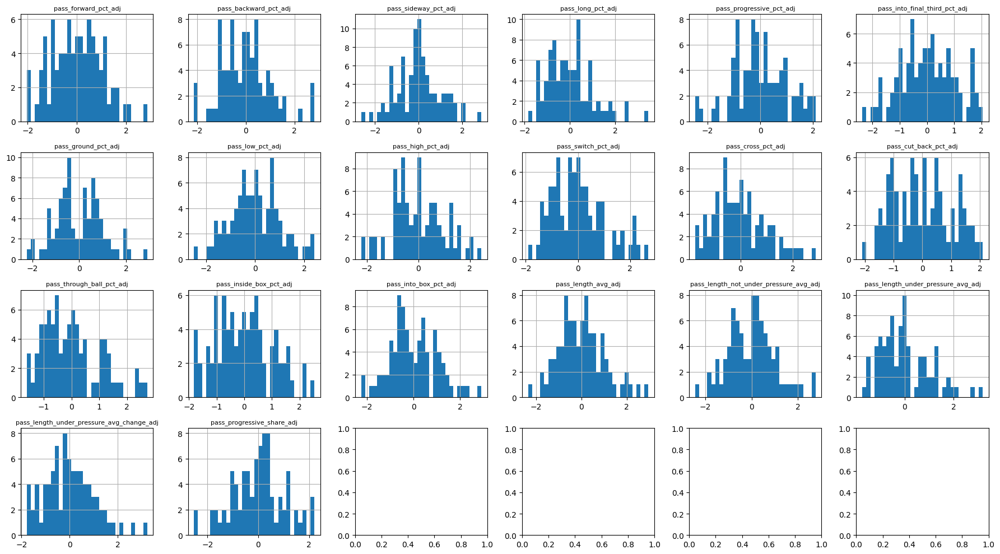

In [1822]:
# split into batches of ~24 features at a time, by conceptual block
passing_cols = [c for c in feature_cols_adj if 'pass' in c]
plot_histogram_grid(wingers_stats, passing_cols)

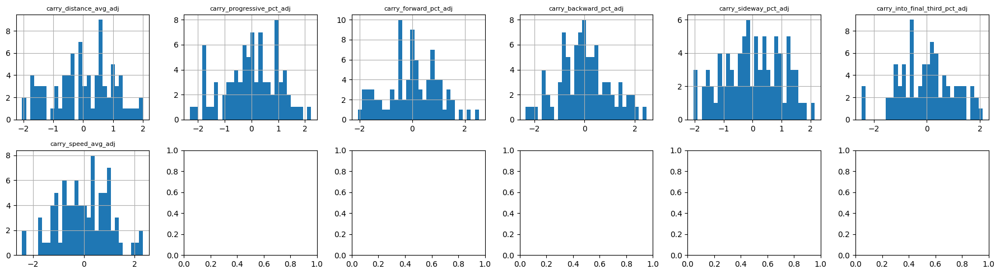

In [1823]:
# split into batches of ~24 features at a time, by conceptual block
carrying_cols = [c for c in feature_cols_adj if 'carry' in c]
plot_histogram_grid(wingers_stats, carrying_cols)

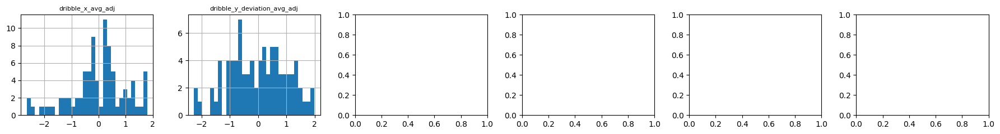

In [1824]:
# split into batches of ~24 features at a time, by conceptual block
dribbling_cols = [c for c in feature_cols_adj if 'dribble' in c]
plot_histogram_grid(wingers_stats, dribbling_cols)

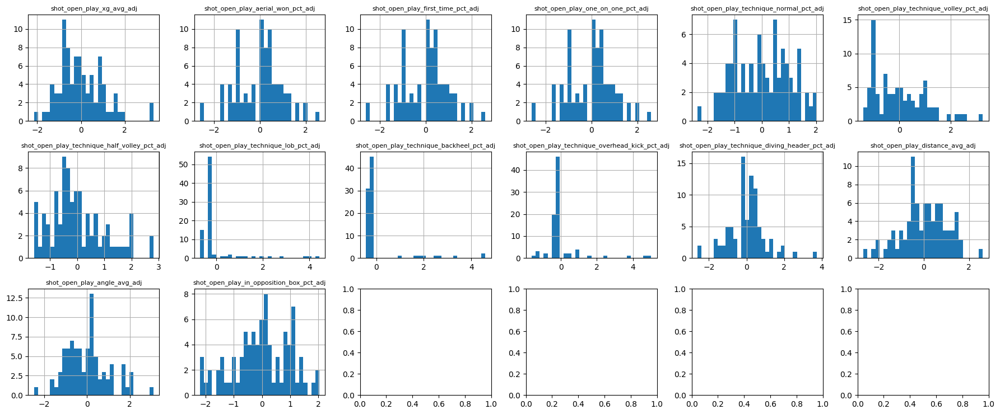

In [1825]:
# split into batches of ~24 features at a time, by conceptual block
shot_cols = [c for c in feature_cols_adj if 'shot' in c]
plot_histogram_grid(wingers_stats, shot_cols)

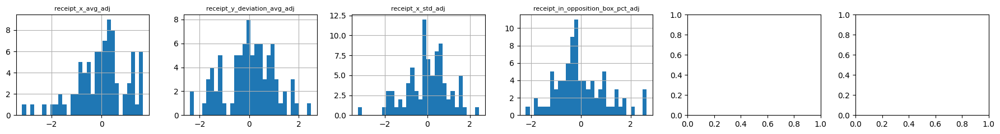

In [1826]:
# split into batches of ~24 features at a time, by conceptual block
receipt_cols = [c for c in feature_cols_adj if 'receipt' in c]
plot_histogram_grid(wingers_stats, receipt_cols)

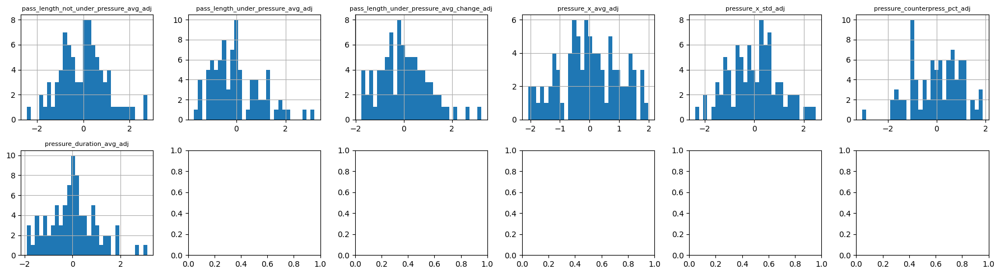

In [1827]:
# split into batches of ~24 features at a time, by conceptual block
pressure_cols = [c for c in feature_cols_adj if 'pressure' in c]
plot_histogram_grid(wingers_stats, pressure_cols)

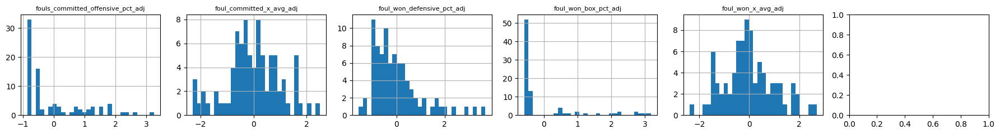

In [1828]:
# split into batches of ~24 features at a time, by conceptual block
foul_cols = [c for c in feature_cols_adj if 'foul' in c]
plot_histogram_grid(wingers_stats, foul_cols)

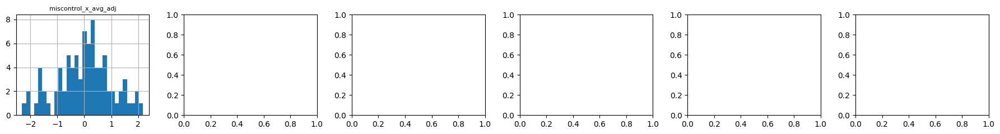

In [1829]:
# split into batches of ~24 features at a time, by conceptual block
miscontrol_cols = [c for c in feature_cols_adj if 'miscontrol' in c]
plot_histogram_grid(wingers_stats, miscontrol_cols)

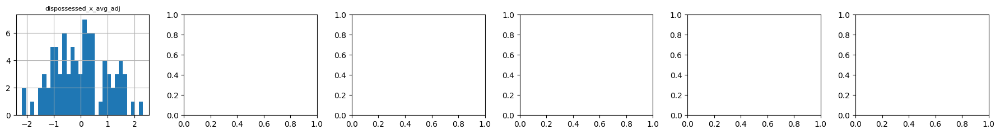

In [1830]:
# split into batches of ~24 features at a time, by conceptual block
dispossessed_cols = [c for c in feature_cols_adj if 'dispossessed' in c]
plot_histogram_grid(wingers_stats, dispossessed_cols)

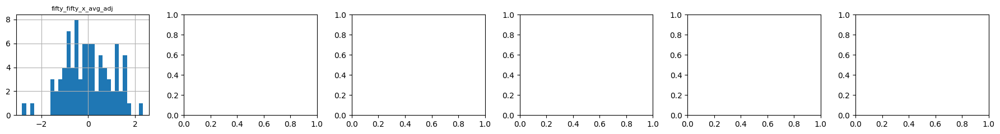

In [1831]:
# split into batches of ~24 features at a time, by conceptual block
fifty_fifty_cols = [c for c in feature_cols_adj if 'fifty_fifty' in c]
plot_histogram_grid(wingers_stats, fifty_fifty_cols)

In [1832]:
columns_to_drop_distribution = ['shot_open_play_technique_volley_pct', 'shot_open_play_technique_half_volley_pct', 'shot_open_play_technique_lob_pct',
                                'shot_open_play_technique_backheel_pct', 'shot_open_play_technique_overhead_kick_pct', 'shot_open_play_technique_diving_header_pct',
                                'fouls_committed_offensive_pct', 'foul_won_defensive_pct', 'foul_won_box_pct']

In [1833]:
wingers_stats = wingers_stats.drop(columns=columns_to_drop_distribution + [c + '_adj' for c in columns_to_drop_distribution])

In [1834]:
wingers_stats.shape

(85, 105)

In [1835]:
wingers_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_through_ball_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_distance_avg',
 'shot_open_play_angle_avg',
 'shot_open_play_in_opposition_box_pct',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_

In [1836]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_distribution]

In [1837]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1838]:
len(feature_cols)

51

In [1839]:
len(feature_cols_adj)

51

#### Observe correlation between variables

In [1840]:
corr_matrix = wingers_stats[feature_cols_adj].corr().abs()

In [1841]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [1842]:
high_corr_pairs = (upper.stack()
                   .reset_index()
                   .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'correlation'})
                   .sort_values('correlation', ascending=False))

In [1843]:
high_corr_pairs[high_corr_pairs['correlation'] > 0.8]

,feature_1,feature_2,correlation
1561,shot_open_play_first_time_pct_adj,shot_open_play_one_on_one_pct_adj,1.000000
1509,shot_open_play_aerial_won_pct_adj,shot_open_play_first_time_pct_adj,1.000000
1510,shot_open_play_aerial_won_pct_adj,shot_open_play_one_on_one_pct_adj,1.000000
781,pass_length_avg_adj,pass_length_not_under_pressure_avg_adj,0.975430
314,pass_ground_pct_adj,pass_high_pct_adj,0.933595
989,carry_distance_avg_adj,carry_progressive_pct_adj,0.919399
168,pass_long_pct_adj,pass_length_avg_adj,0.906601
169,pass_long_pct_adj,pass_length_not_under_pressure_avg_adj,0.887732
1718,shot_open_play_distance_avg_adj,shot_open_play_in_opposition_box_pct_adj,0.824790
1717,shot_open_play_distance_avg_adj,shot_open_play_angle_avg_adj,0.824280


In [1844]:
columns_to_drop_correlation = ['pass_sideway_pct', 'shot_open_play_aerial_won_pct', 'shot_open_play_one_on_one_pct', 'shot_open_play_first_time_pct',
                               'pass_length_not_under_pressure_avg', 'pass_high_pct', 'pass_long_pct', 'shot_open_play_in_opposition_box_pct',
                               'shot_open_play_angle_avg', 'pass_length_under_pressure_avg', 'carry_sideway_pct']

In [1845]:
wingers_stats = wingers_stats.drop(columns=columns_to_drop_correlation)

In [1846]:
wingers_stats.shape

(85, 94)

In [1847]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_correlation]

In [1848]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1849]:
skew_check = wingers_stats[feature_cols_adj].skew().sort_values(ascending=False)

In [1850]:
skew_check[skew_check.abs() > 1.5]

Series([], dtype: float64)

#### Final feature columns

In [1851]:
final_feature_cols = [c for c in feature_cols]

In [1852]:
final_feature_cols

['pass_forward_pct',
 'pass_backward_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_switch_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_through_ball_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_distance_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'receipt_in_opposition_box_pct',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'foul_committed_x_avg',
 'foul_won_x_avg',
 'miscontrol_x_avg',
 'dispossessed_x_avg',
 'fifty_fifty_x_avg',
 'counterpress_in_opposing_half_pct',
 'pass_progressive_share']

In [1853]:
len(final_feature_cols)

40

In [1854]:
final_feature_cols_adj = [c + '_adj' for c in final_feature_cols]

In [1855]:
final_feature_cols_adj

['pass_forward_pct_adj',
 'pass_backward_pct_adj',
 'pass_progressive_pct_adj',
 'pass_into_final_third_pct_adj',
 'pass_ground_pct_adj',
 'pass_low_pct_adj',
 'pass_switch_pct_adj',
 'pass_cross_pct_adj',
 'pass_cut_back_pct_adj',
 'pass_through_ball_pct_adj',
 'pass_inside_box_pct_adj',
 'pass_into_box_pct_adj',
 'pass_length_avg_adj',
 'pass_length_under_pressure_avg_change_adj',
 'carry_distance_avg_adj',
 'carry_progressive_pct_adj',
 'carry_forward_pct_adj',
 'carry_backward_pct_adj',
 'carry_into_final_third_pct_adj',
 'carry_speed_avg_adj',
 'dribble_x_avg_adj',
 'dribble_y_deviation_avg_adj',
 'shot_open_play_xg_avg_adj',
 'shot_open_play_technique_normal_pct_adj',
 'shot_open_play_distance_avg_adj',
 'receipt_x_avg_adj',
 'receipt_y_deviation_avg_adj',
 'receipt_x_std_adj',
 'receipt_in_opposition_box_pct_adj',
 'pressure_x_avg_adj',
 'pressure_x_std_adj',
 'pressure_counterpress_pct_adj',
 'pressure_duration_avg_adj',
 'foul_committed_x_avg_adj',
 'foul_won_x_avg_adj',
 'mis

In [1856]:
len(final_feature_cols_adj)

40

#### Detect outliers

In [1857]:
outliers_zscore = detect_outliers_zscore(wingers_stats, final_feature_cols, player_id_to_player, team_id_to_team)

In [1858]:
for col, rows in outliers_zscore.items():
    print(f"\n--- {col} ---")
    print(rows.sort_values('z_score', ascending=False))


--- pass_forward_pct ---
                                             league  pass_forward_pct  \
player_id team_id position_group                                        
135263.0  3165    Winger          Frauen Bundesliga          0.367257   

                                  player_id  team_id   z_score  \
player_id team_id position_group                                 
135263.0  3165    Winger           135263.0     3165  3.455463   

                                                player         team  
player_id team_id position_group                                     
135263.0  3165    Winger          Alicia-Sophie Gudorf  SC Freiburg  

--- pass_backward_pct ---
                                         league  pass_backward_pct  player_id  \
player_id team_id position_group                                                
45638.0   1076    Winger          Serie A Women           0.311475    45638.0   

                                  team_id   z_score         player        

In [1859]:
outliers_iqr = detect_outliers_iqr(wingers_stats, final_feature_cols, player_id_to_player, team_id_to_team)

In [1860]:
for col, rows in outliers_iqr.items():
    print(f"\n--- {col} ---")
    print(rows)


--- pass_forward_pct ---
                                             league  pass_forward_pct  \
player_id team_id position_group                                        
135263.0  3165    Winger          Frauen Bundesliga          0.367257   

                                  player_id  team_id                player  \
player_id team_id position_group                                             
135263.0  3165    Winger           135263.0     3165  Alicia-Sophie Gudorf   

                                         team  bound_distance  
player_id team_id position_group                               
135263.0  3165    Winger          SC Freiburg        0.043366  

--- pass_backward_pct ---
                                         league  pass_backward_pct  player_id  \
player_id team_id position_group                                                
45638.0   1076    Winger          Serie A Women           0.311475    45638.0   

                                  team_id         player

In [1861]:
all_flagged_players_zscore = []

In [1862]:
for col, rows in outliers_zscore.items():
    all_flagged_players_zscore.extend(rows['player_id'].tolist())

In [1863]:
flag_counts_zscore = pd.Series(Counter(all_flagged_players_zscore)).sort_values(ascending=False)                               

In [1864]:
flag_counts_zscore

46953.0     2
126507.0    2
15570.0     2
10386.0     2
409155.0    1
45638.0     1
112522.0    1
135263.0    1
4654.0      1
50999.0     1
46941.0     1
18153.0     1
10258.0     1
32838.0     1
185543.0    1
24373.0     1
dtype: int64

In [1865]:
all_flagged_players_iqr = []

In [1866]:
for col, rows in outliers_iqr.items():
    all_flagged_players_iqr.extend(rows['player_id'].tolist())

In [1867]:
flag_counts_iqr = pd.Series(Counter(all_flagged_players_iqr)).sort_values(ascending=False)

In [1868]:
flag_counts_iqr

10386.0     6
15570.0     3
408655.0    3
32838.0     3
10392.0     3
46953.0     2
31539.0     2
10258.0     2
185543.0    2
24373.0     2
126507.0    2
135263.0    2
46947.0     1
46877.0     1
15613.0     1
409155.0    1
95784.0     1
45739.0     1
45638.0     1
10514.0     1
112522.0    1
18153.0     1
328392.0    1
50999.0     1
4654.0      1
21059.0     1
46941.0     1
49991.0     1
46894.0     1
dtype: int64

In [1869]:
winsorize_cols = ['pass_forward_pct_adj', 'pass_backward_pct_adj', 'pass_ground_pct_adj', 'pass_switch_pct_adj',
                  'pass_cross_pct_adj', 'pass_through_ball_pct_adj', 'pass_inside_box_pct_adj', 'pass_into_box_pct_adj',
                  'pass_length_avg_adj', 'pass_length_under_pressure_avg_change_adj', 'carry_backward_pct_adj',
                  'dribble_x_avg_adj', 'shot_open_play_xg_avg_adj', 'shot_open_play_distance_avg_adj', 'receipt_x_avg_adj',
                  'receipt_y_deviation_avg_adj', 'receipt_x_std_adj', 'receipt_in_opposition_box_pct_adj', 
                  'pressure_duration_avg_adj', 'foul_won_x_avg_adj', 'fifty_fifty_x_avg_adj', 'pass_progressive_share_adj']

In [1870]:
for col in winsorize_cols:
    wingers_stats[col] = winsorize(wingers_stats[col])

In [1871]:
imputation_configs = [
    dict(position_group='Winger', pct_col='dribble_x_avg',
        attempted_col='dribbles_attempted', min_quantile=0.2),
    dict(position_group='Winger', pct_col='shot_open_play_xg_avg',
        attempted_col='shots_open_play_attempted', min_quantile=0.2),
    dict(position_group='Winger', pct_col='shot_open_play_distance_avg',
        attempted_col='shots_open_play_attempted', min_quantile=0.2),
    dict(position_group='Winger', pct_col='foul_won_x_avg',
        attempted_col='fouls_won', min_quantile=0.2),
    dict(position_group='Winger', pct_col='fifty_fifty_x_avg',
        attempted_col='fifty_fiftys', min_quantile=0.2),
]

In [1872]:
for cfg in imputation_configs:
    pos, pct_col = cfg['position_group'], cfg['pct_col']
    target_df = stats_by_position[pos]
    
    # reads eligibility/reliable-group-mean from all_players_stats (untouched, read-only),
    # writes the imputed value into target_df only
    target_df = impute_unreliable_rate_stat(all_players_stats, target_df, **cfg)

    # residualize on target_df itself, using its now-imputed raw value as input
    refit = residualize(
        target_df, feature_cols=[pct_col], covariate_col='context_score',
        group_cols=['position_group'], robust=True,
    )
    target_df[pct_col + '_adj'] = refit[pct_col + '_adj']

    stats_by_position[pos] = target_df

#### Rank features on percentile

In [1873]:
wingers_stats = to_percentile(wingers_stats, final_feature_cols)      # raw

In [1874]:
wingers_stats = to_percentile(wingers_stats, final_feature_cols_adj) # adjusted

#### Divide features into groups

In [1875]:
feature_groups = {
    'passing_share': [
        'pass_forward_pct', 'pass_backward_pct', 'pass_progressive_pct', 'pass_into_final_third_pct', 'pass_ground_pct',
        'pass_low_pct', 'pass_switch_pct', 'pass_cross_pct', 'pass_cut_back_pct', 'pass_through_ball_pct', 
        'pass_inside_box_pct', 'pass_into_box_pct', 'pass_progressive_share'
    ],
    'passing_length': [
        'pass_length_avg', 'pass_length_under_pressure_avg_change'
    ],
    'carrying': [
        'carry_distance_avg', 'carry_forward_pct', 'carry_backward_pct', 'carry_into_final_third_pct', 'carry_speed_avg', 'carry_progressive_pct'
    ],
    'dribbling': [
        'dribble_x_avg', 'dribble_y_deviation_avg'
    ],
    'shooting': [
        'shot_open_play_xg_avg', 'shot_open_play_technique_normal_pct', 'shot_open_play_distance_avg'
    ],
    'receipt': [
        'receipt_x_avg', 'receipt_y_deviation_avg', 'receipt_x_std', 'receipt_in_opposition_box_pct'
    ],
    'defending': [
        'pressure_x_avg', 'pressure_x_std', 'pressure_counterpress_pct', 'pressure_duration_avg', 'foul_won_x_avg', 'counterpress_in_opposing_half_pct'
    ],
    'vulnerability_fifty_fifty': [
        'foul_committed_x_avg', 'miscontrol_x_avg', 'dispossessed_x_avg', 'fifty_fifty_x_avg'
    ]
}

In [1876]:
feature_groups_adj = {
    category: [f + '_adj' for f in features]
    for category, features in feature_groups.items()
}

In [1877]:
n_per_category = {
    'passing_share': 8, 'passing_length': 1, 'carrying': 4, 'dribbling': 2, 'shooting': 2, 'receipt': 2, 'defending': 3, 'vulnerability_fifty_fifty': 2
}

In [1878]:
all_grouped = [c for group in feature_groups.values() for c in group]

In [1879]:
missing = set(final_feature_cols) - set(all_grouped)

In [1880]:
missing

set()

In [1881]:
spare = set(all_grouped) - set(final_feature_cols) 

In [1882]:
spare

set()

In [1883]:
scaled_frames = []

In [1884]:
for league, group in wingers_stats.groupby('league'):
    scaler = StandardScaler()
    scaled_values = scaler.fit_transform(group[final_feature_cols])
    scaled_df = pd.DataFrame(scaled_values, columns=final_feature_cols, index=group.index)
    scaled_df['league'] = group['league']  # only 'league' needs reattaching -- it's not an index level
    scaled_frames.append(scaled_df)

#### KMeans Clustering

##### PCA

In [1885]:
X = wingers_stats[final_feature_cols_adj]

In [1886]:
n_features = 20

In [1887]:
pca_reduced_final = PCA(n_components=n_features)

In [1888]:
pca_reduced_final.set_output(transform='pandas')

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",20
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD

In [1889]:
X_pca_final = pca_reduced_final.fit_transform(X)

##### KMeans with k = 2

In [1890]:
k = 2

In [1891]:
kmeans_2 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1892]:
wingers_stats['kmeans_2_cluster'] = kmeans_2.fit_predict(X_pca_final)  # or X, if using raw features

In [1893]:
# bring labels back to the original unstandardized data for interpretation
wingers_stats['kmeans_2_cluster'] = wingers_stats['kmeans_2_cluster'].values

In [1894]:
wingers_stats['kmeans_2_cluster'].value_counts()

kmeans_2_cluster
1    47
0    38
Name: count, dtype: int64

In [1895]:
wingers_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_2, 
    stats_df=wingers_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 3

In [1896]:
k = 3

In [1897]:
kmeans_3 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1898]:
wingers_stats['kmeans_3_cluster'] = kmeans_3.fit_predict(X_pca_final)  # or X, if using raw features

In [1899]:
# bring labels back to the original unstandardized data for interpretation
wingers_stats['kmeans_3_cluster'] = wingers_stats['kmeans_3_cluster'].values

In [1900]:
wingers_stats['kmeans_3_cluster'].value_counts()

kmeans_3_cluster
0    46
1    21
2    18
Name: count, dtype: int64

In [1901]:
wingers_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_3, 
    stats_df=wingers_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 4

In [1902]:
k = 4

In [1903]:
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

In [1904]:
wingers_stats['kmeans_4_cluster'] = kmeans_4.fit_predict(X_pca_final)  # or X, if using raw features

In [1905]:
# bring labels back to the original unstandardized data for interpretation
wingers_stats['kmeans_4_cluster'] = wingers_stats['kmeans_4_cluster'].values

In [1906]:
wingers_stats['kmeans_4_cluster'].value_counts()

kmeans_4_cluster
0    28
3    21
1    19
2    17
Name: count, dtype: int64

In [1907]:
wingers_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_4, 
    stats_df=wingers_stats,
    sigma_quantile=0.5
)

### Center Forwards

#### Filter by position

In [1908]:
center_forwards_stats.shape

(76, 347)

In [1909]:
center_forwards_stats.columns.tolist()

['passes_attempted',
 'pass_completion_pct',
 'pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_under_pressure_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_deflected_pct',
 'pass_goal_assist_pct',
 'pass_miscommunication_pct',
 'pass_no_touch_pct',
 'pass_shot_assist_pct',
 'pass_through_ball_pct',
 'pass_create_shot_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_deep_completion_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_aerial_won_completion_pct',
 'pass_cross_completion_pct',
 'pass_cut_back_completion_pct',
 'pass_deflected_completion_pct',
 'pass_no_touch_completion_pct',
 'pass_switch_completion_pct',
 'pass_through_ball_completion_pct',
 'pass_forward_complet

In [1910]:
center_forwards_stats = center_forwards_stats[style_feature_cols + style_feature_cols_adj + ['league', 'minutes_at_position', 'context_score']]

In [1911]:
center_forwards_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_into_final_third_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_no_touch_pct',
 'pass_through_ball_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_head_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_into_final_third_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_o

In [1912]:
columns_to_drop_irrelevant = ['pass_into_final_third_pct',
 'pass_no_touch_pct',
 'pass_left_foot_pct',
 'pass_right_foot_pct',
 'pass_keeper_arm_pct',
 'pass_drop_kick_pct',
 'pass_other_unknown_part_pct',
 'carry_into_final_third_pct',
 'shot_open_play_left_foot_pct',
 'shot_open_play_right_foot_pct',
 'tackle_counterpress_pct',
 'tackle_x_avg',
 'tackle_x_std',
 'clearance_header_pct',
 'clearance_x_avg',
 'clearance_box_pct',
 'recovery_x_avg',
 'recovery_in_opposing_half_pct',
 'block_shot_pct',
 'block_in_box_pct',
 'block_x_avg',
 'block_x_std',
 'interception_x_avg',
 'interception_x_std',
 'interception_counterpress_pct',
 'foul_committed_box_pct',
 'foul_won_defensive_pct',
 'dribbled_past_x_avg',
 'goalkeeper_diving_save_pct',
 'goalkeeper_position_moving_pct',
 'goalkeeper_position_prone_pct',
 'goalkeeper_position_set_pct',
 'goalkeeper_save_hands_pct',
 'goalkeeper_save_feet_pct',
 'goalkeeper_save_body_pct',
 'goalkeeper_sweeps_x_avg',
 'defensive_actions_x_avg',
 'defensive_actions_x_std']

In [1913]:
center_forwards_stats = center_forwards_stats.drop(columns=columns_to_drop_irrelevant + [c + '_adj' for c in columns_to_drop_irrelevant])

In [1914]:
center_forwards_stats.shape

(76, 123)

In [1915]:
center_forwards_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_aerial_won_pct',
 'pass_cross_pct',
 'pass_cut_back_pct',
 'pass_through_ball_pct',
 'pass_head_pct',
 'pass_inside_box_pct',
 'pass_into_box_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'carry_sideway_pct',
 'carry_speed_avg',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_head_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_technique_volley_pct',
 'shot_open_play_technique_half_volley_pct',
 'shot_open_play_technique_lob_pct',
 'shot_open_play_technique_

In [1916]:
center_forwards_stats.shape

(76, 123)

In [1917]:
feature_cols = [c for c in style_feature_cols if c not in columns_to_drop_irrelevant]

In [1918]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1919]:
len(feature_cols)

60

In [1920]:
len(feature_cols_adj)

60

#### Observe distribution of stats

In [1921]:
summary = center_forwards_stats[feature_cols_adj].describe().T
summary['skew'] = center_forwards_stats[feature_cols_adj].skew()
summary['pct_zero'] = (center_forwards_stats[feature_cols_adj] == 0).mean()
summary['pct_missing'] = center_forwards_stats[feature_cols_adj].isna().mean()
summary.sort_values('skew', ascending=False)

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing
shot_open_play_technique_lob_pct_adj,76.0,1.679943e-17,1.006645,-0.764175,-0.609588,-0.307270,0.153279,3.854952,2.394334,0.0,0.0
shot_open_play_technique_backheel_pct_adj,76.0,1.241697e-17,1.006645,-0.776473,-0.431186,-0.382519,-0.354768,3.464907,2.209025,0.0,0.0
shot_open_play_technique_diving_header_pct_adj,76.0,-4.382459e-18,1.006645,-1.539902,-0.441281,-0.366463,-0.250000,4.000000,2.186128,0.0,0.0
shot_open_play_technique_overhead_kick_pct_adj,76.0,2.775558e-17,1.006645,-0.587570,-0.587570,-0.464480,-0.277350,3.605551,1.835256,0.0,0.0
foul_won_box_pct_adj,76.0,1.606902e-17,1.006645,-1.174913,-0.663119,-0.524406,0.538311,3.282967,1.324610,0.0,0.0
pass_cut_back_pct_adj,76.0,7.669304e-18,1.006645,-1.876250,-0.605401,-0.247354,0.329386,3.159357,1.278780,0.0,0.0
pass_cross_pct_adj,76.0,-2.227750e-17,1.006645,-1.541535,-0.631595,-0.236279,0.376847,3.495224,1.179307,0.0,0.0
fouls_committed_offensive_pct_adj,76.0,-2.775558e-17,1.006645,-1.573619,-0.720916,-0.208469,0.572337,3.076243,0.899234,0.0,0.0
pass_inside_box_pct_adj,76.0,-8.764919e-18,1.006645,-1.554436,-0.772439,-0.265561,0.598030,3.234312,0.876739,0.0,0.0
pass_through_ball_pct_adj,76.0,-8.764919e-18,1.006645,-1.809497,-0.843585,-0.147979,0.639665,3.449893,0.865041,0.0,0.0


In [1922]:
summary.shape

(60, 11)

In [1923]:
low_variance = summary[summary['std'] / summary['mean'].abs() < 0.1]

In [1924]:
low_variance

,count,mean,std,min,25%,50%,75%,max,skew,pct_zero,pct_missing


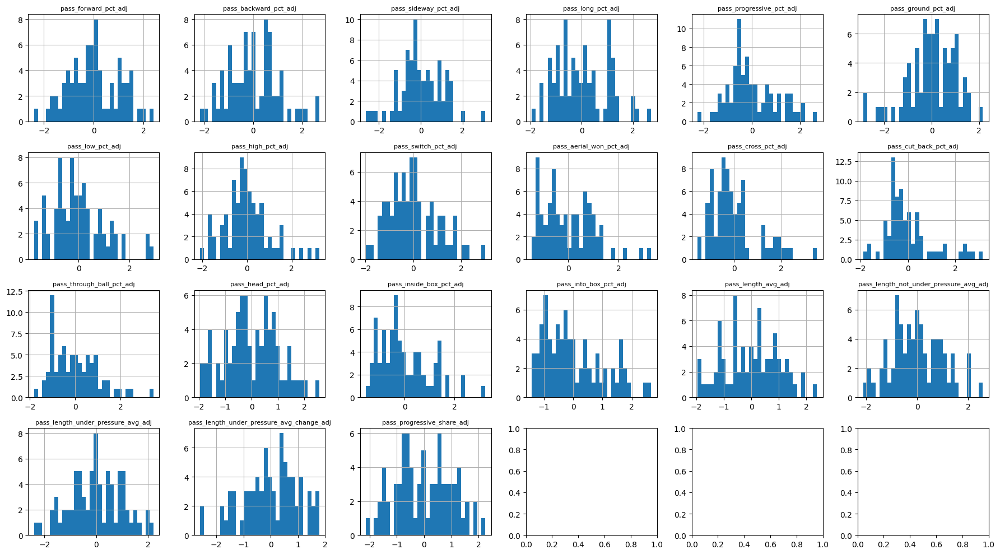

In [1925]:
# split into batches of ~24 features at a time, by conceptual block
passing_cols = [c for c in feature_cols_adj if 'pass' in c]
plot_histogram_grid(center_forwards_stats, passing_cols)

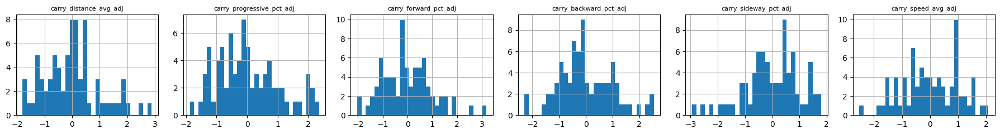

In [1926]:
# split into batches of ~24 features at a time, by conceptual block
carrying_cols = [c for c in feature_cols_adj if 'carry' in c]
plot_histogram_grid(center_forwards_stats, carrying_cols)

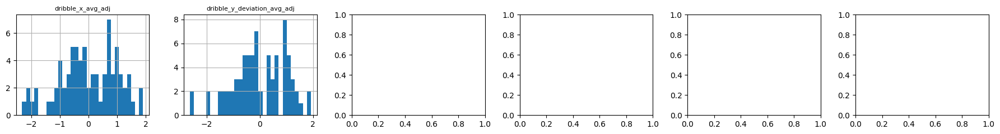

In [1927]:
# split into batches of ~24 features at a time, by conceptual block
dribbling_cols = [c for c in feature_cols_adj if 'dribble' in c]
plot_histogram_grid(center_forwards_stats, dribbling_cols)

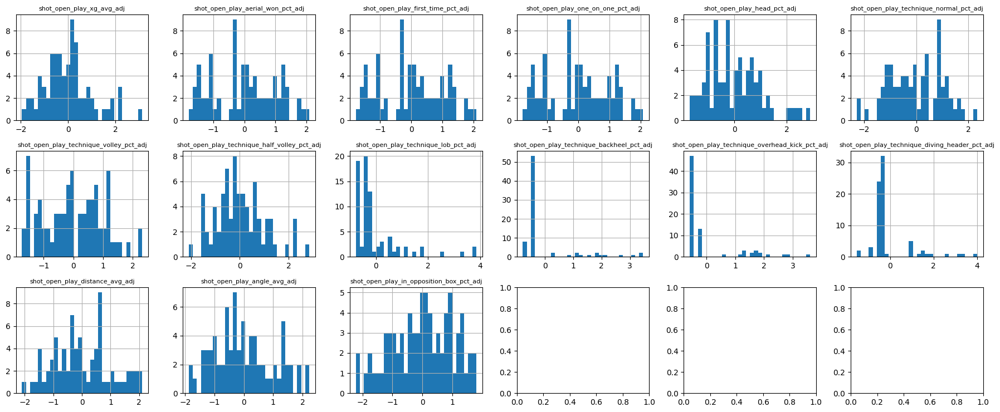

In [1928]:
# split into batches of ~24 features at a time, by conceptual block
shot_cols = [c for c in feature_cols_adj if 'shot' in c]
plot_histogram_grid(center_forwards_stats, shot_cols)

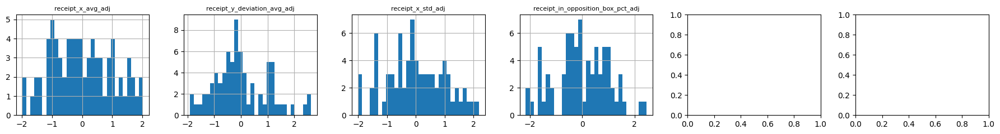

In [1929]:
# split into batches of ~24 features at a time, by conceptual block
receipt_cols = [c for c in feature_cols_adj if 'receipt' in c]
plot_histogram_grid(center_forwards_stats, receipt_cols)

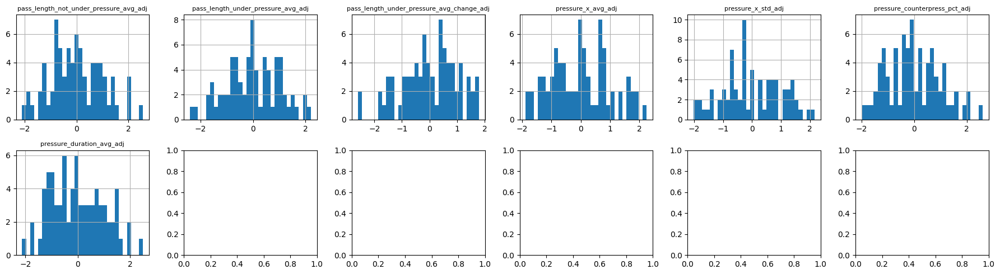

In [1930]:
# split into batches of ~24 features at a time, by conceptual block
pressure_cols = [c for c in feature_cols_adj if 'pressure' in c]
plot_histogram_grid(center_forwards_stats, pressure_cols)

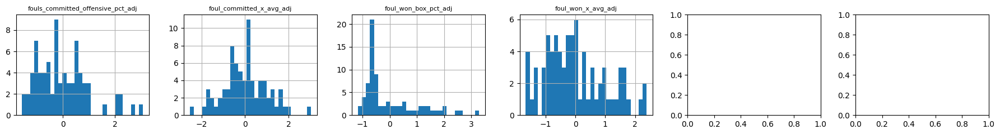

In [1931]:
# split into batches of ~24 features at a time, by conceptual block
foul_cols = [c for c in feature_cols_adj if 'foul' in c]
plot_histogram_grid(center_forwards_stats, foul_cols)

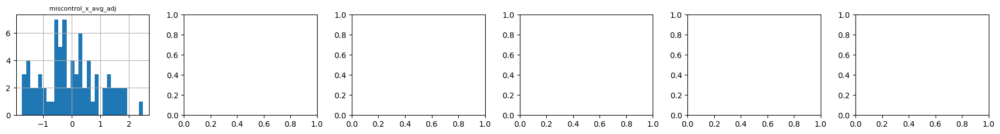

In [1932]:
# split into batches of ~24 features at a time, by conceptual block
miscontrol_cols = [c for c in feature_cols_adj if 'miscontrol' in c]
plot_histogram_grid(center_forwards_stats, miscontrol_cols)

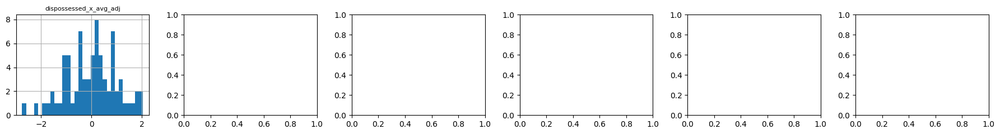

In [1933]:
# split into batches of ~24 features at a time, by conceptual block
dispossessed_cols = [c for c in feature_cols_adj if 'dispossessed' in c]
plot_histogram_grid(center_forwards_stats, dispossessed_cols)

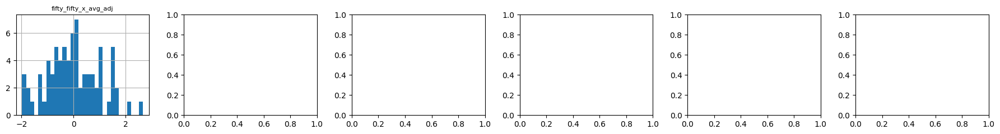

In [1934]:
# split into batches of ~24 features at a time, by conceptual block
fifty_fifty_cols = [c for c in feature_cols_adj if 'fifty_fifty' in c]
plot_histogram_grid(center_forwards_stats, fifty_fifty_cols)

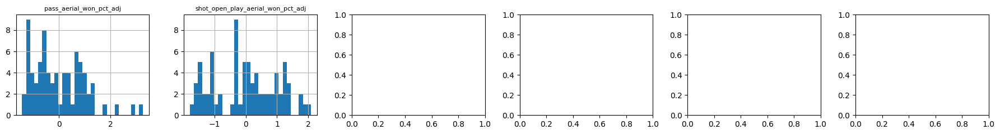

In [1935]:
# split into batches of ~24 features at a time, by conceptual block
aerial_cols = [c for c in feature_cols_adj if 'aerial' in c]
plot_histogram_grid(center_forwards_stats, aerial_cols)

In [1936]:
columns_to_drop_distribution = ['pass_aerial_won_pct', 'pass_cross_pct', 'pass_cut_back_pct', 'pass_through_ball_pct', 'pass_inside_box_pct',
                                'pass_into_box_pct', 'carry_sideway_pct', 'carry_speed_avg', 'shot_open_play_technique_volley_pct',
                                'shot_open_play_technique_half_volley_pct', 'shot_open_play_technique_lob_pct', 'shot_open_play_technique_backheel_pct',
                                'shot_open_play_technique_overhead_kick_pct', 'shot_open_play_technique_diving_header_pct', 'foul_won_box_pct']

In [1937]:
center_forwards_stats = center_forwards_stats.drop(columns=columns_to_drop_distribution + [c + '_adj' for c in columns_to_drop_distribution])

In [1938]:
center_forwards_stats.shape

(76, 93)

In [1939]:
center_forwards_stats.columns.tolist()

['pass_forward_pct',
 'pass_backward_pct',
 'pass_sideway_pct',
 'pass_long_pct',
 'pass_progressive_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_high_pct',
 'pass_switch_pct',
 'pass_head_pct',
 'pass_length_avg',
 'pass_length_not_under_pressure_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_progressive_pct',
 'carry_forward_pct',
 'carry_backward_pct',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_aerial_won_pct',
 'shot_open_play_first_time_pct',
 'shot_open_play_one_on_one_pct',
 'shot_open_play_head_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_distance_avg',
 'shot_open_play_angle_avg',
 'shot_open_play_in_opposition_box_pct',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'receipt_in_opposition_box_pct',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'fouls_committed_offensive_pct',


In [1940]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_distribution]

In [1941]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1942]:
len(feature_cols)

45

In [1943]:
len(feature_cols_adj)

45

#### Observe correlation between variables

In [1944]:
corr_matrix = center_forwards_stats[feature_cols_adj].corr().abs()

In [1945]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [1946]:
high_corr_pairs = (upper.stack()
                   .reset_index()
                   .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'correlation'})
                   .sort_values('correlation', ascending=False))

In [1947]:
high_corr_pairs[high_corr_pairs['correlation'] > 0.8]

,feature_1,feature_2,correlation
967,shot_open_play_aerial_won_pct_adj,shot_open_play_first_time_pct_adj,1.000000
1013,shot_open_play_first_time_pct_adj,shot_open_play_one_on_one_pct_adj,1.000000
968,shot_open_play_aerial_won_pct_adj,shot_open_play_one_on_one_pct_adj,1.000000
461,pass_length_avg_adj,pass_length_not_under_pressure_avg_adj,0.968741
645,carry_distance_avg_adj,carry_progressive_pct_adj,0.931831
1197,shot_open_play_distance_avg_adj,shot_open_play_angle_avg_adj,0.856496
1198,shot_open_play_distance_avg_adj,shot_open_play_in_opposition_box_pct_adj,0.854997
145,pass_long_pct_adj,pass_length_avg_adj,0.829545
719,carry_progressive_pct_adj,pass_progressive_share_adj,0.827025
146,pass_long_pct_adj,pass_length_not_under_pressure_avg_adj,0.806520


In [1948]:
columns_to_drop_correlation = ['shot_open_play_first_time_pct', 'shot_open_play_one_on_one_pct', 'shot_open_play_aerial_won_pct',
                               'pass_length_not_under_pressure_avg', 'carry_progressive_pct', 'shot_open_play_angle_avg', 
                               'shot_open_play_in_opposition_box_pct', 'pass_long_pct', 'pass_high_pct', 'pass_sideway_pct']

In [1949]:
center_forwards_stats = center_forwards_stats.drop(columns=columns_to_drop_correlation + [c + '_adj' for c in columns_to_drop_correlation])

In [1950]:
center_forwards_stats.shape

(76, 73)

In [1951]:
feature_cols = [c for c in feature_cols if c not in columns_to_drop_correlation]

In [1952]:
feature_cols_adj = [c + '_adj' for c in feature_cols]

In [1953]:
skew_check = center_forwards_stats[feature_cols].skew().sort_values(ascending=False)

In [1954]:
skew_check[skew_check.abs() > 1.5]

Series([], dtype: float64)

#### Final feature columns

In [1955]:
final_feature_cols = [c for c in feature_cols]

In [1956]:
final_feature_cols

['pass_forward_pct',
 'pass_backward_pct',
 'pass_progressive_pct',
 'pass_ground_pct',
 'pass_low_pct',
 'pass_switch_pct',
 'pass_head_pct',
 'pass_length_avg',
 'pass_length_under_pressure_avg',
 'pass_length_under_pressure_avg_change',
 'carry_distance_avg',
 'carry_forward_pct',
 'carry_backward_pct',
 'dribble_x_avg',
 'dribble_y_deviation_avg',
 'shot_open_play_xg_avg',
 'shot_open_play_head_pct',
 'shot_open_play_technique_normal_pct',
 'shot_open_play_distance_avg',
 'receipt_x_avg',
 'receipt_y_deviation_avg',
 'receipt_x_std',
 'receipt_in_opposition_box_pct',
 'pressure_x_avg',
 'pressure_x_std',
 'pressure_counterpress_pct',
 'pressure_duration_avg',
 'fouls_committed_offensive_pct',
 'foul_committed_x_avg',
 'foul_won_x_avg',
 'miscontrol_x_avg',
 'dispossessed_x_avg',
 'fifty_fifty_x_avg',
 'counterpress_in_opposing_half_pct',
 'pass_progressive_share']

In [1957]:
len(final_feature_cols)

35

In [1958]:
final_feature_cols_adj = [c + '_adj' for c in final_feature_cols]

In [1959]:
final_feature_cols_adj

['pass_forward_pct_adj',
 'pass_backward_pct_adj',
 'pass_progressive_pct_adj',
 'pass_ground_pct_adj',
 'pass_low_pct_adj',
 'pass_switch_pct_adj',
 'pass_head_pct_adj',
 'pass_length_avg_adj',
 'pass_length_under_pressure_avg_adj',
 'pass_length_under_pressure_avg_change_adj',
 'carry_distance_avg_adj',
 'carry_forward_pct_adj',
 'carry_backward_pct_adj',
 'dribble_x_avg_adj',
 'dribble_y_deviation_avg_adj',
 'shot_open_play_xg_avg_adj',
 'shot_open_play_head_pct_adj',
 'shot_open_play_technique_normal_pct_adj',
 'shot_open_play_distance_avg_adj',
 'receipt_x_avg_adj',
 'receipt_y_deviation_avg_adj',
 'receipt_x_std_adj',
 'receipt_in_opposition_box_pct_adj',
 'pressure_x_avg_adj',
 'pressure_x_std_adj',
 'pressure_counterpress_pct_adj',
 'pressure_duration_avg_adj',
 'fouls_committed_offensive_pct_adj',
 'foul_committed_x_avg_adj',
 'foul_won_x_avg_adj',
 'miscontrol_x_avg_adj',
 'dispossessed_x_avg_adj',
 'fifty_fifty_x_avg_adj',
 'counterpress_in_opposing_half_pct_adj',
 'pass_pro

In [1960]:
len(final_feature_cols_adj)

35

#### Detect outliers

In [1961]:
outliers_zscore = detect_outliers_zscore(center_forwards_stats, final_feature_cols, player_id_to_player, team_id_to_team)

In [1962]:
for col, rows in outliers_zscore.items():
    print(f"\n--- {col} ---")
    print(rows.sort_values('z_score', ascending=False))


--- pass_backward_pct ---
                                                   league  pass_backward_pct  \
player_id team_id position_group                                               
15788.0   973     Center Forward  FA Women's Super League           0.293233   

                                  player_id  team_id  z_score  \
player_id team_id position_group                                
15788.0   973     Center Forward    15788.0      973  3.17394   

                                                   player              team  
player_id team_id position_group                                             
15788.0   973     Center Forward  Amalie Grønbak Thestrup  Bristol City WFC  

--- pass_length_under_pressure_avg_change ---
                                         league  \
player_id team_id position_group                  
10176.0   3154    Center Forward  Serie A Women   

                                  pass_length_under_pressure_avg_change  \
player_id team_id position

In [1963]:
outliers_iqr = detect_outliers_iqr(center_forwards_stats, final_feature_cols, player_id_to_player, team_id_to_team)

In [1964]:
for col, rows in outliers_iqr.items():
    print(f"\n--- {col} ---")
    print(rows)


--- pass_backward_pct ---
                                                   league  pass_backward_pct  \
player_id team_id position_group                                               
15788.0   973     Center Forward  FA Women's Super League           0.293233   

                                  player_id  team_id                   player  \
player_id team_id position_group                                                
15788.0   973     Center Forward    15788.0      973  Amalie Grønbak Thestrup   

                                              team  bound_distance  
player_id team_id position_group                                    
15788.0   973     Center Forward  Bristol City WFC        0.026742  

--- pass_ground_pct ---
                                                   league  pass_ground_pct  \
player_id team_id position_group                                             
135953.0  3269    Center Forward                   Liga F         0.424870   
384139.0  3280    Cent

In [1965]:
all_flagged_players_zscore = []

In [1966]:
for col, rows in outliers_zscore.items():
    all_flagged_players_zscore.extend(rows['player_id'].tolist())

In [1967]:
flag_counts_zscore = pd.Series(Counter(all_flagged_players_zscore)).sort_values(ascending=False)

In [1968]:
flag_counts_zscore

15788.0     2
41950.0     2
10176.0     1
53185.0     1
10229.0     1
15550.0     1
389568.0    1
dtype: int64

In [1969]:
all_flagged_players_iqr = []

In [1970]:
for col, rows in outliers_iqr.items():
    all_flagged_players_iqr.extend(rows['player_id'].tolist())

In [1971]:
flag_counts_iqr = pd.Series(Counter(all_flagged_players_iqr)).sort_values(ascending=False)

In [1972]:
flag_counts_iqr

384139.0    3
53185.0     3
15788.0     2
389568.0    2
10176.0     2
10229.0     2
41950.0     2
135953.0    1
24706.0     1
45288.0     1
10396.0     1
53188.0     1
276301.0    1
63424.0     1
325210.0    1
25541.0     1
46228.0     1
45641.0     1
15550.0     1
25510.0     1
32161.0     1
dtype: int64

In [1973]:
keys = ['player_id', 'team_id', 'league', 'position_group']

In [1974]:
winsorize_cols = ['pass_progressive_pct_adj', 'pass_ground_pct_adj', 'pass_low_pct_adj', 'pass_switch_pct_adj',
                  'carry_distance_avg_adj', 'carry_forward_pct_adj', 'shot_open_play_xg_avg_adj',
                  'shot_open_play_head_pct_adj', 'fouls_committed_offensive_pct_adj', 'foul_committed_x_avg_adj',
                  'miscontrol_x_avg_adj']

In [1975]:
for col in winsorize_cols:
    center_forwards_stats[col] = winsorize(center_forwards_stats[col])

In [1976]:
imputation_configs = [
    dict(position_group='Center Forward', pct_col='foul_committed_x_avg',
        attempted_col='fouls_committed', min_quantile=0.2),
    dict(position_group='Center Forward', pct_col='shot_open_play_xg_avg',
        attempted_col='shots_open_play_attempted', min_quantile=0.2),
    dict(position_group='Center Forward', pct_col='miscontrol_x_avg',
        attempted_col='miscontrols', min_quantile=0.2),
]

In [1977]:
for cfg in imputation_configs:
    pos, pct_col = cfg['position_group'], cfg['pct_col']
    target_df = stats_by_position[pos]
    
    # reads eligibility/reliable-group-mean from all_players_stats (untouched, read-only),
    # writes the imputed value into target_df only
    target_df = impute_unreliable_rate_stat(all_players_stats, target_df, **cfg)

    # residualize on target_df itself, using its now-imputed raw value as input
    refit = residualize(
        target_df, feature_cols=[pct_col], covariate_col='context_score',
        group_cols=['position_group'], robust=True,
    )
    target_df[pct_col + '_adj'] = refit[pct_col + '_adj']

    stats_by_position[pos] = target_df

#### Rank features on percentile

In [1978]:
center_forwards_stats = to_percentile(center_forwards_stats, final_feature_cols)      # raw

In [1979]:
center_forwards_stats = to_percentile(center_forwards_stats, final_feature_cols_adj) # adjusted

#### Divide features into groups

In [1980]:
feature_groups = {
    'passing_share': [
        'pass_forward_pct', 'pass_backward_pct', 'pass_progressive_pct', 'pass_ground_pct', 
        'pass_low_pct', 'pass_switch_pct', 'pass_head_pct', 'pass_progressive_share'
    ],
    'passing_length': [
        'pass_length_avg', 'pass_length_under_pressure_avg', 'pass_length_under_pressure_avg_change'
    ],
    'carrying': [
        'carry_distance_avg', 'carry_forward_pct', 'carry_backward_pct'
    ],
    'dribbling': [
        'dribble_x_avg', 'dribble_y_deviation_avg'
    ],
    'shooting': [
        'shot_open_play_xg_avg', 'shot_open_play_head_pct', 'shot_open_play_technique_normal_pct', 'shot_open_play_distance_avg'
    ],
    'receipt': [
        'receipt_x_avg', 'receipt_y_deviation_avg', 'receipt_x_std', 'receipt_in_opposition_box_pct'
    ],
    'defending': [
        'pressure_x_avg', 'pressure_x_std', 'pressure_counterpress_pct', 'pressure_duration_avg', 'foul_won_x_avg', 'counterpress_in_opposing_half_pct'
    ],
    'vulnerability_fifty_fifty': [
        'fouls_committed_offensive_pct', 'foul_committed_x_avg', 'miscontrol_x_avg', 'dispossessed_x_avg', 'fifty_fifty_x_avg'
    ]
}

In [1981]:
feature_groups_adj = {
    category: [f + '_adj' for f in features]
    for category, features in feature_groups.items()
}

In [1982]:
n_per_category = {
    'passing_share': 6, 'passing_length': 2, 'carrying': 2, 'dribbling': 1, 'shooting': 2, 'receipt': 2, 'defending': 3, 'vulnerability_fifty_fifty': 2
}

In [1983]:
# n_per_category = {
#     'passing_volume': 4, 'passing_accuracy': 4, 'passing_length': 2,
#     'carrying': 2, 'dribbling': 2, 'shooting_volume': 4,
#     'shooting_accuracy': 4, 'ball_receipt': 2, 'pressure': 2,
#     'foul_committed': 1, 'foul_won': 1, 'miscontrol': 1, 
#     'dispossessed': 1, 'fifty_fifty': 1, 'aerial_duel': 2
# }

In [1984]:
all_grouped = [c for group in feature_groups.values() for c in group]

In [1985]:
missing = set(final_feature_cols) - set(all_grouped)

In [1986]:
missing

set()

In [1987]:
spare = set(all_grouped) - set(final_feature_cols)

In [1988]:
spare

set()

#### KMeans Clustering

##### PCA

In [1989]:
X = center_forwards_stats[final_feature_cols_adj]

In [1990]:
n_features = 19

In [1991]:
pca_reduced_final = PCA(n_components=n_features)

In [1992]:
pca_reduced_final.set_output(transform='pandas')

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",19
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD

In [1993]:
X_pca_final = pca_reduced_final.fit_transform(X)

##### KMeans with k = 2

In [1994]:
k = 2

In [1995]:
kmeans_2 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [1996]:
center_forwards_stats['kmeans_2_cluster'] = kmeans_2.fit_predict(X_pca_final)  # or X, if using raw features

In [1997]:
# bring labels back to the original unstandardized data for interpretation
center_forwards_stats['kmeans_2_cluster'] = center_forwards_stats['kmeans_2_cluster'].values

In [1998]:
center_forwards_stats['kmeans_2_cluster'].value_counts()

kmeans_2_cluster
0    47
1    29
Name: count, dtype: int64

In [1999]:
center_forwards_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_2, 
    stats_df=center_forwards_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 3

In [2000]:
k = 3

In [2001]:
kmeans_3 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [2002]:
center_forwards_stats['kmeans_3_cluster'] = kmeans_3.fit_predict(X_pca_final)  # or X, if using raw features

In [2003]:
# bring labels back to the original unstandardized data for interpretation
center_forwards_stats['kmeans_3_cluster'] = center_forwards_stats['kmeans_3_cluster'].values

In [2004]:
center_forwards_stats['kmeans_3_cluster'].value_counts()

kmeans_3_cluster
1    28
0    25
2    23
Name: count, dtype: int64

In [2005]:
center_forwards_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_3, 
    stats_df=center_forwards_stats,
    sigma_quantile=0.5
)

##### KMeans with k = 4

In [2006]:
k = 4

In [2007]:
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

In [2008]:
center_forwards_stats['kmeans_4_cluster'] = kmeans_4.fit_predict(X_pca_final)  # or X, if using raw features

In [2009]:
# bring labels back to the original unstandardized data for interpretation
center_forwards_stats['kmeans_4_cluster'] = center_forwards_stats['kmeans_4_cluster'].values

In [2010]:
center_forwards_stats['kmeans_4_cluster'].value_counts()

kmeans_4_cluster
2    21
0    20
3    19
1    16
Name: count, dtype: int64

In [2011]:
center_forwards_stats = compute_soft_cluster_spectrum(
    X_pca=X_pca_final,           
    kmeans_model=kmeans_4, 
    stats_df=center_forwards_stats,
    sigma_quantile=0.5
)

## Attach clustering results on usage

### Attach keys

In [2012]:
keys = ["player_id", "team_id", "position_group"]

### Standardize cluster table

#### Similarity and extra columns

In [2013]:
sims = ['sim_cluster_0_k2', 'sim_cluster_1_k2', 'sim_cluster_0_k3', 'sim_cluster_1_k3', 'sim_cluster_2_k3']

In [2014]:
extra_k2 = ['margin_k2', 'kmeans_3_cluster']

In [2015]:
extra_k3 = ['margin_k3', 'kmeans_2_cluster']

#### Standardize all positions

In [2016]:
goalkeepers_stats_cluster = standardize_cluster_table(goalkeepers_stats, 'kmeans_2_cluster', sim_cols=sims, extra_cols=extra_k2)

In [2017]:
center_backs_stats_cluster = standardize_cluster_table(center_backs_stats, 'kmeans_2_cluster', sim_cols=sims, extra_cols=extra_k2)

In [2018]:
full_wing_backs_stats_cluster = standardize_cluster_table(full_wing_backs_stats, 'kmeans_3_cluster', sim_cols=sims, extra_cols=extra_k3)

In [2019]:
center_midfields_stats_parent_cluster = standardize_cluster_table(center_midfields_stats, 'kmeans_3_cluster', sim_cols=sims, extra_cols=extra_k3)

In [2020]:
wingers_stats_cluster = standardize_cluster_table(wingers_stats, 'kmeans_3_cluster', sim_cols=sims, extra_cols=extra_k3)

In [2021]:
center_forwards_stats_cluster = standardize_cluster_table(center_forwards_stats, 'kmeans_3_cluster', sim_cols=sims, extra_cols=extra_k3)

#### Search for center midfields child clusters

In [2022]:
center_midfields_defensive_parent = infer_parent_label(center_midfields_defensive_stats, center_midfields_stats, 'kmeans_3_cluster')

In [2023]:
center_midfields_defensive_parent

np.int32(2)

In [2024]:
center_midfields_center_parent = infer_parent_label(center_midfields_center_stats, center_midfields_stats, 'kmeans_3_cluster')

In [2025]:
center_midfields_center_parent

np.int32(1)

In [2026]:
center_midfields_attack_parent = infer_parent_label(center_midfields_attack_stats, center_midfields_stats, 'kmeans_3_cluster')

In [2027]:
center_midfields_attack_parent

np.int32(0)

#### Standardize center midfields

In [2028]:
center_midfields_stats_cluster = combine_hierarchical_clusters(
    center_midfields_stats_parent_cluster,
    {center_midfields_defensive_parent: center_midfields_defensive_stats,
     center_midfields_attack_parent: center_midfields_attack_stats,
     center_midfields_center_parent: (center_midfields_center_stats, 'kmeans_3_cluster', ['sim_cluster_0_k3', 'sim_cluster_1_k3', 'sim_cluster_2_k3'])},
    parent_col='cluster_l1', child_col='kmeans_2_cluster',                       # default for def/att
    child_sim_cols=['sim_cluster_0_k2', 'sim_cluster_1_k2'])                     # default for def/att

#### Combining all together

In [2029]:
all_clusters = pd.concat([goalkeepers_stats_cluster, center_backs_stats_cluster, full_wing_backs_stats_cluster, center_midfields_stats_cluster, wingers_stats_cluster, center_forwards_stats_cluster], ignore_index=True)

In [2030]:
cluster_cols = ['cluster_l1'] + [c for c in all_clusters.columns if c not in keys + ['cluster_l1']]

In [2031]:
all_clusters.groupby('position_group').size()

position_group
Center Back        154
Center Forward      76
Center Midfield    182
Full/Wing Back     129
Goalkeeper          60
Winger              85
dtype: int64

In [2032]:
len(cluster_cols)

52

In [2033]:
cluster_cols

['cluster_l1',
 'Goalkeeper__sim_cluster_0_k2',
 'Goalkeeper__sim_cluster_1_k2',
 'Goalkeeper__sim_cluster_0_k3',
 'Goalkeeper__sim_cluster_1_k3',
 'Goalkeeper__sim_cluster_2_k3',
 'Goalkeeper__margin_k2',
 'Goalkeeper__kmeans_3_cluster',
 'Center Back__sim_cluster_0_k2',
 'Center Back__sim_cluster_1_k2',
 'Center Back__sim_cluster_0_k3',
 'Center Back__sim_cluster_1_k3',
 'Center Back__sim_cluster_2_k3',
 'Center Back__margin_k2',
 'Center Back__kmeans_3_cluster',
 'FullWing Back__sim_cluster_0_k2',
 'FullWing Back__sim_cluster_1_k2',
 'FullWing Back__sim_cluster_0_k3',
 'FullWing Back__sim_cluster_1_k3',
 'FullWing Back__sim_cluster_2_k3',
 'FullWing Back__margin_k3',
 'FullWing Back__kmeans_2_cluster',
 'cluster_l2',
 'cluster_path',
 'Center Midfield__sim_cluster_0_k2',
 'Center Midfield__sim_cluster_1_k2',
 'Center Midfield__sim_cluster_0_k3',
 'Center Midfield__sim_cluster_1_k3',
 'Center Midfield__sim_cluster_2_k3',
 'Center Midfield__margin_k3',
 'Center Midfield__kmeans_2_clus

### Attach clusters to profiles

In [2034]:
profile_cluster = attach_cluster_info(profile, all_clusters, cluster_cols, '1:1')

In [2035]:
profile_cluster.head()

,player_id,team_id,position_group,minutes_at_position,n_slots,dominant_slot,dominant_slot_share,slot_share_Center Attacking Midfield,slot_share_Center Back,slot_share_Center Defensive Midfield,...,Winger__margin_k3,Winger__kmeans_2_cluster,Center Forward__sim_cluster_0_k2,Center Forward__sim_cluster_1_k2,Center Forward__sim_cluster_0_k3,Center Forward__sim_cluster_1_k3,Center Forward__sim_cluster_2_k3,Center Forward__margin_k3,Center Forward__kmeans_2_cluster,has_cluster
0,4633.0,1069,Center Back,1045.150000,3,Left Center Back,0.994100,0.0,0.005103,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
1,4633.0,1069,Full/Wing Back,47.383333,1,Left Back,1.000000,0.0,0.000000,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,4633.0,1069,Winger,0.283333,1,Left Wing,1.000000,0.0,0.000000,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,4636.0,965,Center Back,1858.983333,2,Left Center Back,0.613032,0.0,0.386968,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
4,4638.0,749,Center Forward,37.366667,1,Left Center Forward,1.000000,0.0,0.000000,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


In [2036]:
by_formation_cluster = attach_cluster_info(by_formation, all_clusters, cluster_cols, 'm:1')

In [2037]:
by_formation_cluster.head()

,player_id,team_id,position_group,formation,position_name,minutes_at_slot,minutes_in_formation,slot_share_in_formation,minutes_at_position,formation_share,...,Winger__margin_k3,Winger__kmeans_2_cluster,Center Forward__sim_cluster_0_k2,Center Forward__sim_cluster_1_k2,Center Forward__sim_cluster_0_k3,Center Forward__sim_cluster_1_k3,Center Forward__sim_cluster_2_k3,Center Forward__margin_k3,Center Forward__kmeans_2_cluster,has_cluster
0,4633.0,1069,Center Back,343,Center Back,5.333333,5.333333,1.000000,1045.15,0.005103,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
1,4633.0,1069,Center Back,352,Left Center Back,10.066667,10.066667,1.000000,1045.15,0.009632,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2,4633.0,1069,Center Back,433,Left Center Back,23.633333,23.633333,1.000000,1045.15,0.022612,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
3,4633.0,1069,Center Back,3421,Left Center Back,9.683333,9.683333,1.000000,1045.15,0.009265,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
4,4633.0,1069,Center Back,4231,Left Center Back,961.650000,962.483333,0.999134,1045.15,0.920904,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True


In [2038]:
occupancy_cluster = attach_cluster_info(occupancy, all_clusters, cluster_cols, 'm:1')

In [2039]:
occupancy_cluster.head()

,team_id,formation,position_group,position_name,player_id,minutes,slot_minutes,share_of_slot,rank_in_slot,cluster_l1,...,Winger__margin_k3,Winger__kmeans_2_cluster,Center Forward__sim_cluster_0_k2,Center Forward__sim_cluster_1_k2,Center Forward__sim_cluster_0_k3,Center Forward__sim_cluster_1_k3,Center Forward__sim_cluster_2_k3,Center Forward__margin_k3,Center Forward__kmeans_2_cluster,has_cluster
0,746,343,Center Back,Center Back,10252.0,5.766667,11.233333,0.513353,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
1,746,343,Center Back,Center Back,10185.0,5.466667,11.233333,0.486647,2,<NA>,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,746,343,Center Back,Left Center Back,10163.0,5.766667,11.233333,0.513353,1,<NA>,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,746,343,Center Back,Left Center Back,10252.0,5.466667,11.233333,0.486647,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
4,746,343,Center Back,Right Center Back,5078.0,11.233333,11.233333,1.000000,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True


### Check minutes

In [2040]:
print('Goalkeeper', minutes_check(goalkeepers_stats, profile))

Goalkeeper {'n': 60, 'n_unmatched': 0, 'max_abs_diff': 0.0}


In [2041]:
print('Center Back', minutes_check(center_backs_stats, profile))

Center Back {'n': 154, 'n_unmatched': 0, 'max_abs_diff': 4.547473508864641e-13}


In [2042]:
print('Full/Wing Back', minutes_check(full_wing_backs_stats, profile))

Full/Wing Back {'n': 129, 'n_unmatched': 0, 'max_abs_diff': 4.547473508864641e-13}


In [2043]:
print('Center Midfield', minutes_check(center_midfields_stats, profile))

Center Midfield {'n': 182, 'n_unmatched': 0, 'max_abs_diff': 4.547473508864641e-13}


In [2044]:
print('Winger', minutes_check(wingers_stats, profile))

Winger {'n': 85, 'n_unmatched': 0, 'max_abs_diff': 2.2737367544323206e-13}


In [2045]:
print('Center Forward', minutes_check(center_forwards_stats, profile))

Center Forward {'n': 76, 'n_unmatched': 0, 'max_abs_diff': 2.2737367544323206e-13}


In [2046]:
profile_cluster.groupby('position_group')['has_cluster'].mean()

position_group
Center Back        0.354839
Center Forward     0.141002
Center Midfield    0.229508
Full/Wing Back     0.220513
Goalkeeper         0.517241
Winger             0.126866
Name: has_cluster, dtype: float64

In [2047]:
profile_cluster.loc[profile_cluster['position_group'] == 'Center Midfield', 'cluster_l2'].notna().mean()

np.float64(0.22950819672131148)

### Slot mix per position group

In [2048]:
mix_center_back = cluster_slot_mix(profile_cluster, 'cluster_l1', 'Center Back');    

In [2049]:
display(mix_center_back.round(2))

,slot_share_Center Back,slot_share_Left Center Back,slot_share_Right Center Back
cluster_l1,,,
0,0.11,0.46,0.43
1,0.10,0.41,0.49


In [2050]:
mix_full_wing_back = cluster_slot_mix(profile_cluster, 'cluster_l1', 'Full/Wing Back')

In [2051]:
display(mix_full_wing_back.round(2))

,slot_share_Left Back,slot_share_Left Wing Back,slot_share_Right Back,slot_share_Right Wing Back
cluster_l1,,,,
0,0.46,0.14,0.24,0.17
1,0.49,0.03,0.44,0.04
2,0.31,0.15,0.46,0.08


In [2052]:
mix_center_midfield_parent = cluster_slot_mix(profile_cluster, 'cluster_l1', 'Center Midfield')

In [2053]:
display(mix_center_midfield_parent.round(2))

,slot_share_Center Attacking Midfield,slot_share_Center Defensive Midfield,slot_share_Center Midfield,slot_share_Left Attacking Midfield,slot_share_Left Center Midfield,slot_share_Left Defensive Midfield,slot_share_Right Attacking Midfield,slot_share_Right Center Midfield,slot_share_Right Defensive Midfield
cluster_l1,,,,,,,,,
0,0.36,0.01,0.0,0.01,0.21,0.09,0.01,0.24,0.07
1,0.12,0.08,0.0,0.00,0.20,0.18,0.01,0.22,0.20
2,0.02,0.28,0.0,0.00,0.07,0.29,0.00,0.05,0.28


In [2054]:
mix_center_midfield_path = cluster_slot_mix(profile_cluster, 'cluster_path', 'Center Midfield')

In [2055]:
display(mix_center_midfield_path.round(2))

,slot_share_Center Attacking Midfield,slot_share_Center Defensive Midfield,slot_share_Center Midfield,slot_share_Left Attacking Midfield,slot_share_Left Center Midfield,slot_share_Left Defensive Midfield,slot_share_Right Attacking Midfield,slot_share_Right Center Midfield,slot_share_Right Defensive Midfield
cluster_path,,,,,,,,,
0_0,0.46,0.00,0.0,0.02,0.18,0.04,0.01,0.20,0.09
0_1,0.26,0.01,0.0,0.00,0.23,0.14,0.01,0.28,0.06
1_0,0.20,0.01,0.0,0.00,0.44,0.06,0.00,0.24,0.05
1_1,0.13,0.06,0.0,0.00,0.11,0.15,0.02,0.35,0.19
1_2,0.09,0.11,0.0,0.00,0.17,0.24,0.00,0.14,0.25
2_0,0.00,0.43,0.0,0.00,0.03,0.24,0.00,0.03,0.26
2_1,0.03,0.17,0.0,0.00,0.10,0.32,0.00,0.08,0.30


In [2056]:
mix_winger = cluster_slot_mix(profile_cluster, 'cluster_l1', 'Winger')

In [2057]:
display(mix_winger.round(2))

,slot_share_Left Midfield,slot_share_Left Wing,slot_share_Right Midfield,slot_share_Right Wing
cluster_l1,,,,
0,0.12,0.35,0.15,0.39
1,0.11,0.41,0.17,0.31
2,0.18,0.49,0.08,0.24


In [2058]:
mix_center_forward = cluster_slot_mix(profile_cluster, 'cluster_l1', 'Center Forward')

In [2059]:
display(mix_center_forward.round(2))

,slot_share_Center Forward,slot_share_Left Center Forward,slot_share_Right Center Forward
cluster_l1,,,
0,0.60,0.19,0.21
1,0.45,0.26,0.29
2,0.52,0.25,0.23


## Build team level usage profile

### Create usage table

In [2060]:
usage = profile_cluster.rename(columns={'minutes_at_position': 'minutes'})

### Team archetype shares

In [2061]:
t_goalkeeper = team_position_shares(usage, 'Goalkeeper', 'cluster_l1')

In [2062]:
t_goalkeeper.head()

,Goalkeeper__minutes,Goalkeeper__coverage,Goalkeeper__0,Goalkeeper__1
team_id,,,,
746,2227.150000,1.000000,0.0,1.0
749,2225.416667,0.725767,1.0,0.0
924,2109.700000,0.993712,0.0,1.0
929,2124.466667,0.837606,1.0,0.0
937,2906.966667,0.957292,1.0,0.0


In [2063]:
t_center_back = team_position_shares(usage, 'Center Back', 'cluster_l1')

In [2064]:
t_center_back.head()

,Center Back__minutes,Center Back__coverage,Center Back__0,Center Back__1
team_id,,,,
746,4578.216667,0.959639,0.301545,0.698455
749,4447.866667,0.990512,1.000000,0.000000
924,4687.433333,0.943196,0.840600,0.159400
929,4263.666667,0.943609,0.694172,0.305828
937,5823.833333,0.645423,0.000000,1.000000


In [2065]:
t_full_wing_back = team_position_shares(usage, 'Full/Wing Back', 'cluster_l1')

In [2066]:
t_full_wing_back.head()

,FullWing Back__minutes,FullWing Back__coverage,FullWing Back__0,FullWing Back__1,FullWing Back__2
team_id,,,,,
746,4447.866667,0.795115,0.334821,0.665179,0.000000
749,4449.816667,0.798273,0.000000,0.766612,0.233388
924,4209.433333,0.510769,0.442129,0.000000,0.557871
929,4247.483333,0.796052,0.000000,0.648756,0.351244
937,5812.350000,0.783742,0.392847,0.000000,0.607153


In [2067]:
t_center_midfield_parent = team_position_shares(usage, 'Center Midfield', 'cluster_l1')

In [2068]:
t_center_midfield_parent.head()

,Center Midfield__minutes,Center Midfield__coverage,Center Midfield__0,Center Midfield__1,Center Midfield__2
team_id,,,,,
746,6676.833333,0.899526,0.639407,0.000000,0.360593
749,6011.416667,0.853418,0.294144,0.000000,0.705856
924,5477.483333,0.771629,0.179929,0.209231,0.610840
929,6373.183333,0.770016,0.279799,0.720201,0.000000
937,8720.900000,0.705545,0.468055,0.293302,0.238643


In [2069]:
t_center_midfield_path = team_position_shares(usage, 'Center Midfield', 'cluster_path')

In [2070]:
t_center_midfield_path.head()

,Center Midfield__minutes,Center Midfield__coverage,Center Midfield__0_0,Center Midfield__0_1,Center Midfield__1_0,Center Midfield__1_1,Center Midfield__1_2,Center Midfield__2_0,Center Midfield__2_1
team_id,,,,,,,,,
746,6676.833333,0.899526,0.351630,0.287777,0.0,0.000000,0.000000,0.000000,0.360593
749,6011.416667,0.853418,0.140139,0.154005,0.0,0.000000,0.000000,0.563848,0.142007
924,5477.483333,0.771629,0.000000,0.179929,0.0,0.209231,0.000000,0.291559,0.319281
929,6373.183333,0.770016,0.000000,0.279799,0.0,0.000000,0.720201,0.000000,0.000000
937,8720.900000,0.705545,0.468055,0.000000,0.0,0.000000,0.293302,0.238643,0.000000


In [2071]:
t_winger = team_position_shares(usage, 'Winger', 'cluster_l1')

In [2072]:
t_winger.head()

,Winger__minutes,Winger__coverage,Winger__0,Winger__1,Winger__2
team_id,,,,,
746,4223.533333,0.964066,0.745463,0.254537,0.000000
749,4449.216667,0.575629,0.000000,0.609113,0.390887
924,4120.766667,0.514160,1.000000,0.000000,0.000000
929,4140.900000,0.743590,1.000000,0.000000,0.000000
937,5766.250000,0.499637,0.607514,0.000000,0.392486


In [2073]:
t_center_forward = team_position_shares(usage, 'Center Forward', 'cluster_l1')

In [2074]:
t_center_forward.head()

,Center Forward__minutes,Center Forward__coverage,Center Forward__0,Center Forward__1,Center Forward__2
team_id,,,,,
746,2188.750000,0.687348,1.0,0.000000,0.000000
749,2883.650000,0.742312,0.0,0.345773,0.654227
924,2537.716667,0.305623,0.0,0.000000,1.000000
929,2175.916667,0.339987,0.0,0.000000,1.000000
937,2930.350000,0.000000,NaN,NaN,NaN


### Team soft archetype shares

In [2075]:
ts_goalkeeper = team_soft_shares(usage, 'Goalkeeper', sim_cols_for(usage, 'Goalkeeper', 2))

In [2076]:
ts_goalkeeper.head()

,Goalkeeper__soft_0,Goalkeeper__soft_1
team_id,,
746,0.304916,0.695084
749,0.781615,0.218385
924,0.445345,0.554655
929,0.694288,0.305712
937,0.644824,0.355176


In [2077]:
ts_center_back = team_soft_shares(usage, 'Center Back', sim_cols_for(usage, 'Center Back', 2))

In [2078]:
ts_center_back.head()

,Center Back__soft_0,Center Back__soft_1
team_id,,
746,0.494028,0.505972
749,0.728126,0.271874
924,0.561831,0.438169
929,0.492417,0.507583
937,0.285934,0.714066


In [2079]:
ts_full_wing_back = team_soft_shares(usage, 'Full/Wing Back', sim_cols_for(usage, 'Full/Wing Back', 3))

In [2080]:
ts_full_wing_back.head()

,FullWing Back__soft_0,FullWing Back__soft_1,FullWing Back__soft_2
team_id,,,
746,0.340771,0.386629,0.272600
749,0.257669,0.447815,0.294516
924,0.317422,0.312117,0.370461
929,0.236127,0.420786,0.343087
937,0.420741,0.256311,0.322948


In [2081]:
ts_center_midfield_parent = team_soft_shares(usage, 'Center Midfield', sim_cols_for(usage, 'Center Midfield', 3))

In [2082]:
ts_center_midfield_parent.head()

,Center Midfield__soft_0,Center Midfield__soft_1,Center Midfield__soft_2
team_id,,,
746,0.396068,0.289500,0.314432
749,0.215069,0.305642,0.479289
924,0.261684,0.361187,0.377128
929,0.287952,0.425447,0.286601
937,0.378908,0.347733,0.273359


In [2083]:
ts_center_midfield_path = team_soft_path_shares(usage, 'Center Midfield')

In [2084]:
ts_center_midfield_path.head()

,Center Midfield__soft_0_0,Center Midfield__soft_0_1,Center Midfield__soft_1_0,Center Midfield__soft_1_1,Center Midfield__soft_1_2,Center Midfield__soft_2_0,Center Midfield__soft_2_1
team_id,,,,,,,
746,0.310155,0.329252,0.000000,0.000000,0.000000,0.159229,0.201365
749,0.142521,0.151623,0.000000,0.000000,0.000000,0.386365,0.319491
924,0.066523,0.113405,0.055188,0.086985,0.067058,0.295450,0.315390
929,0.127071,0.152728,0.150678,0.233174,0.336349,0.000000,0.000000
937,0.304030,0.164025,0.088109,0.070168,0.135025,0.132231,0.106412


In [2085]:
ts_winger = team_soft_shares(usage, 'Winger', sim_cols_for(usage, 'Winger', 3))

In [2086]:
ts_winger.head()

,Winger__soft_0,Winger__soft_1,Winger__soft_2
team_id,,,
746,0.419619,0.318798,0.261583
749,0.275022,0.370191,0.354787
924,0.470767,0.270813,0.258420
929,0.425975,0.327058,0.246967
937,0.453663,0.237176,0.309160


In [2087]:
ts_center_forward = team_soft_shares(usage, 'Center Forward', sim_cols_for(usage, 'Center Forward', 3))

In [2088]:
ts_center_forward.head()

,Center Forward__soft_0,Center Forward__soft_1,Center Forward__soft_2
team_id,,,
746,0.363451,0.303157,0.333392
749,0.275742,0.375594,0.348664
924,0.271391,0.294690,0.433919
929,0.232763,0.267361,0.499876
965,0.417259,0.244574,0.338167


### Per team usage

In [2089]:
pu_goalkeeper = player_usage(usage, 'Goalkeeper')

In [2090]:
pu_goalkeeper.head()

,player_id,team_id,position_group,minutes,n_slots,dominant_slot,dominant_slot_share,slot_share_Center Attacking Midfield,slot_share_Center Back,slot_share_Center Defensive Midfield,...,Center Forward__sim_cluster_1_k2,Center Forward__sim_cluster_0_k3,Center Forward__sim_cluster_1_k3,Center Forward__sim_cluster_2_k3,Center Forward__margin_k3,Center Forward__kmeans_2_cluster,has_cluster,minutes_share,rank,is_core
1936,92248.0,746,Goalkeeper,2227.150000,1,Goalkeeper,1.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,1.000000,1,True
421,18158.0,749,Goalkeeper,1615.133333,1,Goalkeeper,1.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.725767,1,True
504,24400.0,749,Goalkeeper,610.283333,1,Goalkeeper,1.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,False,0.274233,2,True
1387,49865.0,924,Goalkeeper,2096.433333,1,Goalkeeper,1.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.993712,1,True
2477,324165.0,924,Goalkeeper,8.800000,1,Goalkeeper,1.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,False,0.004171,2,False


In [2091]:
s_goalkeeper = usage_shape(pu_goalkeeper, 'Goalkeeper')

In [2092]:
s_goalkeeper.head()

,Goalkeeper__n_used,Goalkeeper__top1_share,Goalkeeper__effective_n,Goalkeeper__n_core
team_id,,,,
746,1,1.000000,1.000000,1
749,2,0.725767,1.661292,2
924,3,0.993712,1.012674,1
929,2,0.837606,1.373709,1
937,3,0.498377,2.170107,2


In [2093]:
pu_center_back = player_usage(usage, 'Center Back')

In [2094]:
pu_center_back.head()

,player_id,team_id,position_group,minutes,n_slots,dominant_slot,dominant_slot_share,slot_share_Center Attacking Midfield,slot_share_Center Back,slot_share_Center Defensive Midfield,...,Center Forward__sim_cluster_1_k2,Center Forward__sim_cluster_0_k3,Center Forward__sim_cluster_1_k3,Center Forward__sim_cluster_2_k3,Center Forward__margin_k3,Center Forward__kmeans_2_cluster,has_cluster,minutes_share,rank,is_core
200,10252.0,746,Center Back,1863.350000,2,Left Center Back,0.996905,0.0,0.003095,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.407003,1,True
57,5078.0,746,Center Back,1324.816667,3,Right Center Back,0.925977,0.0,0.068286,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.289374,2,True
767,32210.0,746,Center Back,1205.266667,2,Right Center Back,0.706303,0.0,0.000000,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.263261,3,True
13,4649.0,746,Center Back,95.666667,1,Right Center Back,1.000000,0.0,0.000000,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,False,0.020896,4,False
143,10185.0,746,Center Back,83.350000,2,Right Center Back,0.641272,0.0,0.358728,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,False,0.018206,5,False


In [2095]:
s_center_back = usage_shape(pu_center_back, 'Center Back')

In [2096]:
s_center_back.head()

,Center Back__n_used,Center Back__top1_share,Center Back__effective_n,Center Back__n_core
team_id,,,,
746,6,0.407003,3.130231,3
749,5,0.380186,3.019775,3
924,9,0.211089,5.477417,5
929,10,0.367669,3.311152,3
937,13,0.241201,5.552273,5


In [2097]:
pu_full_wing_back = player_usage(usage, 'Full/Wing Back')

In [2098]:
pu_full_wing_back.head()

,player_id,team_id,position_group,minutes,n_slots,dominant_slot,dominant_slot_share,slot_share_Center Attacking Midfield,slot_share_Center Back,slot_share_Center Defensive Midfield,...,Center Forward__sim_cluster_1_k2,Center Forward__sim_cluster_0_k3,Center Forward__sim_cluster_1_k3,Center Forward__sim_cluster_2_k3,Center Forward__margin_k3,Center Forward__kmeans_2_cluster,has_cluster,minutes_share,rank,is_core
119,10163.0,746,Full/Wing Back,1544.833333,3,Left Back,0.985716,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.347320,1,True
2311,221888.0,746,Full/Wing Back,1184.116667,3,Right Back,0.897519,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.266221,2,True
768,32210.0,746,Full/Wing Back,807.616667,2,Right Back,0.649958,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.181574,3,True
14,4649.0,746,Full/Wing Back,517.416667,2,Right Back,0.978515,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,False,0.116329,4,True
2274,191851.0,746,Full/Wing Back,150.033333,2,Left Back,0.817596,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,False,0.033732,5,False


In [2099]:
s_full_wing_back = usage_shape(pu_full_wing_back, 'Full/Wing Back')

In [2100]:
s_full_wing_back.head()

,FullWing Back__n_used,FullWing Back__top1_share,FullWing Back__effective_n,FullWing Back__n_core
team_id,,,,
746,15,0.347320,4.170081,4
749,8,0.405837,3.869202,4
924,11,0.284943,5.247202,4
929,10,0.309882,4.297710,4
937,13,0.307890,4.481091,4


In [2101]:
pu_winger = player_usage(usage, 'Winger')

In [2102]:
pu_winger.head()

,player_id,team_id,position_group,minutes,n_slots,dominant_slot,dominant_slot_share,slot_share_Center Attacking Midfield,slot_share_Center Back,slot_share_Center Defensive Midfield,...,Center Forward__sim_cluster_1_k2,Center Forward__sim_cluster_0_k3,Center Forward__sim_cluster_1_k3,Center Forward__sim_cluster_2_k3,Center Forward__margin_k3,Center Forward__kmeans_2_cluster,has_cluster,minutes_share,rank,is_core
338,15555.0,746,Winger,1611.316667,4,Left Wing,0.715471,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.381509,1,True
346,15570.0,746,Winger,1424.033333,4,Right Wing,0.703530,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.337166,2,True
889,35693.0,746,Winger,1036.416667,4,Right Wing,0.540291,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.245391,3,True
434,19498.0,746,Winger,102.200000,2,Right Wing,0.641226,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,False,0.024198,4,False
1442,49938.0,746,Winger,20.100000,3,Left Wing,0.501658,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,False,0.004759,5,False


In [2103]:
s_winger = usage_shape(pu_winger, 'Winger')

In [2104]:
s_winger.head()

,Winger__n_used,Winger__top1_share,Winger__effective_n,Winger__n_core
team_id,,,,
746,12,0.381509,3.124358,3
749,14,0.350624,4.777853,5
924,17,0.345259,5.697221,7
929,9,0.286447,4.562049,4
937,16,0.303536,5.472160,5


In [2105]:
pu_center_forward = player_usage(usage, 'Center Forward')

In [2106]:
pu_center_forward.head()

,player_id,team_id,position_group,minutes,n_slots,dominant_slot,dominant_slot_share,slot_share_Center Attacking Midfield,slot_share_Center Back,slot_share_Center Defensive Midfield,...,Center Forward__sim_cluster_1_k2,Center Forward__sim_cluster_0_k3,Center Forward__sim_cluster_1_k3,Center Forward__sim_cluster_2_k3,Center Forward__margin_k3,Center Forward__kmeans_2_cluster,has_cluster,minutes_share,rank,is_core
564,25554.0,746,Center Forward,1504.433333,1,Center Forward,1.0,0.0,0.0,0.0,...,0.51494,0.363451,0.303157,0.333392,0.03006,1.0,True,0.687348,1,True
344,15570.0,746,Center Forward,280.666667,1,Center Forward,1.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,False,0.128231,2,True
336,15555.0,746,Center Forward,266.483333,1,Center Forward,1.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,False,0.121751,3,False
886,35693.0,746,Center Forward,100.383333,1,Center Forward,1.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,False,0.045863,4,False
432,19498.0,746,Center Forward,36.250000,1,Center Forward,1.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,False,0.016562,5,False


In [2107]:
s_center_forward = usage_shape(pu_center_forward, 'Center Forward')

In [2108]:
s_center_forward.head()

,Center Forward__n_used,Center Forward__top1_share,Center Forward__effective_n,Center Forward__n_core
team_id,,,,
746,6,0.687348,1.975925,2
749,14,0.485640,2.841613,3
924,12,0.305623,5.564122,5
929,9,0.339987,3.185196,3
937,10,0.267300,6.046242,5


In [2109]:
pu_center_midfield = player_usage(usage, 'Center Midfield')

In [2110]:
pu_center_midfield.head()

,player_id,team_id,position_group,minutes,n_slots,dominant_slot,dominant_slot_share,slot_share_Center Attacking Midfield,slot_share_Center Back,slot_share_Center Defensive Midfield,...,Center Forward__sim_cluster_1_k2,Center Forward__sim_cluster_0_k3,Center Forward__sim_cluster_1_k3,Center Forward__sim_cluster_2_k3,Center Forward__margin_k3,Center Forward__kmeans_2_cluster,has_cluster,minutes_share,rank,is_core
587,25632.0,746,Center Midfield,2165.716667,4,Center Defensive Midfield,0.975751,0.000000,0.0,0.975751,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.324363,1,True
426,19416.0,746,Center Midfield,1120.200000,3,Left Center Midfield,0.940546,0.000000,0.0,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.167774,2,True
277,10650.0,746,Center Midfield,991.683333,3,Left Center Midfield,0.620645,0.000000,0.0,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.148526,3,True
433,19498.0,746,Center Midfield,985.900000,3,Right Center Midfield,0.860736,0.040826,0.0,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.147660,4,True
1799,62666.0,746,Center Midfield,742.483333,5,Right Center Midfield,0.935038,0.000000,0.0,0.018227,...,NaN,NaN,NaN,NaN,NaN,NaN,True,0.111203,5,True


In [2111]:
s_center_midfield = usage_shape(pu_center_midfield, 'Center Midfield')

In [2112]:
s_center_midfield.head()

,Center Midfield__n_used,Center Midfield__top1_share,Center Midfield__effective_n,Center Midfield__n_core
team_id,,,,
746,13,0.324363,5.205366,5
749,15,0.307617,5.661865,5
924,15,0.246366,6.042521,5
929,13,0.215450,6.063350,5
937,17,0.206938,6.772277,6


### Usage by formation

In [2113]:
usage_by_formation = attach_cluster_info(minutes_by_formation, all_clusters, cluster_cols, 'm:1')

In [2114]:
usage_by_formation.head(20)

,player_id,team_id,position_group,formation,minutes,cluster_l1,Goalkeeper__sim_cluster_0_k2,Goalkeeper__sim_cluster_1_k2,Goalkeeper__sim_cluster_0_k3,Goalkeeper__sim_cluster_1_k3,...,Winger__margin_k3,Winger__kmeans_2_cluster,Center Forward__sim_cluster_0_k2,Center Forward__sim_cluster_1_k2,Center Forward__sim_cluster_0_k3,Center Forward__sim_cluster_1_k3,Center Forward__sim_cluster_2_k3,Center Forward__margin_k3,Center Forward__kmeans_2_cluster,has_cluster
0,4633.0,1069,Center Back,343,5.333333,1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
1,4633.0,1069,Center Back,352,10.066667,1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2,4633.0,1069,Center Back,433,23.633333,1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
3,4633.0,1069,Center Back,3421,9.683333,1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
4,4633.0,1069,Center Back,4231,962.483333,1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
5,4633.0,1069,Center Back,41212,33.950000,1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
6,4633.0,1069,Full/Wing Back,4231,47.383333,<NA>,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
7,4633.0,1069,Winger,4231,0.283333,<NA>,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
8,4636.0,965,Center Back,343,619.233333,0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
9,4636.0,965,Center Back,433,176.000000,0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True


### Cluster shares per formation

In [2115]:
t_goalkeeper_by_formation = team_position_shares_by_formation(usage_by_formation, 'Goalkeeper', 'cluster_l1', min_formation_minutes=180)

In [2116]:
t_goalkeeper_by_formation.head(20)

,team_id,formation,Goalkeeper__minutes,Goalkeeper__coverage,Goalkeeper__0,Goalkeeper__1,Goalkeeper__reliable
0,746,343,11.233333,1.000000,0.0,1.0,False
1,746,433,1877.116667,1.000000,0.0,1.0,True
2,746,3511,114.900000,1.000000,0.0,1.0,False
3,746,4141,190.650000,1.000000,0.0,1.0,True
4,746,4411,33.250000,1.000000,0.0,1.0,False
5,749,442,660.350000,0.287701,1.0,0.0,True
6,749,4231,1293.833333,0.891859,1.0,0.0,True
7,749,4411,271.233333,1.000000,1.0,0.0,True
8,924,343,431.916667,1.000000,0.0,1.0,True
9,924,433,519.116667,1.000000,0.0,1.0,True


In [2117]:
t_center_back_by_formation = team_position_shares_by_formation(usage_by_formation, 'Center Back', 'cluster_l1', min_formation_minutes=180)

In [2118]:
t_center_back_by_formation.head(20)

,team_id,formation,Center Back__minutes,Center Back__coverage,Center Back__0,Center Back__1,Center Back__reliable
0,746,343,33.700000,0.666667,0.500000,0.500000,False
1,746,433,3752.283333,0.978373,0.279450,0.720550,True
2,746,3511,344.700000,0.731941,0.455410,0.544590,True
3,746,4141,381.033333,1.000000,0.366197,0.633803,True
4,746,4411,66.500000,1.000000,0.500000,0.500000,False
5,749,442,1319.650000,0.968022,1.000000,0.000000,True
6,749,4231,2585.750000,1.000000,1.000000,0.000000,True
7,749,4411,542.466667,1.000000,1.000000,0.000000,True
8,924,343,1295.750000,0.869612,0.782999,0.217001,True
9,924,433,1031.033333,0.912806,0.850588,0.149412,True


In [2119]:
t_full_wing_back_by_formation = team_position_shares_by_formation(usage_by_formation, 'Full/Wing Back', 'cluster_l1', min_formation_minutes=180)

In [2120]:
t_full_wing_back_by_formation.head(20)

,team_id,formation,FullWing Back__minutes,FullWing Back__coverage,FullWing Back__0,FullWing Back__1,FullWing Back__2,FullWing Back__reliable
0,746,343,22.466667,0.743323,0.672655,0.327345,0.000000,False
1,746,433,3749.866667,0.801984,0.307969,0.692031,0.000000,True
2,746,3511,227.733333,0.413422,0.856258,0.143742,0.000000,True
3,746,4141,381.300000,1.000000,0.376475,0.623525,0.000000,True
4,746,4411,66.500000,0.557644,0.608090,0.391910,0.000000,False
5,749,442,1320.700000,0.691767,0.000000,0.789427,0.210573,True
6,749,4231,2586.650000,0.881932,0.000000,0.749238,0.250762,True
7,749,4411,542.466667,0.658658,0.000000,0.819200,0.180800,True
8,924,343,863.566667,0.573262,0.226913,0.000000,0.773087,True
9,924,433,1035.166667,0.429625,0.182806,0.000000,0.817194,True


In [2121]:
t_winger_by_formation = team_position_shares_by_formation(usage_by_formation, 'Winger', 'cluster_l1', min_formation_minutes=180)

In [2122]:
t_winger_by_formation.head(20)

,team_id,formation,Winger__minutes,Winger__coverage,Winger__0,Winger__1,Winger__2,Winger__reliable
0,746,343,22.466667,0.756677,0.339216,0.660784,0.000000,False
1,746,433,3753.266667,0.965910,0.748574,0.251426,0.000000,True
2,746,4141,381.300000,0.999913,0.775966,0.224034,0.000000,True
3,746,4411,66.500000,0.724561,0.413352,0.586648,0.000000,False
4,749,442,1320.700000,0.837220,0.000000,0.521170,0.478830,True
5,749,4231,2586.266667,0.481028,0.000000,0.672807,0.327193,True
6,749,4411,542.250000,0.389703,0.000000,0.694298,0.305702,True
7,924,343,860.416667,0.358412,1.000000,0.000000,0.000000,True
8,924,433,1038.233333,0.520548,1.000000,0.000000,0.000000,True
9,924,442,860.100000,0.577510,1.000000,0.000000,0.000000,True


In [2123]:
t_center_forward_by_formation = team_position_shares_by_formation(usage_by_formation, 'Center Forward', 'cluster_l1', min_formation_minutes=180)

In [2124]:
t_center_forward_by_formation.head(20)

,team_id,formation,Center Forward__minutes,Center Forward__coverage,Center Forward__0,Center Forward__1,Center Forward__2,Center Forward__reliable
0,746,343,5.766667,1.000000,1.0,0.000000,0.000000,False
1,746,433,1871.950000,0.678375,1.0,0.000000,0.000000,True
2,746,3511,94.383333,0.301077,1.0,0.000000,0.000000,False
3,746,4141,183.400000,1.000000,1.0,0.000000,0.000000,True
4,746,4411,33.250000,0.510276,1.0,0.000000,0.000000,False
5,749,442,1319.666667,0.798939,0.0,0.475814,0.524186,True
6,749,4231,1292.750000,0.687217,0.0,0.234935,0.765065,True
7,749,4411,271.233333,0.729384,0.0,0.150463,0.849537,True
8,924,343,430.883333,0.260705,0.0,0.000000,1.000000,True
9,924,433,518.116667,0.165728,0.0,0.000000,1.000000,True


In [2125]:
t_center_midfield_parent_by_formation = team_position_shares_by_formation(usage_by_formation, 'Center Midfield', 'cluster_l1', min_formation_minutes=180)

In [2126]:
t_center_midfield_parent_by_formation.head(20)

,team_id,formation,Center Midfield__minutes,Center Midfield__coverage,Center Midfield__0,Center Midfield__1,Center Midfield__2,Center Midfield__reliable
0,746,343,22.466667,1.000000,0.743323,0.000000,0.256677,False
1,746,433,5630.966667,0.898703,0.635041,0.000000,0.364959,True
2,746,3511,370.000000,0.729640,0.668231,0.000000,0.331769,True
3,746,4141,571.950000,0.999271,0.667153,0.000000,0.332847,True
4,746,4411,81.450000,1.000000,0.591774,0.000000,0.408226,False
5,749,442,1320.300000,0.811924,0.000000,0.000000,1.000000,True
6,749,4231,3879.166667,0.869160,0.392843,0.000000,0.607157,True
7,749,4411,811.950000,0.845680,0.268720,0.000000,0.731280,True
8,924,343,863.833333,0.695620,0.111056,0.052449,0.836495,True
9,924,433,1555.400000,0.766459,0.184275,0.234688,0.581037,True


In [2127]:
t_center_midfield_path_by_formation = team_position_shares_by_formation(usage_by_formation, 'Center Midfield', 'cluster_path', min_formation_minutes=180)

In [2128]:
t_center_midfield_path_by_formation.head(20)

,team_id,formation,Center Midfield__minutes,Center Midfield__coverage,Center Midfield__0_0,Center Midfield__0_1,Center Midfield__1_0,Center Midfield__1_1,Center Midfield__1_2,Center Midfield__2_0,Center Midfield__2_1,Center Midfield__reliable
0,746,343,22.466667,1.000000,0.243323,0.500000,0.0,0.000000,0.000000,0.000000,0.256677,False
1,746,433,5630.966667,0.898703,0.336161,0.298880,0.0,0.000000,0.000000,0.000000,0.364959,True
2,746,3511,370.000000,0.729640,0.364057,0.304173,0.0,0.000000,0.000000,0.000000,0.331769,True
3,746,4141,571.950000,0.999271,0.505103,0.162049,0.0,0.000000,0.000000,0.000000,0.332847,True
4,746,4411,81.450000,1.000000,0.224473,0.367301,0.0,0.000000,0.000000,0.000000,0.408226,False
5,749,442,1320.300000,0.811924,0.000000,0.000000,0.0,0.000000,0.000000,0.721575,0.278425,True
6,749,4231,3879.166667,0.869160,0.213236,0.179607,0.0,0.000000,0.000000,0.517348,0.089809,True
7,749,4411,811.950000,0.845680,0.000000,0.268720,0.0,0.000000,0.000000,0.545936,0.185344,True
8,924,343,863.833333,0.695620,0.000000,0.111056,0.0,0.052449,0.000000,0.402674,0.433821,True
9,924,433,1555.400000,0.766459,0.000000,0.184275,0.0,0.234688,0.000000,0.191698,0.389339,True


### Cluster per slot

In [2129]:
mix_goalkeeper = slot_archetype_mix(occupancy_cluster, 'Goalkeeper', 'cluster_l1')

In [2130]:
mix_goalkeeper.head()

,team_id,formation,position_name,Goalkeeper__0,Goalkeeper__1
0,746,343,Goalkeeper,0.0,1.0
1,746,433,Goalkeeper,0.0,1.0
2,746,3511,Goalkeeper,0.0,1.0
3,746,4141,Goalkeeper,0.0,1.0
4,746,4411,Goalkeeper,0.0,1.0


In [2131]:
mix_center_back = slot_archetype_mix(occupancy_cluster, 'Center Back', 'cluster_l1')

In [2132]:
mix_center_back.head()

,team_id,formation,position_name,Center Back__0,Center Back__1
0,746,343,Center Back,0.000000,1.000000
1,746,343,Left Center Back,0.000000,1.000000
2,746,343,Right Center Back,1.000000,0.000000
3,746,433,Left Center Back,0.000000,1.000000
4,746,433,Right Center Back,0.571224,0.428776


In [2133]:
mix_full_wing_back = slot_archetype_mix(occupancy_cluster, 'Full/Wing Back', 'cluster_l1')

In [2134]:
mix_full_wing_back.head()

,team_id,formation,position_name,FullWing Back__0,FullWing Back__1,FullWing Back__2
0,746,343,Left Wing Back,0.000000,1.000000,0.0
1,746,343,Right Wing Back,1.000000,0.000000,0.0
2,746,433,Left Back,0.017983,0.982017,0.0
3,746,433,Right Back,0.656010,0.343990,0.0
4,746,3511,Left Wing Back,0.000000,1.000000,0.0


In [2135]:
mix_winger = slot_archetype_mix(occupancy_cluster, 'Winger', 'cluster_l1')

In [2136]:
mix_winger.head()

,team_id,formation,position_name,Winger__0,Winger__1,Winger__2
0,746,343,Left Wing,1.000000,0.000000,0.0
1,746,343,Right Wing,0.000000,1.000000,0.0
2,746,433,Left Wing,0.800882,0.199118,0.0
3,746,433,Right Wing,0.695731,0.304269,0.0
4,746,4141,Left Midfield,1.000000,0.000000,0.0


In [2137]:
mix_center_forward = slot_archetype_mix(occupancy_cluster, 'Center Forward', 'cluster_l1')

In [2138]:
mix_center_forward.head()

,team_id,formation,position_name,Center Forward__0,Center Forward__1,Center Forward__2
0,746,343,Center Forward,1.0,0.0,0.0
1,746,433,Center Forward,1.0,0.0,0.0
2,746,3511,Center Forward,1.0,0.0,0.0
3,746,4141,Center Forward,1.0,0.0,0.0
4,746,4411,Center Forward,1.0,0.0,0.0


In [2139]:
mix_center_midfield_parent = slot_archetype_mix(occupancy_cluster, 'Center Midfield', 'cluster_l1')

In [2140]:
mix_center_midfield_parent.head()

,team_id,formation,position_name,Center Midfield__0,Center Midfield__1,Center Midfield__2
0,746,343,Left Defensive Midfield,1.000000,0.0,0.000000
1,746,343,Right Defensive Midfield,0.486647,0.0,0.513353
2,746,433,Center Defensive Midfield,0.000000,0.0,1.000000
3,746,433,Left Center Midfield,1.000000,0.0,0.000000
4,746,433,Right Center Midfield,1.000000,0.0,0.000000


In [2141]:
mix_center_midfield_path = slot_archetype_mix(occupancy_cluster, 'Center Midfield', 'cluster_path')

In [2142]:
mix_center_midfield_path.head()

,team_id,formation,position_name,Center Midfield__0_0,Center Midfield__0_1,Center Midfield__1_0,Center Midfield__1_1,Center Midfield__1_2,Center Midfield__2_0,Center Midfield__2_1
0,746,343,Left Defensive Midfield,0.000000,1.000000,0.0,0.0,0.0,0.0,0.000000
1,746,343,Right Defensive Midfield,0.486647,0.000000,0.0,0.0,0.0,0.0,0.513353
2,746,433,Center Defensive Midfield,0.000000,0.000000,0.0,0.0,0.0,0.0,1.000000
3,746,433,Left Center Midfield,0.935352,0.064648,0.0,0.0,0.0,0.0,0.000000
4,746,433,Right Center Midfield,0.164387,0.835613,0.0,0.0,0.0,0.0,0.000000


## Putting everything together

In [2143]:
team_style_cols_z = [c + '_z' for c in team_style_cols]

In [2144]:
team_style_cols_adj = [c + '_adj' for c in team_style_cols]

In [2145]:
team_dominance_cols_z = [c + '_z' for c in team_dominance_cols]

In [2146]:
side_cols = [c for c in team_style_cols if "_left_" in c or "_right_" in c]

In [2147]:
team_style_cols_no_side = [c for c in team_style_cols if c not in side_cols]

In [2148]:
team_style_cols_no_side_z = [c + '_z' for c in team_style_cols_no_side]

In [2149]:
team_style_cols_no_side_adj = [c + '_adj' for c in team_style_cols_no_side]

In [2150]:
t_center_midfield_path = t_center_midfield_path.drop(columns=['Center Midfield__minutes', 'Center Midfield__coverage'])

In [2151]:
blocks = {'t_goalkeeper': t_goalkeeper, 't_center_back': t_center_back, 't_full_wing_back': t_full_wing_back, 't_center_midfield_parent': t_center_midfield_parent, 
          't_center_midfield_path': t_center_midfield_path, 't_winger': t_winger, 't_center_forward': t_center_forward,
          'ts_goalkeeper': ts_goalkeeper, 'ts_center_back': ts_center_back, 'ts_full_wing_back': ts_full_wing_back, 'ts_center_midfield_parent': ts_center_midfield_parent, 
          'ts_center_midfield_path': ts_center_midfield_path, 'ts_winger': ts_winger, 'ts_center_forward': ts_center_forward,
          's_goalkeeper': s_goalkeeper, 's_center_back': s_center_back, 's_full_wing_back': s_full_wing_back, 's_center_midfield': s_center_midfield, 
          's_winger': s_winger, 's_center_forward': s_center_forward,
          'team_season_style': team_season[team_style_cols], 'team_season_style_z': team_season[team_style_cols_z], 'team_season_style_adj': team_season[team_style_cols_adj], 
          'team_season_dominance': team_season[team_dominance_cols], 'team_season_dominance_z': team_season[team_dominance_cols_z], 'context_score': team_season['context_score'],
          'modal_formation': modal_formation, 'back_3_share': back_3_share, 'wingerless_share': wingerless_share, 
          'team_average_points_gd': team_average_points_gd}

In [2152]:
team_wide = pd.concat(list(blocks.values()), axis=1)

In [2153]:
team_wide.head()

,Goalkeeper__minutes,Goalkeeper__coverage,Goalkeeper__0,Goalkeeper__1,Center Back__minutes,Center Back__coverage,Center Back__0,Center Back__1,FullWing Back__minutes,FullWing Back__coverage,...,ppda_inv,possession_pct_z,field_tilt_z,ppda_inv_z,context_score,modal_formation,back_3_share,wingerless_share,points_per_match,goals_difference_per_match
team_id,,,,,,,,,,,,,,,,,,,,,
746,2227.150000,1.000000,0.0,1.0,4578.216667,0.959639,0.301545,0.698455,4447.866667,0.795115,...,-6.328688,1.489695,1.413174,0.644565,1.140087,433,0.056634,0.051591,2.500000,2.090909
749,2225.416667,0.725767,1.0,0.0,4447.866667,0.990512,1.000000,0.000000,4449.816667,0.798273,...,-7.698962,-0.294356,-0.486541,-0.246720,-0.181924,4231,0.000000,0.000000,1.409091,-0.227273
924,2109.700000,0.993712,0.0,1.0,4687.433333,0.943196,0.840600,0.159400,4209.433333,0.510769,...,-8.847206,-1.783239,-1.497994,-1.983548,-1.810990,433,0.226170,0.021441,0.181818,-2.181818
929,2124.466667,0.837606,1.0,0.0,4263.666667,0.943609,0.694172,0.305828,4247.483333,0.796052,...,-3.790293,1.429742,1.424627,1.770664,1.615784,433,0.010293,0.025426,2.409091,2.181818
937,2906.966667,0.957292,1.0,0.0,5823.833333,0.645423,0.000000,1.000000,5812.350000,0.783742,...,-4.319804,2.406312,2.950543,1.863985,2.459919,433,0.008044,0.008044,2.933333,4.233333


In [2154]:
team_wide['league'] = team_wide.index.get_level_values('team_id').map(team_id_to_league)

In [2155]:
team_wide['team'] = team_wide.index.get_level_values('team_id').map(team_id_to_team)

In [2156]:
team_wide.shape

(50, 201)

In [2157]:
team_wide.columns.tolist()

['Goalkeeper__minutes',
 'Goalkeeper__coverage',
 'Goalkeeper__0',
 'Goalkeeper__1',
 'Center Back__minutes',
 'Center Back__coverage',
 'Center Back__0',
 'Center Back__1',
 'FullWing Back__minutes',
 'FullWing Back__coverage',
 'FullWing Back__0',
 'FullWing Back__1',
 'FullWing Back__2',
 'Center Midfield__minutes',
 'Center Midfield__coverage',
 'Center Midfield__0',
 'Center Midfield__1',
 'Center Midfield__2',
 'Center Midfield__0_0',
 'Center Midfield__0_1',
 'Center Midfield__1_0',
 'Center Midfield__1_1',
 'Center Midfield__1_2',
 'Center Midfield__2_0',
 'Center Midfield__2_1',
 'Winger__minutes',
 'Winger__coverage',
 'Winger__0',
 'Winger__1',
 'Winger__2',
 'Center Forward__minutes',
 'Center Forward__coverage',
 'Center Forward__0',
 'Center Forward__1',
 'Center Forward__2',
 'Goalkeeper__soft_0',
 'Goalkeeper__soft_1',
 'Center Back__soft_0',
 'Center Back__soft_1',
 'FullWing Back__soft_0',
 'FullWing Back__soft_1',
 'FullWing Back__soft_2',
 'Center Midfield__soft_0',

In [2158]:
missing_check = team_wide.isna().sum()

In [2159]:
missing_check[missing_check > 0]

Winger__0                 10
Winger__1                 10
Winger__2                 10
Center Forward__0          2
Center Forward__1          2
Center Forward__2          2
Winger__soft_0            10
Winger__soft_1            10
Winger__soft_2            10
Center Forward__soft_0     2
Center Forward__soft_1     2
Center Forward__soft_2     2
dtype: int64

## Usage of players vs Team style

### Extract position shares columns

In [2160]:
soft = lambda t, pre: [c for c in t.columns if c.startswith(f'{pre}__soft_')]

In [2161]:
main_share_cols = shares(t_goalkeeper, 'Goalkeeper')[:1] + shares(t_center_back, 'Center Back')[:1] + shares(t_full_wing_back, 'FullWing Back') + shares(t_center_midfield_parent, 'Center Midfield')

In [2162]:
main_share_cols

['Goalkeeper__0',
 'Center Back__0',
 'FullWing Back__0',
 'FullWing Back__1',
 'FullWing Back__2',
 'Center Midfield__0',
 'Center Midfield__1',
 'Center Midfield__2']

In [2163]:
main_soft_share_cols = soft(ts_goalkeeper, 'Goalkeeper')[:1] + soft(ts_center_back, 'Center Back')[:1] + soft(ts_full_wing_back, 'FullWing Back') + soft(ts_center_midfield_parent, 'Center Midfield')   # CB/FB: cluster 0 only, like before

In [2164]:
main_soft_share_cols

['Goalkeeper__soft_0',
 'Center Back__soft_0',
 'FullWing Back__soft_0',
 'FullWing Back__soft_1',
 'FullWing Back__soft_2',
 'Center Midfield__soft_0',
 'Center Midfield__soft_1',
 'Center Midfield__soft_2']

In [2165]:
winger_share_cols = shares(t_winger, 'Winger')

In [2166]:
winger_share_cols

['Winger__0', 'Winger__1', 'Winger__2']

In [2167]:
winger_soft_share_cols = soft(ts_winger, 'Winger')

In [2168]:
winger_soft_share_cols

['Winger__soft_0', 'Winger__soft_1', 'Winger__soft_2']

In [2169]:
center_forward_share_cols = shares(t_center_forward, 'Center Forward')

In [2170]:
center_forward_share_cols

['Center Forward__0', 'Center Forward__1', 'Center Forward__2']

In [2171]:
center_forward_soft_share_cols = soft(ts_center_forward, 'Center Forward')

In [2172]:
center_forward_soft_share_cols

['Center Forward__soft_0', 'Center Forward__soft_1', 'Center Forward__soft_2']

### Find correlation between position use and style

#### Comparing all positions with all teams

In [2173]:
r1, p1, a1 = composition_context_correlations(team_wide, main_share_cols, team_style_cols_z, n_perm=50000, seed=42)

In [2174]:
r1s, p1s, a1s = composition_context_correlations(team_wide, main_soft_share_cols, team_style_cols_z, n_perm=50000, seed=42)

In [2175]:
r1a, p1a, a1a = composition_context_correlations(team_wide, main_share_cols, team_style_cols_adj, n_perm=50000, seed=42)

In [2176]:
r1as, p1as, a1as = composition_context_correlations(team_wide, main_soft_share_cols, team_style_cols_adj, n_perm=50000, seed=42)

In [2177]:
h1 = tidy(r1, p1, a1).reset_index()
s1 = tidy(r1s, p1s, a1s).reset_index(); s1['share'] = s1['share'].str.replace('soft_', '', regex=False)
cmp1 = h1.merge(s1, on=['share', 'context'], suffixes=('_hard', '_soft'))
cmp1['context'] = cmp1['context'].str.replace(r'_z$', '', regex=True)

In [2178]:
h1a = tidy(r1a, p1a, a1a).reset_index()
s1a = tidy(r1as, p1as, a1as).reset_index(); s1a['share'] = s1a['share'].str.replace('soft_', '', regex=False)
cmp1a = h1a.merge(s1a, on=['share', 'context'], suffixes=('_hard_adj', '_soft_adj'))
cmp1a['context'] = cmp1a['context'].str.replace(r'_adj$', '', regex=True)

In [2179]:
cmp1 = cmp1.merge(cmp1a, on=['share', 'context'], how='outer', suffixes=('', '_adj'))

In [2180]:
cmp1[['r_hard', 'r_soft', 'r_hard_adj', 'r_soft_adj']].corr(method='spearman')

,r_hard,r_soft,r_hard_adj,r_soft_adj
r_hard,1.000000,0.869829,0.923104,0.815260
r_soft,0.869829,1.000000,0.853928,0.944974
r_hard_adj,0.923104,0.853928,1.000000,0.898763
r_soft_adj,0.815260,0.944974,0.898763,1.000000


In [2181]:
cmp1.sort_values('p_adj_soft_adj').head(20)

,share,context,r_hard,p_hard,p_adj_hard,r_soft,p_soft,p_adj_soft,r_hard_adj,p_hard_adj,p_adj_hard_adj,r_soft_adj,p_soft_adj,p_adj_soft_adj
251,Goalkeeper__0,counterpress_actions_applied_opposing_half_pct,-0.227687,0.114138,0.532334,-0.287683,0.045099,0.307994,-0.465272,0.00088,0.036088,-0.608451,0.00002,0.000622
260,Goalkeeper__0,pass_goal_kick_long_per_game_pct,-0.177199,0.217356,0.640627,-0.423577,0.001980,0.039599,-0.344500,0.01448,0.116958,-0.589916,0.00002,0.000622
231,FullWing Back__2,pass_into_final_third_per_game_pct,0.531530,0.000140,0.039199,0.619496,0.000020,0.003733,0.392794,0.00516,0.068799,0.618535,0.00002,0.000622
235,FullWing Back__2,pass_progressive_per_game_pct,0.436605,0.001500,0.100798,0.489076,0.000240,0.013440,0.420736,0.00268,0.057722,0.641489,0.00002,0.000622
91,Center Midfield__1,pass_into_final_third_per_game_pct,0.454597,0.000860,0.080265,0.526242,0.000060,0.004200,0.489021,0.00042,0.036088,0.598079,0.00002,0.000622
96,Center Midfield__1,pass_progressive_share_per_game,0.372544,0.007960,0.171443,0.458151,0.000780,0.021840,0.411726,0.00302,0.060399,0.529700,0.00002,0.000622
86,Center Midfield__1,pass_into_box_attempted_per_game_pct,0.430224,0.001840,0.100798,0.563313,0.000040,0.003733,0.425660,0.00244,0.056932,0.568788,0.00002,0.000622
79,Center Midfield__1,directness_avg,0.280876,0.048879,0.382457,0.328691,0.020160,0.217103,0.449888,0.00130,0.036399,0.580888,0.00002,0.000622
269,Goalkeeper__0,pass_long_per_game_pct,-0.226697,0.112338,0.532334,-0.364610,0.009960,0.126761,-0.569216,0.00006,0.016800,-0.629772,0.00002,0.000622
95,Center Midfield__1,pass_progressive_per_game_pct,0.382109,0.006540,0.166469,0.446915,0.001220,0.031054,0.501645,0.00022,0.030799,0.621897,0.00004,0.000862


#### Comparing wingers for teams with clustered players

In [2182]:
r2, p2, a2 = composition_context_correlations(team_wide, winger_share_cols, team_style_cols_z, n_perm=50000, seed=42)

In [2183]:
r2s, p2s, a2s = composition_context_correlations(team_wide, winger_soft_share_cols, team_style_cols_z, n_perm=50000, seed=42)

In [2184]:
r2a, p2a, a2a = composition_context_correlations(team_wide, winger_share_cols, team_style_cols_adj, n_perm=50000, seed=42)

In [2185]:
r2as, p2as, a2as = composition_context_correlations(team_wide, winger_soft_share_cols, team_style_cols_adj, n_perm=50000, seed=42)

In [2186]:
h2 = tidy(r2, p2, a2).reset_index()
s2 = tidy(r2s, p2s, a2s).reset_index(); s2['share'] = s2['share'].str.replace('soft_', '', regex=False)
cmp2 = h2.merge(s2, on=['share', 'context'], suffixes=('_hard', '_soft'))
cmp2['context'] = cmp2['context'].str.replace(r'_z$', '', regex=True)

In [2187]:
h2a = tidy(r2a, p2a, a2a).reset_index()
s2a = tidy(r2as, p2as, a2as).reset_index(); s2a['share'] = s2a['share'].str.replace('soft_', '', regex=False)
cmp2a = h2a.merge(s2a, on=['share', 'context'], suffixes=('_hard_adj', '_soft_adj'))
cmp2a['context'] = cmp2a['context'].str.replace(r'_adj$', '', regex=True)

In [2188]:
cmp2 = cmp2.merge(cmp2a, on=['share', 'context'], how='outer', suffixes=('', '_adj'))

In [2189]:
cmp2[['r_hard', 'r_soft', 'r_hard_adj', 'r_soft_adj']].corr(method='spearman')

,r_hard,r_soft,r_hard_adj,r_soft_adj
r_hard,1.000000,0.880282,0.932469,0.833817
r_soft,0.880282,1.000000,0.817862,0.904655
r_hard_adj,0.932469,0.817862,1.000000,0.877535
r_soft_adj,0.833817,0.904655,0.877535,1.000000


In [2190]:
cmp2.sort_values('p_adj_soft_adj').head(20)

,share,context,r_hard,p_hard,p_adj_hard,r_soft,p_soft,p_adj_soft,r_hard_adj,p_hard_adj,p_adj_hard_adj,r_soft_adj,p_soft_adj,p_adj_soft_adj
61,Winger__1,pass_progressive_share_per_game,-0.241521,0.131637,0.930748,-0.450469,0.003800,0.199496,-0.307637,0.055239,0.480890,-0.539212,0.000480,0.050399
40,Winger__1,carry_progressive_per_game_pct,0.369790,0.019780,0.692286,0.560788,0.000160,0.016800,0.389500,0.014100,0.480890,0.473734,0.002280,0.059849
41,Winger__1,counterpress_actions_applied_opposing_half_pct,-0.177804,0.269075,0.940595,-0.275610,0.086678,0.535983,-0.333812,0.036459,0.480890,-0.482739,0.001760,0.059849
58,Winger__1,pass_into_final_third_share_per_game,-0.221603,0.168477,0.930748,-0.371857,0.019200,0.403192,-0.316501,0.047139,0.480890,-0.494371,0.001320,0.059849
1,Winger__0,carry_into_final_third_central_per_game_pct,-0.418592,0.008020,0.423142,-0.408630,0.009440,0.330393,-0.445697,0.004540,0.238345,-0.449906,0.004540,0.092048
89,Winger__2,pass_into_final_third_central_per_game_pct,0.192804,0.232875,0.930748,0.309006,0.052899,0.427261,0.368658,0.021040,0.480890,0.437336,0.005260,0.092048
53,Winger__1,pass_into_box_share_per_game,-0.258728,0.105818,0.930748,-0.283865,0.077658,0.535983,-0.321507,0.043479,0.480890,-0.417636,0.007580,0.113698
17,Winger__0,pass_into_box_completed_cross_per_game_pct,0.284508,0.076758,0.930748,0.325328,0.044159,0.427261,0.312574,0.051119,0.480890,0.378049,0.018000,0.188996
75,Winger__2,carry_progressive_per_game_pct,-0.415376,0.008060,0.423142,-0.348030,0.028339,0.427261,-0.461882,0.003200,0.238345,-0.376360,0.017580,0.188996
80,Winger__2,final_third_touch_central_per_game_pct,0.288146,0.072159,0.930748,0.378424,0.016760,0.403192,0.287511,0.073539,0.487508,0.374859,0.016880,0.188996


#### Comparing center forwards for teams with clustered players

In [2191]:
r3, p3, a3 = composition_context_correlations(team_wide, center_forward_share_cols, team_style_cols_z, n_perm=50000, seed=42)

In [2192]:
r3s, p3s, a3s = composition_context_correlations(team_wide, center_forward_soft_share_cols, team_style_cols_z, n_perm=50000, seed=42)

In [2193]:
r3a, p3a, a3a = composition_context_correlations(team_wide, center_forward_share_cols, team_style_cols_adj, n_perm=50000, seed=42)

In [2194]:
r3as, p3as, a3as = composition_context_correlations(team_wide, center_forward_soft_share_cols, team_style_cols_adj, n_perm=50000, seed=42)

In [2195]:
h3 = tidy(r3, p3, a3).reset_index()
s3 = tidy(r3s, p3s, a3s).reset_index(); s3['share'] = s3['share'].str.replace('soft_', '', regex=False)
cmp3 = h3.merge(s3, on=['share', 'context'], suffixes=('_hard', '_soft'))
cmp3['context'] = cmp3['context'].str.replace(r'_z$', '', regex=True)

In [2196]:
h3a = tidy(r3a, p3a, a3a).reset_index()
s3a = tidy(r3as, p3as, a3as).reset_index(); s3a['share'] = s3a['share'].str.replace('soft_', '', regex=False)
cmp3a = h3a.merge(s3a, on=['share', 'context'], suffixes=('_hard_adj', '_soft_adj'))
cmp3a['context'] = cmp3a['context'].str.replace(r'_adj$', '', regex=True)

In [2197]:
cmp3 = cmp3.merge(cmp3a, on=['share', 'context'], how='outer', suffixes=('', '_adj'))

In [2198]:
cmp3[['r_hard', 'r_soft', 'r_hard_adj', 'r_soft_adj']].corr(method='spearman')

,r_hard,r_soft,r_hard_adj,r_soft_adj
r_hard,1.000000,0.818982,0.894661,0.816100
r_soft,0.818982,1.000000,0.875534,0.932293
r_hard_adj,0.894661,0.875534,1.000000,0.938472
r_soft_adj,0.816100,0.932293,0.938472,1.000000


In [2199]:
cmp3.sort_values('p_adj_soft_adj').head(20)

,share,context,r_hard,p_hard,p_adj_hard,r_soft,p_soft,p_adj_soft,r_hard_adj,p_hard_adj,p_adj_hard_adj,r_soft_adj,p_soft_adj,p_adj_soft_adj
59,Center Forward__1,pass_long_per_game_pct,-0.192719,0.187876,0.743152,-0.288211,0.047439,0.700598,-0.566855,0.000060,0.006300,-0.562853,0.000040,0.004200
56,Center Forward__1,pass_into_final_third_per_game_pct,-0.310199,0.031379,0.644687,-0.356057,0.013580,0.356468,-0.419703,0.002900,0.122323,-0.446917,0.001820,0.049139
51,Center Forward__1,pass_into_box_attempted_per_game_pct,-0.344404,0.016420,0.574689,-0.414134,0.003960,0.290844,-0.356853,0.012580,0.188696,-0.436604,0.002240,0.049139
48,Center Forward__1,pass_cross_attempted_per_game_pct,-0.455841,0.001260,0.132297,-0.398068,0.005540,0.290844,-0.403688,0.004660,0.122323,-0.439752,0.001920,0.049139
60,Center Forward__1,pass_progressive_per_game_pct,-0.145219,0.319334,0.766676,-0.254342,0.080778,0.706811,-0.411544,0.003500,0.122323,-0.442032,0.002340,0.049139
0,Center Forward__0,carry_into_box_attempted_per_game_pct,0.359500,0.012420,0.574689,0.273231,0.060979,0.706811,0.370595,0.010240,0.179196,0.414568,0.003960,0.061132
44,Center Forward__1,directness_avg,-0.027920,0.850023,0.982053,-0.196374,0.181296,0.724324,-0.279379,0.054279,0.379952,-0.398719,0.005240,0.061132
42,Center Forward__1,defensive_actions_x_avg,-0.270616,0.061619,0.718886,-0.159140,0.277674,0.724324,-0.288141,0.047899,0.369593,-0.405015,0.004840,0.061132
88,Center Forward__2,pass_into_box_share_per_game,0.154080,0.291534,0.766676,0.220473,0.131677,0.724324,0.253556,0.081718,0.385300,0.405667,0.004780,0.061132
57,Center Forward__1,pass_into_final_third_right_per_game_pct,-0.296965,0.042979,0.644687,-0.341294,0.018300,0.384292,-0.304519,0.036299,0.324094,-0.351389,0.015700,0.138597


#### Comparing all positions with context columns

In [2200]:
diag_cols = team_dominance_cols_z + ['context_score']

In [2201]:
r4, p4, a4 = composition_context_correlations(team_wide, main_share_cols, diag_cols, n_perm=50000, seed=42)

In [2202]:
r4s, p4s, a4s = composition_context_correlations(team_wide, main_soft_share_cols, diag_cols, n_perm=50000, seed=42)

In [2203]:
h4 = tidy(r4, p4, a4).reset_index()
s4 = tidy(r4s, p4s, a4s).reset_index(); s4['share'] = s4['share'].str.replace('soft_', '', regex=False)
cmp4 = h4.merge(s4, on=['share', 'context'], suffixes=('_hard', '_soft'))

In [2204]:
cmp4[['r_hard', 'r_soft']].corr(method='spearman')

,r_hard,r_soft
r_hard,1.000000,0.766129
r_soft,0.766129,1.000000


In [2205]:
cmp4.sort_values('p_adj_soft')

,share,context,r_hard,p_hard,p_adj_hard,r_soft,p_soft,p_adj_soft
0,Goalkeeper__0,possession_pct_z,-0.012869,0.933161,0.956681,0.048547,0.737505,0.978644
1,Goalkeeper__0,field_tilt_z,-0.047517,0.744785,0.956681,-0.012917,0.927181,0.978644
2,Goalkeeper__0,ppda_inv_z,0.033658,0.819124,0.956681,0.108956,0.449771,0.978644
3,Goalkeeper__0,context_score,-0.024749,0.865363,0.956681,0.036735,0.799804,0.978644
4,Center Back__0,possession_pct_z,0.104771,0.461951,0.956681,0.060552,0.671187,0.978644
5,Center Back__0,field_tilt_z,0.037724,0.794704,0.956681,-0.031933,0.822584,0.978644
6,Center Back__0,ppda_inv_z,0.116103,0.417432,0.956681,-0.014550,0.918502,0.978644
8,FullWing Back__0,possession_pct_z,-0.045856,0.752945,0.956681,-0.052197,0.717266,0.978644
12,FullWing Back__1,possession_pct_z,0.221405,0.121078,0.956681,0.135750,0.342753,0.978644
9,FullWing Back__0,field_tilt_z,-0.076213,0.596648,0.956681,-0.064778,0.654387,0.978644


### Comparing significant trends by league

#### All other positions

In [2206]:
lc1 = league_check(team_wide, r1s, p1s, a1s)

In [2207]:
lc1

,share,context,r_pooled,p_adj,same_sign,leagues,FA Women's Super League,Frauen Bundesliga,Liga F,Serie A Women
0,Center Back__soft_0,pass_into_final_third_per_game_pct_z,-0.563217,0.003733,4,4,-0.608392,-0.573427,-0.411765,-0.151515
1,Center Midfield__soft_1,pass_into_box_attempted_per_game_pct_z,0.563313,0.003733,4,4,0.734266,0.433566,0.550000,0.503030
2,FullWing Back__soft_2,pass_into_final_third_per_game_pct_z,0.619496,0.003733,4,4,0.818182,0.601399,0.729412,0.103030
3,Center Midfield__soft_1,pass_into_final_third_per_game_pct_z,0.526242,0.004200,4,4,0.461538,0.545455,0.535294,0.321212
4,FullWing Back__soft_2,pass_progressive_per_game_pct_z,0.489076,0.013440,4,4,0.657343,0.363636,0.655882,0.078788
5,FullWing Back__soft_2,pass_into_box_attempted_per_game_pct_z,0.506651,0.014000,4,4,0.741259,0.195804,0.608824,0.442424
6,Center Midfield__soft_1,pass_into_final_third_share_per_game_z,0.484754,0.014311,4,4,0.671329,0.503497,0.485294,0.151515
7,Center Back__soft_0,pass_into_box_attempted_per_game_pct_z,-0.475630,0.014311,4,4,-0.573427,-0.363636,-0.447059,-0.321212
8,FullWing Back__soft_2,pass_progressive_share_per_game_z,0.475342,0.014311,4,4,0.657343,0.503497,0.552941,0.066667
9,Center Midfield__soft_1,pass_progressive_share_per_game_z,0.458151,0.021840,4,4,0.629371,0.447552,0.394118,0.212121


In [2208]:
lc1a = league_check(team_wide, r1as, p1as, a1as) 

In [2209]:
lc1a

,share,context,r_pooled,p_adj,same_sign,leagues,FA Women's Super League,Frauen Bundesliga,Liga F,Serie A Women
0,Goalkeeper__soft_0,pass_long_per_game_pct_adj,-0.629772,0.000622,4,4,-0.748252,-0.139860,-0.744118,-0.757576
1,Goalkeeper__soft_0,pass_goal_kick_long_per_game_pct_adj,-0.589916,0.000622,4,4,-0.916084,-0.125874,-0.673529,-0.600000
2,Goalkeeper__soft_0,counterpress_actions_applied_opposing_half_pct...,-0.608451,0.000622,4,4,-0.678322,-0.482517,-0.717647,-0.612121
3,Center Midfield__soft_1,directness_avg_adj,0.580888,0.000622,4,4,0.587413,0.496503,0.682353,0.078788
4,FullWing Back__soft_2,pass_progressive_per_game_pct_adj,0.641489,0.000622,4,4,0.804196,0.559441,0.670588,0.309091
5,Center Midfield__soft_1,pass_into_box_attempted_per_game_pct_adj,0.568788,0.000622,4,4,0.720280,0.503497,0.602941,0.321212
6,Center Midfield__soft_1,pass_progressive_share_per_game_adj,0.529700,0.000622,4,4,0.797203,0.363636,0.394118,0.369697
7,FullWing Back__soft_2,pass_into_final_third_per_game_pct_adj,0.618535,0.000622,4,4,0.650350,0.615385,0.673529,0.333333
8,Center Midfield__soft_1,pass_into_final_third_per_game_pct_adj,0.598079,0.000622,4,4,0.559441,0.440559,0.682353,0.430303
9,Center Back__soft_0,pass_into_final_third_per_game_pct_adj,-0.570228,0.000862,4,4,-0.671329,-0.573427,-0.467647,-0.490909


#### Wingers

In [2210]:
lc2 = league_check(team_wide, r2s, p2s, a2s)

In [2211]:
lc2

,share,context,r_pooled,p_adj,same_sign,leagues,FA Women's Super League,Frauen Bundesliga,Liga F,Serie A Women
0,Winger__soft_1,carry_progressive_per_game_pct_z,0.560788,0.0168,4,4,0.175758,0.5,0.824176,0.47619


In [2212]:
lc2a = league_check(team_wide, r2as, p2as, a2as) 

In [2213]:
lc2a

""


#### Center forwards

In [2214]:
lc3 = league_check(team_wide, r3s, p3s, a3s)

In [2215]:
lc3

""


In [2216]:
lc3a = league_check(team_wide, r3as, p3as, a3as)

In [2217]:
lc3a

,share,context,r_pooled,p_adj,same_sign,leagues,FA Women's Super League,Frauen Bundesliga,Liga F,Serie A Women
0,Center Forward__soft_1,pass_long_per_game_pct_adj,-0.562853,0.004200,4,4,-0.354545,-0.797203,-0.660714,-0.018182
1,Center Forward__soft_1,pass_into_box_attempted_per_game_pct_adj,-0.436604,0.049139,3,4,-0.272727,-0.531469,-0.735714,0.200000
2,Center Forward__soft_1,pass_progressive_per_game_pct_adj,-0.442032,0.049139,3,4,-0.354545,-0.384615,-0.792857,0.175758
3,Center Forward__soft_1,pass_into_final_third_per_game_pct_adj,-0.446917,0.049139,3,4,-0.263636,-0.377622,-0.775000,0.200000
4,Center Forward__soft_1,pass_cross_attempted_per_game_pct_adj,-0.439752,0.049139,4,4,-0.672727,-0.475524,-0.357143,-0.284848


### Comparing wingerless teams

In [2218]:
wingerless = team_wide['wingerless_share'] > 0.5

In [2219]:
wingerless.sum()

np.int64(7)

In [2220]:
compare_wing_cols = [c + '_z' for c in [
    'pass_into_final_third_left_per_game_pct',
    'pass_into_final_third_central_per_game_pct',
    'pass_into_final_third_right_per_game_pct',
    'carry_into_final_third_left_per_game_pct',
    'carry_into_final_third_right_per_game_pct',
    'carry_into_final_third_central_per_game_pct',
    'final_third_touch_left_per_game_pct',
    'final_third_touch_central_per_game_pct',
    'final_third_touch_right_per_game_pct',
    'pass_cross_attempted_per_game_pct',
    'pass_cut_back_attempted_per_game_pct',
    'pass_into_box_completed_cross_per_game_pct'
]]

In [2221]:
wingerless_comparison = compare_groups(team_wide, wingerless, compare_wing_cols)

In [2222]:
wingerless_comparison

,median_group,median_rest,gap,ci_low,ci_high,n_below_rest_median,n_above_rest_median,n_group,n_rest
pass_into_final_third_left_per_game_pct_z,0.318580,0.106323,0.212257,-0.946206,1.678606,3.0,4.0,7.0,43.0
pass_into_final_third_central_per_game_pct_z,-0.114545,0.123988,-0.238533,-0.720757,0.481060,5.0,2.0,7.0,43.0
pass_into_final_third_right_per_game_pct_z,-0.636891,0.086457,-0.723349,-1.406884,0.261520,5.0,2.0,7.0,43.0
carry_into_final_third_left_per_game_pct_z,0.122852,-0.093710,0.216562,-0.710687,0.925751,3.0,4.0,7.0,43.0
carry_into_final_third_right_per_game_pct_z,-0.185257,0.124957,-0.310214,-1.407241,0.062879,6.0,1.0,7.0,43.0
carry_into_final_third_central_per_game_pct_z,0.095341,-0.204444,0.299785,-0.531960,1.103304,2.0,5.0,7.0,43.0
final_third_touch_left_per_game_pct_z,-0.200956,-0.246513,0.045557,-0.870771,1.429171,2.0,5.0,7.0,43.0
final_third_touch_central_per_game_pct_z,-0.339301,0.067289,-0.406590,-1.602149,0.298026,6.0,1.0,7.0,43.0
final_third_touch_right_per_game_pct_z,-0.241544,0.009518,-0.251061,-0.815655,1.049982,4.0,3.0,7.0,43.0
pass_cross_attempted_per_game_pct_z,-0.686582,0.014966,-0.701548,-1.066714,0.959702,4.0,3.0,7.0,43.0


### Back 3 usage vs certain positions

In [2223]:
cols = ['FullWing Back__soft_2', 'Center Midfield__soft_1', 'Center Back__soft_0', 'back_3_share']

In [2224]:
team_wide[cols].corr(method='spearman')['back_3_share']

FullWing Back__soft_2      0.073871
Center Midfield__soft_1    0.173583
Center Back__soft_0       -0.201873
back_3_share               1.000000
Name: back_3_share, dtype: float64

### Wingerless teams on how they get width

In [2225]:
compare_groups(team_wide, wingerless, ['FullWing Back__soft_0', 'FullWing Back__soft_1', 'FullWing Back__soft_2'])

,median_group,median_rest,gap,ci_low,ci_high,n_below_rest_median,n_above_rest_median,n_group,n_rest
FullWing Back__soft_0,0.341398,0.330211,0.011187,-0.016356,0.122329,2.0,5.0,7.0,43.0
FullWing Back__soft_1,0.309501,0.329576,-0.020075,-0.114053,0.013093,6.0,1.0,7.0,43.0
FullWing Back__soft_2,0.358633,0.332801,0.025832,-0.080759,0.076736,3.0,4.0,7.0,43.0


### Short distributing goalkeepers vs centerbacks

In [2226]:
team_wide[['Goalkeeper__soft_0', 'Center Back__soft_0']].corr(method='spearman')

,Goalkeeper__soft_0,Center Back__soft_0
Goalkeeper__soft_0,1.000000,0.300456
Center Back__soft_0,0.300456,1.000000


## Comparing similarity between teams

### Share columns

In [2227]:
share_groups_soft = {
    'Goalkeeper': soft(ts_goalkeeper, 'Goalkeeper'),
    'Center Back': soft(ts_center_back, 'Center Back'),
    'FullWing Back': soft(ts_full_wing_back, 'FullWing Back'),
    'Center Midfield': soft(ts_center_midfield_parent, 'Center Midfield'),     # parent level only, not paths
    'Winger': soft(ts_winger, 'Winger'),
    'Center Forward': soft(ts_center_forward, 'Center Forward'),
}

### Calculate distance

In [2228]:
D = team_distance_partial(team_wide, share_groups_soft, team_style_cols_no_side_z, w_comp=0.5)   # squad + style

In [2229]:
D_comp = team_distance_partial(team_wide, share_groups_soft, team_style_cols_no_side_z, w_comp=1.0)   # squad only

In [2230]:
D_style = team_distance_partial(team_wide, share_groups_soft, team_style_cols_no_side_z, w_comp=0.0)   # style only

In [2231]:
D_adj = team_distance_partial(team_wide, share_groups_soft, team_style_cols_no_side_adj, w_comp=0.5)   # squad + style adjusted

In [2232]:
D_style_adj = team_distance_partial(team_wide, share_groups_soft, team_style_cols_no_side_adj, w_comp=0.0)   # style only

### Group neighbours

#### Neighbours on z score

In [2233]:
nb = neighbours(D, team_wide['league'])

In [2234]:
nb['team'] = nb['team_id'].map(team_id_to_team)                 # your team_id -> name Series

In [2235]:
nb['neighbour_team'] = nb['neighbour'].map(team_id_to_team)

In [2236]:
nb.head(20)

,team_id,rank,neighbour,distance,same_league,team,neighbour_team
0,746,1,3169,0.749697,False,Manchester City WFC,Hoffenheim W
1,746,2,3152,0.799234,False,Manchester City WFC,AS Roma W
2,746,3,1105,0.815660,False,Manchester City WFC,Atletico Madrid W
3,746,4,1069,0.837198,False,Manchester City WFC,Bayern München W
4,746,5,3282,0.857812,False,Manchester City WFC,Real Madrid CF W
5,749,1,3278,0.764634,False,Tottenham Hotspur Women,Madrid CFF
6,749,2,3277,0.777166,False,Tottenham Hotspur Women,Valencia CF
7,749,3,3282,0.794197,False,Tottenham Hotspur Women,Real Madrid CF W
8,749,4,1086,0.807328,False,Tottenham Hotspur Women,Fiorentina W
9,749,5,3279,0.810922,False,Tottenham Hotspur Women,Real Betis Balompié


#### Neighbours on adjusted score

In [2237]:
nb_adj = neighbours(D_adj, team_wide['league'])

In [2238]:
nb_adj['team'] = nb_adj['team_id'].map(team_id_to_team)                 # your team_id -> name Series

In [2239]:
nb_adj['neighbour_team'] = nb_adj['neighbour'].map(team_id_to_team)

In [2240]:
nb_adj.head(20)

,team_id,rank,neighbour,distance,same_league,team,neighbour_team
0,746,1,3169,0.719309,False,Manchester City WFC,Hoffenheim W
1,746,2,1105,0.783603,False,Manchester City WFC,Atletico Madrid W
2,746,3,6604,0.822772,False,Manchester City WFC,Villarreal
3,746,4,924,0.837067,False,Manchester City WFC,Duisburg WFC
4,746,5,3165,0.850744,False,Manchester City WFC,SC Freiburg
5,749,1,3282,0.785270,False,Tottenham Hotspur Women,Real Madrid CF W
6,749,2,3277,0.823479,False,Tottenham Hotspur Women,Valencia CF
7,749,3,3278,0.823979,False,Tottenham Hotspur Women,Madrid CFF
8,749,4,3279,0.828030,False,Tottenham Hotspur Women,Real Betis Balompié
9,749,5,6602,0.829100,False,Tottenham Hotspur Women,Köln


### Same league share and mutual pairs

In [2241]:
n_league = team_wide['league'].map(team_wide['league'].value_counts())

In [2242]:
chance = ((n_league - 1) / (len(team_wide['league']) - 1)).mean()

In [2243]:
for name, x in [('D', nb), ('D_adj', nb_adj)]:
    same = x.groupby('team_id')['same_league'].mean().mean()
    first = x[x['rank'] == 1].set_index('team_id')['neighbour']
    mutual = [(a, b) for a, b in first.items() if first.get(b) == a and a < b]
    print(f"{name}: same-league {same:.2f} (chance {chance:.2f}) | mutual pairs {len(mutual)}: {mutual}")

D: same-league 0.18 (chance 0.24) | mutual pairs 10: [(965, 3281), (966, 3280), (971, 1069), (1105, 3170), (3144, 3282), (3150, 6604), (3155, 3269), (3274, 3278), (3277, 3279), (6602, 11558)]
D_adj: same-league 0.14 (chance 0.24) | mutual pairs 14: [(746, 3169), (929, 2652), (937, 973), (965, 3281), (966, 3280), (968, 3168), (1069, 3154), (1076, 2647), (1105, 3170), (1475, 3165), (3150, 6604), (3155, 3269), (3274, 3278), (3275, 6757)]


### Strength gap

In [2244]:
for name, Dx in [('D_comp', D_comp), ('D_style', D_style), ('D_style_adj', D_style_adj), ('D', D), ('D_adj', D_adj)]:
    print(name, strength_gap(team_wide, Dx, k=5))

D_comp 0.9473943972627229
D_style 0.4866652405519861
D_style_adj 1.1345138765862517
D 0.6066802717094618
D_adj 1.0042111610204325


### Hub teams

In [2245]:
nb['neighbour_team'].value_counts(dropna=False)

neighbour_team
SC Freiburg                   18
Villarreal                    15
Atletico Madrid W             13
Real Betis Balompié           12
Manchester United W           11
Real Sociedad de Fútbol       10
FC Internazionale Milano W     9
Hoffenheim W                   8
Real Madrid CF W               8
Sevilla FC                     8
Köln                           8
Como W                         7
Liverpool WFC                  6
AC Milan W                     6
Aston Villa W                  6
Bayern München W               5
Madrid CFF                     5
Valencia CF                    5
Fiorentina W                   5
Brighton & Hove Albion WFC     5
Costa Adeje Tenerife           5
Granada W                      5
Duisburg WFC                   5
SV Werder Bremen               5
Juventus W                     5
Athletic Club Bilbao           5
Leicester City WFC             4
Arsenal WFC                    4
VfL Wolfsburg WFC              4
Eintracht Frankfurt W       

In [2246]:
nb_adj['neighbour_team'].value_counts(dropna=False)

neighbour_team
SC Freiburg                   20
Atletico Madrid W             17
Villarreal                    16
Manchester United W           12
Duisburg WFC                  10
Köln                          10
Real Madrid CF W               9
Valencia CF                    9
AC Milan W                     9
Como W                         9
Real Betis Balompié            7
Bayern München W               7
Eintracht Frankfurt W          7
Madrid CFF                     6
FC Internazionale Milano W     6
Real Sociedad de Fútbol        6
Chelsea FCW                    6
Hoffenheim W                   5
Leicester City WFC             5
Sevilla FC                     5
Sampdoria W                    5
Levante UD Femenino            5
SV Werder Bremen               5
Napoli W                       5
Juventus W                     5
Liverpool WFC                  5
Sassuolo W                     4
Costa Adeje Tenerife           4
Arsenal WFC                    4
Aston Villa W               

In [2247]:
sorted(set(nb['team']) - set(nb['neighbour_team']))

['RB Leipzig W', 'Tottenham Hotspur Women']

In [2248]:
sorted(set(nb_adj['team']) - set(nb_adj['neighbour_team']))

['Athletic Club Bilbao',
 'SGS Essen 19/68',
 'TSV Bayer 04 Leverkusen',
 'Tottenham Hotspur Women']

### Overlap and top club neighbours

In [2249]:
print('D vs D_adj:', top_k_overlap(D, D_adj).mean())

D vs D_adj: 2.92


In [2250]:
print('D_style vs D_style_adj:', top_k_overlap(D_style, D_style_adj).mean())

D_style vs D_style_adj: 1.94


In [2251]:
top = team_wide['context_score'].nlargest(11).index        # use the same top-club list as before

In [2252]:
for name, x in [('D', nb), ('D_adj', nb_adj)]:
    k_top = x[x['team_id'].isin(top)]['neighbour'].isin(top).sum()
    print(f"{name}: top clubs' neighbours that are also top clubs: {k_top} of {len(top) * 5}")

D: top clubs' neighbours that are also top clubs: 24 of 55
D_adj: top clubs' neighbours that are also top clubs: 6 of 55


In [2253]:
team_wide.loc[top, ['team', 'league', 'context_score']]

,team,league,context_score
team_id,,,
937,Barcelona WFC,Liga F,2.459919
929,VfL Wolfsburg WFC,Frauen Bundesliga,1.615784
3152,AS Roma W,Serie A Women,1.513405
1069,Bayern München W,Frauen Bundesliga,1.388736
968,Arsenal WFC,FA Women's Super League,1.370042
971,Chelsea FCW,FA Women's Super League,1.206969
746,Manchester City WFC,FA Women's Super League,1.140087
3274,Levante UD Femenino,Liga F,1.031834
3170,Eintracht Frankfurt W,Frauen Bundesliga,0.948347


### Example pairs

In [2254]:
pairs_adj = [(746, 3169), (929, 2652), (937, 973), (1069, 3154), (1076, 2647), (1105, 3170), (3274, 3278)]

In [2255]:
for a, b in pairs_adj:
    explain_pair(team_wide, share_groups_soft, a, b, cols=team_style_cols_z, Dc=D_comp, Ds=D_style)

Manchester City WFC (FA Women's Super League, strength 1.1400871312553587)  vs  Hoffenheim W (Frauen Bundesliga, strength 0.3044156800442304)
Squad: closer than 91.10204081632654% of pairs | Style: closer than 69.38775510204081% of pairs

Squad build (share of minutes; group_difference 0 = same mix, 1 = nothing in common):
                                         Manchester City WFC  Hoffenheim W  group_difference
group           archetype                                                                   
Goalkeeper      Goalkeeper__soft_0                  0.304916      0.371551          0.049842
                Goalkeeper__soft_1                  0.695084      0.628449          0.049842
Center Back     Center Back__soft_0                 0.494028      0.653513          0.114430
                Center Back__soft_1                 0.505972      0.346487          0.114430
FullWing Back   FullWing Back__soft_0               0.340771      0.406983          0.069204
                FullWing

Squad build (share of minutes; group_difference 0 = same mix, 1 = nothing in common):
                                         Barcelona WFC  Bristol City WFC  group_difference
group           archetype                                                                 
Goalkeeper      Goalkeeper__soft_0            0.644824          0.734688          0.068819
                Goalkeeper__soft_1            0.355176          0.265312          0.068819
Center Back     Center Back__soft_0           0.285934          0.500547          0.156487
                Center Back__soft_1           0.714066          0.499453          0.156487
FullWing Back   FullWing Back__soft_0         0.420741          0.445223          0.038416
                FullWing Back__soft_1         0.256311          0.210417          0.038416
                FullWing Back__soft_2         0.322948          0.344360          0.038416
Center Midfield Center Midfield__soft_0       0.378908          0.377762          0.005278
    

In [2256]:
for a, b in pairs_adj:
    explain_pair(team_wide, share_groups_soft, a, b, cols=team_style_cols_adj, Dc=D_comp, Ds=D_style_adj)

Manchester City WFC (FA Women's Super League, strength 1.1400871312553587)  vs  Hoffenheim W (Frauen Bundesliga, strength 0.3044156800442304)
Squad: closer than 91.10204081632654% of pairs | Style: closer than 84.08163265306122% of pairs

Squad build (share of minutes; group_difference 0 = same mix, 1 = nothing in common):
                                         Manchester City WFC  Hoffenheim W  group_difference
group           archetype                                                                   
Goalkeeper      Goalkeeper__soft_0                  0.304916      0.371551          0.049842
                Goalkeeper__soft_1                  0.695084      0.628449          0.049842
Center Back     Center Back__soft_0                 0.494028      0.653513          0.114430
                Center Back__soft_1                 0.505972      0.346487          0.114430
FullWing Back   FullWing Back__soft_0               0.340771      0.406983          0.069204
                FullWing

### Weighting stability

In [2257]:
D_03 = team_distance_partial(team_wide, share_groups_soft, team_style_cols_z, w_comp=0.3)
D_07 = team_distance_partial(team_wide, share_groups_soft, team_style_cols_z, w_comp=0.7)

In [2258]:
print(top_k_overlap(D, D_03).mean(), top_k_overlap(D, D_07).mean())

3.8 3.64


In [2259]:
D_03_adj = team_distance_partial(team_wide, share_groups_soft, team_style_cols_adj, w_comp=0.3)
D_07_adj = team_distance_partial(team_wide, share_groups_soft, team_style_cols_adj, w_comp=0.7)

In [2260]:
print(top_k_overlap(D_adj, D_03_adj).mean(), top_k_overlap(D_adj, D_07_adj).mean())

3.46 3.68


## Clustering teams 

### Visualize distributions

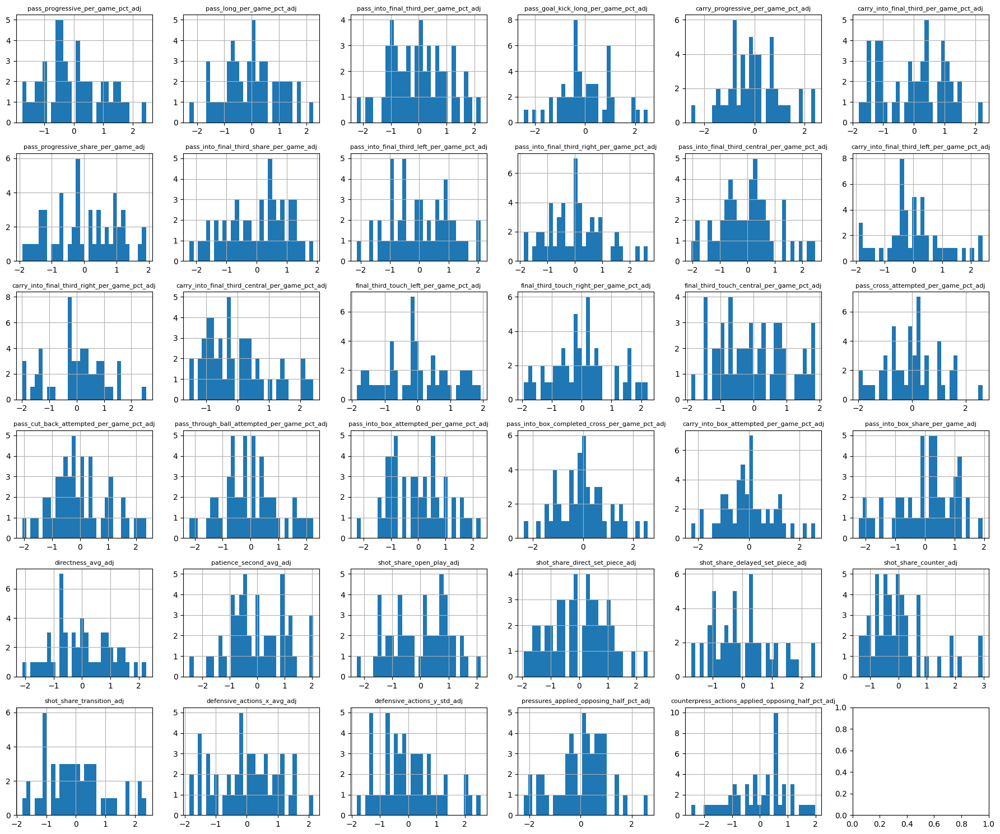

In [2763]:
plot_histogram_grid(team_wide, team_style_cols_adj)

### Correlation between variables

In [2764]:
corr_matrix = team_wide[team_style_cols_adj].corr().abs()

In [2765]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [2766]:
high_corr_pairs = (upper.stack()
                   .reset_index()
                   .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'correlation'})
                   .sort_values('correlation', ascending=False))

In [2767]:
pd.set_option('display.max_colwidth', None)

In [2768]:
high_corr_pairs[high_corr_pairs['correlation'] > 0.8]

,feature_1,feature_2,correlation
2,pass_progressive_per_game_pct_adj,pass_into_final_third_per_game_pct_adj,0.954654
1,pass_progressive_per_game_pct_adj,pass_long_per_game_pct_adj,0.878619
217,pass_progressive_share_per_game_adj,pass_into_final_third_share_per_game_adj,0.852166
1118,defensive_actions_x_avg_adj,pressures_applied_opposing_half_pct_adj,0.842860
330,pass_into_final_third_right_per_game_pct_adj,final_third_touch_right_per_game_pct_adj,0.837928
20,pass_progressive_per_game_pct_adj,pass_into_box_attempted_per_game_pct_adj,0.830609
37,pass_long_per_game_pct_adj,pass_into_final_third_per_game_pct_adj,0.830130


In [2769]:
pd.reset_option('display.max_colwidth')

In [2770]:
columns_to_drop_correlation = ['pass_into_final_third_per_game_pct', 'pass_long_per_game_pct', 'pressures_applied_opposing_half_pct', 
                               'pass_into_final_third_share_per_game', 'pass_into_final_third_right_per_game_pct', 'pass_into_box_attempted_per_game_pct']

In [2771]:
team_style_cols_no_side_cluster = [c for c in team_style_cols_no_side if c not in columns_to_drop_correlation]

### Cluster columns

In [2772]:
len(team_style_cols_no_side_cluster)

24

In [2773]:
team_style_cols_no_side_cluster_adj = [c + '_adj' for c in team_style_cols_no_side_cluster]

In [2774]:
len(team_style_cols_no_side_cluster_adj)

24

In [ ]:
X_team = team_wide[team_style_cols_no_side_cluster_adj]

In [2776]:
X_team.shape

(50, 24)

### Detect outliers

In [2777]:
dist_centre = np.sqrt((X_team ** 2).sum(axis=1))                                   # how unusual overall
d_team = pd.DataFrame(spatial.distance.cdist(X_team, X_team), index=X_team.index, columns=X_team.index)
knn_dist = d_team.apply(lambda r: r.drop(r.name).nsmallest(5).mean(), axis=1)        # how isolated from its closest teams

In [2778]:
outlier_check = pd.DataFrame({'dist_centre': dist_centre, 'knn_dist': knn_dist,
                              'max_abs_z': X_team.abs().max(axis=1),
                              'top_feature': X_team.abs().idxmax(axis=1)})
outlier_check['flag_centre'] = tukey_high(outlier_check['dist_centre'])
outlier_check['flag_knn'] = tukey_high(outlier_check['knn_dist'])

In [2779]:
outlier_check['team'] = outlier_check.index.get_level_values('team_id').map(team_id_to_team)

In [2780]:
outlier_check.sort_values('knn_dist', ascending=False).head(10)

,dist_centre,knn_dist,max_abs_z,top_feature,flag_centre,flag_knn,team
team_id,,,,,,,
19106,7.063319,6.360138,2.464808,pass_into_final_third_central_per_game_pct_adj,True,False,Nürnberg W
3164,6.528348,6.287559,2.612136,carry_into_box_attempted_per_game_pct_adj,False,False,SGS Essen 19/68
966,6.410561,5.888727,2.209348,shot_share_transition_adj,False,False,Liverpool WFC
19107,5.837291,5.850520,2.555365,defensive_actions_y_std_adj,False,False,RB Leipzig W
3152,5.095119,5.843583,2.369758,shot_share_transition_adj,False,False,AS Roma W
3278,5.551488,5.778942,2.458786,counterpress_actions_applied_opposing_half_pct...,False,False,Madrid CFF
3281,5.546721,5.752316,2.946779,shot_share_counter_adj,False,False,Sevilla FC
3275,6.467621,5.604677,2.440649,pass_progressive_per_game_pct_adj,False,False,SD Eibar
749,5.970463,5.597027,2.423584,carry_into_final_third_central_per_game_pct_adj,False,False,Tottenham Hotspur Women


### Rank feature on percentiles

In [2781]:
team_wide['all_teams'] = 'all'

In [2782]:
team_wide = to_percentile(team_wide, team_style_cols, group_cols=('all_teams',))       # raw

In [2783]:
team_wide = to_percentile(team_wide, team_style_cols_adj, group_cols=('all_teams',))       # raw

### Divide feature into groups

In [2784]:
team_feature_groups = {
    "build_up": [
        "pass_progressive_per_game_pct", "pass_goal_kick_long_per_game_pct",
        "carry_progressive_per_game_pct", "carry_into_final_third_per_game_pct",
        "pass_progressive_share_per_game", "directness_avg", "patience_second_avg"
    ],
    "channels": [
        "pass_into_final_third_central_per_game_pct",
        "carry_into_final_third_central_per_game_pct",
        "final_third_touch_central_per_game_pct",
    ],
    # "channels": [
    #     "pass_into_final_third_left_per_game_pct", "pass_into_final_third_central_per_game_pct",
    #     "carry_into_final_third_left_per_game_pct", "carry_into_final_third_central_per_game_pct",
    #     "carry_into_final_third_right_per_game_pct",
    #     "final_third_touch_left_per_game_pct", "final_third_touch_central_per_game_pct",
    #     "final_third_touch_right_per_game_pct"
    # ],
    "chance_creation": [
        "pass_cross_attempted_per_game_pct", "pass_cut_back_attempted_per_game_pct",
        "pass_through_ball_attempted_per_game_pct", "pass_into_box_completed_cross_per_game_pct",
        "carry_into_box_attempted_per_game_pct", "pass_into_box_share_per_game",
        "shot_share_open_play", "shot_share_direct_set_piece", "shot_share_delayed_set_piece"
    ],
    "pressing_transitions": [
        "defensive_actions_x_avg", "defensive_actions_y_std",
        "counterpress_actions_applied_opposing_half_pct", "shot_share_counter", "shot_share_transition"
    ],
}

In [2785]:
team_feature_groups_adj = {
    category: [f + '_adj' for f in features]
    for category, features in team_feature_groups.items()
}

In [2786]:
n_per_team_category = {
    'build_up': 5, 'channels': 2, 'chance_creation': 6, 'pressing_transitions': 3 
}

In [2787]:
all_grouped = [c for group in team_feature_groups.values() for c in group]

In [ ]:
missing = set(team_style_cols_no_side_cluster) - set(all_grouped)

In [2789]:
missing

set()

In [ ]:
spare = set(all_grouped) - set(team_style_cols_no_side_cluster)

In [2791]:
spare

set()

### Number of variables test

#### Stability and Separation


===== Team k=2 =====


,mean_silhouette,worst_cluster_silhouette,davies_bouldin,min_centroid_dist,min_centroid_dist_normalized
n,,,,,
2,0.3760,0.3749,1.0276,3.7616,1.0152
3,0.2668,0.2590,1.3963,3.7628,0.8276
4,0.2247,0.2178,1.5906,3.7759,0.7536
5,0.1969,0.1727,1.7478,3.7849,0.7046
6,0.1783,0.1405,1.8771,3.7944,0.6678
7,0.1672,0.1221,1.9544,3.7951,0.6454
8,0.1594,0.1112,2.0127,3.7988,0.6295
9,0.1527,0.1148,2.0626,3.8185,0.6163
10,0.1462,0.1036,2.1167,3.8251,0.6034



===== Team k=3 =====


,mean_silhouette,worst_cluster_silhouette,davies_bouldin,min_centroid_dist,min_centroid_dist_normalized
n,,,,,
2,0.4042,0.3426,0.8731,3.5041,0.9457
3,0.2615,0.2190,1.2701,3.6431,0.8013
4,0.2352,0.1785,1.4530,3.7359,0.7456
5,0.2020,0.1451,1.5842,3.7780,0.7033
6,0.1714,0.1200,1.7751,3.6748,0.6467
7,0.1607,0.1046,1.8635,3.6504,0.6208
8,0.1529,0.0772,1.9226,3.6658,0.6075
9,0.1428,0.0757,1.9878,3.6668,0.5918
10,0.1340,0.0735,2.0499,3.6674,0.5785



===== Team k=4 =====


,mean_silhouette,worst_cluster_silhouette,davies_bouldin,min_centroid_dist,min_centroid_dist_normalized
n,,,,,
2,0.4015,0.3651,0.8286,2.8231,0.7619
3,0.2826,0.2012,1.0668,3.7626,0.8276
4,0.2393,0.1489,1.1987,3.8022,0.7588
5,0.2008,0.1180,1.4208,3.7314,0.6946
6,0.1763,0.1280,1.5802,3.7484,0.6597
7,0.1710,0.1254,1.6154,3.8537,0.6554
8,0.1441,0.0291,1.6185,3.8400,0.6363
9,0.1376,0.0385,1.7534,3.8841,0.6269
10,0.1380,0.0675,1.8425,3.7928,0.5983


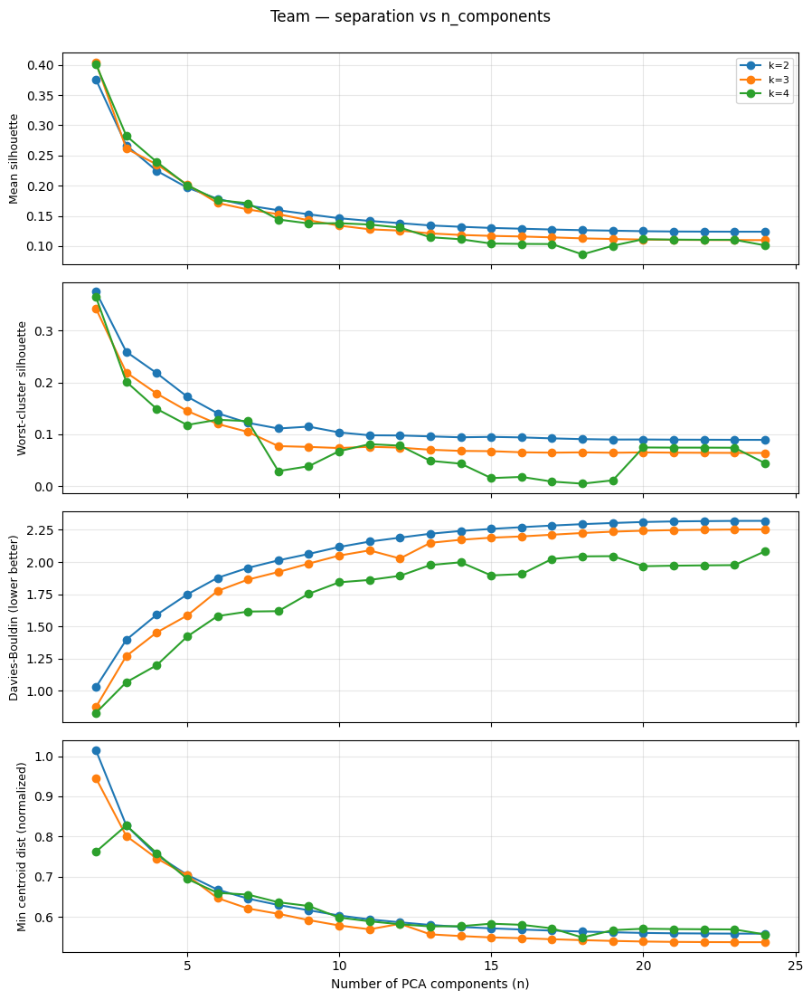

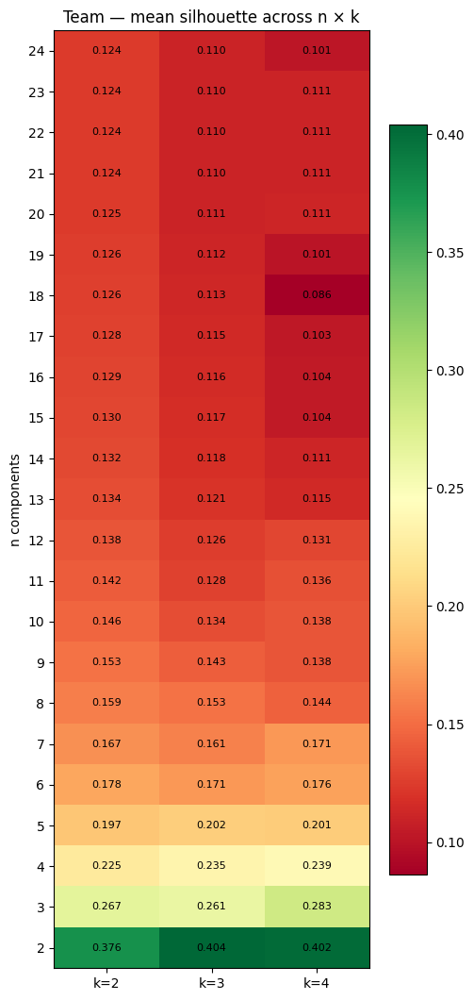

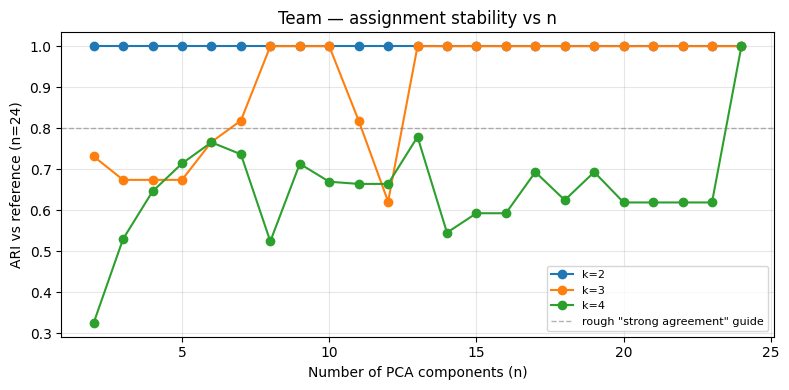


Team: possible outlier-driven splits (min cluster share < 10%):


,n,k,min_cluster_share
64,20,4,0.08
65,21,4,0.08
66,22,4,0.08
67,23,4,0.08



Team — quick verdict per k (ARI vs reference n=24):
  k=2: median ARI = 1.000 -> likely dimension-dilution artifact (assignments stable)
  k=3: median ARI = 1.000 -> likely dimension-dilution artifact (assignments stable)
  k=4: median ARI = 0.635 -> possible genuine divergence (assignments shift with n)


In [2792]:
team_results = run_position_separation_analysis(X_team, max_n_components=24, position_name='Team')

#### Comparison by teams

In [2793]:
results = pd.DataFrame(index=X_team.index)

In [2794]:
results['team_name'] = results.index.get_level_values('team_id').map(team_id_to_team)

In [2795]:
for n_components in range(7, 17):
    pca = PCA(n_components=n_components)
    pca.set_output(transform='pandas')
    X_team_pca = pca.fit_transform(X_team)

    for k in [2, 3, 4]:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_team_pca)
        results[f"k{k}_pca{n_components}"] = labels

In [2796]:
for n_components_x in range(7, 17):
    for n_components_y in range(7, 17):
        if n_components_x < n_components_y:
            for k in [2, 3, 4]:
                print(pd.crosstab(results[f'k{k}_pca{n_components_x}'], results[f'k{k}_pca{n_components_y}']))
                print()

k2_pca8   0   1
k2_pca7        
0        26   0
1         0  24

k3_pca8   0   1   2
k3_pca7            
0         0  16   4
1         0   0  13
2        16   1   0

k4_pca8   0  1   2   3
k4_pca7               
0         0  4   1   0
1         0  5   0  10
2         0  1  16   0
3        13  0   0   0

k2_pca9   0   1
k2_pca7        
0         0  26
1        24   0

k3_pca9   0   1   2
k3_pca7            
0         0   2  18
1        13   0   0
2         0  17   0

k4_pca9  0   1   2   3
k4_pca7               
0        4   1   0   0
1        0  12   1   2
2        4   0  13   0
3        0   0   0  13

k2_pca10   0   1
k2_pca7         
0         26   0
1          0  24

k3_pca10   0   1   2
k3_pca7             
0         16   4   0
1          0   0  13
2          0  17   0

k4_pca10   0  1   2   3
k4_pca7                
0          0  5   0   0
1         14  0   1   0
2          0  1  16   0
3          0  1   0  12

k2_pca11   0   1
k2_pca7         
0         26   0
1          0  24

k

In [2797]:
pd.set_option('display.max_columns', None)

In [2798]:
results

,team_name,k2_pca7,k3_pca7,k4_pca7,k2_pca8,k3_pca8,k4_pca8,k2_pca9,k3_pca9,k4_pca9,k2_pca10,k3_pca10,k4_pca10,k2_pca11,k3_pca11,k4_pca11,k2_pca12,k3_pca12,k4_pca12,k2_pca13,k3_pca13,k4_pca13,k2_pca14,k3_pca14,k4_pca14,k2_pca15,k3_pca15,k4_pca15,k2_pca16,k3_pca16,k4_pca16
team_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
746,Manchester City WFC,0,2,2,0,0,2,1,1,2,0,1,2,0,2,2,0,2,3,1,2,1,1,2,3,1,2,3,1,2,3
749,Tottenham Hotspur Women,0,2,0,0,0,2,1,1,0,0,1,1,0,2,1,0,2,0,1,2,3,1,2,0,1,2,0,1,2,0
924,Duisburg WFC,0,0,1,0,1,3,1,2,1,0,0,0,0,0,0,0,1,1,0,1,2,0,1,1,0,1,1,0,1,1
929,VfL Wolfsburg WFC,1,1,3,1,2,0,0,0,3,1,2,3,1,1,3,1,0,2,0,0,0,0,0,2,0,0,2,0,0,2
937,Barcelona WFC,0,0,1,0,1,1,1,2,1,0,0,0,0,0,0,0,1,1,0,1,2,0,1,1,0,1,1,0,1,1
965,Brighton & Hove Albion WFC,1,0,1,1,1,3,0,2,1,1,0,0,1,0,0,1,0,2,0,0,2,0,0,2,0,0,2,0,0,2
966,Liverpool WFC,1,1,3,1,2,0,0,0,3,1,2,3,1,1,3,1,0,2,0,0,0,0,0,2,0,0,2,0,0,2
967,Everton LFC,0,2,2,0,0,2,1,1,2,0,1,2,0,2,2,0,2,3,1,2,1,1,2,3,1,2,3,1,2,3
968,Arsenal WFC,1,1,3,1,2,0,0,0,3,1,2,3,1,1,3,1,0,2,0,0,0,0,0,2,0,0,2,0,0,2


In [2799]:
pd.reset_option('display.max_columns')

### KMeans Clustering

#### PCA

In [2800]:
n_features = 14

In [2801]:
pca_reduced_final = PCA(n_components=n_features)

In [2802]:
pca_reduced_final.set_output(transform='pandas')

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",14
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD

In [2803]:
X_team_pca_final = pca_reduced_final.fit_transform(X_team)

#### KMeans with k = 2

In [2804]:
k = 2

In [2805]:
kmeans_2 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [2806]:
team_wide['kmeans_2_cluster'] = kmeans_2.fit_predict(X_team_pca_final)  # or X, if using raw features

In [2807]:
team_wide['kmeans_2_cluster'] = team_wide['kmeans_2_cluster'].values

In [2808]:
team_wide['kmeans_2_cluster'].value_counts()

kmeans_2_cluster
0    28
1    22
Name: count, dtype: int64

In [2809]:
pd.crosstab(team_wide['kmeans_2_cluster'], team_wide['league'])

league,FA Women's Super League,Frauen Bundesliga,Liga F,Serie A Women
kmeans_2_cluster,,,,
0,7,8,8,5
1,5,4,8,5


In [2810]:
# bring labels back to the original unstandardized data for interpretation
team_wide = compute_soft_cluster_spectrum(
    X_pca=X_team_pca_final,           
    kmeans_model=kmeans_2, 
    stats_df=team_wide,
    sigma_quantile=0.5
)

In [2811]:
cluster_profiles = team_wide.groupby('kmeans_2_cluster')[team_style_cols + ['possession_pct', 'field_tilt', 'ppda_inv', 'context_score']].mean()

In [2812]:
cluster_profiles.T.style.background_gradient(cmap='coolwarm', axis=1)

kmeans_2_cluster,0,1
pass_progressive_per_game_pct,0.235359,0.197981
pass_long_per_game_pct,0.144033,0.124231
pass_into_final_third_per_game_pct,0.117673,0.100568
pass_goal_kick_long_per_game_pct,0.466122,0.377821
carry_progressive_per_game_pct,0.073051,0.076953
carry_into_final_third_per_game_pct,0.031722,0.032157
pass_progressive_share_per_game,0.808573,0.765407
pass_into_final_third_share_per_game,0.830708,0.800030
pass_into_final_third_left_per_game_pct,0.355013,0.379221
pass_into_final_third_right_per_game_pct,0.392320,0.375815


In [2813]:
cluster_profiles_adj = team_wide.groupby('kmeans_2_cluster')[team_style_cols_adj].mean()

In [2814]:
cluster_profiles_adj.T.style.background_gradient(cmap='coolwarm', axis=1)

kmeans_2_cluster,0,1
pass_progressive_per_game_pct_adj,0.690254,-0.878505
pass_long_per_game_pct_adj,0.581663,-0.740298
pass_into_final_third_per_game_pct_adj,0.683523,-0.869939
pass_goal_kick_long_per_game_pct_adj,0.397840,-0.506342
carry_progressive_per_game_pct_adj,-0.206719,0.263097
carry_into_final_third_per_game_pct_adj,-0.087065,0.110810
pass_progressive_share_per_game_adj,0.629733,-0.801478
pass_into_final_third_share_per_game_adj,0.567228,-0.721927
pass_into_final_third_left_per_game_pct_adj,-0.374185,0.476236
pass_into_final_third_right_per_game_pct_adj,0.135179,-0.172046


In [2815]:
cluster_profiles_league = team_wide.groupby(['league', 'kmeans_2_cluster'])[team_style_cols + ['possession_pct', 'field_tilt', 'ppda_inv', 'context_score']].mean()

In [2816]:
cluster_profiles_league.T.style.background_gradient(cmap='coolwarm', axis=1)

In [2817]:
cluster_profiles_league_adj = team_wide.groupby(['league', 'kmeans_2_cluster'])[team_style_cols_adj].mean()

In [2818]:
cluster_profiles_league_adj.T.style.background_gradient(cmap='coolwarm', axis=1)

In [2819]:
for c in sorted(team_wide['kmeans_2_cluster'].unique()):
    print(f"--- Cluster {c} ---")
    subset = team_wide[team_wide['kmeans_2_cluster'] == c].copy()
    subset['team_id'] = subset.index.get_level_values('team_id')
    subset['team'] = subset['team_id'].map(team_id_to_team)
    print(subset[['team_id', 'team', 'league', 'possession_pct', 'field_tilt', 'ppda_inv', 'context_score', 'dist_to_cluster_0_k2', 'dist_to_cluster_1_k2', 'sim_cluster_0_k2', 'sim_cluster_1_k2']].to_string(index=False))

--- Cluster 0 ---
 team_id                       team                  league  possession_pct  field_tilt  ppda_inv  context_score  dist_to_cluster_0_k2  dist_to_cluster_1_k2  sim_cluster_0_k2  sim_cluster_1_k2
     924               Duisburg WFC       Frauen Bundesliga        0.357232    0.265166 -8.847206      -1.810990              4.943501              5.253069          0.521556          0.478444
     929          VfL Wolfsburg WFC       Frauen Bundesliga        0.614466    0.717573 -3.790293       1.615784              4.883997              6.280831          0.604984          0.395016
     937              Barcelona WFC                  Liga F        0.701676    0.915062 -4.319804       2.459919              2.456789              2.831195          0.513526          0.486474
     965 Brighton & Hove Albion WFC FA Women's Super League        0.452053    0.400819 -7.633803      -0.564557              4.568911              6.460804          0.638848          0.361152
     966         

In [2820]:
team_wide.groupby('kmeans_2_cluster')['context_score'].mean()

kmeans_2_cluster
0    0.069567
1   -0.088539
Name: context_score, dtype: float64

In [2821]:
team_wide.groupby('kmeans_2_cluster')['context_score'].std()

kmeans_2_cluster
0    1.036419
1    0.890673
Name: context_score, dtype: float64

In [2822]:
pca_2d = PCA(n_components=2)

In [2823]:
coords = pca_2d.fit_transform(X_team_pca_final)  # or X

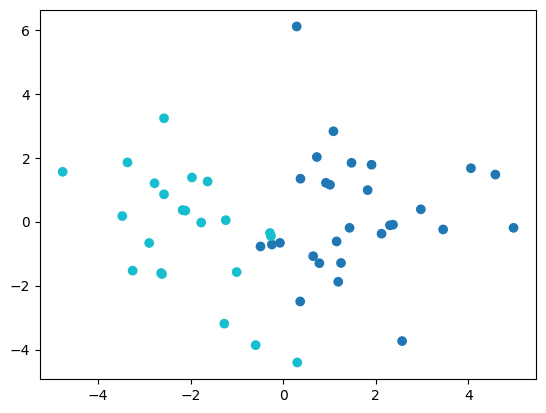

In [2824]:
plt.scatter(coords[:,0], coords[:,1], c=team_wide['kmeans_2_cluster'], cmap='tab10')

In [2825]:
plt.show()

In [ ]:
f_stats_adj = compute_f_stats_with_p(team_wide, team_style_cols_no_side_cluster_adj, 'kmeans_2_cluster')

In [2827]:
f_stats_adj.sort_values('f_pvalue')

,f_stat,f_pvalue
feature,,
pass_progressive_per_game_pct_adj,46.645045,8.508185e-12
pass_progressive_share_per_game_adj,33.950886,5.652093e-09
counterpress_actions_applied_opposing_half_pct_adj,24.162376,8.854533e-07
defensive_actions_x_avg_adj,23.251560,1.421351e-06
directness_avg_adj,19.739106,8.876624e-06
patience_second_avg_adj,16.958090,3.821414e-05
pass_into_box_share_per_game_adj,14.754411,1.224607e-04
pass_goal_kick_long_per_game_pct_adj,10.262013,1.357975e-03
pass_cross_attempted_per_game_pct_adj,8.840103,2.946825e-03


In [ ]:
centroid_df = backproject_cluster_centroids(
    pca_reduced_final,                        # your fitted PCA object that produced X_pca_final
    kmeans_2.cluster_centers_,
    team_style_cols_no_side_cluster_adj
)

In [2829]:
pairwise_cluster_deltas(centroid_df, 'Cluster_0', 'Cluster_1')

,feature,delta,higher_in
0,pass_progressive_per_game_pct_adj,1.561926,Cluster_0
1,pass_progressive_share_per_game_adj,1.453312,Cluster_0
2,counterpress_actions_applied_opposing_half_pct...,1.267358,Cluster_0
3,defensive_actions_x_avg_adj,1.259893,Cluster_0
4,directness_avg_adj,1.165792,Cluster_0
5,patience_second_avg_adj,-1.111548,Cluster_1
6,pass_into_box_share_per_game_adj,1.052877,Cluster_0
7,pass_goal_kick_long_per_game_pct_adj,0.916233,Cluster_0
8,pass_cross_attempted_per_game_pct_adj,0.844828,Cluster_0
9,pass_through_ball_attempted_per_game_pct_adj,0.635215,Cluster_0


In [2830]:
rank_cluster_driving_features(centroid_df)

,feature,cross_cluster_std
0,pass_progressive_per_game_pct_adj,1.104448
1,pass_progressive_share_per_game_adj,1.027647
2,counterpress_actions_applied_opposing_half_pct...,0.896157
3,defensive_actions_x_avg_adj,0.890879
4,directness_avg_adj,0.824339
5,patience_second_avg_adj,0.785983
6,pass_into_box_share_per_game_adj,0.744497
7,pass_goal_kick_long_per_game_pct_adj,0.647874
8,pass_cross_attempted_per_game_pct_adj,0.597384
9,pass_through_ball_attempted_per_game_pct_adj,0.449165


In [2831]:
top_features_by_category_combined_adj, diag = select_features_combined(
    team_wide, centroid_df, team_feature_groups_adj, n_per_team_category,
    cluster_col='kmeans_2_cluster', alpha=0.05,
    weight_f=0.5, weight_pca=0.5, anova_method='welch'
)

[channels] only 0/2 features significant (p<0.05); backfilled: ['pass_into_final_third_central_per_game_pct_adj', 'carry_into_final_third_central_per_game_pct_adj']
[chance_creation] only 3/6 features significant (p<0.05); backfilled: ['shot_share_open_play_adj', 'shot_share_direct_set_piece_adj', 'pass_into_box_completed_cross_per_game_pct_adj']
[pressing_transitions] only 2/3 features significant (p<0.05); backfilled: ['shot_share_counter_adj']


In [2832]:
top_features_by_category_combined = {
    category: [f.removesuffix('_adj') for f in features]
    for category, features in top_features_by_category_combined_adj.items()
}

In [2833]:
radar_sets = {
    'build_up_channels': top_features_by_category_combined['build_up'] + top_features_by_category_combined['channels'],
    'chance_creation_pressing_transitions': top_features_by_category_combined['chance_creation'] + top_features_by_category_combined['pressing_transitions'],
}

In [2834]:
export_team_cluster_comparison_charts(team_wide, radar_sets, 'kmeans_2_cluster', n_clusters=2)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\build_up_channels_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\chance_creation_pressing_transitions_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\build_up_channels_raw.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\chance_creation_pressing_transitions_raw.png']

In [2835]:
export_team_cluster_comparison_charts_by_league(team_wide, radar_sets, 'kmeans_2_cluster', n_clusters=2)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\build_up_channels_adj_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\chance_creation_pressing_transitions_adj_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\build_up_channels_raw_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\chance_creation_pressing_transitions_raw_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\build_up_channels_adj_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\chance_creation_pressing_transitions_adj_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\build_up_channels_raw_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\team

In [2836]:
export_all_team_cluster_charts(team_wide, radar_sets, 'kmeans_2_cluster', n_clusters=2, team_id_to_team=team_id_to_team, team_id_to_league=team_id_to_league)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\build_up_channels_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\chance_creation_pressing_transitions_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\build_up_channels_raw.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\chance_creation_pressing_transitions_raw.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\build_up_channels_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\chance_creation_pressing_transitions_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\

In [2837]:
export_all_team_cluster_charts_league_aware(team_wide, radar_sets, 'kmeans_2_cluster', n_clusters=2, team_id_to_team=team_id_to_team, team_id_to_league=team_id_to_league)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\build_up_channels_adj_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\chance_creation_pressing_transitions_adj_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\build_up_channels_raw_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\chance_creation_pressing_transitions_raw_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\build_up_channels_adj_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\chance_creation_pressing_transitions_adj_league.png',
 'e:\

In [2838]:
export_group_profile(team_wide, radar_sets, 'kmeans_2_cluster', 2)

'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\group_profile.png'

In [2839]:
export_group_profile_by_league(team_wide, radar_sets, 'kmeans_2_cluster', 2)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\group_profile_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\group_profile_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\group_profile_Liga_F.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\group_profile_Serie_A_Women.png']

In [2840]:
export_team_profiles(team_wide, radar_sets, 'kmeans_2_cluster', 2, team_id_to_team, team_id_to_league)

saved 50 team profiles (k = 2) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k2


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_United_W_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Aston_Villa_W_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\West_Ham_United_LFC_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Chelsea_FCW_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Euro

In [2841]:
export_team_profiles_vs_league(team_wide, radar_sets, 'kmeans_2_cluster', 2, team_id_to_team, team_id_to_league)

saved 50 team profiles (k = 2) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k2


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_United_W_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Aston_Villa_W_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\West_Ham_United_LFC_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Chelsea_FCW_FA_Womens_Super_League\\team_pr

In [2842]:
export_pitch_profiles_by_group(team_wide, 'kmeans_2_cluster', 2)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\pitch_profiles.png']

In [2843]:
export_pitch_profiles_by_group_by_league(team_wide, 'kmeans_2_cluster', 2)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\pitch_profiles_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\pitch_profiles_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\pitch_profiles_Liga_F.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\pitch_profiles_Serie_A_Women.png']

In [2844]:
export_pitch_profile_teams_vs_group(team_wide, 'kmeans_2_cluster', 2, team_id_to_team, team_id_to_league)

saved team-vs-group pitch profiles (passes and carries, k = 2) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k2


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_United_W_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Aston_Villa_W_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\West_Ham_United_LFC_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Chelsea_FCW_FA_Womens_Sup

In [2845]:
export_pitch_profile_teams_vs_group(team_wide, 'kmeans_2_cluster', 2, team_id_to_team, team_id_to_league, league_only=True)

saved team-vs-group pitch profiles (passes and carries, k = 2) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k2


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_United_W_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Aston_Villa_W_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\West_Ham_United_LFC_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\p

In [2846]:
export_group_strips(team_wide, 'kmeans_2_cluster', 2, ["context_score", "possession_pct", "field_tilt", "ppda_inv"], names=team_id_to_team, label_ids=None,
                        col_labels={"context_score": "Strength"}, col_formats={"possession_pct": "pct", "field_tilt": "pct"})

'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\strength_dominance_strips.png'

In [2847]:
export_group_strips_by_league(team_wide, 'kmeans_2_cluster', 2, ["context_score", "possession_pct", "field_tilt", "ppda_inv"], names=team_id_to_team, label_ids=None,
                        col_labels={"context_score": "Strength"}, col_formats={"possession_pct": "pct", "field_tilt": "pct"})

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\strength_dominance_strips_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\strength_dominance_strips_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\strength_dominance_strips_Liga_F.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\strength_dominance_strips_Serie_A_Women.png']

In [2848]:
export_group_type_shares(team_wide, 'kmeans_2_cluster', 2)

'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_by_group.png'

In [2849]:
export_group_type_shares_by_league(team_wide, "kmeans_2_cluster", 2)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_by_group_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_by_group_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_by_group_Liga_F.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_by_group_Serie_A_Women.png']

In [2850]:
export_team_type_shares(team_wide, 'kmeans_2_cluster', 2, team_id_to_team)             # one per position

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_Goalkeeper.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_Center_Back.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_FullWing_Back.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_Center_Midfield.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_Center_Midfield_hard.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_Center_Midfield_sub.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_Winger.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_Center_Forward.png']

In [2851]:
export_team_type_shares_by_league(team_wide, "kmeans_2_cluster", 2, team_id_to_team)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_Goalkeeper_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_Center_Back_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_FullWing_Back_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_Center_Midfield_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_Center_Midfield_hard_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_Center_Midfield_sub_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\type_shares_teams_Winger_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-

In [2852]:
export_team_type_vs_group(team_wide, 'kmeans_2_cluster', 2, team_id_to_team, team_id_to_league)

saved 50 team-vs-group player-type plots (k = 2) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k2


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_United_W_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Aston_Villa_W_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\West_Ham_United_LFC_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Chelsea_FCW_FA_Womens_Super_League\\t

In [2853]:
export_team_type_vs_group(team_wide, "kmeans_2_cluster", 2, team_id_to_team, team_id_to_league, league_only=True)

saved 50 team-vs-group player-type plots (k = 2) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k2


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_United_W_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Manchester_City_WFC_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\Aston_Villa_W_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\West_Ham_United_LFC_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\

In [2854]:
export_league_mix(team_wide, 'kmeans_2_cluster', 2)

saved league mix (k = 2) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k2\league_mix.png


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\league_mix.png']

In [2855]:
export_close_team_strip(D_style_adj, team_wide, 'kmeans_2_cluster', 2, team_id_to_team)

saved close-teams strip (k = 2) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k2\close_teams.png


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\close_teams.png']

In [2856]:
export_similarity_gap_vs_distance(D_style_adj, team_wide, 'kmeans_2_cluster', 2, team_id_to_team)

saved similarity gap vs distance (k = 2) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k2\similarity_gap_vs_distance.png


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k2\\similarity_gap_vs_distance.png']

#### KMeans with k = 3

In [2857]:
k = 3

In [2858]:
kmeans_3 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [2859]:
team_wide['kmeans_3_cluster'] = kmeans_3.fit_predict(X_team_pca_final)  # or X, if using raw features

In [2860]:
team_wide['kmeans_3_cluster'] = team_wide['kmeans_3_cluster'].values

In [2861]:
team_wide['kmeans_3_cluster'].value_counts()

kmeans_3_cluster
1    19
2    16
0    15
Name: count, dtype: int64

In [2862]:
pd.crosstab(team_wide['kmeans_3_cluster'], team_wide['league'])

league,FA Women's Super League,Frauen Bundesliga,Liga F,Serie A Women
kmeans_3_cluster,,,,
0,4,3,5,3
1,3,6,6,4
2,5,3,5,3


In [2863]:
pd.crosstab(team_wide['kmeans_2_cluster'], team_wide['kmeans_3_cluster'])

kmeans_3_cluster,0,1,2
kmeans_2_cluster,,,
0,15,13,0
1,0,6,16


In [2864]:
# bring labels back to the original unstandardized data for interpretation
team_wide = compute_soft_cluster_spectrum(
    X_pca=X_team_pca_final,           
    kmeans_model=kmeans_3, 
    stats_df=team_wide,
    sigma_quantile=0.5
)

In [2865]:
cluster_profiles = team_wide.groupby('kmeans_3_cluster')[team_style_cols + ['possession_pct', 'field_tilt', 'ppda_inv', 'context_score']].mean()

In [2866]:
cluster_profiles.T.style.background_gradient(cmap='coolwarm', axis=1)

kmeans_3_cluster,0,1,2
pass_progressive_per_game_pct,0.249650,0.214330,0.195537
pass_long_per_game_pct,0.154782,0.129868,0.123550
pass_into_final_third_per_game_pct,0.122985,0.109064,0.099397
pass_goal_kick_long_per_game_pct,0.523062,0.370837,0.404478
carry_progressive_per_game_pct,0.077588,0.069123,0.078828
carry_into_final_third_per_game_pct,0.033245,0.030087,0.032833
pass_progressive_share_per_game,0.808695,0.800977,0.758127
pass_into_final_third_share_per_game,0.830219,0.826380,0.794124
pass_into_final_third_left_per_game_pct,0.352911,0.356326,0.388711
pass_into_final_third_right_per_game_pct,0.393355,0.383087,0.379619


In [2867]:
cluster_profiles_adj = team_wide.groupby('kmeans_3_cluster')[team_style_cols_adj].mean()

In [2868]:
cluster_profiles_adj.T.style.background_gradient(cmap='coolwarm', axis=1)

kmeans_3_cluster,0,1,2
pass_progressive_per_game_pct_adj,1.133415,-0.083017,-0.963994
pass_long_per_game_pct_adj,1.060085,-0.146172,-0.820250
pass_into_final_third_per_game_pct_adj,1.057475,-0.054656,-0.926479
pass_goal_kick_long_per_game_pct_adj,0.742900,-0.277805,-0.366575
carry_progressive_per_game_pct_adj,0.277685,-0.739939,0.618348
carry_into_final_third_per_game_pct_adj,0.268773,-0.483550,0.322240
pass_progressive_share_per_game_adj,0.589017,0.458053,-1.096142
pass_into_final_third_share_per_game_adj,0.576348,0.355135,-0.962050
pass_into_final_third_left_per_game_pct_adj,-0.355816,-0.341730,0.739382
pass_into_final_third_right_per_game_pct_adj,0.064399,0.004921,-0.066217


In [2869]:
cluster_profiles_league = team_wide.groupby(['league', 'kmeans_3_cluster'])[team_style_cols + ['possession_pct', 'field_tilt', 'ppda_inv', 'context_score']].mean()

In [2870]:
cluster_profiles_league.T.style.background_gradient(cmap='coolwarm', axis=1)

In [2871]:
cluster_profiles_league_adj = team_wide.groupby(['league', 'kmeans_3_cluster'])[team_style_cols_adj].mean()

In [2872]:
cluster_profiles_league_adj.T.style.background_gradient(cmap='coolwarm', axis=1)

In [2873]:
for c in sorted(team_wide['kmeans_3_cluster'].unique()):
    print(f"--- Cluster {c} ---")
    subset = team_wide[team_wide['kmeans_3_cluster'] == c].copy()
    subset['team_id'] = subset.index.get_level_values('team_id')
    subset['team'] = subset['team_id'].map(team_id_to_team)
    print(subset[['team_id', 'team', 'league', 'possession_pct', 'field_tilt', 'ppda_inv', 'context_score', 'dist_to_cluster_0_k3', 'dist_to_cluster_1_k3', 'dist_to_cluster_2_k3', 'sim_cluster_0_k3', 'sim_cluster_1_k3', 'sim_cluster_2_k3']].to_string(index=False))

--- Cluster 0 ---
 team_id                       team                  league  possession_pct  field_tilt  ppda_inv  context_score  dist_to_cluster_0_k3  dist_to_cluster_1_k3  dist_to_cluster_2_k3  sim_cluster_0_k3  sim_cluster_1_k3  sim_cluster_2_k3
     929          VfL Wolfsburg WFC       Frauen Bundesliga        0.614466    0.717573 -3.790293       1.615784              4.653309              5.624797              6.680610          0.445575          0.330451          0.223974
     965 Brighton & Hove Albion WFC FA Women's Super League        0.452053    0.400819 -7.633803      -0.564557              4.840283              5.202686              6.806945          0.416579          0.373576          0.209845
     966              Liverpool WFC FA Women's Super League        0.451104    0.425980 -6.652439      -0.075460              4.983842              6.167061              8.448642          0.520298          0.350526          0.129177
     968                Arsenal WFC FA Women's Sup

In [2874]:
team_wide.groupby('kmeans_3_cluster')['context_score'].mean()

kmeans_3_cluster
0    0.000419
1    0.141305
2   -0.168192
Name: context_score, dtype: float64

In [2875]:
team_wide.groupby('kmeans_3_cluster')['context_score'].std()

kmeans_3_cluster
0    1.006906
1    1.002271
2    0.925989
Name: context_score, dtype: float64

In [2876]:
pca_2d = PCA(n_components=2)

In [2877]:
coords = pca_2d.fit_transform(X_team_pca_final)  # or X

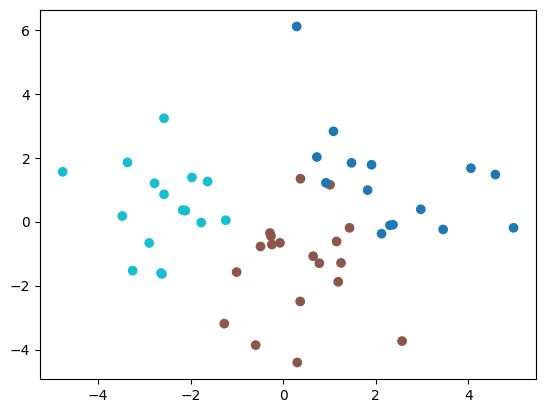

In [2878]:
plt.scatter(coords[:,0], coords[:,1], c=team_wide['kmeans_3_cluster'], cmap='tab10')

In [ ]:
f_stats_adj = compute_f_stats_with_p(team_wide, team_style_cols_no_side_cluster_adj, 'kmeans_3_cluster')

In [2880]:
f_stats_adj.sort_values('f_pvalue')

,f_stat,f_pvalue
feature,,
pass_progressive_share_per_game_adj,49.762314,1.564050e-11
pass_progressive_per_game_pct_adj,41.819921,8.296969e-10
shot_share_open_play_adj,31.372035,1.540456e-07
directness_avg_adj,28.190968,7.558038e-07
pass_into_box_share_per_game_adj,24.305453,5.273974e-06
carry_progressive_per_game_pct_adj,23.194269,9.192392e-06
counterpress_actions_applied_opposing_half_pct_adj,16.349940,2.816150e-04
carry_into_box_attempted_per_game_pct_adj,16.246922,2.965007e-04
defensive_actions_x_avg_adj,15.731277,3.837042e-04


In [ ]:
centroid_df = backproject_cluster_centroids(
    pca_reduced_final,                        # your fitted PCA object that produced X_pca_final
    kmeans_3.cluster_centers_,
    team_style_cols_no_side_cluster_adj
)

In [2882]:
pairwise_cluster_deltas(centroid_df, 'Cluster_0', 'Cluster_1')

,feature,delta,higher_in
0,shot_share_open_play_adj,-1.490216,Cluster_1
1,directness_avg_adj,1.289956,Cluster_0
2,shot_share_direct_set_piece_adj,1.227197,Cluster_0
3,carry_into_box_attempted_per_game_pct_adj,1.201859,Cluster_0
4,pass_progressive_per_game_pct_adj,1.169623,Cluster_0
5,pass_goal_kick_long_per_game_pct_adj,1.001789,Cluster_0
6,carry_progressive_per_game_pct_adj,0.951261,Cluster_0
7,defensive_actions_y_std_adj,-0.911994,Cluster_1
8,shot_share_transition_adj,0.759481,Cluster_0
9,carry_into_final_third_per_game_pct_adj,0.736356,Cluster_0


In [2883]:
pairwise_cluster_deltas(centroid_df, 'Cluster_0', 'Cluster_2')

,feature,delta,higher_in
0,pass_progressive_per_game_pct_adj,2.030058,Cluster_0
1,pass_progressive_share_per_game_adj,1.724464,Cluster_0
2,directness_avg_adj,1.671010,Cluster_0
3,shot_share_open_play_adj,-1.486862,Cluster_2
4,patience_second_avg_adj,-1.436405,Cluster_2
5,counterpress_actions_applied_opposing_half_pct...,1.396566,Cluster_0
6,pass_into_box_share_per_game_adj,1.307712,Cluster_0
7,defensive_actions_x_avg_adj,1.241346,Cluster_0
8,pass_goal_kick_long_per_game_pct_adj,1.159635,Cluster_0
9,shot_share_direct_set_piece_adj,1.056263,Cluster_0


In [2884]:
pairwise_cluster_deltas(centroid_df, 'Cluster_1', 'Cluster_2')

,feature,delta,higher_in
0,pass_progressive_share_per_game_adj,1.587638,Cluster_1
1,pass_into_box_share_per_game_adj,1.472515,Cluster_1
2,carry_progressive_per_game_pct_adj,-1.308695,Cluster_2
3,carry_into_box_attempted_per_game_pct_adj,-1.066708,Cluster_2
4,patience_second_avg_adj,-1.062616,Cluster_2
5,defensive_actions_x_avg_adj,0.944795,Cluster_1
6,pass_progressive_per_game_pct_adj,0.860435,Cluster_1
7,pass_into_final_third_central_per_game_pct_adj,0.852092,Cluster_1
8,carry_into_final_third_per_game_pct_adj,-0.775262,Cluster_2
9,pass_cut_back_attempted_per_game_pct_adj,-0.768558,Cluster_2


In [2885]:
rank_cluster_driving_features(centroid_df)

,feature,cross_cluster_std
0,pass_progressive_per_game_pct_adj,1.018946
1,pass_progressive_share_per_game_adj,0.958566
2,directness_avg_adj,0.875734
3,shot_share_open_play_adj,0.859410
4,pass_into_box_share_per_game_adj,0.806801
5,patience_second_avg_adj,0.745222
6,counterpress_actions_applied_opposing_half_pct...,0.698367
7,carry_progressive_per_game_pct_adj,0.676429
8,shot_share_direct_set_piece_adj,0.664696
9,carry_into_box_attempted_per_game_pct_adj,0.658356


In [2886]:
top_features_by_category_combined_adj, diag = select_features_combined(
    team_wide, centroid_df, team_feature_groups_adj, n_per_team_category,
    cluster_col='kmeans_3_cluster', alpha=0.05,
    weight_f=0.5, weight_pca=0.5, anova_method='welch'
)

[channels] only 1/2 features significant (p<0.05); backfilled: ['final_third_touch_central_per_game_pct_adj']
[chance_creation] only 4/6 features significant (p<0.05); backfilled: ['pass_cross_attempted_per_game_pct_adj', 'pass_cut_back_attempted_per_game_pct_adj']


In [2887]:
top_features_by_category_combined = {
    category: [f.removesuffix('_adj') for f in features]
    for category, features in top_features_by_category_combined_adj.items()
}

In [2888]:
radar_sets = {
    'build_up_channels': top_features_by_category_combined['build_up'] + top_features_by_category_combined['channels'],
    'chance_creation_pressing_transitions': top_features_by_category_combined['chance_creation'] + top_features_by_category_combined['pressing_transitions'],
}

In [2889]:
export_team_cluster_comparison_charts(team_wide, radar_sets, 'kmeans_3_cluster', n_clusters=3)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\build_up_channels_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\chance_creation_pressing_transitions_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\build_up_channels_raw.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\chance_creation_pressing_transitions_raw.png']

In [2890]:
export_team_cluster_comparison_charts_by_league(team_wide, radar_sets, 'kmeans_3_cluster', n_clusters=3)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\build_up_channels_adj_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\chance_creation_pressing_transitions_adj_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\build_up_channels_raw_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\chance_creation_pressing_transitions_raw_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\build_up_channels_adj_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\chance_creation_pressing_transitions_adj_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\build_up_channels_raw_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\team

In [2891]:
export_all_team_cluster_charts(team_wide, radar_sets, 'kmeans_3_cluster', n_clusters=3, team_id_to_team=team_id_to_team, team_id_to_league=team_id_to_league)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\build_up_channels_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\chance_creation_pressing_transitions_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\build_up_channels_raw.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\chance_creation_pressing_transitions_raw.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\build_up_channels_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\chance_creation_pressing_transitions_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\

In [2892]:
export_all_team_cluster_charts_league_aware(team_wide, radar_sets, 'kmeans_3_cluster', n_clusters=3, team_id_to_team=team_id_to_team, team_id_to_league=team_id_to_league)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\build_up_channels_adj_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\chance_creation_pressing_transitions_adj_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\build_up_channels_raw_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\chance_creation_pressing_transitions_raw_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\build_up_channels_adj_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\chance_creation_pressing_transitions_adj_league.png',
 'e:\

In [2893]:
export_group_profile(team_wide, radar_sets, 'kmeans_3_cluster', 3)

'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\group_profile.png'

In [2894]:
export_group_profile_by_league(team_wide, radar_sets, 'kmeans_3_cluster', 3)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\group_profile_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\group_profile_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\group_profile_Liga_F.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\group_profile_Serie_A_Women.png']

In [2895]:
export_team_profiles(team_wide, radar_sets, 'kmeans_3_cluster', 3, team_id_to_team, team_id_to_league)

saved 50 team profiles (k = 3) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k3


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_United_W_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Aston_Villa_W_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\West_Ham_United_LFC_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Chelsea_FCW_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Euro

In [2896]:
export_team_profiles_vs_league(team_wide, radar_sets, 'kmeans_3_cluster', 3, team_id_to_team, team_id_to_league)

saved 50 team profiles (k = 3) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k3


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_United_W_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Aston_Villa_W_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\West_Ham_United_LFC_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Chelsea_FCW_FA_Womens_Super_League\\team_pr

In [2897]:
export_pitch_profiles_by_group(team_wide, 'kmeans_3_cluster', 3)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\pitch_profiles.png']

In [2898]:
export_pitch_profiles_by_group_by_league(team_wide, 'kmeans_3_cluster', 3)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\pitch_profiles_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\pitch_profiles_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\pitch_profiles_Liga_F.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\pitch_profiles_Serie_A_Women.png']

In [2899]:
export_pitch_profile_teams_vs_group(team_wide, 'kmeans_3_cluster', 3, team_id_to_team, team_id_to_league)

saved team-vs-group pitch profiles (passes and carries, k = 3) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k3


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_United_W_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Aston_Villa_W_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\West_Ham_United_LFC_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Chelsea_FCW_FA_Womens_Sup

In [2900]:
export_pitch_profile_teams_vs_group(team_wide, 'kmeans_3_cluster', 3, team_id_to_team, team_id_to_league, league_only=True)

saved team-vs-group pitch profiles (passes and carries, k = 3) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k3


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_United_W_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Aston_Villa_W_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\West_Ham_United_LFC_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\p

In [2901]:
export_group_strips(team_wide, 'kmeans_3_cluster', 3, ["context_score", "possession_pct", "field_tilt", "ppda_inv"], names=team_id_to_team, label_ids=None,
                        col_labels={"context_score": "Strength"}, col_formats={"possession_pct": "pct", "field_tilt": "pct"})

'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\strength_dominance_strips.png'

In [2902]:
export_group_strips_by_league(team_wide, 'kmeans_3_cluster', 3, ["context_score", "possession_pct", "field_tilt", "ppda_inv"], names=team_id_to_team, label_ids=None,
                        col_labels={"context_score": "Strength"}, col_formats={"possession_pct": "pct", "field_tilt": "pct"})

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\strength_dominance_strips_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\strength_dominance_strips_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\strength_dominance_strips_Liga_F.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\strength_dominance_strips_Serie_A_Women.png']

In [2903]:
export_group_type_shares(team_wide, 'kmeans_3_cluster', 3)

'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_by_group.png'

In [2904]:
export_group_type_shares_by_league(team_wide, "kmeans_3_cluster", 3)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_by_group_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_by_group_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_by_group_Liga_F.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_by_group_Serie_A_Women.png']

In [2905]:
export_team_type_shares(team_wide, 'kmeans_3_cluster', 3, team_id_to_team)             # one per position

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_Goalkeeper.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_Center_Back.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_FullWing_Back.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_Center_Midfield.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_Center_Midfield_hard.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_Center_Midfield_sub.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_Winger.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_Center_Forward.png']

In [2906]:
export_team_type_shares_by_league(team_wide, "kmeans_3_cluster", 3, team_id_to_team)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_Goalkeeper_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_Center_Back_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_FullWing_Back_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_Center_Midfield_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_Center_Midfield_hard_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_Center_Midfield_sub_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\type_shares_teams_Winger_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-

In [2907]:
export_team_type_vs_group(team_wide, 'kmeans_3_cluster', 3, team_id_to_team, team_id_to_league)

saved 50 team-vs-group player-type plots (k = 3) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k3


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_United_W_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Aston_Villa_W_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\West_Ham_United_LFC_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Chelsea_FCW_FA_Womens_Super_League\\t

In [2908]:
export_team_type_vs_group(team_wide, "kmeans_3_cluster", 3, team_id_to_team, team_id_to_league, league_only=True)

saved 50 team-vs-group player-type plots (k = 3) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k3


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_United_W_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Manchester_City_WFC_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\Aston_Villa_W_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\West_Ham_United_LFC_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\

In [2909]:
export_league_mix(team_wide, 'kmeans_3_cluster', 3)

saved league mix (k = 3) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k3\league_mix.png


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\league_mix.png']

In [2910]:
export_close_team_strip(D_style_adj, team_wide, 'kmeans_3_cluster', 3, team_id_to_team)

saved close-teams strip (k = 3) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k3\close_teams.png


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\close_teams.png']

In [2911]:
export_similarity_gap_vs_distance(D_style_adj, team_wide, 'kmeans_3_cluster', 3, team_id_to_team)

saved similarity gap vs distance (k = 3) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k3\similarity_gap_vs_distance.png


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k3\\similarity_gap_vs_distance.png']

#### KMeans with k = 4

In [2912]:
k = 4

In [2913]:
kmeans_4 = KMeans(n_clusters=k, random_state=42, n_init=10)

In [2914]:
team_wide['kmeans_4_cluster'] = kmeans_4.fit_predict(X_team_pca_final)  # or X, if using raw features

In [2915]:
team_wide['kmeans_4_cluster'] = team_wide['kmeans_4_cluster'].values

In [2916]:
team_wide['kmeans_4_cluster'].value_counts()

kmeans_4_cluster
2    17
3    14
1    11
0     8
Name: count, dtype: int64

In [2917]:
pd.crosstab(team_wide['kmeans_4_cluster'], team_wide['league'])

league,FA Women's Super League,Frauen Bundesliga,Liga F,Serie A Women
kmeans_4_cluster,,,,
0,1,2,3,2
1,2,4,3,2
2,5,4,5,3
3,4,2,5,3


In [2918]:
pd.crosstab(team_wide['kmeans_2_cluster'], team_wide['kmeans_4_cluster'])

kmeans_4_cluster,0,1,2,3
kmeans_2_cluster,,,,
0,0,11,17,0
1,8,0,0,14


In [2919]:
pd.crosstab(team_wide['kmeans_3_cluster'], team_wide['kmeans_4_cluster'])

kmeans_4_cluster,0,1,2,3
kmeans_3_cluster,,,,
0,0,0,15,0
1,3,11,2,3
2,5,0,0,11


In [2920]:
# bring labels back to the original unstandardized data for interpretation
team_wide = compute_soft_cluster_spectrum(
    X_pca=X_team_pca_final,           
    kmeans_model=kmeans_4, 
    stats_df=team_wide,
    sigma_quantile=0.5
)

In [2921]:
cluster_profiles = team_wide.groupby('kmeans_4_cluster')[team_style_cols + ['possession_pct', 'field_tilt', 'ppda_inv', 'context_score']].mean()

In [2922]:
cluster_profiles.T.style.background_gradient(cmap='coolwarm', axis=1)

kmeans_4_cluster,0,1,2,3
pass_progressive_per_game_pct,0.210020,0.219836,0.245403,0.191101
pass_long_per_game_pct,0.129260,0.132265,0.151647,0.121358
pass_into_final_third_per_game_pct,0.104424,0.111703,0.121536,0.098364
pass_goal_kick_long_per_game_pct,0.309084,0.388740,0.516192,0.417099
carry_progressive_per_game_pct,0.075090,0.067270,0.076792,0.078018
carry_into_final_third_per_game_pct,0.031508,0.030213,0.032698,0.032527
pass_progressive_share_per_game,0.783130,0.810178,0.807535,0.755280
pass_into_final_third_share_per_game,0.812318,0.829900,0.831231,0.793009
pass_into_final_third_left_per_game_pct,0.357747,0.356225,0.354229,0.391492
pass_into_final_third_right_per_game_pct,0.359793,0.397528,0.388950,0.384971


In [2923]:
cluster_profiles_adj = team_wide.groupby('kmeans_4_cluster')[team_style_cols_adj].mean()

In [2924]:
cluster_profiles_adj.T.style.background_gradient(cmap='coolwarm', axis=1)

kmeans_4_cluster,0,1,2,3
pass_progressive_per_game_pct_adj,-0.847131,0.151237,1.039030,-0.896433
pass_long_per_game_pct_adj,-0.874856,0.051201,0.924902,-0.663407
pass_into_final_third_per_game_pct_adj,-0.844900,0.149469,1.029088,-0.884247
pass_goal_kick_long_per_game_pct_adj,-1.162236,-0.106833,0.724393,-0.131546
carry_progressive_per_game_pct_adj,-0.100238,-0.853630,0.211870,0.470717
carry_into_final_third_per_game_pct_adj,0.035775,-0.481699,0.168286,0.153687
pass_progressive_share_per_game_adj,-0.479696,0.721779,0.570174,-0.985354
pass_into_final_third_share_per_game_adj,-0.544766,0.509267,0.604732,-0.823161
pass_into_final_third_left_per_game_pct_adj,0.081774,-0.466152,-0.314678,0.701643
pass_into_final_third_right_per_game_pct_adj,-0.600762,0.403297,-0.038309,0.072934


In [2925]:
cluster_profiles_league = team_wide.groupby(['league', 'kmeans_4_cluster'])[team_style_cols + ['possession_pct', 'field_tilt', 'ppda_inv', 'context_score']].mean()

In [2926]:
cluster_profiles_league.T.style.background_gradient(cmap='coolwarm', axis=1)

In [2927]:
cluster_profiles_league_adj = team_wide.groupby(['league', 'kmeans_4_cluster'])[team_style_cols_adj].mean()

In [2928]:
cluster_profiles_league_adj.T.style.background_gradient(cmap='coolwarm', axis=1)

In [2929]:
for c in sorted(team_wide['kmeans_4_cluster'].unique()):
    print(f"--- Cluster {c} ---")
    subset = team_wide[team_wide['kmeans_4_cluster'] == c].copy()
    subset['team_id'] = subset.index.get_level_values('team_id')
    subset['team'] = subset['team_id'].map(team_id_to_team)
    print(subset[['team_id', 'team', 'league', 'possession_pct', 'field_tilt', 'ppda_inv', 'context_score', 'dist_to_cluster_0_k4', 'dist_to_cluster_1_k4', 'dist_to_cluster_2_k4', 'dist_to_cluster_3_k4', 'sim_cluster_0_k4', 'sim_cluster_1_k4', 'sim_cluster_2_k4', 'sim_cluster_3_k4']].to_string(index=False))

--- Cluster 0 ---
 team_id                    team                  league  possession_pct  field_tilt  ppda_inv  context_score  dist_to_cluster_0_k4  dist_to_cluster_1_k4  dist_to_cluster_2_k4  dist_to_cluster_3_k4  sim_cluster_0_k4  sim_cluster_1_k4  sim_cluster_2_k4  sim_cluster_3_k4
     749 Tottenham Hotspur Women FA Women's Super League        0.476733    0.417937 -7.698962      -0.181924              3.769146              7.064463              7.380167              6.071731          0.508237          0.142965          0.121581          0.227217
    1086            Fiorentina W           Serie A Women        0.517285    0.525879 -5.837543       0.261471              3.787381              5.596925              5.479520              6.049666          0.388589          0.212557          0.222608          0.176245
    3169            Hoffenheim W       Frauen Bundesliga        0.535020    0.517790 -5.665231       0.304416              2.734143              4.314894              4.571

In [2930]:
team_wide.groupby('kmeans_4_cluster')['context_score'].mean()

kmeans_4_cluster
0   -0.341206
1    0.168706
2    0.005418
3    0.055841
Name: context_score, dtype: float64

In [2931]:
team_wide.groupby('kmeans_4_cluster')['context_score'].std()

kmeans_4_cluster
0    0.838552
1    1.168319
2    0.973868
3    0.917123
Name: context_score, dtype: float64

In [2932]:
pca_2d = PCA(n_components=2)

In [2933]:
coords = pca_2d.fit_transform(X_team_pca_final)  # or X

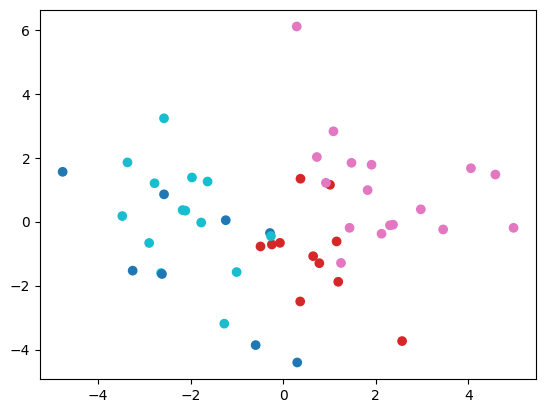

In [2934]:
plt.scatter(coords[:,0], coords[:,1], c=team_wide['kmeans_4_cluster'], cmap='tab10')

In [ ]:
f_stats_adj = compute_f_stats_with_p(team_wide, team_style_cols_no_side_cluster_adj, 'kmeans_4_cluster')

In [2936]:
f_stats_adj.sort_values('f_pvalue')

,f_stat,f_pvalue
feature,,
pass_progressive_per_game_pct_adj,51.449424,3.924079e-11
pass_progressive_share_per_game_adj,36.926822,4.768372e-08
shot_share_open_play_adj,27.296241,5.102748e-06
directness_avg_adj,26.760844,6.607699e-06
defensive_actions_x_avg_adj,25.715840,1.093741e-05
counterpress_actions_applied_opposing_half_pct_adj,23.298858,3.498569e-05
pass_into_box_share_per_game_adj,22.162822,6.033526e-05
shot_share_direct_set_piece_adj,18.858702,2.924200e-04
carry_into_box_attempted_per_game_pct_adj,18.791169,3.019706e-04


In [2937]:
centroid_df = backproject_cluster_centroids(
    pca_reduced_final,                        # your fitted PCA object that produced X_pca_final
    kmeans_4.cluster_centers_,
    team_style_cols_no_side_cluster_adj
)

In [2938]:
pairwise_cluster_deltas(centroid_df, 'Cluster_0', 'Cluster_1')

,feature,delta,higher_in
0,pass_into_box_share_per_game_adj,-1.878494,Cluster_1
1,carry_into_final_third_central_per_game_pct_adj,1.661394,Cluster_0
2,carry_into_box_attempted_per_game_pct_adj,1.328581,Cluster_0
3,pass_cross_attempted_per_game_pct_adj,-1.223339,Cluster_1
4,pass_progressive_share_per_game_adj,-1.195359,Cluster_1
5,final_third_touch_central_per_game_pct_adj,1.133991,Cluster_0
6,counterpress_actions_applied_opposing_half_pct...,-1.072829,Cluster_1
7,pass_progressive_per_game_pct_adj,-1.020509,Cluster_1
8,pass_goal_kick_long_per_game_pct_adj,-0.998594,Cluster_1
9,pass_into_box_completed_cross_per_game_pct_adj,-0.992697,Cluster_1


In [2939]:
pairwise_cluster_deltas(centroid_df, 'Cluster_0', 'Cluster_2')

,feature,delta,higher_in
0,pass_progressive_per_game_pct_adj,-1.857172,Cluster_2
1,pass_goal_kick_long_per_game_pct_adj,-1.845875,Cluster_2
2,directness_avg_adj,-1.763852,Cluster_2
3,counterpress_actions_applied_opposing_half_pct...,-1.555299,Cluster_2
4,shot_share_direct_set_piece_adj,-1.391622,Cluster_2
5,shot_share_open_play_adj,1.348423,Cluster_0
6,pass_into_box_share_per_game_adj,-1.326788,Cluster_2
7,defensive_actions_x_avg_adj,-1.139673,Cluster_2
8,pass_cross_attempted_per_game_pct_adj,-1.126808,Cluster_2
9,pass_progressive_share_per_game_adj,-1.071271,Cluster_2


In [2940]:
pairwise_cluster_deltas(centroid_df, 'Cluster_0', 'Cluster_3')

,feature,delta,higher_in
0,carry_into_final_third_central_per_game_pct_adj,1.669803,Cluster_0
1,final_third_touch_central_per_game_pct_adj,1.545236,Cluster_0
2,pass_into_final_third_central_per_game_pct_adj,1.407755,Cluster_0
3,shot_share_delayed_set_piece_adj,1.295799,Cluster_0
4,pass_through_ball_attempted_per_game_pct_adj,1.025864,Cluster_0
5,carry_into_box_attempted_per_game_pct_adj,0.969160,Cluster_0
6,pass_goal_kick_long_per_game_pct_adj,-0.937801,Cluster_3
7,shot_share_direct_set_piece_adj,-0.905067,Cluster_3
8,pass_into_box_completed_cross_per_game_pct_adj,-0.800820,Cluster_3
9,defensive_actions_y_std_adj,-0.797239,Cluster_3


In [2941]:
pairwise_cluster_deltas(centroid_df, 'Cluster_1', 'Cluster_2')

,feature,delta,higher_in
0,shot_share_open_play_adj,1.760055,Cluster_1
1,shot_share_direct_set_piece_adj,-1.339277,Cluster_2
2,carry_into_box_attempted_per_game_pct_adj,-1.214691,Cluster_2
3,shot_share_transition_adj,-1.092087,Cluster_2
4,directness_avg_adj,-1.062474,Cluster_2
5,carry_progressive_per_game_pct_adj,-0.991988,Cluster_2
6,pass_goal_kick_long_per_game_pct_adj,-0.847281,Cluster_2
7,pass_progressive_per_game_pct_adj,-0.836662,Cluster_2
8,shot_share_counter_adj,-0.684527,Cluster_2
9,carry_into_final_third_central_per_game_pct_adj,-0.681708,Cluster_2


In [2942]:
pairwise_cluster_deltas(centroid_df, 'Cluster_1', 'Cluster_3')

,feature,delta,higher_in
0,pass_progressive_share_per_game_adj,1.719104,Cluster_1
1,carry_progressive_per_game_pct_adj,-1.299104,Cluster_3
2,defensive_actions_x_avg_adj,1.250257,Cluster_1
3,patience_second_avg_adj,-1.111080,Cluster_3
4,pass_into_box_share_per_game_adj,1.107469,Cluster_1
5,pass_progressive_per_game_pct_adj,1.073063,Cluster_1
6,pass_through_ball_attempted_per_game_pct_adj,0.944552,Cluster_1
7,counterpress_actions_applied_opposing_half_pct...,0.918202,Cluster_1
8,shot_share_direct_set_piece_adj,-0.852722,Cluster_3
9,pass_into_final_third_central_per_game_pct_adj,0.790347,Cluster_1


In [2943]:
pairwise_cluster_deltas(centroid_df, 'Cluster_2', 'Cluster_3')

,feature,delta,higher_in
0,pass_progressive_per_game_pct_adj,1.909725,Cluster_2
1,pass_progressive_share_per_game_adj,1.595015,Cluster_2
2,directness_avg_adj,1.479958,Cluster_2
3,defensive_actions_x_avg_adj,1.454965,Cluster_2
4,counterpress_actions_applied_opposing_half_pct...,1.400671,Cluster_2
5,patience_second_avg_adj,-1.320640,Cluster_3
6,shot_share_open_play_adj,-1.093466,Cluster_3
7,pass_through_ball_attempted_per_game_pct_adj,1.049476,Cluster_2
8,pass_into_final_third_central_per_game_pct_adj,1.025206,Cluster_2
9,pass_goal_kick_long_per_game_pct_adj,0.908075,Cluster_2


In [2944]:
rank_cluster_driving_features(centroid_df)

,feature,cross_cluster_std
0,pass_progressive_per_game_pct_adj,0.912497
1,pass_progressive_share_per_game_adj,0.834945
2,pass_into_box_share_per_game_adj,0.802253
3,carry_into_final_third_central_per_game_pct_adj,0.787893
4,directness_avg_adj,0.773365
5,pass_goal_kick_long_per_game_pct_adj,0.754437
6,shot_share_open_play_adj,0.752246
7,counterpress_actions_applied_opposing_half_pct...,0.743392
8,defensive_actions_x_avg_adj,0.706777
9,shot_share_direct_set_piece_adj,0.677989


In [2945]:
top_features_by_category_combined_adj, diag = select_features_combined(
    team_wide, centroid_df, team_feature_groups_adj, n_per_team_category,
    cluster_col='kmeans_4_cluster', alpha=0.05,
    weight_f=0.5, weight_pca=0.5, anova_method='welch'
)

In [2946]:
top_features_by_category_combined = {
    category: [f.removesuffix('_adj') for f in features]
    for category, features in top_features_by_category_combined_adj.items()
}

In [2947]:
radar_sets = {
    'build_up_channels': top_features_by_category_combined['build_up'] + top_features_by_category_combined['channels'],
    'chance_creation_pressing_transitions': top_features_by_category_combined['chance_creation'] + top_features_by_category_combined['pressing_transitions'],
}

In [2948]:
export_team_cluster_comparison_charts(team_wide, radar_sets, 'kmeans_4_cluster', n_clusters=4)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\build_up_channels_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\chance_creation_pressing_transitions_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\build_up_channels_raw.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\chance_creation_pressing_transitions_raw.png']

In [2949]:
export_team_cluster_comparison_charts_by_league(team_wide, radar_sets, 'kmeans_4_cluster', n_clusters=4)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\build_up_channels_adj_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\chance_creation_pressing_transitions_adj_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\build_up_channels_raw_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\chance_creation_pressing_transitions_raw_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\build_up_channels_adj_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\chance_creation_pressing_transitions_adj_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\build_up_channels_raw_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\team

In [2950]:
export_all_team_cluster_charts(team_wide, radar_sets, 'kmeans_4_cluster', n_clusters=4, team_id_to_team=team_id_to_team, team_id_to_league=team_id_to_league)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\build_up_channels_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\chance_creation_pressing_transitions_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\build_up_channels_raw.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\chance_creation_pressing_transitions_raw.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\build_up_channels_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\chance_creation_pressing_transitions_adj.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\

In [2951]:
export_all_team_cluster_charts_league_aware(team_wide, radar_sets, 'kmeans_4_cluster', n_clusters=4, team_id_to_team=team_id_to_team, team_id_to_league=team_id_to_league)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\build_up_channels_adj_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\chance_creation_pressing_transitions_adj_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\build_up_channels_raw_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\chance_creation_pressing_transitions_raw_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Duisburg_WFC_Frauen_Bundesliga\\build_up_channels_adj_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Duisburg_WFC_Frauen_Bundesliga\\chance_creation_pressing_transitions_adj_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324

In [2952]:
export_group_profile(team_wide, radar_sets, 'kmeans_4_cluster', 4)

'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\group_profile.png'

In [2953]:
export_group_profile_by_league(team_wide, radar_sets, 'kmeans_4_cluster', 4)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\group_profile_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\group_profile_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\group_profile_Liga_F.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\group_profile_Serie_A_Women.png']

In [2954]:
export_team_profiles(team_wide, radar_sets, 'kmeans_4_cluster', 4, team_id_to_team, team_id_to_league)

saved 50 team profiles (k = 4) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k4


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_United_W_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Aston_Villa_W_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\West_Ham_United_LFC_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Chelsea_FCW_FA_Womens_Super_League\\team_profile.png',
 'e:\\GitHub\\Women-Teams-Euro

In [2955]:
export_team_profiles_vs_league(team_wide, radar_sets, 'kmeans_4_cluster', 4, team_id_to_team, team_id_to_league)

saved 50 team profiles (k = 4) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k4


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_United_W_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Aston_Villa_W_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\West_Ham_United_LFC_FA_Womens_Super_League\\team_profile_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Chelsea_FCW_FA_Womens_Super_League\\team_pr

In [2956]:
export_pitch_profiles_by_group(team_wide, 'kmeans_4_cluster', 4)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\pitch_profiles.png']

In [2957]:
export_pitch_profiles_by_group_by_league(team_wide, 'kmeans_4_cluster', 4)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\pitch_profiles_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\pitch_profiles_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\pitch_profiles_Liga_F.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\pitch_profiles_Serie_A_Women.png']

In [2958]:
export_pitch_profile_teams_vs_group(team_wide, 'kmeans_4_cluster', 4, team_id_to_team, team_id_to_league)

saved team-vs-group pitch profiles (passes and carries, k = 4) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k4


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_United_W_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Aston_Villa_W_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\West_Ham_United_LFC_FA_Womens_Super_League\\pitch_profile_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Chelsea_FCW_FA_Womens_Sup

In [2959]:
export_pitch_profile_teams_vs_group(team_wide, 'kmeans_4_cluster', 4, team_id_to_team, team_id_to_league, league_only=True)

saved team-vs-group pitch profiles (passes and carries, k = 4) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k4
skipped (no other team of the group to compare against): Tottenham Hotspur Women


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_United_W_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Aston_Villa_W_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\West_Ham_United_LFC_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Chelsea_FCW_FA_Womens_Super_League\\pitch_profile_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\

In [2960]:
export_group_strips(team_wide, 'kmeans_4_cluster', 4, ["context_score", "possession_pct", "field_tilt", "ppda_inv"], names=team_id_to_team, label_ids=None,
                        col_labels={"context_score": "Strength"}, col_formats={"possession_pct": "pct", "field_tilt": "pct"})

'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\strength_dominance_strips.png'

In [2961]:
export_group_strips_by_league(team_wide, 'kmeans_4_cluster', 4, ["context_score", "possession_pct", "field_tilt", "ppda_inv"], names=team_id_to_team, label_ids=None,
                        col_labels={"context_score": "Strength"}, col_formats={"possession_pct": "pct", "field_tilt": "pct"})

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\strength_dominance_strips_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\strength_dominance_strips_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\strength_dominance_strips_Liga_F.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\strength_dominance_strips_Serie_A_Women.png']

In [2962]:
export_group_type_shares(team_wide, 'kmeans_4_cluster', 4)

'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_by_group.png'

In [2963]:
export_group_type_shares_by_league(team_wide, "kmeans_4_cluster", 4)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_by_group_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_by_group_Frauen_Bundesliga.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_by_group_Liga_F.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_by_group_Serie_A_Women.png']

In [2964]:
export_team_type_shares(team_wide, 'kmeans_4_cluster', 4, team_id_to_team)             # one per position

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_Goalkeeper.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_Center_Back.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_FullWing_Back.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_Center_Midfield.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_Center_Midfield_hard.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_Center_Midfield_sub.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_Winger.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_Center_Forward.png']

In [2965]:
export_team_type_shares_by_league(team_wide, "kmeans_4_cluster", 4, team_id_to_team)

['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_Goalkeeper_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_Center_Back_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_FullWing_Back_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_Center_Midfield_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_Center_Midfield_hard_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_Center_Midfield_sub_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\type_shares_teams_Winger_FA_Womens_Super_League.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-

In [2966]:
export_team_type_vs_group(team_wide, 'kmeans_4_cluster', 4, team_id_to_team, team_id_to_league)

saved 50 team-vs-group player-type plots (k = 4) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k4


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_United_W_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Aston_Villa_W_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\West_Ham_United_LFC_FA_Womens_Super_League\\type_shares_vs_group.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Chelsea_FCW_FA_Womens_Super_League\\t

In [2967]:
export_team_type_vs_group(team_wide, "kmeans_4_cluster", 4, team_id_to_team, team_id_to_league, league_only=True)

saved 50 team-vs-group player-type plots (k = 4) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k4


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_United_W_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Manchester_City_WFC_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\Aston_Villa_W_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\West_Ham_United_LFC_FA_Womens_Super_League\\type_shares_vs_group_league.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\

In [2968]:
export_league_mix(team_wide, 'kmeans_4_cluster', 4)

saved league mix (k = 4) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k4\league_mix.png


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\league_mix.png']

In [2969]:
export_close_team_strip(D_style_adj, team_wide, 'kmeans_4_cluster', 4, team_id_to_team)

saved close-teams strip (k = 4) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k4\close_teams.png


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\close_teams.png']

In [2970]:
export_similarity_gap_vs_distance(D_style_adj, team_wide, 'kmeans_4_cluster', 4, team_id_to_team)

saved similarity gap vs distance (k = 4) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\k4\similarity_gap_vs_distance.png


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\k4\\similarity_gap_vs_distance.png']

### Change between clusters

In [2971]:
export_group_flow(team_wide)                              # one alluvial for k = 2, 3, 4

'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\group_flow.png'

In [2972]:
export_team_paths(team_wide, team_id_to_team)

saved team paths across k to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\all_k\team_paths.png


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\team_paths.png']

## Team playstyle vs Individual comparision

### Team playstyle vs Player playstyle

In [2973]:
soft_cols = [c for c in team_wide.columns if '__soft_' in c]

In [2974]:
top_cols = [c for c in soft_cols if re.fullmatch(r'.+__soft_\d', c)]

In [2975]:
top_cols

['Goalkeeper__soft_0',
 'Goalkeeper__soft_1',
 'Center Back__soft_0',
 'Center Back__soft_1',
 'FullWing Back__soft_0',
 'FullWing Back__soft_1',
 'FullWing Back__soft_2',
 'Center Midfield__soft_0',
 'Center Midfield__soft_1',
 'Center Midfield__soft_2',
 'Winger__soft_0',
 'Winger__soft_1',
 'Winger__soft_2',
 'Center Forward__soft_0',
 'Center Forward__soft_1',
 'Center Forward__soft_2']

In [2976]:
len(top_cols)

16

In [2977]:
cm_sub_cols = [c for c in soft_cols if re.fullmatch(r'Center Midfield__soft_\d_\d', c)]

In [2978]:
cm_sub_cols

['Center Midfield__soft_0_0',
 'Center Midfield__soft_0_1',
 'Center Midfield__soft_1_0',
 'Center Midfield__soft_1_1',
 'Center Midfield__soft_1_2',
 'Center Midfield__soft_2_0',
 'Center Midfield__soft_2_1']

In [2979]:
len(cm_sub_cols)

7

In [2980]:
for k in [2, 3]:
    lab = f'kmeans_{k}_cluster'
    by_cluster = team_wide.groupby(lab)[top_cols].mean()
    gap = by_cluster - team_wide[top_cols].mean()          # + = more of this player type than average
    by_league = team_wide.groupby(['league', lab])[top_cols].mean()
    top_by_league = by_league.groupby(level='league').idxmax().apply(lambda s: s.str[1])
    d1 = pd.DataFrame({'top_group': by_cluster.idxmax(),
                       'gap': gap.max(),
                       'leagues_agree': (top_by_league == by_cluster.idxmax()).sum()})
    print(f'k={k}'); print(d1[d1['leagues_agree'] >= 3].sort_values('gap', ascending=False))

k=2
                         top_group       gap  leagues_agree
Goalkeeper__soft_0               1  0.092092              4
Goalkeeper__soft_1               0  0.072358              4
Center Back__soft_0              1  0.059365              4
Center Back__soft_1              0  0.046644              4
FullWing Back__soft_2            0  0.031990              4
FullWing Back__soft_1            1  0.031729              4
Center Forward__soft_1           1  0.031659              4
Winger__soft_1                   1  0.027030              4
Center Midfield__soft_0          1  0.021588              4
Center Midfield__soft_1          0  0.021162              4
Center Forward__soft_0           0  0.019737              4
Center Midfield__soft_2          1  0.005345              3
k=3
                        top_group       gap  leagues_agree
Goalkeeper__soft_1              0  0.141228              3
Goalkeeper__soft_0              2  0.074202              3
Center Back__soft_1             0  

### Team playstyle vs Squad

In [2981]:
nb_comp = neighbours(D_comp, team_wide['league'], k=5)

In [2982]:
first = nb_comp[nb_comp['rank'] == 1]

In [2983]:
for k in [2, 3]:
    lab = team_wide[f'kmeans_{k}_cluster']
    same = (first['team_id'].map(lab) == first['neighbour'].map(lab)).mean()
    sizes = lab.value_counts()
    chance = (sizes * (sizes - 1)).sum() / (len(lab) * (len(lab) - 1))
    print(k, same, chance)     # chance is about 0.51 at k=2 and 0.33 at k=3

2 0.76 0.49714285714285716
3 0.54 0.32326530612244897


### Hub teams

In [2984]:
nb_style_adj = neighbours(D_style_adj, team_wide['league'], k=5)          # style only, matches what the clustering used

In [2985]:
hub_check = pd.DataFrame({
    'team': team_wide['team'],
    'hub_adj': nb_adj['neighbour'].value_counts().reindex(team_wide.index, fill_value=0),        # the C6 hubs (style + squad)
    'hub_style': nb_style_adj['neighbour'].value_counts().reindex(team_wide.index, fill_value=0),
    'dist_centre': dist_centre,                          # from your outlier step: distance from the middle of the style map
})

In [2986]:
for k in [2, 3]:
    sims = np.sort(team_wide[[f'sim_cluster_{c}_k{k}' for c in range(k)]].to_numpy(), axis=1)
    hub_check[f'margin_k{k}'] = sims[:, -1] - sims[:, -2]

In [2987]:
pct = hub_check.drop(columns='team').rank(pct=True).add_suffix('_pct')

In [2988]:
hub_check = hub_check.join(pct[['margin_k2_pct', 'margin_k3_pct', 'dist_centre_pct']])

In [2989]:
hub_check.sort_values('hub_adj', ascending=False).head(10)

,team,hub_adj,hub_style,dist_centre,margin_k2,margin_k3,margin_k2_pct,margin_k3_pct,dist_centre_pct
team_id,,,,,,,,,
3165,SC Freiburg,20,15,3.301535,0.108986,0.139334,0.16,0.52,0.06
1105,Atletico Madrid W,17,9,4.158240,0.121598,0.108859,0.24,0.34,0.26
6604,Villarreal,16,9,4.050136,0.136794,0.039697,0.32,0.10,0.18
1475,Manchester United W,12,8,3.715593,0.174869,0.016257,0.50,0.04,0.10
924,Duisburg WFC,10,4,4.846728,0.043112,0.118581,0.10,0.46,0.52
6602,Köln,10,8,4.007103,0.208531,0.143832,0.64,0.60,0.14
3150,AC Milan W,9,3,4.436102,0.177048,0.035815,0.54,0.06,0.36
11558,Como W,9,8,4.511337,0.278672,0.152184,0.80,0.66,0.40
3282,Real Madrid CF W,9,8,4.497306,0.301009,0.273902,0.84,0.94,0.38


In [2990]:
hub_check[['hub_adj', 'hub_style']].corrwith(hub_check['margin_k2'], method='spearman')

hub_adj     -0.141942
hub_style   -0.087134
dtype: float64

## Extra plots

#### Assemble full columns

In [2991]:
team_feature_groups_full = {
    "build_up": [
        "pass_progressive_per_game_pct", "pass_into_final_third_per_game_pct", 
        "pass_long_per_game_pct", "pass_goal_kick_long_per_game_pct",
        "carry_progressive_per_game_pct", "carry_into_final_third_per_game_pct",
        "pass_progressive_share_per_game", "pass_into_final_third_share_per_game",
        "directness_avg", "patience_second_avg"
    ],
    "channels": [
        "pass_into_final_third_left_per_game_pct", "pass_into_final_third_central_per_game_pct", "pass_into_final_third_right_per_game_pct",
        "carry_into_final_third_left_per_game_pct", "carry_into_final_third_central_per_game_pct", "carry_into_final_third_right_per_game_pct",
        "final_third_touch_left_per_game_pct", "final_third_touch_central_per_game_pct", "final_third_touch_right_per_game_pct"
    ],
    "chance_creation": [
        "pass_into_box_attempted_per_game_pct", "pass_cross_attempted_per_game_pct", "pass_cut_back_attempted_per_game_pct",
        "pass_through_ball_attempted_per_game_pct", "pass_into_box_completed_cross_per_game_pct",
        "carry_into_box_attempted_per_game_pct", "pass_into_box_share_per_game",
        "shot_share_open_play", "shot_share_direct_set_piece", "shot_share_delayed_set_piece"
    ],
    "pressing_transitions": [
        "pressures_applied_opposing_half_pct", "defensive_actions_x_avg", "defensive_actions_y_std",
        "counterpress_actions_applied_opposing_half_pct", "shot_share_counter", "shot_share_transition"
    ],
}

In [2992]:
all_grouped_full = [c for group in team_feature_groups_full.values() for c in group]

In [2993]:
set(team_style_cols) - set(all_grouped_full)

set()

In [2994]:
set(all_grouped_full) - set(team_style_cols)

set()

In [2995]:
card_style_cols = {**team_feature_groups_full,
                   "dominance_strength": ["possession_pct", "field_tilt", "ppda_inv", "context_score"]}

### Player style vs Team style

In [2996]:
share_cols = [c for c in team_wide.columns if "__soft_" in c and c.split("__soft_")[-1].isdigit()]

In [2997]:
links = composition_link_table(team_wide, share_cols, team_style_cols_adj, n_perm=50000)   # one table feeds both figures

In [2998]:
export_composition_link_map(links, style_groups=team_feature_groups_full)

saved C5 link map to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\all_k\composition_links_map.png


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\composition_links_map.png']

In [2999]:
export_composition_link_scatter(team_wide, links, top=15, max_per_trait=2)

saved C5 link panels to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\all_k\composition_links_top.png


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\composition_links_top.png']

### Most used XI per team

In [3000]:
export_all_typical_xi(occupancy, team_id_to_team, team_id_to_league, player_id_to_player)

saved 50 typical-XI plots to e:\GitHub\Women-Teams-Europe-2324-Analysis\code\..\plots\teams\all_k


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\typical_xi.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Manchester_United_W_FA_Womens_Super_League\\typical_xi.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Manchester_City_WFC_FA_Womens_Super_League\\typical_xi.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\typical_xi.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Aston_Villa_W_FA_Womens_Super_League\\typical_xi.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\West_Ham_United_LFC_FA_Womens_Super_League\\typical_xi.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Chelsea_FCW_FA_Womens_Super_League\\typical_xi.png',
 'e:\\GitHub\\Women-Tea

### Formation used by team

In [3001]:
export_formation_profiles(occupancy, team_id_to_team, team_id_to_league, back_3_share=back_3_share, wingerless_share=wingerless_share)

saved 50 formation profiles to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\all_k


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\formations.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Manchester_United_W_FA_Womens_Super_League\\formations.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Manchester_City_WFC_FA_Womens_Super_League\\formations.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\formations.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Aston_Villa_W_FA_Womens_Super_League\\formations.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\West_Ham_United_LFC_FA_Womens_Super_League\\formations.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Chelsea_FCW_FA_Womens_Super_League\\formations.png',
 'e:\\GitHub\\Women-Tea

### Pitch profile by team

In [3002]:
export_pitch_profile_teams(team_wide, team_id_to_team, team_id_to_league)      # one pitch per team (pass and carry)

saved team pitch profiles (passes and carries) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\all_k


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\pitch_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Manchester_United_W_FA_Womens_Super_League\\pitch_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Manchester_City_WFC_FA_Womens_Super_League\\pitch_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\pitch_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Aston_Villa_W_FA_Womens_Super_League\\pitch_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\West_Ham_United_LFC_FA_Womens_Super_League\\pitch_profile.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Chelsea_FCW_FA_Womens_Super_League\\pitch_profile.png',
 '

### Team type mix

In [3003]:
export_team_type_mix(team_wide, team_id_to_team, team_id_to_league)       # player-type soft shares, one per team

saved 50 team player-type mixes to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\all_k


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\type_shares.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Manchester_United_W_FA_Womens_Super_League\\type_shares.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Manchester_City_WFC_FA_Womens_Super_League\\type_shares.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\type_shares.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Aston_Villa_W_FA_Womens_Super_League\\type_shares.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\West_Ham_United_LFC_FA_Womens_Super_League\\type_shares.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Chelsea_FCW_FA_Womens_Super_League\\type_shares.png',
 'e:\\GitHub\\Wo

### Team cards

In [3004]:
export_team_cards(team_wide, team_id_to_team, team_id_to_league, card_style_cols,
                  D_squad=D_comp, D_style=D_style_adj, D_overall=D_adj,
                  fm=formation_minutes(occupancy), back_3_share=back_3_share, wingerless_share=wingerless_share)

saved 50 team cards under e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\all_k


['e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Manchester_City_WFC_FA_Womens_Super_League\\team_card.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Tottenham_Hotspur_Women_FA_Womens_Super_League\\team_card.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Duisburg_WFC_Frauen_Bundesliga\\team_card.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\VfL_Wolfsburg_WFC_Frauen_Bundesliga\\team_card.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Barcelona_WFC_Liga_F\\team_card.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Brighton_&_Hove_Albion_WFC_FA_Womens_Super_League\\team_card.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\Liverpool_WFC_FA_Womens_Super_League\\team_card.png',
 'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots

In [3005]:
team_cards_pdf(team_wide, team_id_to_team, team_id_to_league, card_style_cols,
               D_squad=D_comp, D_style=D_style_adj, D_overall=D_adj,
               fm=formation_minutes(occupancy), back_3_share=back_3_share, wingerless_share=wingerless_share)

saved 50 team cards (+ contents page) to e:\GitHub\Women-Teams-Europe-2324-Analysis\plots\teams\all_k\team_cards.pdf


'e:\\GitHub\\Women-Teams-Europe-2324-Analysis\\code\\..\\plots\\teams\\all_k\\team_cards.pdf'

## Extra functions for conclusions

### Cluster vs distance

In [3006]:
close_pair_groups(D_style_adj, team_wide, "kmeans_2_cluster")

(0, 0)    54
(1, 1)    43
(0, 1)    26
Name: count, dtype: int64

In [3007]:
close_pair_groups(D_style_adj, team_wide, "kmeans_3_cluster")

(1, 1)    44
(2, 2)    36
(1, 2)    24
(0, 0)    11
(0, 1)     8
Name: count, dtype: int64

In [3008]:
close_pair_groups(D_style_adj, team_wide, "kmeans_4_cluster")

(1, 1)    32
(3, 3)    30
(1, 3)    16
(2, 2)    13
(0, 1)     9
(1, 2)     9
(0, 3)     9
(0, 0)     4
(2, 3)     1
Name: count, dtype: int64

### Squad share vs league

In [3009]:
cm_hard_cols = [c for c in team_wide.columns if re.fullmatch(r"Center Midfield__\d+", c)]

In [3010]:
cm_hard_cols

['Center Midfield__0', 'Center Midfield__1', 'Center Midfield__2']

In [3011]:
league_direction_all(team_wide, share_cols + cm_hard_cols, "kmeans_2_cluster")

Cluster 0         Cluster 1        
                          gap_pts leagues   gap_pts leagues
Goalkeeper__soft_0          -16.4     4/4      16.4     4/4
Goalkeeper__soft_1           16.4     4/4     -16.4     4/4
Center Back__soft_0         -10.6     4/4      10.6     4/4
Center Back__soft_1          10.6     4/4     -10.6     4/4
FullWing Back__soft_0        -1.6     2/4       1.6     2/4
FullWing Back__soft_1        -5.7     4/4       5.7     4/4
FullWing Back__soft_2         7.3     4/4      -7.3     4/4
Center Midfield__soft_0      -3.9     4/4       3.9     4/4
Center Midfield__soft_1       4.8     4/4      -4.8     4/4
Center Midfield__soft_2      -1.0     3/4       1.0     3/4
Winger__soft_0                3.9     2/4      -3.9     2/4
Winger__soft_1               -4.9     4/4       4.9     4/4
Winger__soft_2                1.0     2/4      -1.0     2/4
Center Forward__soft_0        4.3     4/4      -4.3     4/4
Center Forward__soft_1       -5.8     4/4       5.8     4/4
Center Forward__soft_2        1.5     2/4      -1.5     2/4
Center Midfield__0          -17.0     4/4      17.0     4/4
Center Midfield__1           23.4     4/4     -23.4     4/4
Center Midfield__2           -6.4     2/4       6.4     2/4

In [3012]:
league_direction_all(team_wide, share_cols + cm_hard_cols, "kmeans_3_cluster")

Cluster 0         Cluster 1         Cluster 2        
                          gap_pts leagues   gap_pts leagues   gap_pts leagues
Goalkeeper__soft_0          -20.2     3/4       7.9     4/4      10.9     3/4
Goalkeeper__soft_1           20.2     3/4      -7.9     4/4     -10.9     3/4
Center Back__soft_0          -9.8     4/4       0.0     2/4       9.4     4/4
Center Back__soft_1           9.8     4/4      -0.0     2/4      -9.4     4/4
FullWing Back__soft_0         1.6     3/4      -1.7     3/4       0.4     2/4
FullWing Back__soft_1        -6.4     4/4      -1.0     3/4       7.2     4/4
FullWing Back__soft_2         4.8     3/4       2.7     3/4      -7.6     4/4
Center Midfield__soft_0      -3.9     3/4       0.3     1/4       3.4     3/4
Center Midfield__soft_1       4.2     4/4       0.4     3/4      -4.5     4/4
Center Midfield__soft_2      -0.3     2/4      -0.7     3/4       1.1     3/4
Winger__soft_0                2.5     3/4       0.4     2/4      -2.7     3/4
Winger__soft_1               -2.5     3/4      -4.0     3/4       6.4     4/4
Winger__soft_2                0.1     2/4       3.6     3/4      -3.7     3/4
Center Forward__soft_0        5.5     4/4      -3.4     4/4      -1.9     3/4
Center Forward__soft_1       -7.3     4/4       3.5     4/4       3.4     3/4
Center Forward__soft_2        1.8     2/4      -0.2     2/4      -1.6     3/4
Center Midfield__0          -12.8     3/4      -1.1     2/4      13.6     4/4
Center Midfield__1           22.5     4/4      -1.5     2/4     -20.1     4/4
Center Midfield__2           -9.7     2/4       2.6     3/4       6.5     3/4

In [3013]:
league_direction_all(team_wide, share_cols + cm_hard_cols, "kmeans_4_cluster")

Cluster 0         Cluster 1         Cluster 2          \
                          gap_pts leagues   gap_pts leagues   gap_pts leagues   
Goalkeeper__soft_0           14.8     4/4      -0.2     2/4     -17.9     3/4   
Goalkeeper__soft_1          -14.8     4/4       0.2     2/4      17.9     3/4   
Center Back__soft_0           7.9     4/4      -3.7     3/4      -8.8     4/4   
Center Back__soft_1          -7.9     4/4       3.7     3/4       8.8     4/4   
FullWing Back__soft_0        -1.0     2/4      -1.8     3/4      -0.4     2/4   
FullWing Back__soft_1         3.7     3/4      -1.6     2/4      -5.0     4/4   
FullWing Back__soft_2        -2.7     3/4       3.4     3/4       5.4     3/4   
Center Midfield__soft_0       1.4     2/4      -0.8     3/4      -3.6     3/4   
Center Midfield__soft_1      -2.1     3/4       0.9     2/4       4.6     4/4   
Center Midfield__soft_2       0.7     2/4      -0.1     2/4      -1.0     3/4   
Winger__soft_0               -6.7     3/4       1.4     3/4       3.2     3/4   
Winger__soft_1                3.2     2/4      -3.8     3/4      -2.7     3/4   
Winger__soft_2                3.5     3/4       2.4     3/4      -0.6     2/4   
Center Forward__soft_0        0.5     2/4      -1.4     3/4       5.9     4/4   
Center Forward__soft_1        2.7     3/4       0.3     2/4      -6.8     4/4   
Center Forward__soft_2       -3.3     2/4       1.1     3/4       0.9     2/4   
Center Midfield__0            9.7     3/4      -8.4     3/4     -12.2     3/4   
Center Midfield__1           -8.6     3/4       3.1     2/4      23.3     4/4   
Center Midfield__2           -1.1     2/4       5.4     3/4     -11.1     2/4   

                        Cluster 3          
                          gap_pts leagues  
Goalkeeper__soft_0           10.3     3/4  
Goalkeeper__soft_1          -10.3     3/4  
Center Back__soft_0           7.7     4/4  
Center Back__soft_1          -7.7     4/4  
FullWing Back__soft_0         2.6     2/4  
FullWing Back__soft_1         4.5     3/4  
FullWing Back__soft_2        -7.1     4/4  
Center Midfield__soft_0       3.8     3/4  
Center Midfield__soft_1      -4.5     4/4  
Center Midfield__soft_2       0.7     2/4  
Winger__soft_0               -0.5     2/4  
Winger__soft_1                3.8     3/4  
Winger__soft_2               -3.4     3/4  
Center Forward__soft_0       -5.5     4/4  
Center Forward__soft_1        5.2     3/4  
Center Forward__soft_2        0.3     2/4  
Center Midfield__0           14.3     3/4  
Center Midfield__1          -22.8     4/4  
Center Midfield__2            8.5     3/4